# Optimising Eddy Currents with NMR Probe

The NMR probe is made to measure the eddy currents in different places within the imaging volume. Connect along the probe in the direction you want to optimise in then run the notebook using that 'axis'. 

The notebook will:
1. Create a mock gradient for the duration you wanted which will be used to test if the suggested pre-emphasis (PE) is viable or exceeds the current limits set in globals.
2. Loads the starting parameters from the eddyE.yaml and eddyB0.yaml in globals into an 'opt' yaml that is used by optuna to place new optimisation parameter suggestions in and run the pulse sequence from. It also loads into a 'start' yaml which is used to remember the initial parameters as they will be overwritten in globals. This is placed into the folder titled by the axis it applies to. 
3. Run the gradient (E) optimisation on the parameters saved for that axis connected on the probe to minimise the area under the field gradient over time graph. After the desired number of trials ends it will save the best parameters in 'best', these will then be loaded into the following B0 optimisation. Plots the optimisation performance at the end.
4. Run the offset (B0) optimisation on the parameters saved at the start into 'opt', using optimal E parameters. Ends after the desired number of trials and then plots the optimisation run information. Saves the optimal parameters into the GLOBALS_DIR yaml.

Saving:
- df_pars is a csv table of the parameters used in the optimisation sequence
- gradient_info.csv information on the optimisation run including the parameters used in each round for that axis and its associated cost for the gradient
- offset_info.csv information on the optimisation run including the parameters used in each round for that axis and its associated cost for the offset
- eddyE.yaml and eddyB0.yaml saved into GLOBALS_DIR - the optimal parameters optuna found

### Imports

In [1]:
from matipo import GLOBALS_DIR
import panel as pn
import numpy as np
import pandas as pd
import copy
import matplotlib.pyplot as plt
plt.style.use('default')
import yaml
from pathlib import Path
import optuna
import shutil
import nest_asyncio
nest_asyncio.apply()

In [2]:
from user_interface.optimiser import Optimiser
opt = Optimiser()

The seq consists of a long gradient pulse which has and FID then is turned off. RF pulses and acquisitions are staggered after this to obtain the eddy current effects over time and measure them. The frequency of these acquisitions is collected and is plotted over time (should be an exp decay). The frequency info shows the eddy currents and then we use the RMS of the raw signal to check that the flip angle used leads to steady-state behaviour. The RMS is plotted against the time and should be non-zero to show that there is signal being acquired.

Notes:
- n_pulses does not include the gradient calibration pulse (just how many are in the eddy current acquisistion)

### Define Parameters

In [3]:
flip_angle = 4.5
axis = "Z"

seq_params = {
    "OPT_AXIS": axis,
    "n_scans": 1,
    "a_pulse": opt.get_yaml_info("hardpulse_90_tx0.yaml")["a_90"],
    "t_pulse": (opt.get_yaml_info("hardpulse_90_tx0.yaml")["t_90"])*flip_angle/90,
    "t_dw": 10e-6,
    "n_samples": 100,
    "t_acq_delay": 100e-6,
    "t_grad": 10.0,
    "t_ramp": 1e-3,
    "t_wait": 8e-3,
    "n_pulses": 30,
    "t_end": 10.0,
    "t_next": 5,  # wait between scans
    "g_val": 0.1, # convert this into g_read before using
    "tx_chan": 0,
    "rx_chan_list": (3, 0, 1),
    "pre_emphasis": True,
    "b0": True,
    "file_pars": f"{Path.cwd()}/",
    "file_cals": GLOBALS_DIR,
    "d_r": opt.get_yaml_info("probe_distances.yaml")["d_r"],
    "d_c": opt.get_yaml_info("probe_distances.yaml")["d_c"],
    "d_l": opt.get_yaml_info("probe_distances.yaml")["d_l"],

}

print(seq_params)

{'OPT_AXIS': 'Z', 'n_scans': 1, 'a_pulse': 0.45, 't_pulse': 2.9999999999999997e-05, 't_dw': 1e-05, 'n_samples': 100, 't_acq_delay': 0.0001, 't_grad': 10.0, 't_ramp': 0.001, 't_wait': 0.008, 'n_pulses': 30, 't_end': 10.0, 't_next': 5, 'g_val': 0.1, 'tx_chan': 0, 'rx_chan_list': (3, 0, 1), 'pre_emphasis': True, 'b0': True, 'file_pars': 'C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\EC_optimiser/', 'file_cals': 'C:\\Users\\halesda\\OneDrive - Victoria University of Wellington - STAFF\\Desktop\\kahu-workspace\\globals/', 'd_r': '5e-2', 'd_c': 0, 'd_l': '-5e-2'}


In [4]:
OPT_AXIS = seq_params["OPT_AXIS"]
# read in the g_hzpm
with open(GLOBALS_DIR+"g_hzpm_slope.yaml", "r") as f:
    cal_data = yaml.safe_load(f)
    print(cal_data)

g_hzpm = cal_data[OPT_AXIS]*seq_params["g_val"]

MAX_EXP = opt.get_yaml_info("fitting_pars.yaml")["MAX_EXP"]

{'X': 1386806.596701649, 'Y': 2359703.084965453, 'Z': 1933006.7109302483}


### Calculate G_ideal

In [5]:
n_scans = seq_params["n_scans"]
a_pulse=seq_params["a_pulse"]
t_pulse=seq_params["t_pulse"]
t_dw = seq_params["t_dw"]
n_samples = seq_params["n_samples"]
t_acq_delay = seq_params["t_acq_delay"]
t_grad = seq_params["t_grad"]
t_ramp = seq_params["t_ramp"]
t_wait = seq_params["t_wait"]
n_pulses = seq_params["n_pulses"]
t_end = seq_params["t_end"] 
t_next = seq_params["t_next"] # wait between scans 
tx_chan = seq_params["tx_chan"]
rx_chan_list = seq_params["rx_chan_list"]

g_read = np.array(opt.get_g_read(seq_params["OPT_AXIS"], seq_params["g_val"]))
g_shim = np.array(opt.get_yaml_info("shims.yaml")["offsets"][:-1])

t_acq = n_samples * t_dw
t_rf_wait = t_pulse + t_acq_delay + t_acq

waits_pulses = opt.get_pulse_timings(t_pulse, t_acq, t_acq_delay, t_wait, t_end, n_pulses)

g_ideal, t, rf_arr, freq_arr, acq_arr, phase_arr, i_pulse = opt.g_ideal1(g_shim, g_shim+g_read, 
                                                                     t_ramp, t_grad, t_rf_wait, 
                                                                     t_next, t_acq_delay, 
                                                                     t_wait, t_acq, 
                                                                     waits_pulses, t_end, 
                                                                     dt = 10e-6,
        pulse_time = t_pulse, amp = a_pulse, phase = 0, acq = "n", p_acq = None)

#### Load and Save Parameters 

Save the gradient and offset files locally to optimise from and for a record of the starting values. 

In [6]:
# save the E and B files locally 
files = ["eddy_E.yaml", "eddy_B0.yaml"]
opt_names = ["eddy_Eopt.yaml", "eddy_B0opt.yaml"]
start_names = ["eddy_E_start.yaml", "eddy_B0_start.yaml"]

(Path.cwd() / OPT_AXIS).mkdir(parents=True, exist_ok=True)

for i, file in enumerate(files):
    src = Path(GLOBALS_DIR+file)
    dst = Path.cwd() / opt_names[i]
    dst2 = Path.cwd() / OPT_AXIS / start_names[i]
    
    shutil.copy2(src, dst)
    shutil.copy2(src, dst2)
    
    print(f"Copied to {dst}")
    print(f"Copied to {dst2}")

# read in E values that we calibrated the eddy currents with 
with open(Path.cwd() / "eddy_Eopt.yaml", "r") as f:
    E_START = yaml.safe_load(f)
    # print("E_START:", E_START)

# read in E values that we calibrated the eddy currents with 
with open(Path.cwd() / "eddy_B0opt.yaml", "r") as f:
    B_START = yaml.safe_load(f)
    # print("B_START:", B_START)

Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser\eddy_Eopt.yaml
Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser\Z\eddy_E_start.yaml
Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser\eddy_B0opt.yaml
Copied to C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser\Z\eddy_B0_start.yaml


### Run Gradient Optimiser

#### Set optimisation parameters for the gradient

In [7]:
num_trials = 100 # number of trials to optimise over
percentage = 40 # percentage of variation the amplitudes of the gradient can have in the optimisation process
metric = "E" # tells that this is optimising the gradient (E)

#### Start and run optimiser sequence for gradient

[I 2026-11-24 16:27:25,080] A new study created in memory with name: no-name-b4799f24-a6df-4347-99e0-adc350abe726


E max = 0.1277351804632505
E nanmax = 0.1277351804632505
E contains nan = False
B max = 0.013837881917973771
B nanmax = 0.013837881917973771
B contains nan = False
Trial 0


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013837881917973771 !!!!!!!!!!!!!!!!


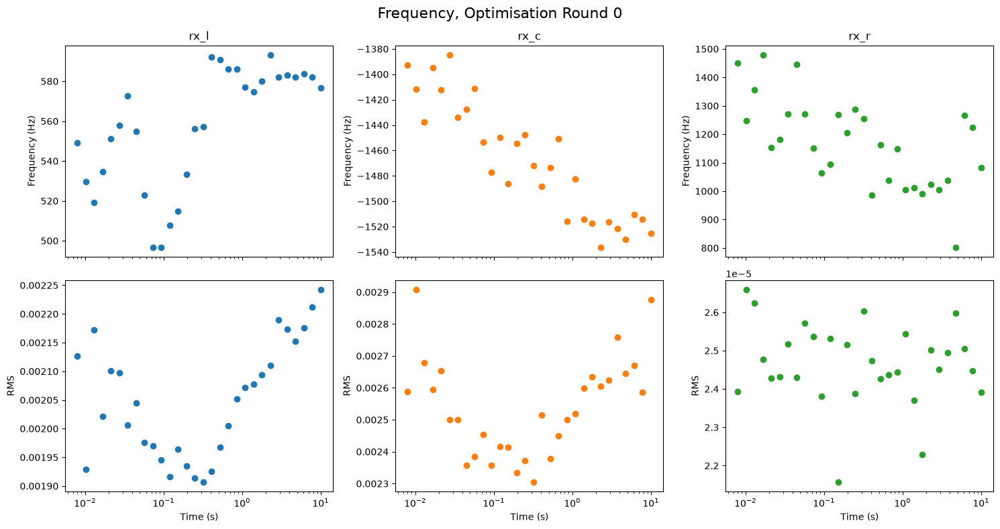

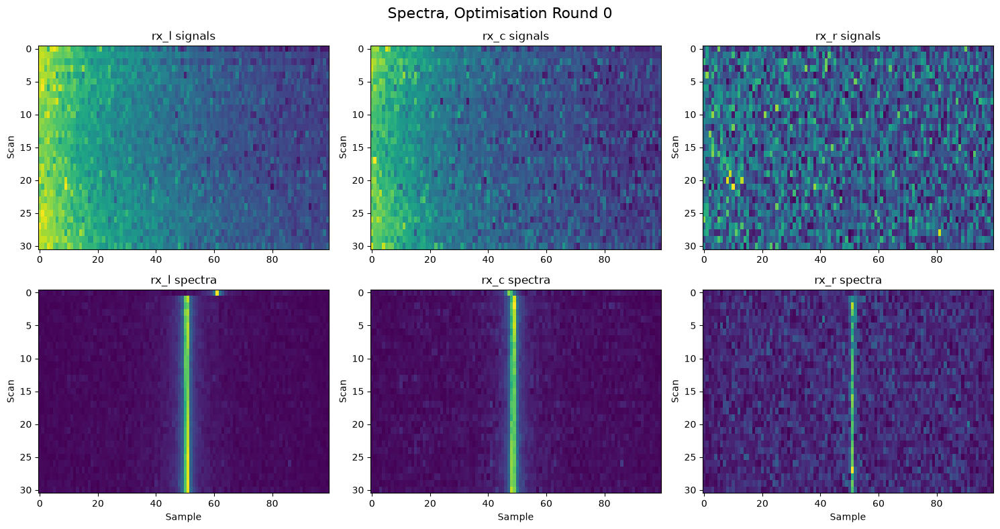

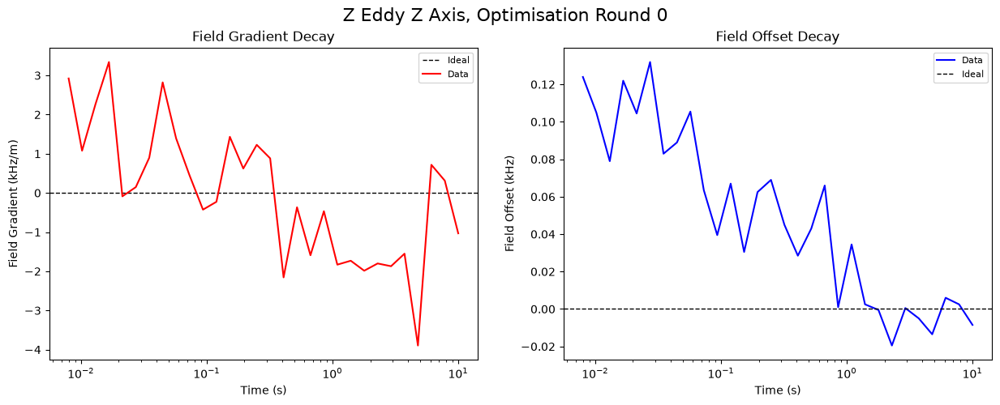

[I 2026-11-24 16:28:14,943] Trial 0 finished with value: 14225.336200909898 and parameters: {'Z_A1': 0.08112649563413, 'Z_A2': 0.043851701592395, 'Z_A3': 0.1127469151338008, 'Z_A4': 0}. Best is trial 0 with value: 14225.336200909898.


max |E| = 9440.279860069963
mean |E| = 6081.959020489753
RMS E = 6312.466195979499
Total cost = 1.423e+04
E max = 0.12354626825368051
E nanmax = 0.12354626825368051
E contains nan = False
B max = 0.013384124932589465
B nanmax = 0.013384124932589465
B contains nan = False
Trial 1


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013384124932589465 !!!!!!!!!!!!!!!!


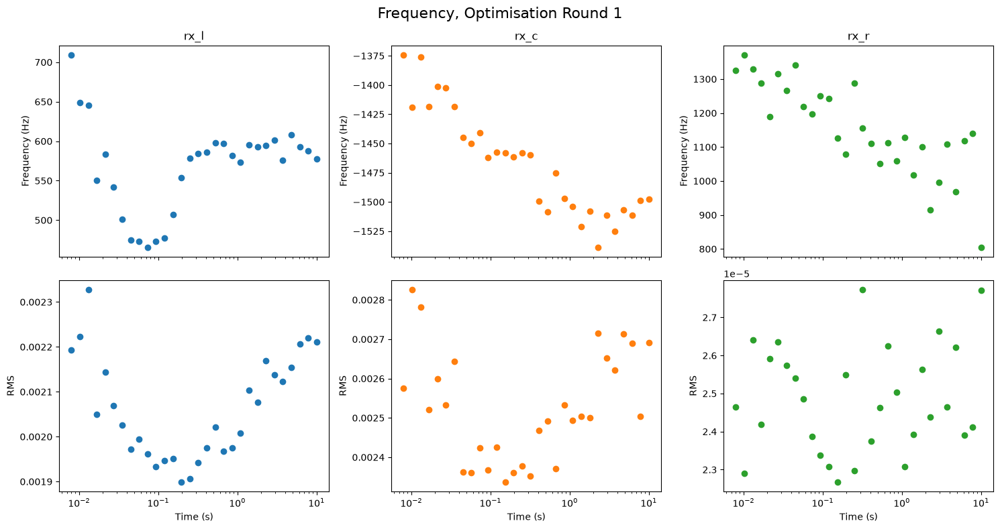

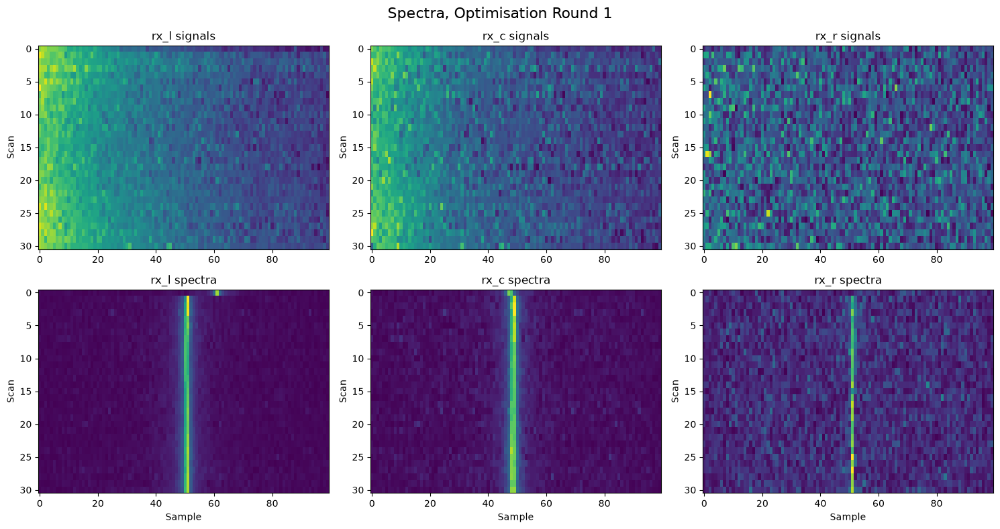

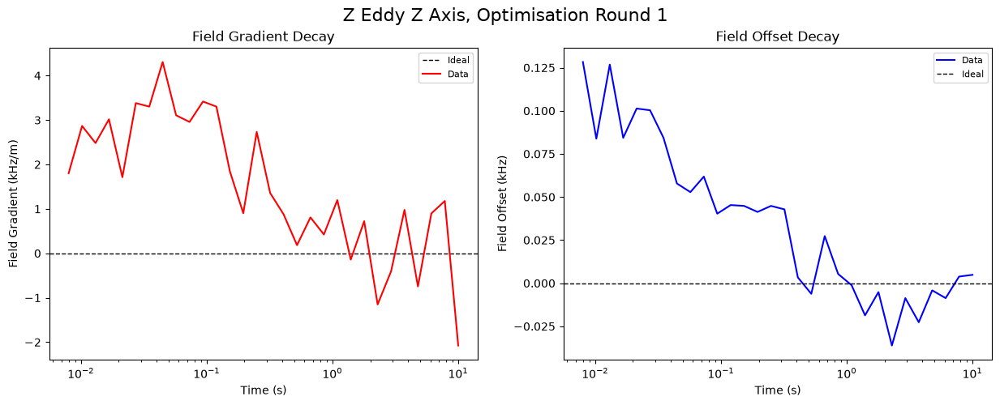

[I 2026-11-24 16:29:03,322] Trial 1 finished with value: 10495.840514940635 and parameters: {'Z_A1': 0.07806470741876756, 'Z_A2': 0.05906143787789428, 'Z_A3': 0.06945898996113914, 'Z_A4': -6.733750940819645e-09}. Best is trial 1 with value: 10495.840514940635.


max |E| = 8660.669665167416
mean |E| = 5862.402132267199
RMS E = 6058.007761118202
Total cost = 1.050e+04
E max = 0.12919044783102265
E nanmax = 0.12919044783102265
E contains nan = False
B max = 0.013995608761006945
B nanmax = 0.013995608761006945
B contains nan = False
Trial 2


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013995608761006945 !!!!!!!!!!!!!!!!


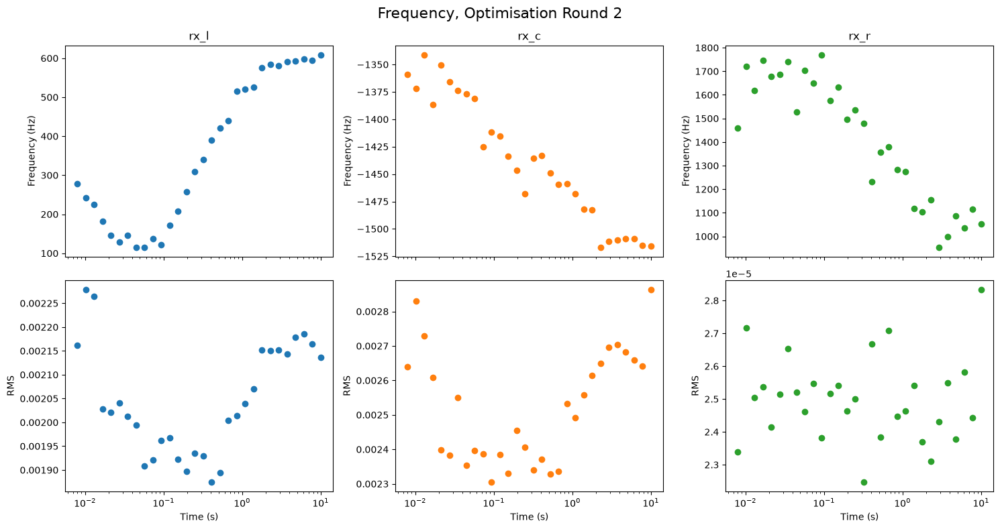

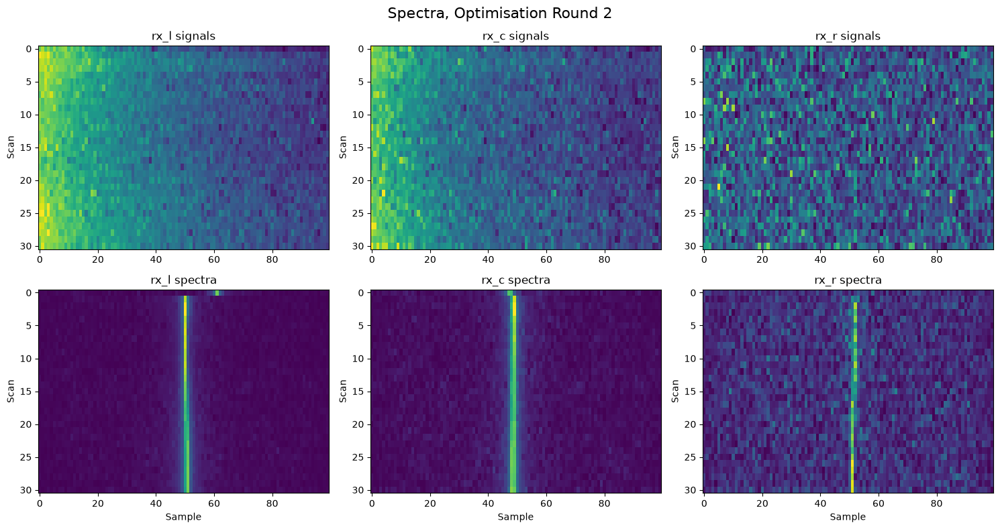

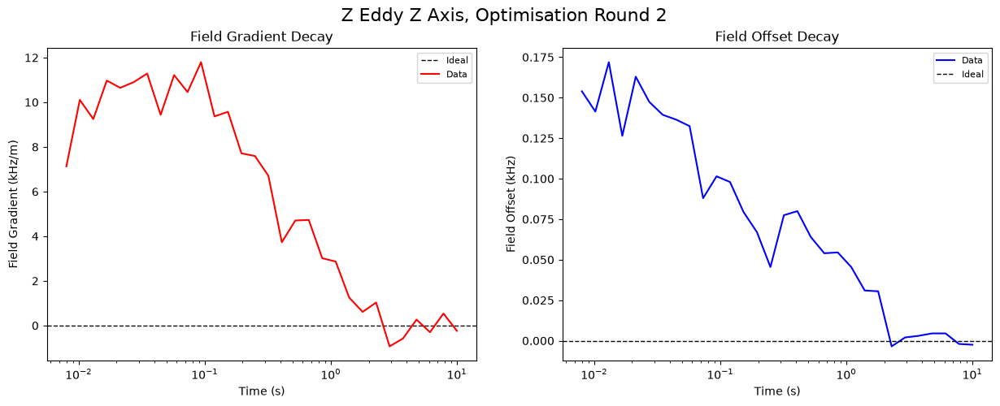

[I 2026-11-24 16:29:51,474] Trial 2 finished with value: 10859.38967040658 and parameters: {'Z_A1': 0.11038945728505906, 'Z_A2': 0.05886727404664242, 'Z_A3': 0.07829033060601807, 'Z_A4': 3.0011826730051545e-10}. Best is trial 1 with value: 10495.840514940635.


max |E| = 16466.76661669165
mean |E| = 10498.91720806263
RMS E = 11389.347632672332
Total cost = 1.086e+04
E max = 0.12098532572931461
E nanmax = 0.12098532572931461
E contains nan = False
B max = 0.013106645823858242
B nanmax = 0.013106645823858242
B contains nan = False
Trial 3


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013106645823858242 !!!!!!!!!!!!!!!!


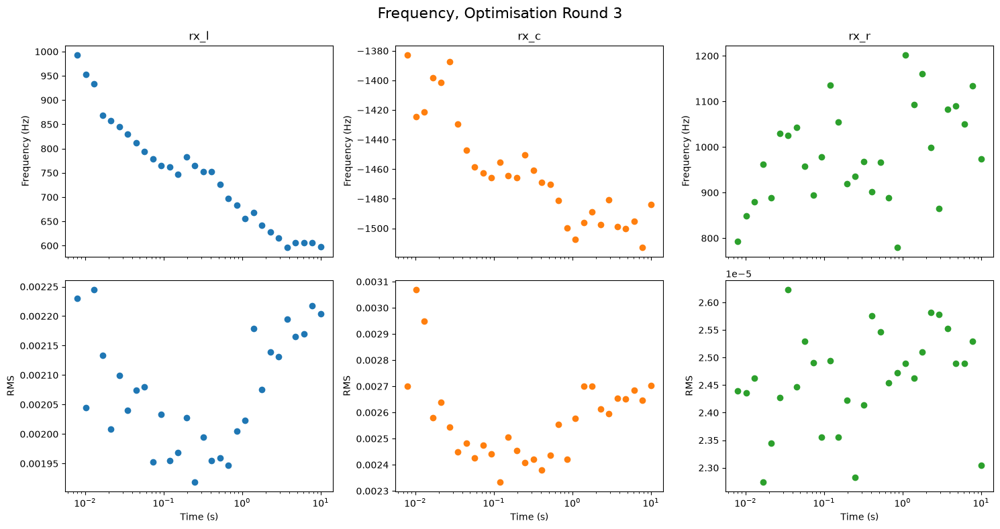

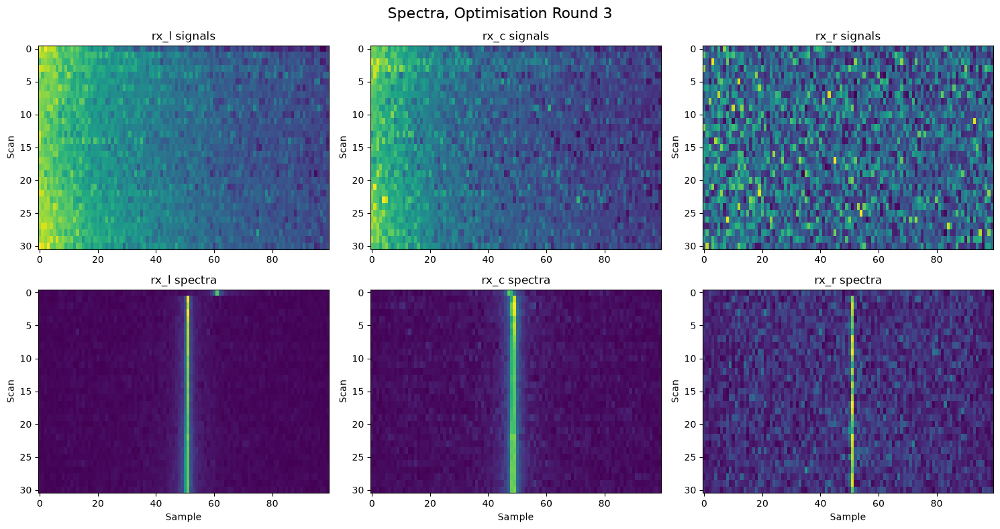

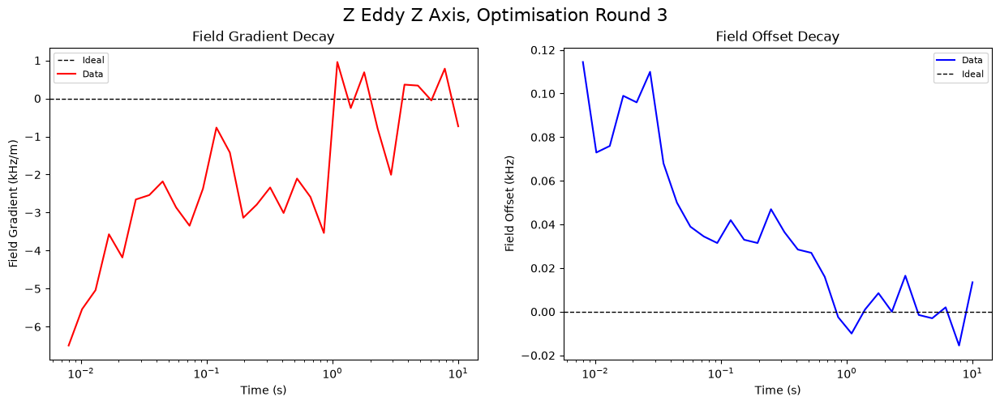

[I 2026-11-24 16:30:39,524] Trial 3 finished with value: 8339.313836615998 and parameters: {'Z_A1': 0.05652489746933704, 'Z_A2': 0.04652625183267391, 'Z_A3': 0.08408884755010947, 'Z_A4': 3.90626634569856e-09}. Best is trial 3 with value: 8339.313836615998.


max |E| = 5457.2713643178395
mean |E| = 2631.8507412960184
RMS E = 3035.791631819801
Total cost = 8.339e+03
E max = 0.13120477705357356
E nanmax = 0.13120477705357356
E contains nan = False
B max = 0.01421374927988672
B nanmax = 0.01421374927988672
B contains nan = False
Trial 4


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01421374927988672 !!!!!!!!!!!!!!!!


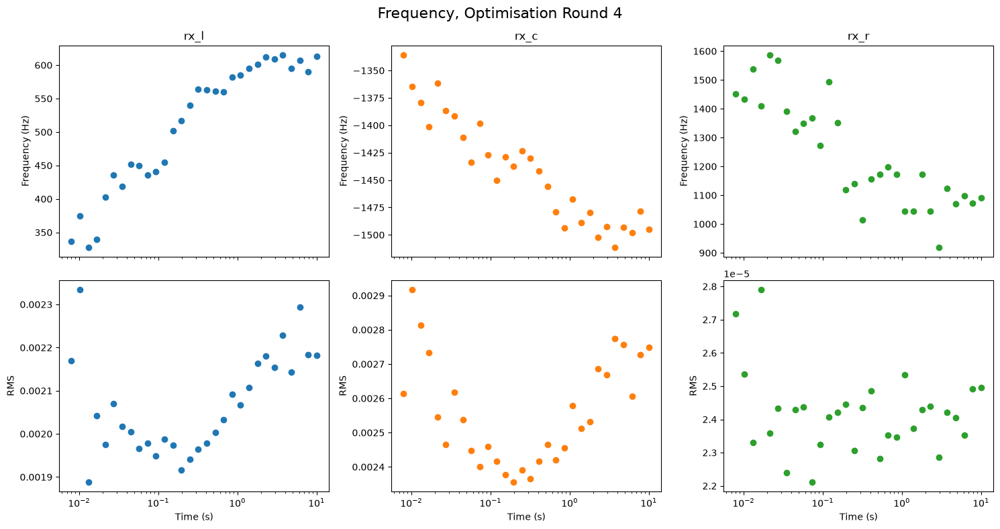

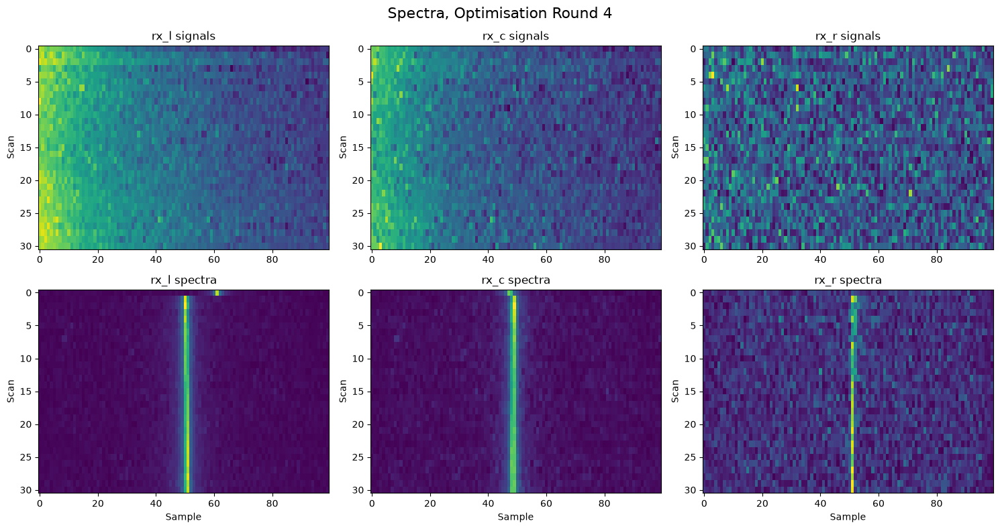

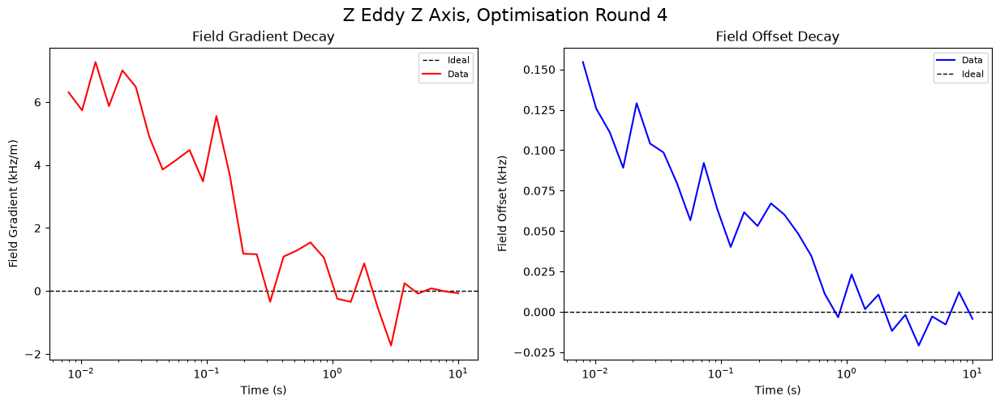

[I 2026-11-24 16:31:27,878] Trial 4 finished with value: 4360.77870660838 and parameters: {'Z_A1': 0.08464864380538897, 'Z_A2': 0.05474420061952605, 'Z_A3': 0.12332132565816764, 'Z_A4': -1.2401722312214857e-09}. Best is trial 4 with value: 4360.77870660838.


max |E| = 12108.945527236378
mean |E| = 7304.181242711975
RMS E = 7779.018633958684
Total cost = 4.361e+03
E max = 0.13058071323141082
E nanmax = 0.13058071323141082
E contains nan = False
B max = 0.01414616915445963
B nanmax = 0.01414616915445963
B contains nan = False
Trial 5


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01414616915445963 !!!!!!!!!!!!!!!!


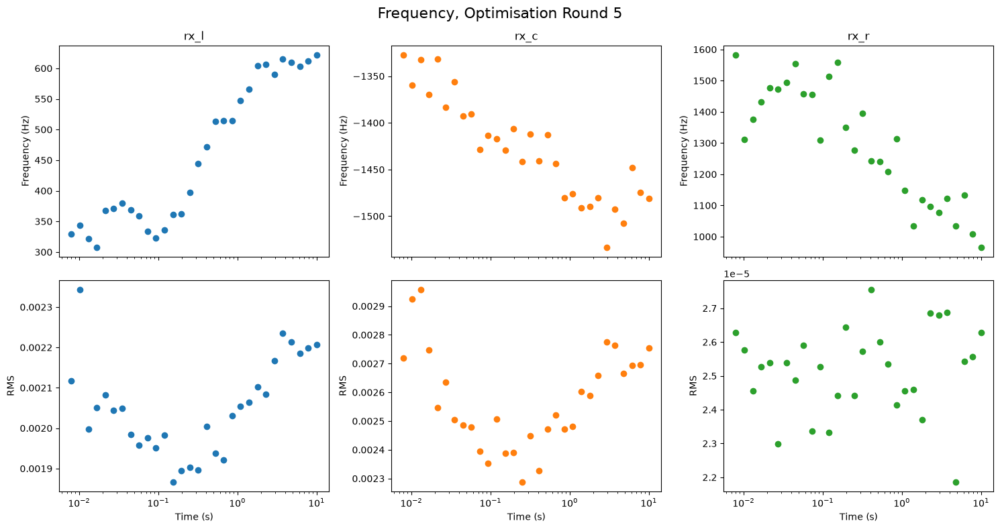

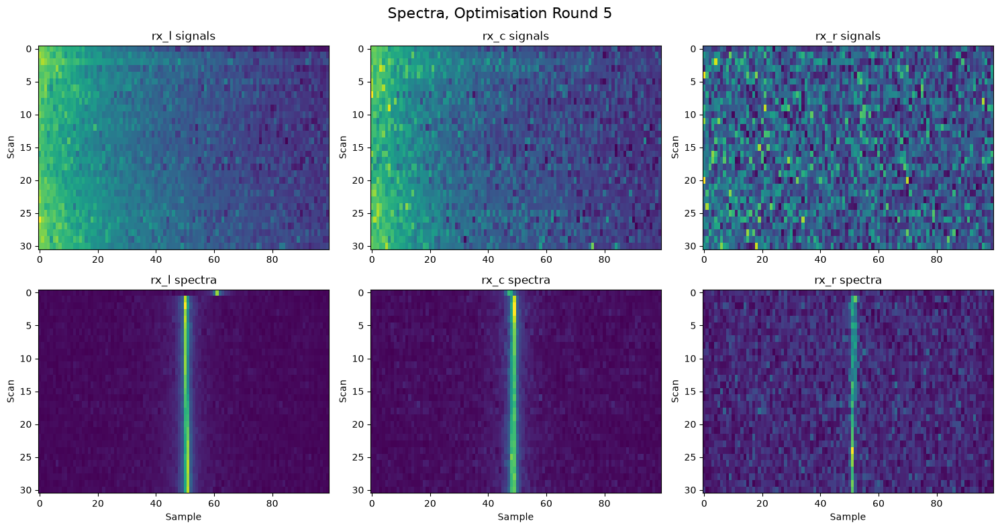

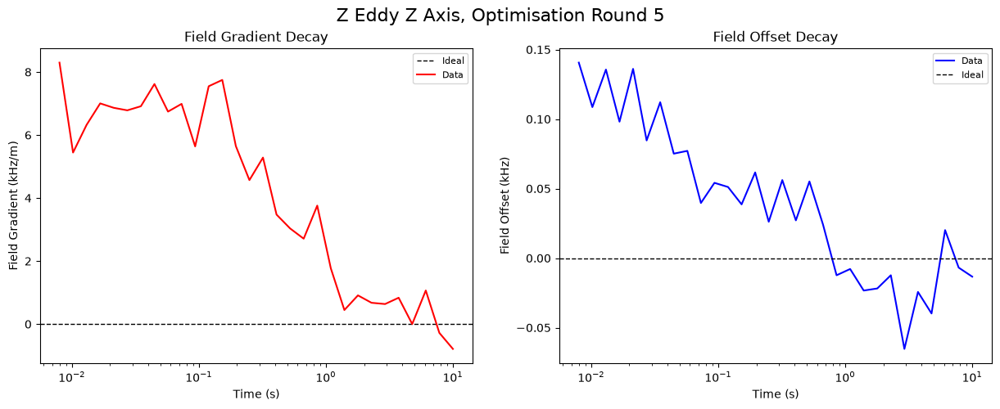

[I 2026-11-24 16:32:15,793] Trial 5 finished with value: 9831.234441513472 and parameters: {'Z_A1': 0.10007034061040303, 'Z_A2': 0.043987992576557375, 'Z_A3': 0.11373318598465082, 'Z_A4': -5.038936344018767e-09}. Best is trial 4 with value: 4360.77870660838.


max |E| = 12528.735632183903
mean |E| = 8353.65650508079
RMS E = 8839.819599620996
Total cost = 9.831e+03
E max = 0.13813580461702424
E nanmax = 0.13813580461702424
E contains nan = False
B max = 0.014964594669358622
B nanmax = 0.014964594669358622
B contains nan = False
Trial 6


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014964594669358622 !!!!!!!!!!!!!!!!


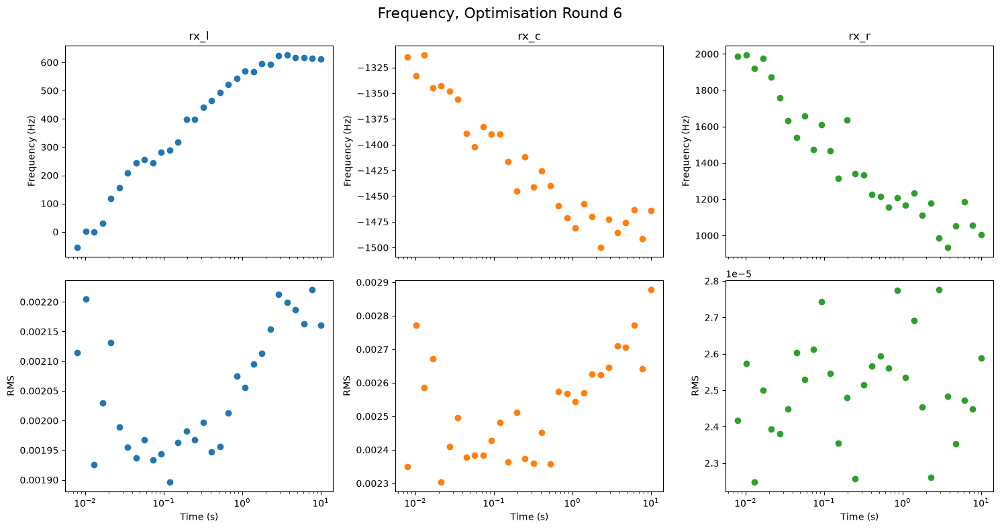

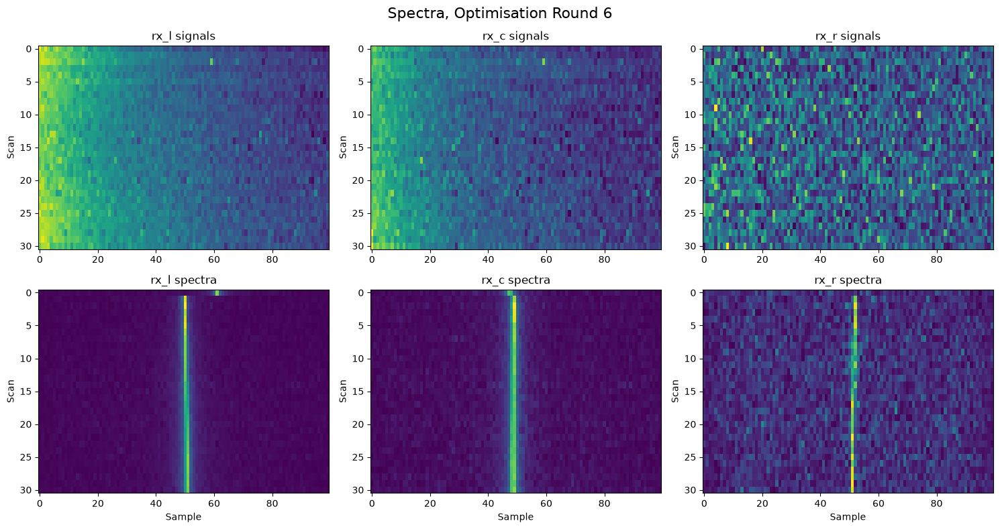

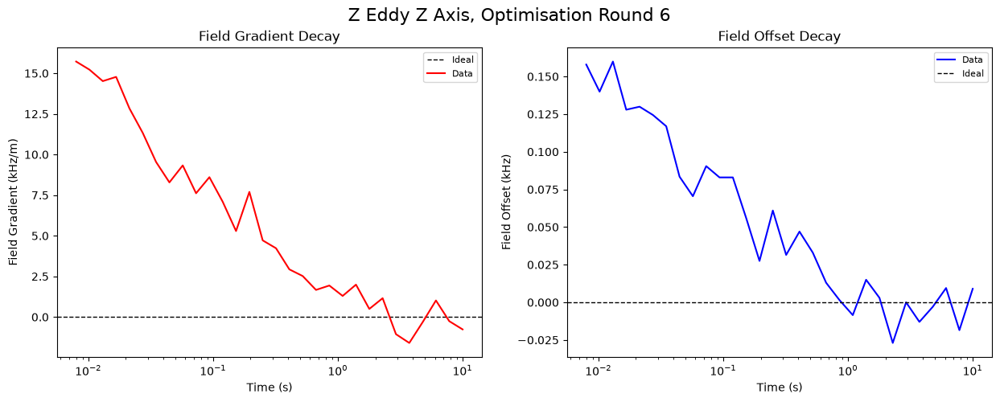

[I 2026-11-24 16:33:03,757] Trial 6 finished with value: 11113.412576294857 and parameters: {'Z_A1': 0.09972394733185996, 'Z_A2': 0.05940699689056139, 'Z_A3': 0.150167190429309, 'Z_A4': -1.6778450335614244e-10}. Best is trial 4 with value: 4360.77870660838.


max |E| = 20409.79510244877
mean |E| = 10283.524904214555
RMS E = 11583.22430810423
Total cost = 1.111e+04
E max = 0.12169918477000571
E nanmax = 0.12169918477000571
E contains nan = False
B max = 0.013183974800961631
B nanmax = 0.013183974800961631
B contains nan = False
Trial 7


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013183974800961631 !!!!!!!!!!!!!!!!


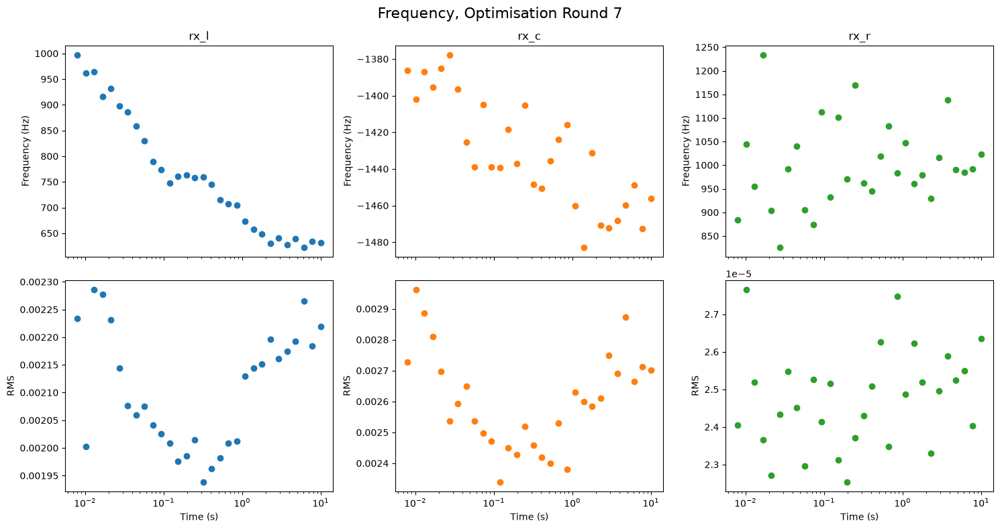

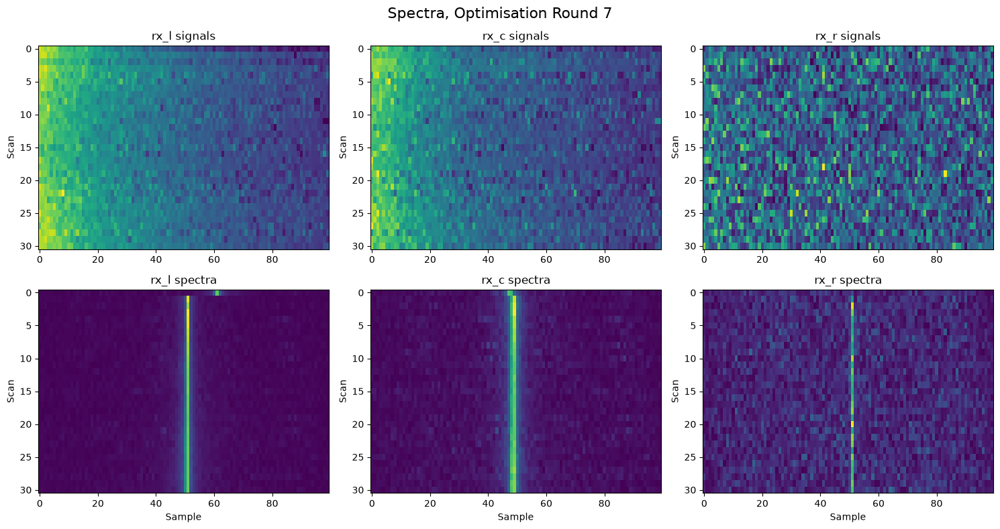

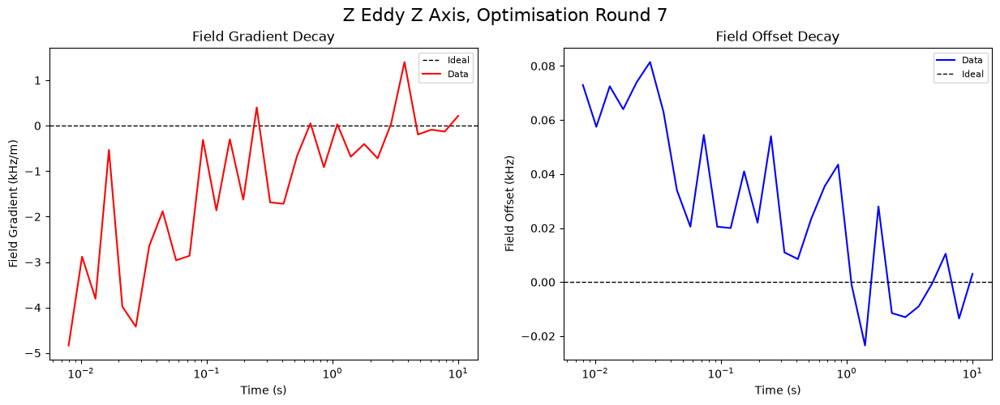

[I 2026-11-24 16:33:51,716] Trial 7 finished with value: 4005.372085500783 and parameters: {'Z_A1': 0.06295865333333389, 'Z_A2': 0.033411296790684775, 'Z_A3': 0.096005817070637, 'Z_A4': 6.671719859620752e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5107.446276861567
mean |E| = 2522.0722971847404
RMS E = 2840.083374933154
Total cost = 4.005e+03
E max = 0.12987661082295496
E nanmax = 0.12987661082295496
E contains nan = False
B max = 0.014069850888222175
B nanmax = 0.014069850888222175
B contains nan = False
Trial 8


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014069850888222175 !!!!!!!!!!!!!!!!


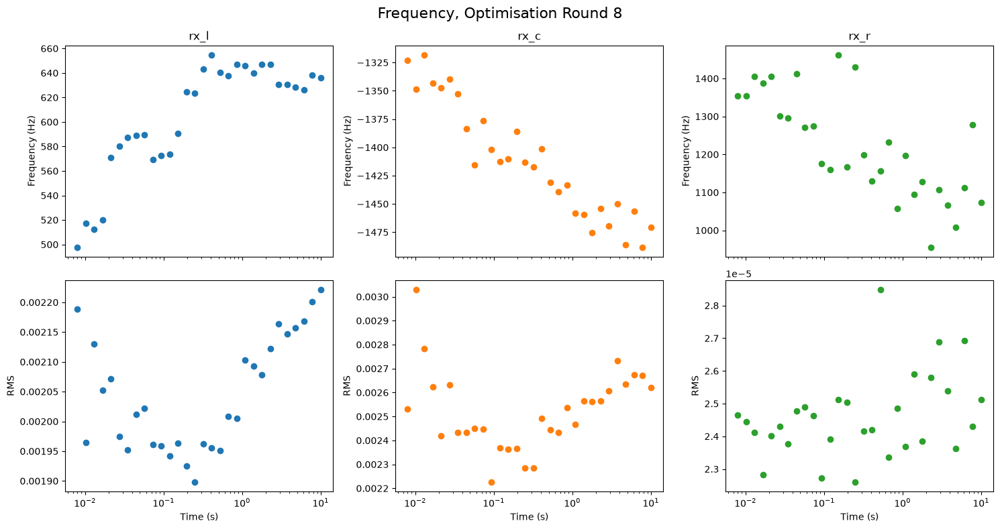

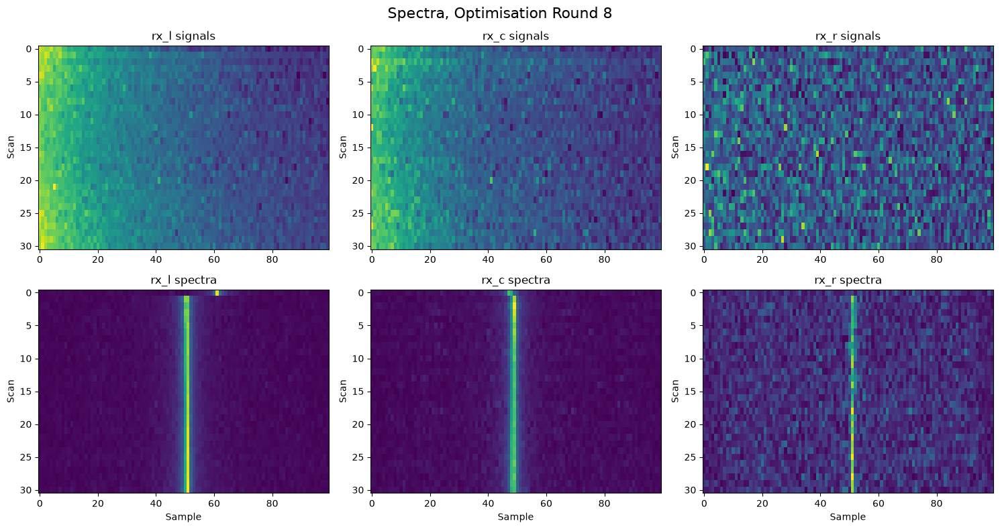

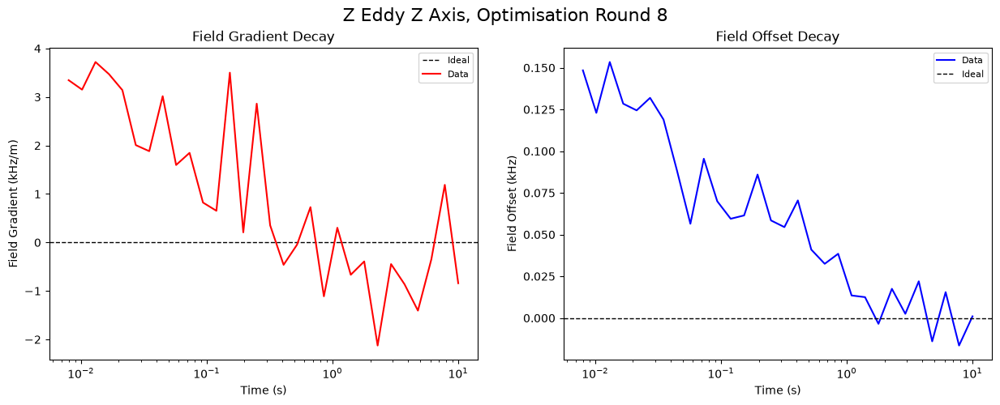

[I 2026-11-24 16:34:39,940] Trial 8 finished with value: 9211.75316365032 and parameters: {'Z_A1': 0.07771788059492829, 'Z_A2': 0.04829861110574565, 'Z_A3': 0.1270668035648796, 'Z_A4': -5.310763099913602e-10}. Best is trial 7 with value: 4005.372085500783.


max |E| = 8930.534732633681
mean |E| = 6179.077128102614
RMS E = 6405.240573396666
Total cost = 9.212e+03
E max = 0.12484524885223597
E nanmax = 0.12484524885223597
E contains nan = False
B max = 0.013524862868503018
B nanmax = 0.013524862868503018
B contains nan = False
Trial 9


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013524862868503018 !!!!!!!!!!!!!!!!


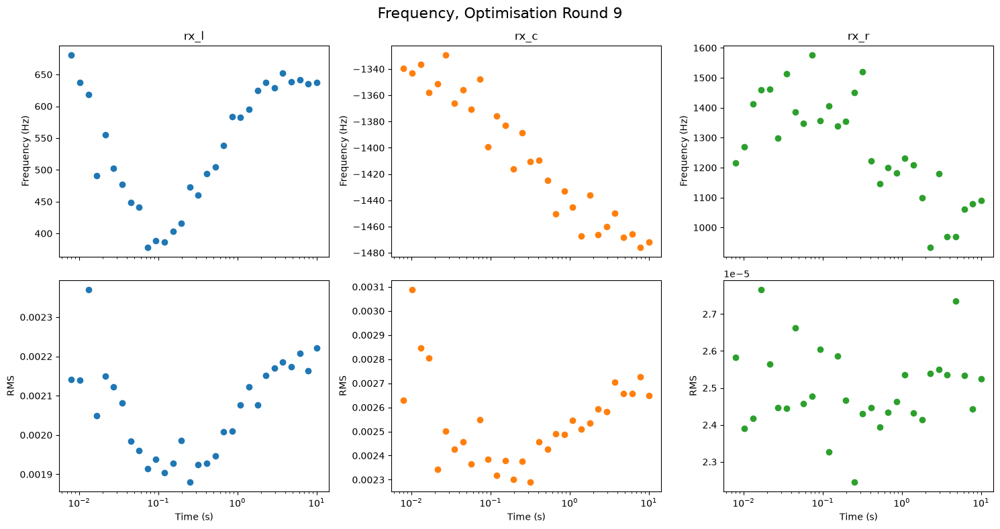

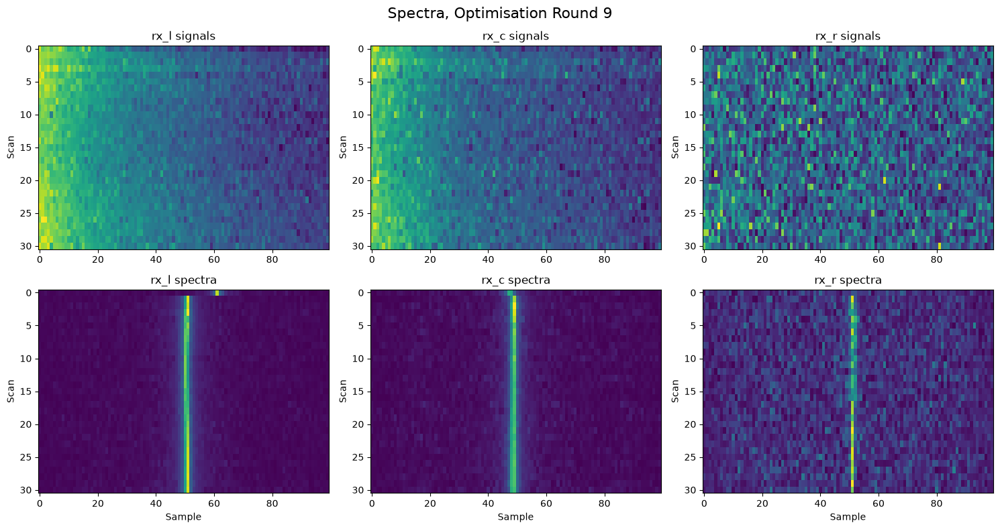

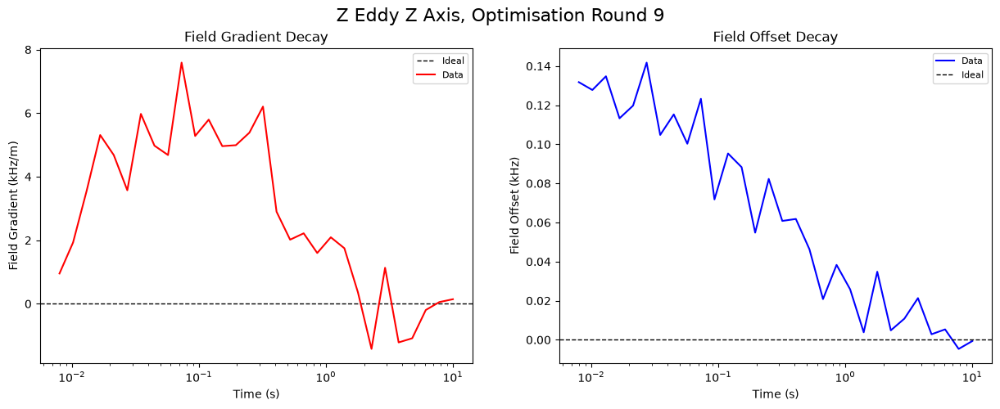

[I 2026-11-24 16:35:28,276] Trial 9 finished with value: 9160.047423071339 and parameters: {'Z_A1': 0.10185191445202306, 'Z_A2': 0.03502096128238147, 'Z_A3': 0.07851388112390156, 'Z_A4': 6.90731332170462e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 11979.01049475262
mean |E| = 7261.869065467264
RMS E = 7673.8071035639405
Total cost = 9.160e+03
E max = 0.12033546094805792
E nanmax = 0.12033546094805792
E contains nan = False
B max = 0.013036223158316065
B nanmax = 0.013036223158316065
B contains nan = False
Trial 10


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013036223158316065 !!!!!!!!!!!!!!!!


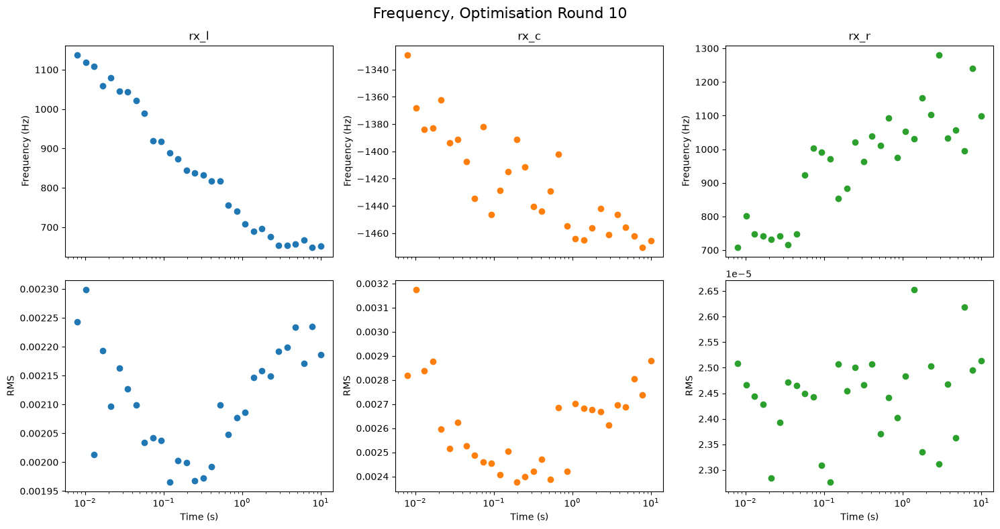

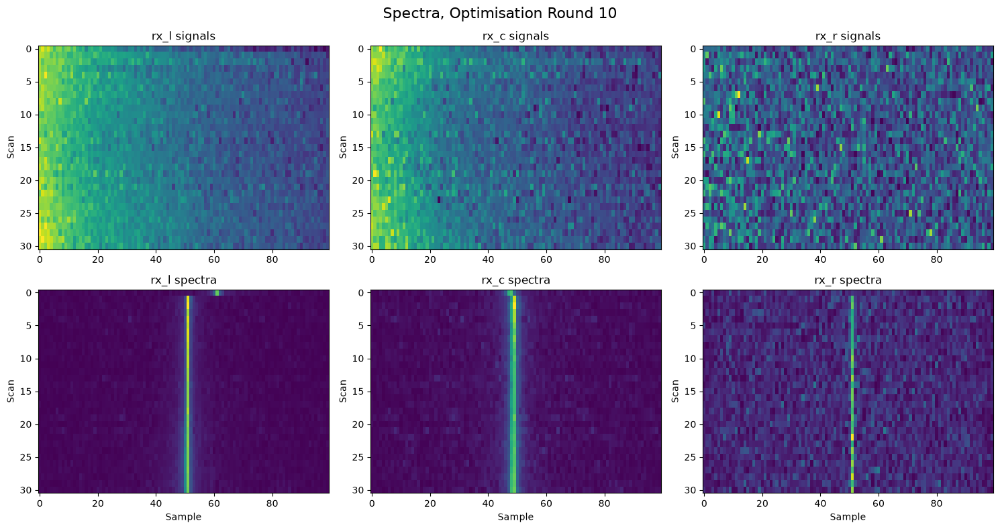

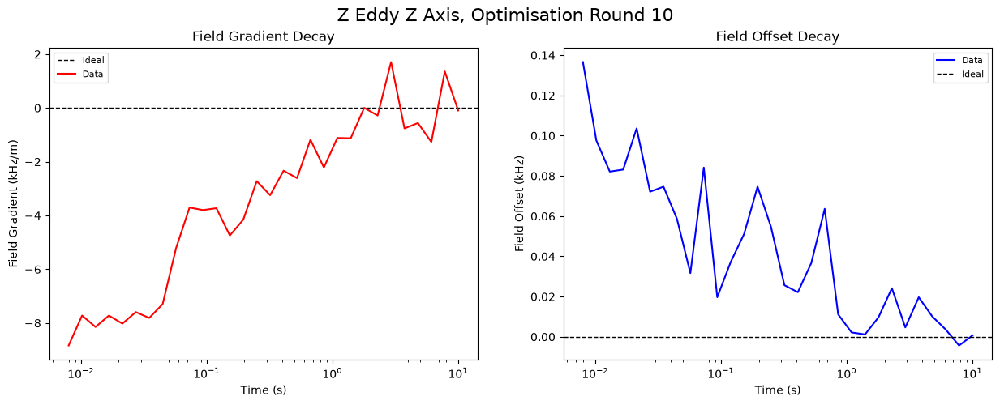

[I 2026-11-24 16:36:16,620] Trial 10 finished with value: 10853.016606210822 and parameters: {'Z_A1': 0.05514414716030493, 'Z_A2': 0.026775968109702505, 'Z_A3': 0.09959581404024564, 'Z_A4': 4.527584160595655e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 6256.87156421789
mean |E| = 2891.8873896385135
RMS E = 3273.056078399862
Total cost = 1.085e+04
E max = 0.12120352089865223
E nanmax = 0.12120352089865223
E contains nan = False
B max = 0.013130308882294045
B nanmax = 0.013130308882294045
B contains nan = False
Trial 11


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013130308882294045 !!!!!!!!!!!!!!!!


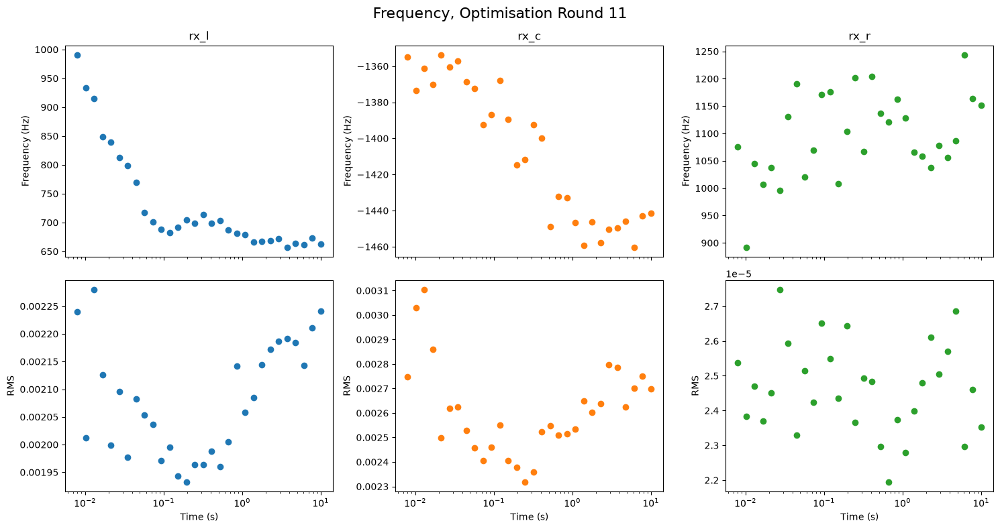

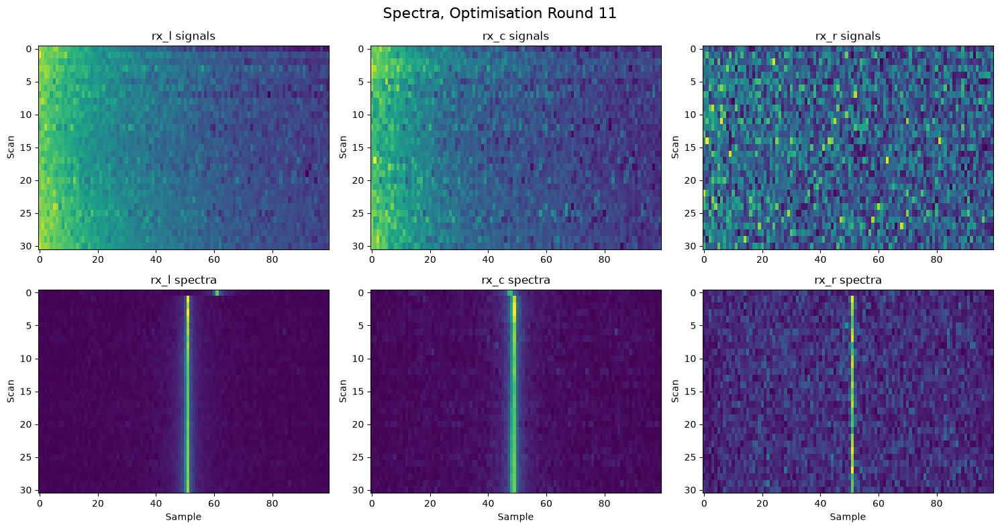

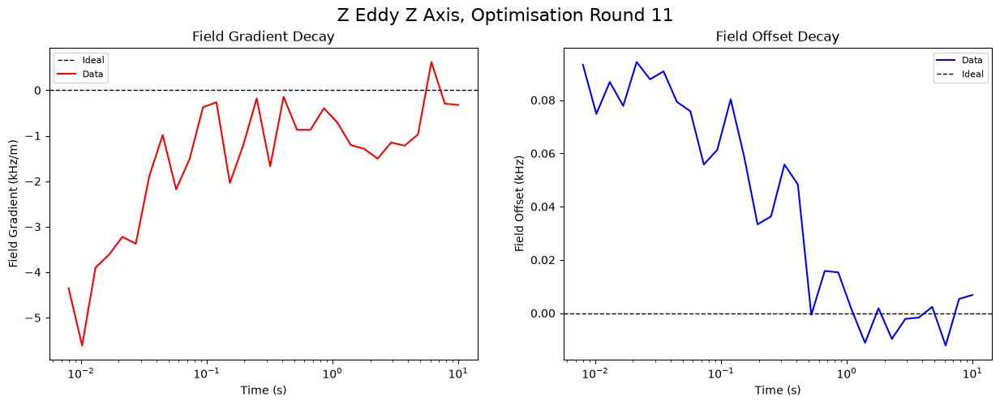

[I 2026-11-24 16:37:04,722] Trial 11 finished with value: 7856.887065756951 and parameters: {'Z_A1': 0.07332515110063842, 'Z_A2': 0.03751107454580189, 'Z_A3': 0.07762742712531767, 'Z_A4': 8.72515038238064e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5822.0889555222375
mean |E| = 3672.663668165916
RMS E = 3909.6366097458626
Total cost = 7.857e+03
E max = 0.12230853751924355
E nanmax = 0.12230853751924355
E contains nan = False
B max = 0.013250037339456875
B nanmax = 0.013250037339456875
B contains nan = False
Trial 12


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013250037339456875 !!!!!!!!!!!!!!!!


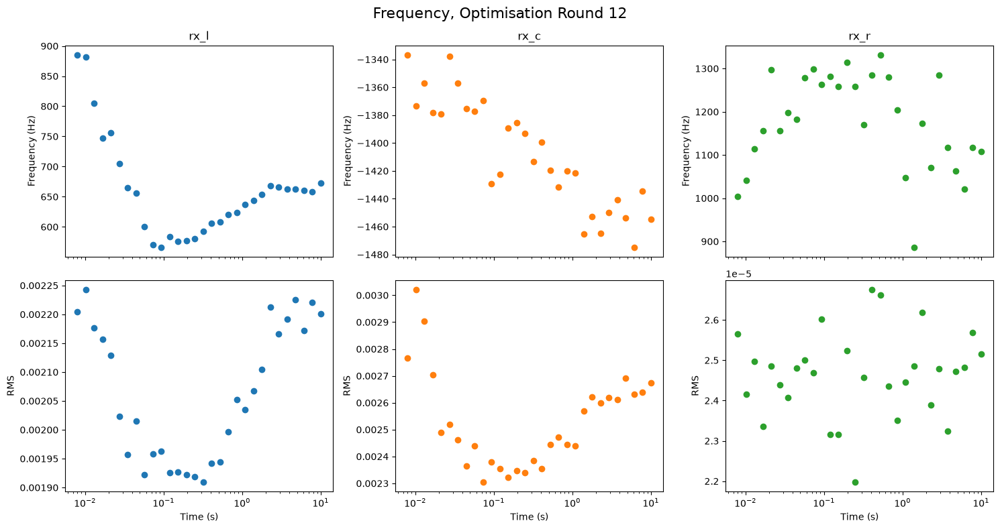

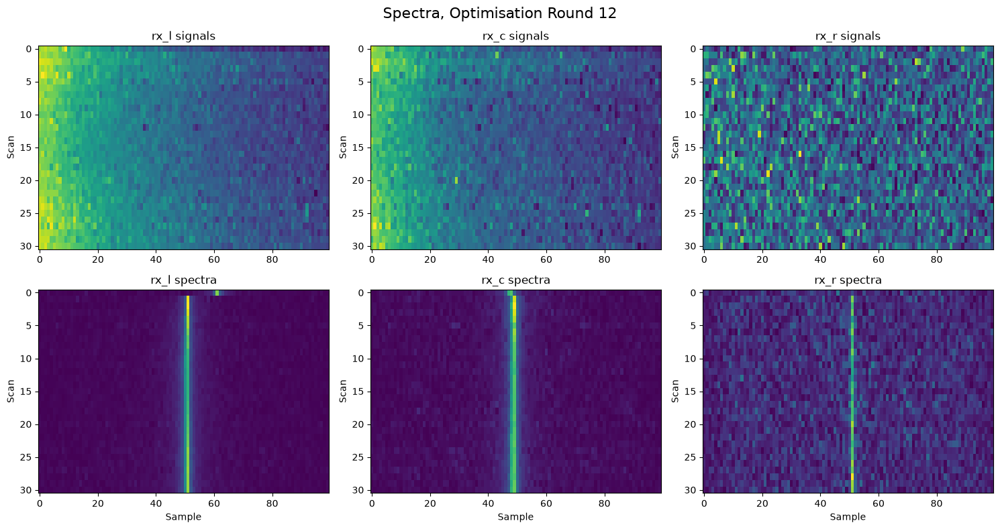

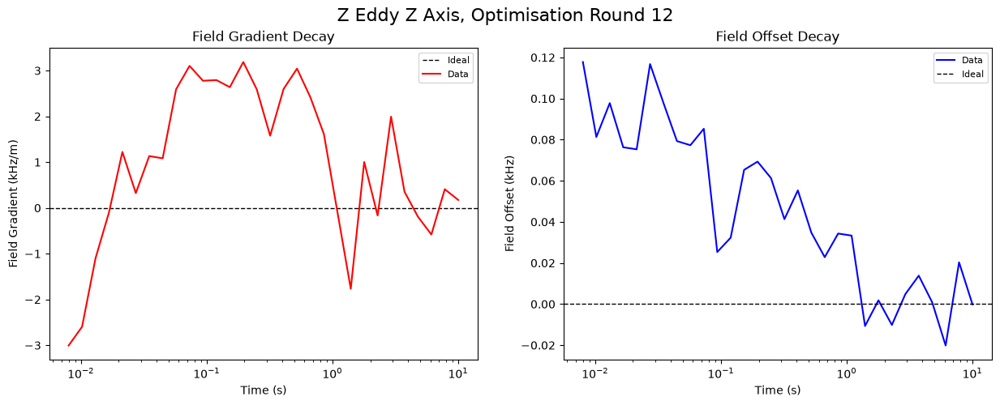

[I 2026-11-24 16:37:52,881] Trial 12 finished with value: 7270.4289155963015 and parameters: {'Z_A1': 0.088306085869046, 'Z_A2': 0.031787635139908066, 'Z_A3': 0.07637435556446355, 'Z_A4': -2.726076379990266e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 7376.311844077959
mean |E| = 5157.088122605363
RMS E = 5422.8834565294355
Total cost = 7.270e+03
E max = 0.12343800331750894
E nanmax = 0.12343800331750894
E contains nan = False
B max = 0.013372332935019238
B nanmax = 0.013372332935019238
B contains nan = False
Trial 13


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013372332935019238 !!!!!!!!!!!!!!!!


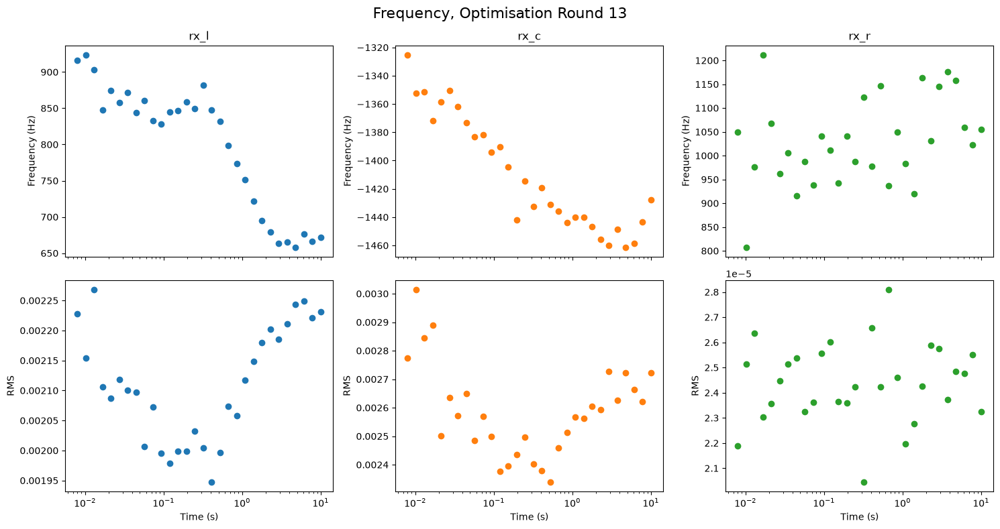

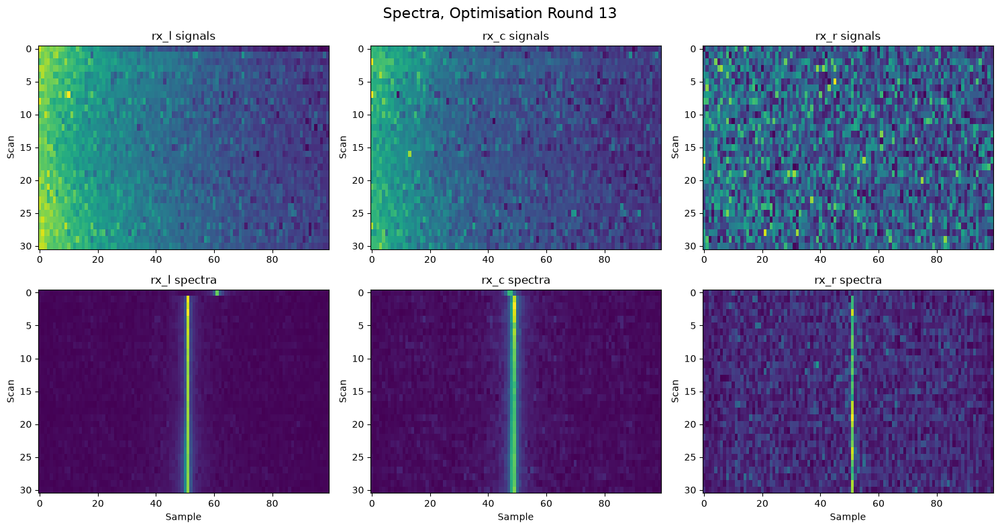

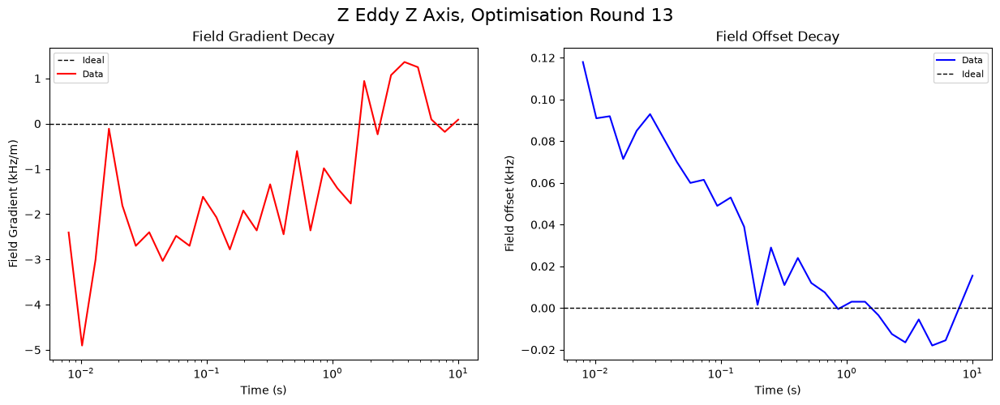

[I 2026-11-24 16:38:40,980] Trial 13 finished with value: 7343.778380506179 and parameters: {'Z_A1': 0.049551279972202794, 'Z_A2': 0.05858181578007531, 'Z_A3': 0.09799445683896332, 'Z_A4': 4.804190100538287e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5107.446276861568
mean |E| = 2393.803098450774
RMS E = 2750.617302772803
Total cost = 7.344e+03
E max = 0.12590713211227642
E nanmax = 0.12590713211227642
E contains nan = False
B max = 0.013639869185203189
B nanmax = 0.013639869185203189
B contains nan = False
Trial 14


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013639869185203189 !!!!!!!!!!!!!!!!


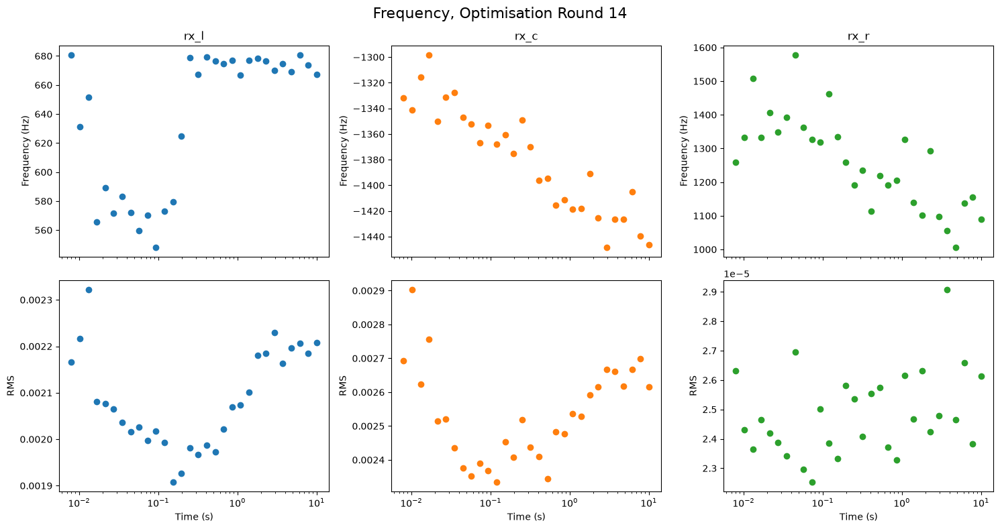

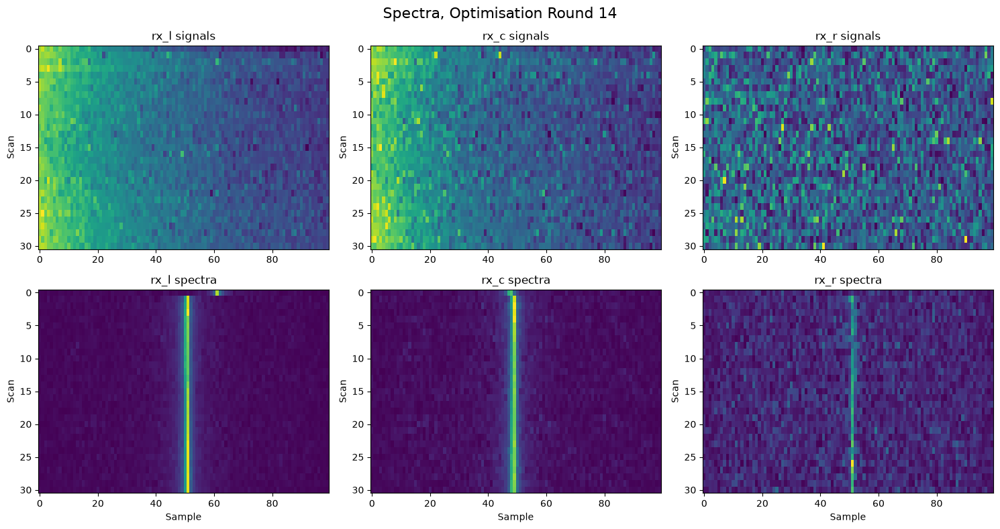

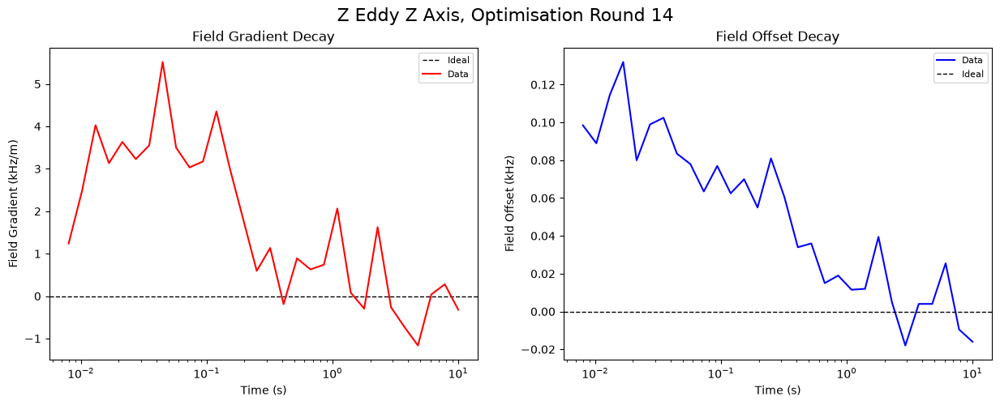

[I 2026-11-24 16:39:28,934] Trial 14 finished with value: 6048.824829264316 and parameters: {'Z_A1': 0.07918959510520862, 'Z_A2': 0.05746868863483574, 'Z_A3': 0.0879594293755204, 'Z_A4': 6.416145177156394e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 10054.972513743125
mean |E| = 6231.051141096116
RMS E = 6466.5876078903175
Total cost = 6.049e+03
E max = 0.12449377133337589
E nanmax = 0.12449377133337589
E contains nan = False
B max = 0.013486740908944127
B nanmax = 0.013486740908944127
B contains nan = False
Trial 15


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013486740908944127 !!!!!!!!!!!!!!!!


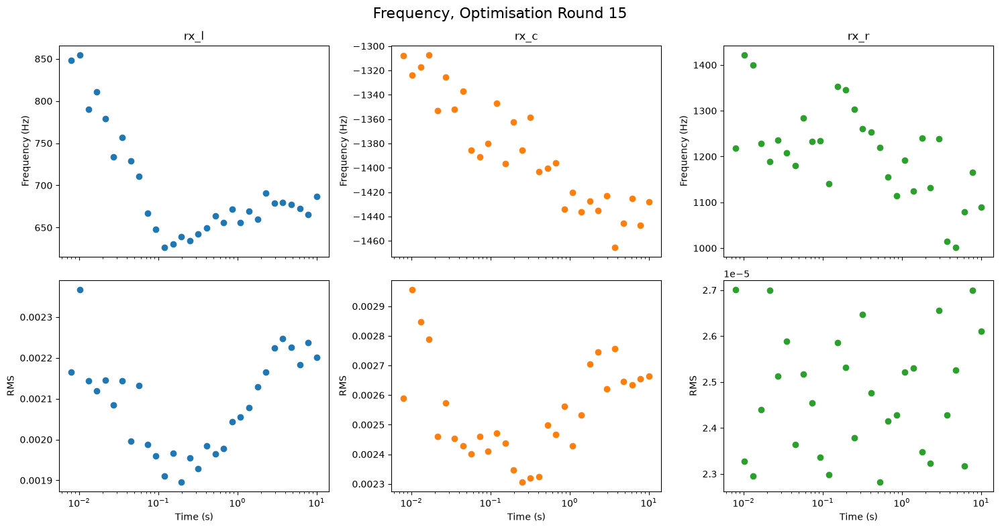

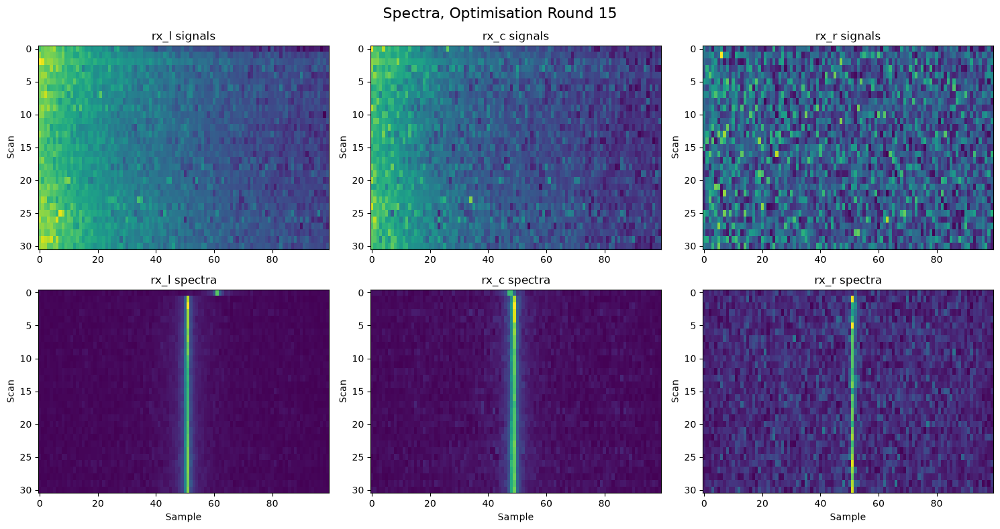

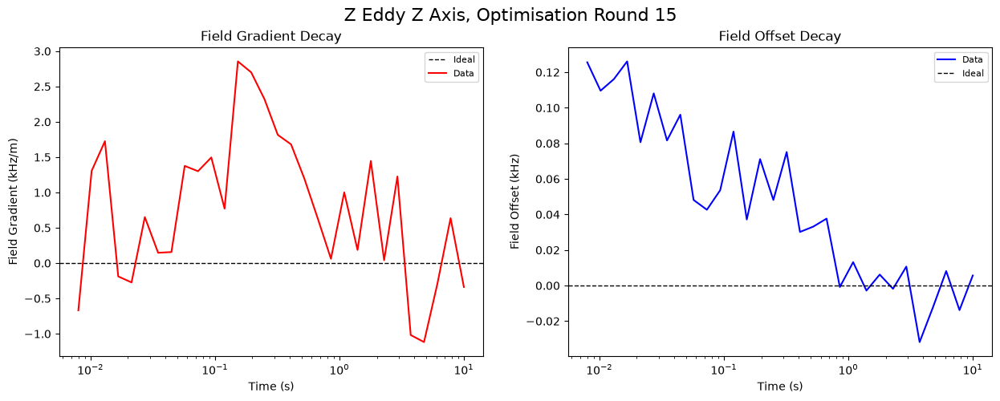

[I 2026-11-24 16:40:17,061] Trial 15 finished with value: 7317.137272167391 and parameters: {'Z_A1': 0.08419376823467048, 'Z_A2': 0.027134498627215363, 'Z_A3': 0.10183139037629209, 'Z_A4': 4.907582055310098e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 7221.389305347326
mean |E| = 5127.2696984840895
RMS E = 5227.280160626031
Total cost = 7.317e+03
E max = 0.13090253041081137
E nanmax = 0.13090253041081137
E contains nan = False
B max = 0.014180986602781399
B nanmax = 0.014180986602781399
B contains nan = False
Trial 16


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014180986602781399 !!!!!!!!!!!!!!!!


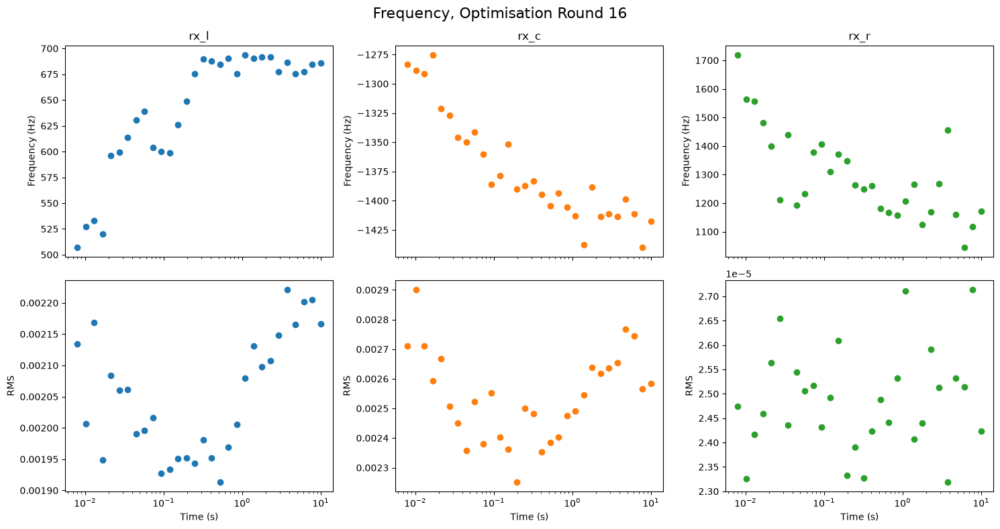

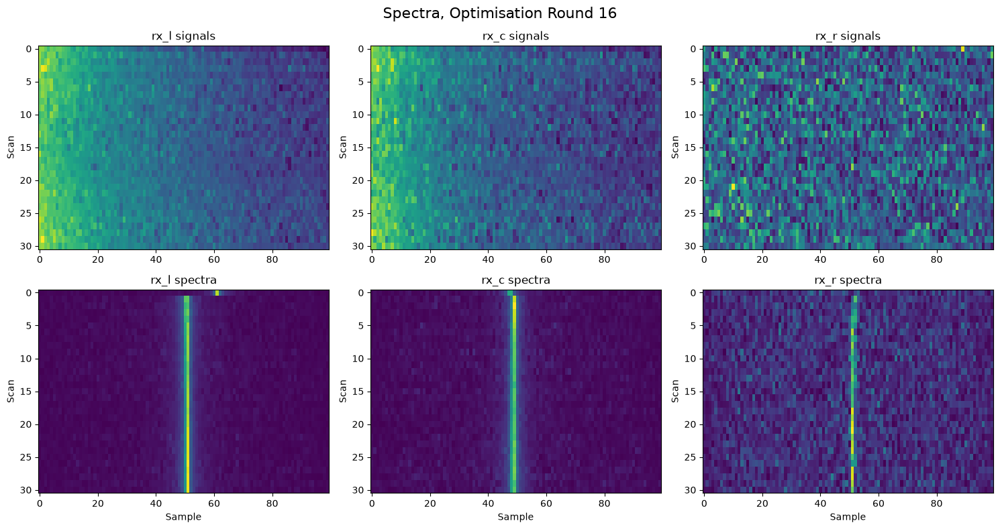

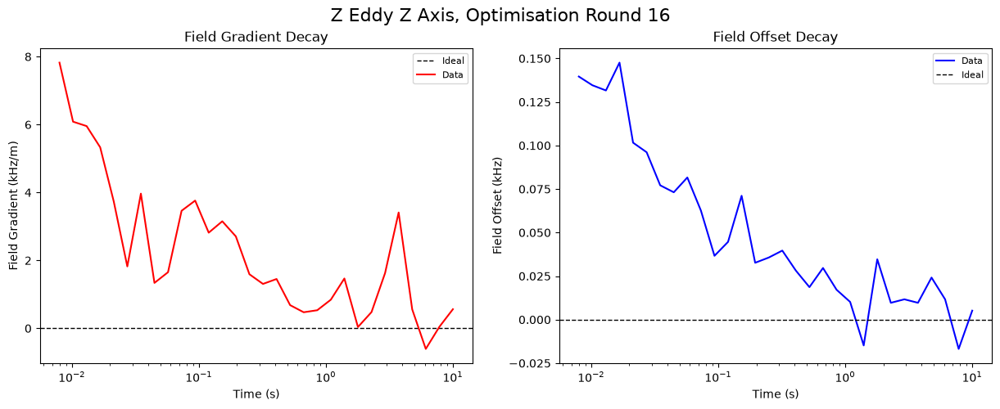

[I 2026-11-24 16:41:05,011] Trial 16 finished with value: 8947.116171472282 and parameters: {'Z_A1': 0.07880054654795907, 'Z_A2': 0.04852820919393038, 'Z_A3': 0.1328938744513383, 'Z_A4': 6.78059220122596e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 12113.943028485755
mean |E| = 6558.720639680158
RMS E = 6862.298964642467
Total cost = 8.947e+03
E max = 0.12458571887111268
E nanmax = 0.12458571887111268
E contains nan = False
B max = 0.01349667935346212
B nanmax = 0.01349667935346212
B contains nan = False
Trial 17


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01349667935346212 !!!!!!!!!!!!!!!!


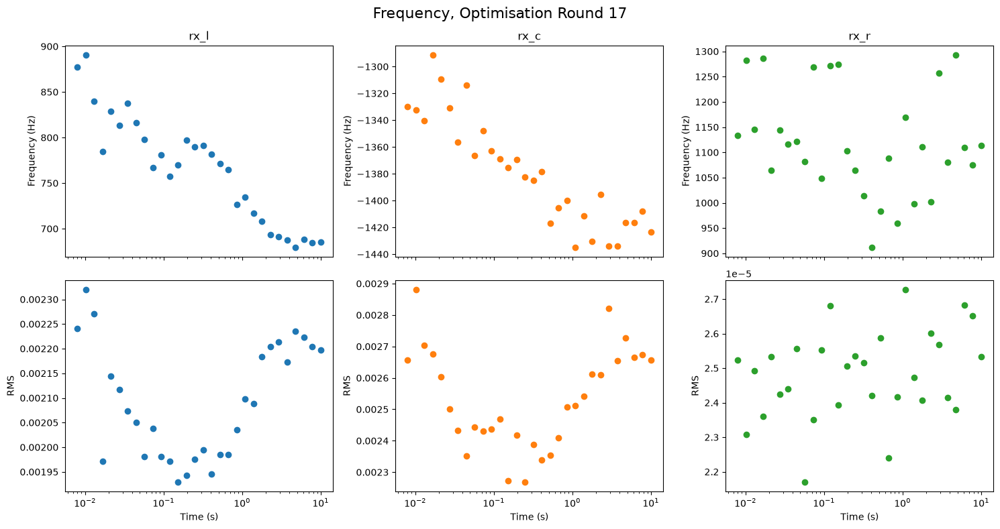

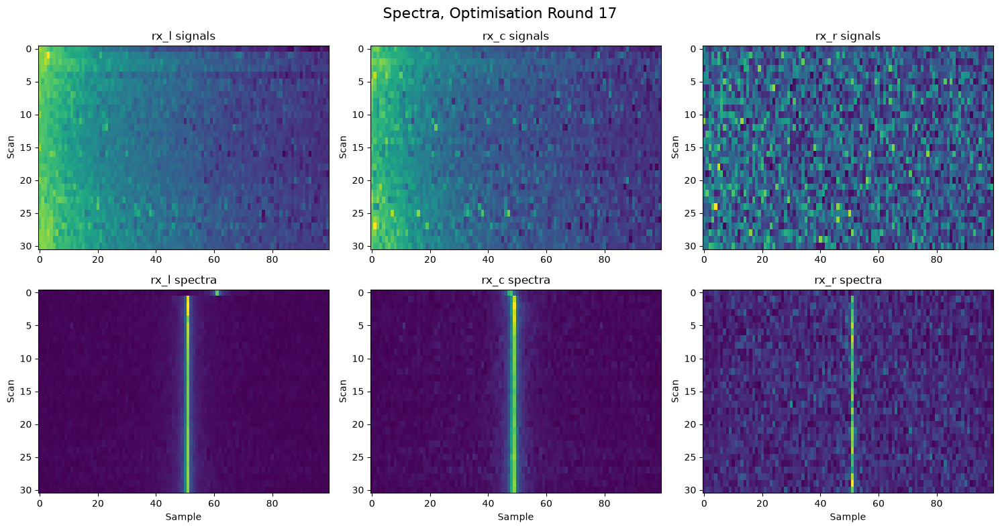

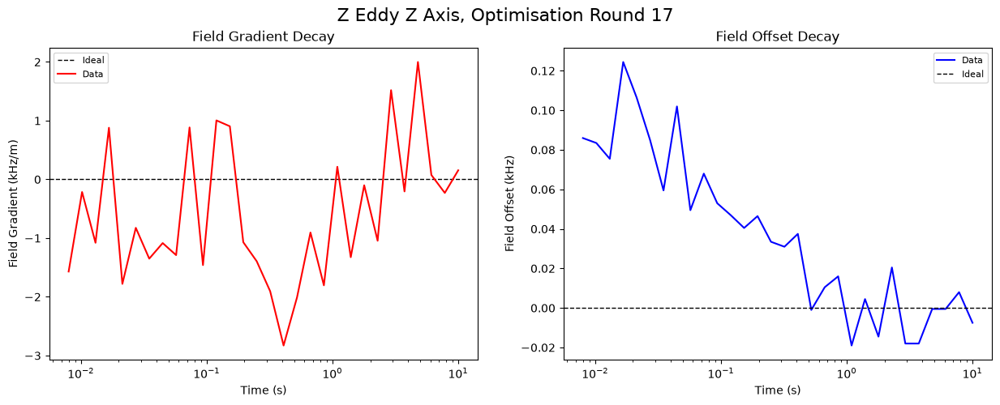

[I 2026-11-24 16:41:53,053] Trial 17 finished with value: 7106.098607311276 and parameters: {'Z_A1': 0.06440660899330714, 'Z_A2': 0.046286679553872, 'Z_A3': 0.10398126193393877, 'Z_A4': 5.662822935371706e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 6131.934032983506
mean |E| = 3538.5640513076783
RMS E = 3718.81906801996
Total cost = 7.106e+03
E max = 0.12396362739033687
E nanmax = 0.12396362739033687
E contains nan = False
B max = 0.013429260978268565
B nanmax = 0.013429260978268565
B contains nan = False
Trial 18


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013429260978268565 !!!!!!!!!!!!!!!!


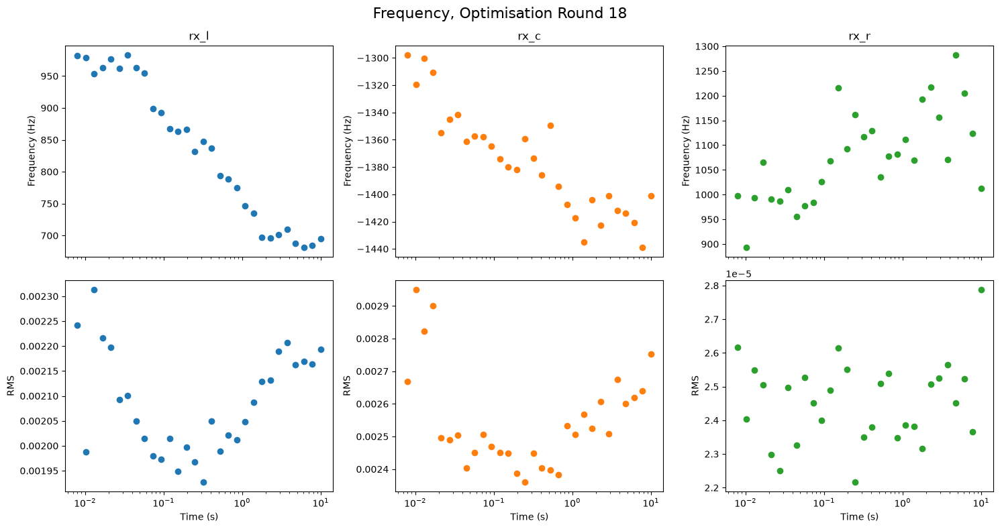

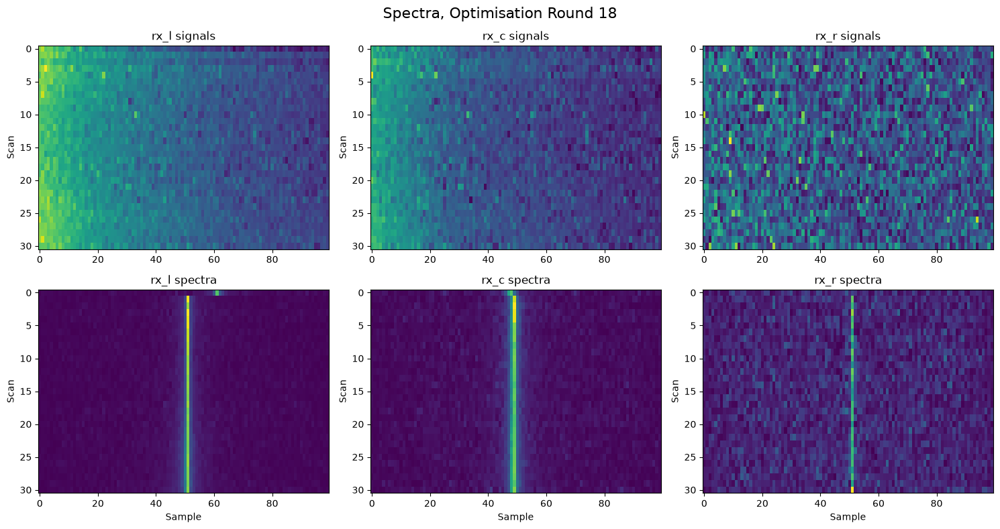

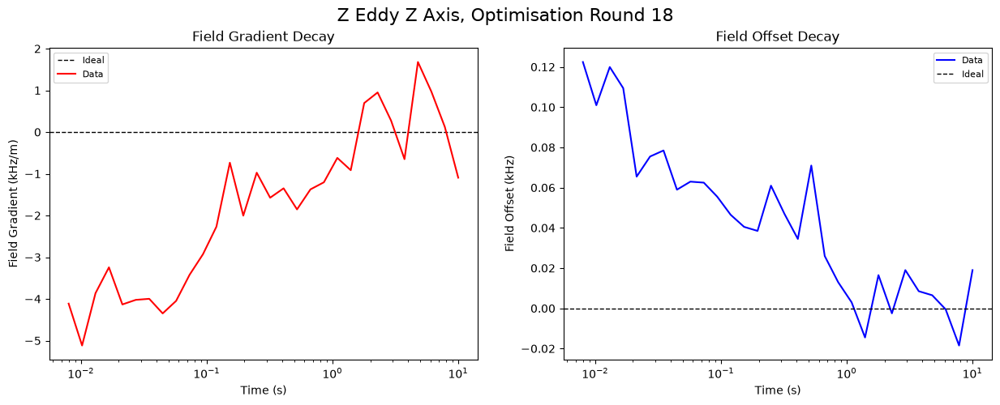

[I 2026-11-24 16:42:41,258] Trial 18 finished with value: 8643.845408468449 and parameters: {'Z_A1': 0.05868431174786906, 'Z_A2': 0.03214607547204777, 'Z_A3': 0.11848259806591041, 'Z_A4': 8.270157020221774e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5947.02648675662
mean |E| = 2491.0877894386135
RMS E = 3048.358059134173
Total cost = 8.644e+03
E max = 0.13036338197636263
E nanmax = 0.13036338197636263
E contains nan = False
B max = 0.014122609896507625
B nanmax = 0.014122609896507625
B contains nan = False
Trial 19


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014122609896507625 !!!!!!!!!!!!!!!!


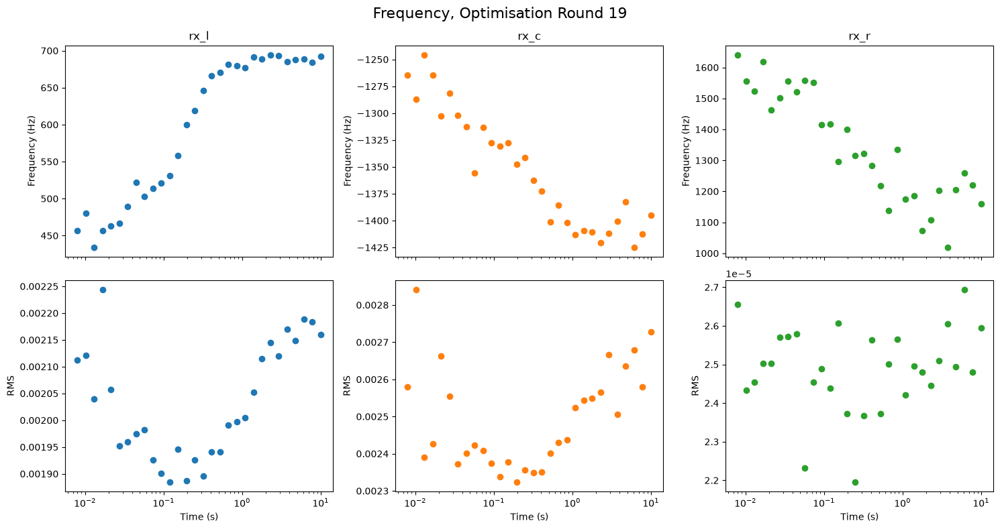

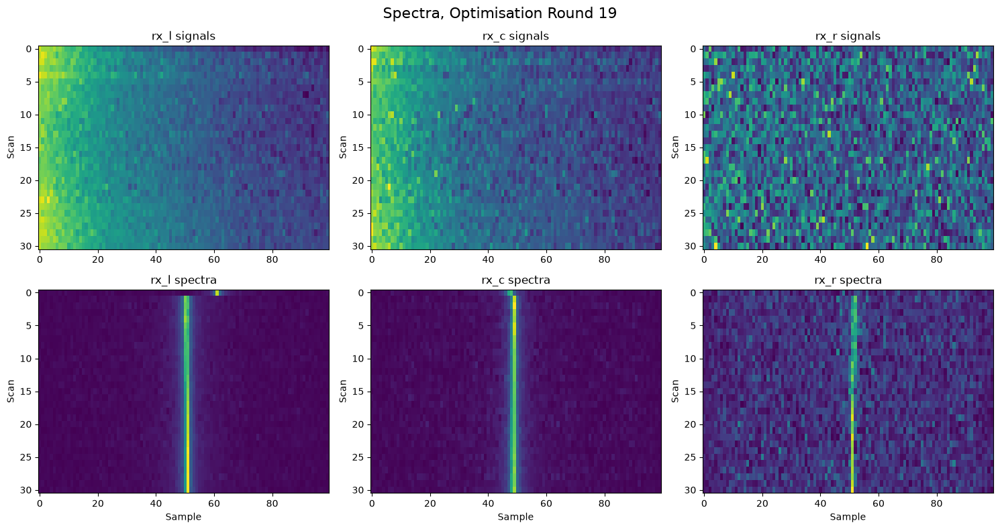

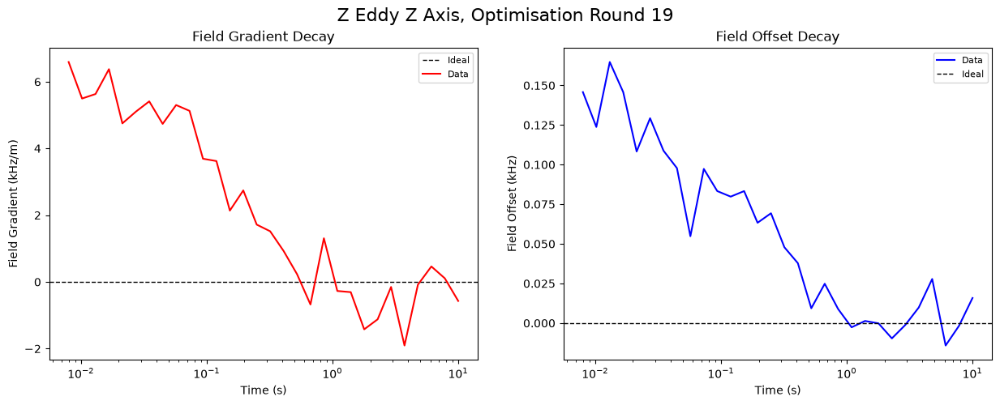

[I 2026-11-24 16:43:29,536] Trial 19 finished with value: 6505.780506040941 and parameters: {'Z_A1': 0.08434918454512953, 'Z_A2': 0.05924173455145242, 'Z_A3': 0.11339708077396529, 'Z_A4': -5.547835843894111e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 11839.080459770112
mean |E| = 7464.934199566881
RMS E = 7916.046711491322
Total cost = 6.506e+03
E max = 0.11999094343833433
E nanmax = 0.11999094343833433
E contains nan = False
B max = 0.012998918129999157
B nanmax = 0.012998918129999157
B contains nan = False
Trial 20


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012998918129999157 !!!!!!!!!!!!!!!!


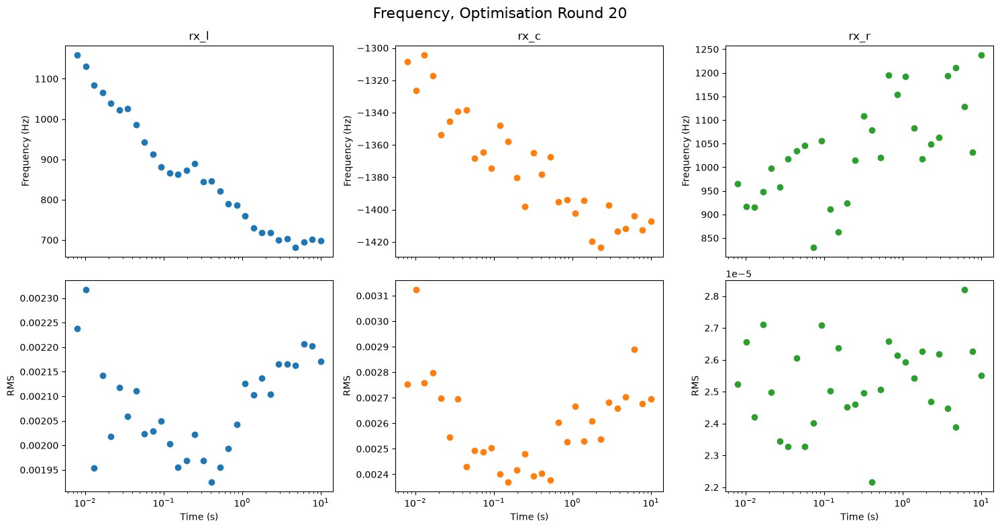

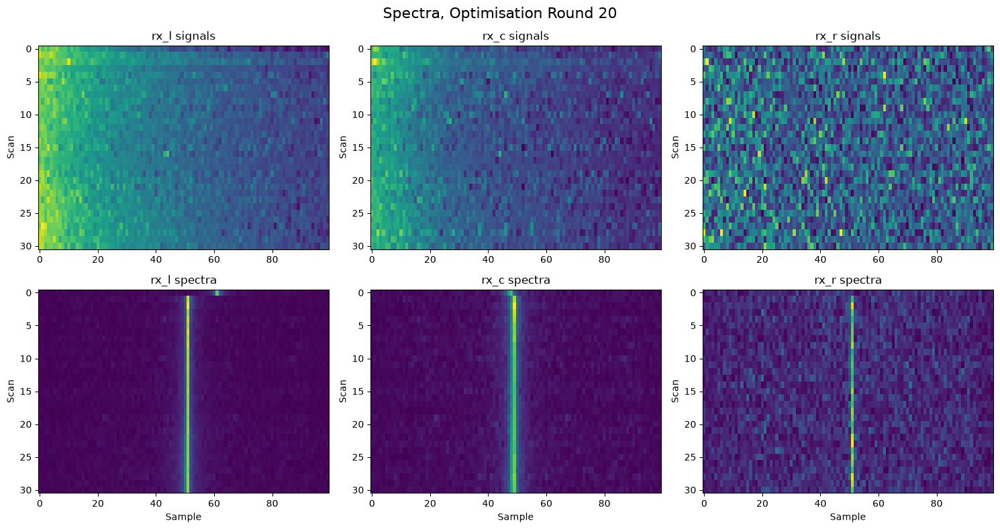

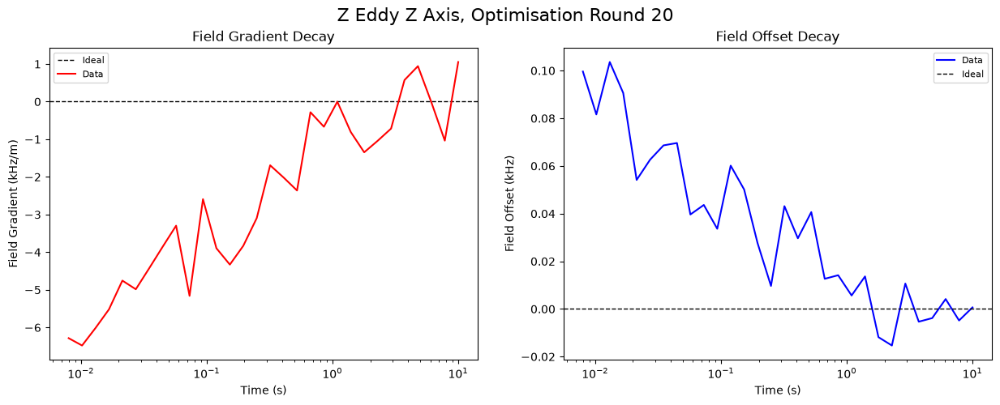

[I 2026-11-24 16:44:17,776] Trial 20 finished with value: 8727.384621234343 and parameters: {'Z_A1': 0.058425995140023376, 'Z_A2': 0.033808078536174804, 'Z_A3': 0.08685384522166276, 'Z_A4': 3.743736001569266e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5392.30384807596
mean |E| = 2335.665500583041
RMS E = 2837.1249314174943
Total cost = 8.727e+03
E max = 0.12407053448852721
E nanmax = 0.12407053448852721
E contains nan = False
B max = 0.01344091678710296
B nanmax = 0.01344091678710296
B contains nan = False
Trial 21


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01344091678710296 !!!!!!!!!!!!!!!!


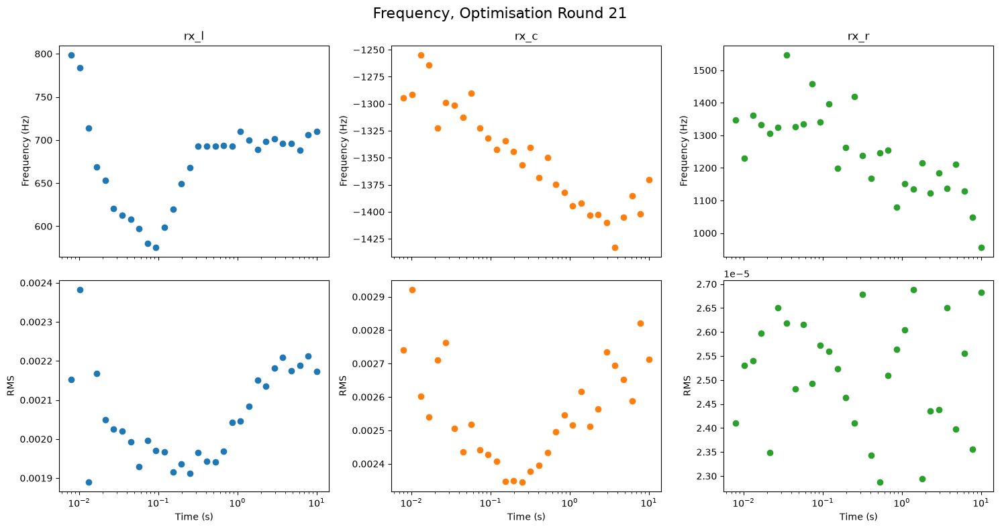

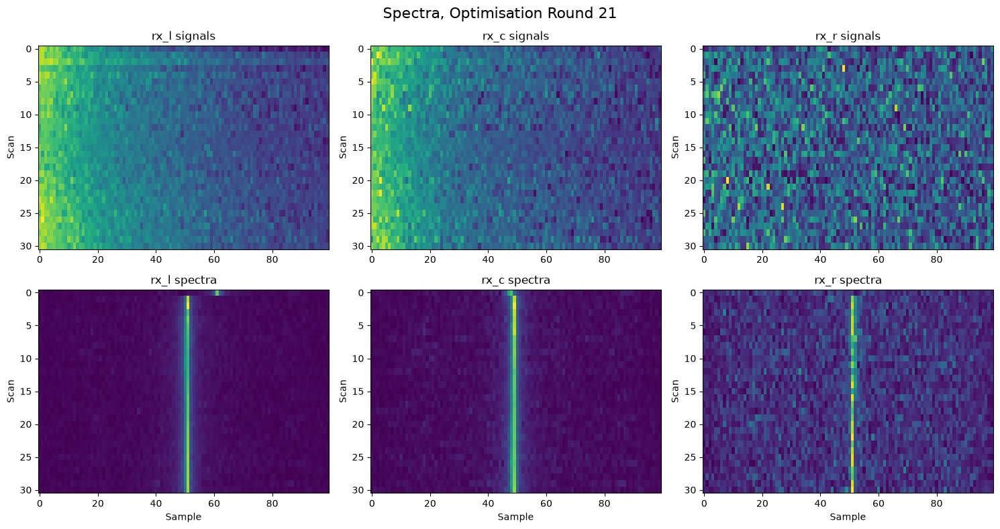

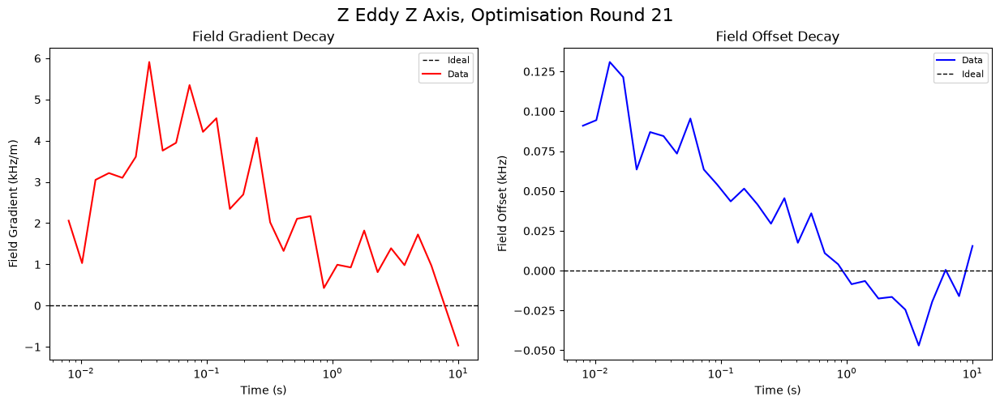

[I 2026-11-24 16:45:06,065] Trial 21 finished with value: 10410.45702738501 and parameters: {'Z_A1': 0.07977340556729776, 'Z_A2': 0.05578239201964179, 'Z_A3': 0.07507076805163425, 'Z_A4': 4.38822410605859e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 9340.329835082457
mean |E| = 5751.790771281025
RMS E = 5967.604527206115
Total cost = 1.041e+04
E max = 0.12440180108242793
E nanmax = 0.12440180108242793
E contains nan = False
B max = 0.013476795756147257
B nanmax = 0.013476795756147257
B contains nan = False
Trial 22


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013476795756147257 !!!!!!!!!!!!!!!!


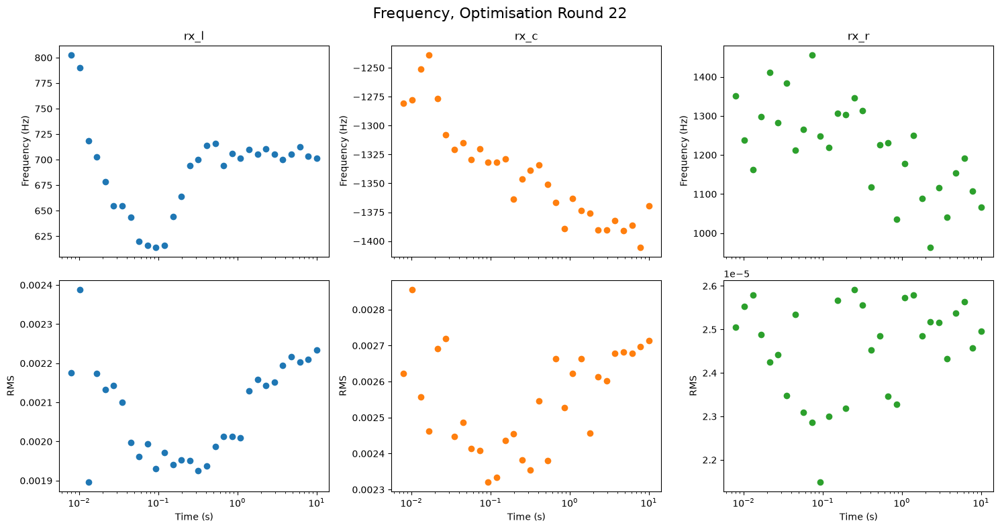

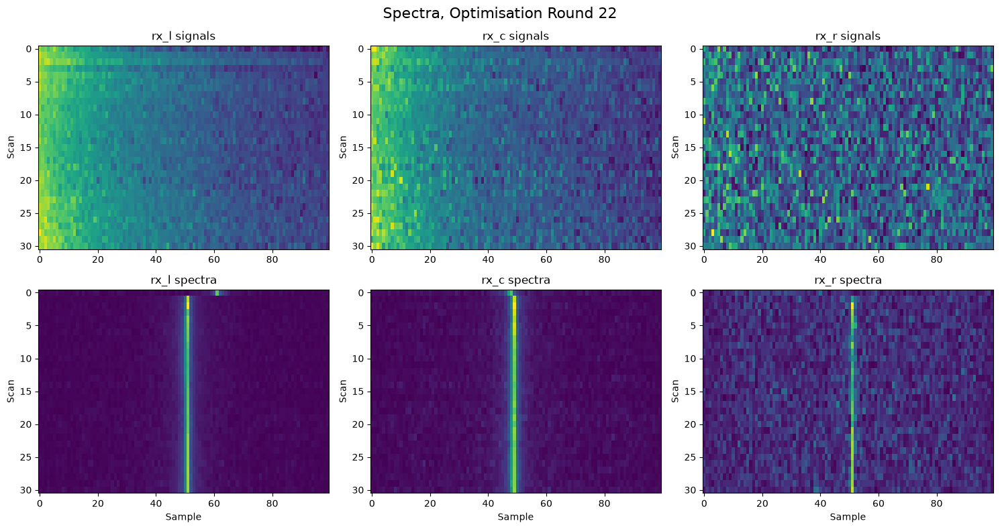

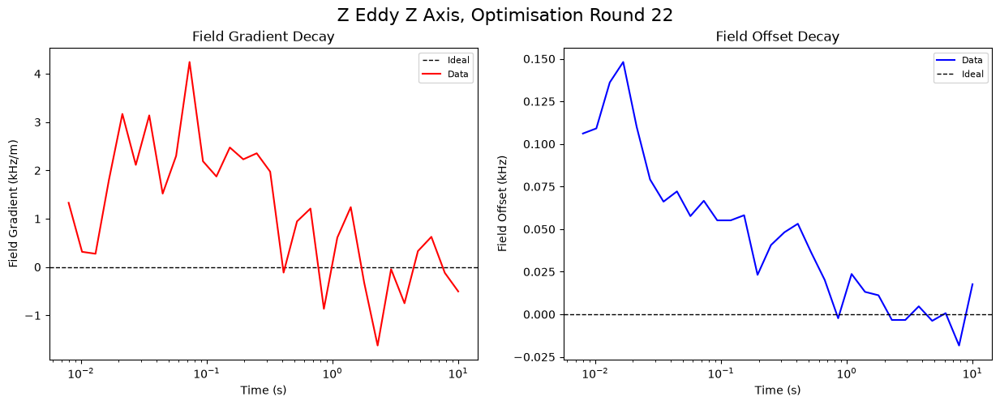

[I 2026-11-24 16:45:54,205] Trial 22 finished with value: 5842.314524882507 and parameters: {'Z_A1': 0.07780215790582938, 'Z_A2': 0.05440075286389197, 'Z_A3': 0.08104721163279947, 'Z_A4': -2.6414797723736153e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 8400.799600199898
mean |E| = 5288.189238713973
RMS E = 5458.018268787677
Total cost = 5.842e+03
E max = 0.12326874365145936
E nanmax = 0.12326874365145936
E contains nan = False
B max = 0.013354042174363402
B nanmax = 0.013354042174363402
B contains nan = False
Trial 23


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013354042174363402 !!!!!!!!!!!!!!!!


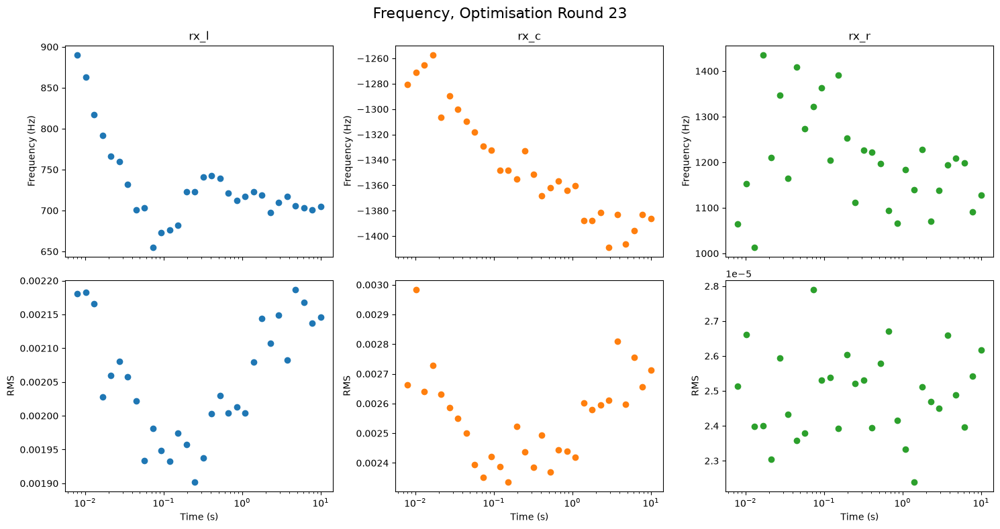

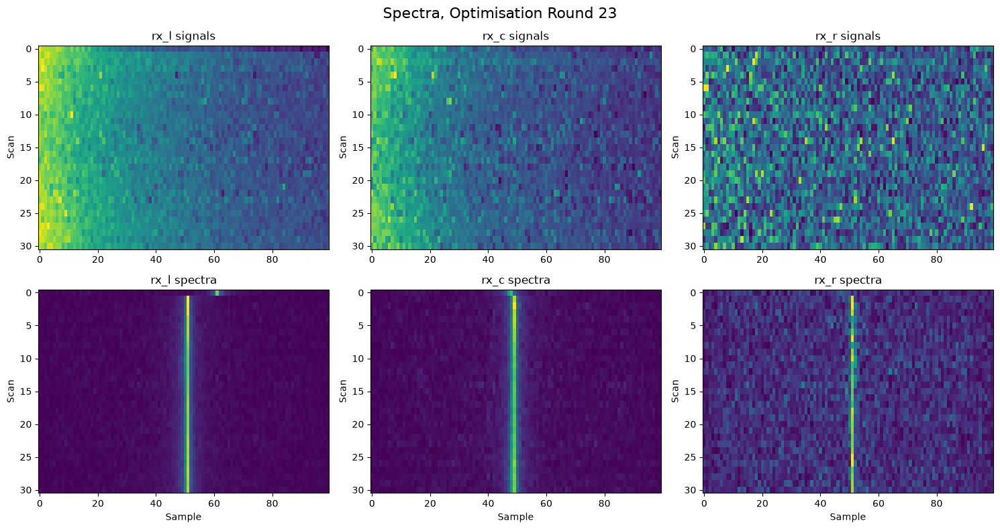

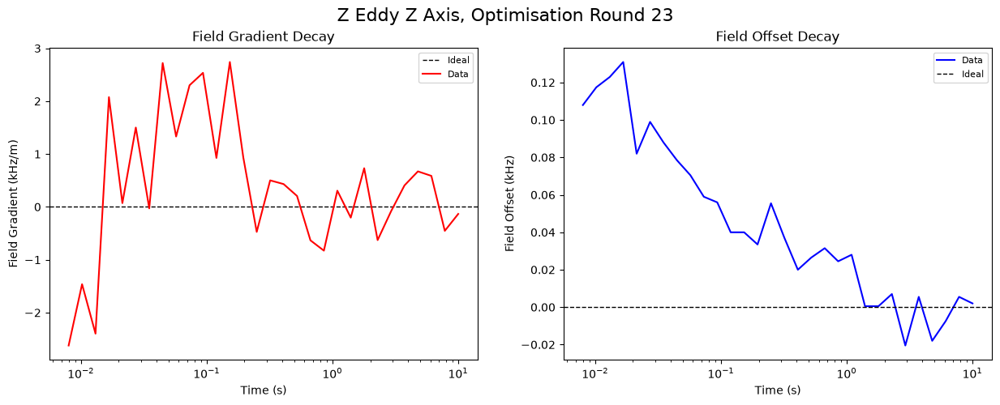

[I 2026-11-24 16:46:42,306] Trial 23 finished with value: 4768.6395169524785 and parameters: {'Z_A1': 0.07321605980043465, 'Z_A2': 0.05127143299558969, 'Z_A3': 0.08018607183342162, 'Z_A4': -1.9994617285369575e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 7101.449275362317
mean |E| = 4728.968848908877
RMS E = 4906.945166761359
Total cost = 4.769e+03
E max = 0.12109782003870175
E nanmax = 0.12109782003870175
E contains nan = False
B max = 0.013118855209545791
B nanmax = 0.013118855209545791
B contains nan = False
Trial 24


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013118855209545791 !!!!!!!!!!!!!!!!


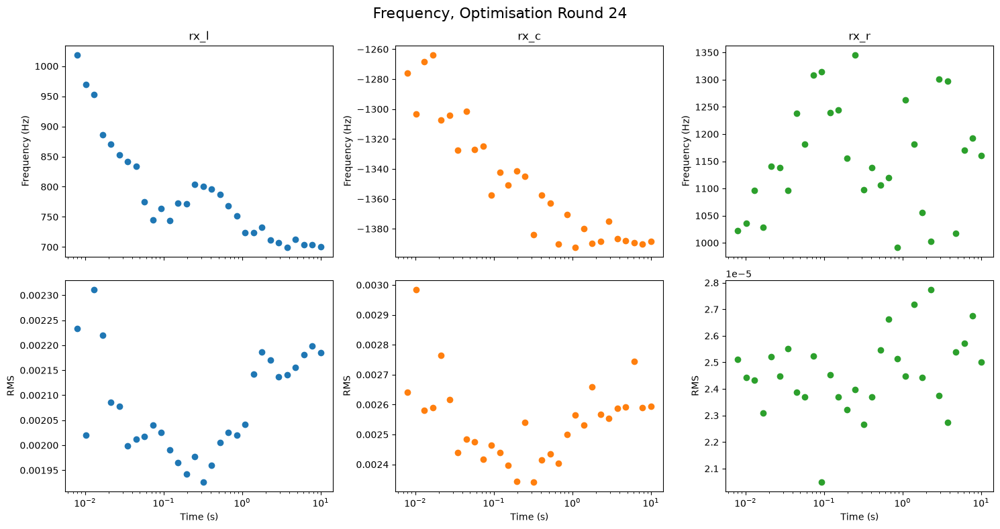

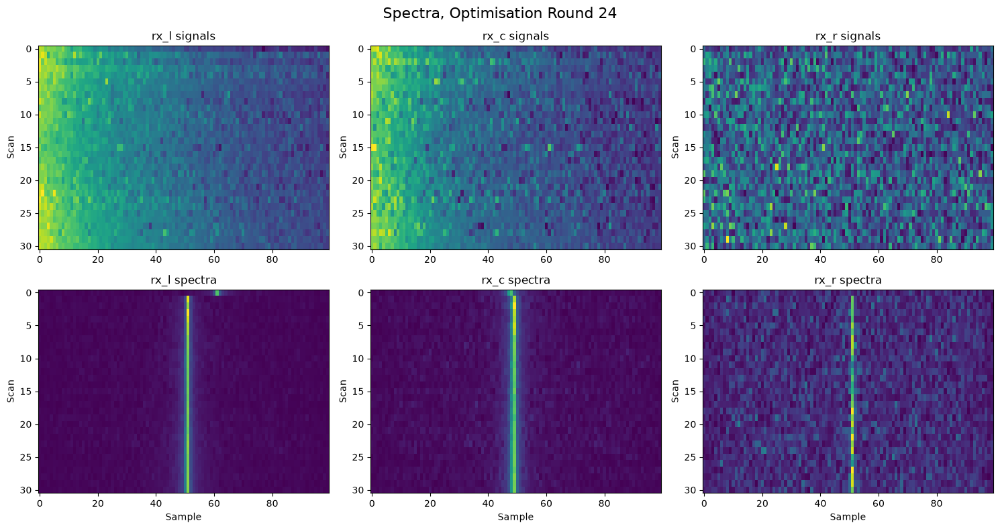

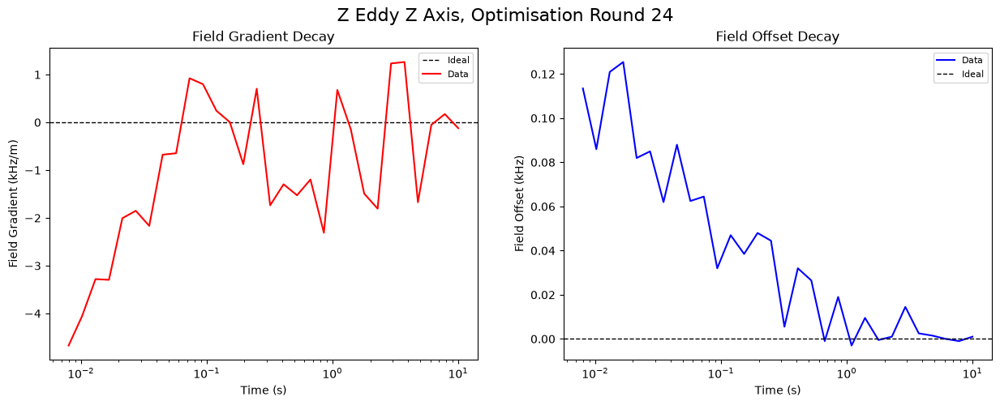

[I 2026-11-24 16:47:30,136] Trial 24 finished with value: 7906.5757491938975 and parameters: {'Z_A1': 0.06595084918105819, 'Z_A2': 0.04879082664645016, 'Z_A3': 0.07314340097782614, 'Z_A4': -3.874681214158556e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5977.011494252873
mean |E| = 3685.9903381642503
RMS E = 3988.5669761177446
Total cost = 7.907e+03
E max = 0.12244414244731075
E nanmax = 0.12244414244731075
E contains nan = False
B max = 0.013264696301989507
B nanmax = 0.013264696301989507
B contains nan = False
Trial 25


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013264696301989507 !!!!!!!!!!!!!!!!


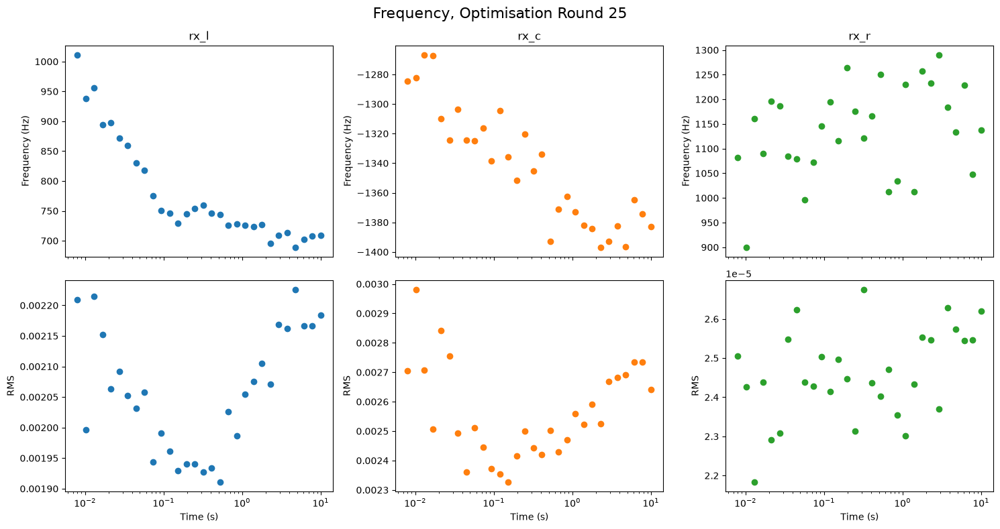

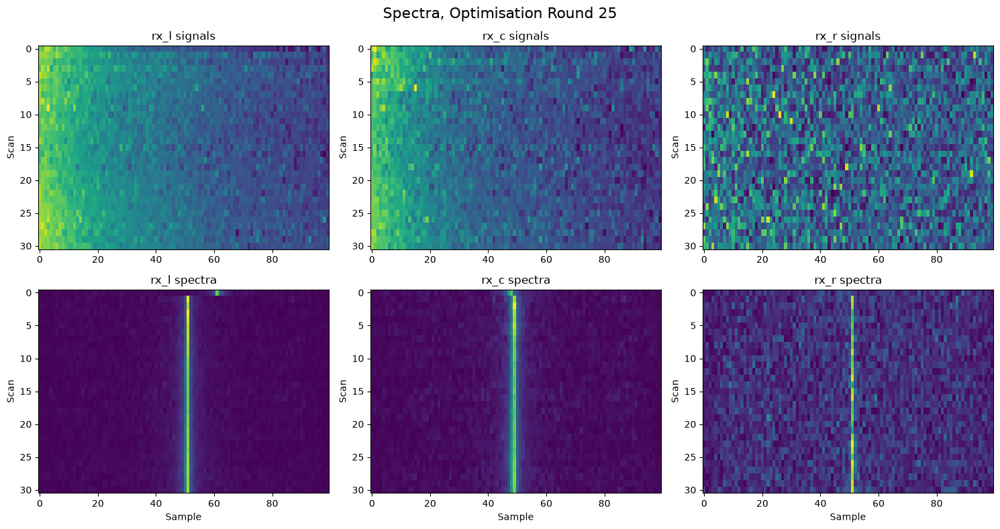

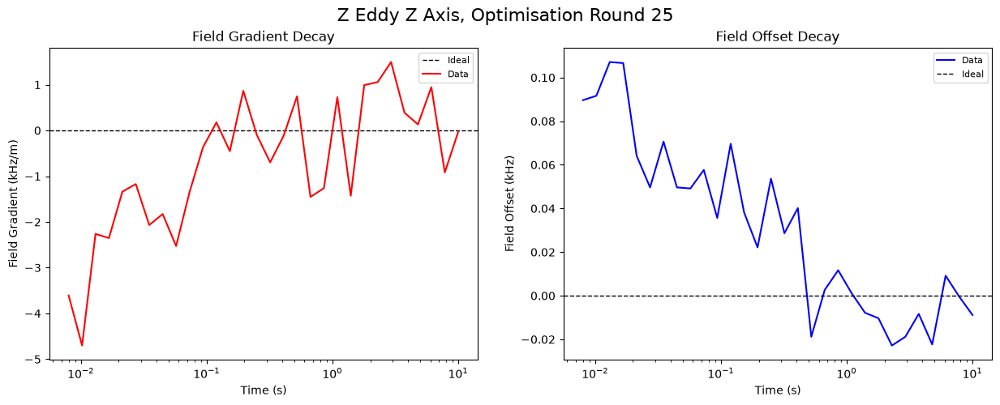

[I 2026-11-24 16:48:18,121] Trial 25 finished with value: 7485.865513190931 and parameters: {'Z_A1': 0.07372412640015266, 'Z_A2': 0.03282332748705678, 'Z_A3': 0.09146097221891598, 'Z_A4': -1.7575461410717355e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5812.093953023486
mean |E| = 3591.870731301016
RMS E = 3847.5134315841624
Total cost = 7.486e+03
E max = 0.12578081731364454
E nanmax = 0.12578081731364454
E contains nan = False
B max = 0.013626162790315432
B nanmax = 0.013626162790315432
B contains nan = False
Trial 26


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013626162790315432 !!!!!!!!!!!!!!!!


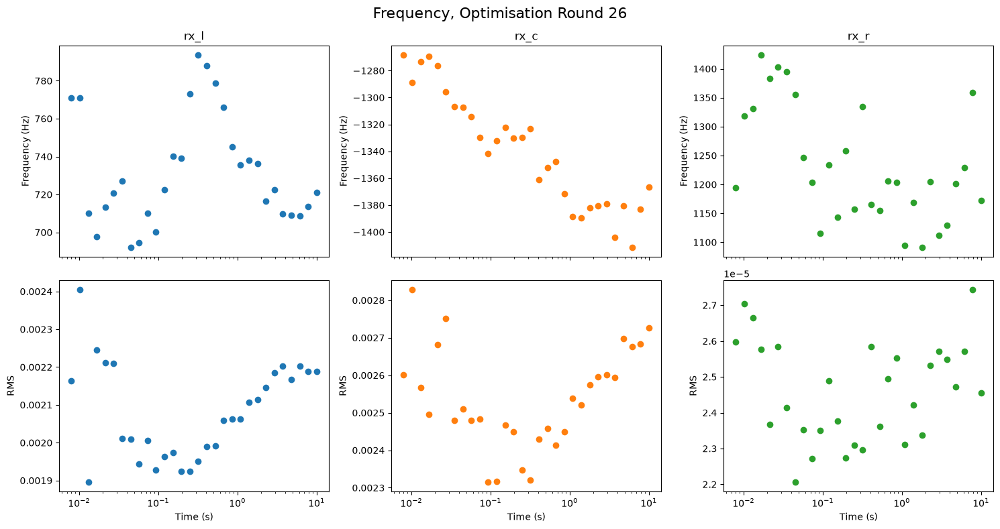

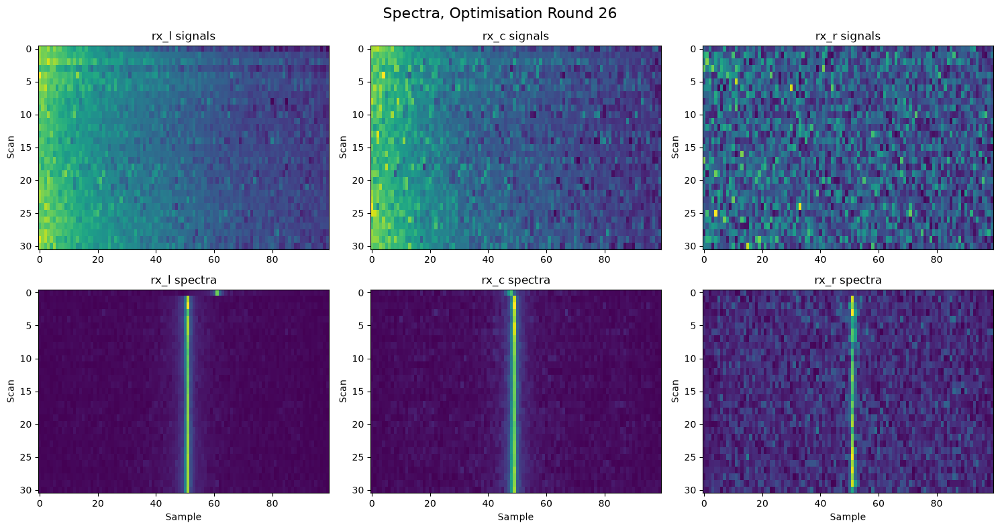

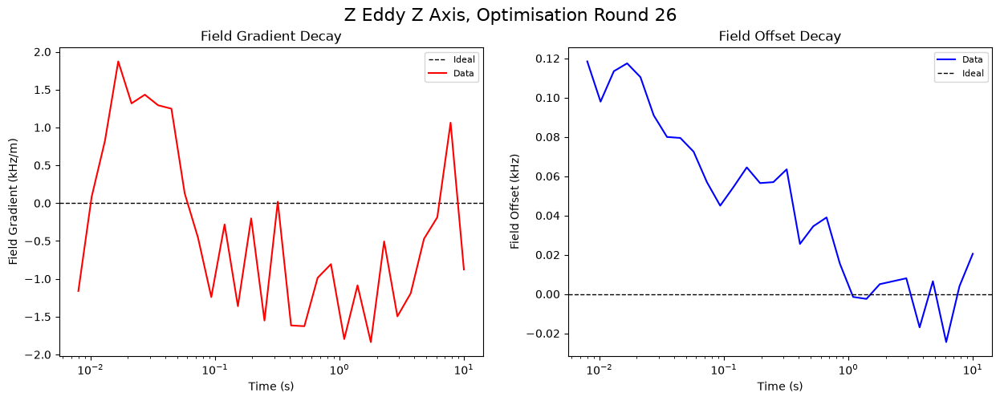

[I 2026-11-24 16:49:06,217] Trial 26 finished with value: 8994.766043444915 and parameters: {'Z_A1': 0.06707819207075064, 'Z_A2': 0.06076357872399338, 'Z_A3': 0.0960219375981361, 'Z_A4': -1.8500520132172014e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 7261.369315342327
mean |E| = 5007.163085124104
RMS E = 5122.477135272438
Total cost = 8.995e+03
E max = 0.12376144978275662
E nanmax = 0.12376144978275662
E contains nan = False
B max = 0.013407418034806948
B nanmax = 0.013407418034806948
B contains nan = False
Trial 27


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013407418034806948 !!!!!!!!!!!!!!!!


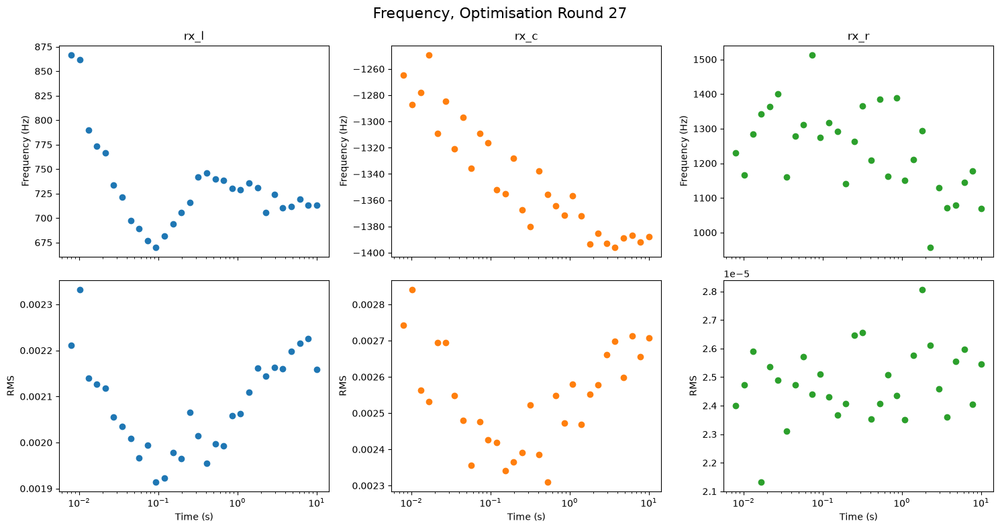

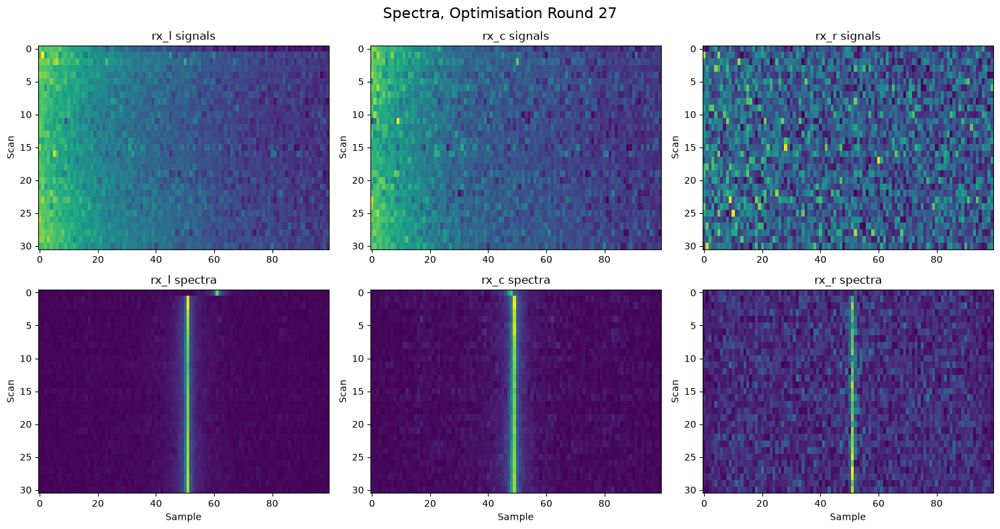

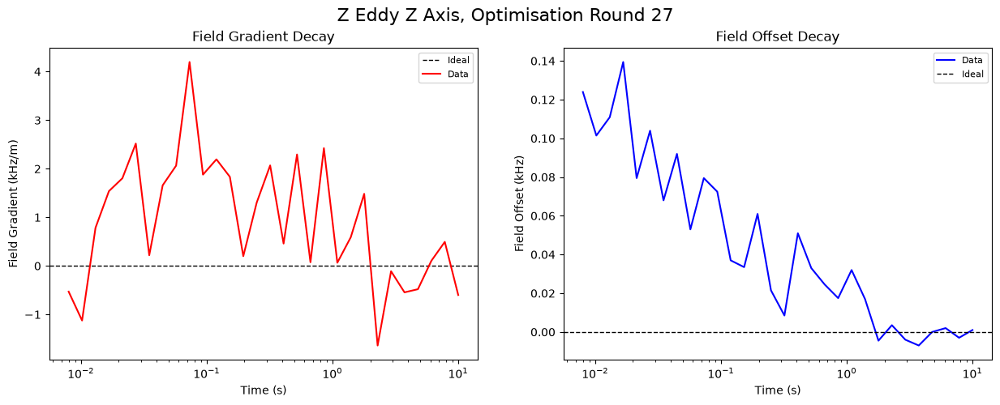

[I 2026-11-24 16:49:54,379] Trial 27 finished with value: 6213.34287221788 and parameters: {'Z_A1': 0.0742123350938378, 'Z_A2': 0.05184277429192838, 'Z_A3': 0.0823884626779876, 'Z_A4': -6.200472757098677e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 8355.82208895552
mean |E| = 5065.633849741795
RMS E = 5226.193570769522
Total cost = 6.213e+03
E max = 0.12120476889051282
E nanmax = 0.12120476889051282
E contains nan = False
B max = 0.013130443055598129
B nanmax = 0.013130443055598129
B contains nan = False
Trial 28


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013130443055598129 !!!!!!!!!!!!!!!!


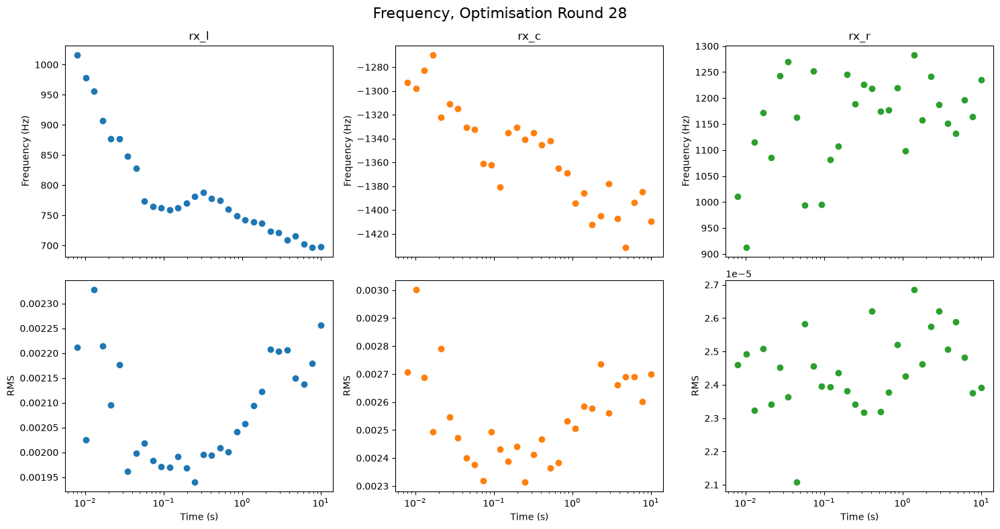

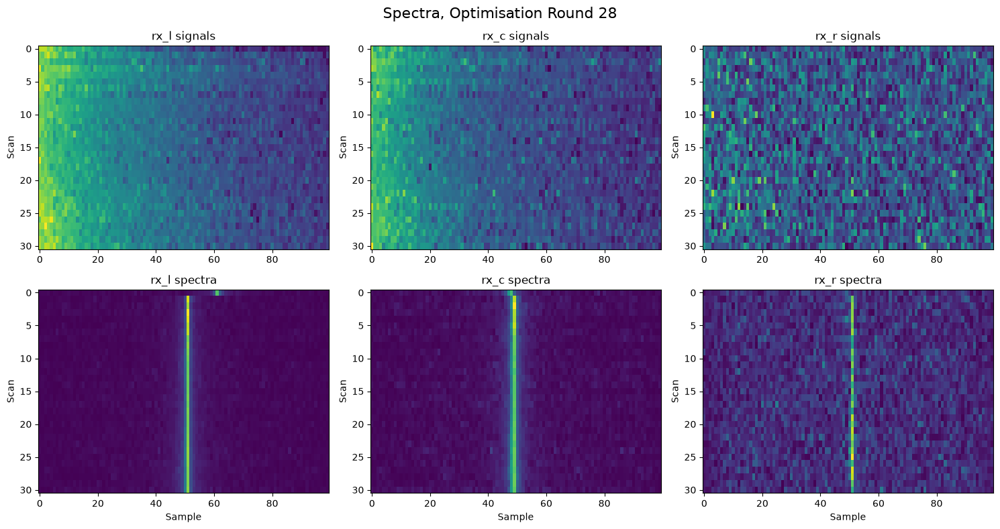

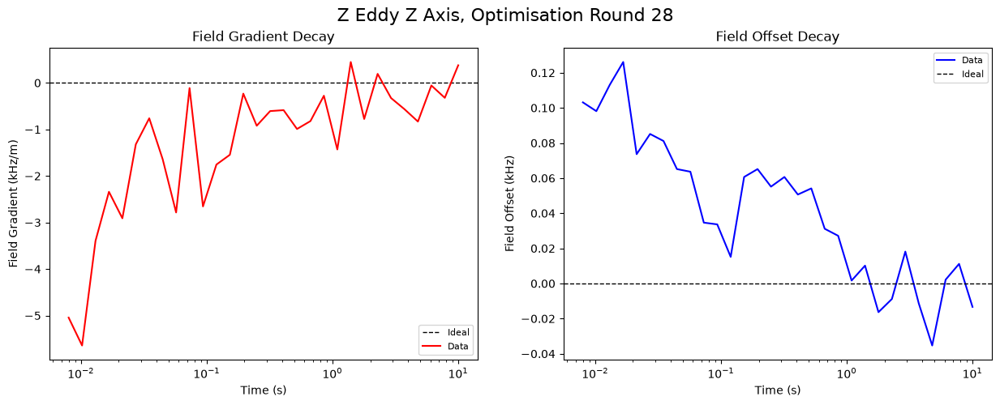

[I 2026-11-24 16:50:42,716] Trial 28 finished with value: 4676.594181774544 and parameters: {'Z_A1': 0.06863982594599677, 'Z_A2': 0.04574328989169616, 'Z_A3': 0.07427993973272454, 'Z_A4': 2.2279084223666237e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5437.281359320338
mean |E| = 3715.309012160585
RMS E = 3945.2296644199346
Total cost = 4.677e+03
E max = 0.12162904931861167
E nanmax = 0.12162904931861167
E contains nan = False
B max = 0.01317637402991861
B nanmax = 0.01317637402991861
B contains nan = False
Trial 29


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01317637402991861 !!!!!!!!!!!!!!!!


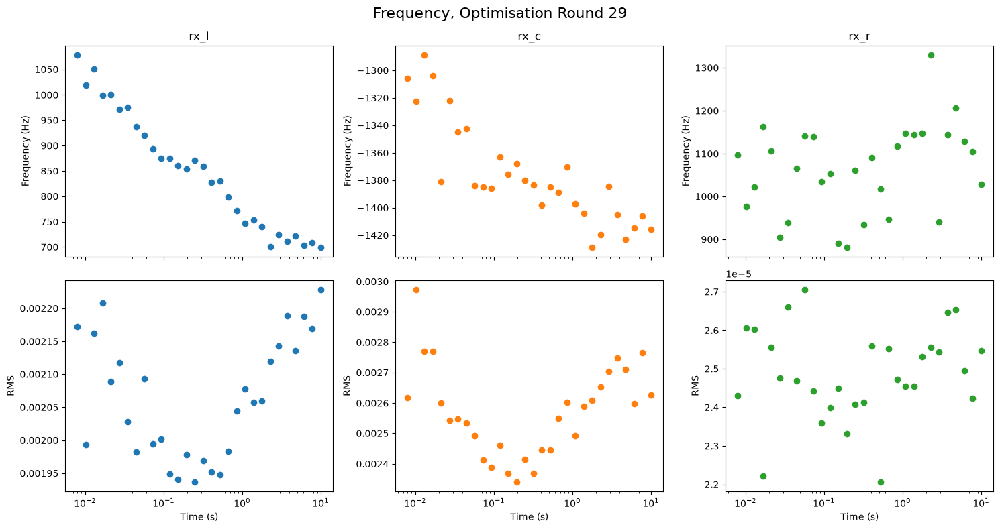

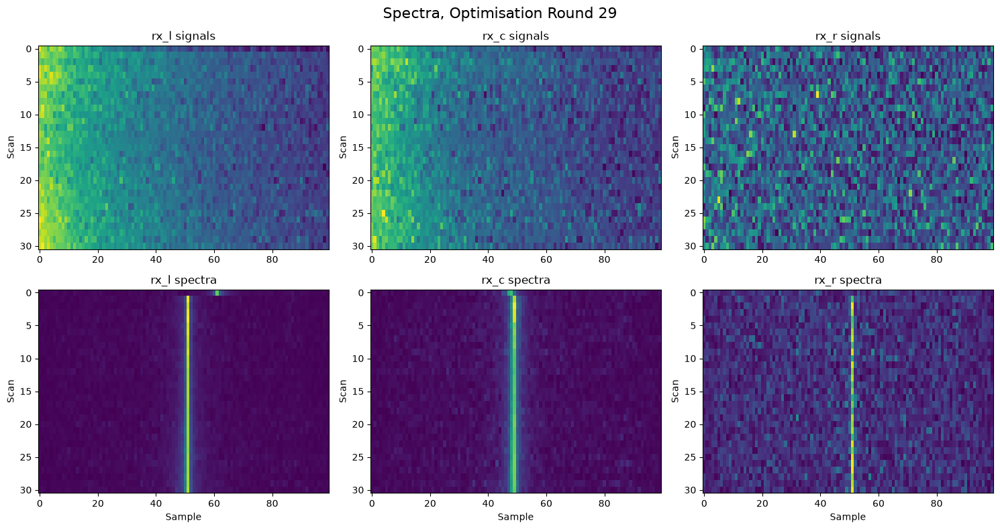

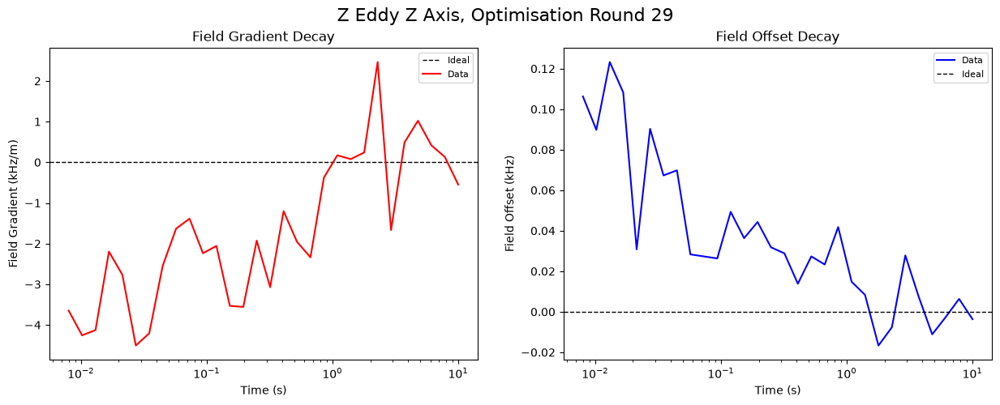

[I 2026-11-24 16:51:31,231] Trial 29 finished with value: 7767.35798610071 and parameters: {'Z_A1': 0.05853049129506434, 'Z_A2': 0.03920012951408565, 'Z_A3': 0.09427734085067489, 'Z_A4': 2.137860126746675e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 6296.851574212892
mean |E| = 2258.2042312177236
RMS E = 2773.2944155452055
Total cost = 7.767e+03
E max = 0.12241955119148536
E nanmax = 0.12241955119148536
E contains nan = False
B max = 0.013262028003291838
B nanmax = 0.013262028003291838
B contains nan = False
Trial 30


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013262028003291838 !!!!!!!!!!!!!!!!


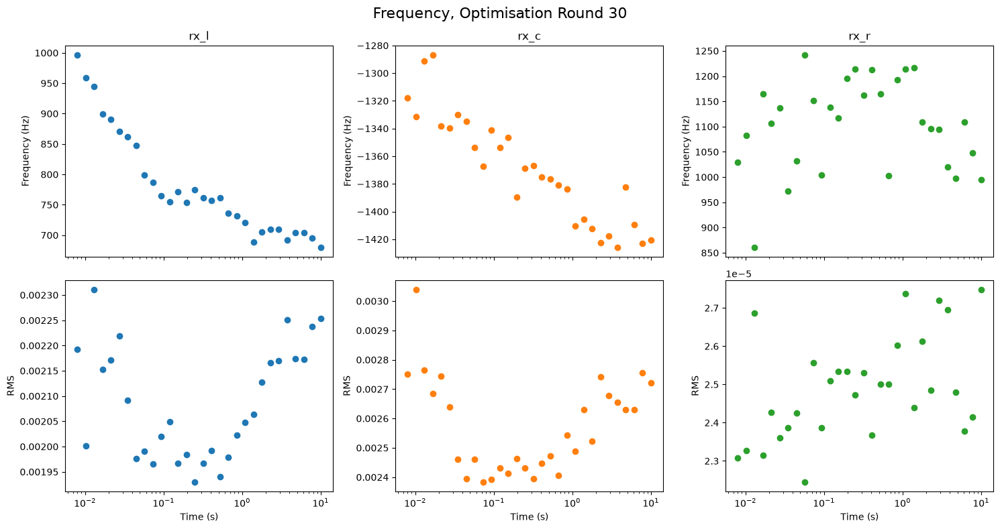

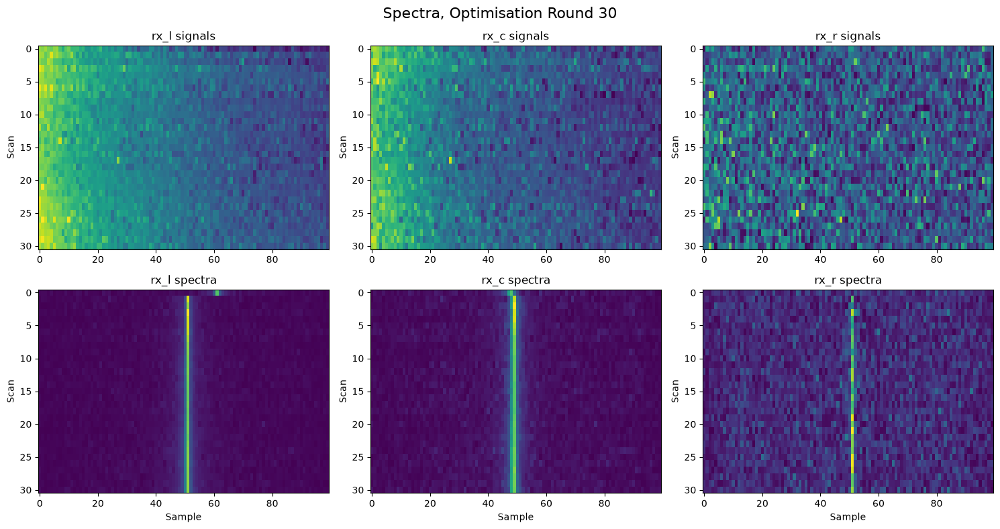

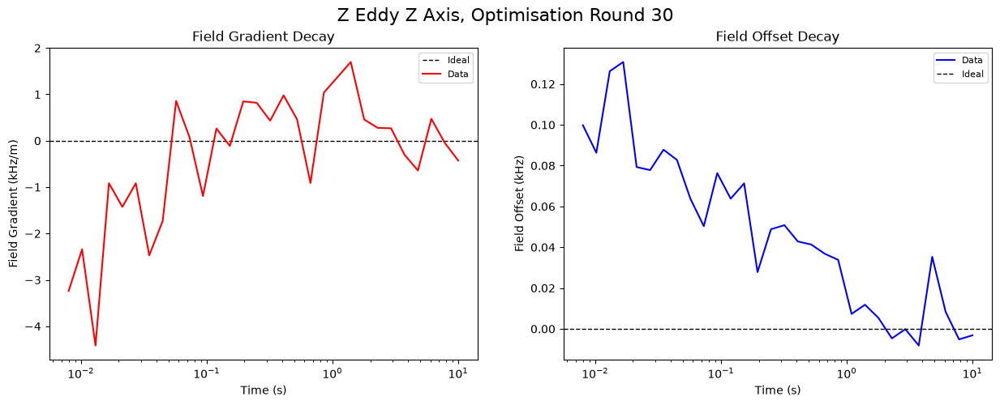

[I 2026-11-24 16:52:19,815] Trial 30 finished with value: 4626.583211951338 and parameters: {'Z_A1': 0.07074374579781736, 'Z_A2': 0.034718350818251, 'Z_A3': 0.09245586947366798, 'Z_A4': 5.80470265348628e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5272.363818090954
mean |E| = 3271.864067966016
RMS E = 3500.397118920678
Total cost = 4.627e+03
E max = 0.12070714587254479
E nanmax = 0.12070714587254479
E contains nan = False
B max = 0.013076543024868947
B nanmax = 0.013076543024868947
B contains nan = False
Trial 31


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013076543024868947 !!!!!!!!!!!!!!!!


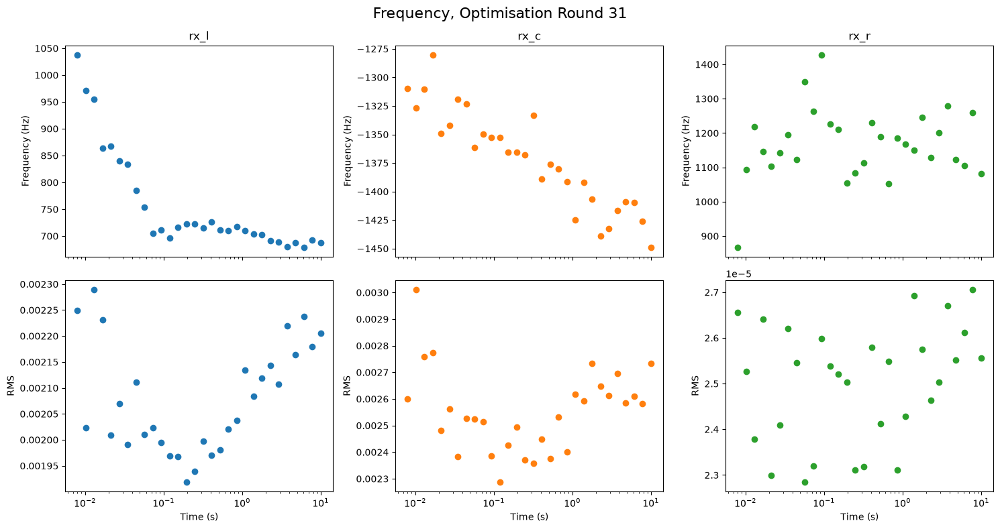

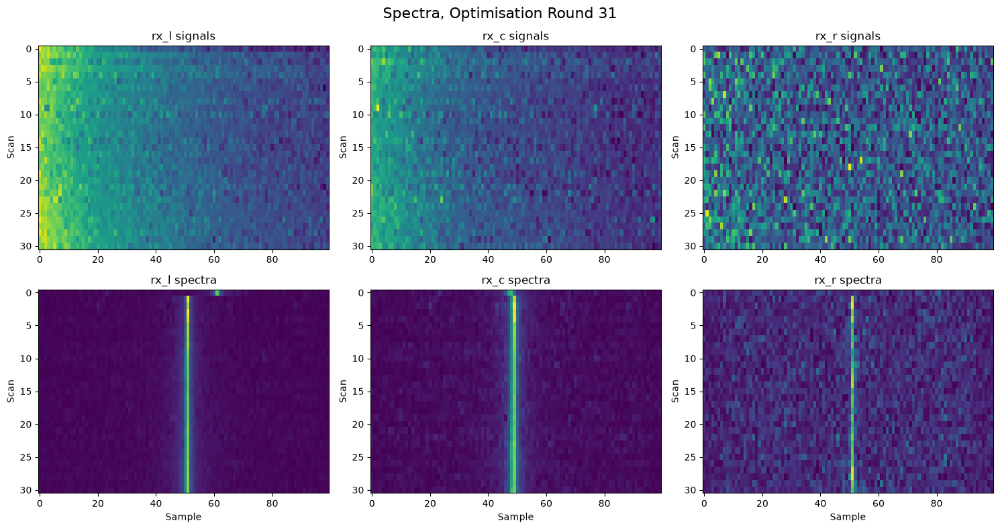

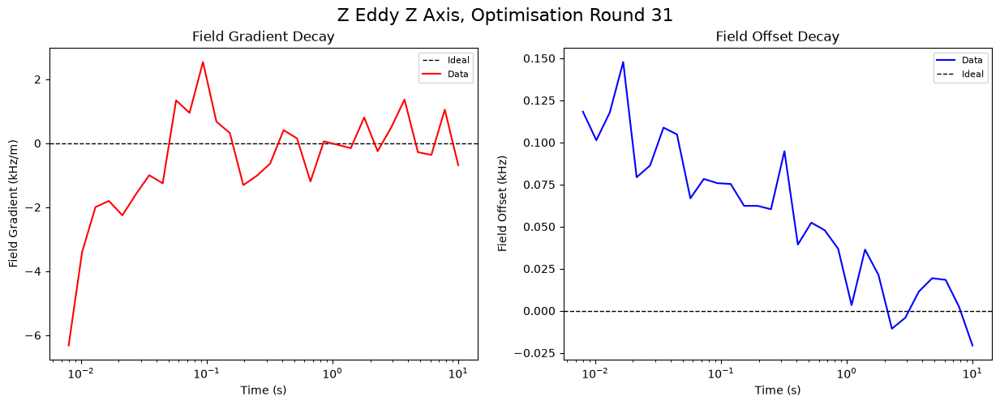

[I 2026-11-24 16:53:08,249] Trial 31 finished with value: 6508.220841658639 and parameters: {'Z_A1': 0.07509686832498597, 'Z_A2': 0.03826982874052229, 'Z_A3': 0.07110924239797439, 'Z_A4': 3.873764156624743e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 7161.419290354821
mean |E| = 4221.889055472263
RMS E = 4421.803301159653
Total cost = 6.508e+03
E max = 0.11955909970150162
E nanmax = 0.11955909970150162
E contains nan = False
B max = 0.012952152852112292
B nanmax = 0.012952152852112292
B contains nan = False
Trial 32


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012952152852112292 !!!!!!!!!!!!!!!!


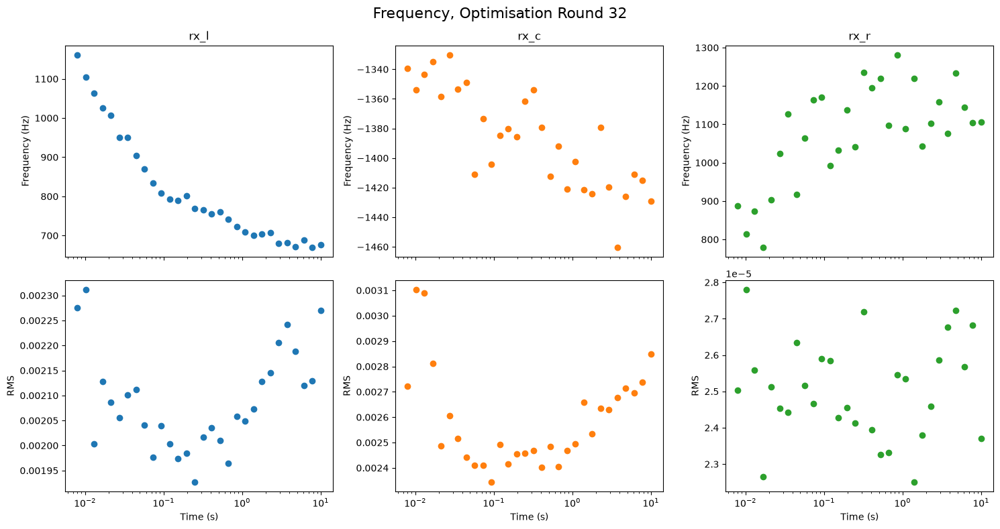

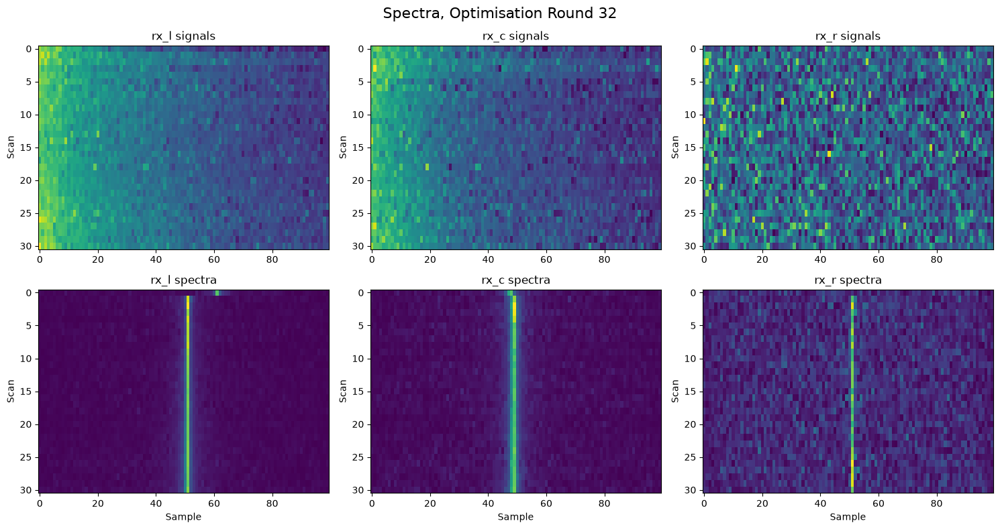

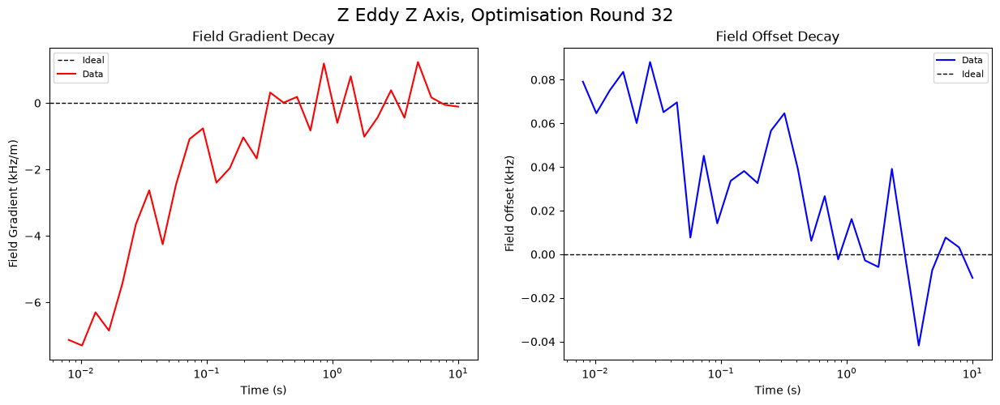

[I 2026-11-24 16:53:56,558] Trial 32 finished with value: 4787.623608038179 and parameters: {'Z_A1': 0.06784328278243903, 'Z_A2': 0.028461752791182557, 'Z_A3': 0.07910473616698008, 'Z_A4': 6.081722804736172e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5627.1864067966
mean |E| = 3326.170248209228
RMS E = 3604.4639580481803
Total cost = 4.788e+03
E max = 0.1211688340832739
E nanmax = 0.1211688340832739
E contains nan = False
B max = 0.013126554500552065
B nanmax = 0.013126554500552065
B contains nan = False
Trial 33


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013126554500552065 !!!!!!!!!!!!!!!!


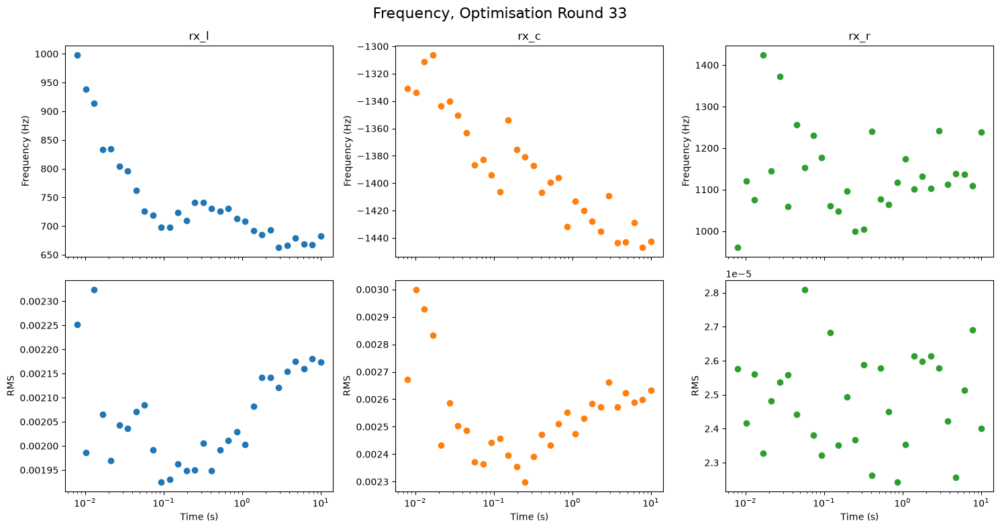

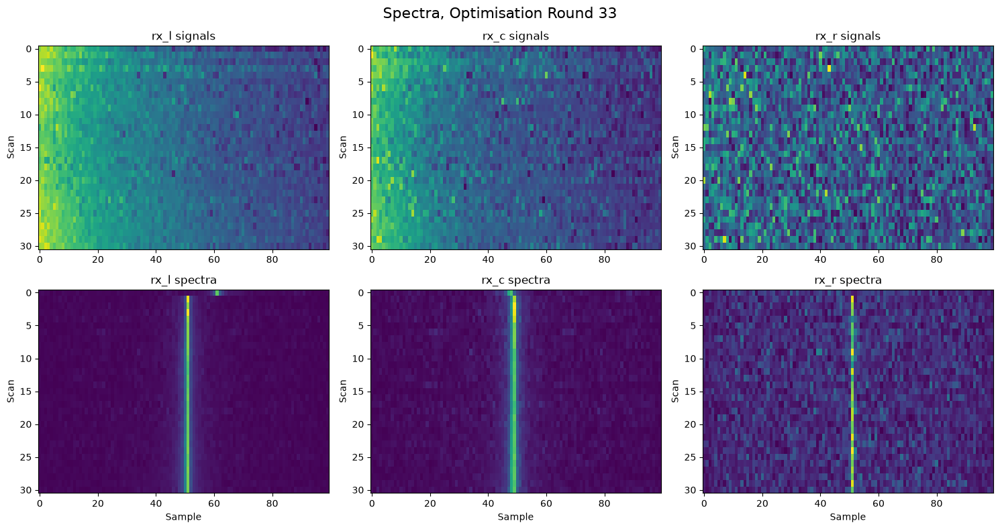

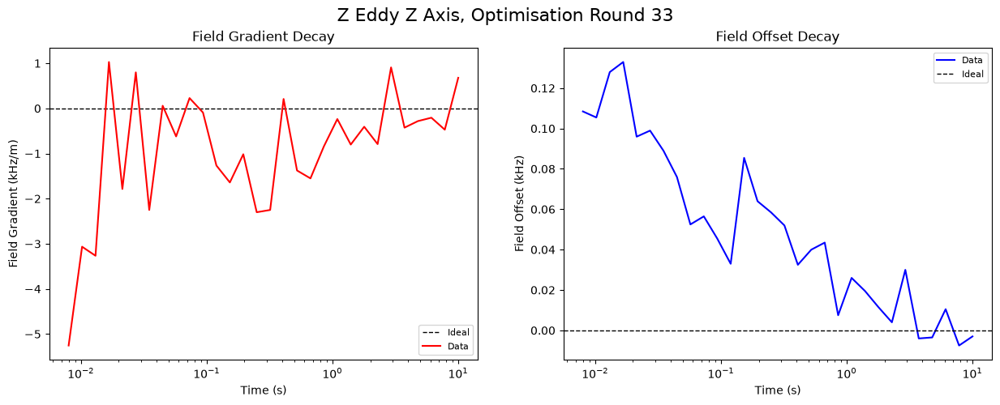

[I 2026-11-24 16:54:44,598] Trial 33 finished with value: 5517.031168757507 and parameters: {'Z_A1': 0.07078611920539502, 'Z_A2': 0.04526555342841438, 'Z_A3': 0.0722611405968094, 'Z_A4': 4.104131387721758e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5912.043978010993
mean |E| = 3965.850408129268
RMS E = 4168.945276316727
Total cost = 5.517e+03
E max = 0.11979468125020147
E nanmax = 0.11979468125020147
E contains nan = False
B max = 0.01297767977719547
B nanmax = 0.01297767977719547
B contains nan = False
Trial 34


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01297767977719547 !!!!!!!!!!!!!!!!


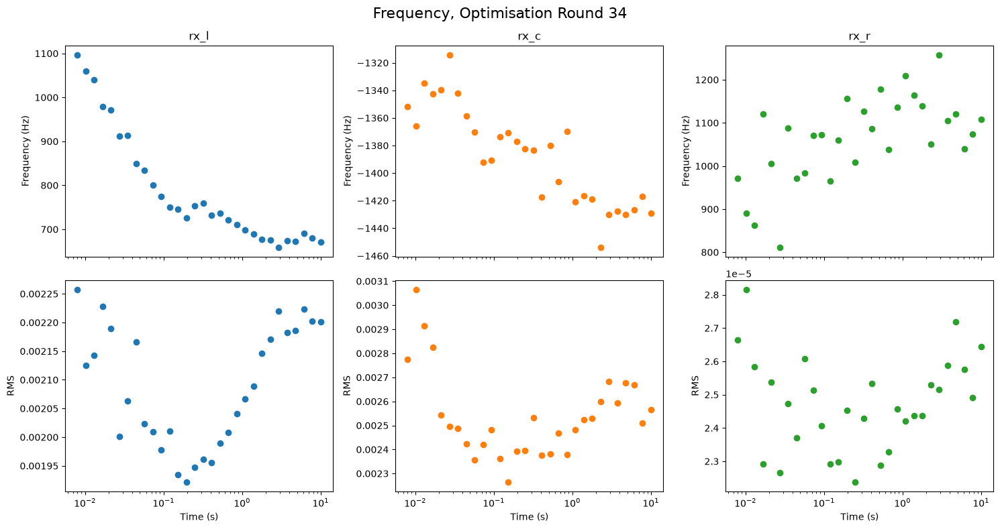

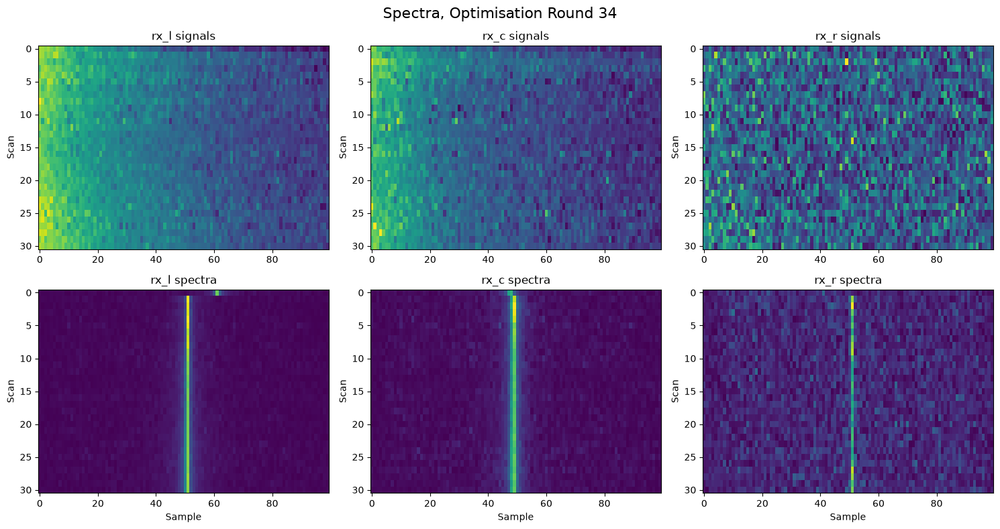

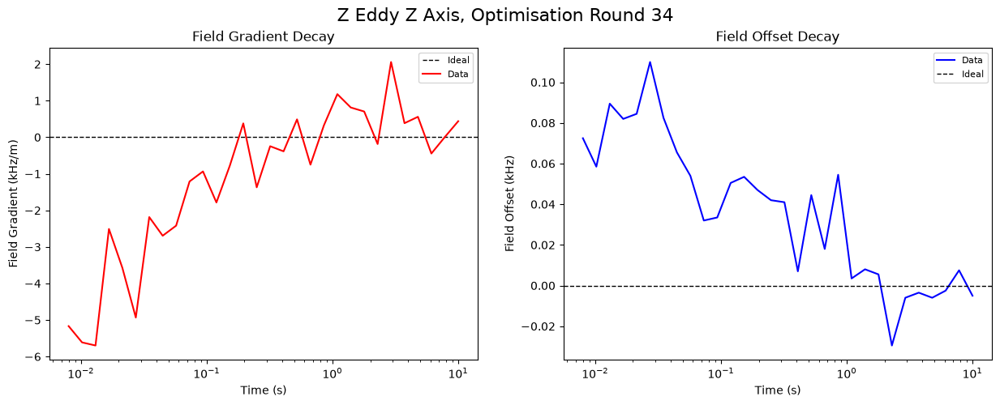

[I 2026-11-24 16:55:32,585] Trial 34 finished with value: 5433.957564149999 and parameters: {'Z_A1': 0.06986884082071869, 'Z_A2': 0.03105952833629438, 'Z_A3': 0.07636351288458862, 'Z_A4': 2.3990398146438786e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5982.008995502248
mean |E| = 3119.9400299850063
RMS E = 3424.4815900713184
Total cost = 5.434e+03
E max = 0.12175378056493502
E nanmax = 0.12175378056493502
E contains nan = False
B max = 0.013189898724240926
B nanmax = 0.013189898724240926
B contains nan = False
Trial 35


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013189898724240926 !!!!!!!!!!!!!!!!


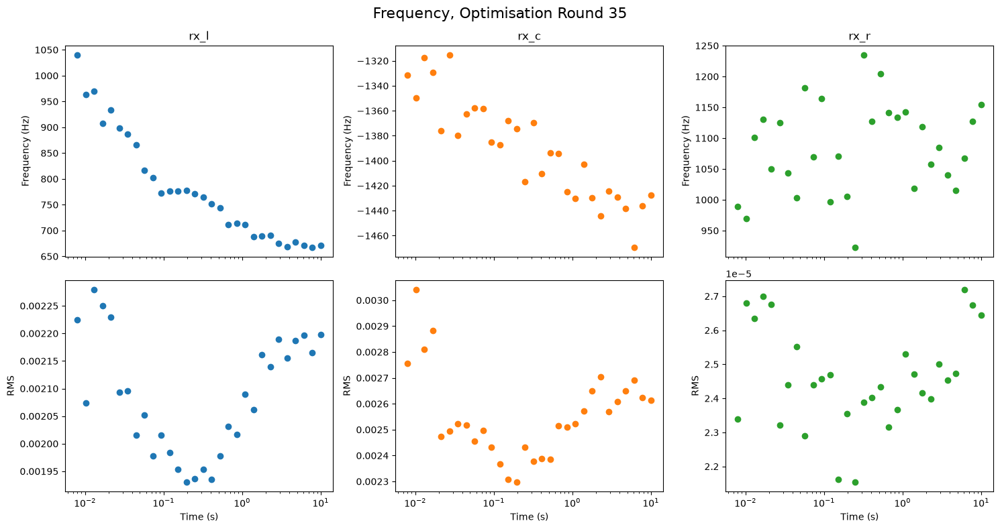

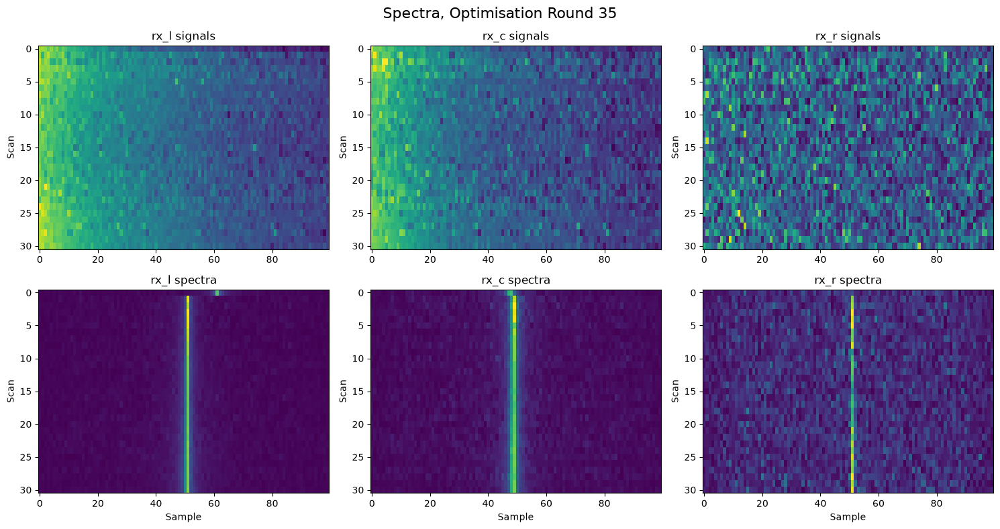

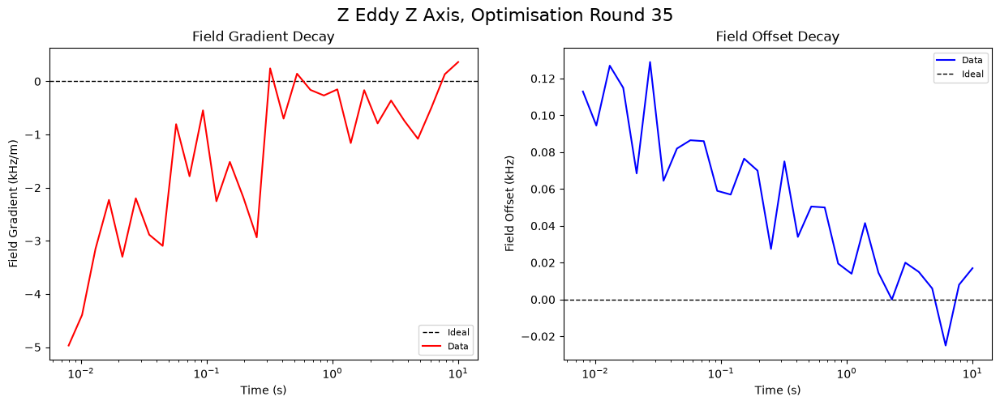

[I 2026-11-24 16:56:20,690] Trial 35 finished with value: 5406.885441646909 and parameters: {'Z_A1': 0.06643641330270944, 'Z_A2': 0.03521096850615717, 'Z_A3': 0.09119516563528292, 'Z_A4': 5.923829666304079e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 4822.588705647174
mean |E| = 3044.9775112443767
RMS E = 3323.7630286788417
Total cost = 5.407e+03
E max = 0.12108321469898917
E nanmax = 0.12108321469898917
E contains nan = False
B max = 0.013117274805767912
B nanmax = 0.013117274805767912
B contains nan = False
Trial 36


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013117274805767912 !!!!!!!!!!!!!!!!


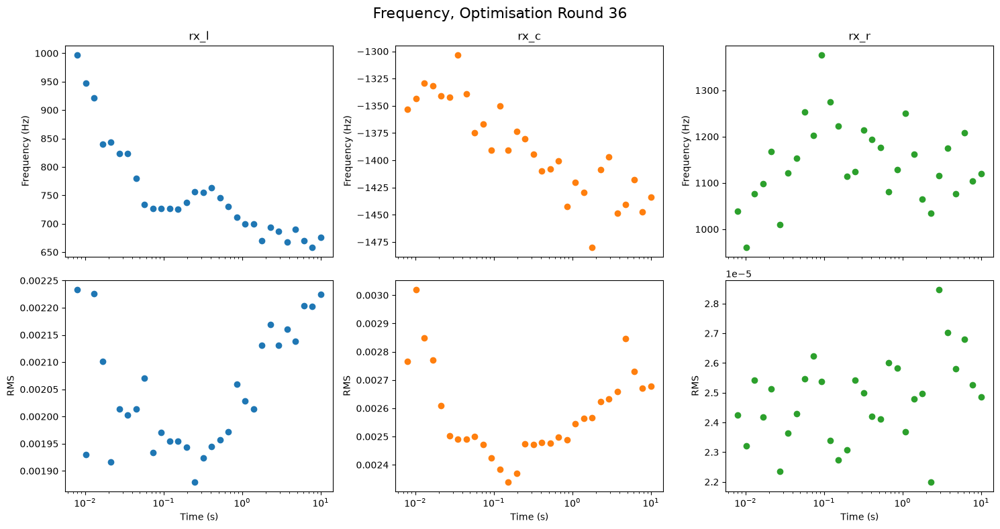

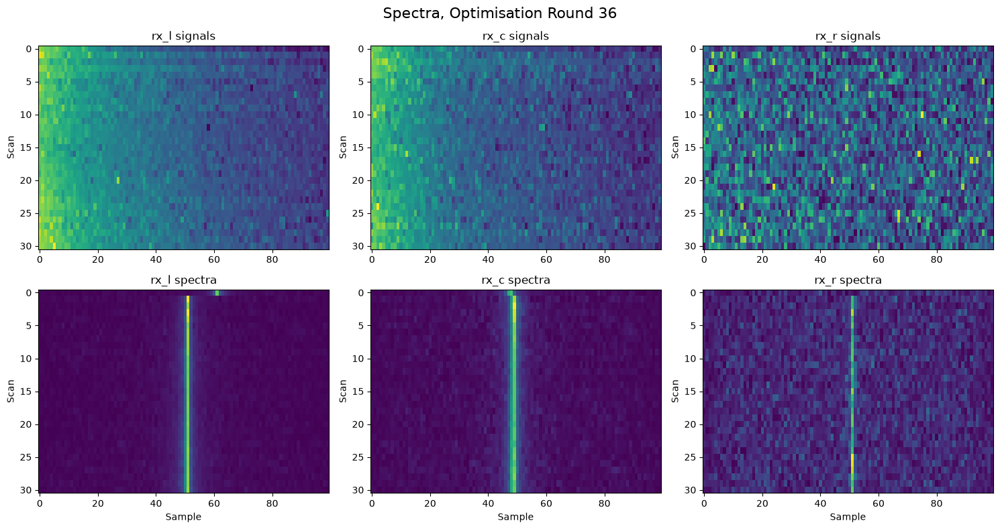

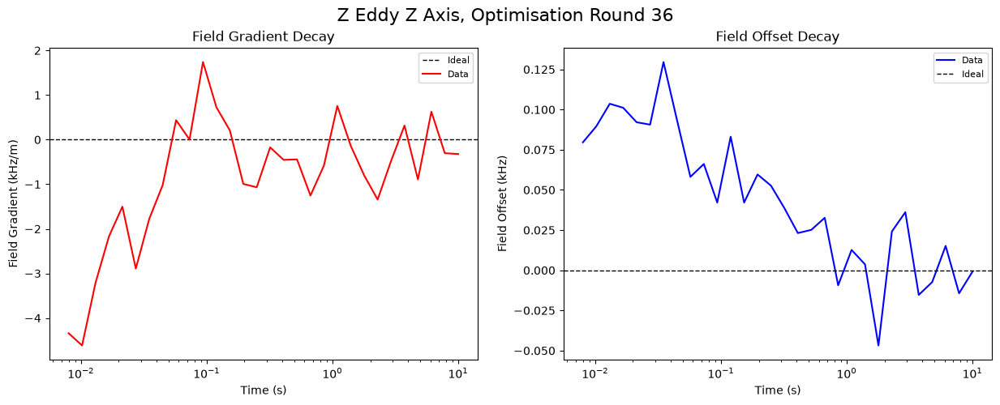

[I 2026-11-24 16:57:08,800] Trial 36 finished with value: 5697.567485454647 and parameters: {'Z_A1': 0.06688101052792311, 'Z_A2': 0.04853351944393571, 'Z_A3': 0.07233013517636634, 'Z_A4': 2.0822650127269283e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 6496.751624187906
mean |E| = 3890.3881392637
RMS E = 4141.625001624543
Total cost = 5.698e+03
E max = 0.11913580435453917
E nanmax = 0.11913580435453917
E contains nan = False
B max = 0.012906289695829043
B nanmax = 0.012906289695829043
B contains nan = False
Trial 37


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012906289695829043 !!!!!!!!!!!!!!!!


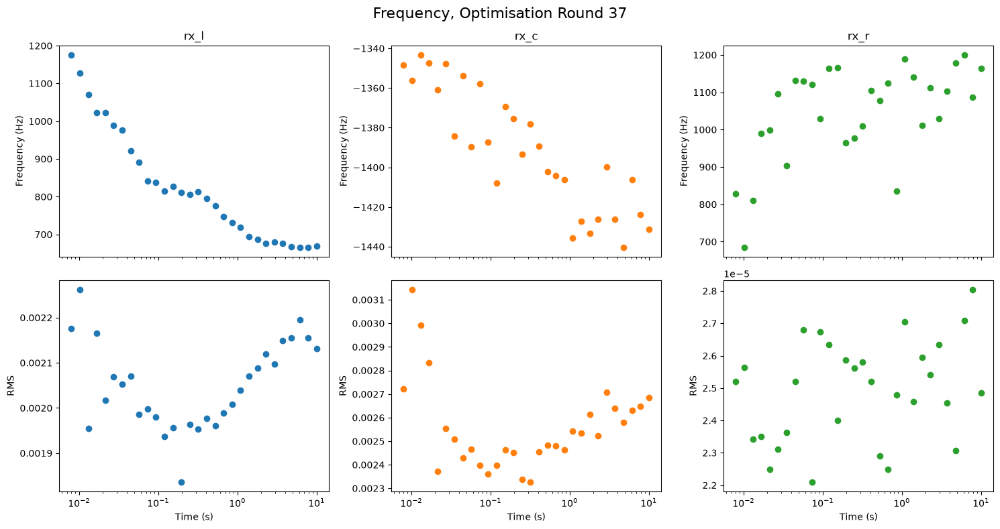

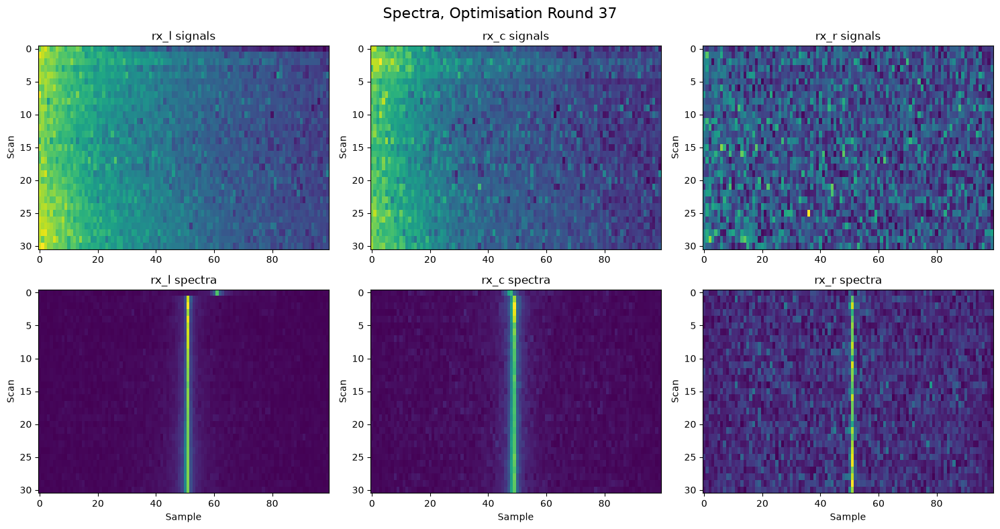

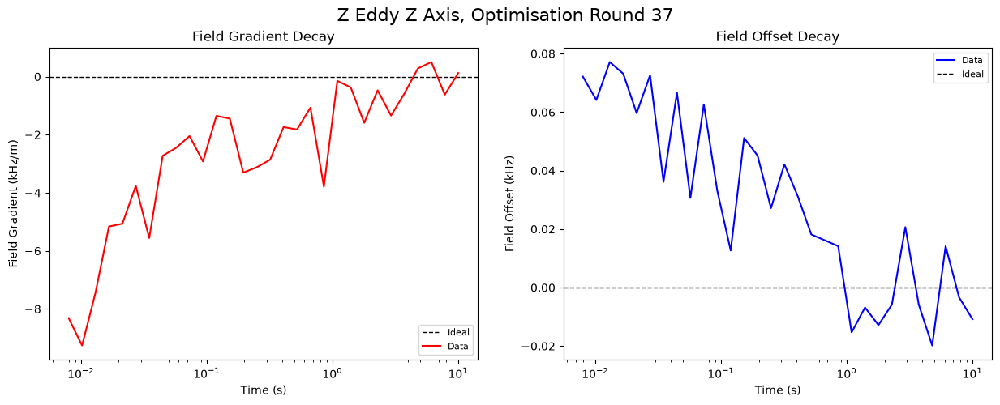

[I 2026-11-24 16:57:57,139] Trial 37 finished with value: 7519.50958466604 and parameters: {'Z_A1': 0.06057275829717232, 'Z_A2': 0.03460439778563796, 'Z_A3': 0.07710457884235086, 'Z_A4': 7.824012833623789e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5337.331334332833
mean |E| = 2973.3466600033307
RMS E = 3303.443964983318
Total cost = 7.520e+03
E max = 0.12409850784600944
E nanmax = 0.12409850784600944
E contains nan = False
B max = 0.013443899042192035
B nanmax = 0.013443899042192035
B contains nan = False
Trial 38


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013443899042192035 !!!!!!!!!!!!!!!!


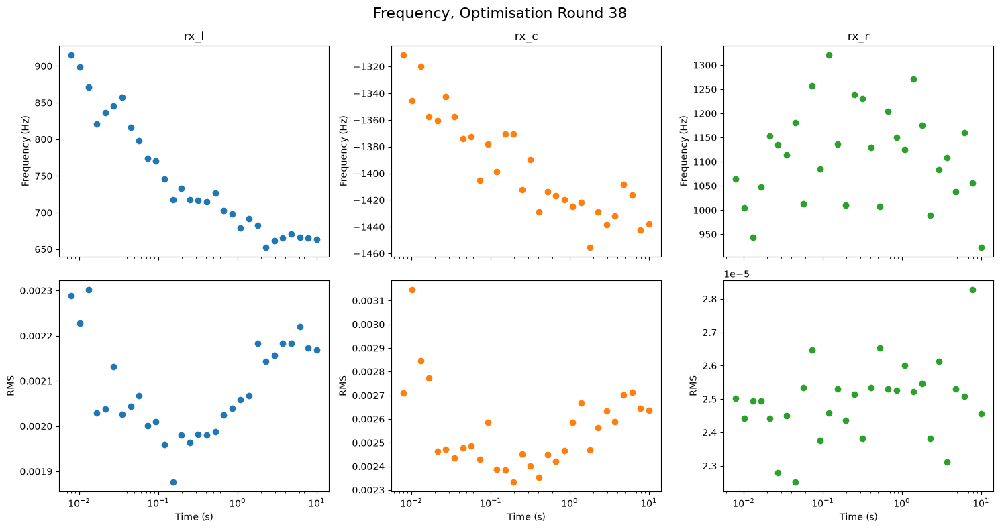

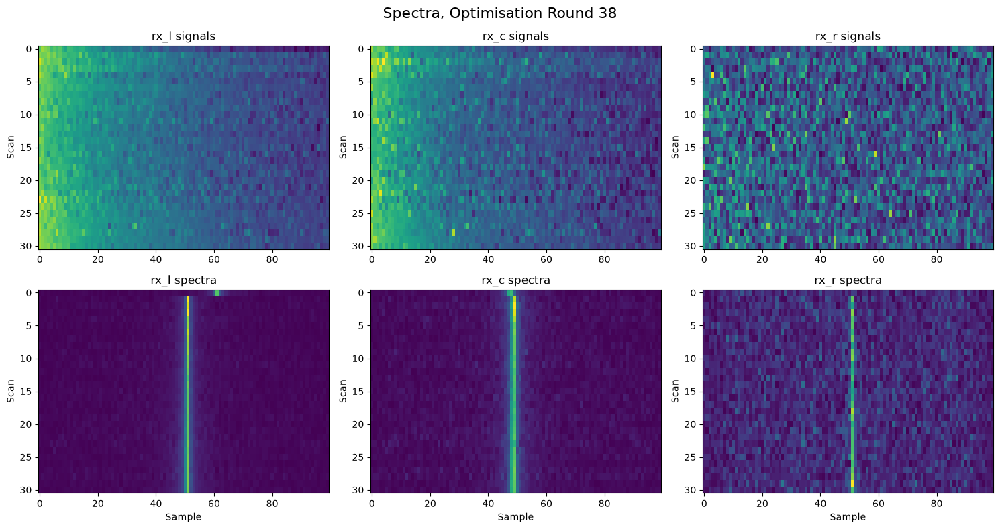

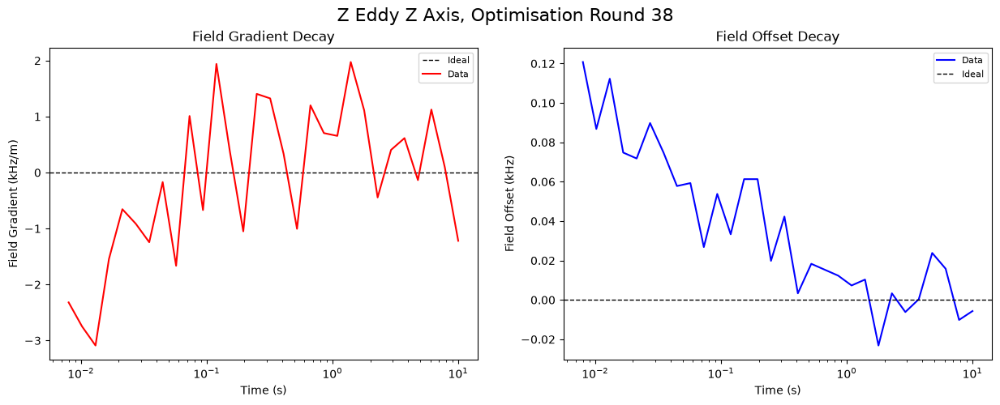

[I 2026-11-24 16:58:45,599] Trial 38 finished with value: 6790.629229383068 and parameters: {'Z_A1': 0.07102588985402136, 'Z_A2': 0.03126110933663369, 'Z_A3': 0.10819211341858298, 'Z_A4': 5.364652342025894e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5787.106446776611
mean |E| = 3659.8367482925196
RMS E = 3889.8323128226566
Total cost = 6.791e+03
E max = 0.12171500961215426
E nanmax = 0.12171500961215426
E contains nan = False
B max = 0.013185717270380686
B nanmax = 0.013185717270380686
B contains nan = False
Trial 39


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013185717270380686 !!!!!!!!!!!!!!!!


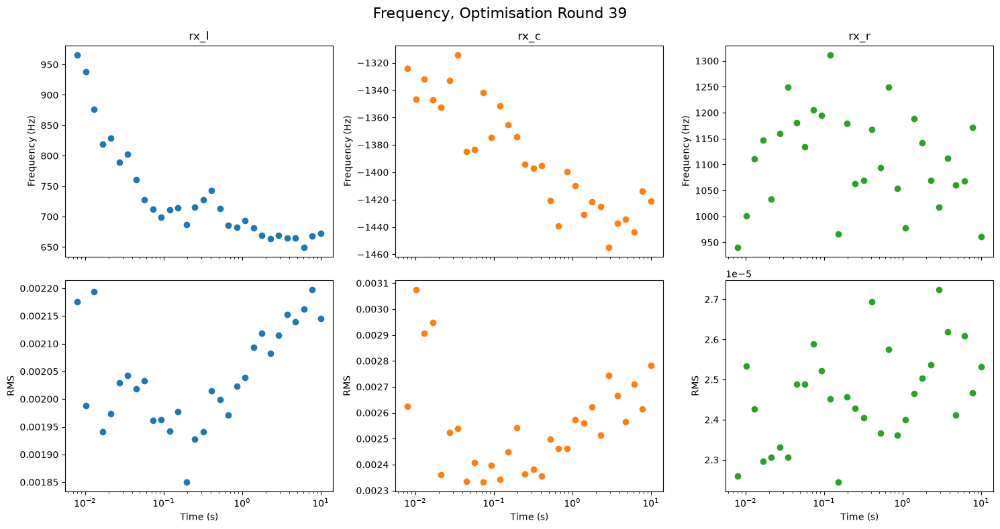

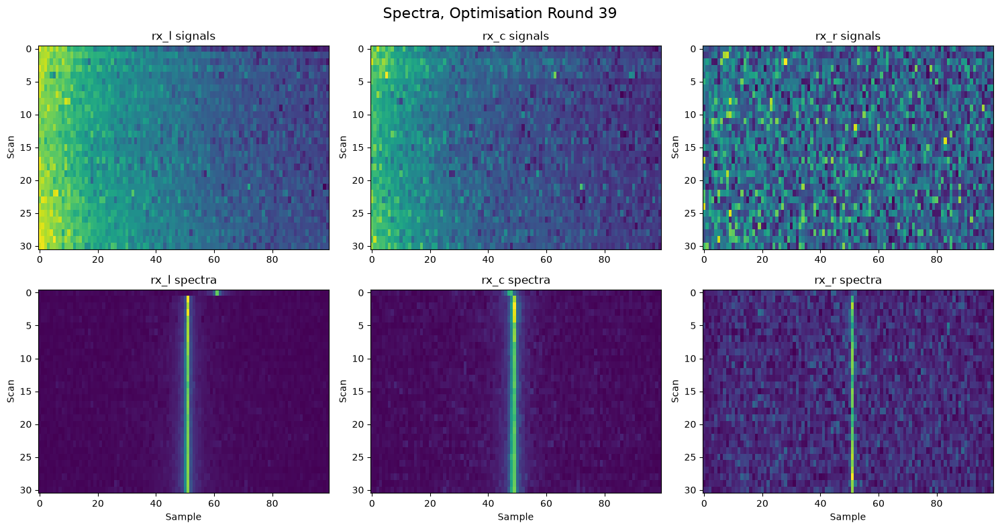

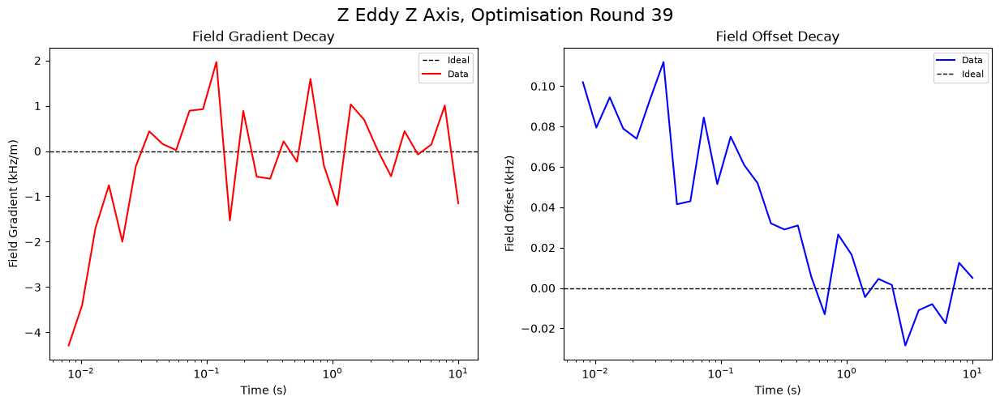

[I 2026-11-24 16:59:33,761] Trial 39 finished with value: 6029.909649205894 and parameters: {'Z_A1': 0.0709091370824757, 'Z_A2': 0.042833035748084794, 'Z_A3': 0.07886349026620479, 'Z_A4': 1.2922271248041386e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 6001.999000499748
mean |E| = 3777.9443611527563
RMS E = 3990.46943847033
Total cost = 6.030e+03
E max = 0.12139042477130983
E nanmax = 0.12139042477130983
E contains nan = False
B max = 0.013150551989674306
B nanmax = 0.013150551989674306
B contains nan = False
Trial 40


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013150551989674306 !!!!!!!!!!!!!!!!


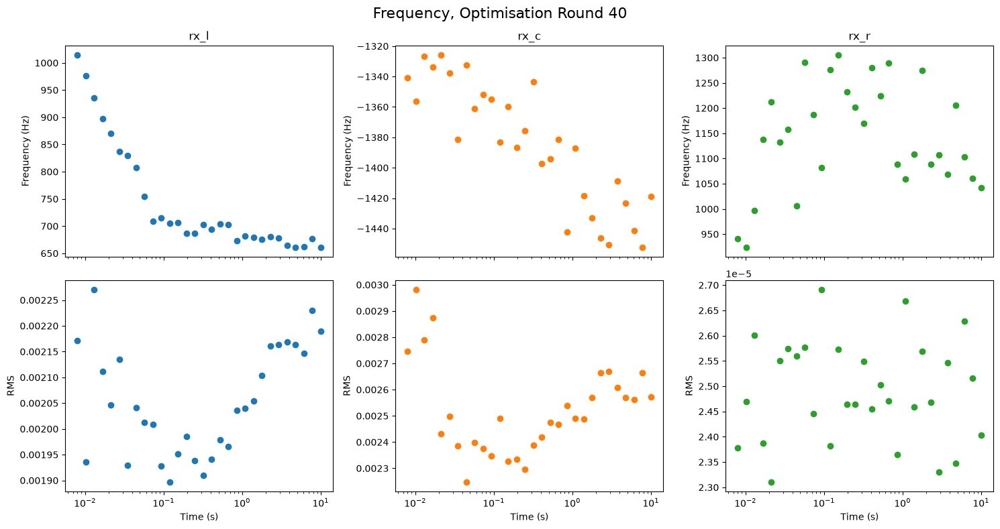

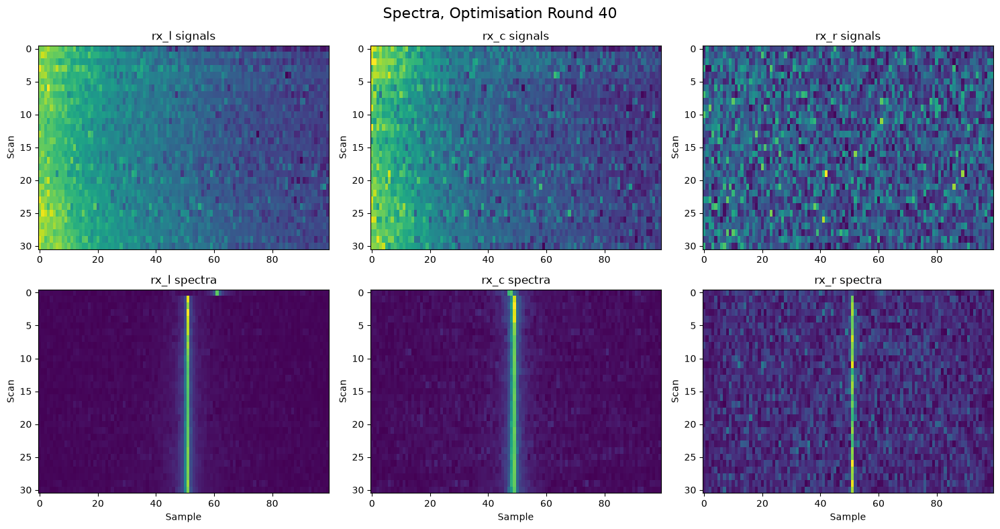

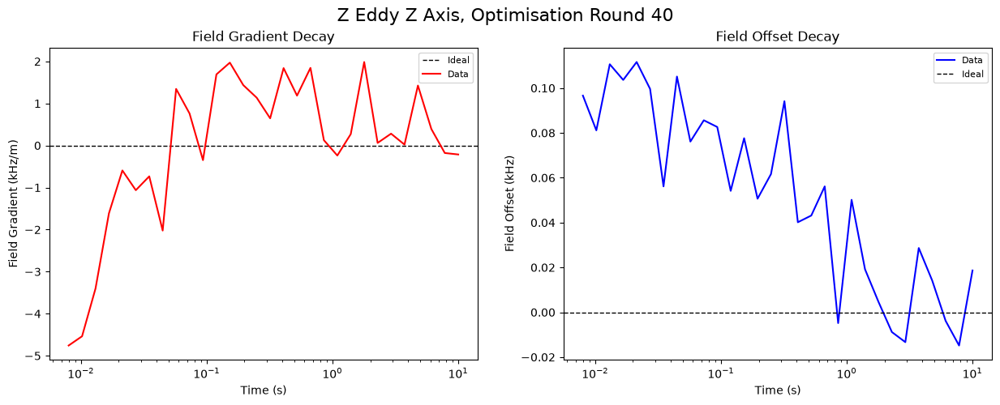

[I 2026-11-24 17:00:21,913] Trial 40 finished with value: 5273.8974850722025 and parameters: {'Z_A1': 0.0759801257379796, 'Z_A2': 0.02919257066347332, 'Z_A3': 0.08451626452472782, 'Z_A4': 5.699413941137364e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 6001.99900049975
mean |E| = 4057.971014492753
RMS E = 4339.232998631726
Total cost = 5.274e+03
E max = 0.12366803632828657
E nanmax = 0.12366803632828657
E contains nan = False
B max = 0.01339729266203873
B nanmax = 0.01339729266203873
B contains nan = False
Trial 41


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01339729266203873 !!!!!!!!!!!!!!!!


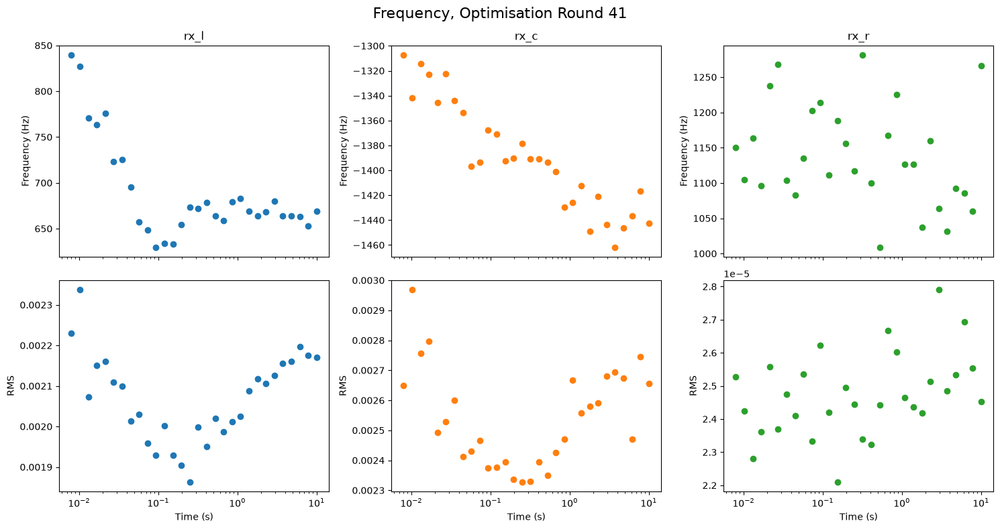

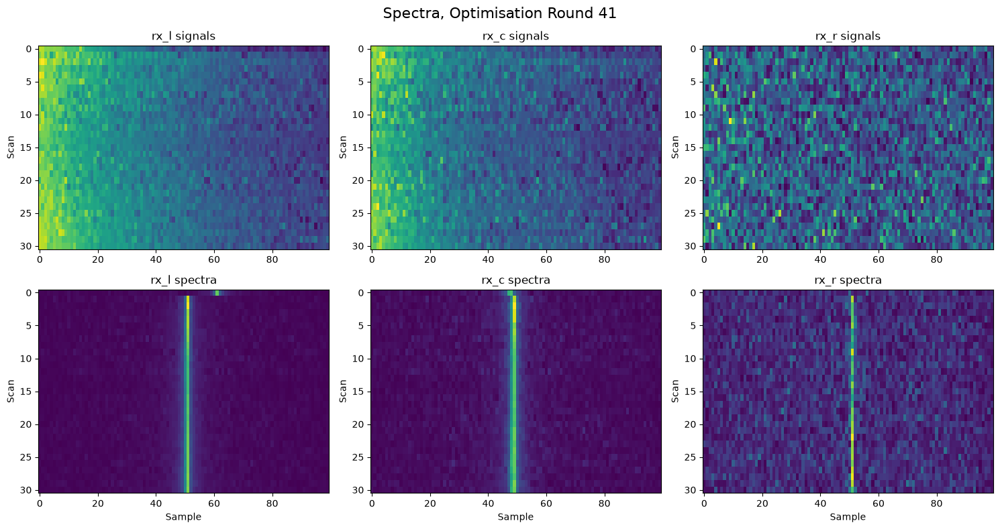

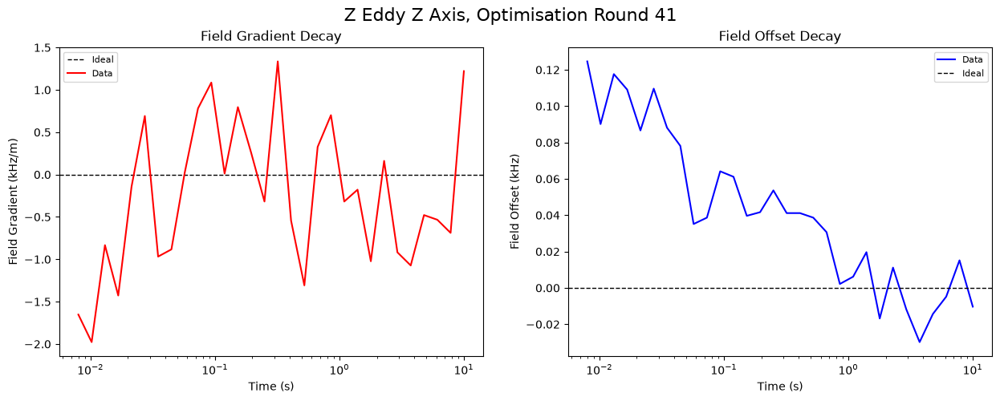

[I 2026-11-24 17:01:09,966] Trial 41 finished with value: 7078.621226012161 and parameters: {'Z_A1': 0.07667357386107491, 'Z_A2': 0.04173636018106709, 'Z_A3': 0.0891466516727853, 'Z_A4': 7.067091373322817e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 6091.954022988503
mean |E| = 4493.5865400633
RMS E = 4575.10444541088
Total cost = 7.079e+03
E max = 0.12321018233013678
E nanmax = 0.12321018233013678
E contains nan = False
B max = 0.013347685629666555
B nanmax = 0.013347685629666555
B contains nan = False
Trial 42


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013347685629666555 !!!!!!!!!!!!!!!!


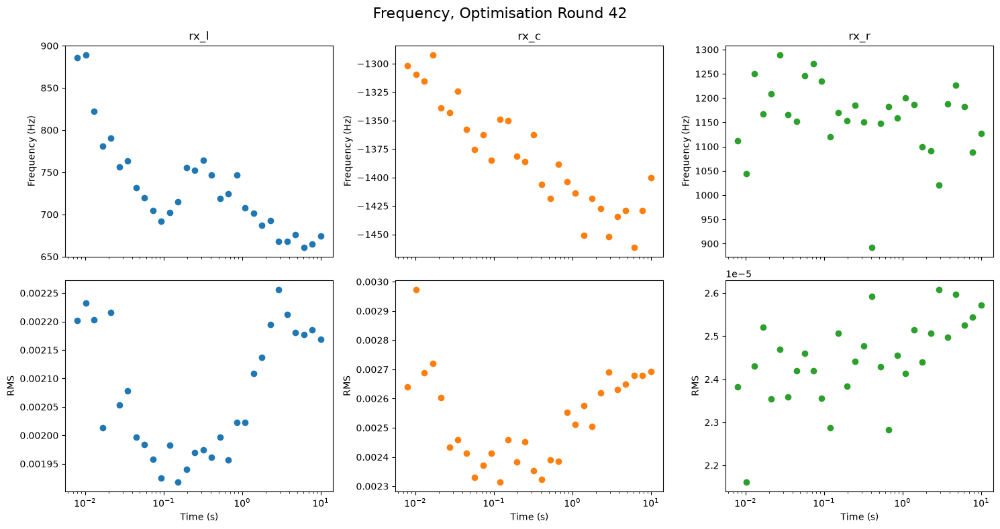

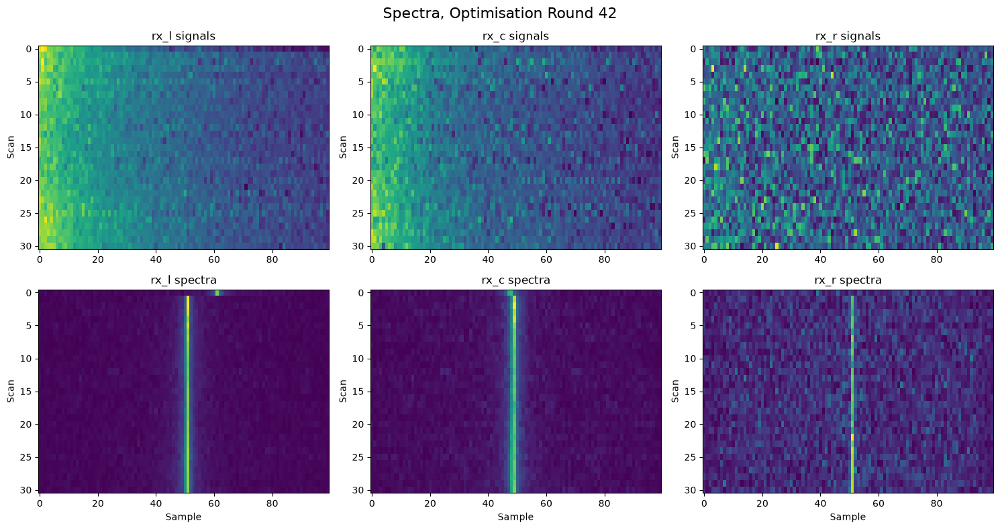

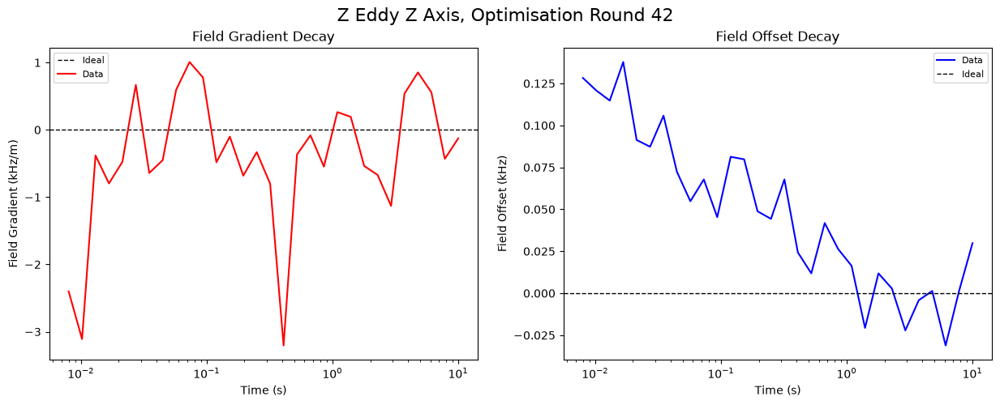

[I 2026-11-24 17:01:58,121] Trial 42 finished with value: 5632.314686771292 and parameters: {'Z_A1': 0.06744234242231852, 'Z_A2': 0.05121161757043524, 'Z_A3': 0.0856894020610688, 'Z_A4': 2.5491918263860827e-09}. Best is trial 7 with value: 4005.372085500783.


max |E| = 5667.166416791602
mean |E| = 4249.375312343827
RMS E = 4366.441562831843
Total cost = 5.632e+03
E max = 0.12034751526911129
E nanmax = 0.12034751526911129
E contains nan = False
B max = 0.013037567651135189
B nanmax = 0.013037567651135189
B contains nan = False
Trial 43


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013037567651135189 !!!!!!!!!!!!!!!!


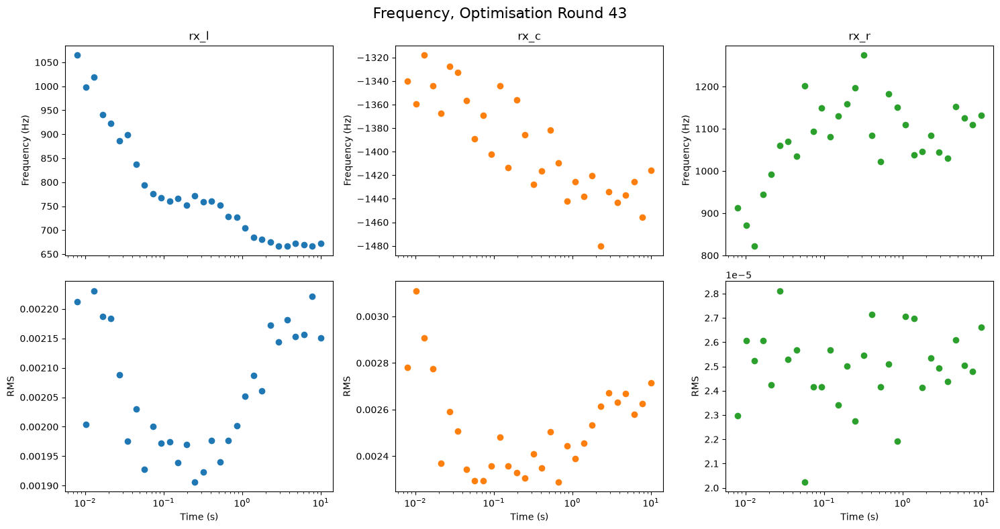

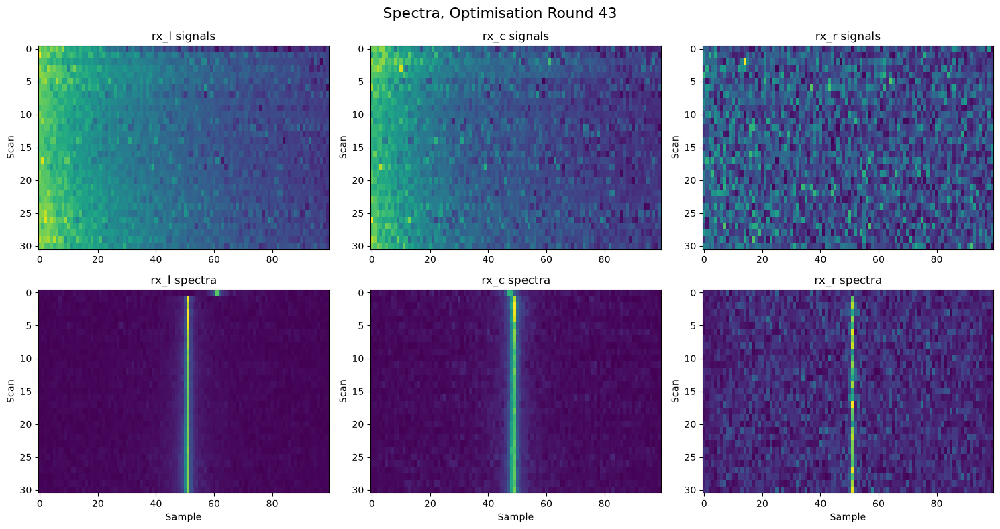

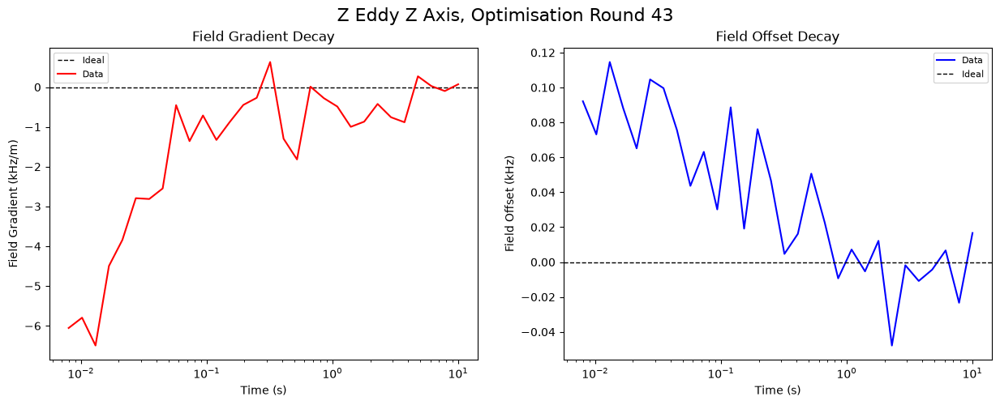

[I 2026-11-24 17:02:46,211] Trial 43 finished with value: 3898.915706473114 and parameters: {'Z_A1': 0.06650876832560287, 'Z_A2': 0.03893533020713986, 'Z_A3': 0.07644479370896022, 'Z_A4': 3.805174019102104e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5157.42128935532
mean |E| = 3271.530901216058
RMS E = 3519.396007159143
Total cost = 3.899e+03
E max = 0.11846166535556665
E nanmax = 0.11846166535556665
E contains nan = False
B max = 0.012833255080484303
B nanmax = 0.012833255080484303
B contains nan = False
Trial 44


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012833255080484303 !!!!!!!!!!!!!!!!


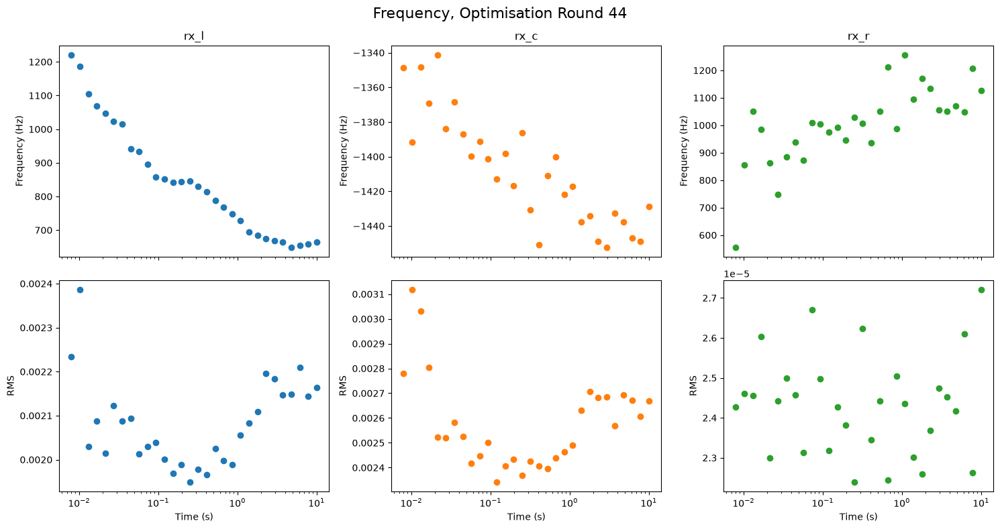

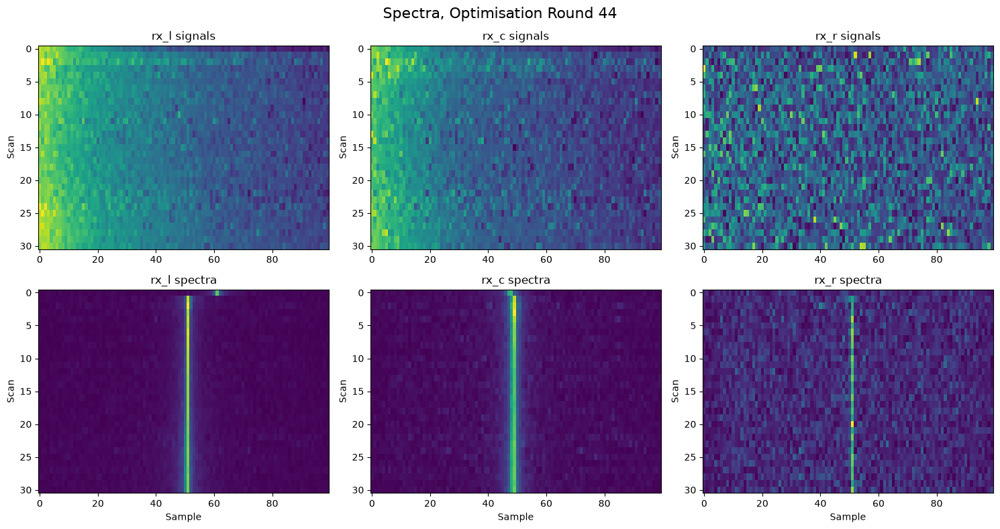

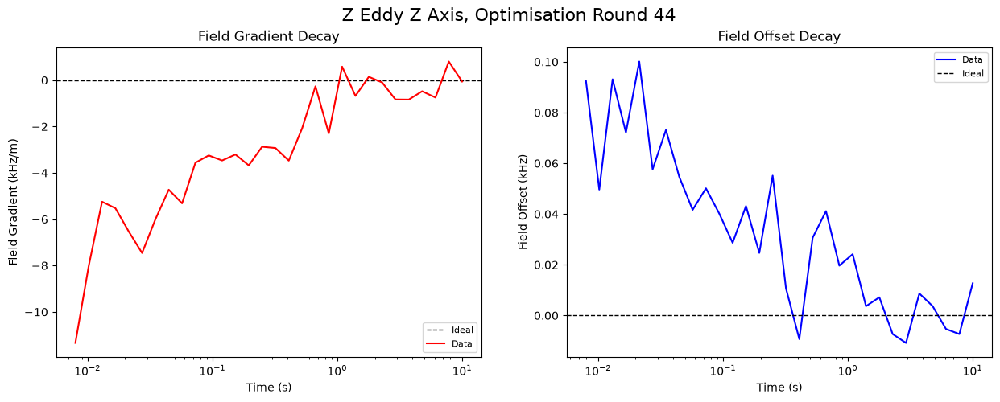

[I 2026-11-24 17:03:34,148] Trial 44 finished with value: 7679.986732364586 and parameters: {'Z_A1': 0.05731455586562907, 'Z_A2': 0.034180597258492186, 'Z_A3': 0.07540410769094974, 'Z_A4': 3.720971167957114e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 6646.676661669164
mean |E| = 2775.4456105280683
RMS E = 3272.57748456778
Total cost = 7.680e+03
E max = 0.12103806429071598
E nanmax = 0.12103806429071598
E contains nan = False
B max = 0.013112380199417512
B nanmax = 0.013112380199417512
B contains nan = False
Trial 45


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013112380199417512 !!!!!!!!!!!!!!!!


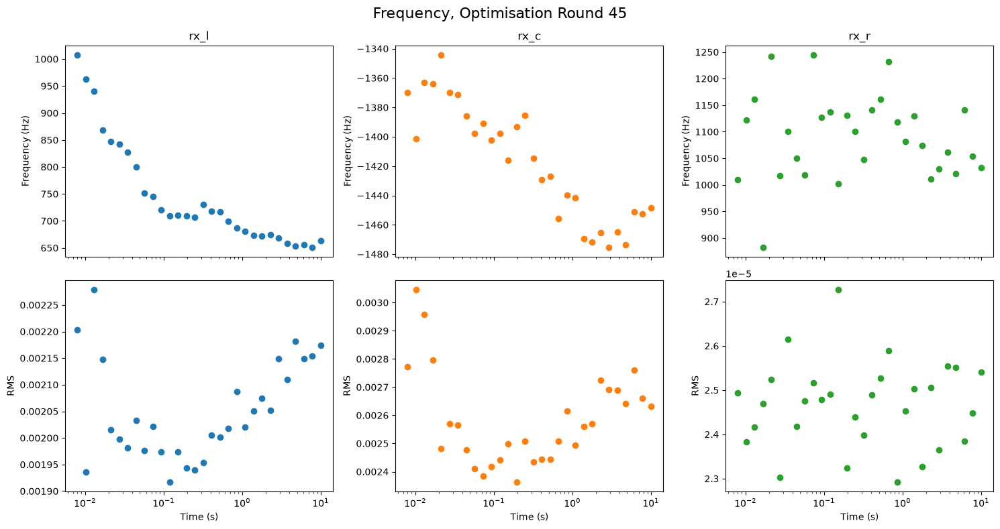

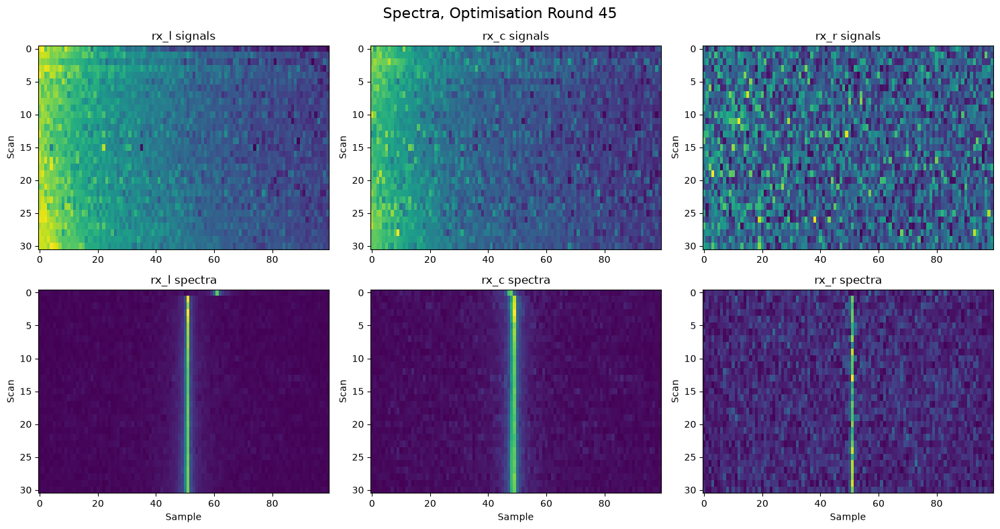

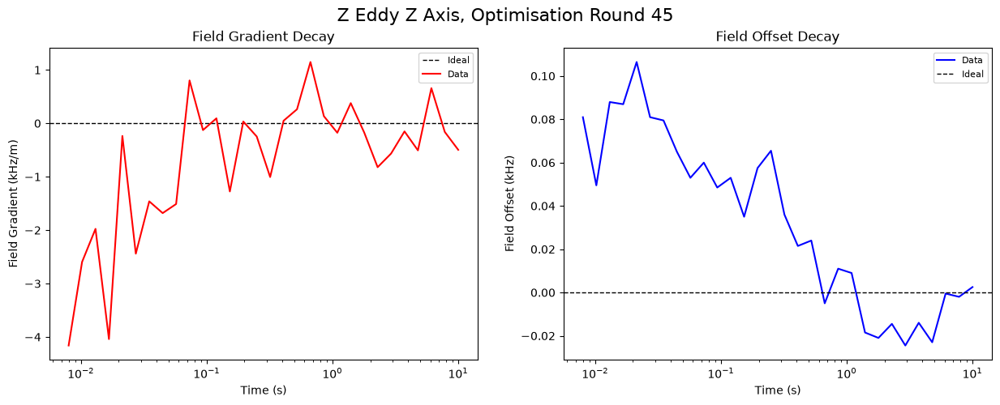

[I 2026-11-24 17:04:22,052] Trial 45 finished with value: 4258.999374479286 and parameters: {'Z_A1': 0.06987180109416329, 'Z_A2': 0.03943619948178169, 'Z_A3': 0.07796982532169093, 'Z_A4': 5.467236611481482e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5332.333833083456
mean |E| = 3442.945194069631
RMS E = 3667.8443107872886
Total cost = 4.259e+03
E max = 0.11964154811540682
E nanmax = 0.11964154811540682
E contains nan = False
B max = 0.012961072892623101
B nanmax = 0.012961072892623101
B contains nan = False
Trial 46


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012961072892623101 !!!!!!!!!!!!!!!!


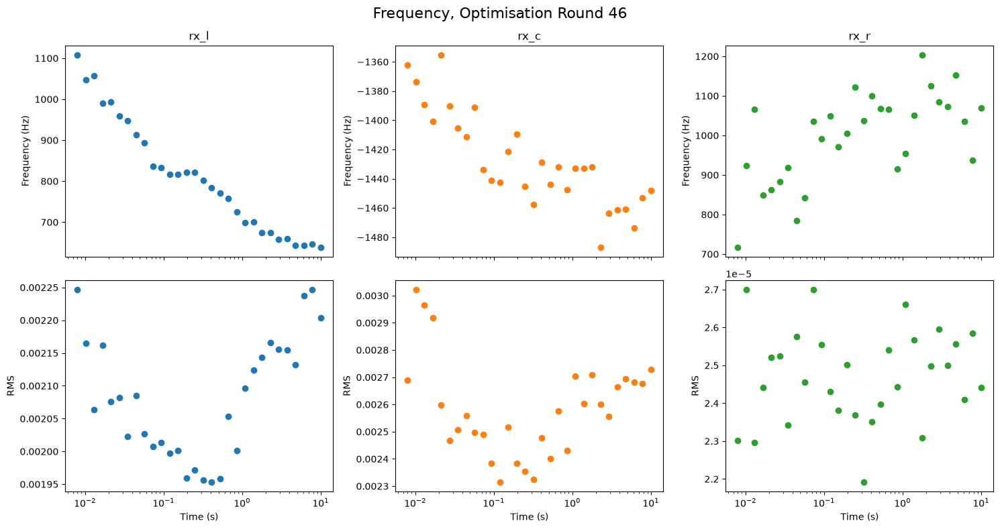

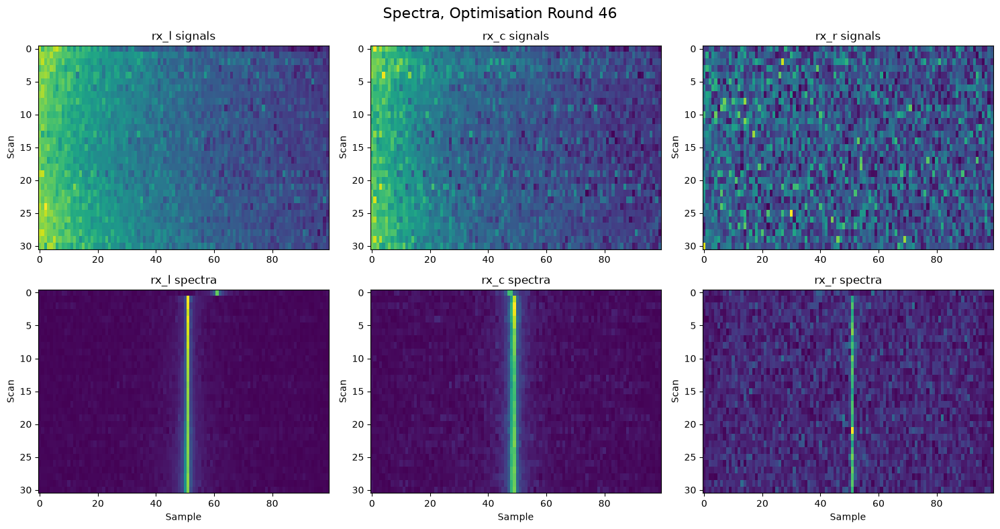

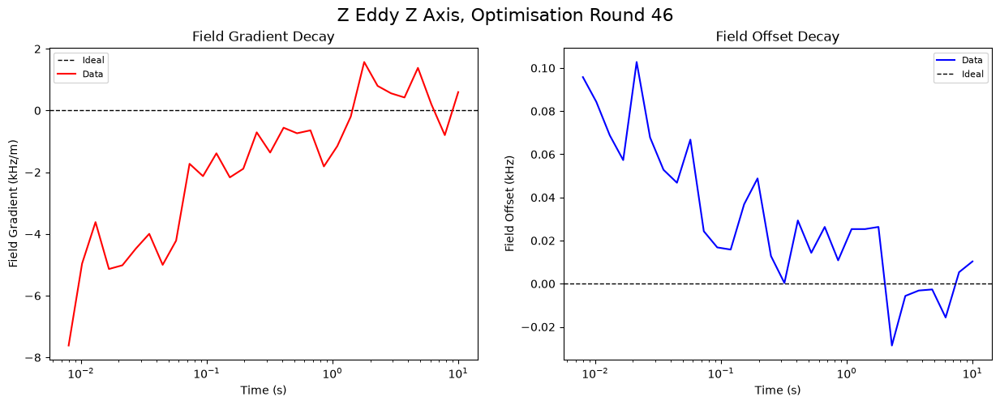

[I 2026-11-24 17:05:10,414] Trial 46 finished with value: 7828.222000927029 and parameters: {'Z_A1': 0.05805935865297611, 'Z_A2': 0.03763865681686711, 'Z_A3': 0.08070371418231673, 'Z_A4': 5.83650035295127e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5282.358820589704
mean |E| = 2567.216391804097
RMS E = 2930.9875464873044
Total cost = 7.828e+03
E max = 0.12134472844816664
E nanmax = 0.12134472844816664
E contains nan = False
B max = 0.01314558596548703
B nanmax = 0.01314558596548703
B contains nan = False
Trial 47


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01314558596548703 !!!!!!!!!!!!!!!!


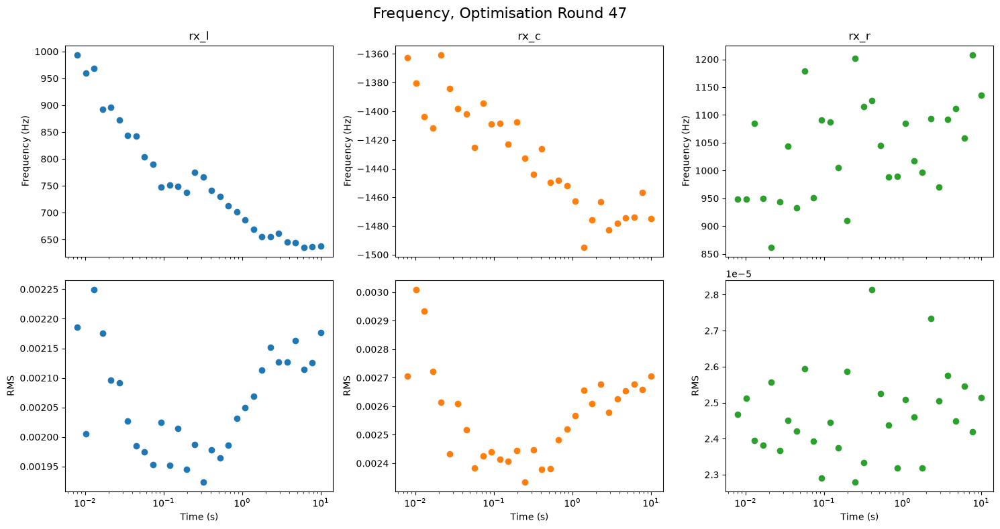

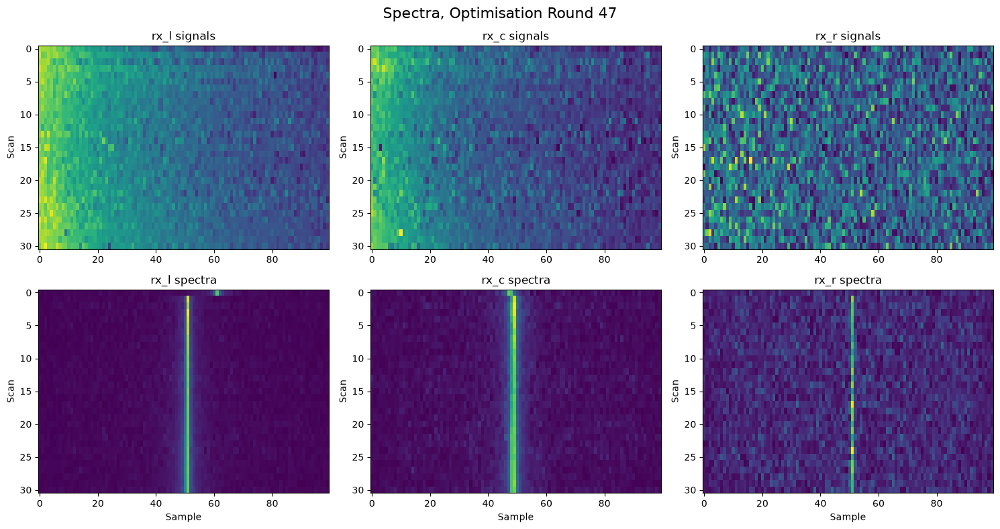

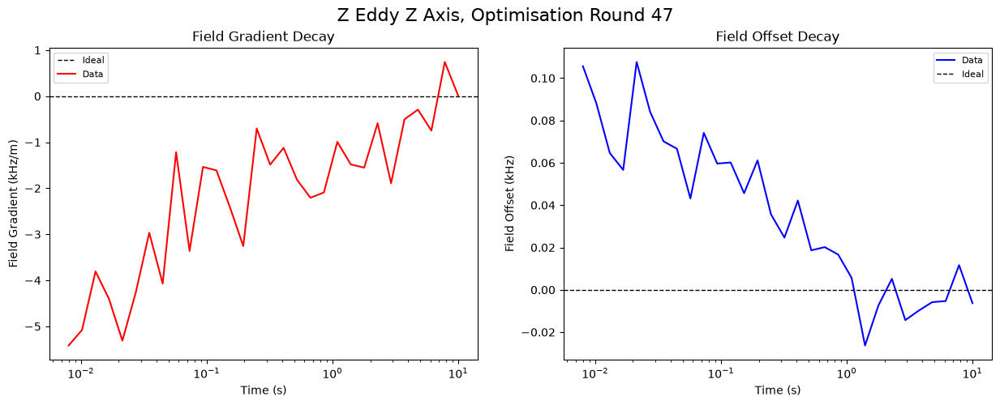

[I 2026-11-24 17:05:58,588] Trial 47 finished with value: 8494.305613394003 and parameters: {'Z_A1': 0.06375979046109295, 'Z_A2': 0.03890749310968608, 'Z_A3': 0.0871142234873604, 'Z_A4': 8.685822636754975e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5712.143928035982
mean |E| = 2848.9088788938852
RMS E = 3230.327750224701
Total cost = 8.494e+03
E max = 0.12205021707233382
E nanmax = 0.12205021707233382
E contains nan = False
B max = 0.01322202388683199
B nanmax = 0.01322202388683199
B contains nan = False
Trial 48


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01322202388683199 !!!!!!!!!!!!!!!!


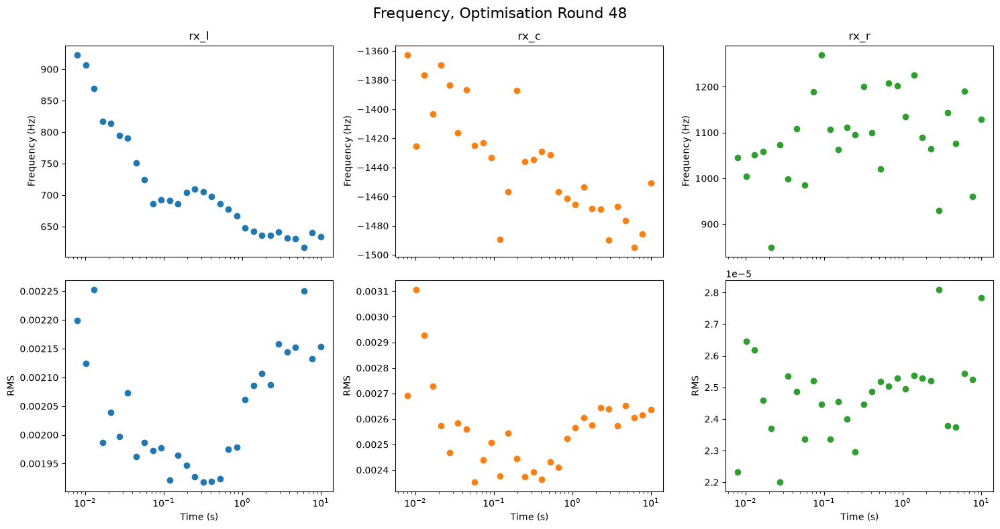

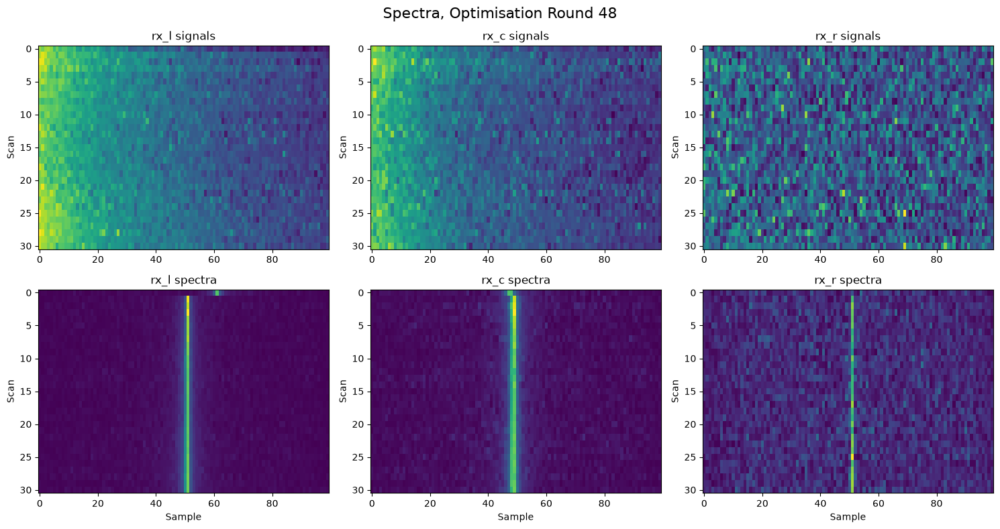

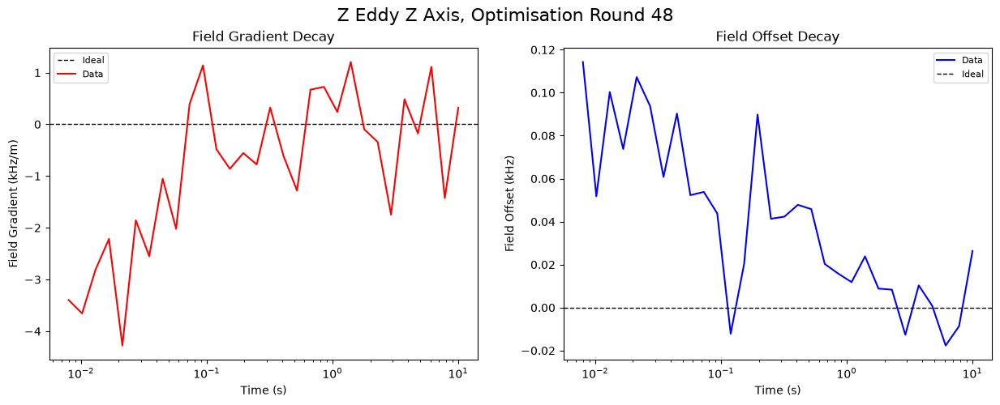

[I 2026-11-24 17:06:46,909] Trial 48 finished with value: 8249.379610714306 and parameters: {'Z_A1': 0.06991460952089772, 'Z_A2': 0.040202162519156294, 'Z_A3': 0.08509226602432367, 'Z_A4': 4.610874020157489e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5832.083958020987
mean |E| = 3776.111944027985
RMS E = 4048.688350318653
Total cost = 8.249e+03
E max = 0.11994498128689597
E nanmax = 0.11994498128689597
E contains nan = False
B max = 0.012993950974977929
B nanmax = 0.012993950974977929
B contains nan = False
Trial 49


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012993950974977929 !!!!!!!!!!!!!!!!


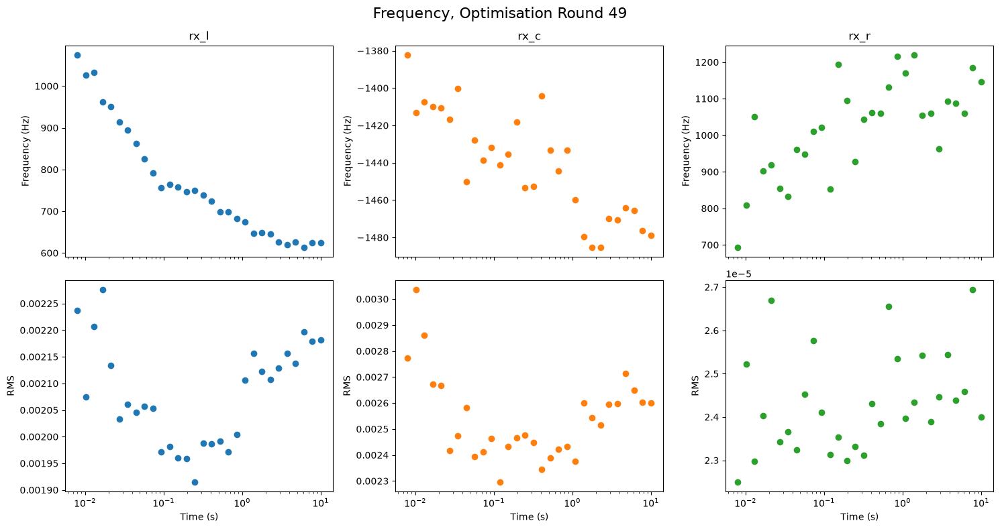

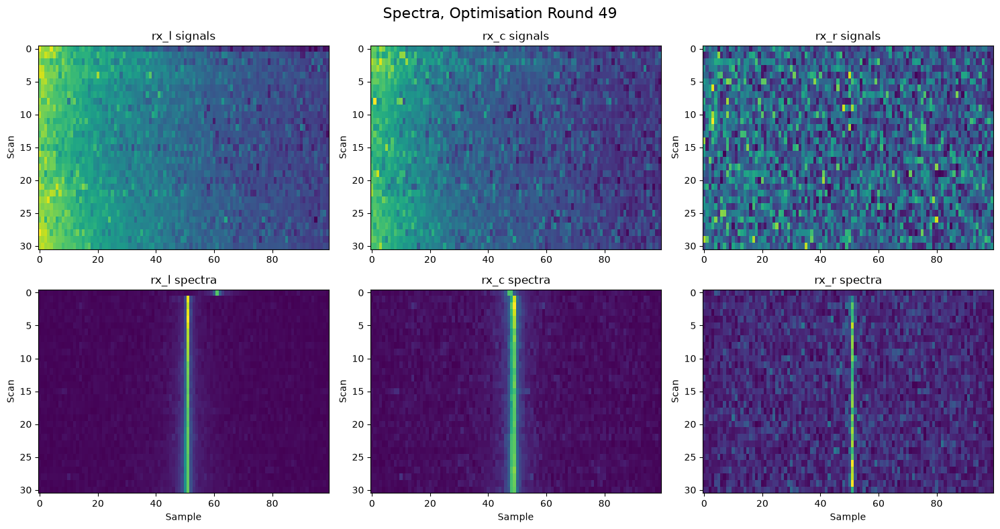

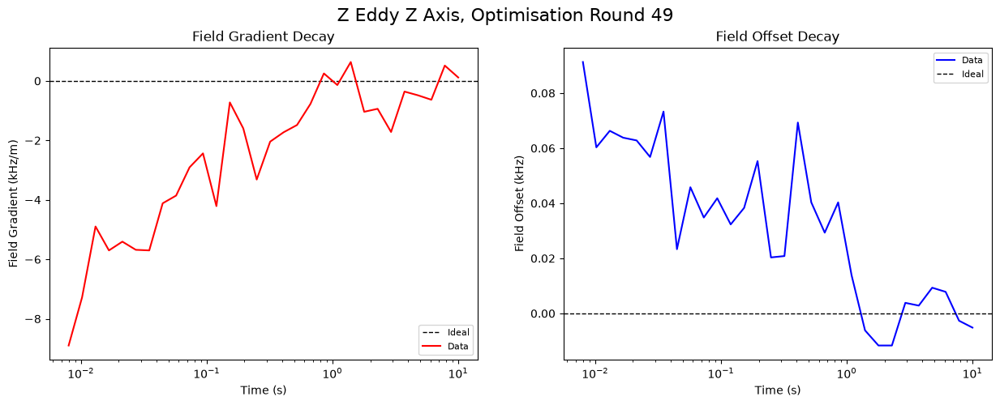

[I 2026-11-24 17:07:35,331] Trial 49 finished with value: 7041.252957005737 and parameters: {'Z_A1': 0.06512637056021361, 'Z_A2': 0.03111988812449367, 'Z_A3': 0.08234548794520583, 'Z_A4': 4.378532854560998e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5727.136431784106
mean |E| = 3080.959520239879
RMS E = 3536.7330818126184
Total cost = 7.041e+03
E max = 0.12118739561077554
E nanmax = 0.12118739561077554
E contains nan = False
B max = 0.013128560818357834
B nanmax = 0.013128560818357834
B contains nan = False
Trial 50


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013128560818357834 !!!!!!!!!!!!!!!!


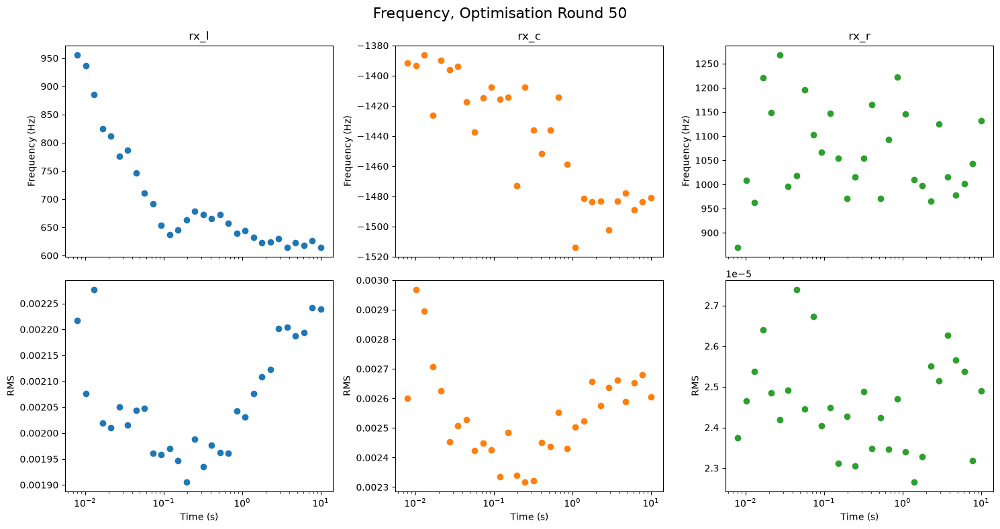

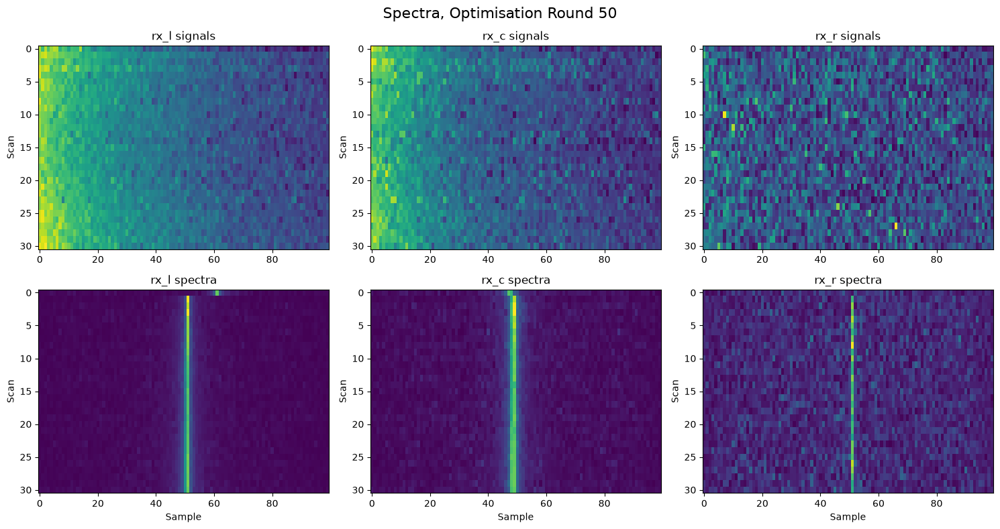

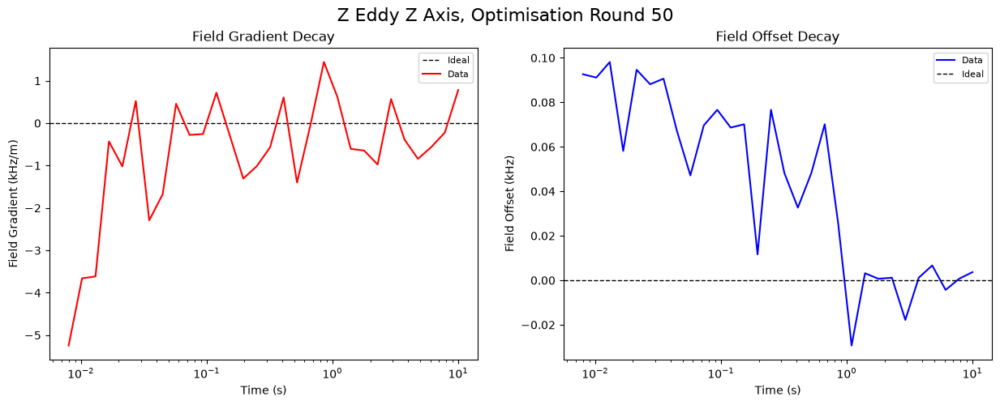

[I 2026-11-24 17:08:23,292] Trial 50 finished with value: 5983.7218858826245 and parameters: {'Z_A1': 0.07345276968842385, 'Z_A2': 0.03612061429762073, 'Z_A3': 0.07874054266113184, 'Z_A4': 4.047434396954303e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5832.083958020988
mean |E| = 3725.970348159253
RMS E = 3934.9142403657847
Total cost = 5.984e+03
E max = 0.12363834758538396
E nanmax = 0.12363834758538396
E contains nan = False
B max = 0.01339404108833243
B nanmax = 0.01339404108833243
B contains nan = False
Trial 51


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01339404108833243 !!!!!!!!!!!!!!!!


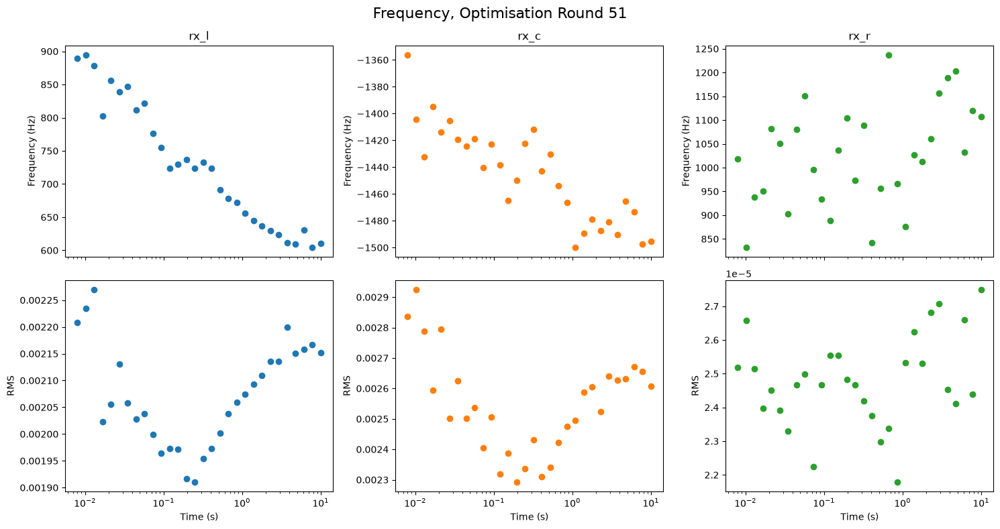

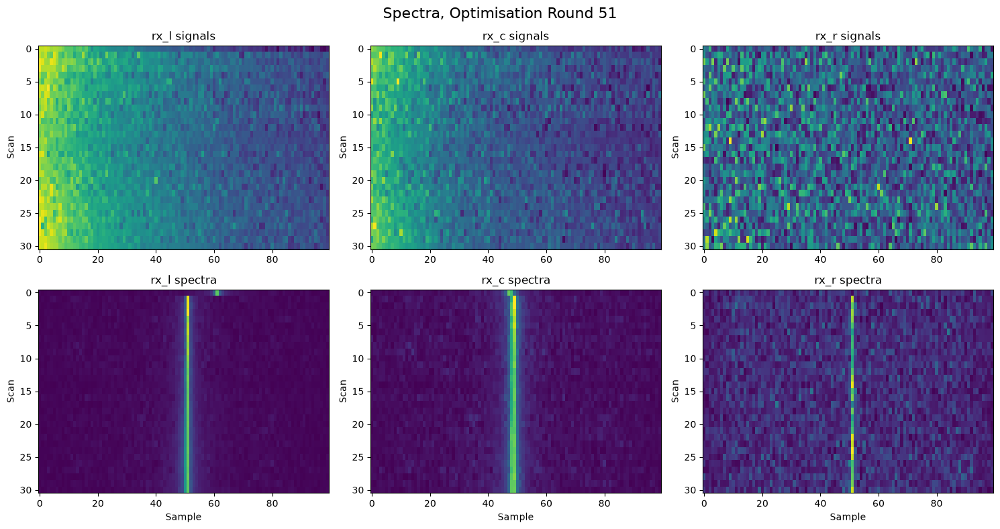

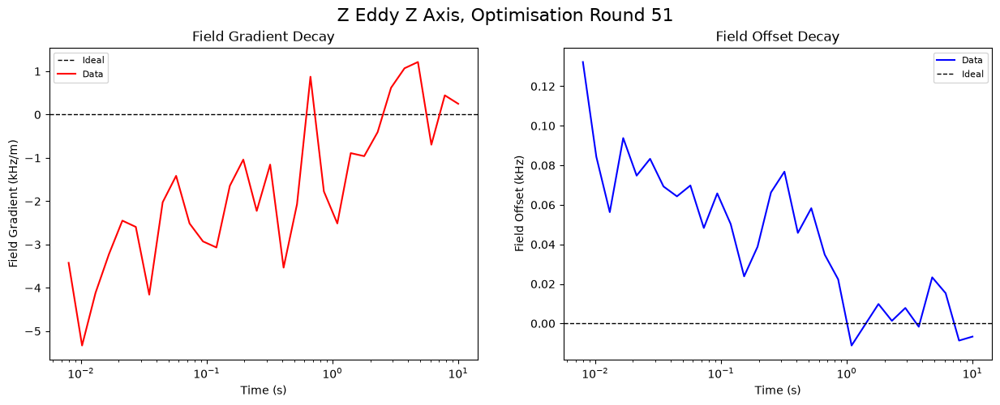

[I 2026-11-24 17:09:11,583] Trial 51 finished with value: 8576.43244658779 and parameters: {'Z_A1': 0.06463715041319165, 'Z_A2': 0.03437184856401793, 'Z_A3': 0.1081303160368206, 'Z_A4': 6.0845094377489145e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5927.036481759119
mean |E| = 3031.4842578710636
RMS E = 3414.798125592476
Total cost = 8.576e+03
E max = 0.11989107630412985
E nanmax = 0.11989107630412985
E contains nan = False
B max = 0.01298812176403374
B nanmax = 0.01298812176403374
B contains nan = False
Trial 52


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01298812176403374 !!!!!!!!!!!!!!!!


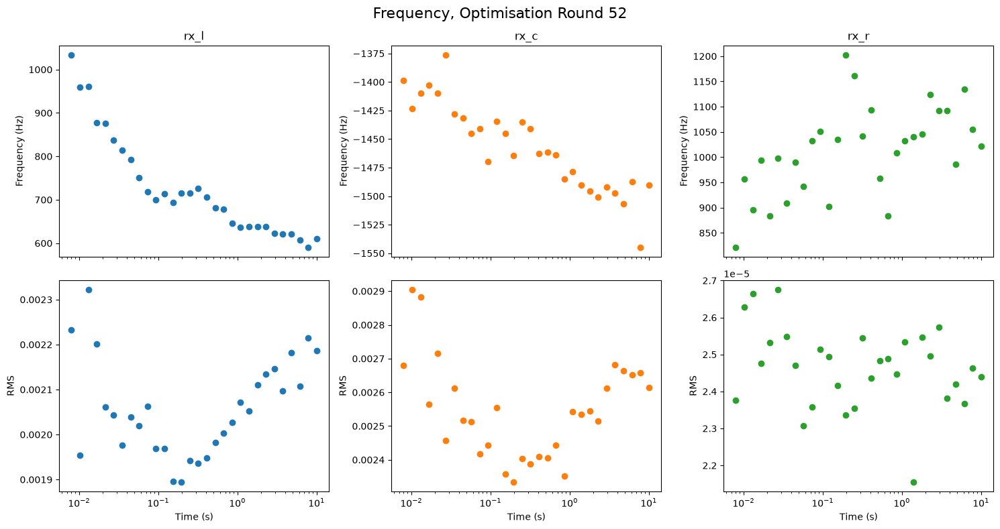

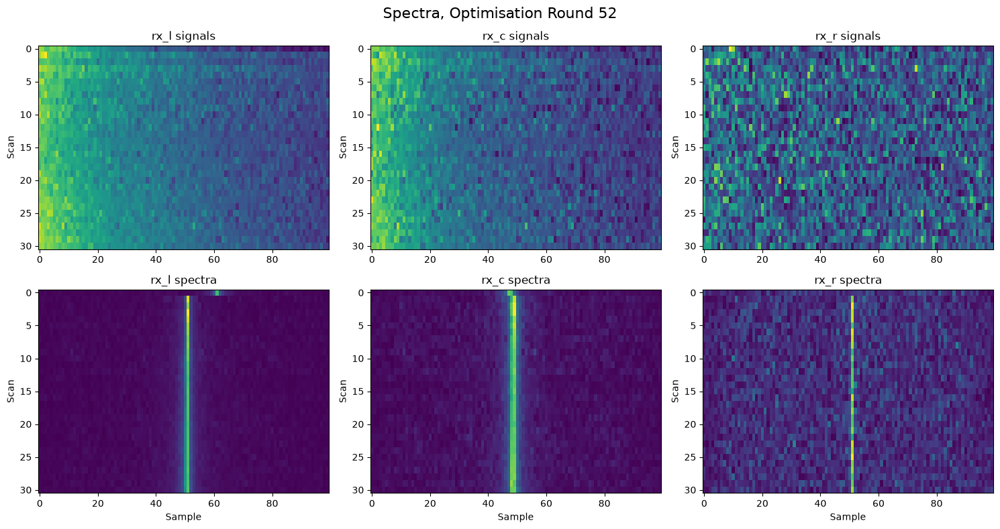

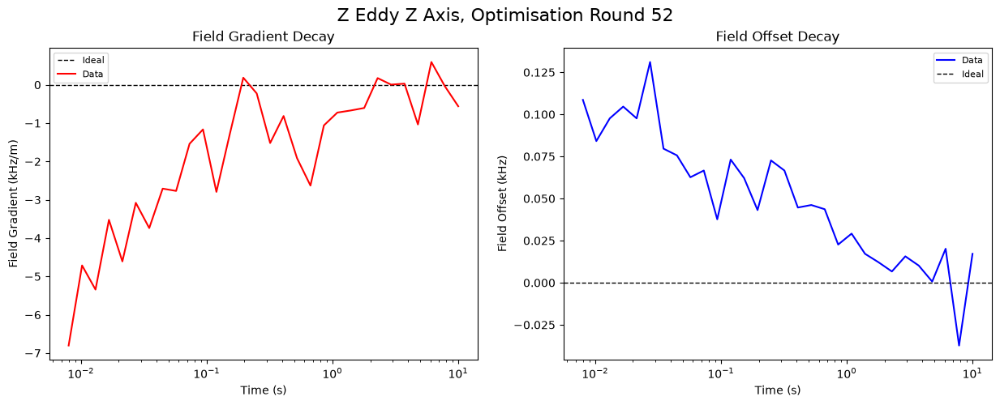

[I 2026-11-24 17:09:59,544] Trial 52 finished with value: 5161.279215042551 and parameters: {'Z_A1': 0.065446160660979, 'Z_A2': 0.03968028525787167, 'Z_A3': 0.07315446546039715, 'Z_A4': 7.640168313883833e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5277.361319340328
mean |E| = 3041.312676994836
RMS E = 3387.2094872120583
Total cost = 5.161e+03
E max = 0.12002521114955621
E nanmax = 0.12002521114955621
E contains nan = False
B max = 0.013002649599525629
B nanmax = 0.013002649599525629
B contains nan = False
Trial 53


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013002649599525629 !!!!!!!!!!!!!!!!


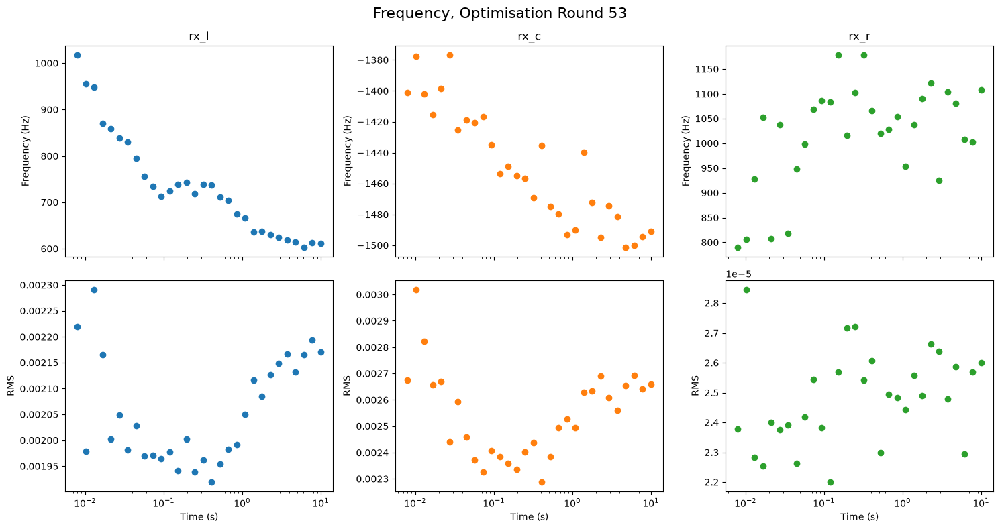

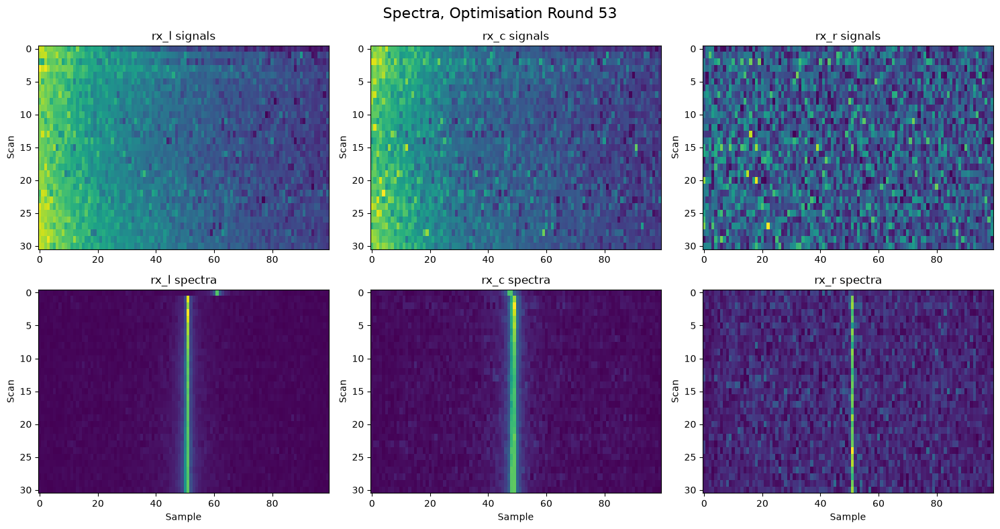

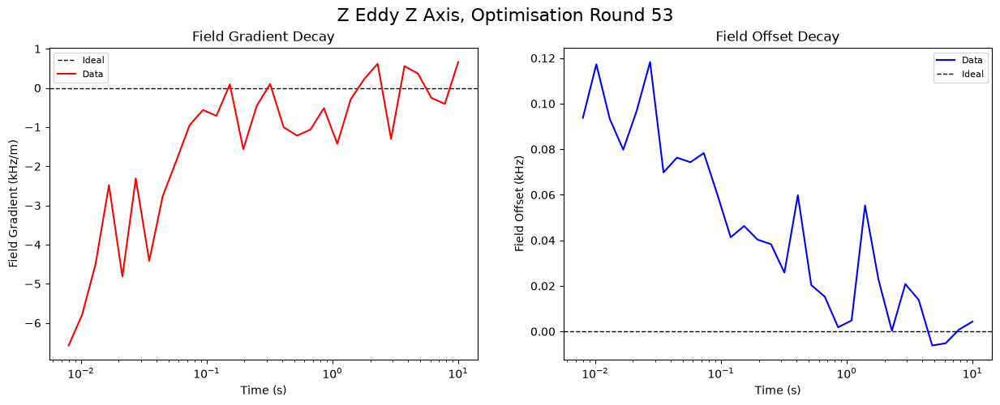

[I 2026-11-24 17:10:47,493] Trial 53 finished with value: 5633.375409163496 and parameters: {'Z_A1': 0.06174018687769626, 'Z_A2': 0.04472121827454471, 'Z_A3': 0.07299641622427498, 'Z_A4': 3.1100811686985266e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 4962.518740629683
mean |E| = 3119.440279860069
RMS E = 3401.029516652726
Total cost = 5.633e+03
E max = 0.12136503756897507
E nanmax = 0.12136503756897507
E contains nan = False
B max = 0.013147800706437836
B nanmax = 0.013147800706437836
B contains nan = False
Trial 54


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013147800706437836 !!!!!!!!!!!!!!!!


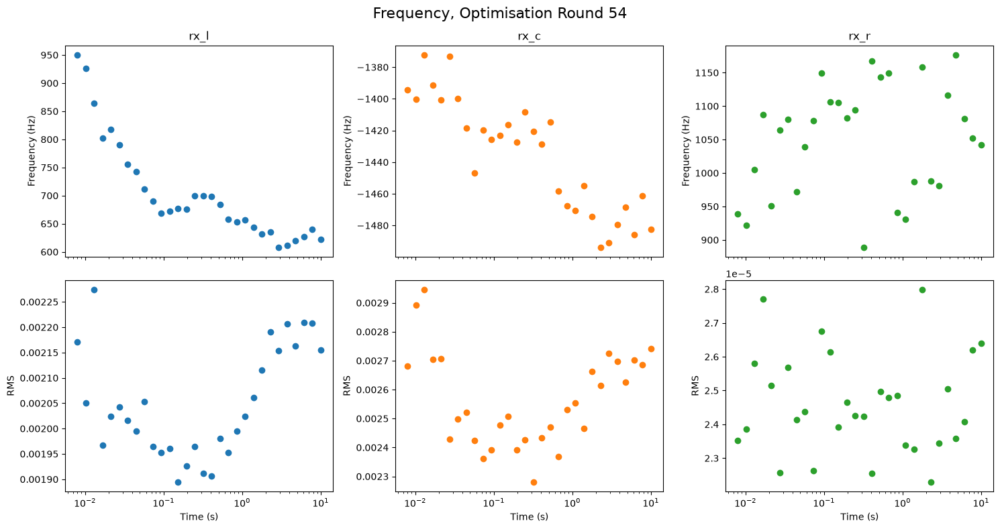

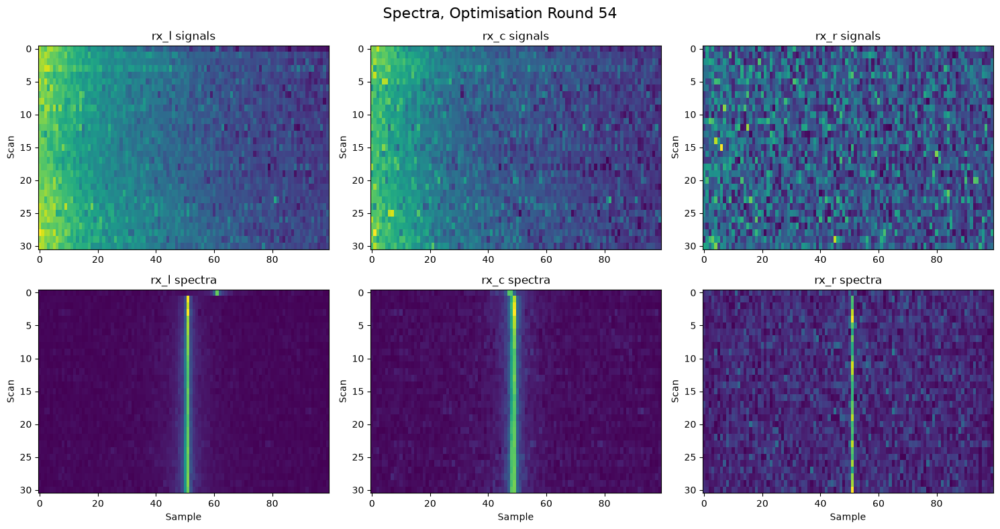

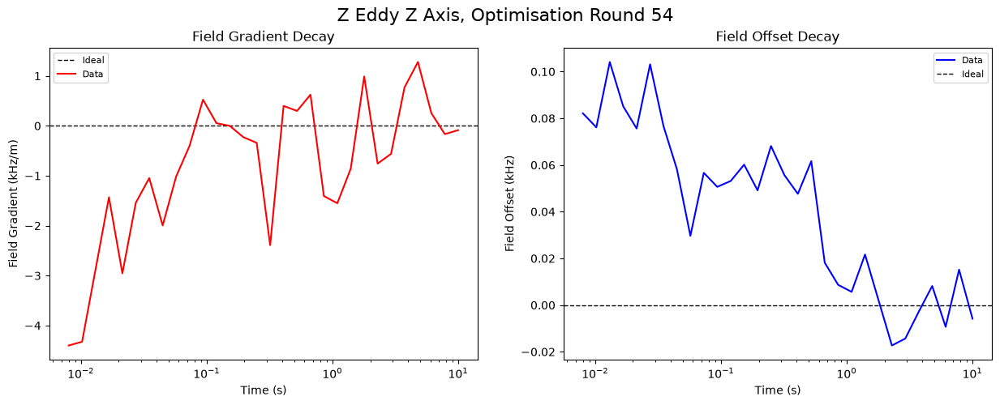

[I 2026-11-24 17:11:35,469] Trial 54 finished with value: 5856.092490820808 and parameters: {'Z_A1': 0.06929119864216499, 'Z_A2': 0.04118986071257884, 'Z_A3': 0.07940357245704412, 'Z_A4': 6.0582234135541795e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5562.218890554721
mean |E| = 3456.4384474429444
RMS E = 3728.5140749819298
Total cost = 5.856e+03
E max = 0.12022265394013087
E nanmax = 0.12022265394013087
E contains nan = False
B max = 0.013024043869376395
B nanmax = 0.013024043869376395
B contains nan = False
Trial 55


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013024043869376395 !!!!!!!!!!!!!!!!


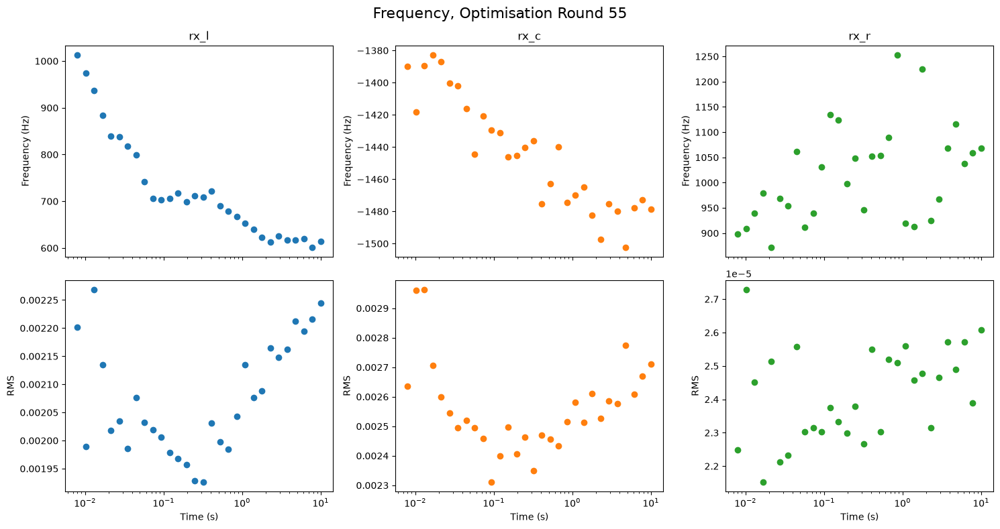

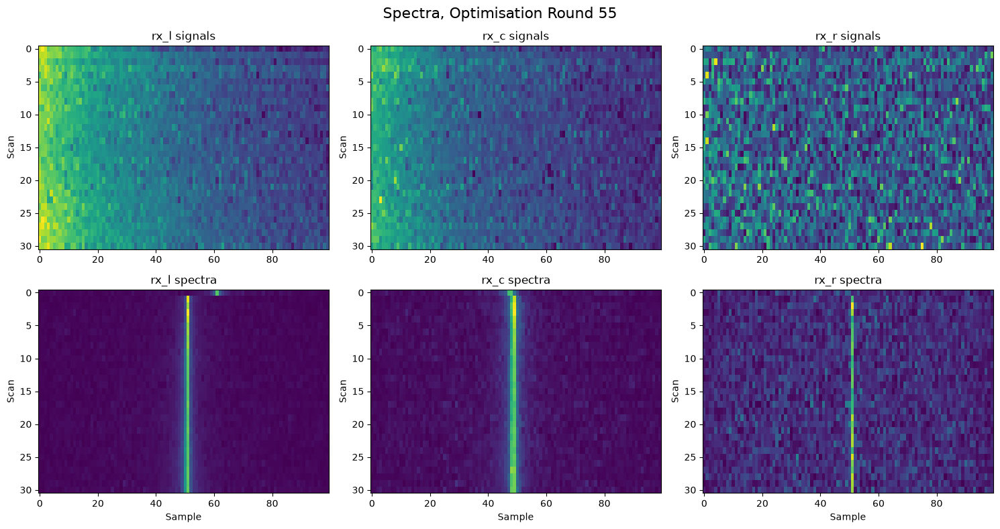

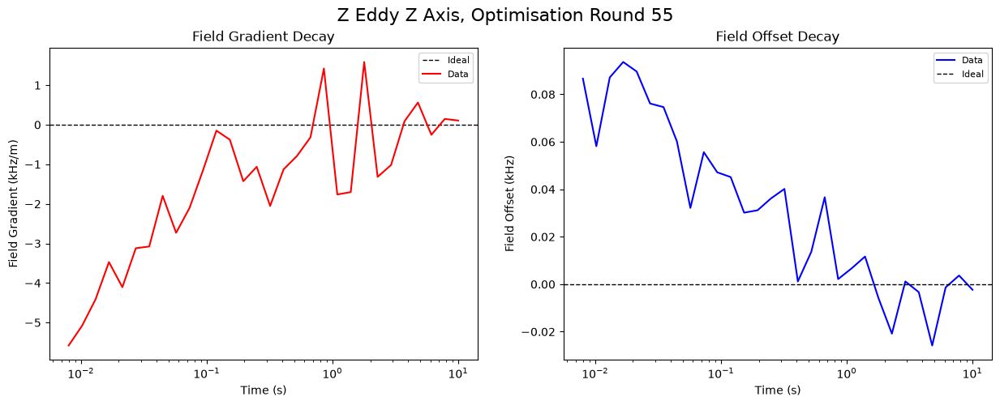

[I 2026-11-24 17:12:23,573] Trial 55 finished with value: 5925.4967915326 and parameters: {'Z_A1': 0.06737317092178, 'Z_A2': 0.03904065811279506, 'Z_A3': 0.07446034417240127, 'Z_A4': 1.8637839407814517e-11}. Best is trial 43 with value: 3898.915706473114.


max |E| = 6016.991504247873
mean |E| = 3014.8259203731454
RMS E = 3390.7101336682595
Total cost = 5.925e+03
E max = 0.11802097816407237
E nanmax = 0.11802097816407237
E contains nan = False
B max = 0.01278551695483355
B nanmax = 0.01278551695483355
B contains nan = False
Trial 56


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01278551695483355 !!!!!!!!!!!!!!!!


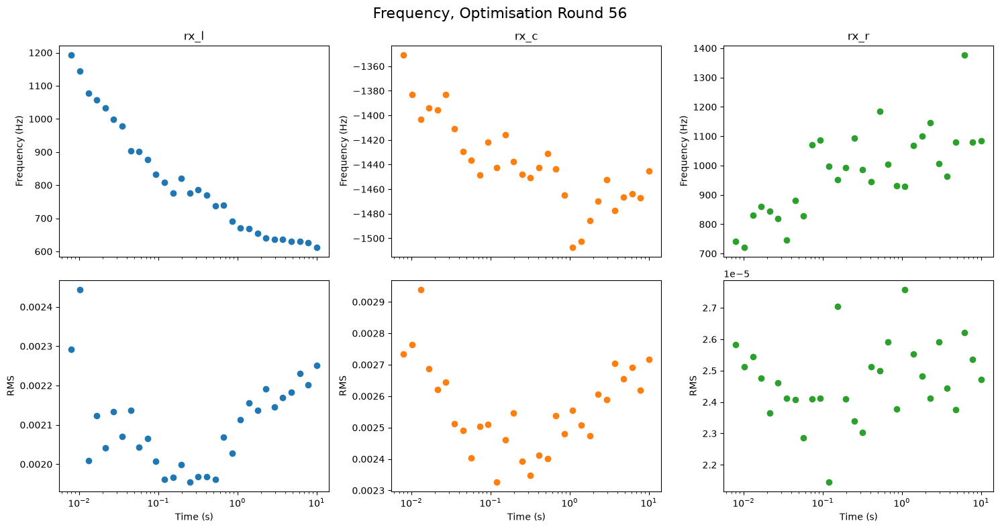

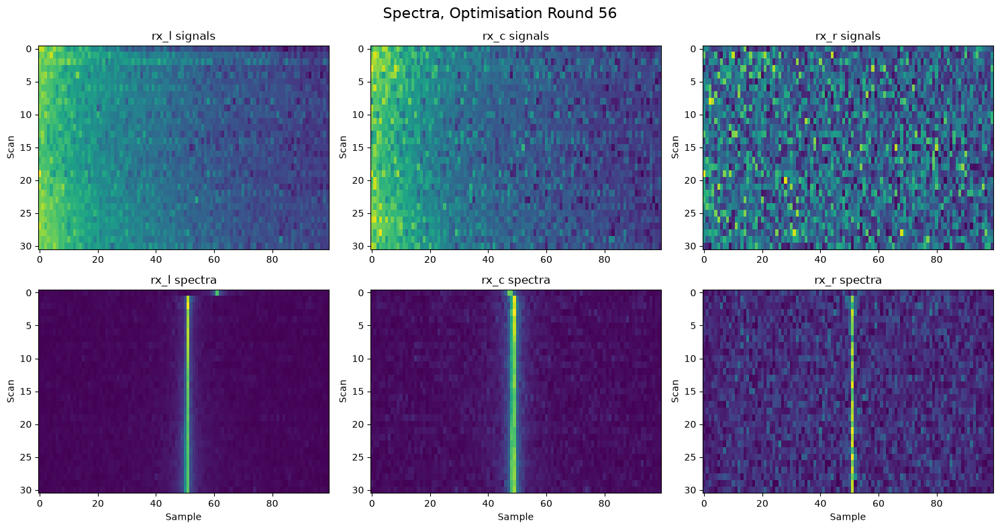

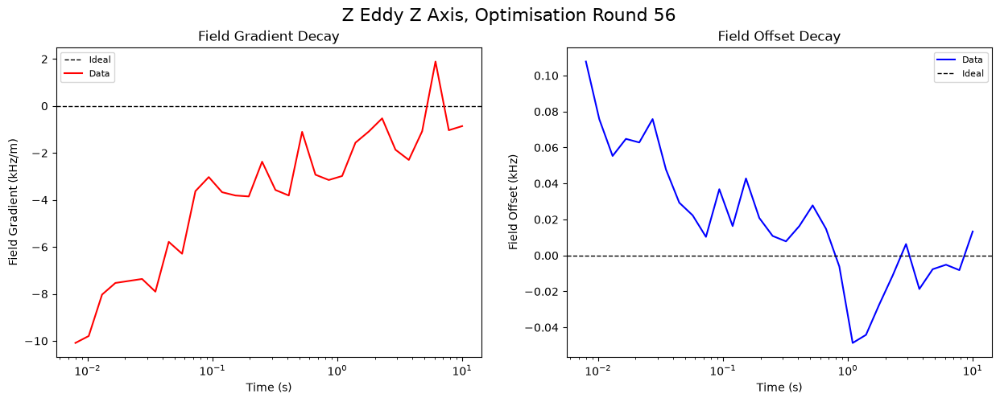

[I 2026-11-24 17:13:11,844] Trial 56 finished with value: 15816.136469660905 and parameters: {'Z_A1': 0.05933261430909807, 'Z_A2': 0.030063057699314253, 'Z_A3': 0.07383796523479537, 'Z_A4': 5.743070608538577e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 7456.271864067964
mean |E| = 3023.3216724970844
RMS E = 3375.4825485788388
Total cost = 1.582e+04
E max = 0.1202574824800736
E nanmax = 0.1202574824800736
E contains nan = False
B max = 0.013027825358930219
B nanmax = 0.013027825358930219
B contains nan = False
Trial 57


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013027825358930219 !!!!!!!!!!!!!!!!


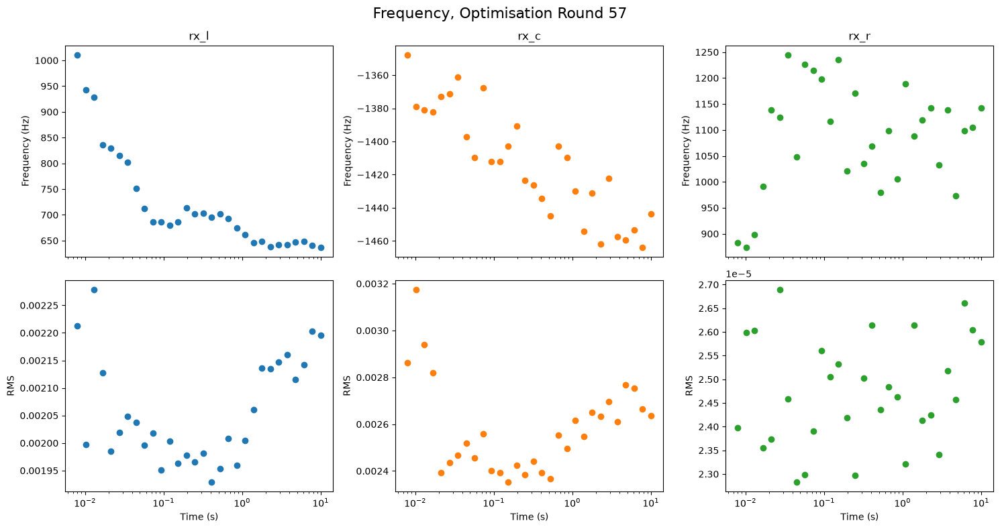

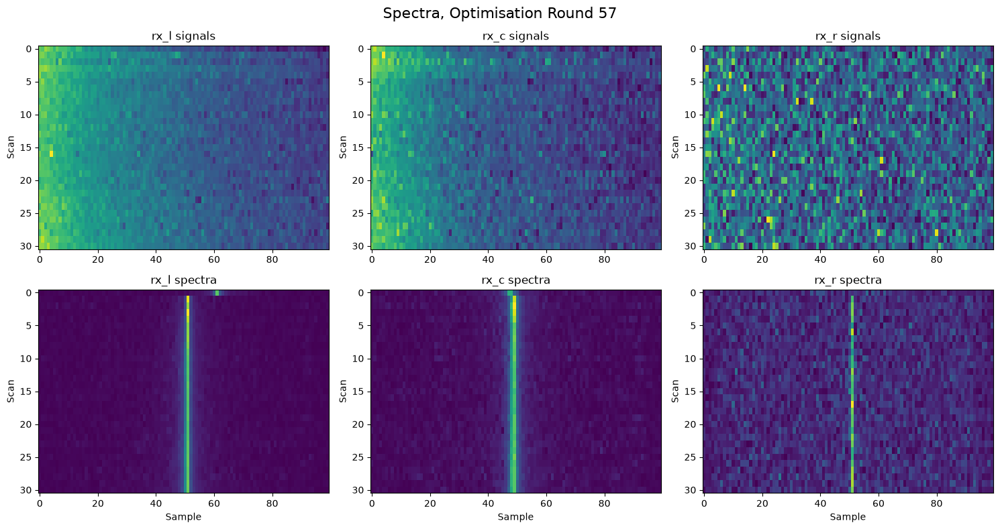

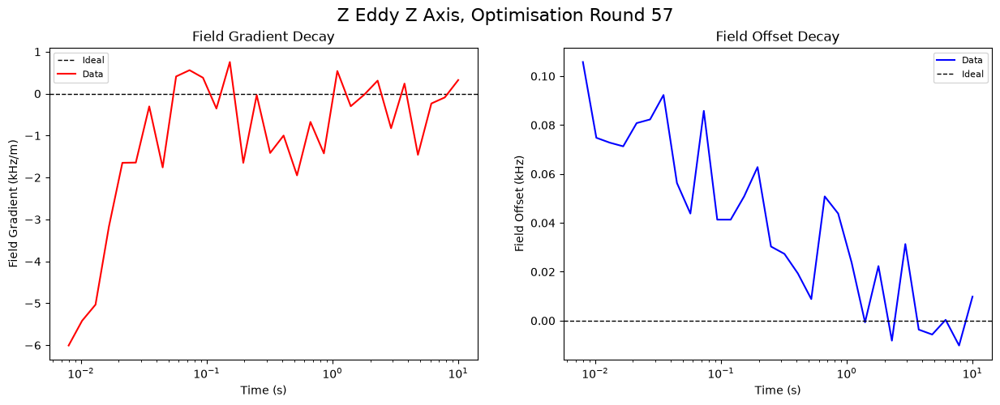

[I 2026-11-24 17:14:00,221] Trial 57 finished with value: 4998.683099630532 and parameters: {'Z_A1': 0.06945647497191516, 'Z_A2': 0.04279015800775622, 'Z_A3': 0.06885131951941104, 'Z_A4': 6.197888808414045e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5482.258870564717
mean |E| = 3782.608695652173
RMS E = 4023.6592324552867
Total cost = 4.999e+03
E max = 0.11876204932838329
E nanmax = 0.11876204932838329
E contains nan = False
B max = 0.012865803117618726
B nanmax = 0.012865803117618726
B contains nan = False
Trial 58


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012865803117618726 !!!!!!!!!!!!!!!!


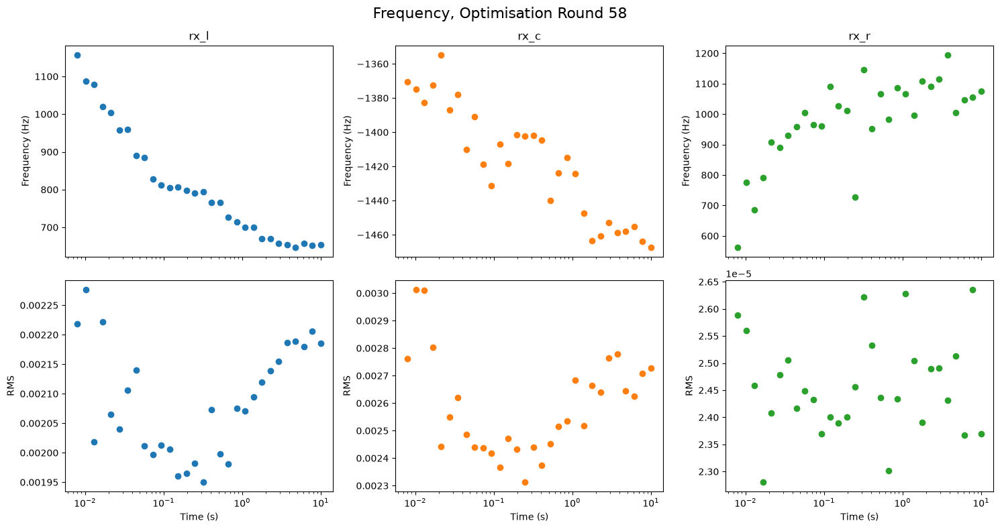

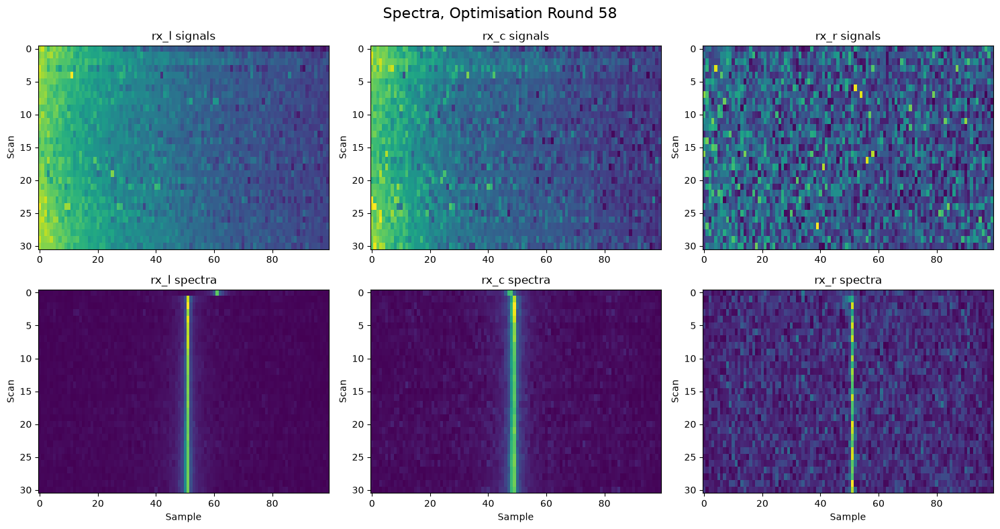

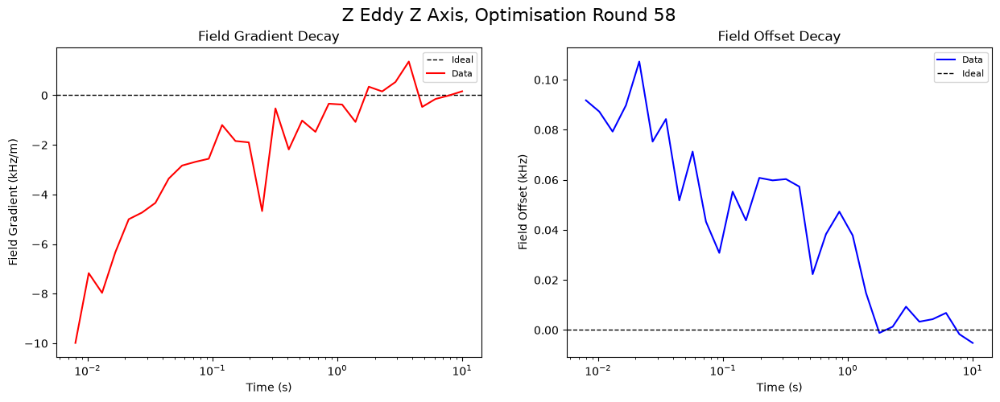

[I 2026-11-24 17:14:48,563] Trial 58 finished with value: 4911.764515632113 and parameters: {'Z_A1': 0.060228804799299006, 'Z_A2': 0.03617877334712982, 'Z_A3': 0.07288970418212036, 'Z_A4': 1.7067058357373322e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5942.028985507243
mean |E| = 2844.244544394468
RMS E = 3201.1620285672207
Total cost = 4.912e+03
E max = 0.1194746913607776
E nanmax = 0.1194746913607776
E contains nan = False
B max = 0.012943009043390035
B nanmax = 0.012943009043390035
B contains nan = False
Trial 59


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012943009043390035 !!!!!!!!!!!!!!!!


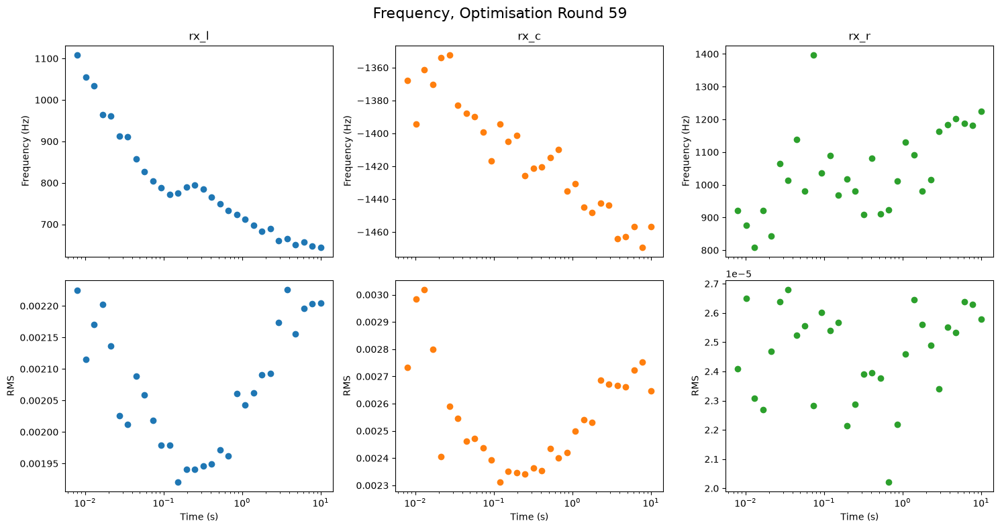

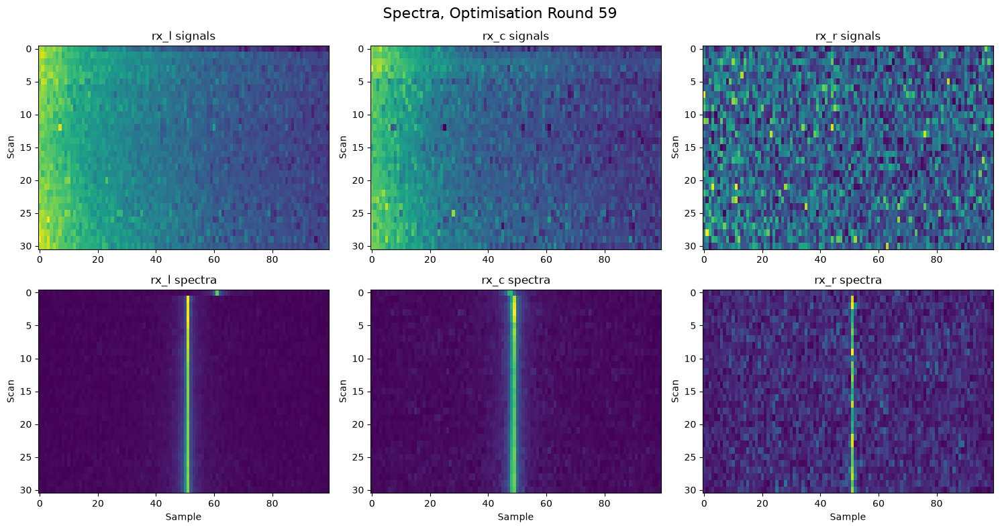

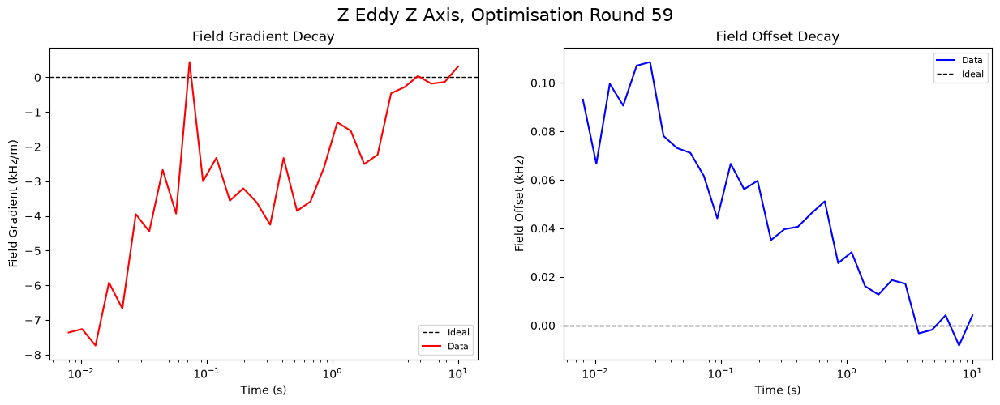

[I 2026-11-24 17:15:36,654] Trial 59 finished with value: 7941.36546453713 and parameters: {'Z_A1': 0.061056396081834004, 'Z_A2': 0.04180456907311366, 'Z_A3': 0.0721944661775725, 'Z_A4': 6.351124898650014e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5922.038980509744
mean |E| = 2980.3431617524566
RMS E = 3376.3015127367958
Total cost = 7.941e+03
E max = 0.12245862926563045
E nanmax = 0.12245862926563045
E contains nan = False
B max = 0.013266269303455282
B nanmax = 0.013266269303455282
B contains nan = False
Trial 60


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013266269303455282 !!!!!!!!!!!!!!!!


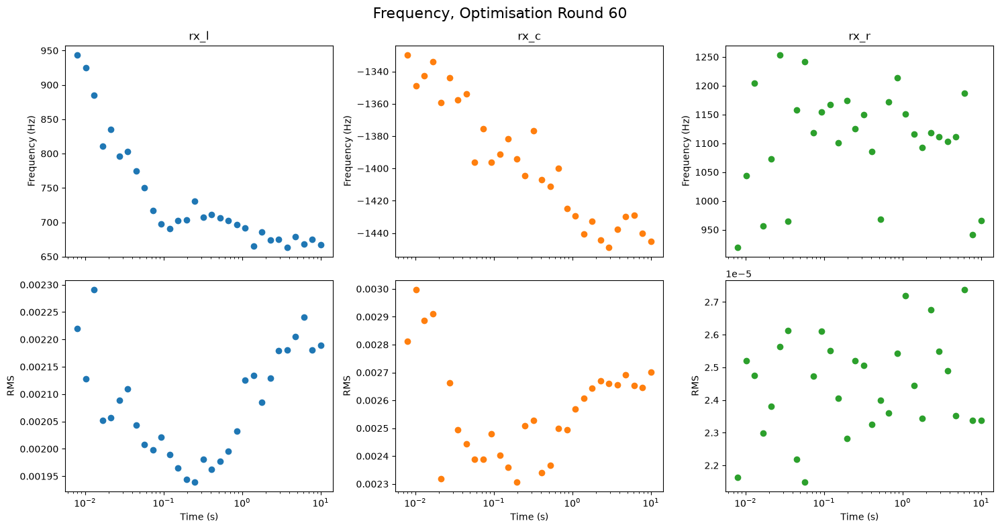

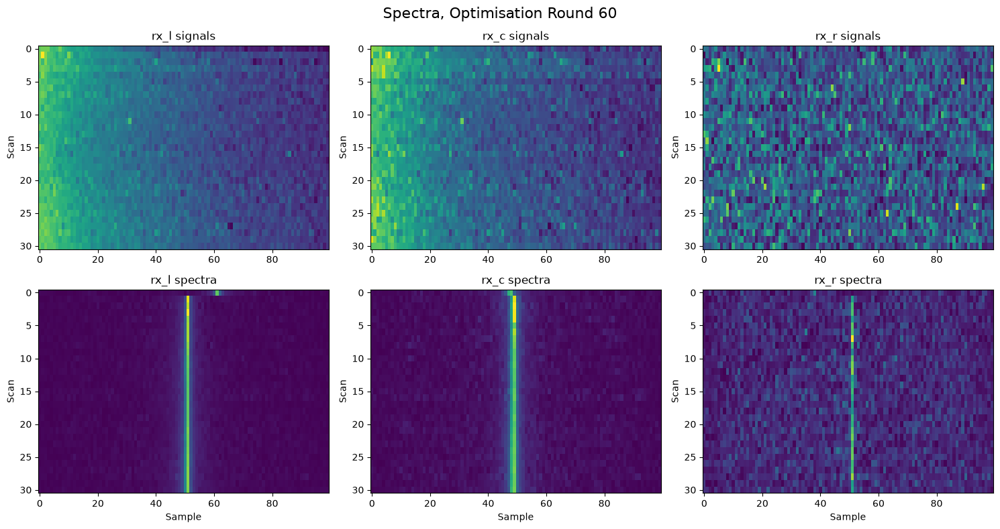

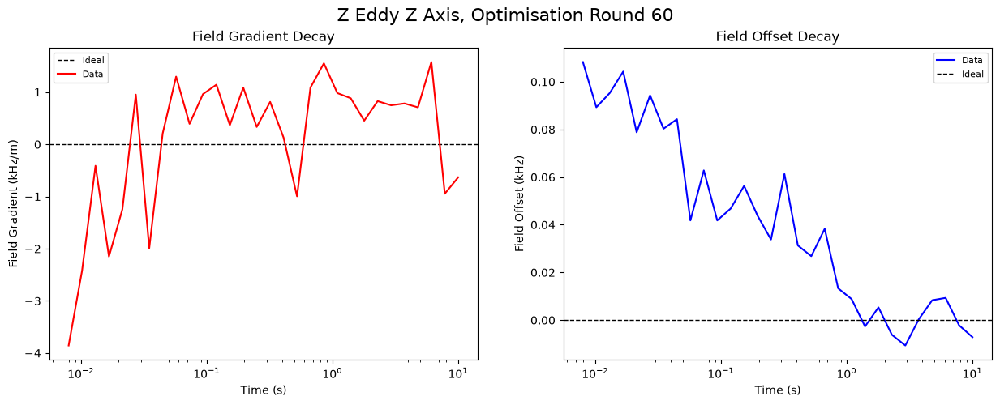

[I 2026-11-24 17:16:24,607] Trial 60 finished with value: 9219.255150235145 and parameters: {'Z_A1': 0.0734192395349002, 'Z_A2': 0.03666285144238941, 'Z_A3': 0.08814952902898006, 'Z_A4': 3.203007990973834e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5192.403798100947
mean |E| = 3718.973846410127
RMS E = 3924.1351251552314
Total cost = 9.219e+03
E max = 0.12076593638615497
E nanmax = 0.12076593638615497
E contains nan = False
B max = 0.013082885381534402
B nanmax = 0.013082885381534402
B contains nan = False
Trial 61


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013082885381534402 !!!!!!!!!!!!!!!!


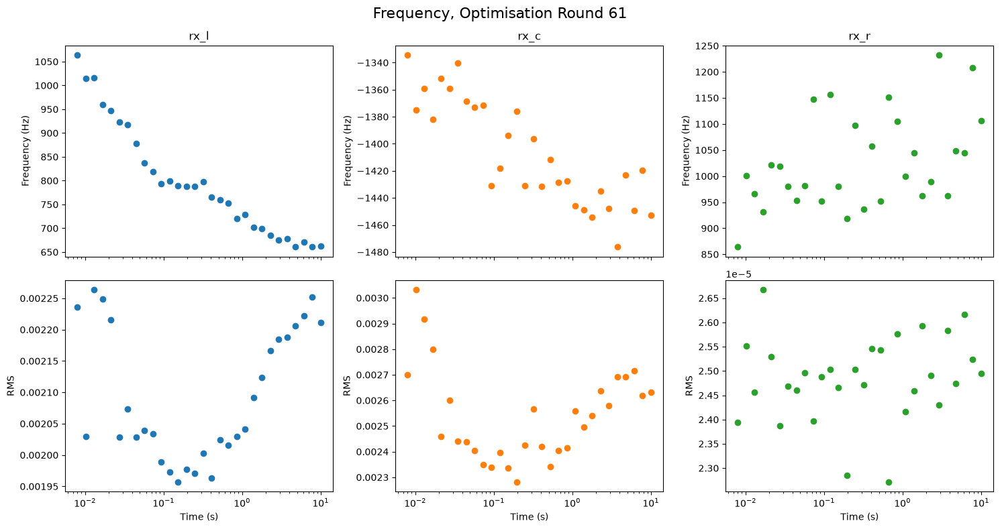

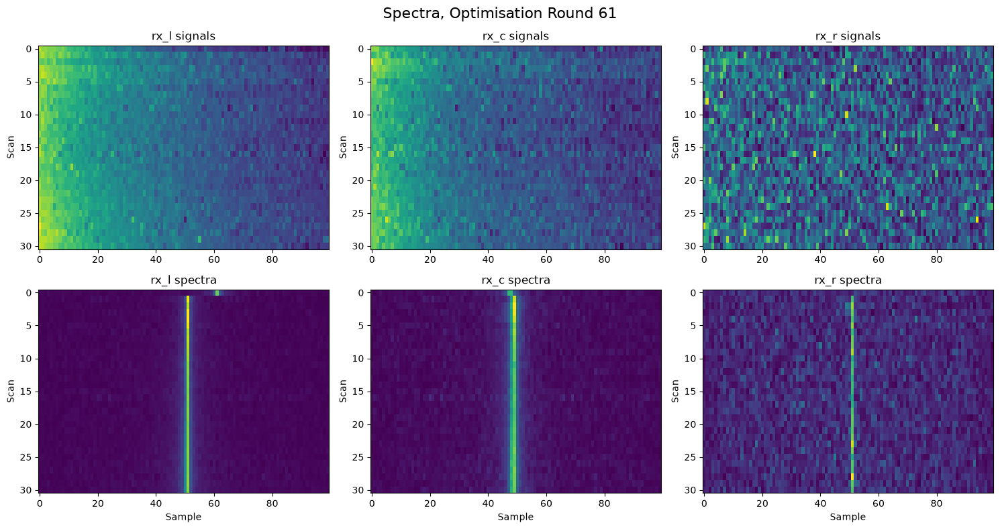

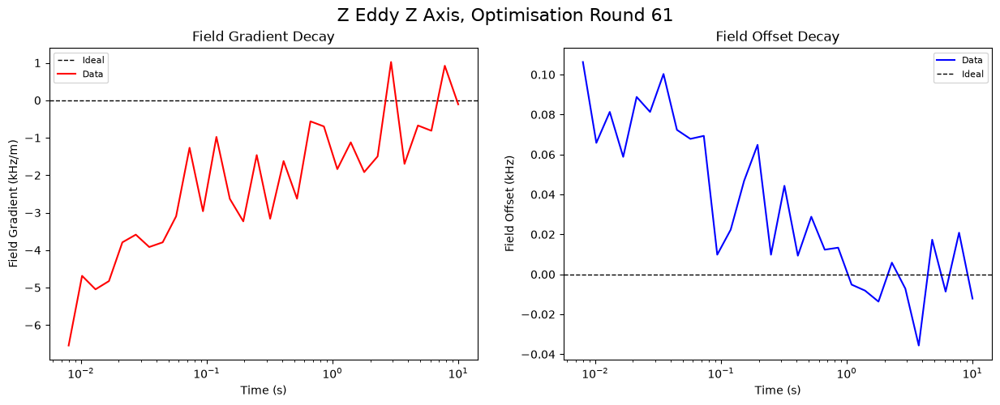

[I 2026-11-24 17:17:12,528] Trial 61 finished with value: 10539.640700965509 and parameters: {'Z_A1': 0.0636660511837805, 'Z_A2': 0.03708943143195351, 'Z_A3': 0.08446240417862795, 'Z_A4': 4.788886148190825e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5567.216391804096
mean |E| = 2466.7666166916533
RMS E = 2872.2554585988732
Total cost = 1.054e+04
E max = 0.12210514802144555
E nanmax = 0.12210514802144555
E contains nan = False
B max = 0.013227975176239281
B nanmax = 0.013227975176239281
B contains nan = False
Trial 62


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013227975176239281 !!!!!!!!!!!!!!!!


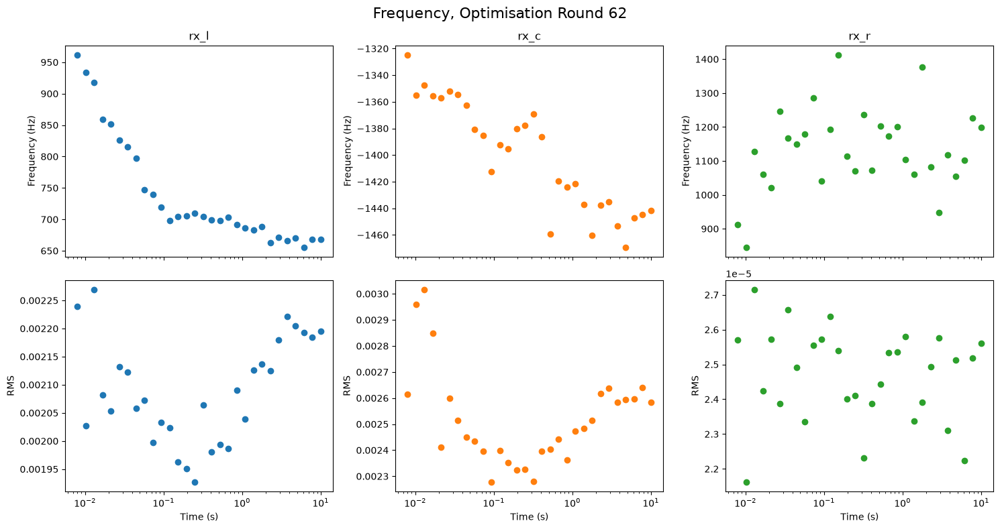

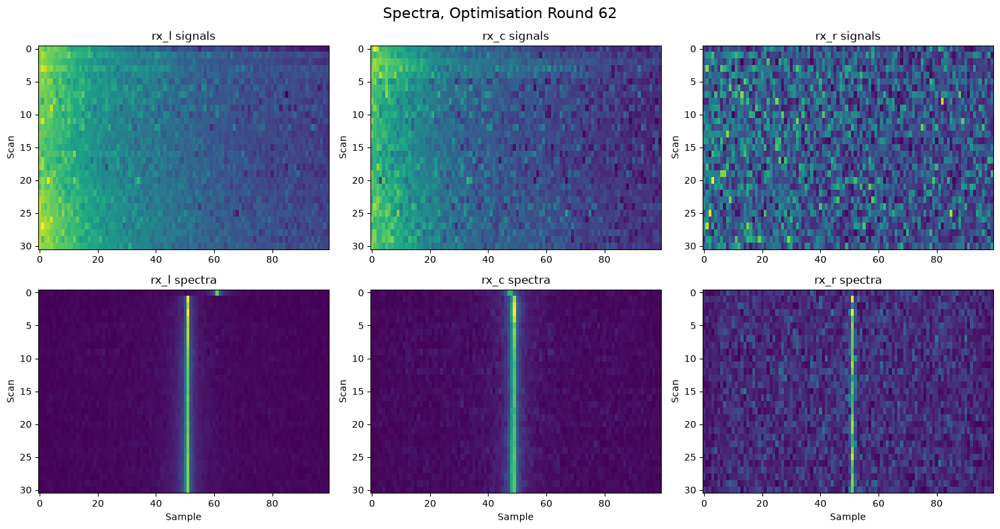

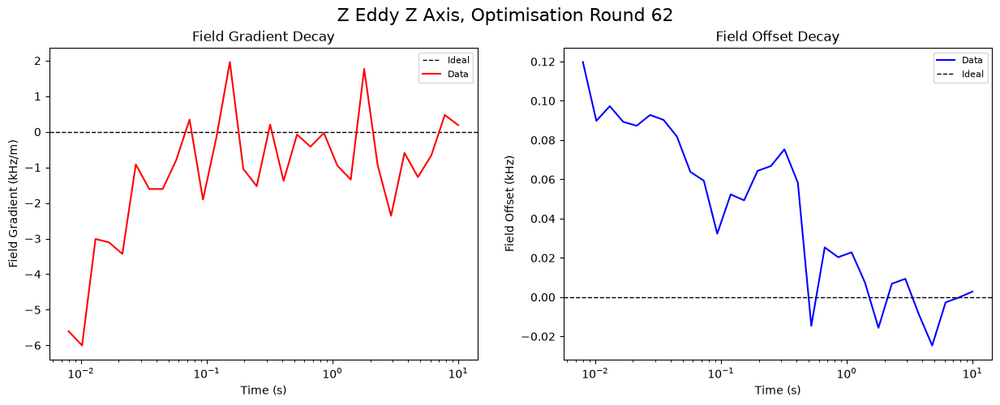

[I 2026-11-24 17:18:00,544] Trial 62 finished with value: 8564.767583991466 and parameters: {'Z_A1': 0.07363484971808006, 'Z_A2': 0.03371523875385076, 'Z_A3': 0.08807147798537768, 'Z_A4': 5.82463463426709e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 7081.459270364815
mean |E| = 4018.157587872729
RMS E = 4291.716525031417
Total cost = 8.565e+03
E max = 0.12063116878035249
E nanmax = 0.12063116878035249
E contains nan = False
B max = 0.013068306306724524
B nanmax = 0.013068306306724524
B contains nan = False
Trial 63


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013068306306724524 !!!!!!!!!!!!!!!!


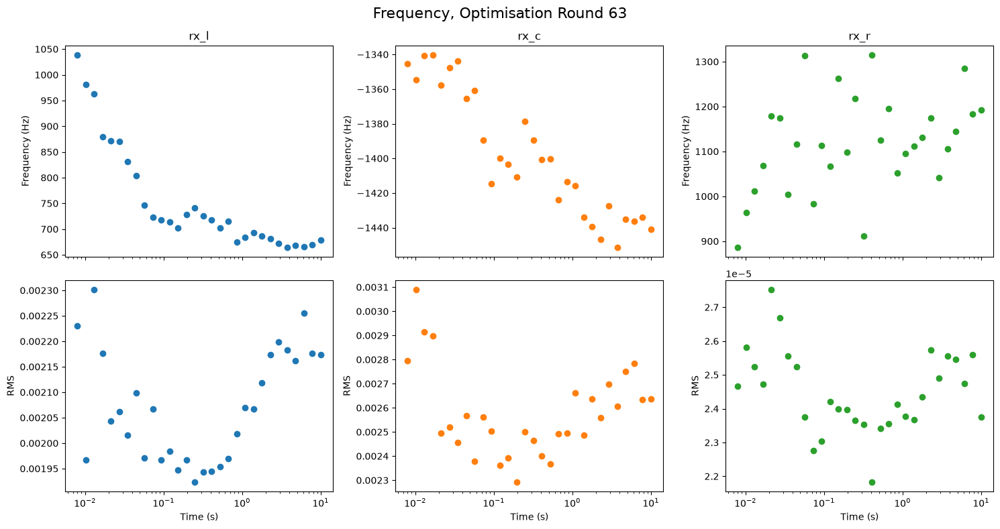

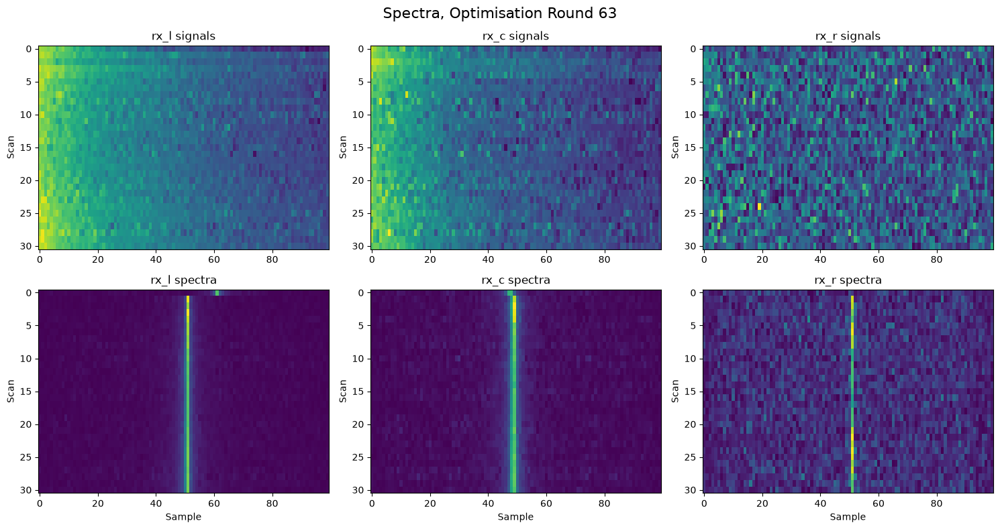

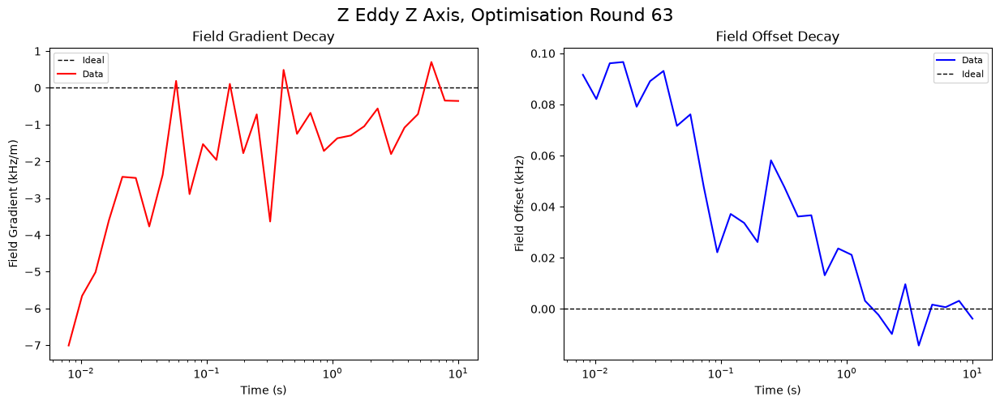

[I 2026-11-24 17:18:48,633] Trial 63 finished with value: 8303.369031780112 and parameters: {'Z_A1': 0.07288977563827785, 'Z_A2': 0.036796303433196495, 'Z_A3': 0.07425444258961078, 'Z_A4': 5.867170446521022e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 6191.9040479760115
mean |E| = 3750.291520906212
RMS E = 4051.325933757326
Total cost = 8.303e+03
E max = 0.11955936755776955
E nanmax = 0.11955936755776955
E contains nan = False
B max = 0.012952183473109896
B nanmax = 0.012952183473109896
B contains nan = False
Trial 64


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012952183473109896 !!!!!!!!!!!!!!!!


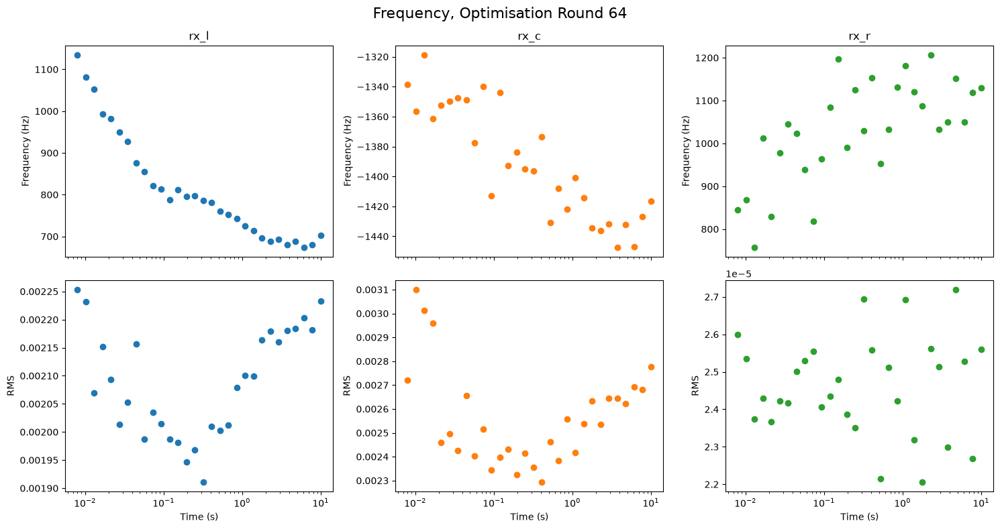

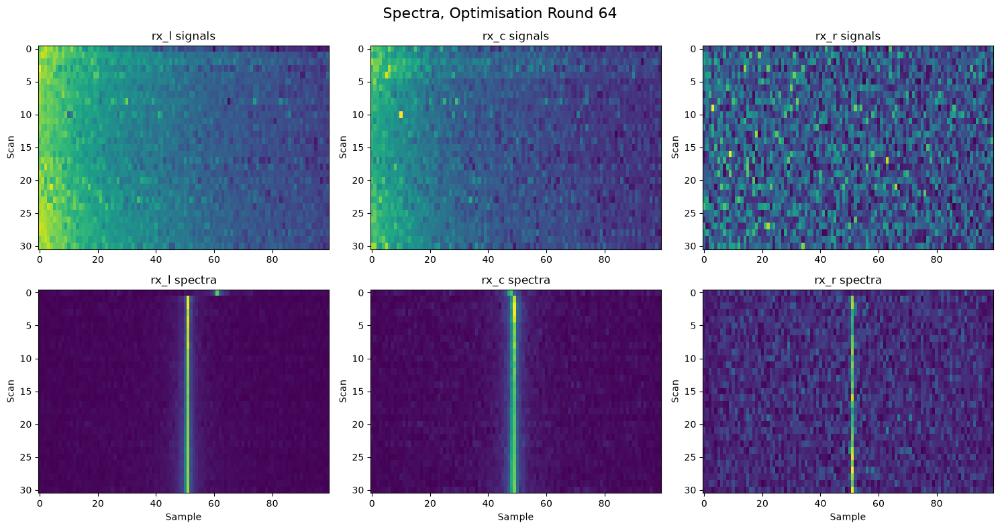

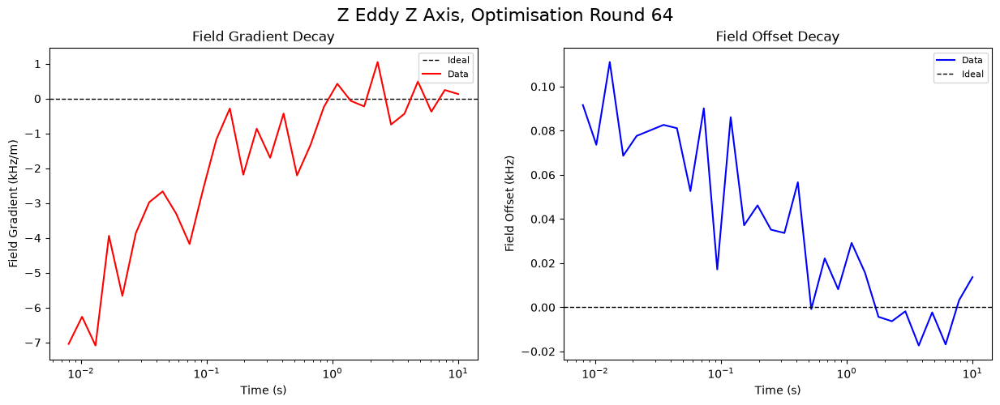

[I 2026-11-24 17:19:36,931] Trial 64 finished with value: 4848.40294079528 and parameters: {'Z_A1': 0.06419820091271539, 'Z_A2': 0.03716964114435319, 'Z_A3': 0.07426847866321765, 'Z_A4': 3.283327308412869e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5187.406296851574
mean |E| = 2790.438114276195
RMS E = 3126.015794733618
Total cost = 4.848e+03
E max = 0.11908284862201801
E nanmax = 0.11908284862201801
E contains nan = False
B max = 0.012900566794799418
B nanmax = 0.012900566794799418
B contains nan = False
Trial 65


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012900566794799418 !!!!!!!!!!!!!!!!


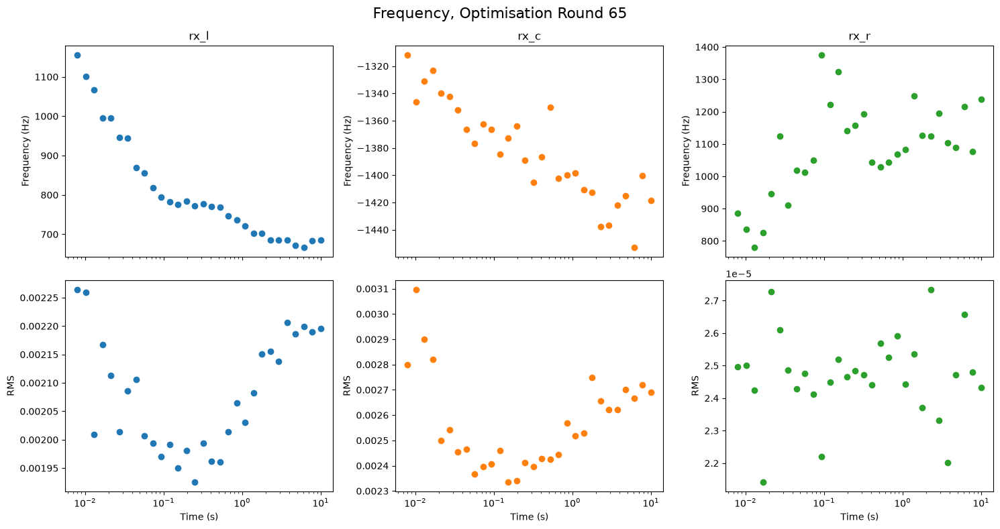

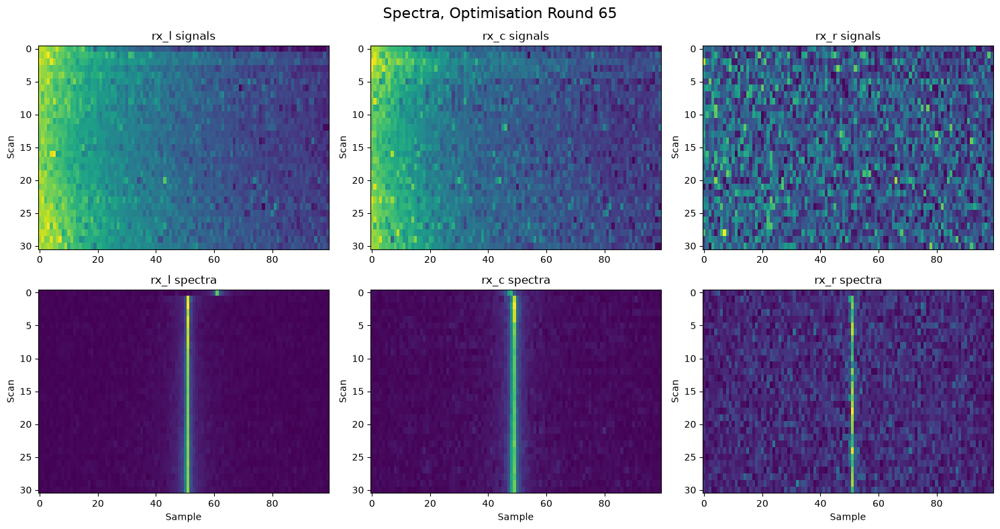

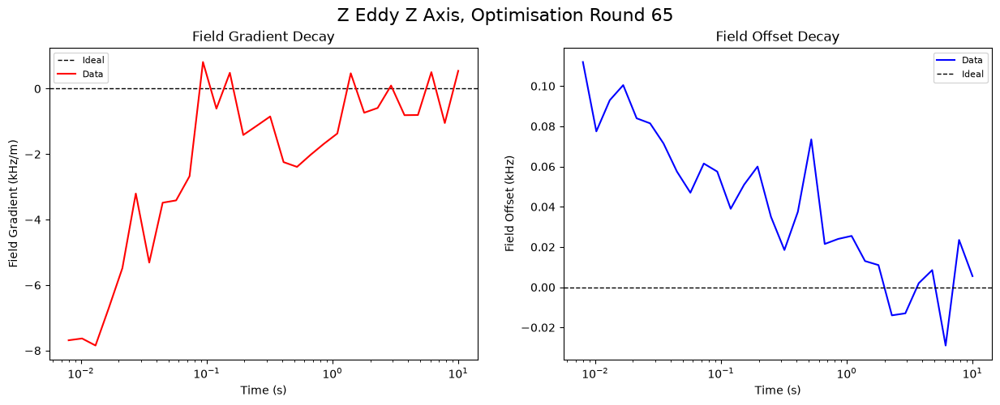

[I 2026-11-24 17:20:24,981] Trial 65 finished with value: 8180.432137157792 and parameters: {'Z_A1': 0.06663835977222413, 'Z_A2': 0.03501679084958202, 'Z_A3': 0.07006109457728303, 'Z_A4': 4.1465523195690256e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5802.098950524735
mean |E| = 3428.4524404464414
RMS E = 3731.8796103539826
Total cost = 8.180e+03
E max = 0.12073678464990556
E nanmax = 0.12073678464990556
E contains nan = False
B max = 0.013079734983527935
B nanmax = 0.013079734983527935
B contains nan = False
Trial 66


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013079734983527935 !!!!!!!!!!!!!!!!


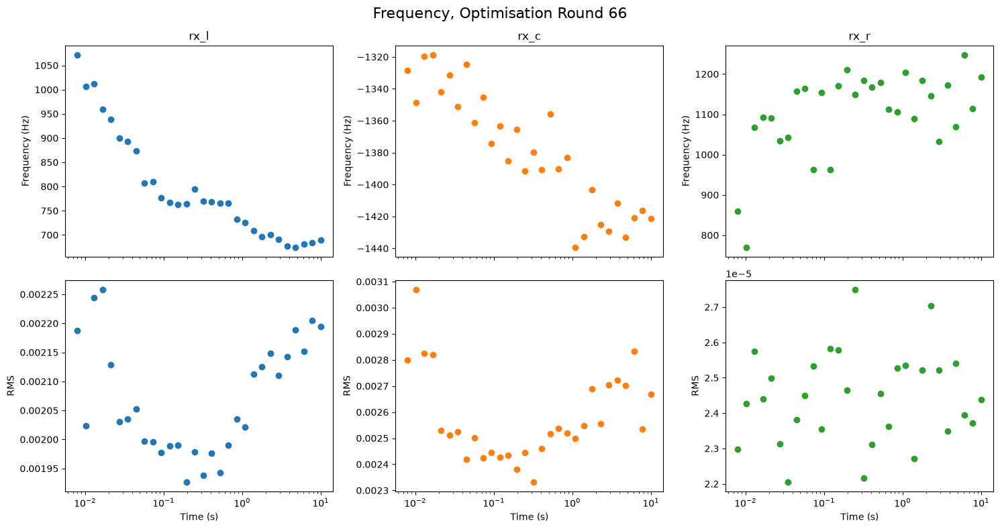

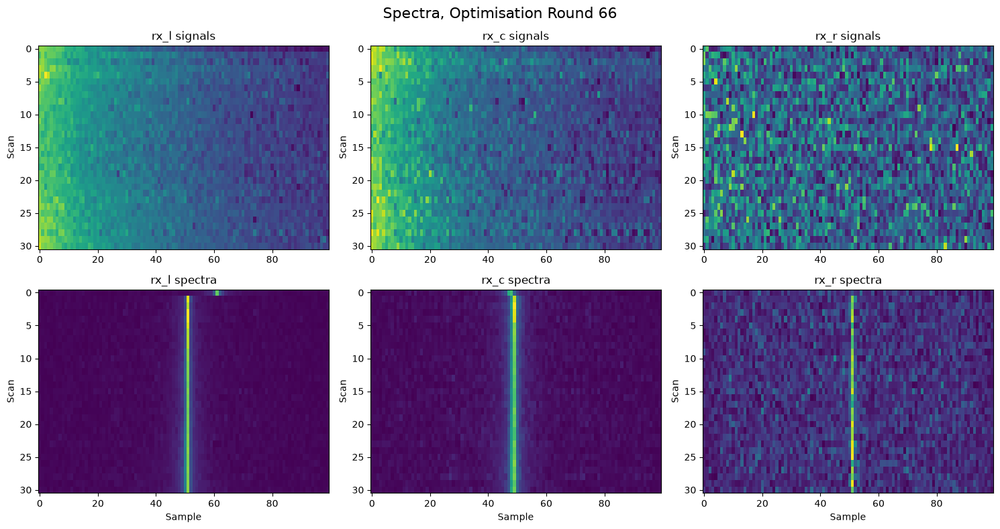

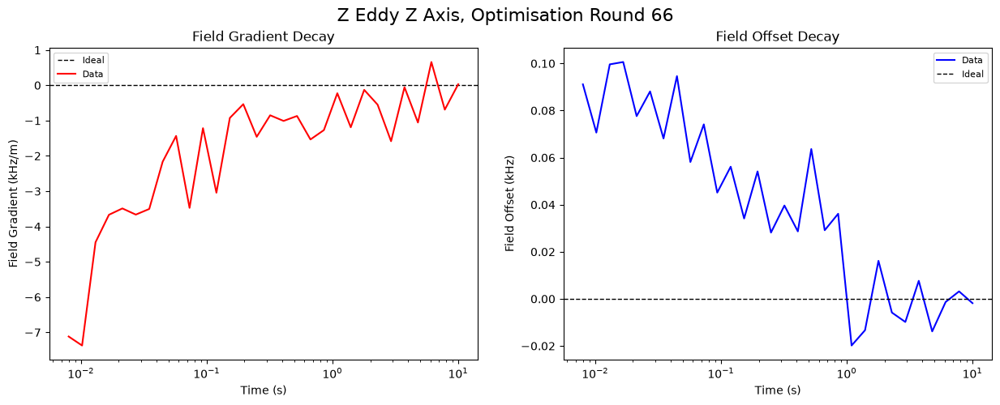

[I 2026-11-24 17:21:13,147] Trial 66 finished with value: 6988.410018212087 and parameters: {'Z_A1': 0.06717834429410324, 'Z_A2': 0.03690389863954647, 'Z_A3': 0.08084684744777135, 'Z_A4': 7.147735104234641e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5662.168915542227
mean |E| = 3373.8130934532724
RMS E = 3623.4026601479695
Total cost = 6.988e+03
E max = 0.11987956389023549
E nanmax = 0.11987956389023549
E contains nan = False
B max = 0.012986882421759686
B nanmax = 0.012986882421759686
B contains nan = False
Trial 67


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012986882421759686 !!!!!!!!!!!!!!!!


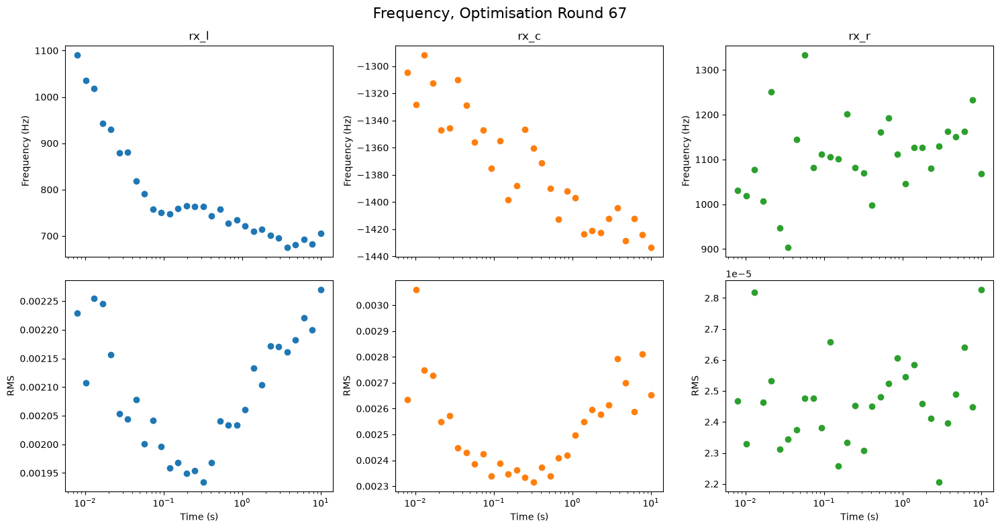

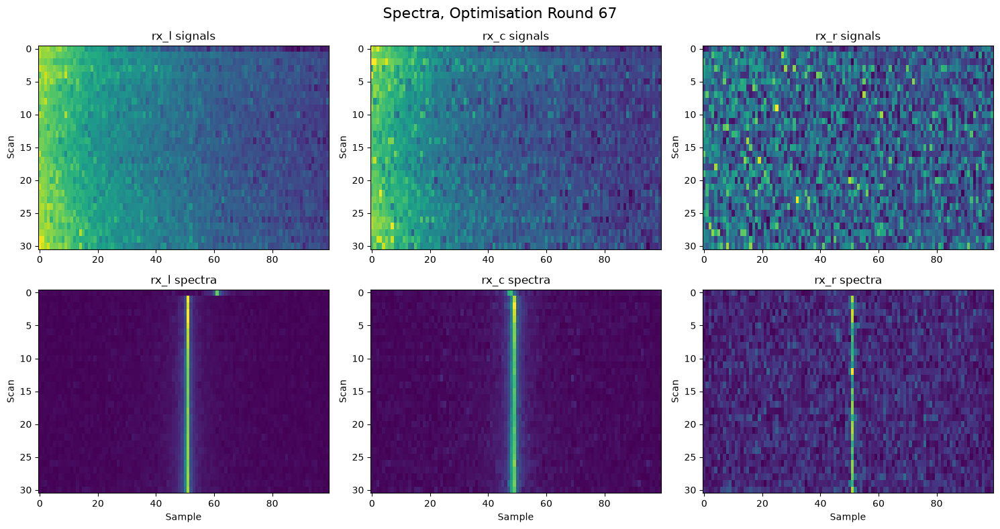

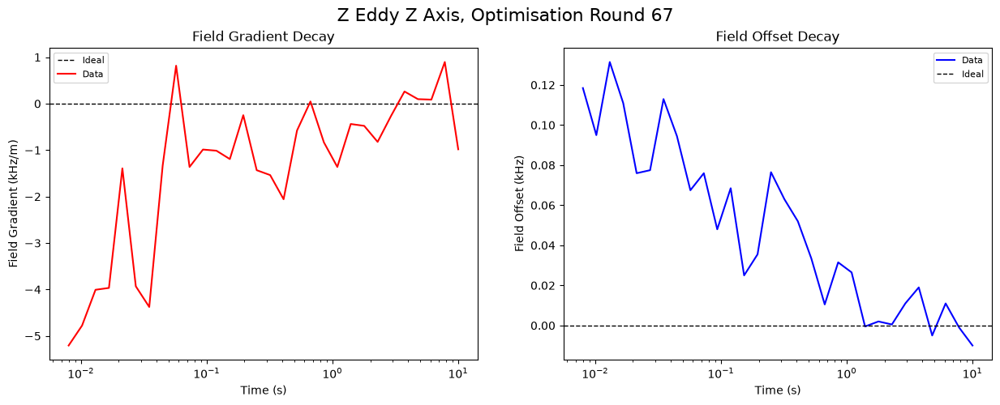

[I 2026-11-24 17:22:01,463] Trial 67 finished with value: 5655.714653141456 and parameters: {'Z_A1': 0.06817846038532914, 'Z_A2': 0.04136162113663773, 'Z_A3': 0.06857002235432402, 'Z_A4': 1.5111749978366628e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5502.248875562218
mean |E| = 3244.8775612193904
RMS E = 3590.2424852791323
Total cost = 5.656e+03
E max = 0.1204222974548843
E nanmax = 0.1204222974548843
E contains nan = False
B max = 0.013045670730458812
B nanmax = 0.013045670730458812
B contains nan = False
Trial 68


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013045670730458812 !!!!!!!!!!!!!!!!


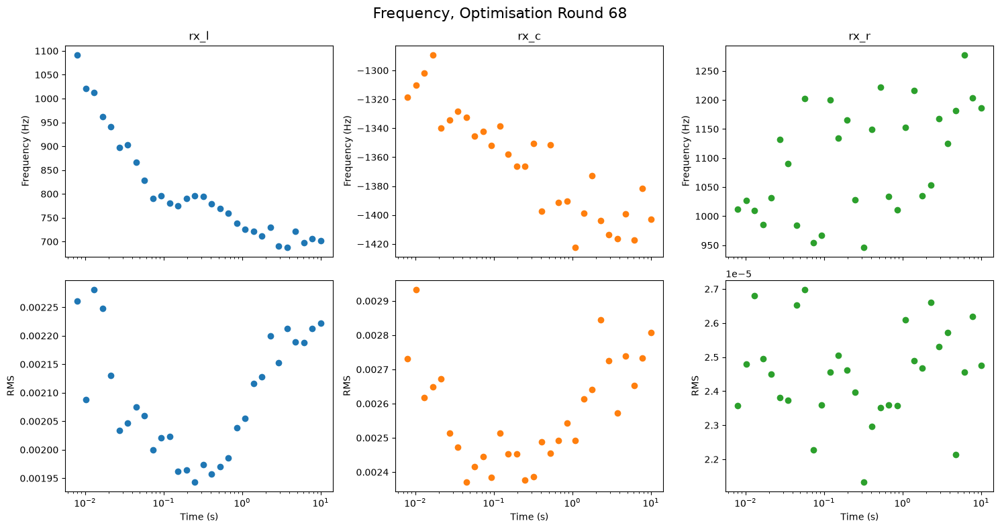

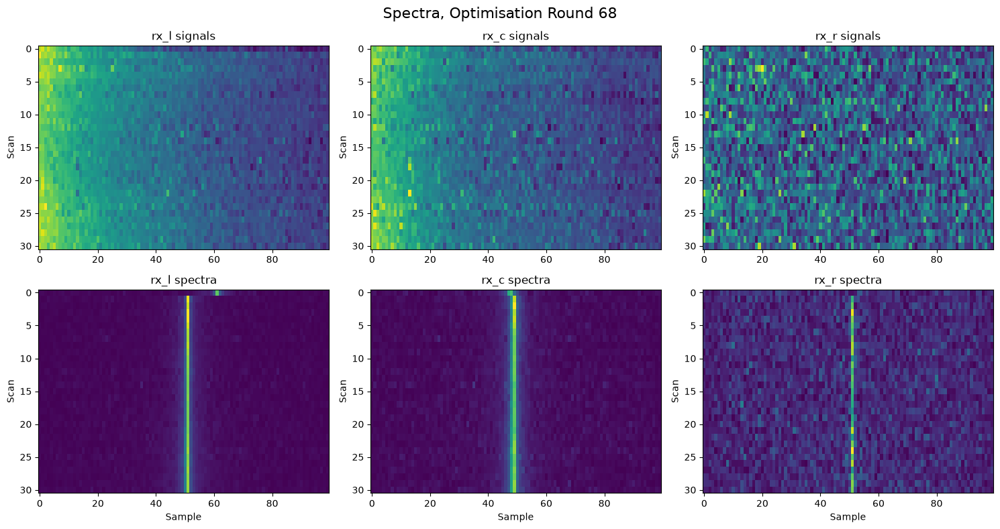

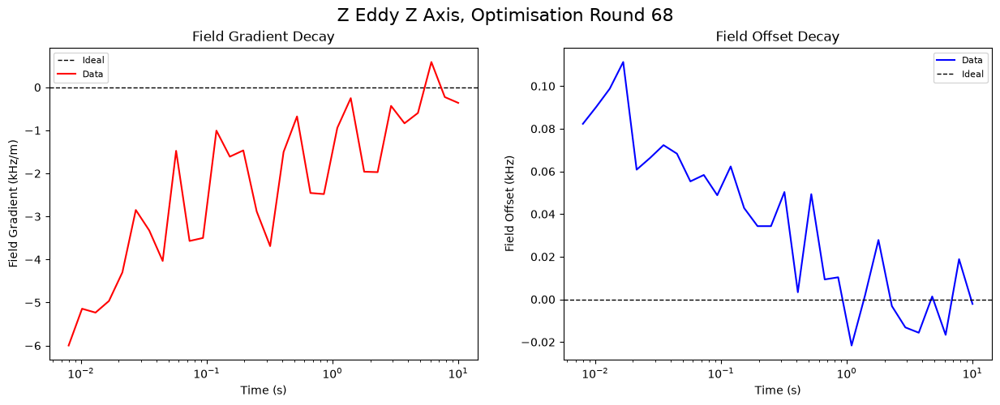

[I 2026-11-24 17:22:49,900] Trial 68 finished with value: 8009.4678234614785 and parameters: {'Z_A1': 0.06675919911189225, 'Z_A2': 0.040426800827168256, 'Z_A3': 0.07530355312336216, 'Z_A4': 3.315828887949166e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5792.103948025986
mean |E| = 2953.8564051307676
RMS E = 3373.0455653491613
Total cost = 8.009e+03
E max = 0.12030500339411694
E nanmax = 0.12030500339411694
E contains nan = False
B max = 0.013032953659696603
B nanmax = 0.013032953659696603
B contains nan = False
Trial 69


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013032953659696603 !!!!!!!!!!!!!!!!


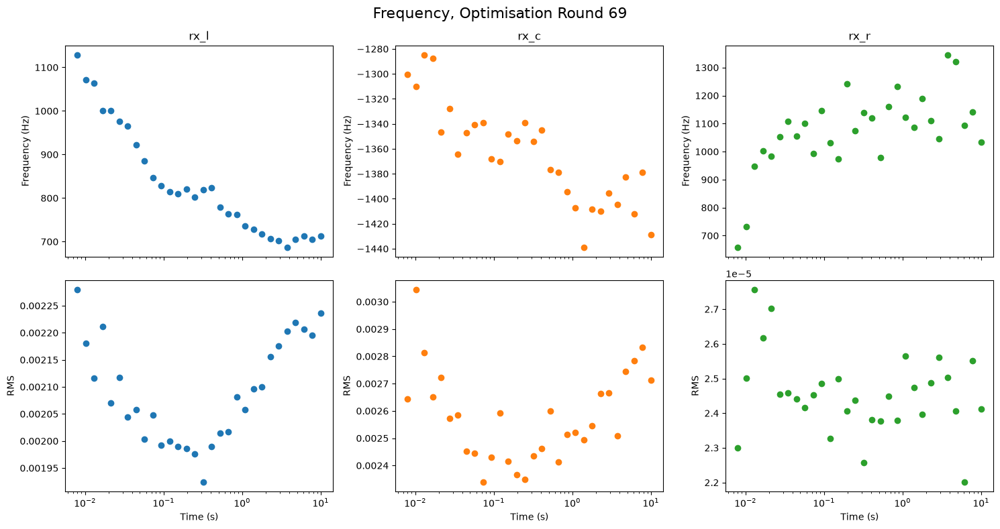

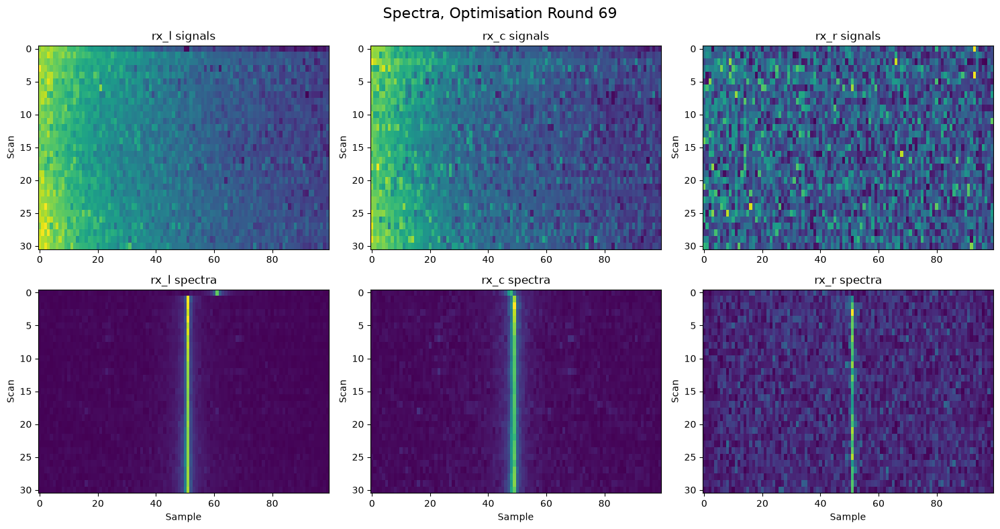

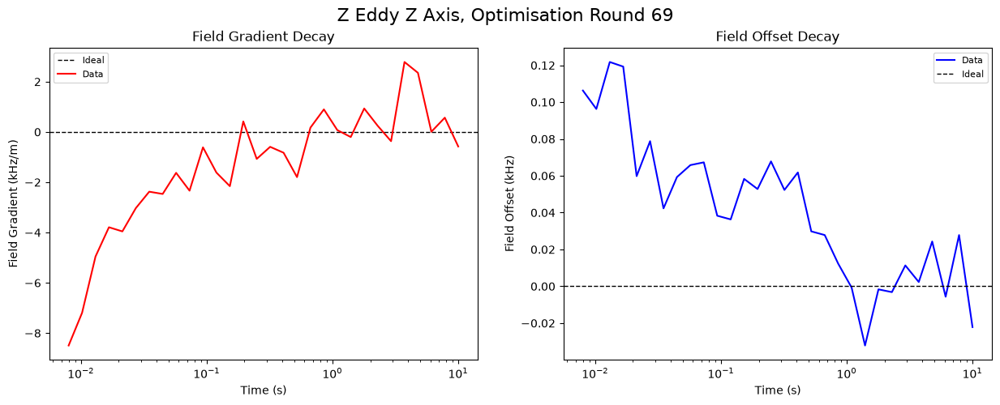

[I 2026-11-24 17:23:37,734] Trial 69 finished with value: 9063.126501680523 and parameters: {'Z_A1': 0.06482709945691065, 'Z_A2': 0.03427487160445209, 'Z_A3': 0.08241267517648945, 'Z_A4': 3.474569384506708e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 6576.71164417791
mean |E| = 3036.6483424954176
RMS E = 3430.1283423185164
Total cost = 9.063e+03
E max = 0.11914942868022059
E nanmax = 0.11914942868022059
E contains nan = False
B max = 0.012907781585557205
B nanmax = 0.012907781585557205
B contains nan = False
Trial 70


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012907781585557205 !!!!!!!!!!!!!!!!


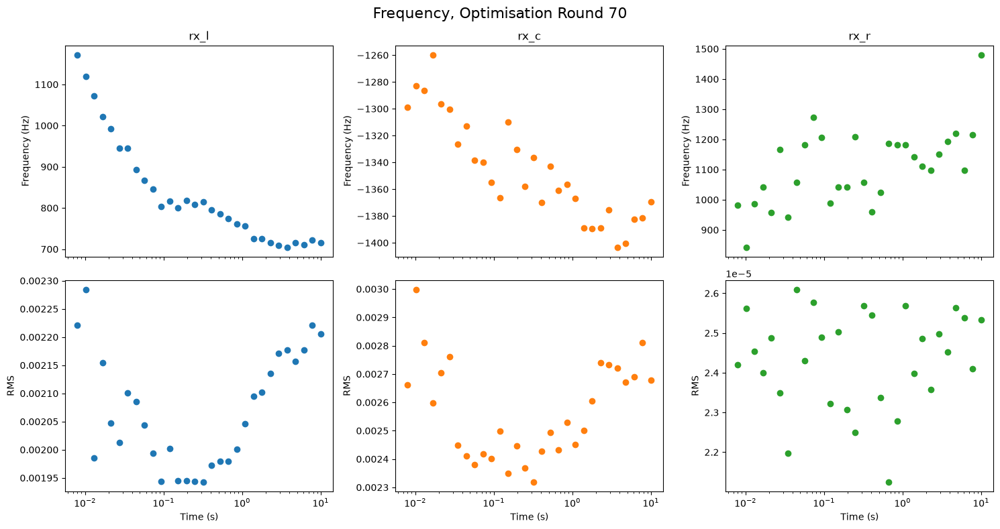

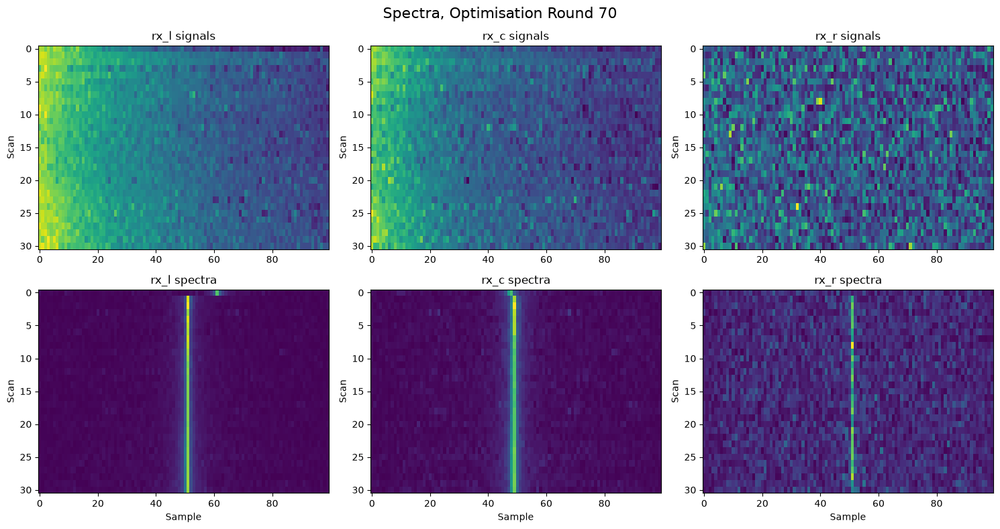

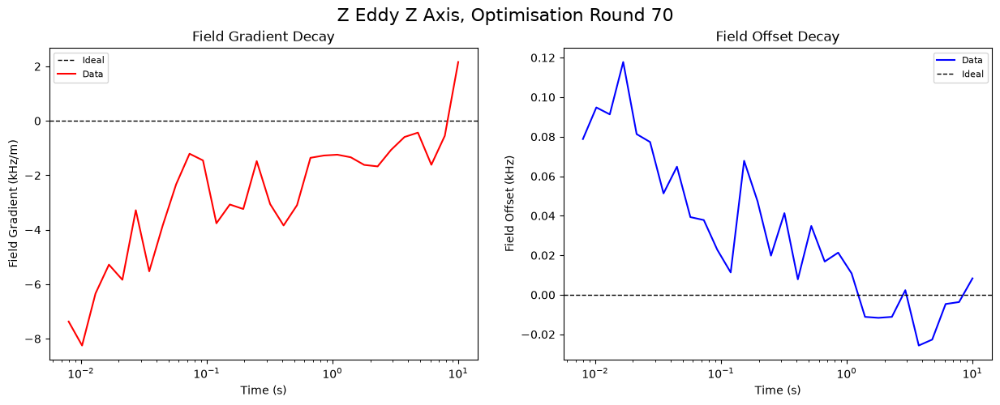

[I 2026-11-24 17:24:25,647] Trial 70 finished with value: 12493.87229149671 and parameters: {'Z_A1': 0.06613634932619726, 'Z_A2': 0.03823586051117201, 'Z_A3': 0.06791254724297252, 'Z_A4': 1.4679525991744267e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 7646.176911544226
mean |E| = 3116.441779110444
RMS E = 3534.0652597731323
Total cost = 1.249e+04
E max = 0.1208870554855765
E nanmax = 0.1208870554855765
E contains nan = False
B max = 0.013096008231301845
B nanmax = 0.013096008231301845
B contains nan = False
Trial 71


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013096008231301845 !!!!!!!!!!!!!!!!


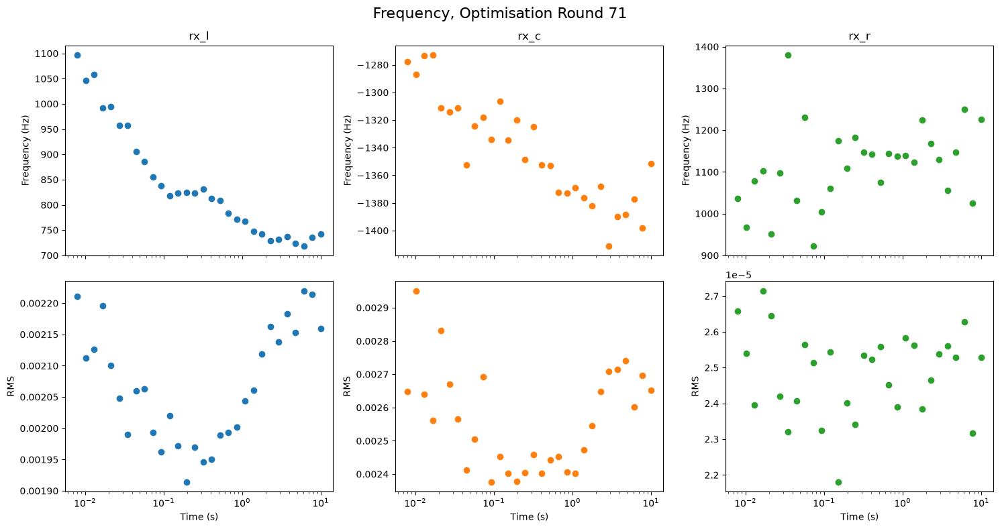

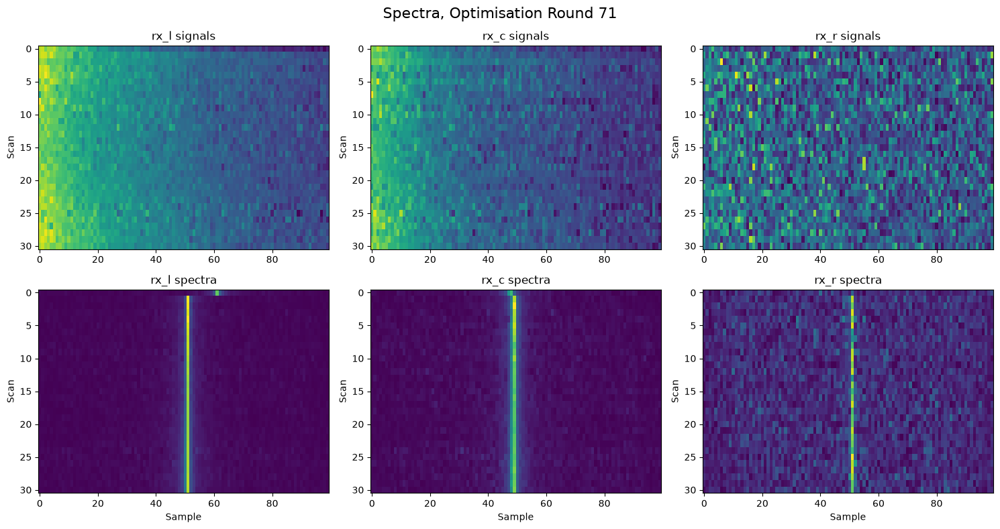

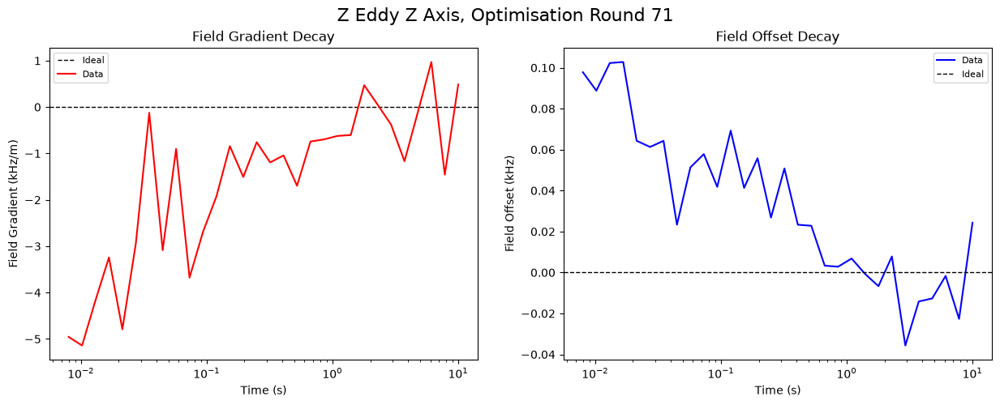

[I 2026-11-24 17:25:13,567] Trial 71 finished with value: 8107.109348695118 and parameters: {'Z_A1': 0.06486036127408655, 'Z_A2': 0.03695419190033051, 'Z_A3': 0.08433598082894558, 'Z_A4': 3.1808799512608882e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5322.338830584707
mean |E| = 2857.2380476428443
RMS E = 3199.7602474886835
Total cost = 8.107e+03
E max = 0.12014858918603151
E nanmax = 0.12014858918603151
E contains nan = False
B max = 0.013016012911675213
B nanmax = 0.013016012911675213
B contains nan = False
Trial 72


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013016012911675213 !!!!!!!!!!!!!!!!


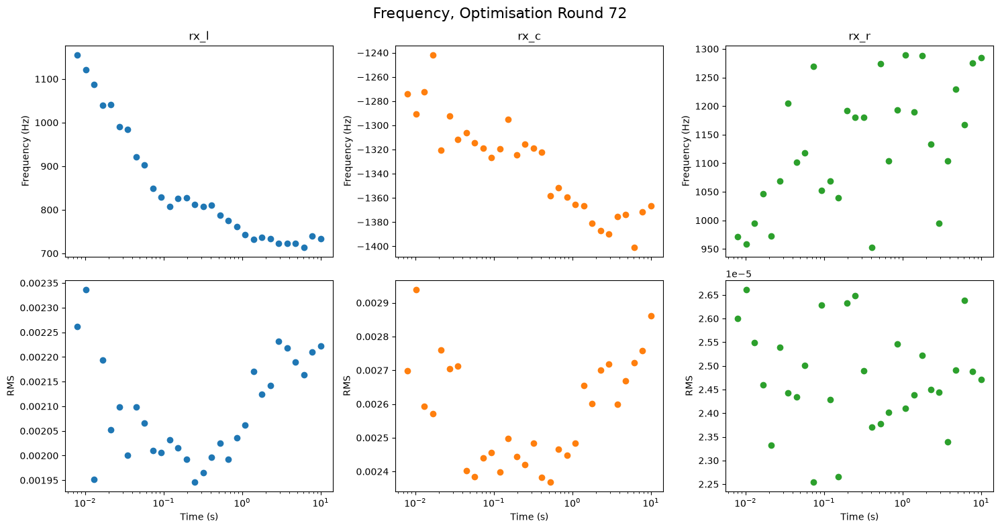

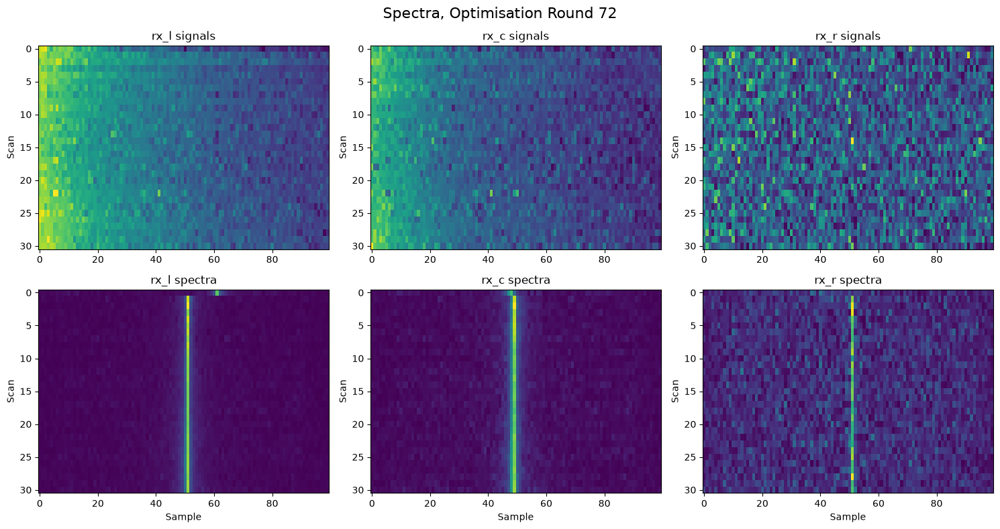

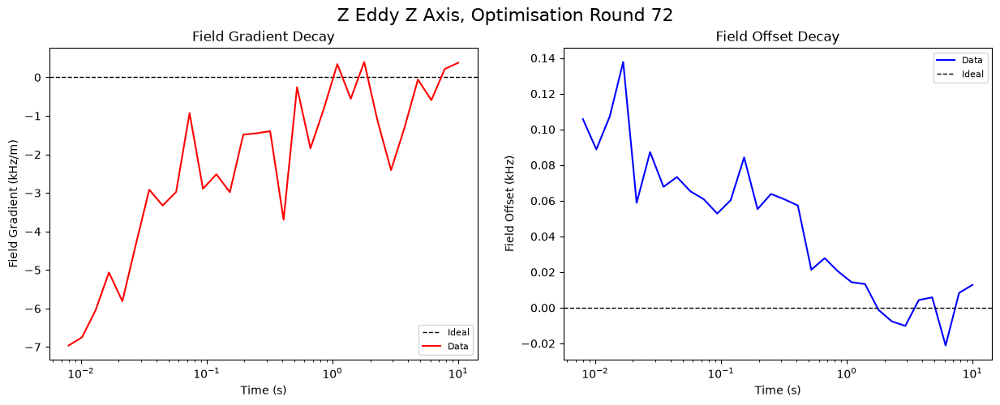

[I 2026-11-24 17:26:01,590] Trial 72 finished with value: 7537.221687098498 and parameters: {'Z_A1': 0.06870860576950268, 'Z_A2': 0.029335332044095618, 'Z_A3': 0.08205171091522932, 'Z_A4': 5.734176584090636e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5522.2388805597175
mean |E| = 3156.9215392303836
RMS E = 3533.5744268704325
Total cost = 7.537e+03
E max = 0.12065755000246212
E nanmax = 0.12065755000246212
E contains nan = False
B max = 0.013071141269295525
B nanmax = 0.013071141269295525
B contains nan = False
Trial 73


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013071141269295525 !!!!!!!!!!!!!!!!


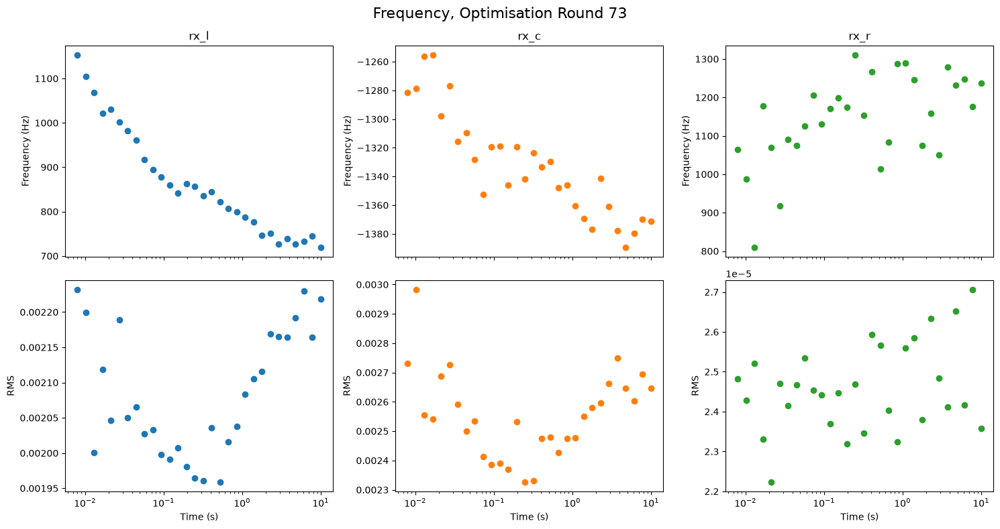

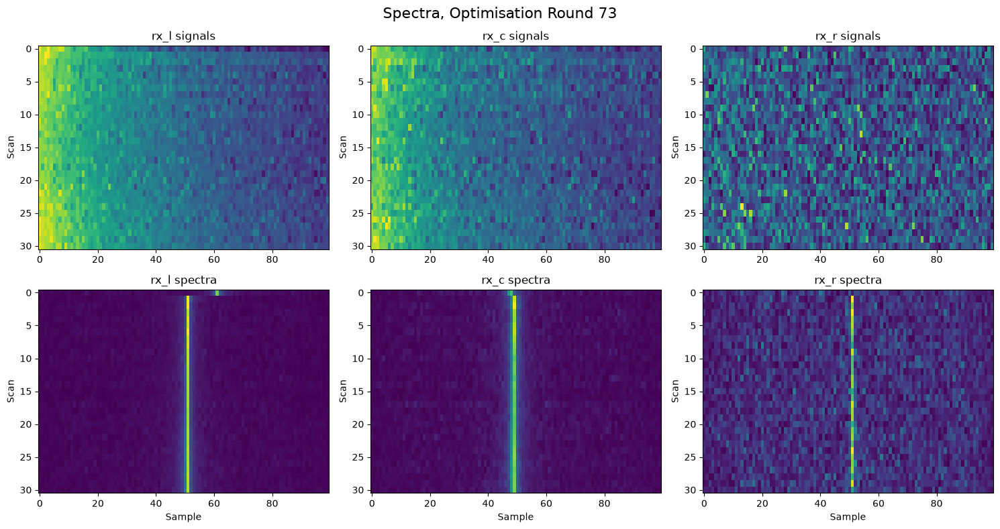

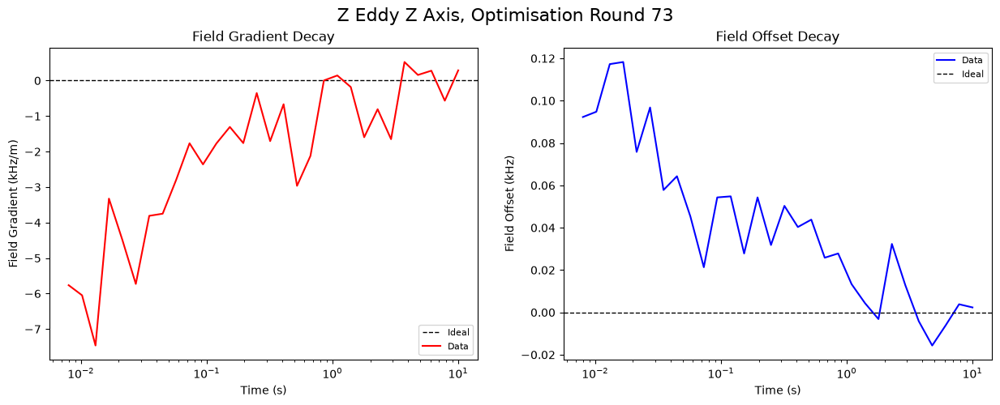

[I 2026-11-24 17:26:49,733] Trial 73 finished with value: 6453.72828548365 and parameters: {'Z_A1': 0.06405408500414825, 'Z_A2': 0.0336184802183333, 'Z_A3': 0.0866116795602196, 'Z_A4': 8.124968408069367e-09}. Best is trial 43 with value: 3898.915706473114.


max |E| = 5407.296351824086
mean |E| = 3136.7649508579043
RMS E = 3477.833853783137
Total cost = 6.454e+03
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013171346850447775
B nanmax = 0.013171346850447775
B contains nan = False
Trial 74


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013171346850447775 !!!!!!!!!!!!!!!!


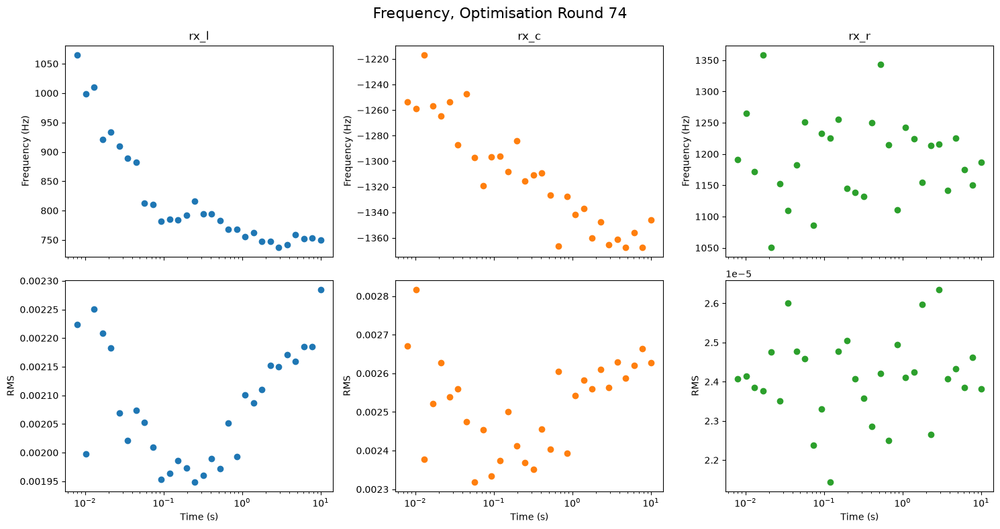

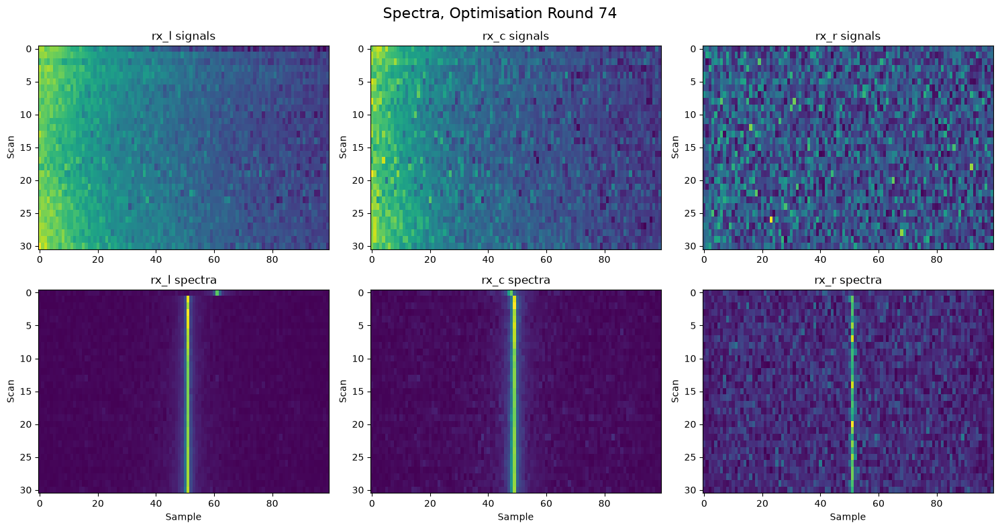

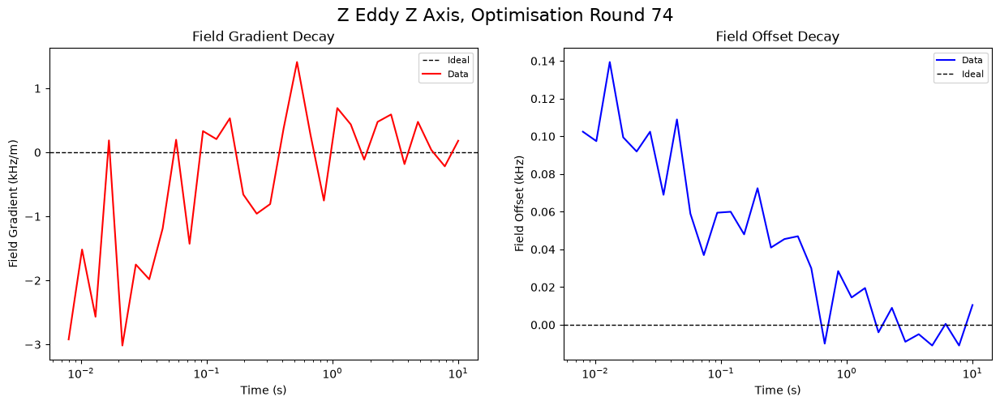

[I 2026-11-24 17:27:37,996] Trial 74 finished with value: 3223.38361767671 and parameters: {'Z_A1': 0.07157718734429569, 'Z_A2': 0.03857581864382493, 'Z_A3': 0.08134770837679353, 'Z_A4': 1.7958706234990015e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5597.201399300349
mean |E| = 3730.8012660336485
RMS E = 3895.334077972528
Total cost = 3.223e+03
E max = 0.12184022993074711
E nanmax = 0.12184022993074711
E contains nan = False
B max = 0.013199266210144986
B nanmax = 0.013199266210144986
B contains nan = False
Trial 75


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013199266210144986 !!!!!!!!!!!!!!!!


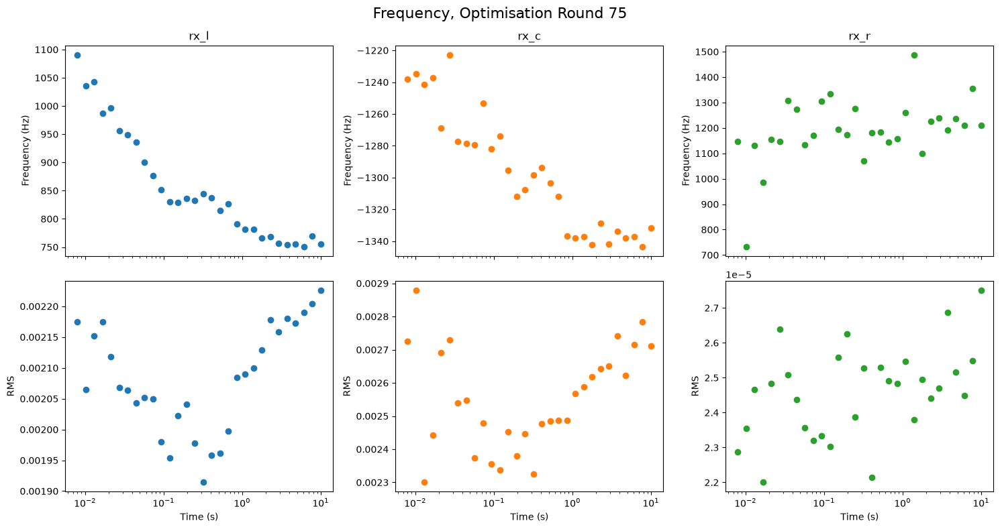

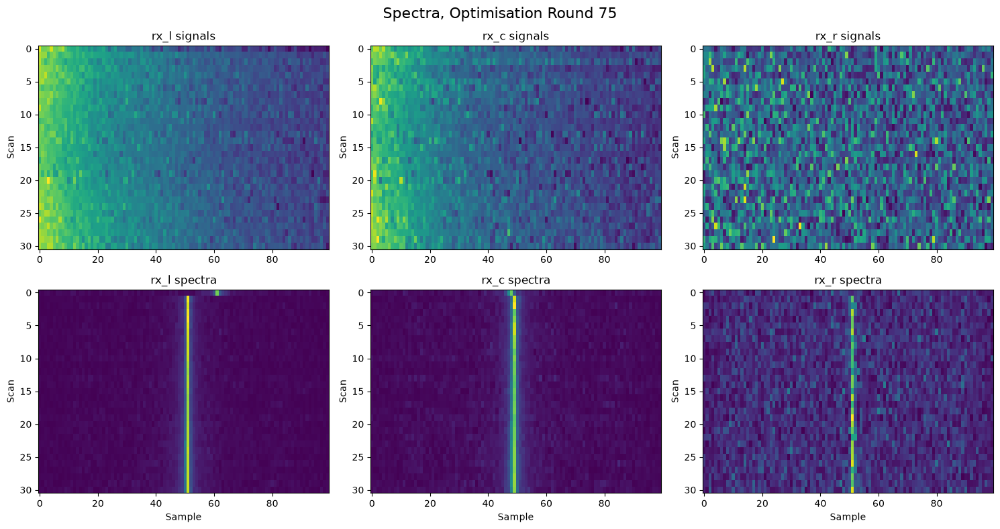

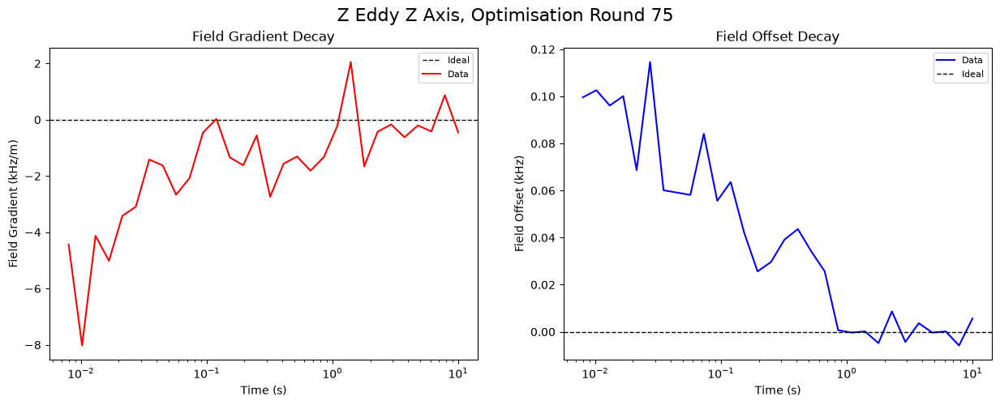

[I 2026-11-24 17:28:26,276] Trial 75 finished with value: 7026.687485590489 and parameters: {'Z_A1': 0.06796798873688217, 'Z_A2': 0.03466129881296271, 'Z_A3': 0.09085218923974257, 'Z_A4': 4.435616449675311e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 7051.474262868565
mean |E| = 3541.8957188072627
RMS E = 3854.4655117658667
Total cost = 7.027e+03
E max = 0.1217839096236325
E nanmax = 0.1217839096236325
E contains nan = False
B max = 0.013193166023310965
B nanmax = 0.013193166023310965
B contains nan = False
Trial 76


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013193166023310965 !!!!!!!!!!!!!!!!


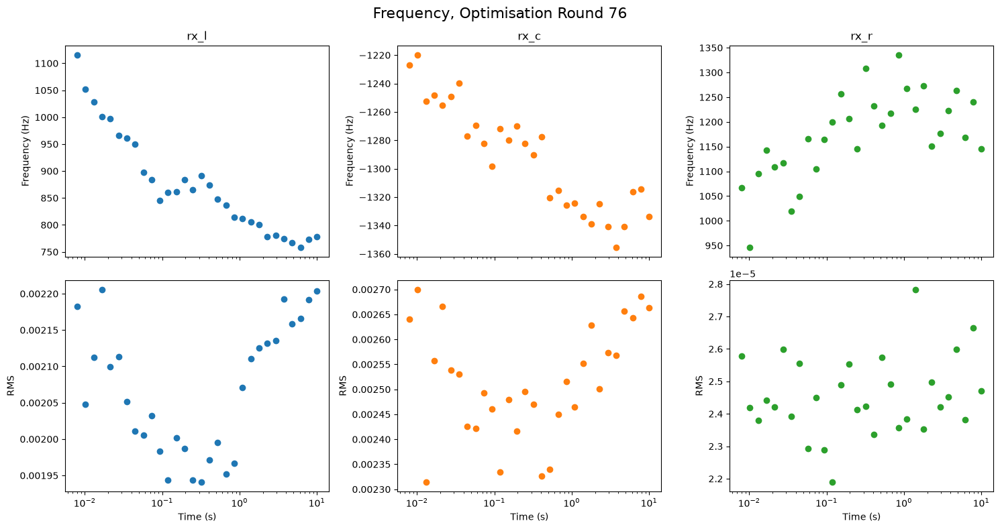

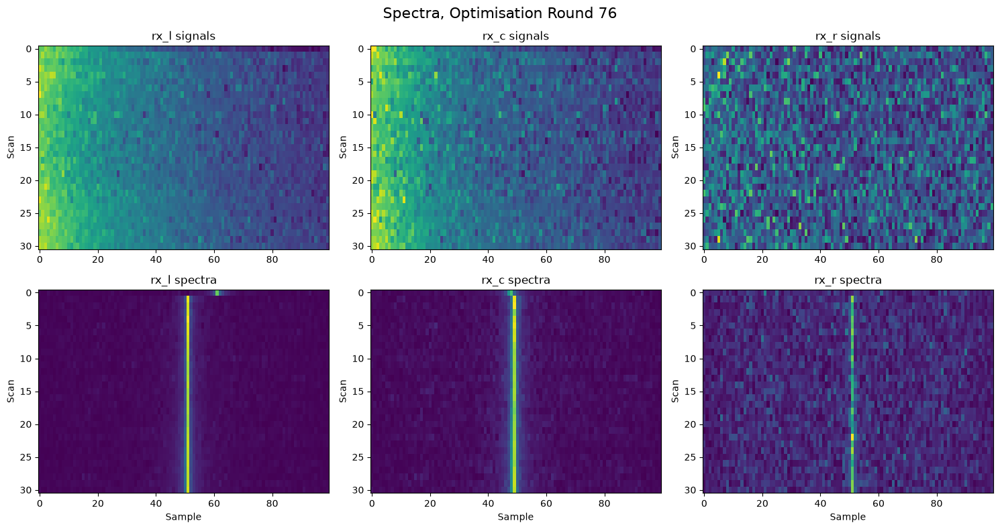

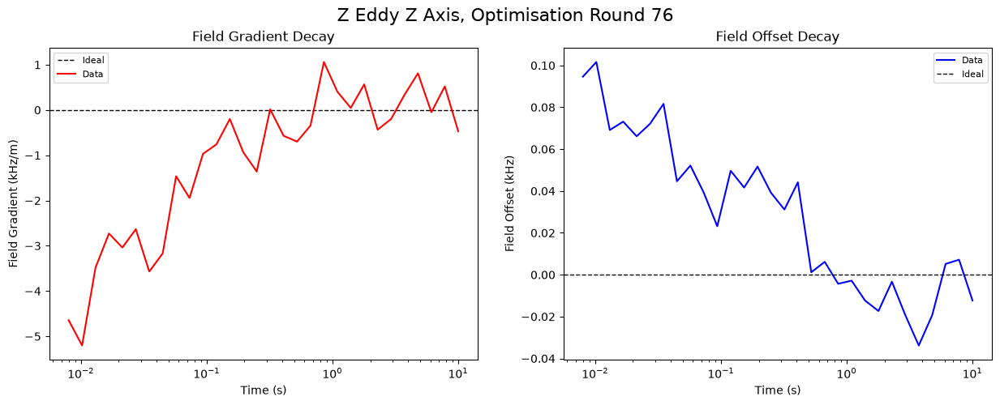

[I 2026-11-24 17:29:14,543] Trial 76 finished with value: 4450.968975304404 and parameters: {'Z_A1': 0.06564037112277707, 'Z_A2': 0.03987614121441183, 'Z_A3': 0.08768127620075677, 'Z_A4': 2.040498948422869e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5212.393803098449
mean |E| = 3085.124104614359
RMS E = 3401.636759156136
Total cost = 4.451e+03
E max = 0.12235503519613453
E nanmax = 0.12235503519613453
E contains nan = False
B max = 0.01325503686565131
B nanmax = 0.01325503686565131
B contains nan = False
Trial 77


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01325503686565131 !!!!!!!!!!!!!!!!


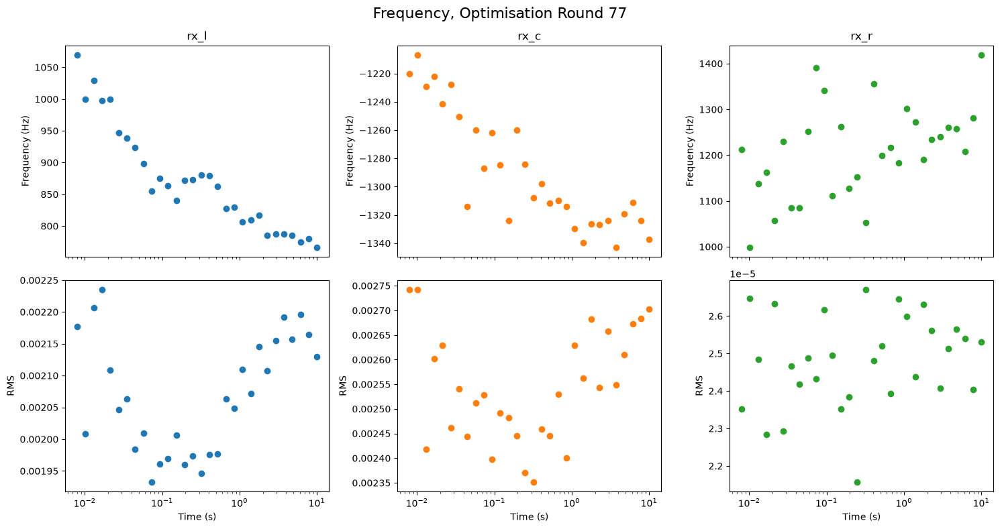

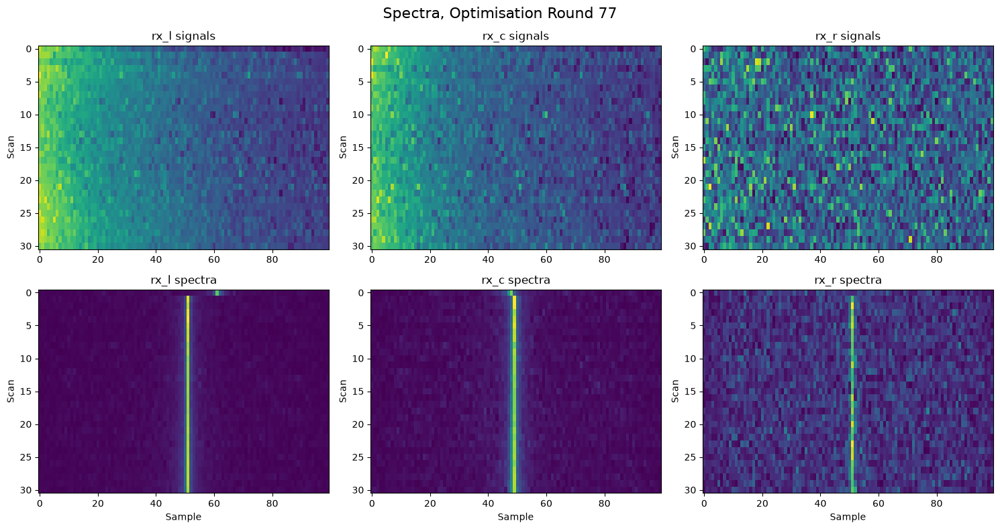

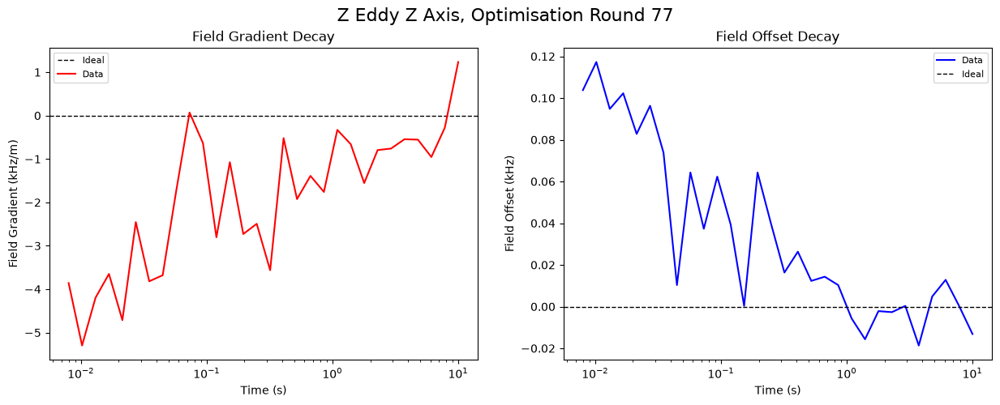

[I 2026-11-24 17:30:02,999] Trial 77 finished with value: 8321.099256106045 and parameters: {'Z_A1': 0.06590931219883392, 'Z_A2': 0.042011236793569384, 'Z_A3': 0.08973497482360743, 'Z_A4': 1.5971333677657986e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 6521.739130434781
mean |E| = 3373.6465100782934
RMS E = 3726.94933908231
Total cost = 8.321e+03
E max = 0.11984118435482434
E nanmax = 0.11984118435482434
E contains nan = False
B max = 0.012982708546779423
B nanmax = 0.012982708546779423
B contains nan = False
Trial 78


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012982708546779423 !!!!!!!!!!!!!!!!


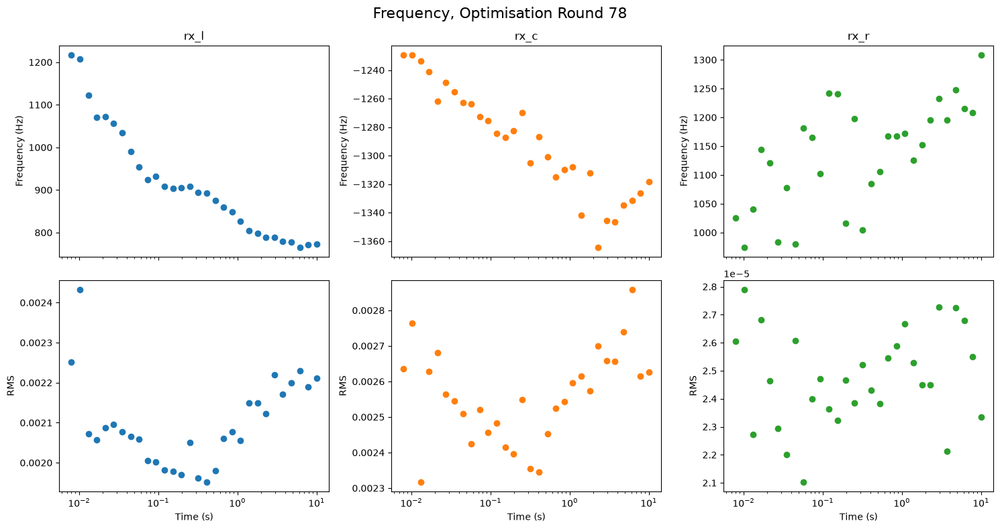

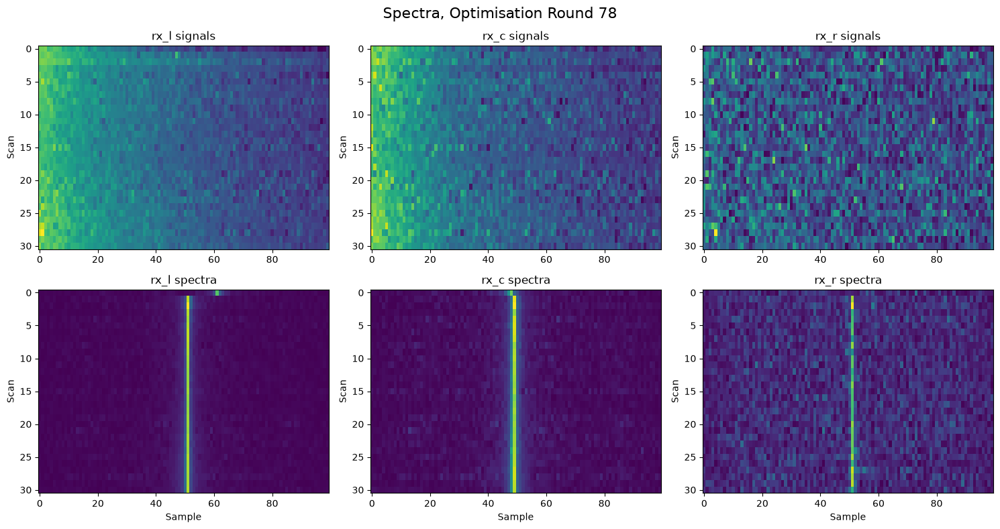

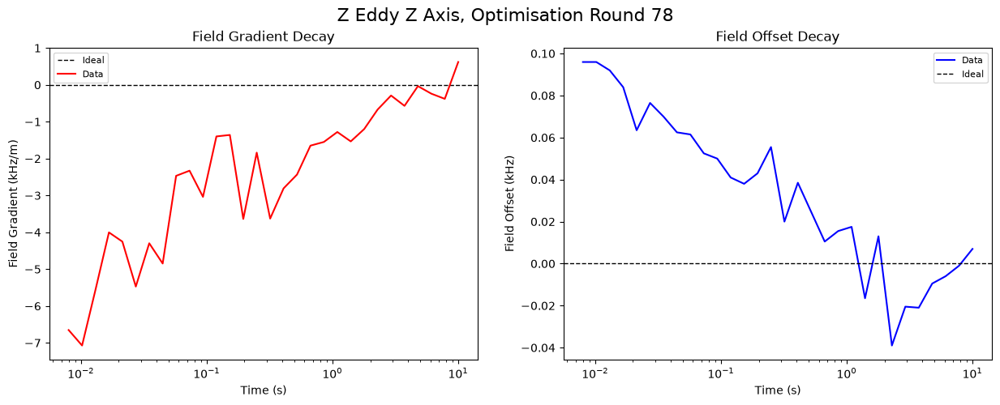

[I 2026-11-24 17:30:51,040] Trial 78 finished with value: 6588.493957375974 and parameters: {'Z_A1': 0.0623197585854656, 'Z_A2': 0.03805209603553589, 'Z_A3': 0.07756554269652292, 'Z_A4': 1.6383382641769228e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5357.321339330333
mean |E| = 2602.698650674662
RMS E = 2976.297381978851
Total cost = 6.588e+03
E max = 0.11996994426851777
E nanmax = 0.11996994426851777
E contains nan = False
B max = 0.012996671254880427
B nanmax = 0.012996671254880427
B contains nan = False
Trial 79


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012996671254880427 !!!!!!!!!!!!!!!!


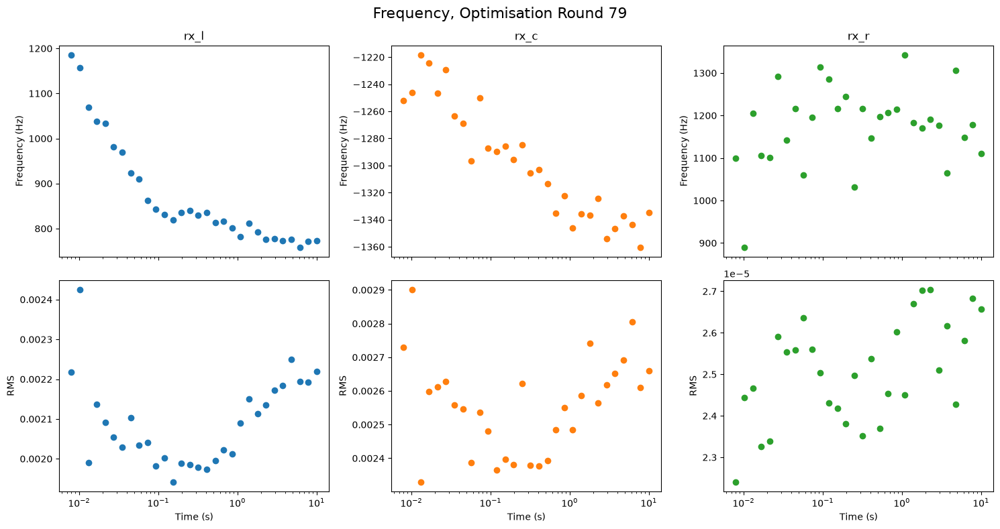

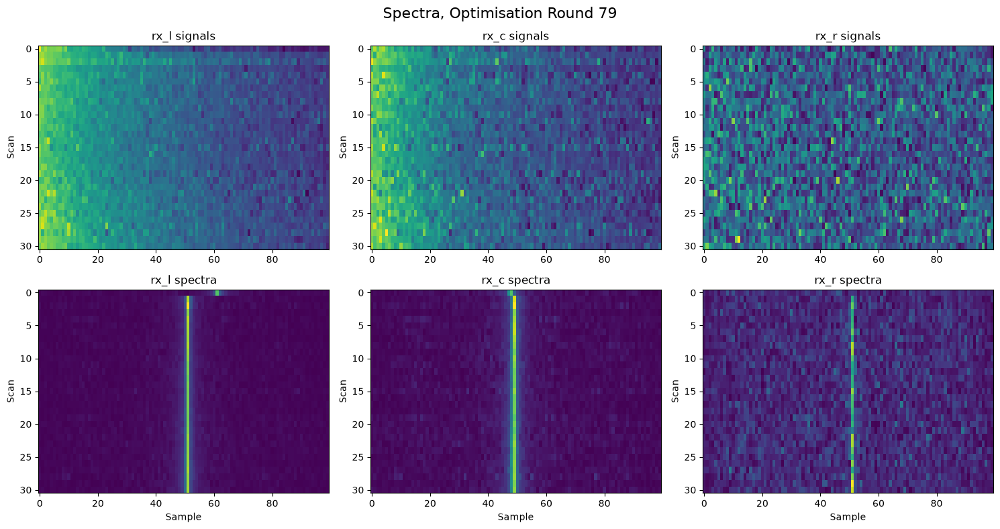

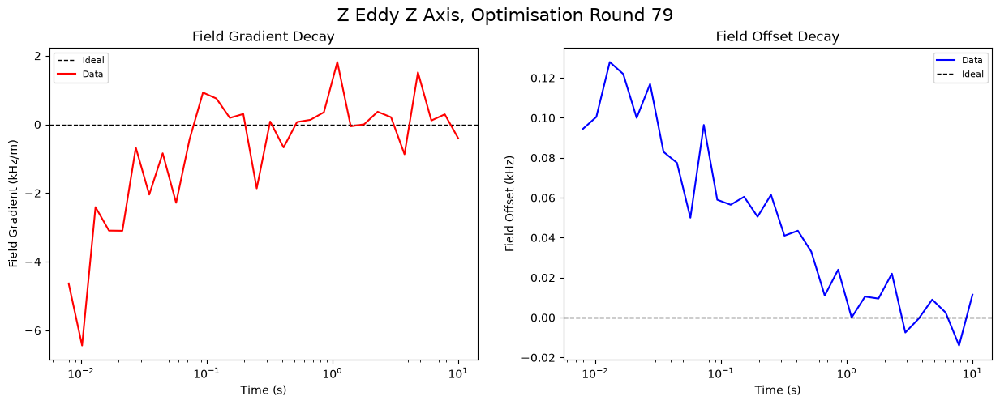

[I 2026-11-24 17:31:39,122] Trial 79 finished with value: 5165.005252864258 and parameters: {'Z_A1': 0.0711010551537763, 'Z_A2': 0.03398348678674482, 'Z_A3': 0.07361392702044091, 'Z_A4': 4.025327815261606e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5597.2013993003475
mean |E| = 3257.371314342827
RMS E = 3503.0758472695356
Total cost = 5.165e+03
E max = 0.12028447383868902
E nanmax = 0.12028447383868902
E contains nan = False
B max = 0.013030733917257693
B nanmax = 0.013030733917257693
B contains nan = False
Trial 80


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013030733917257693 !!!!!!!!!!!!!!!!


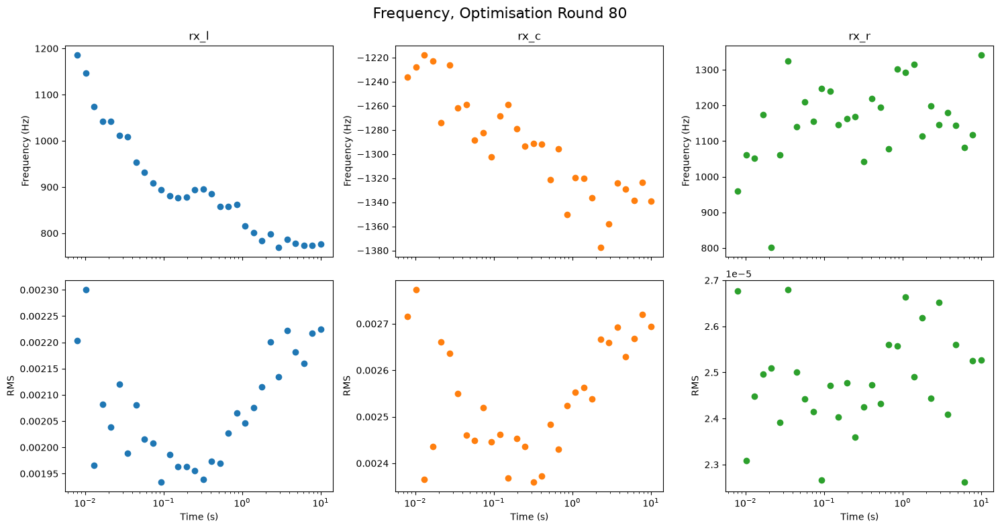

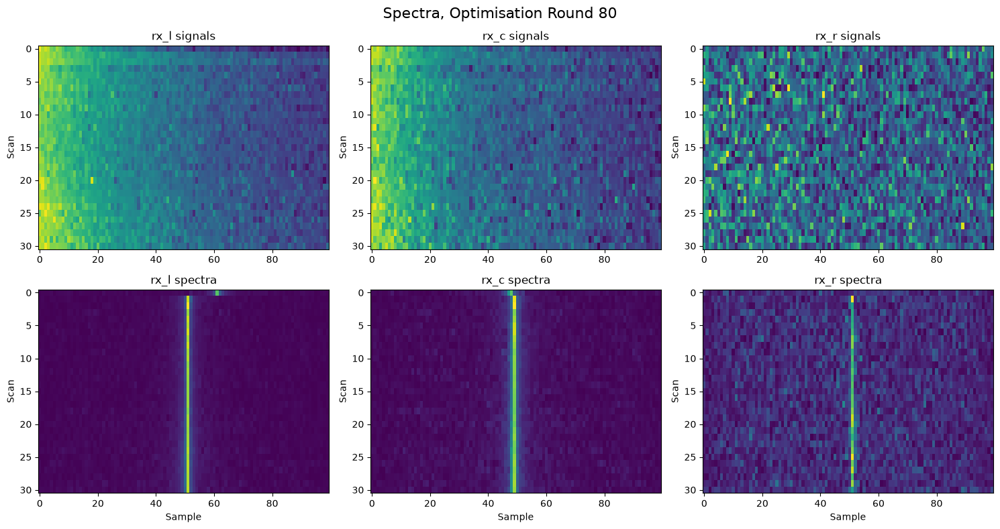

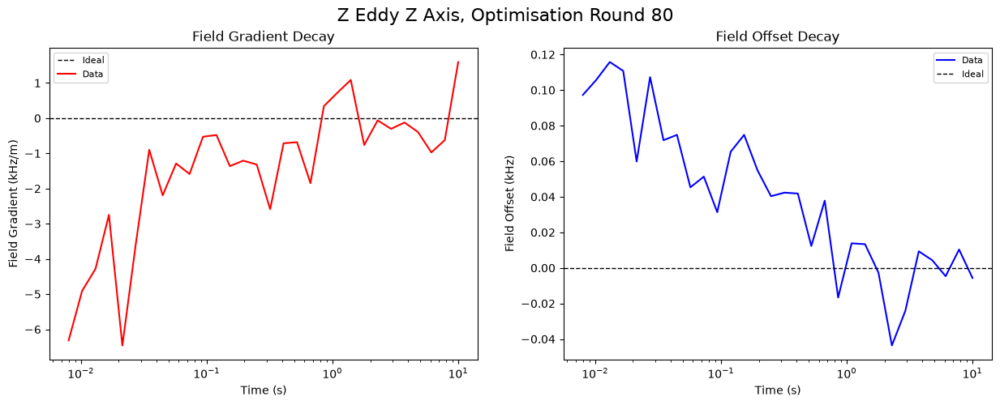

[I 2026-11-24 17:32:27,066] Trial 80 finished with value: 7324.651463187121 and parameters: {'Z_A1': 0.06368782461840129, 'Z_A2': 0.04026442335583245, 'Z_A3': 0.07750966267924889, 'Z_A4': 4.617802202528141e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5652.173913043477
mean |E| = 2956.6883225054125
RMS E = 3215.356340900946
Total cost = 7.325e+03
E max = 0.12177373729210691
E nanmax = 0.12177373729210691
E contains nan = False
B max = 0.01319208068117696
B nanmax = 0.01319208068117696
B contains nan = False
Trial 81


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01319208068117696 !!!!!!!!!!!!!!!!


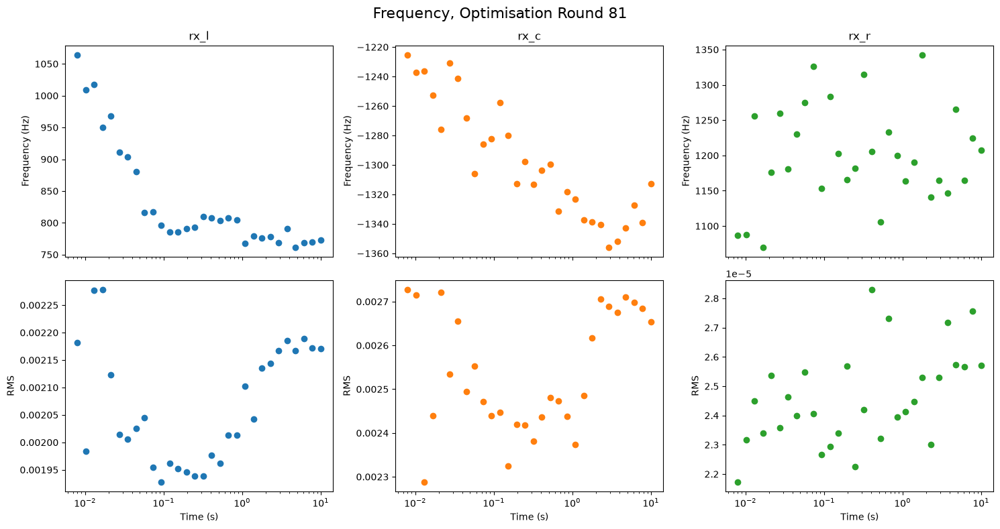

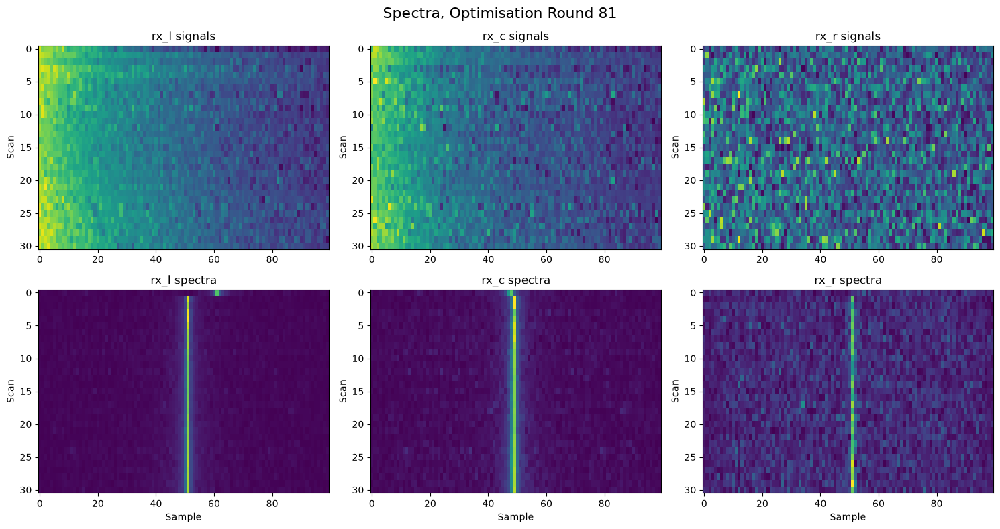

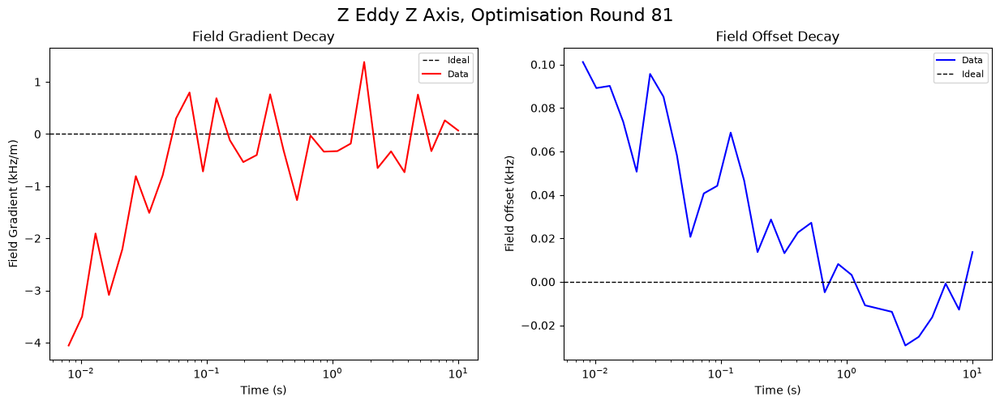

[I 2026-11-24 17:33:15,273] Trial 81 finished with value: 4554.0320443476885 and parameters: {'Z_A1': 0.07493339895388543, 'Z_A2': 0.03648893163978614, 'Z_A3': 0.08145377528105512, 'Z_A4': 5.348093488703657e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5667.1664167916015
mean |E| = 3648.0093286689985
RMS E = 3854.850267016593
Total cost = 4.554e+03
E max = 0.12304950650472267
E nanmax = 0.12304950650472267
E contains nan = False
B max = 0.013330283413398248
B nanmax = 0.013330283413398248
B contains nan = False
Trial 82


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013330283413398248 !!!!!!!!!!!!!!!!


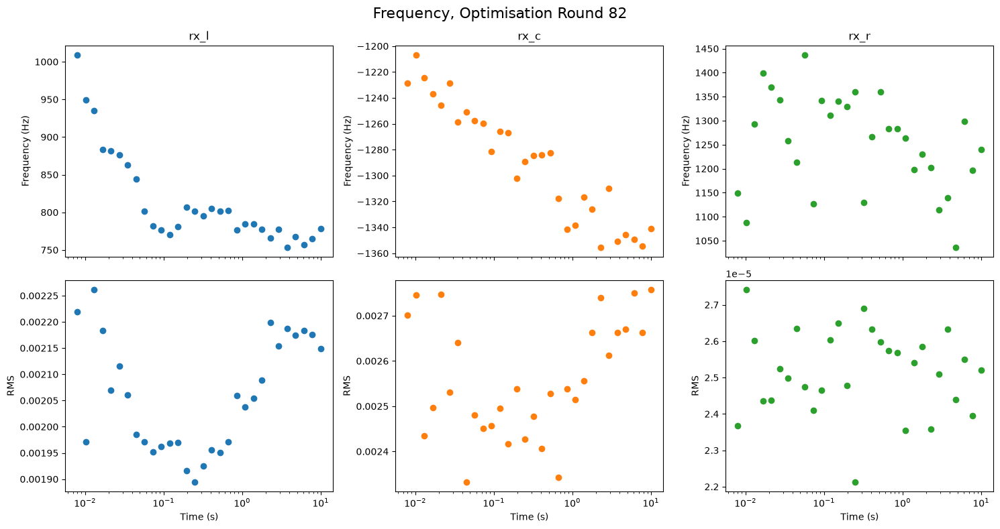

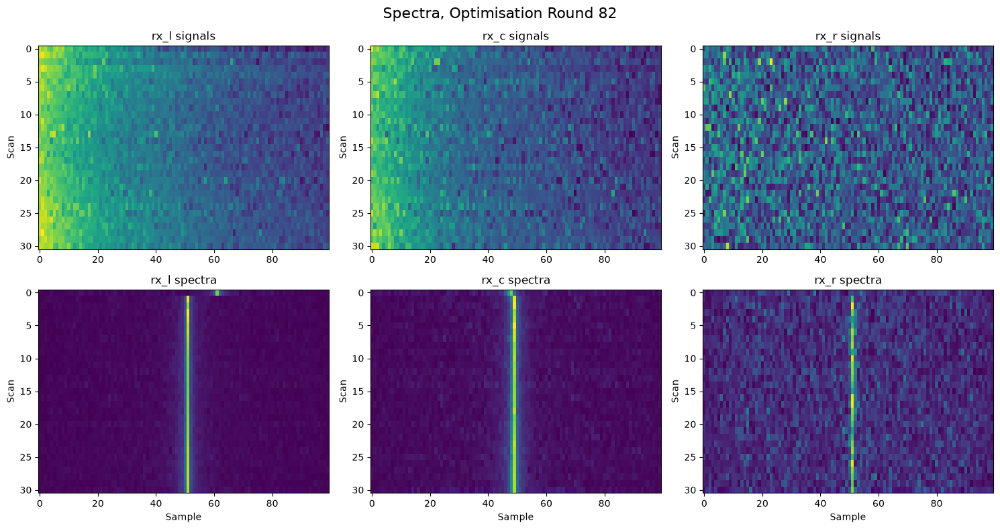

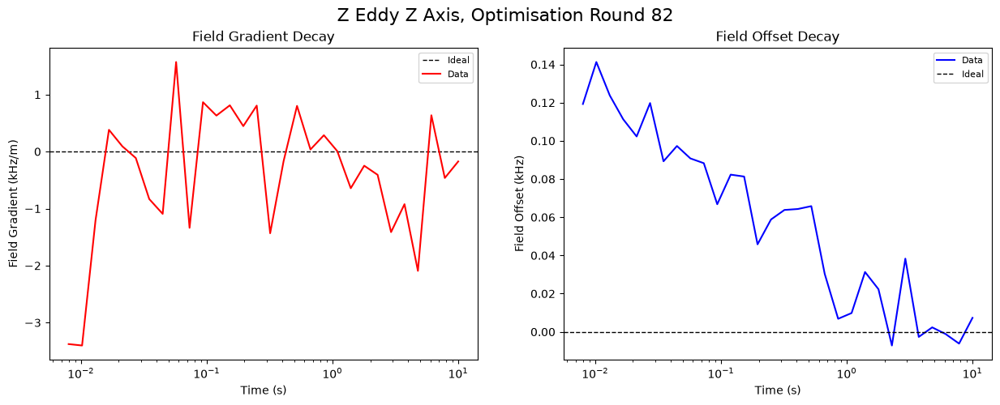

[I 2026-11-24 17:34:03,484] Trial 82 finished with value: 7519.3090308548935 and parameters: {'Z_A1': 0.07459948741669868, 'Z_A2': 0.04022288787112981, 'Z_A3': 0.08801254270567518, 'Z_A4': 2.489010131877052e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 6351.824087956022
mean |E| = 4382.47542895219
RMS E = 4531.891454863479
Total cost = 7.519e+03
E max = 0.11995964452237383
E nanmax = 0.11995964452237383
E contains nan = False
B max = 0.012995559964690788
B nanmax = 0.012995559964690788
B contains nan = False
Trial 83


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012995559964690788 !!!!!!!!!!!!!!!!


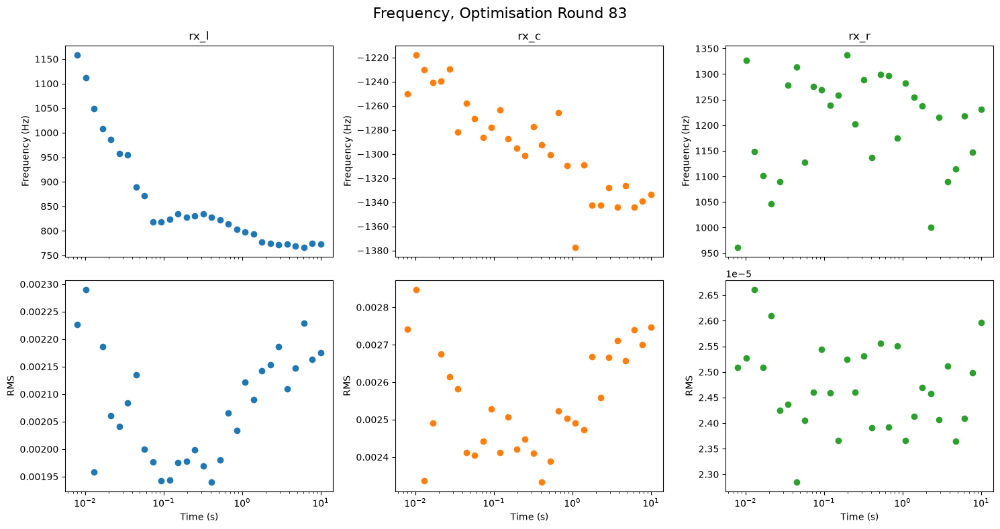

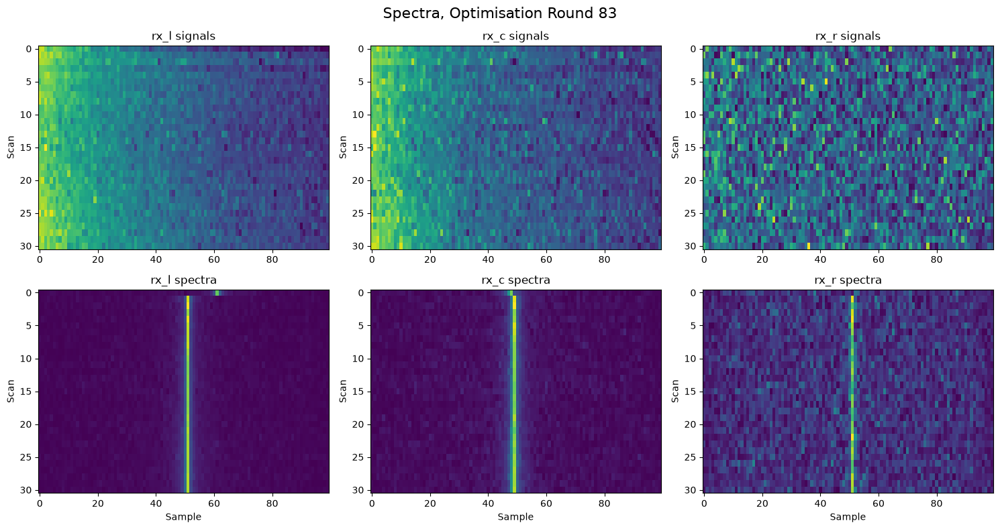

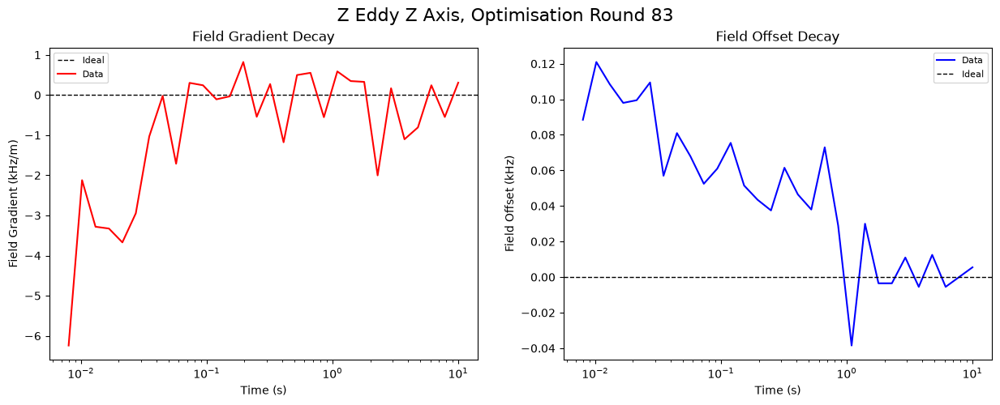

[I 2026-11-24 17:34:51,719] Trial 83 finished with value: 6046.494363476267 and parameters: {'Z_A1': 0.07043634146118871, 'Z_A2': 0.03936281004505896, 'Z_A3': 0.06887496636758889, 'Z_A4': 4.418059060035342e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5092.453773113441
mean |E| = 3516.575045810427
RMS E = 3750.9425809648255
Total cost = 6.046e+03
E max = 0.12197309081504383
E nanmax = 0.12197309081504383
E contains nan = False
B max = 0.013213672219191569
B nanmax = 0.013213672219191569
B contains nan = False
Trial 84


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013213672219191569 !!!!!!!!!!!!!!!!


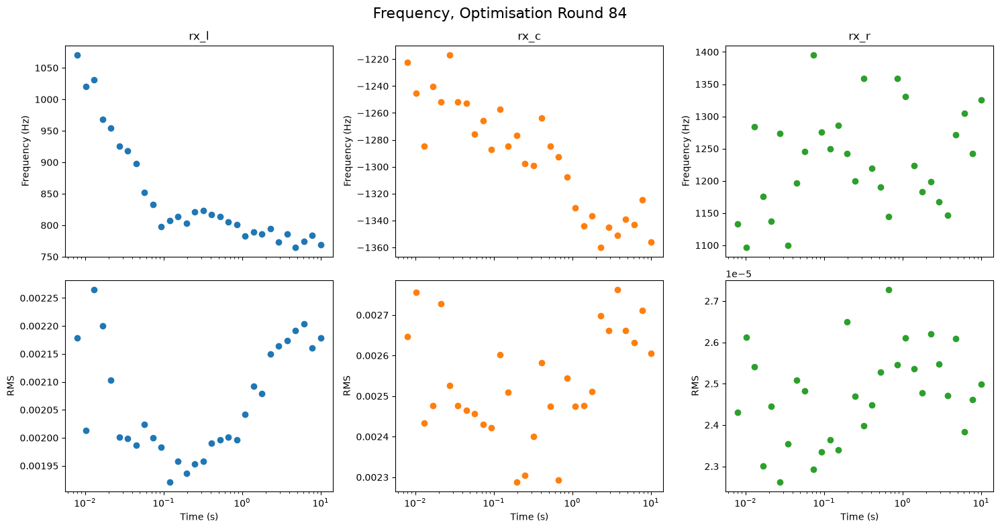

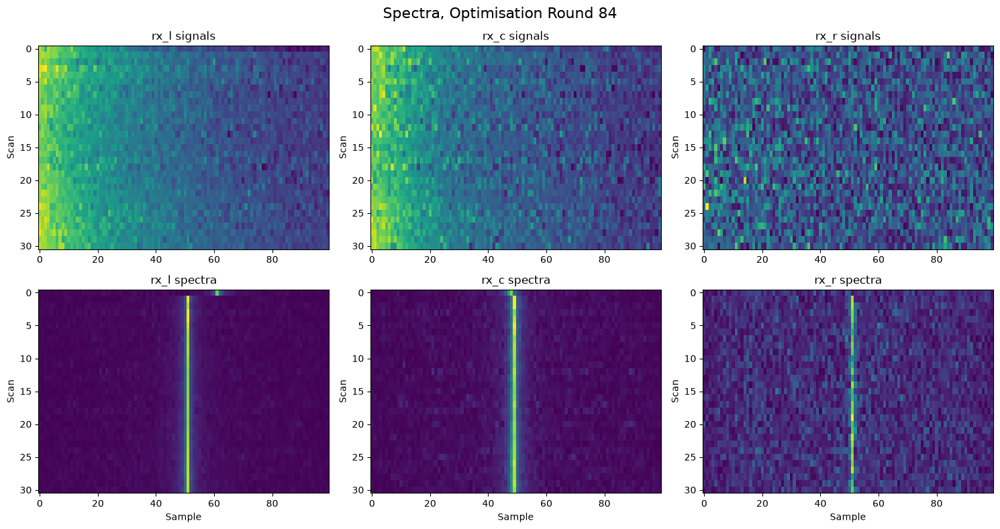

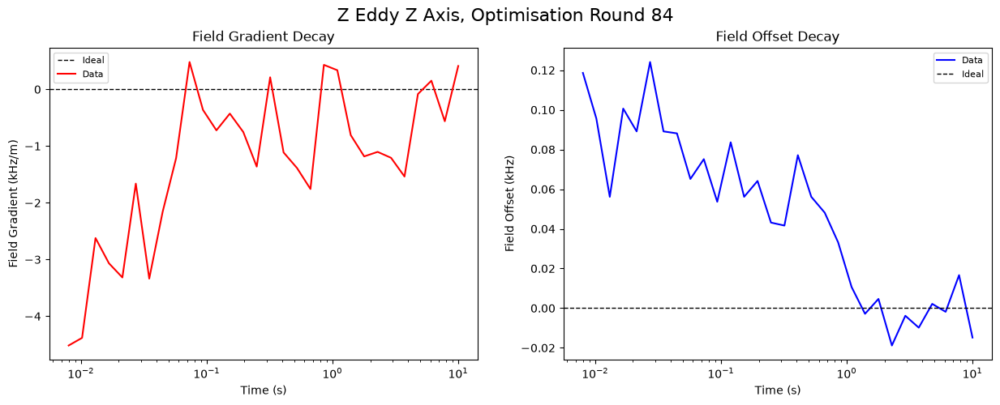

[I 2026-11-24 17:35:40,127] Trial 84 finished with value: 6707.044494501992 and parameters: {'Z_A1': 0.0734555404147957, 'Z_A2': 0.03609190290985528, 'Z_A3': 0.08491123942639543, 'Z_A4': 4.484357522693333e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5627.186406796601
mean |E| = 3858.4041312676986
RMS E = 4088.5540899424295
Total cost = 6.707e+03
E max = 0.12075977998782335
E nanmax = 0.12075977998782335
E contains nan = False
B max = 0.013082237059376283
B nanmax = 0.013082237059376283
B contains nan = False
Trial 85


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013082237059376283 !!!!!!!!!!!!!!!!


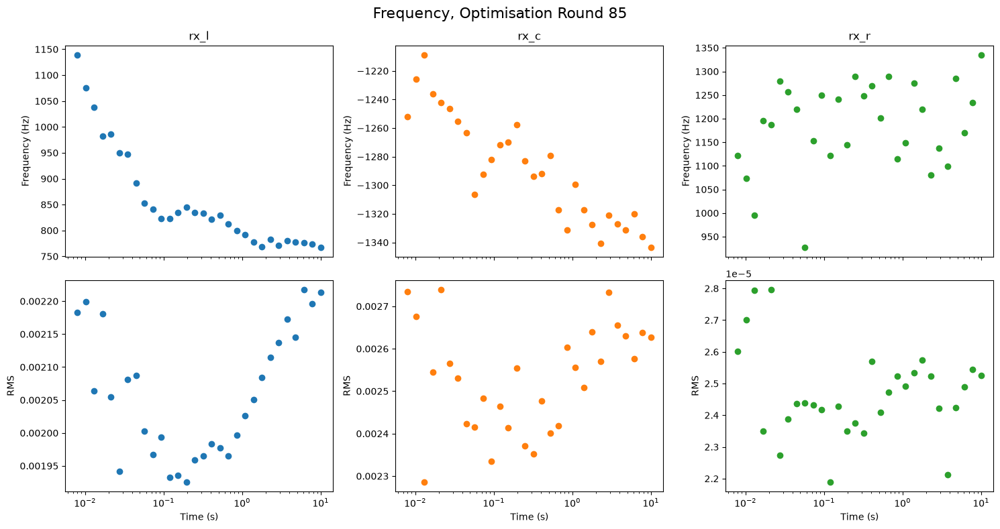

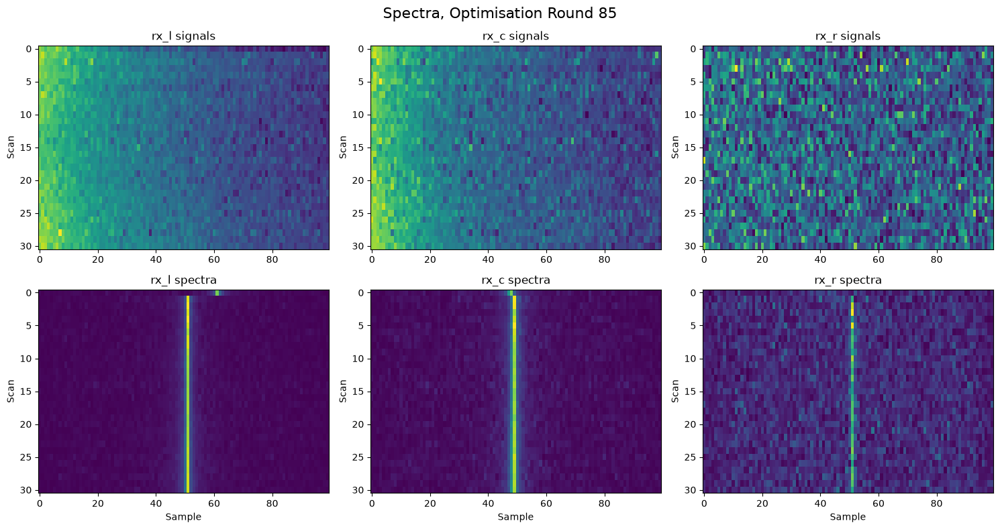

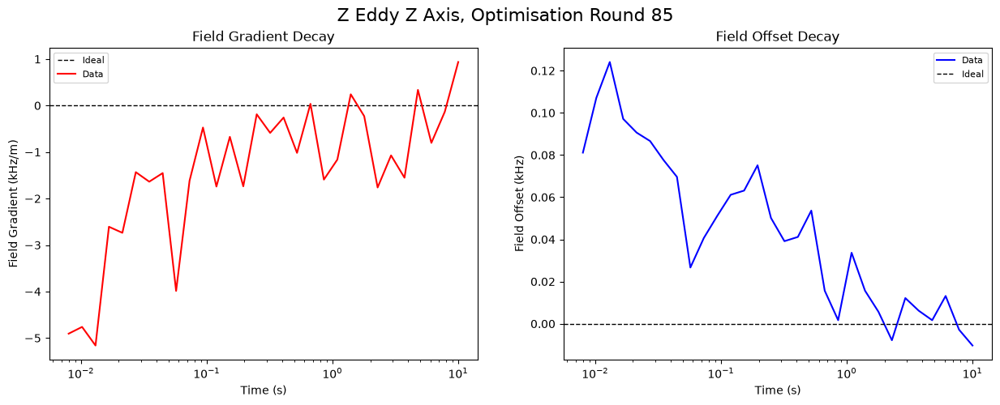

[I 2026-11-24 17:36:28,331] Trial 85 finished with value: 7542.032581495524 and parameters: {'Z_A1': 0.07036750826254194, 'Z_A2': 0.04061967334446072, 'Z_A3': 0.07408404709448736, 'Z_A4': 5.398268351188049e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5672.163918040978
mean |E| = 3319.506913210061
RMS E = 3615.639830017191
Total cost = 7.542e+03
E max = 0.12201328100186538
E nanmax = 0.12201328100186538
E contains nan = False
B max = 0.013218036059079716
B nanmax = 0.013218036059079716
B contains nan = False
Trial 86


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013218036059079716 !!!!!!!!!!!!!!!!


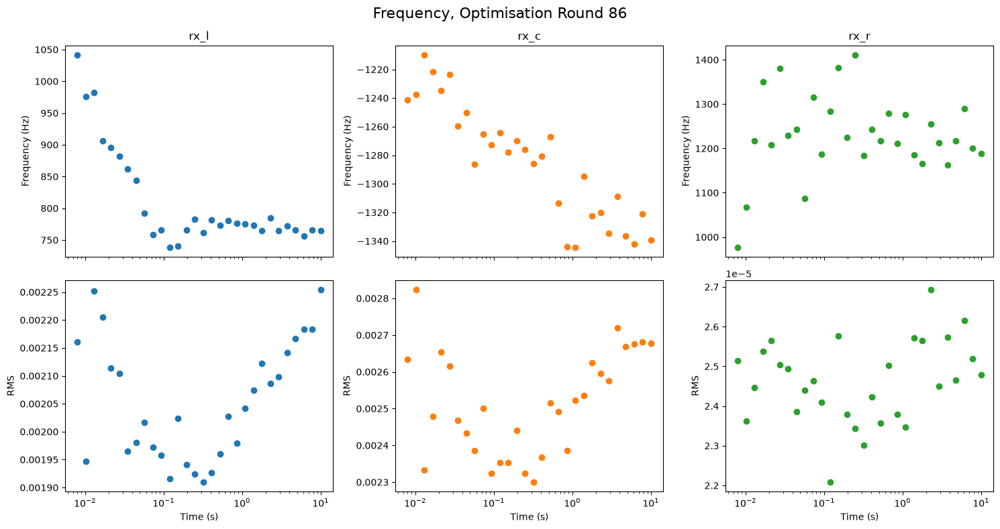

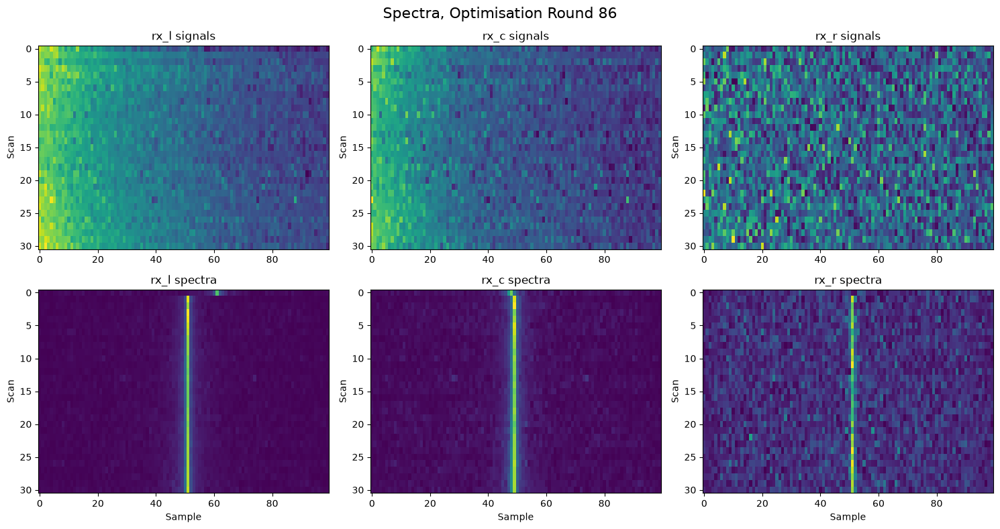

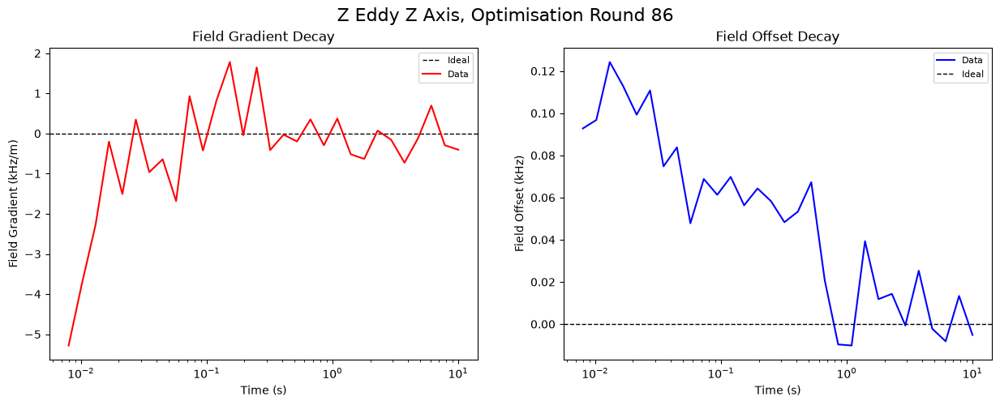

[I 2026-11-24 17:37:16,466] Trial 86 finished with value: 4081.7125789219954 and parameters: {'Z_A1': 0.07787460766053832, 'Z_A2': 0.03656916227871055, 'Z_A3': 0.08021615719545108, 'Z_A4': 5.049553019260204e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 6416.791604197899
mean |E| = 4228.219223721471
RMS E = 4408.586263371007
Total cost = 4.082e+03
E max = 0.12108175789970291
E nanmax = 0.12108175789970291
E contains nan = False
B max = 0.013117112398071975
B nanmax = 0.013117112398071975
B contains nan = False
Trial 87


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013117112398071975 !!!!!!!!!!!!!!!!


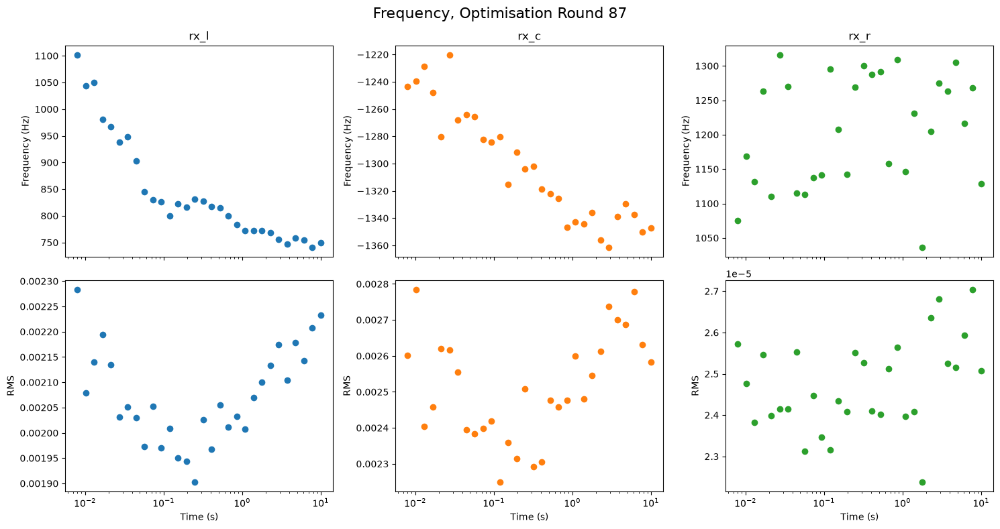

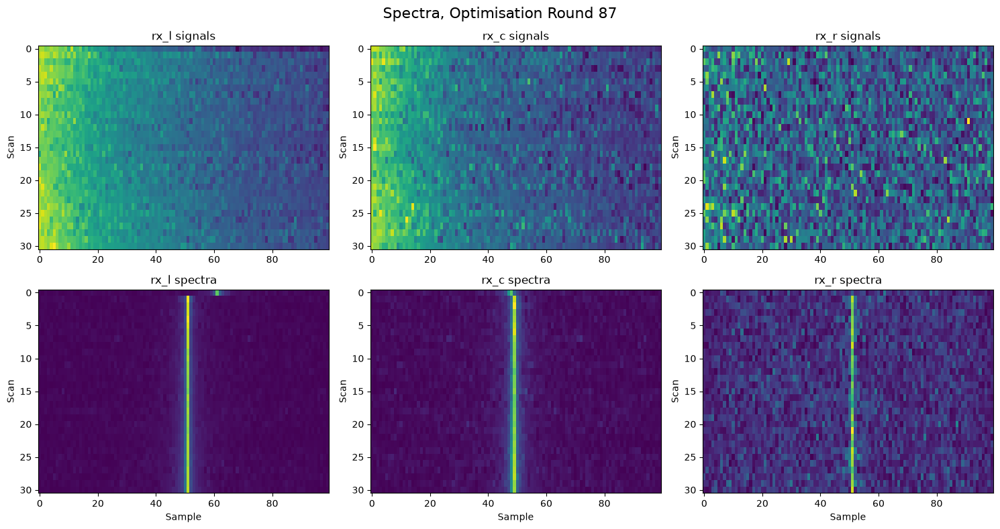

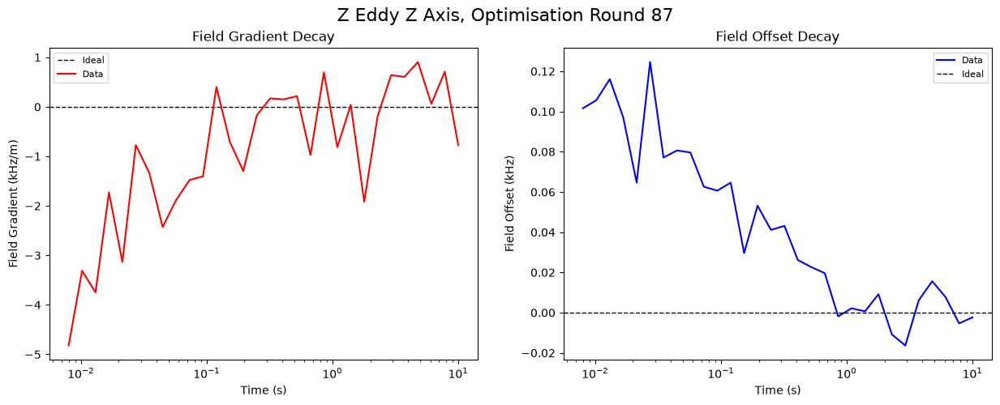

[I 2026-11-24 17:38:04,598] Trial 87 finished with value: 6276.215809997134 and parameters: {'Z_A1': 0.06974654971882116, 'Z_A2': 0.03881136460935155, 'Z_A3': 0.07906022477650357, 'Z_A4': 4.116410433325534e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5462.268865567215
mean |E| = 3631.3509911710803
RMS E = 3886.325410837308
Total cost = 6.276e+03
E max = 0.12092861417146997
E nanmax = 0.12092861417146997
E contains nan = False
B max = 0.013100523894274966
B nanmax = 0.013100523894274966
B contains nan = False
Trial 88


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013100523894274966 !!!!!!!!!!!!!!!!


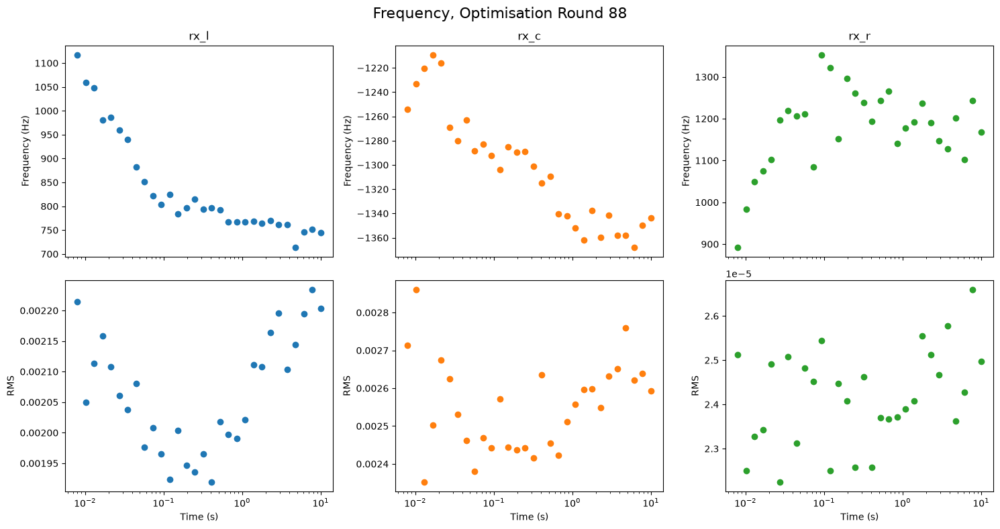

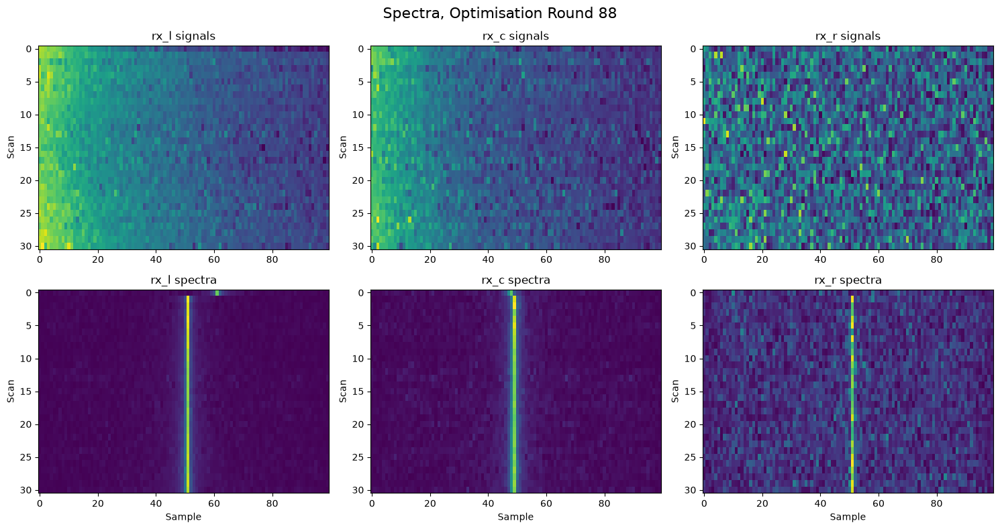

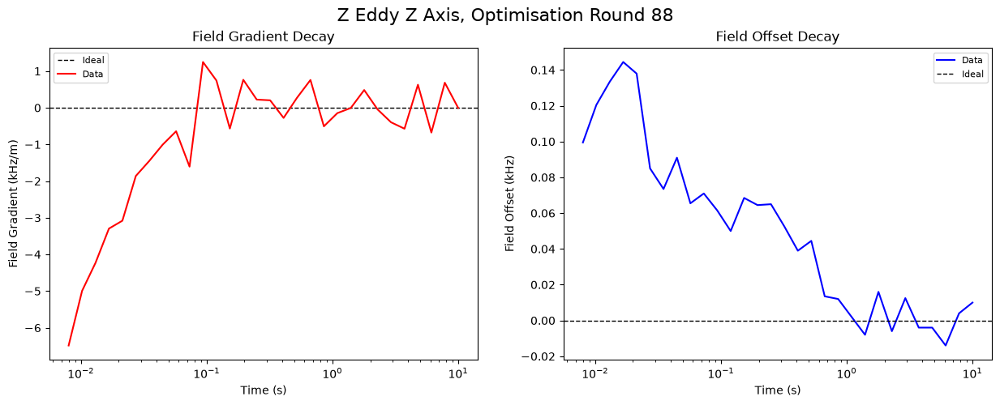

[I 2026-11-24 17:38:52,656] Trial 88 finished with value: 4784.2208946081955 and parameters: {'Z_A1': 0.07292184344991236, 'Z_A2': 0.033487033487415295, 'Z_A3': 0.07983746567259979, 'Z_A4': 5.627071142901107e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5487.25637181409
mean |E| = 3578.0443111777436
RMS E = 3834.1417790240275
Total cost = 4.784e+03
E max = 0.12162583952375024
E nanmax = 0.12162583952375024
E contains nan = False
B max = 0.013176047310218427
B nanmax = 0.013176047310218427
B contains nan = False
Trial 89


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013176047310218427 !!!!!!!!!!!!!!!!


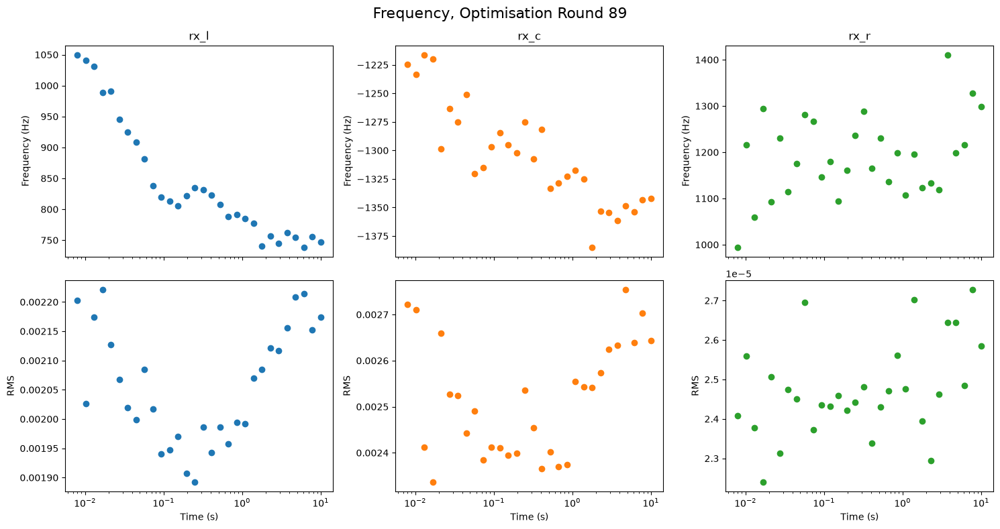

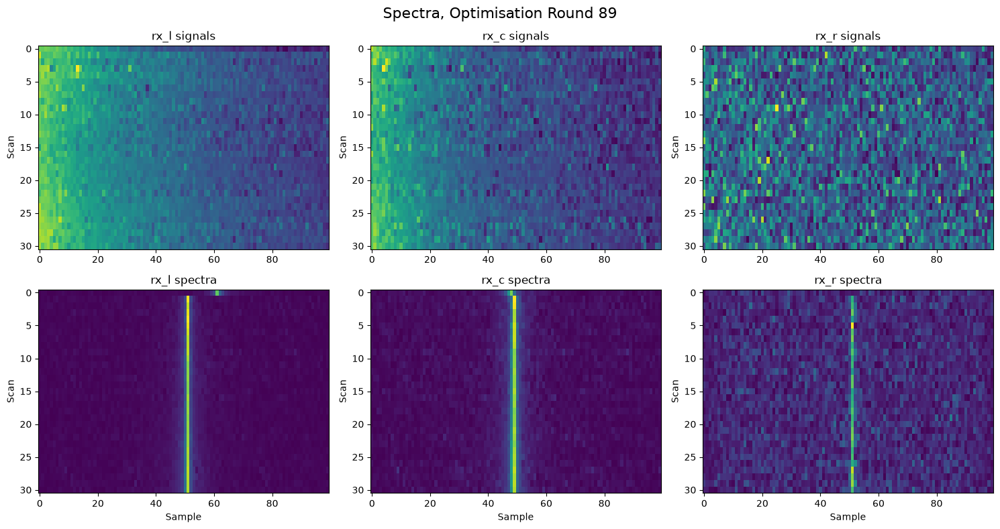

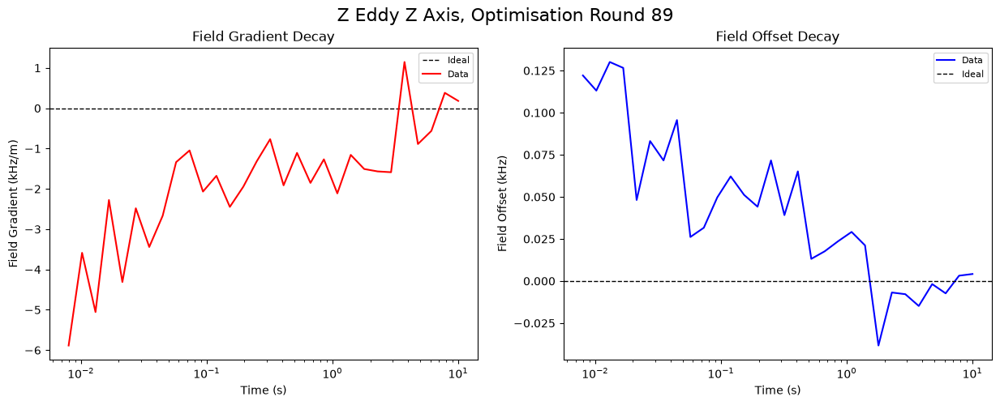

[I 2026-11-24 17:39:40,636] Trial 89 finished with value: 9124.943473834051 and parameters: {'Z_A1': 0.06933228592219041, 'Z_A2': 0.03658106838051336, 'Z_A3': 0.08593545774897361, 'Z_A4': 3.926624703448395e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 6481.7591204397795
mean |E| = 3501.249375312343
RMS E = 3762.4637753258535
Total cost = 9.125e+03
E max = 0.1198750753395456
E nanmax = 0.1198750753395456
E contains nan = False
B max = 0.012986392340493055
B nanmax = 0.012986392340493055
B contains nan = False
Trial 90


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012986392340493055 !!!!!!!!!!!!!!!!


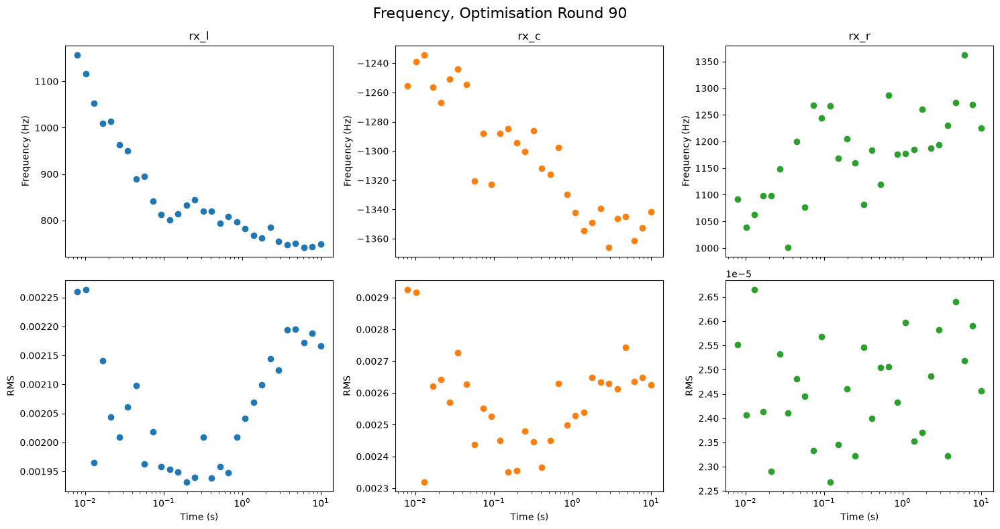

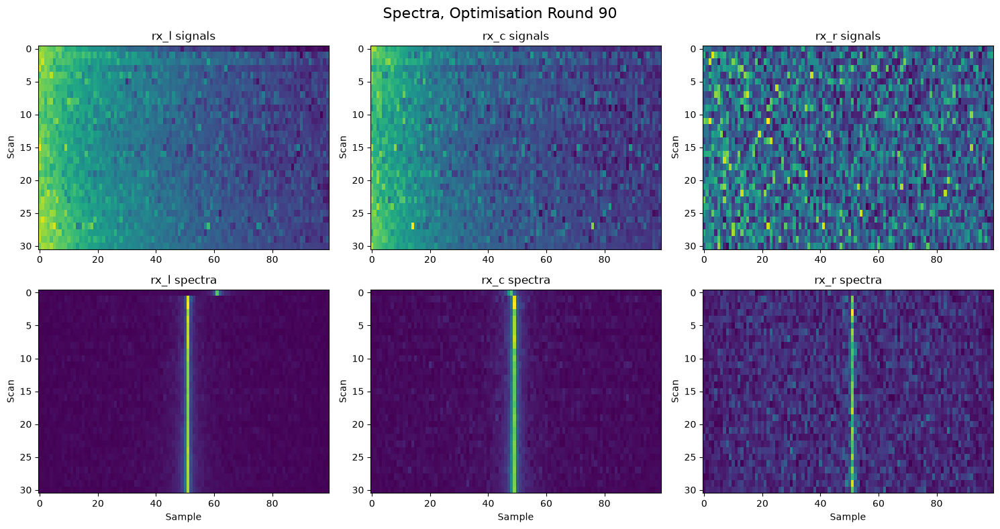

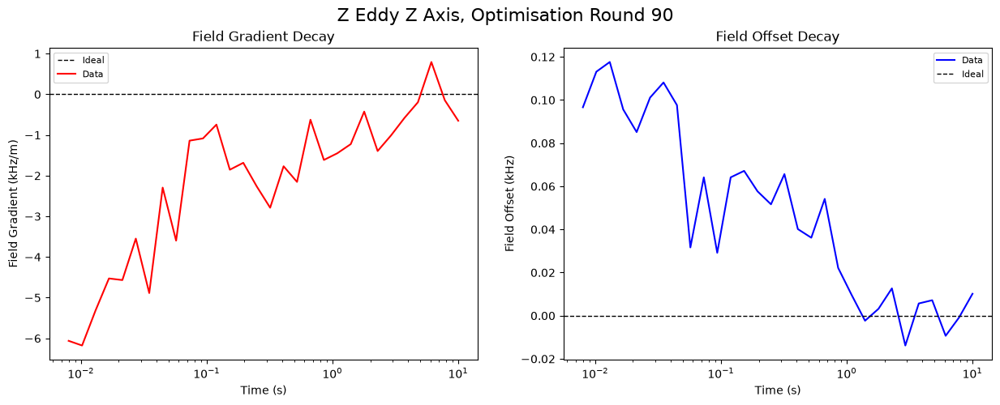

[I 2026-11-24 17:40:28,767] Trial 90 finished with value: 7214.185559689832 and parameters: {'Z_A1': 0.06776576221451087, 'Z_A2': 0.03865531131725171, 'Z_A3': 0.07166083479633391, 'Z_A4': 2.6856635281641246e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 6201.89905047476
mean |E| = 3336.331834082958
RMS E = 3718.639302845297
Total cost = 7.214e+03
E max = 0.12144610337390395
E nanmax = 0.12144610337390395
E contains nan = False
B max = 0.013156592723494237
B nanmax = 0.013156592723494237
B contains nan = False
Trial 91


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013156592723494237 !!!!!!!!!!!!!!!!


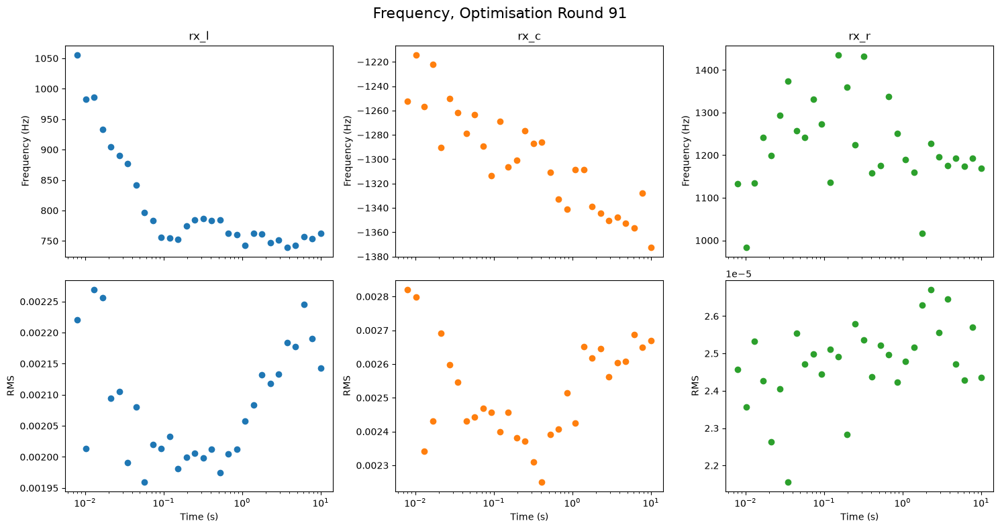

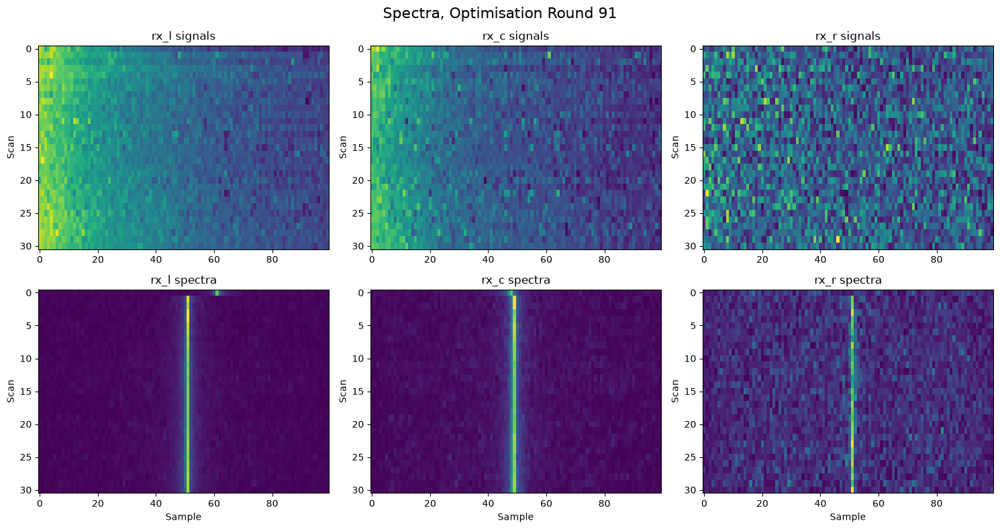

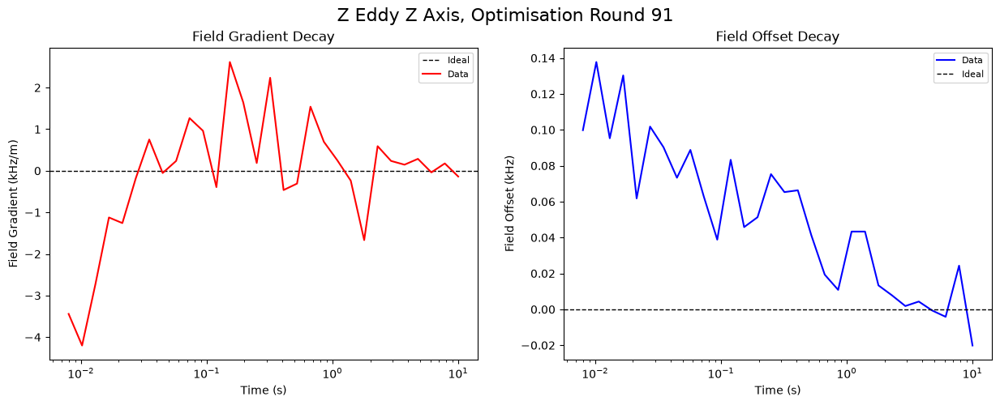

[I 2026-11-24 17:41:17,007] Trial 91 finished with value: 3390.53889190387 and parameters: {'Z_A1': 0.07507786194908009, 'Z_A2': 0.03926739570958653, 'Z_A3': 0.07599249652410073, 'Z_A4': 5.513709262504049e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 6826.586706646676
mean |E| = 4131.267699483591
RMS E = 4382.085978367929
Total cost = 3.391e+03
E max = 0.1197668522853926
E nanmax = 0.1197668522853926
E contains nan = False
B max = 0.012974667428381633
B nanmax = 0.012974667428381633
B contains nan = False
Trial 92


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012974667428381633 !!!!!!!!!!!!!!!!


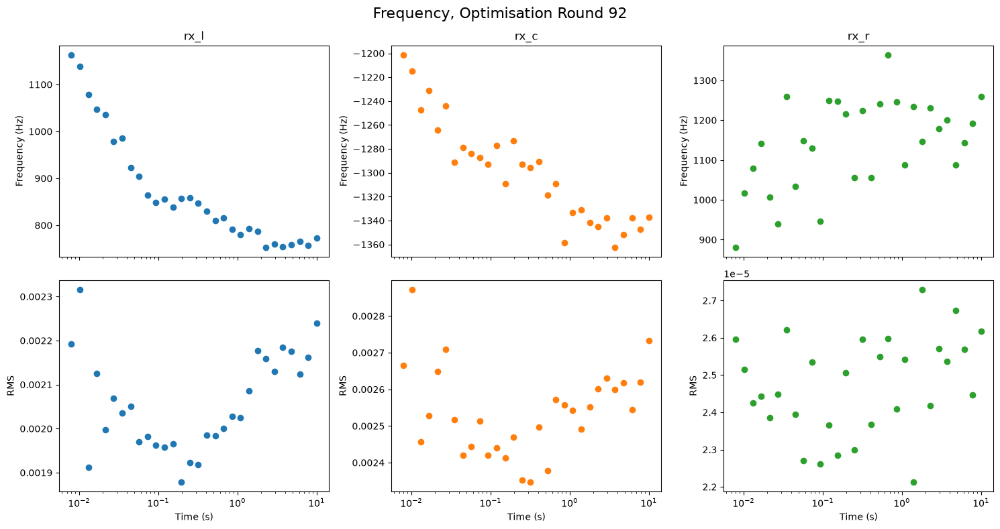

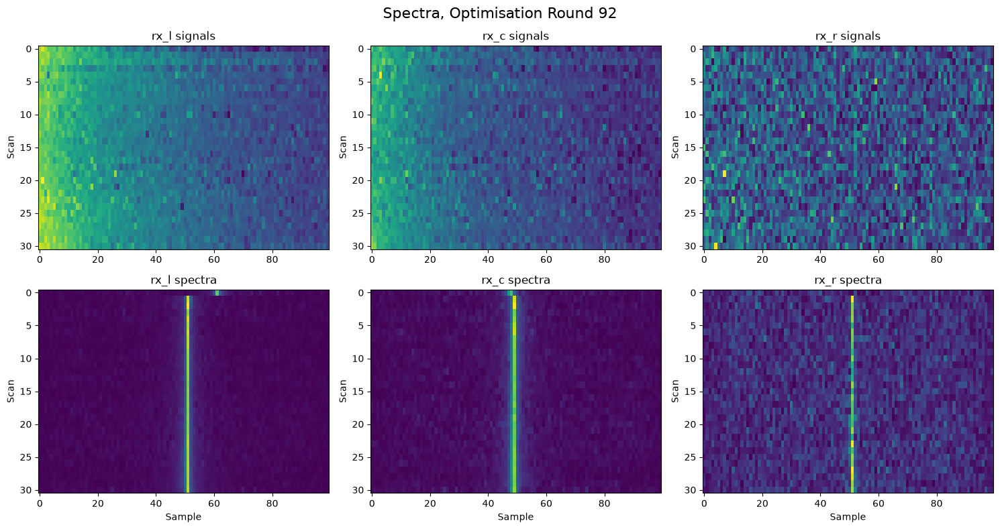

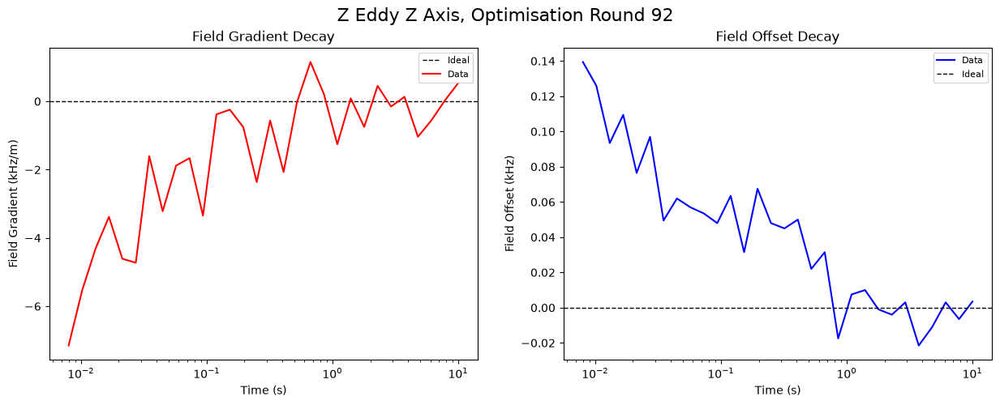

[I 2026-11-24 17:42:05,176] Trial 92 finished with value: 4890.305098083358 and parameters: {'Z_A1': 0.06723021912199775, 'Z_A2': 0.038353345237701966, 'Z_A3': 0.07164477723559794, 'Z_A4': 5.579461028397691e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5482.258870564716
mean |E| = 3011.4942528735623
RMS E = 3369.550408918218
Total cost = 4.890e+03
E max = 0.1221227325338209
E nanmax = 0.1221227325338209
E contains nan = False
B max = 0.01322989425831053
B nanmax = 0.01322989425831053
B contains nan = False
Trial 93


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01322989425831053 !!!!!!!!!!!!!!!!


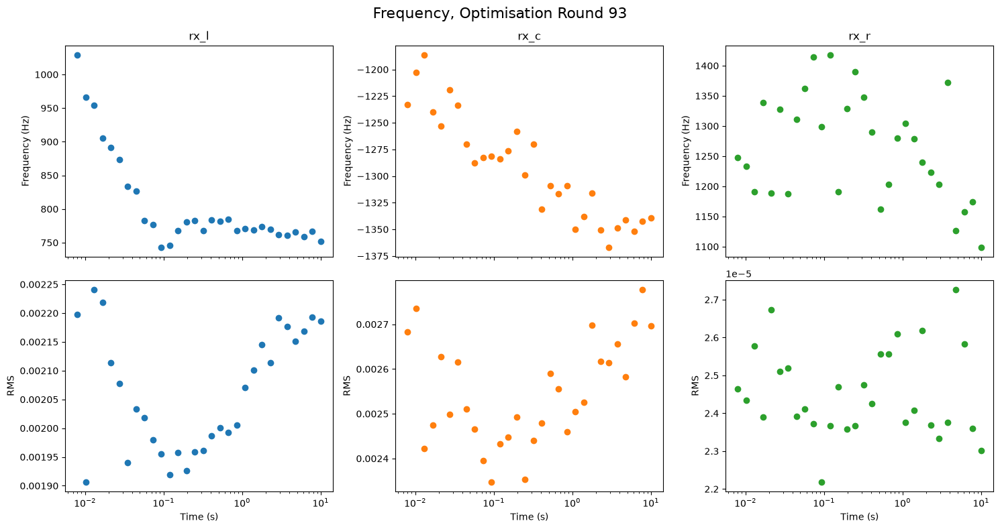

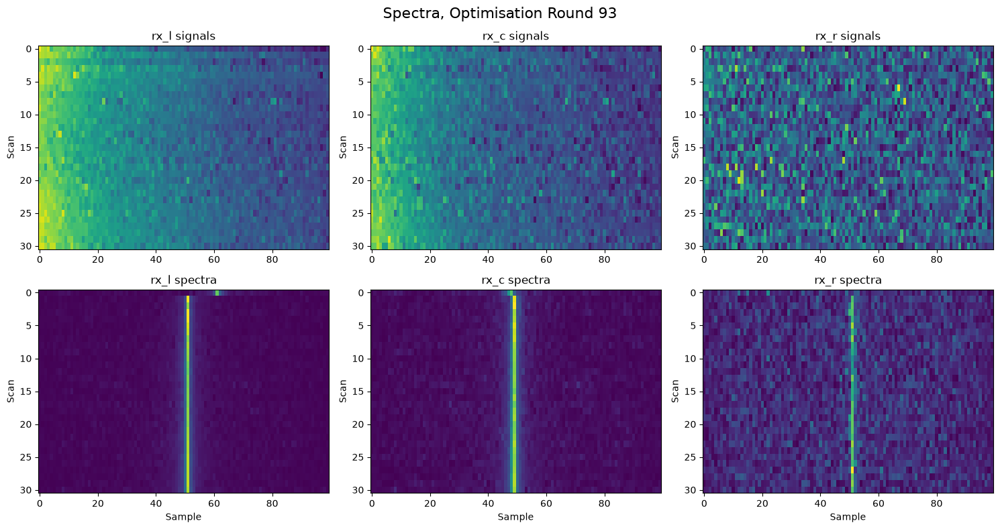

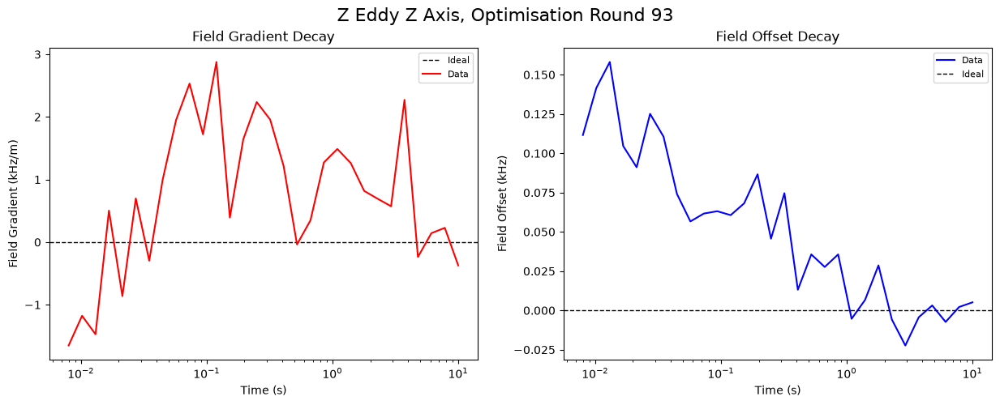

[I 2026-11-24 17:42:53,332] Trial 93 finished with value: 6553.057116323341 and parameters: {'Z_A1': 0.07762250283716304, 'Z_A2': 0.03858738590053863, 'Z_A3': 0.07934202466791276, 'Z_A4': 5.584745660340084e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 6716.641679160418
mean |E| = 4564.051307679491
RMS E = 4708.541610022751
Total cost = 6.553e+03
E max = 0.1206769680680771
E nanmax = 0.1206769680680771
E contains nan = False
B max = 0.013073257824027917
B nanmax = 0.013073257824027917
B contains nan = False
Trial 94


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013073257824027917 !!!!!!!!!!!!!!!!


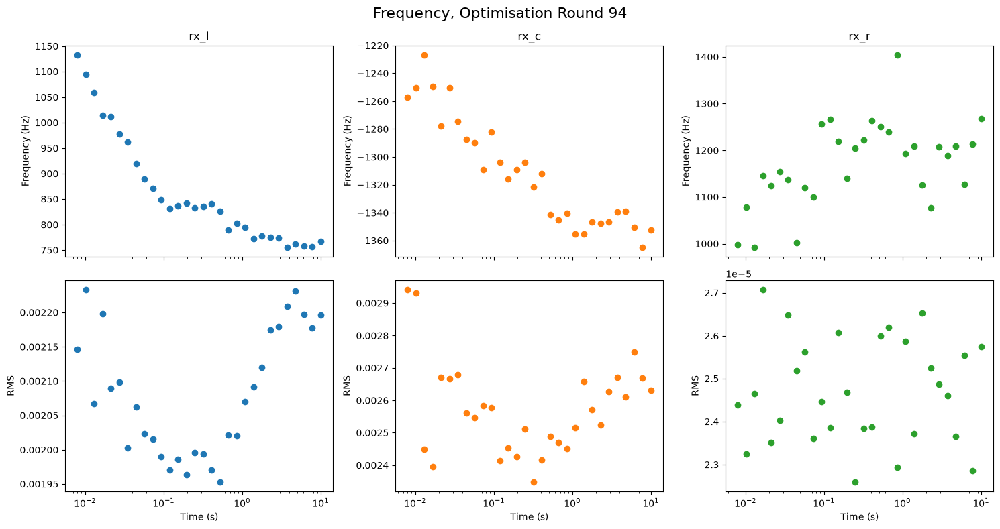

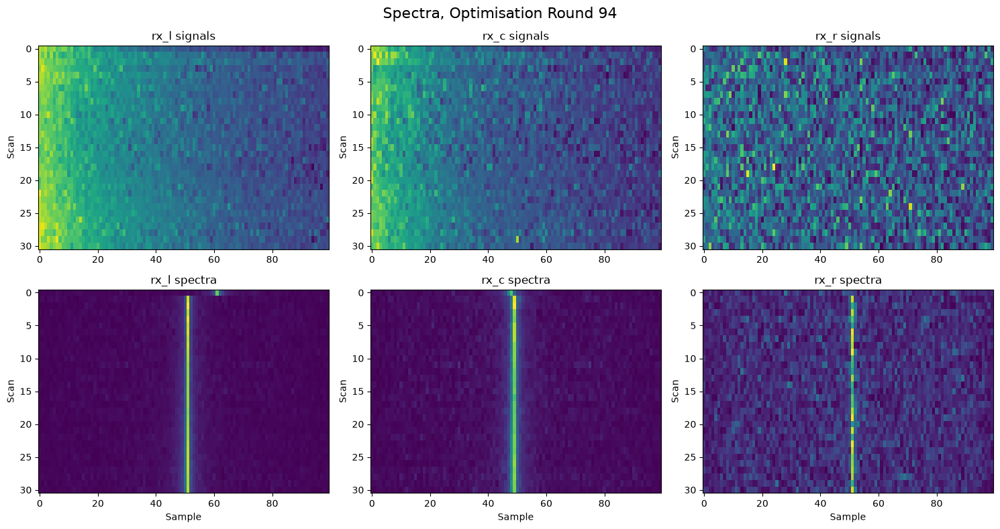

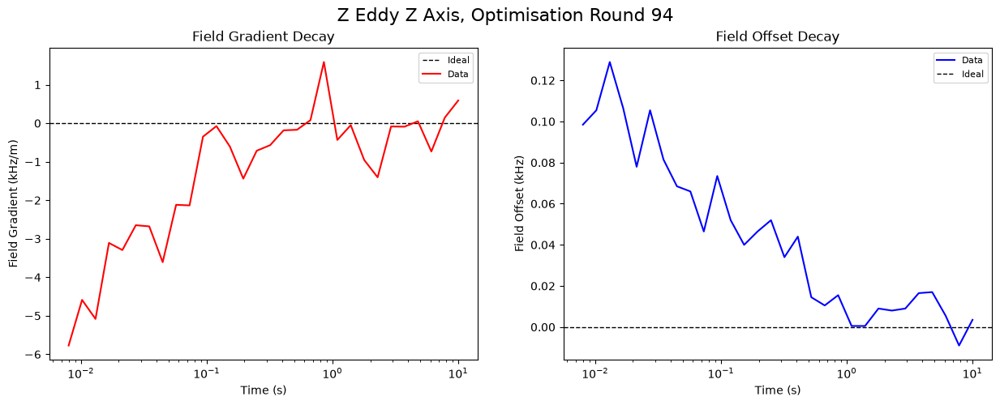

[I 2026-11-24 17:43:41,530] Trial 94 finished with value: 4401.7898384369455 and parameters: {'Z_A1': 0.06897740163480919, 'Z_A2': 0.035662584767537975, 'Z_A3': 0.07975834261399536, 'Z_A4': 4.425471951518773e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 6011.994002998499
mean |E| = 3219.7234715975333
RMS E = 3540.587207646814
Total cost = 4.402e+03
E max = 0.12108671281775484
E nanmax = 0.12108671281775484
E contains nan = False
B max = 0.01311765181354979
B nanmax = 0.01311765181354979
B contains nan = False
Trial 95


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01311765181354979 !!!!!!!!!!!!!!!!


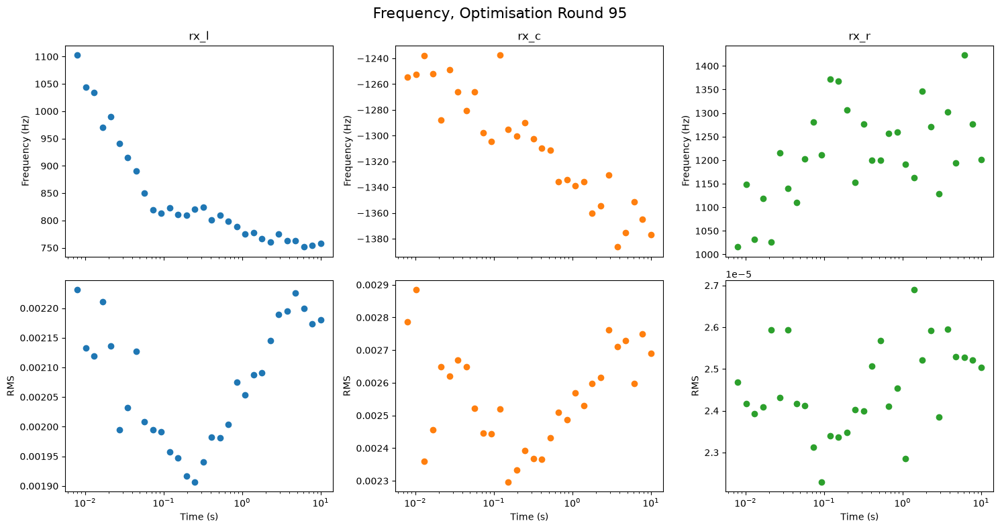

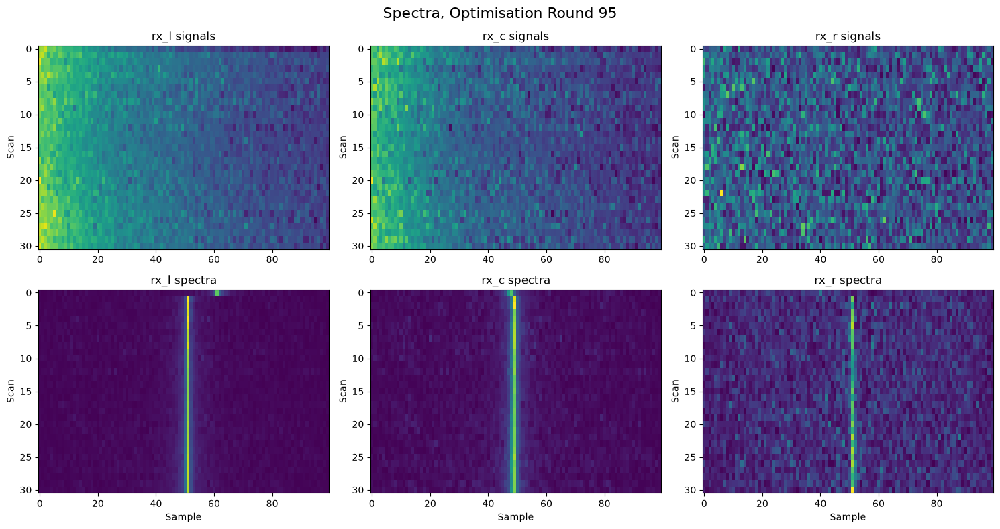

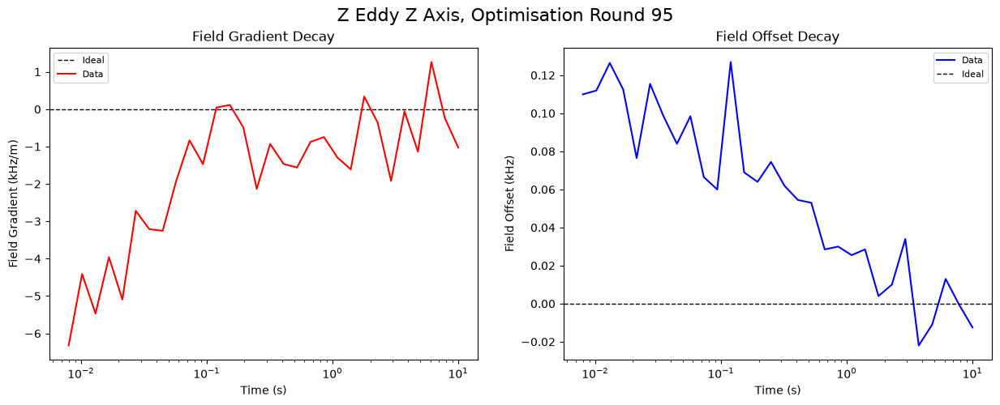

[I 2026-11-24 17:44:29,756] Trial 95 finished with value: 8686.243714706414 and parameters: {'Z_A1': 0.0712612191617586, 'Z_A2': 0.038242229437730785, 'Z_A3': 0.07810752766409515, 'Z_A4': 5.696074684072489e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 6716.641679160419
mean |E| = 3754.622688655671
RMS E = 4109.278579185082
Total cost = 8.686e+03
E max = 0.12201078048585837
E nanmax = 0.12201078048585837
E contains nan = False
B max = 0.013217757775239898
B nanmax = 0.013217757775239898
B contains nan = False
Trial 96


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013217757775239898 !!!!!!!!!!!!!!!!


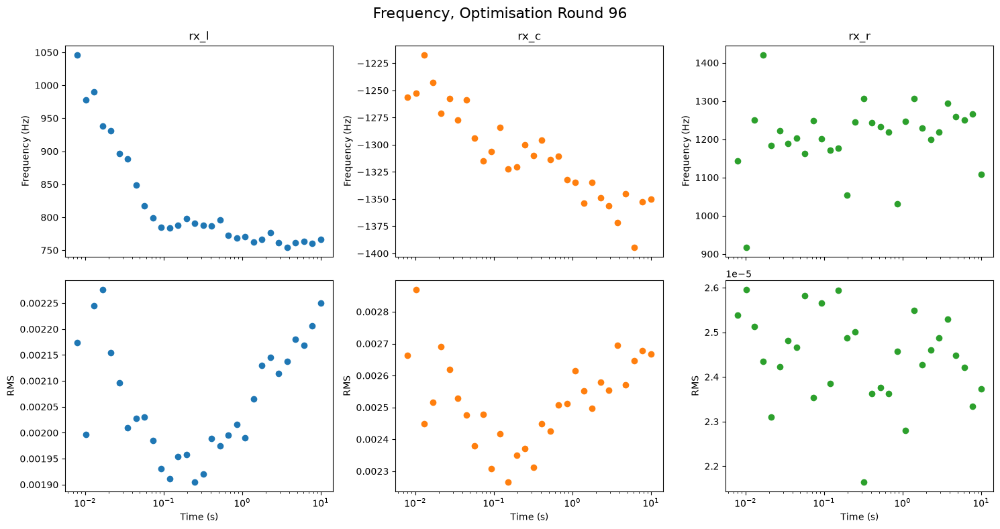

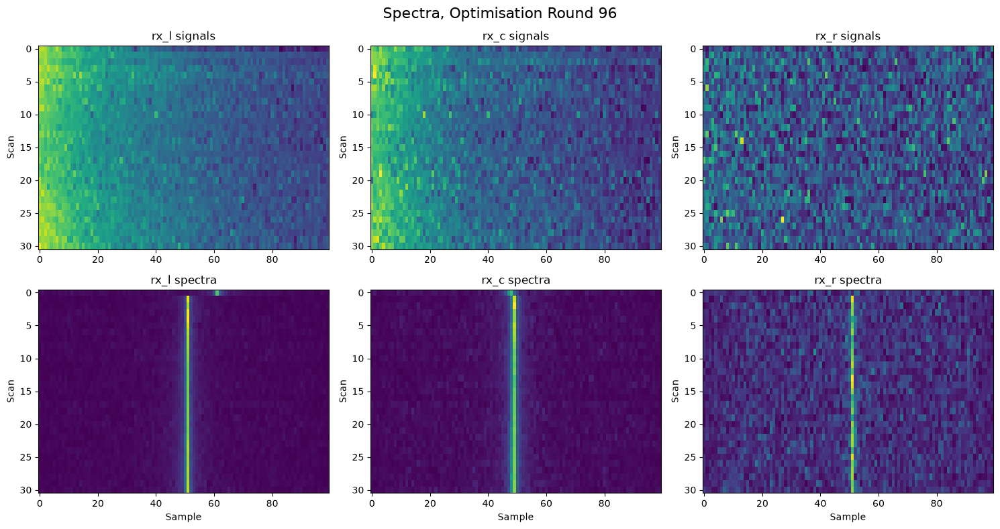

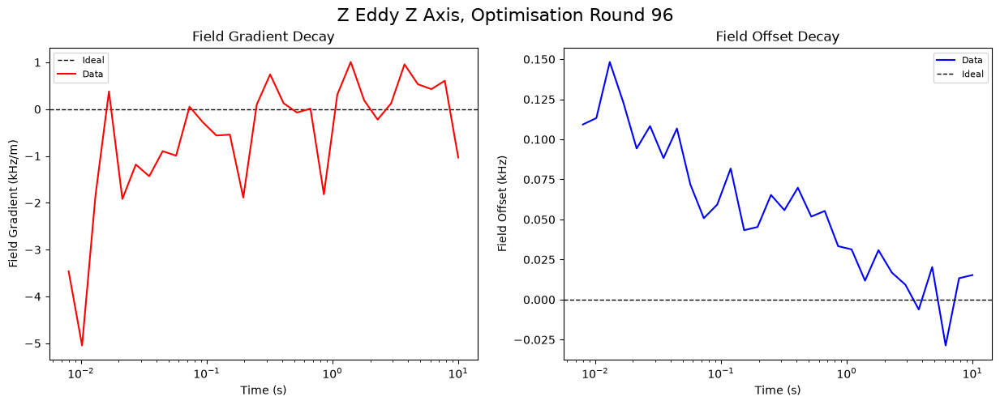

[I 2026-11-24 17:45:17,702] Trial 96 finished with value: 5893.5850883721205 and parameters: {'Z_A1': 0.07446266300036368, 'Z_A2': 0.03659801551888901, 'Z_A3': 0.08367764800136912, 'Z_A4': 6.479827599148757e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5447.276361819088
mean |E| = 3893.386640013325
RMS E = 4070.438230767377
Total cost = 5.894e+03
E max = 0.12104450932502087
E nanmax = 0.12104450932502087
E contains nan = False
B max = 0.013113081315825602
B nanmax = 0.013113081315825602
B contains nan = False
Trial 97


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013113081315825602 !!!!!!!!!!!!!!!!


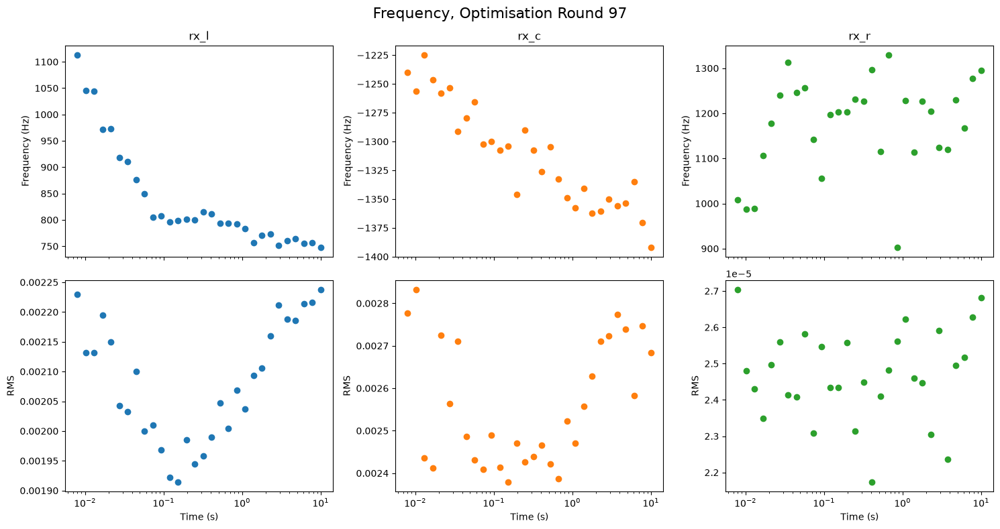

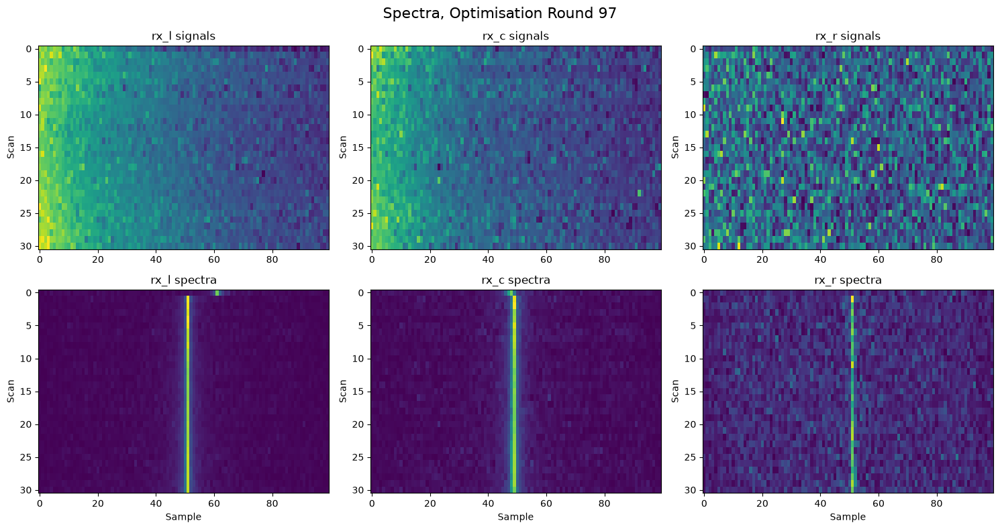

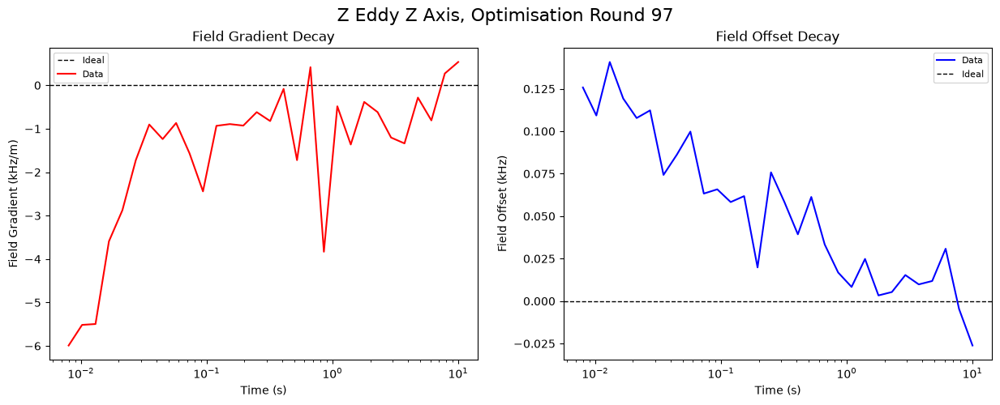

[I 2026-11-24 17:46:05,648] Trial 97 finished with value: 7443.000009509058 and parameters: {'Z_A1': 0.07192790371736216, 'Z_A2': 0.03806437918467738, 'Z_A3': 0.07726495691987331, 'Z_A4': 2.276909848854733e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 5472.263868065967
mean |E| = 3505.5805430618025
RMS E = 3761.7430469890865
Total cost = 7.443e+03
E max = 0.12214934749936893
E nanmax = 0.12214934749936893
E contains nan = False
B max = 0.013232785269601127
B nanmax = 0.013232785269601127
B contains nan = False
Trial 98


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013232785269601127 !!!!!!!!!!!!!!!!


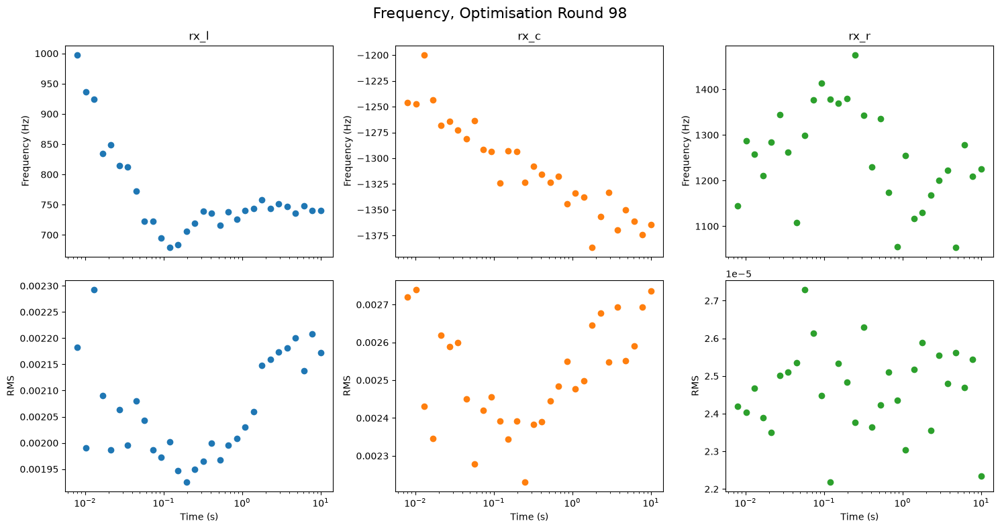

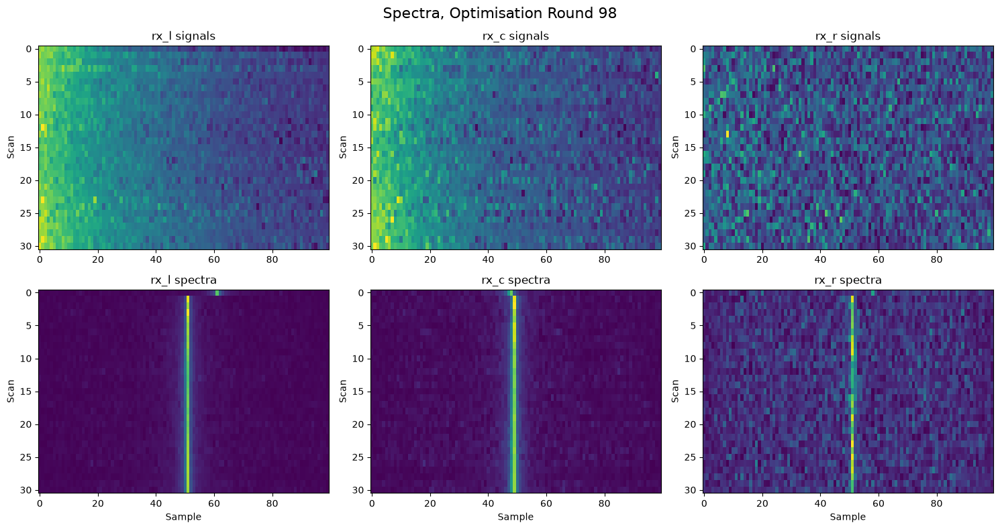

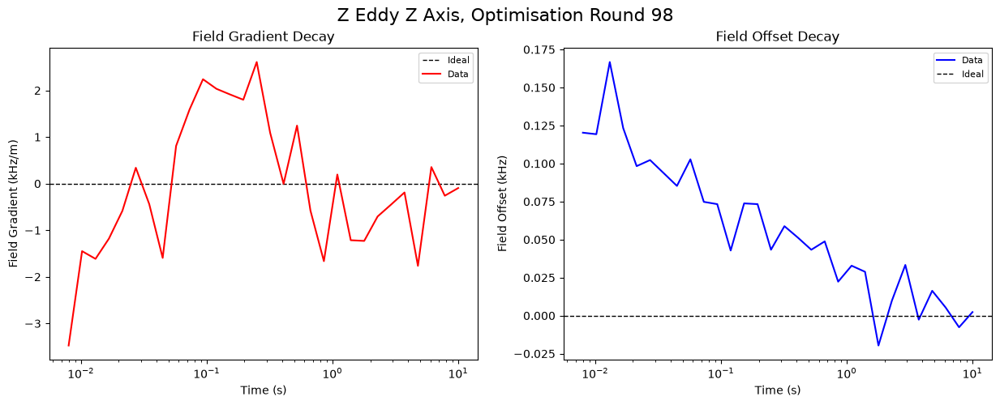

[I 2026-11-24 17:46:54,038] Trial 98 finished with value: 6385.060990200792 and parameters: {'Z_A1': 0.08195063985126333, 'Z_A2': 0.037267916594416965, 'Z_A3': 0.07636516799267655, 'Z_A4': 4.4887405760090836e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 7556.22188905547
mean |E| = 4871.730801266031
RMS E = 5073.276843179166
Total cost = 6.385e+03
E max = 0.11962834159049604
E nanmax = 0.11962834159049604
E contains nan = False
B max = 0.012959658273687957
B nanmax = 0.012959658273687957
B contains nan = False
Trial 99


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012959658273687957 !!!!!!!!!!!!!!!!


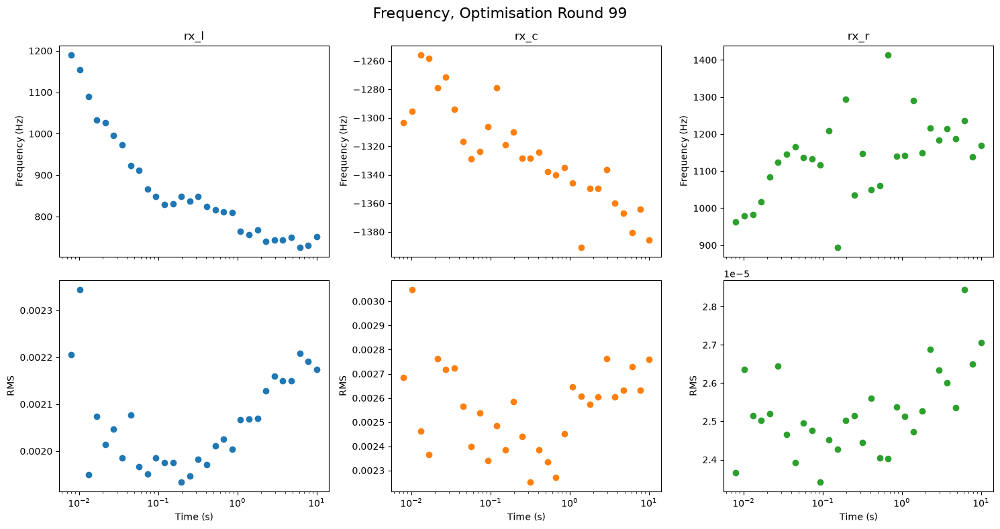

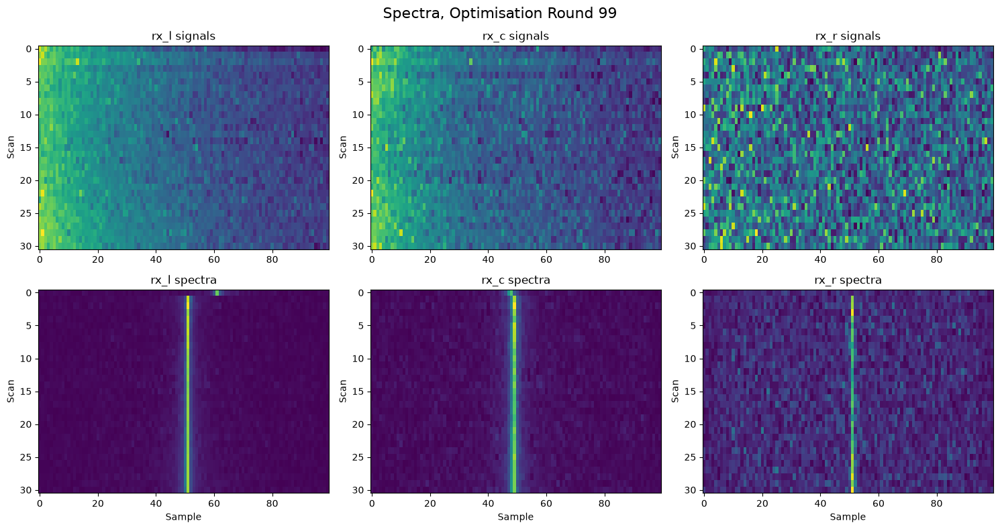

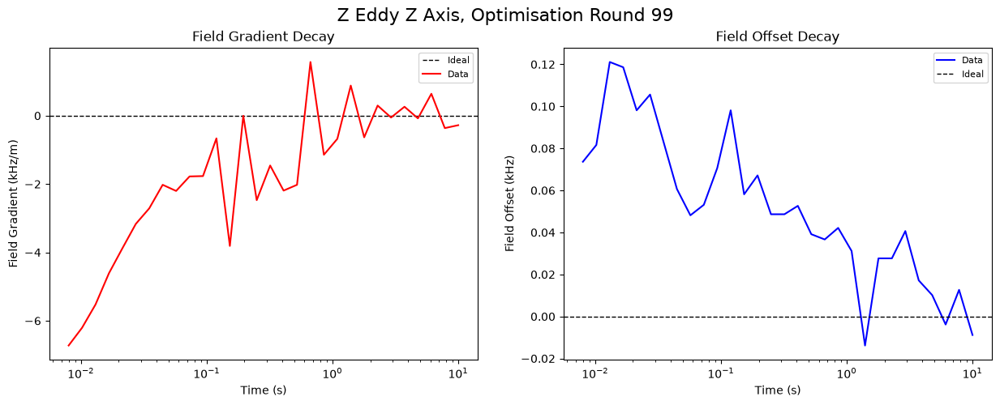

[I 2026-11-24 17:47:42,283] Trial 99 finished with value: 4973.659153650118 and parameters: {'Z_A1': 0.06583957078579906, 'Z_A2': 0.03673646660990861, 'Z_A3': 0.0735685511812839, 'Z_A4': 4.685082061015421e-09}. Best is trial 74 with value: 3223.38361767671.


max |E| = 6021.98900549725
mean |E| = 3042.1455938697313
RMS E = 3395.4876107688
Total cost = 4.974e+03
{'Z_A1': 0.07157718734429569, 'Z_A2': 0.03857581864382493, 'Z_A3': 0.08134770837679353, 'Z_A4': 1.7958706234990015e-09}
74
3223.38361767671
{'Z_A1': 0.07157718734429569, 'Z_A2': 0.03857581864382493, 'Z_A3': 0.08134770837679353, 'Z_A4': 1.7958706234990015e-09}


,trial,cost,g_pe_perc,max_b0var,status,Z_A1,Z_A2,Z_A3,Z_A4
0,0,14225.336201,127.735180,0.013838,PASS,0.081126,0.043852,0.112747,0.000000e+00
1,1,10495.840515,123.546268,0.013385,PASS,0.078065,0.059061,0.069459,-6.733751e-09
2,2,10859.389670,129.190448,0.013996,PASS,0.110389,0.058867,0.078290,3.001183e-10
3,3,8339.313837,120.985326,0.013107,PASS,0.056525,0.046526,0.084089,3.906266e-09
4,4,4360.778707,131.204777,0.014214,PASS,0.084649,0.054744,0.123321,-1.240172e-09
...,...,...,...,...,...,...,...,...,...
95,95,8686.243715,121.086713,0.013118,PASS,0.071261,0.038242,0.078108,5.696075e-09
96,96,5893.585088,122.010780,0.013218,PASS,0.074463,0.036598,0.083678,6.479828e-09
97,97,7443.000010,121.044509,0.013114,PASS,0.071928,0.038064,0.077265,2.276910e-09
98,98,6385.060990,122.149347,0.013233,PASS,0.081951,0.037268,0.076365,4.488741e-09


In [8]:
# ------------------------------------------------------
# start calling optimisation run and analysis
# ------------------------------------------------------

study = optuna.create_study(direction="minimize")

start_params = {}

for i in range(1, MAX_EXP+1):
    start_params[f"{OPT_AXIS}_A{i}"] = E_START[f"{OPT_AXIS}"][f"A{i}"]

study.enqueue_trial(start_params)

study.optimize(lambda trial: opt.objective(trial, OPT_AXIS, metric, g_hzpm, E_START, B_START, 
                                           start_params, percentage, seq_params, g_ideal), n_trials=num_trials)

best = study.best_params
opt.best = best
print(best)

print(study.best_trial.number)
print(study.best_value)
print(study.best_params)

# ----------------------------------
# create df of optimisation information across trials
# ----------------------------------
rows = []

for t in study.trials:

    row = {
        "trial": t.number,
        "cost": t.value,
        "g_pe_perc": t.user_attrs.get("g_pe_perc", np.nan),
        "max_b0var": t.user_attrs.get("max_b0var", np.nan),
        "status": t.user_attrs.get("status", "")
    }

    row.update(t.params)

    rows.append(row)

df_trials = pd.DataFrame(rows)
display(df_trials)
df_trials.to_csv(Path.cwd() / OPT_AXIS / "gradient_info.csv", index=False)

df_pars = pd.DataFrame(seq_params.items(), columns=["Parameter", "Value"])
df_pars.to_csv(Path.cwd() / OPT_AXIS / "df_pars.csv", index=False)

opt.save_to_global(E_START, OPT_AXIS, "eddy_E.yaml")

#### Plot Optimisation Performance

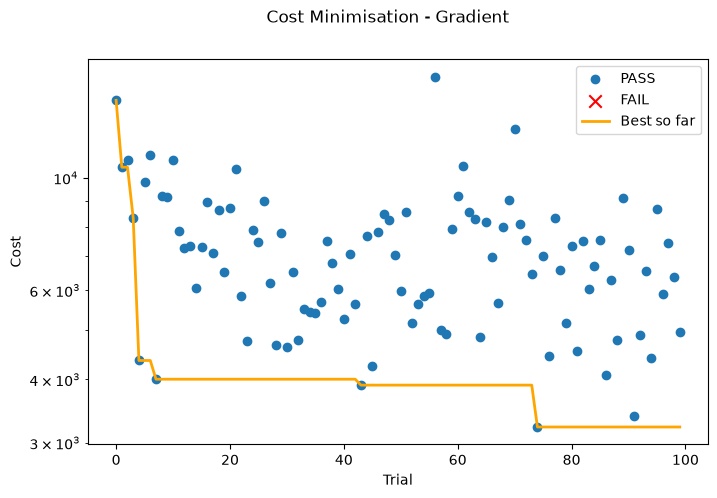

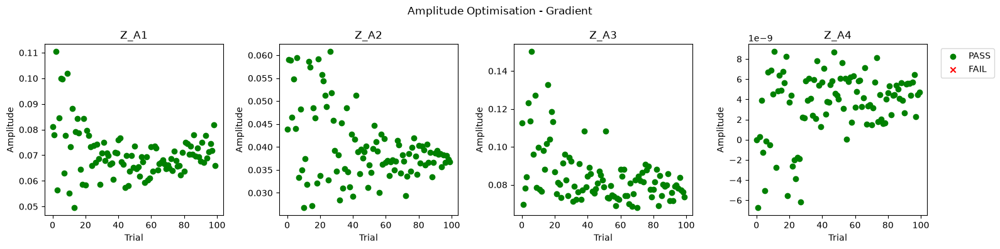

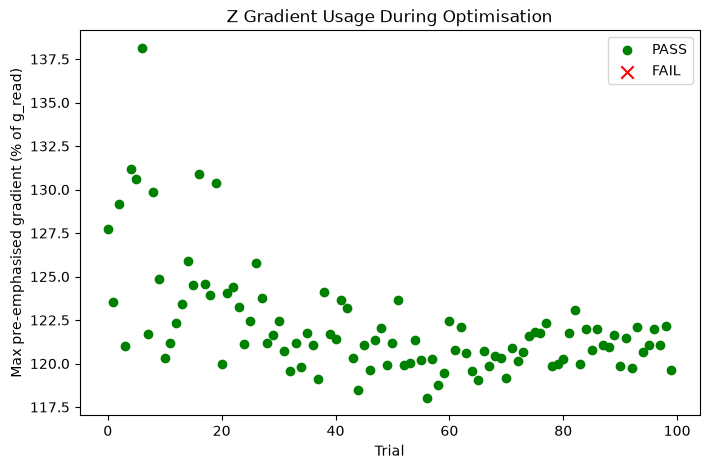

In [9]:
opt.plot_for_optimisation(df_trials, OPT_AXIS, metric)

### Run Offset (B0 Frequency) Optimiser

#### Set optimisation parameters for the offset

In [10]:
num_trials = 100 # number of trials to optimise over
percentage = 50 # percentage of variation the amplitudes of the gradient can have in the optimisation process
metric = "F" # tells that this is optimising the B0 offset (F)

# optimise B0 using the best pre-emphasis parameters from the gradient optimiser
E_START_opt = copy.deepcopy(E_START)
for i in range(1, MAX_EXP+1):
    E_START_opt[f"{OPT_AXIS}"][f"A{i}"] = best[f"{OPT_AXIS}_A{i}"]

#### Start and run optimiser sequence for gradient

[I 2026-11-24 17:47:42,853] A new study created in memory with name: no-name-c2d22876-4092-4799-8183-a92c707edac4


E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013171346850447775
B nanmax = 0.013171346850447775
B contains nan = False
Trial 0


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012959658273687957 !!!!!!!!!!!!!!!!


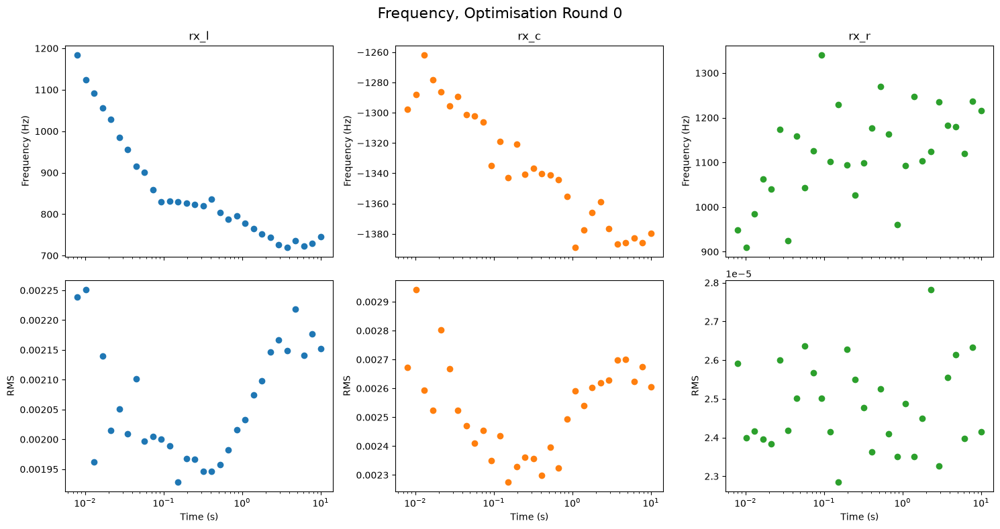

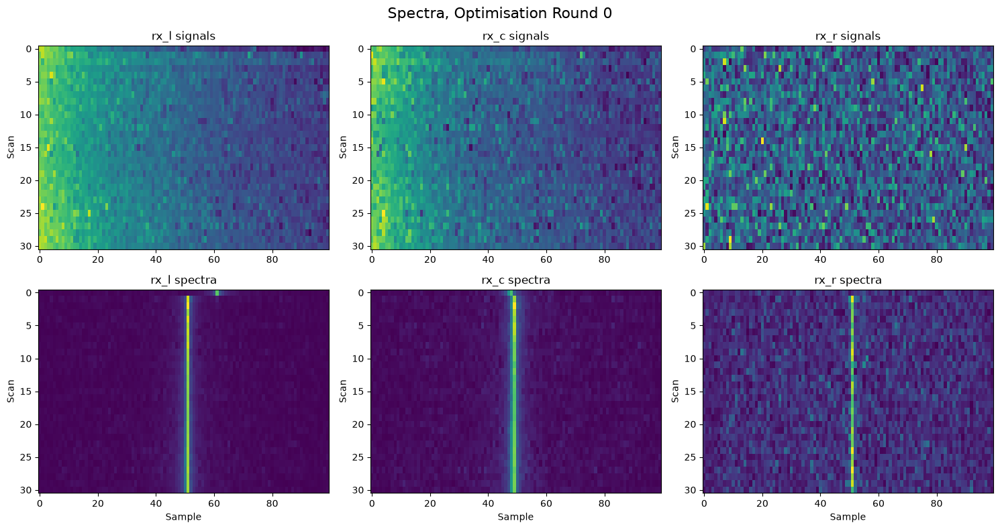

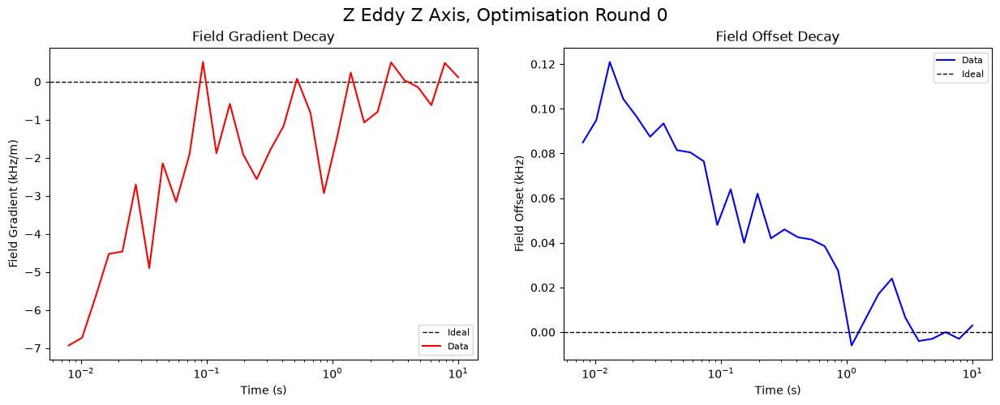

[I 2026-11-24 17:48:30,950] Trial 0 finished with value: 88.05822481559886 and parameters: {'Z_A1': -0.000866483963688, 'Z_A2': -0.0004042300871644, 'Z_A3': 0, 'Z_A4': 0}. Best is trial 0 with value: 88.05822481559886.


rx_c: 8.806e+01
Total cost = 8.806e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.018423604015776838
B nanmax = 0.018423604015776838
B contains nan = False
Trial 1


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01812750425673439 !!!!!!!!!!!!!!!!


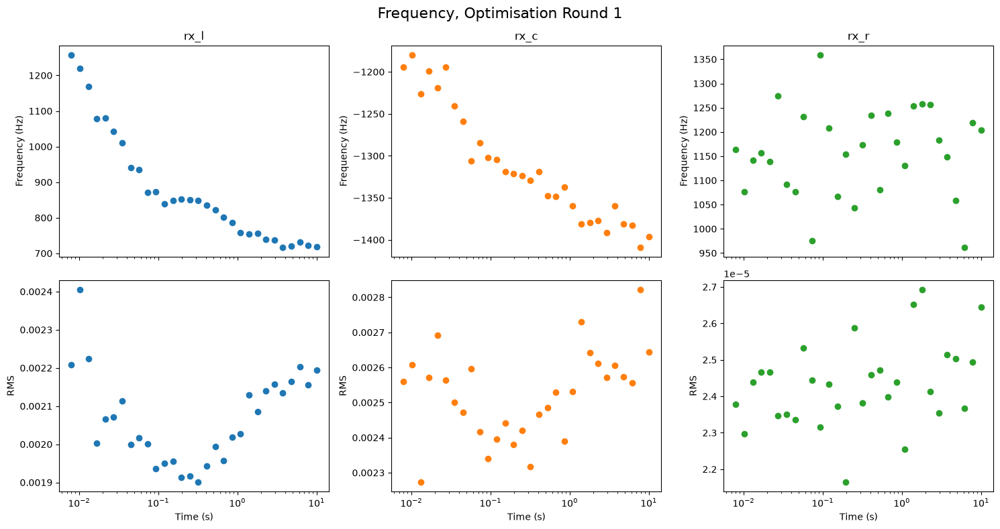

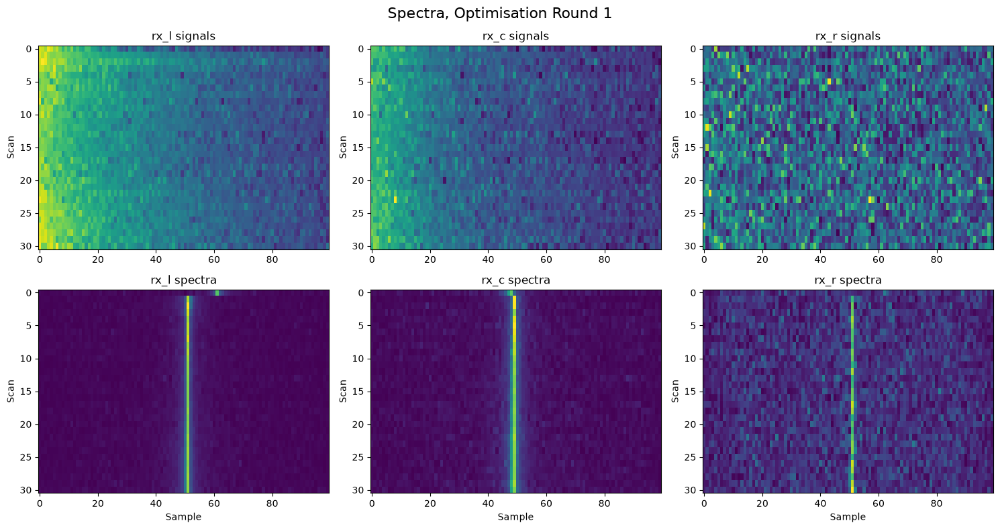

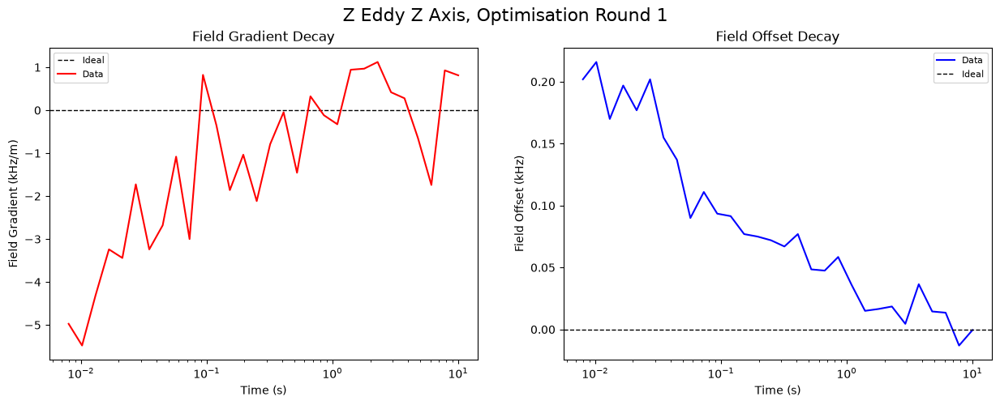

[I 2026-11-24 17:49:19,235] Trial 1 finished with value: 199.7423063482043 and parameters: {'Z_A1': -0.0012747656336527277, 'Z_A2': -0.0005033189925326872, 'Z_A3': 3.782294767466184e-09, 'Z_A4': -8.673926490693302e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.997e+02
Total cost = 1.997e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.011910865132702465
B nanmax = 0.011910865132702465
B contains nan = False
Trial 2


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.011719428822398473 !!!!!!!!!!!!!!!!


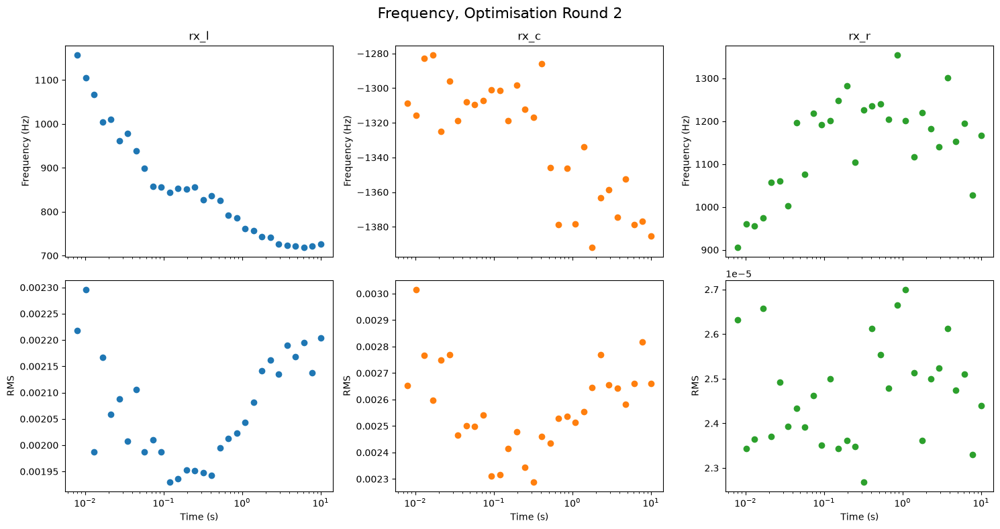

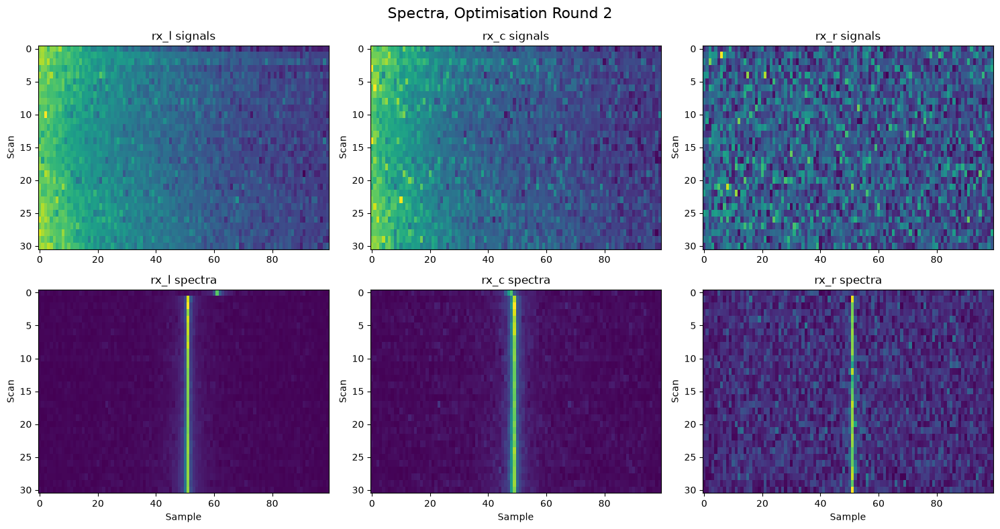

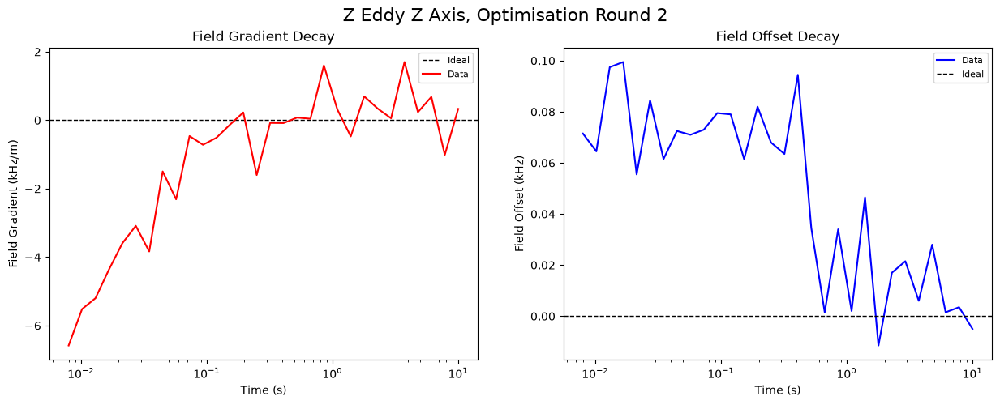

[I 2026-11-24 17:50:07,293] Trial 2 finished with value: 147.21736368074158 and parameters: {'Z_A1': -0.0006354728216611229, 'Z_A2': -0.000512088161180017, 'Z_A3': 4.267051718717828e-09, 'Z_A4': 2.391488242027356e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.472e+02
Total cost = 1.472e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01234857343366317
B nanmax = 0.01234857343366317
B contains nan = False
Trial 3


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012150111172203534 !!!!!!!!!!!!!!!!


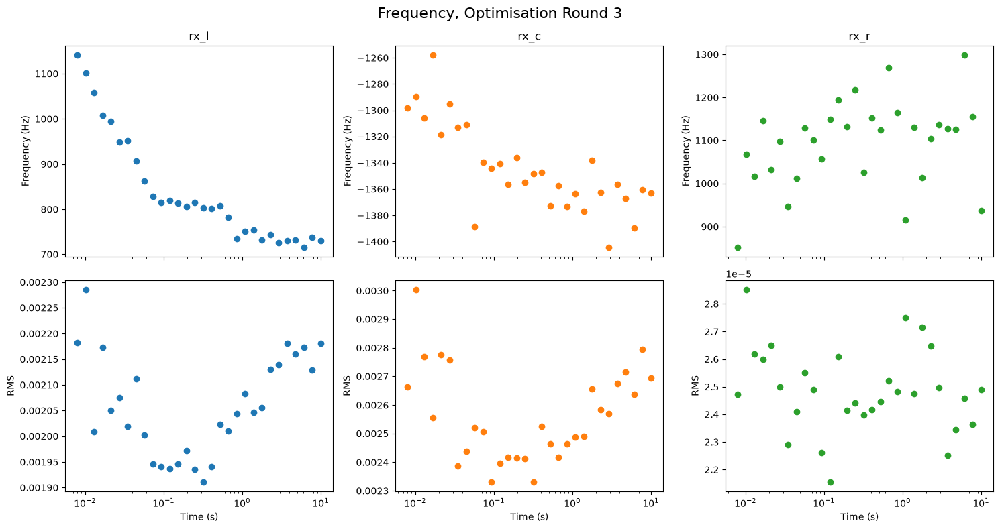

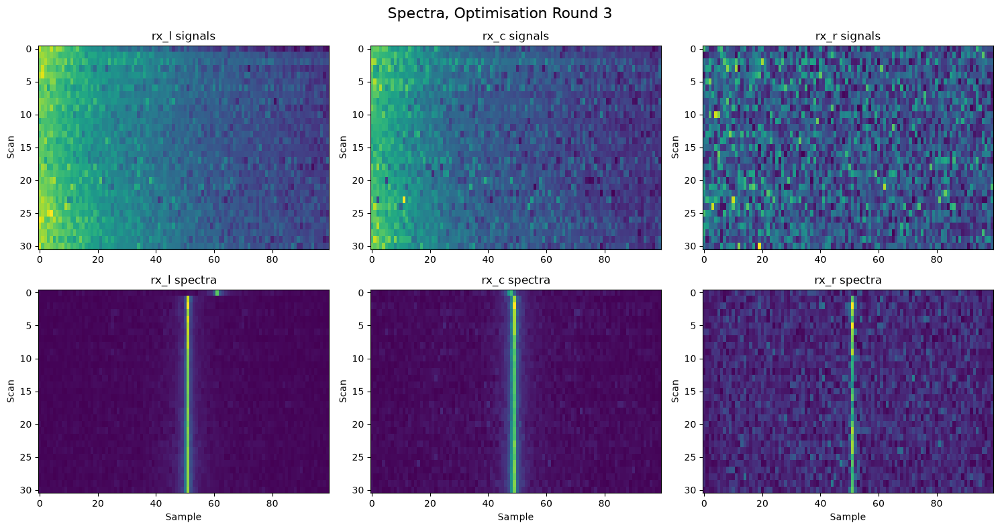

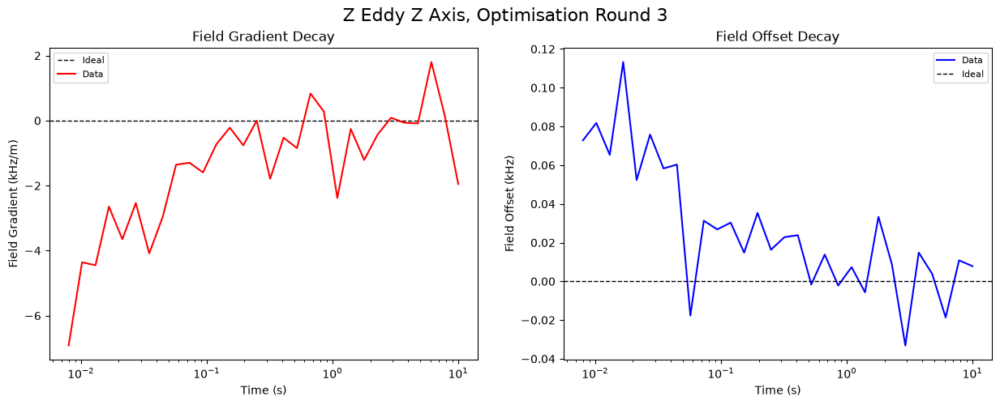

[I 2026-11-24 17:50:55,656] Trial 3 finished with value: 139.86368043483395 and parameters: {'Z_A1': -0.0008802444183091129, 'Z_A2': -0.0003118013526852772, 'Z_A3': 6.519411965635684e-09, 'Z_A4': -4.04370938144913e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.399e+02
Total cost = 1.399e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.015333980043082132
B nanmax = 0.015333980043082132
B contains nan = False
Trial 4


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.015087539590348606 !!!!!!!!!!!!!!!!


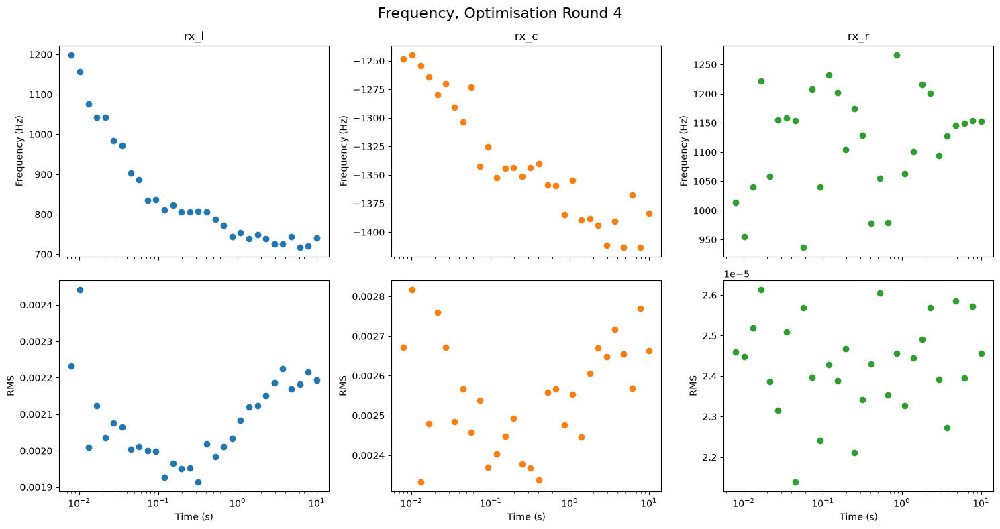

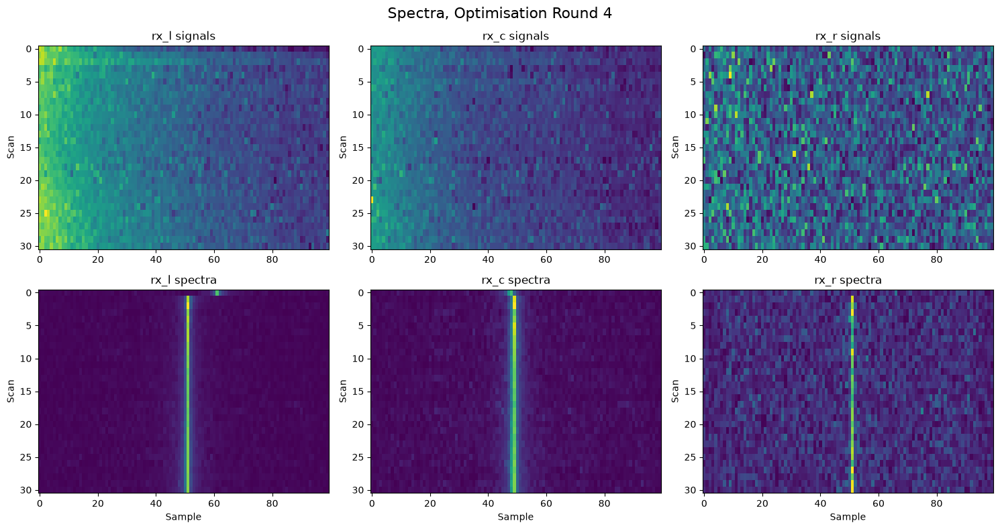

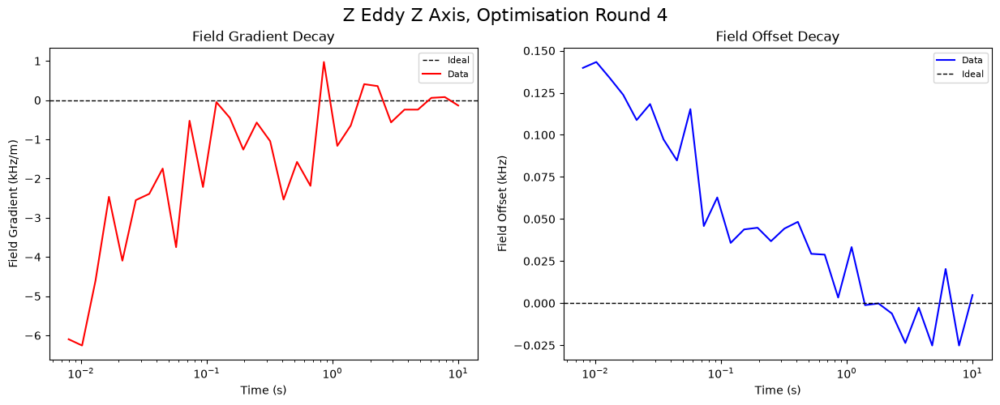

[I 2026-11-24 17:51:44,047] Trial 4 finished with value: 181.05038533546826 and parameters: {'Z_A1': -0.0011490192973745742, 'Z_A2': -0.0003318017066213751, 'Z_A3': 6.868933379709487e-09, 'Z_A4': 1.8301917159691423e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.811e+02
Total cost = 1.811e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.016141153422231123
B nanmax = 0.016141153422231123
B contains nan = False
Trial 5


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01588173826693687 !!!!!!!!!!!!!!!!


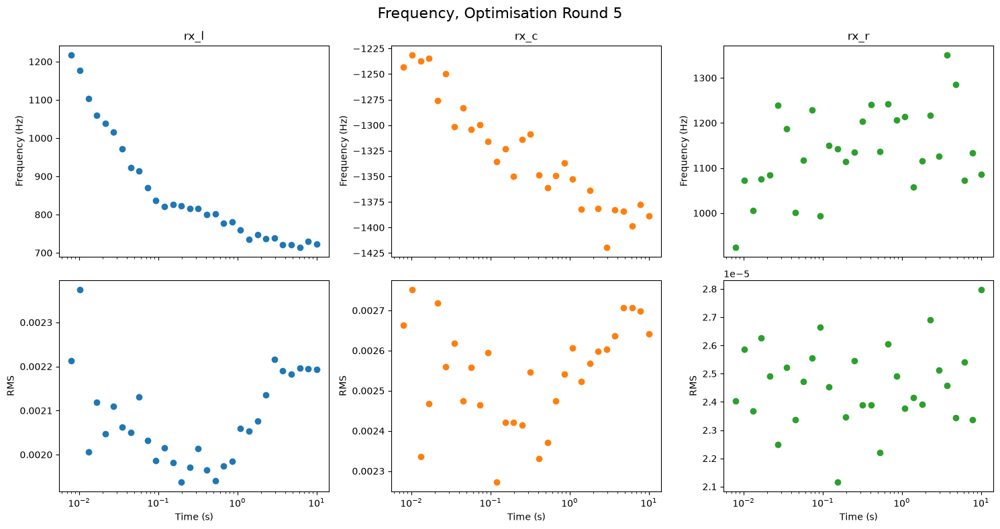

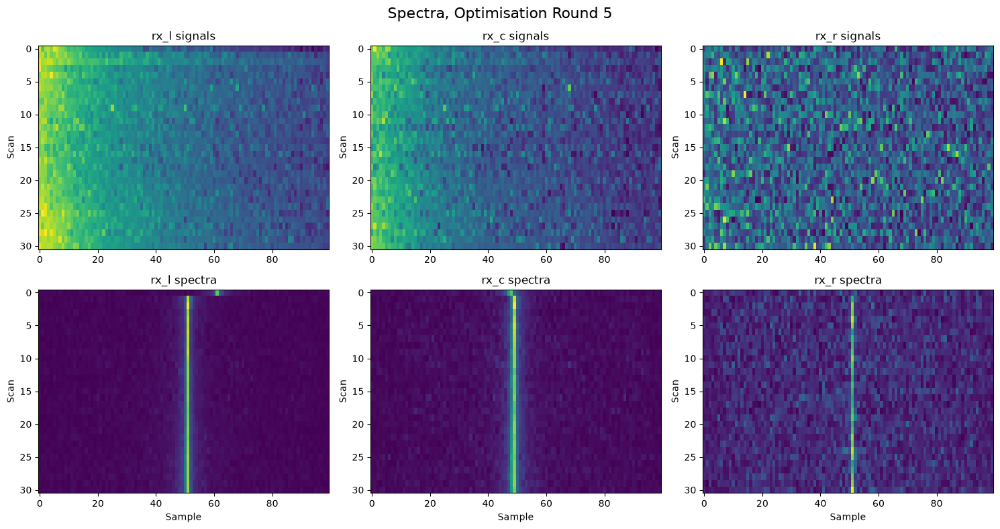

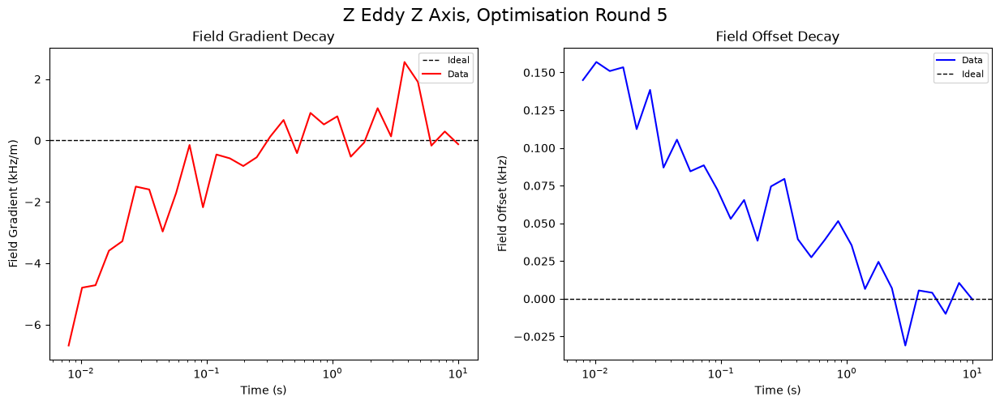

[I 2026-11-24 17:52:32,120] Trial 5 finished with value: 146.72382016071316 and parameters: {'Z_A1': -0.0011559564588172382, 'Z_A2': -0.0004022547802722147, 'Z_A3': 6.498023124093077e-09, 'Z_A4': 3.27669113733315e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.467e+02
Total cost = 1.467e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.007086594551713247
B nanmax = 0.007086594551713247
B contains nan = False
Trial 6


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.006972698558300743 !!!!!!!!!!!!!!!!


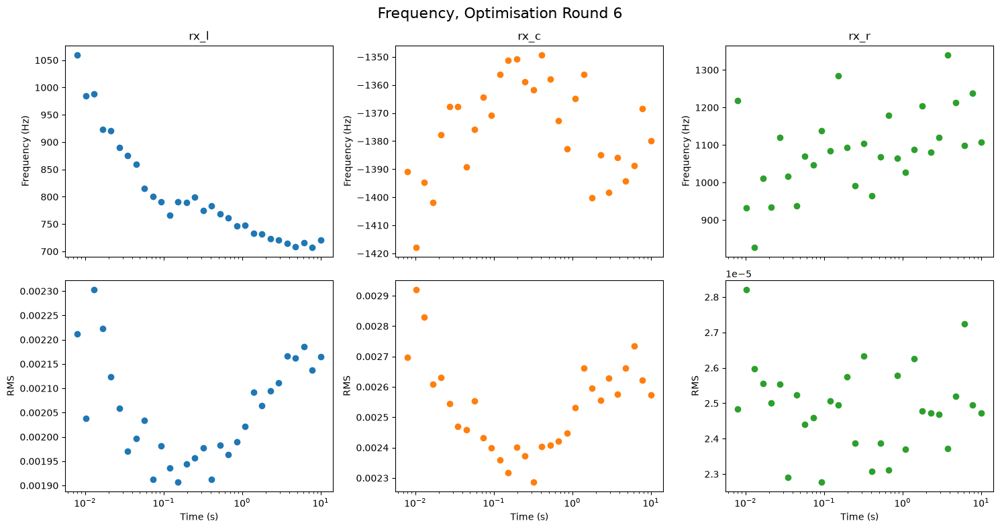

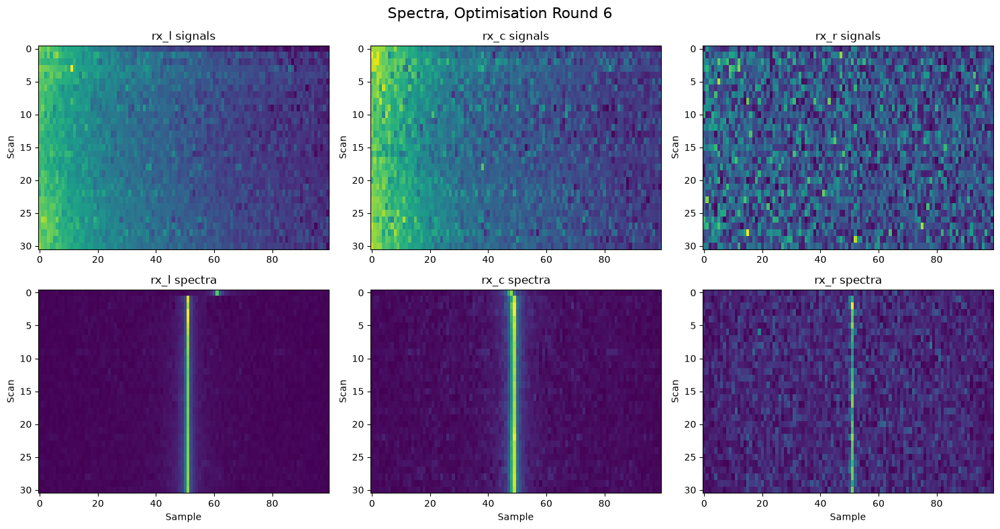

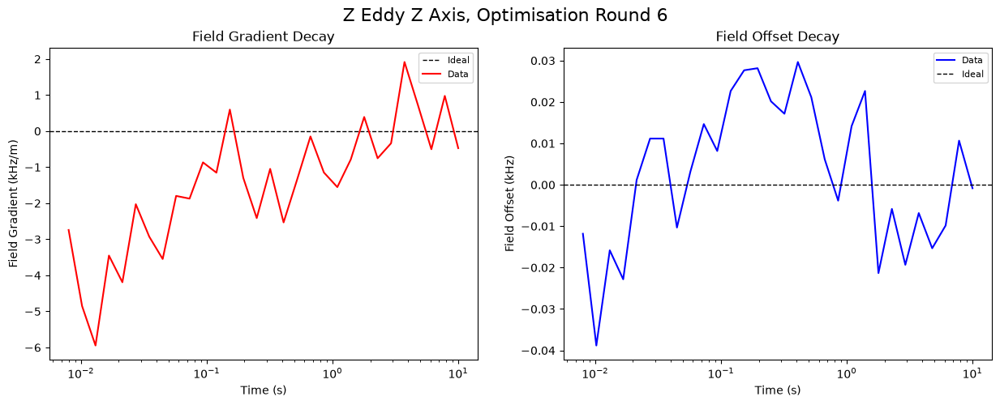

[I 2026-11-24 17:53:19,981] Trial 6 finished with value: 113.98613439720647 and parameters: {'Z_A1': -0.0004430073591152893, 'Z_A2': -0.00024043407375389588, 'Z_A3': -9.078896041267693e-09, 'Z_A4': -5.3300834605771044e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.140e+02
Total cost = 1.140e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014024706584593306
B nanmax = 0.014024706584593306
B contains nan = False
Trial 7


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013799311556254336 !!!!!!!!!!!!!!!!


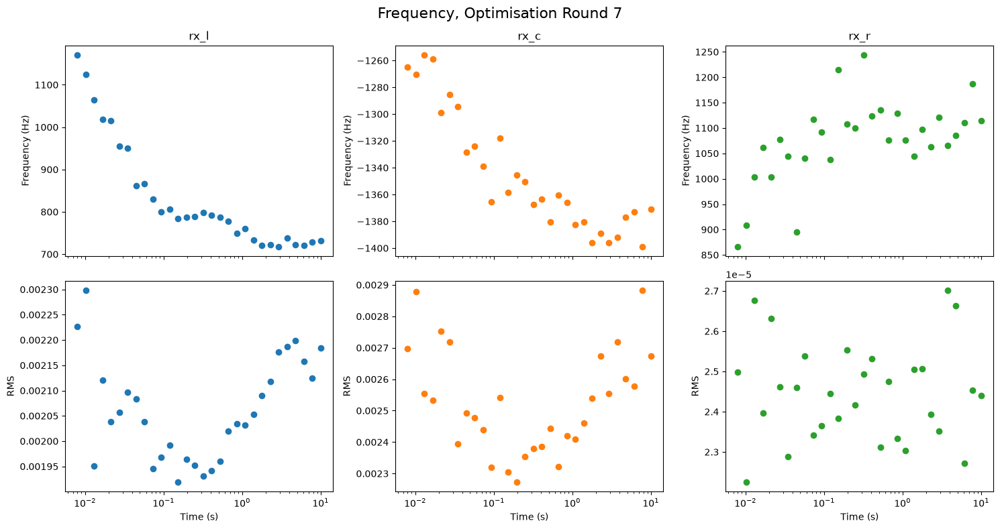

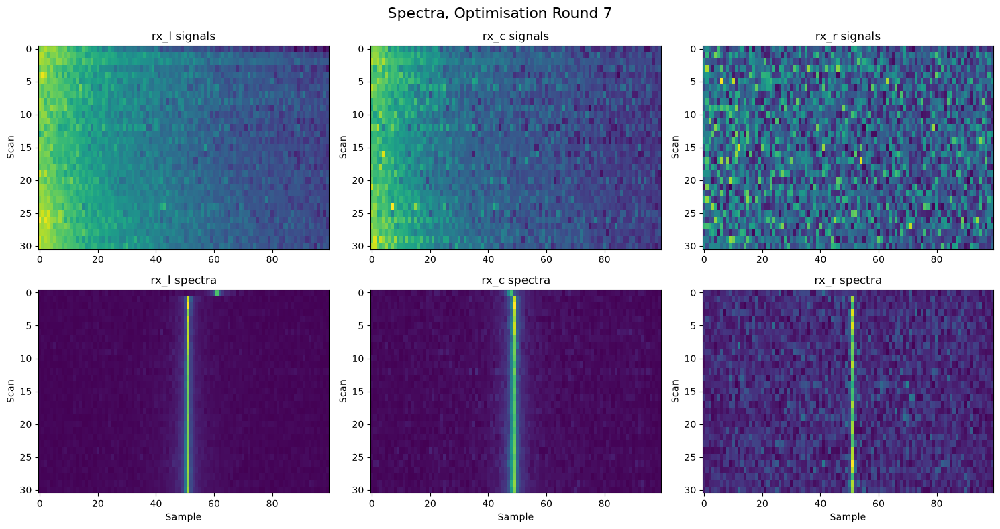

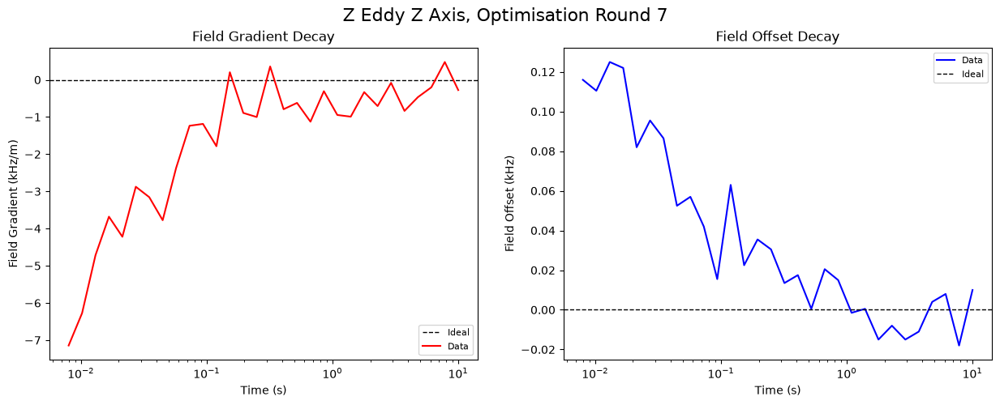

[I 2026-11-24 17:54:07,968] Trial 7 finished with value: 117.13616998273498 and parameters: {'Z_A1': -0.0011339173284192967, 'Z_A2': -0.00022133282649311383, 'Z_A3': -9.89942593279667e-09, 'Z_A4': -8.222897615078256e-10}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.171e+02
Total cost = 1.171e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.00977328325084298
B nanmax = 0.00977328325084298
B contains nan = False
Trial 8


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.009616203841003848 !!!!!!!!!!!!!!!!


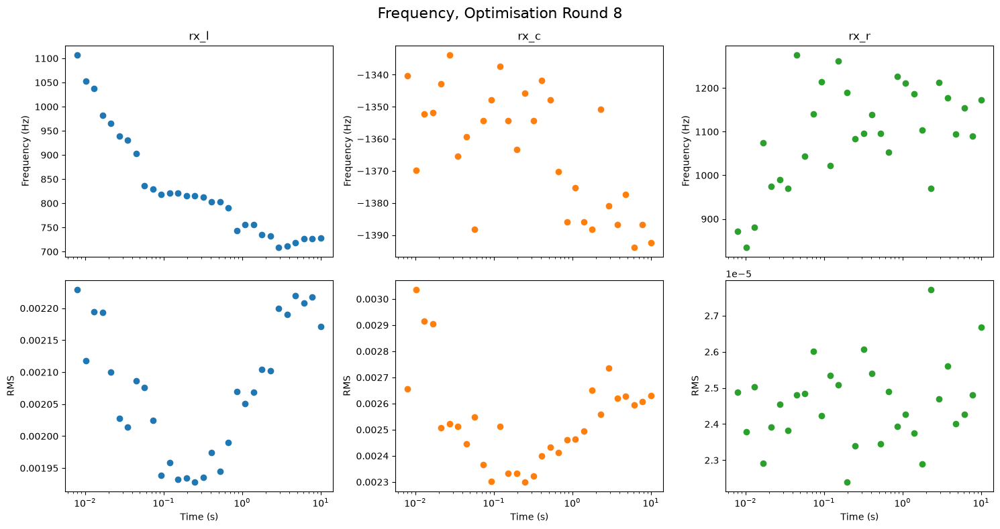

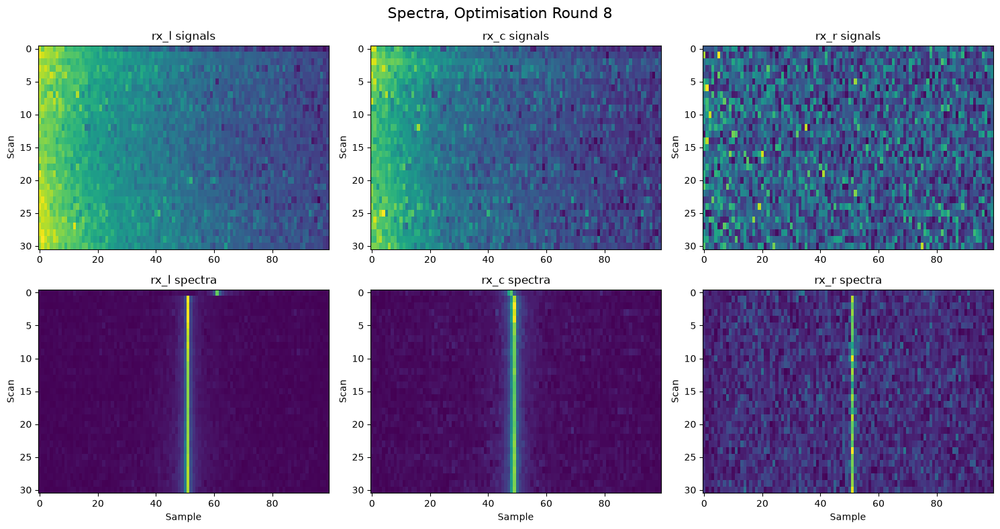

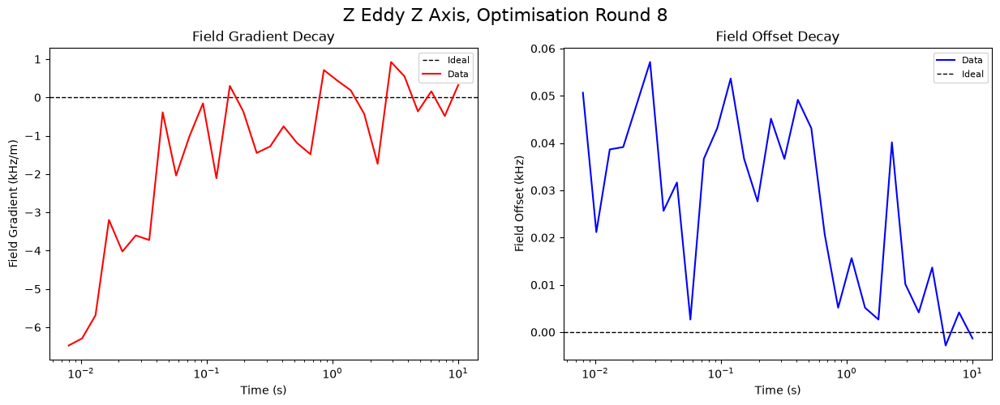

[I 2026-11-24 17:54:56,047] Trial 8 finished with value: 99.8478754396836 and parameters: {'Z_A1': -0.0005411299354210665, 'Z_A2': -0.0004006900181828467, 'Z_A3': 9.520520161668572e-09, 'Z_A4': 2.5109048408495332e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 9.985e+01
Total cost = 9.985e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01664661454823551
B nanmax = 0.01664661454823551
B contains nan = False
Trial 9


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.016379074841894246 !!!!!!!!!!!!!!!!


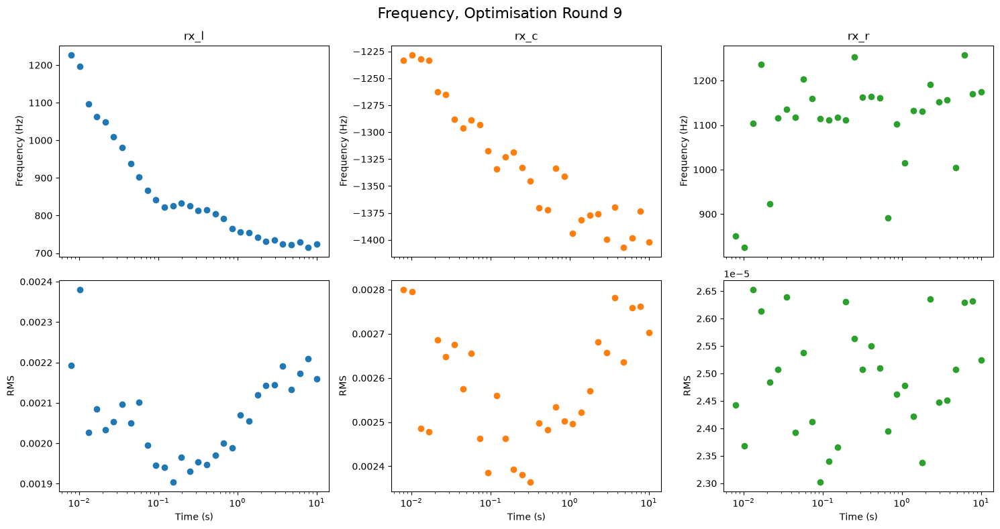

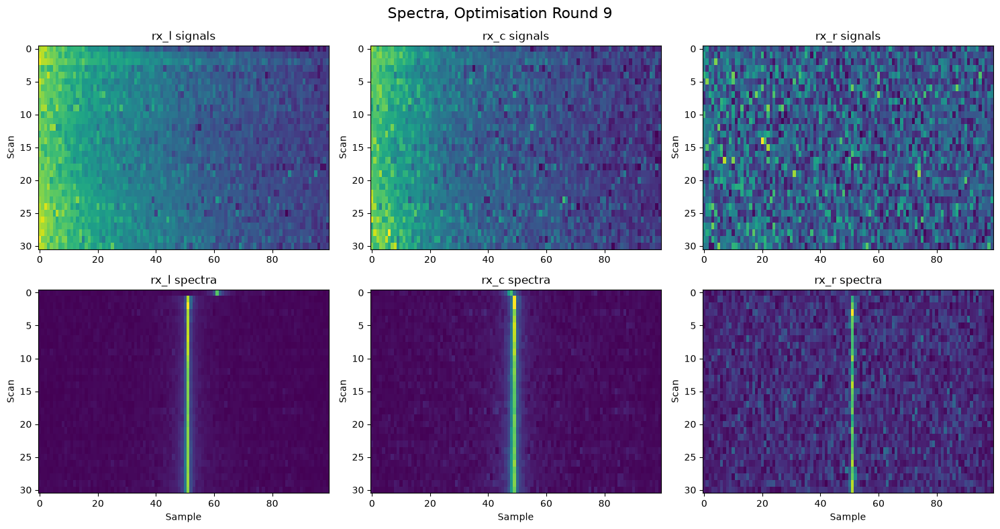

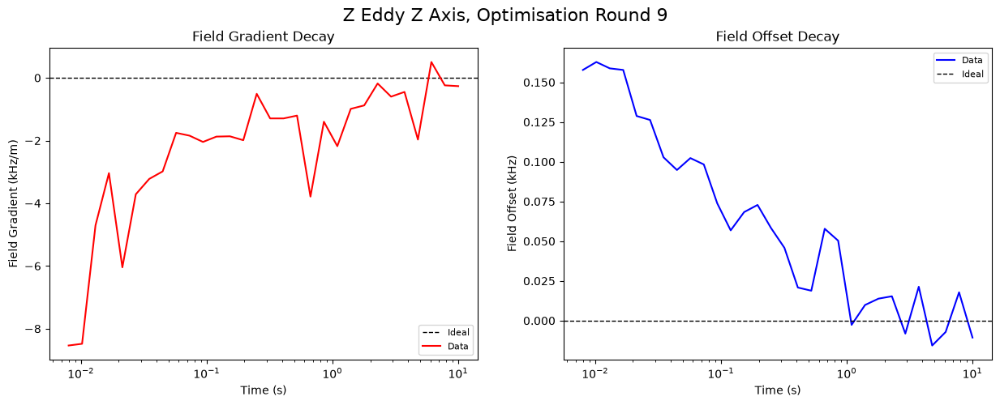

[I 2026-11-24 17:55:44,190] Trial 9 finished with value: 170.57474699890088 and parameters: {'Z_A1': -0.0011689578780046887, 'Z_A2': -0.00043780645861257587, 'Z_A3': 1.329110491990308e-09, 'Z_A4': 1.3881263651510722e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.706e+02
Total cost = 1.706e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012652581397364917
B nanmax = 0.012652581397364917
B contains nan = False
Trial 10


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012449230697088599 !!!!!!!!!!!!!!!!


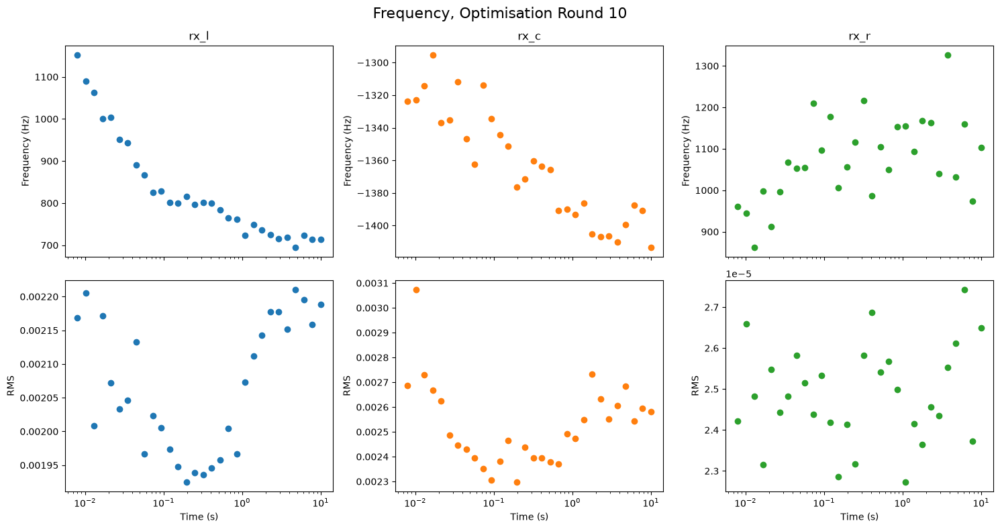

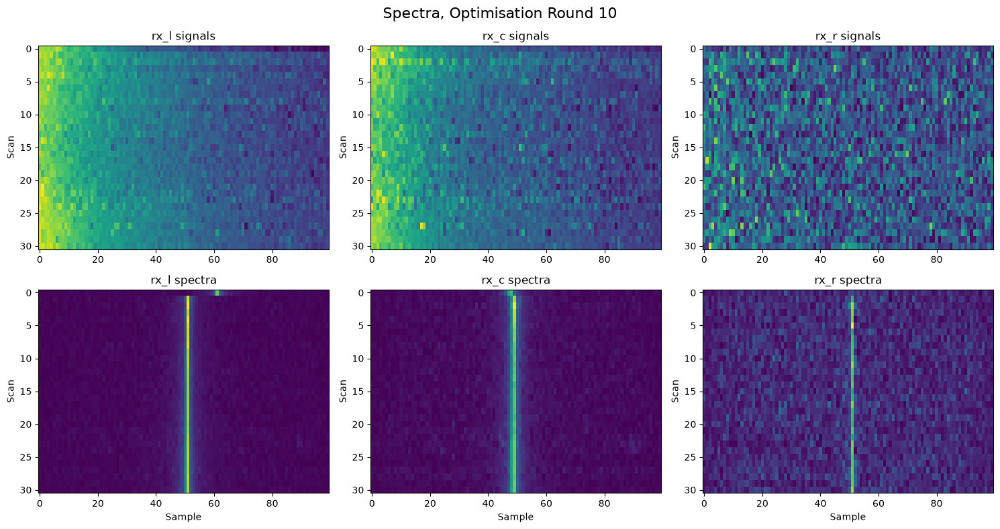

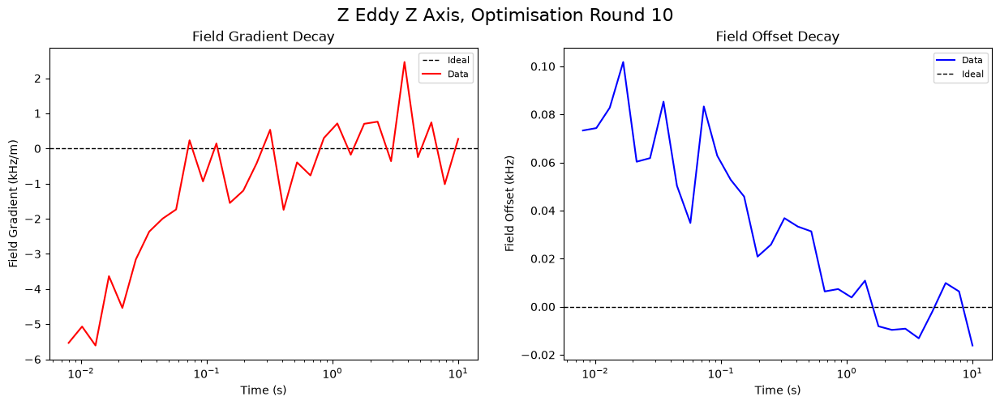

[I 2026-11-24 17:56:32,299] Trial 10 finished with value: 105.58485213658236 and parameters: {'Z_A1': -0.0008404001559192133, 'Z_A2': -0.0003803497092772776, 'Z_A3': -5.634916061295769e-09, 'Z_A4': -1.2230084159365421e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.056e+02
Total cost = 1.056e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.008024539547644004
B nanmax = 0.008024539547644004
B contains nan = False
Trial 11


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.007895566624907561 !!!!!!!!!!!!!!!!


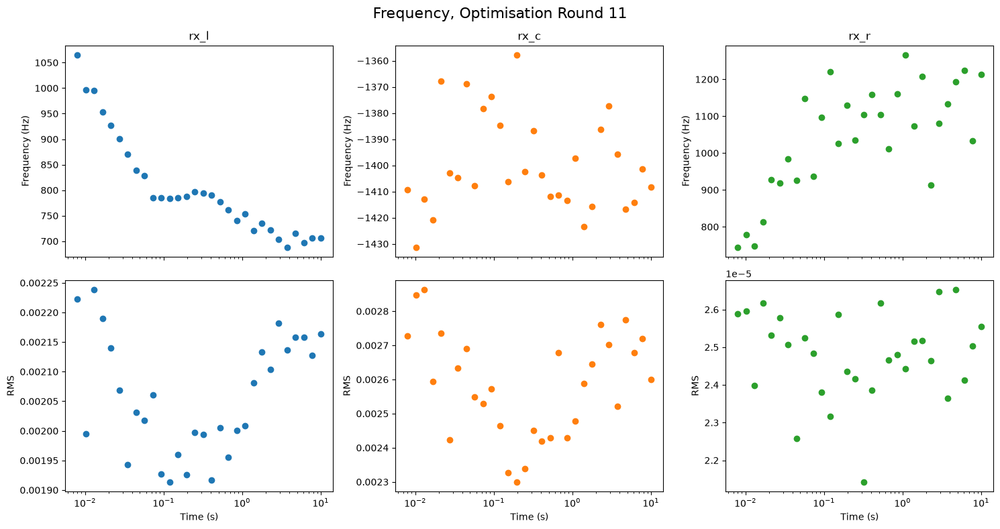

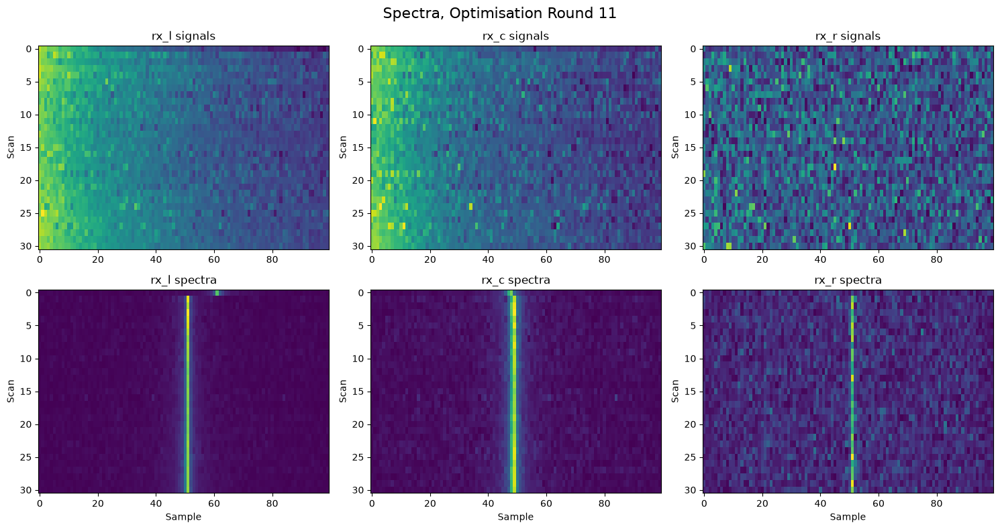

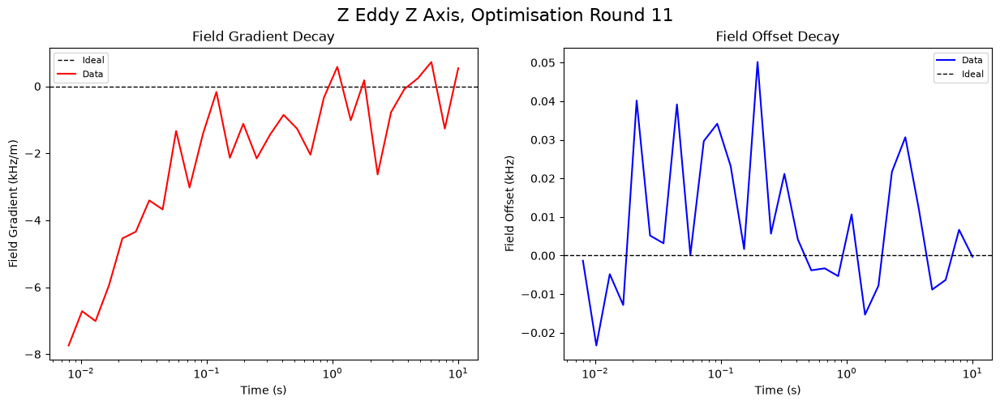

[I 2026-11-24 17:57:20,475] Trial 11 finished with value: 100.96805958512802 and parameters: {'Z_A1': -0.00044687797611615355, 'Z_A2': -0.000326448040308532, 'Z_A3': 7.070453367852877e-09, 'Z_A4': 8.02158834347525e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.010e+02
Total cost = 1.010e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014102301369982988
B nanmax = 0.014102301369982988
B contains nan = False
Trial 12


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013875646206264032 !!!!!!!!!!!!!!!!


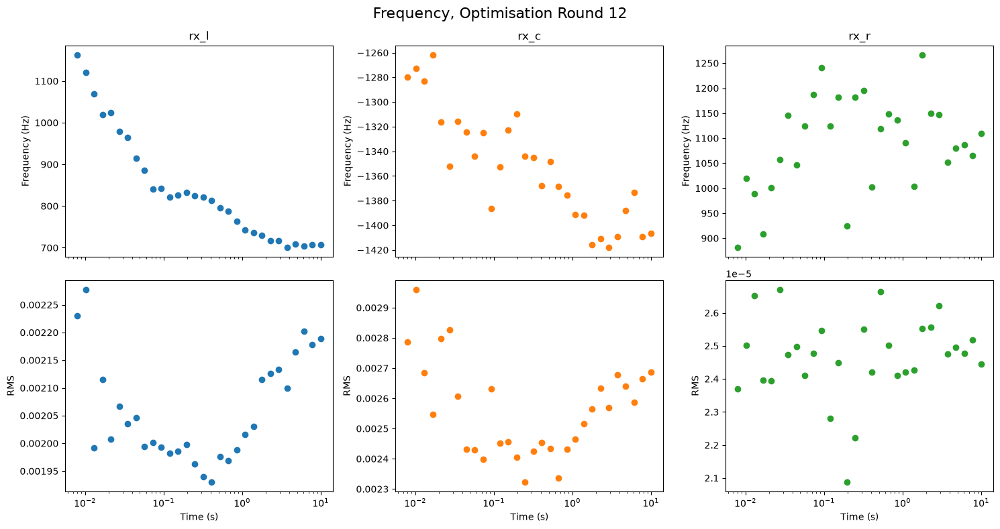

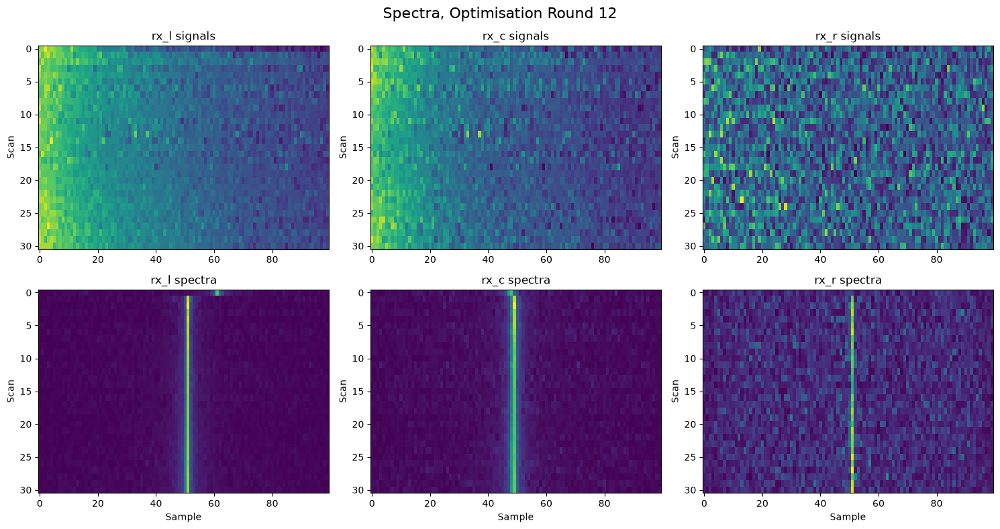

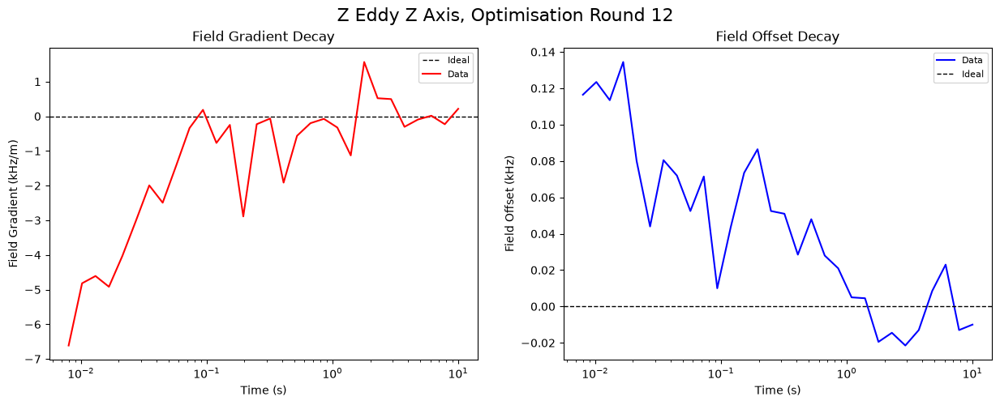

[I 2026-11-24 17:58:08,852] Trial 12 finished with value: 168.32504900628814 and parameters: {'Z_A1': -0.0008209115111434704, 'Z_A2': -0.0005385009186948318, 'Z_A3': -5.186847517333351e-09, 'Z_A4': -1.7784839566909702e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.683e+02
Total cost = 1.683e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.009989456309738557
B nanmax = 0.009989456309738557
B contains nan = False
Trial 13


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.009828902654813988 !!!!!!!!!!!!!!!!


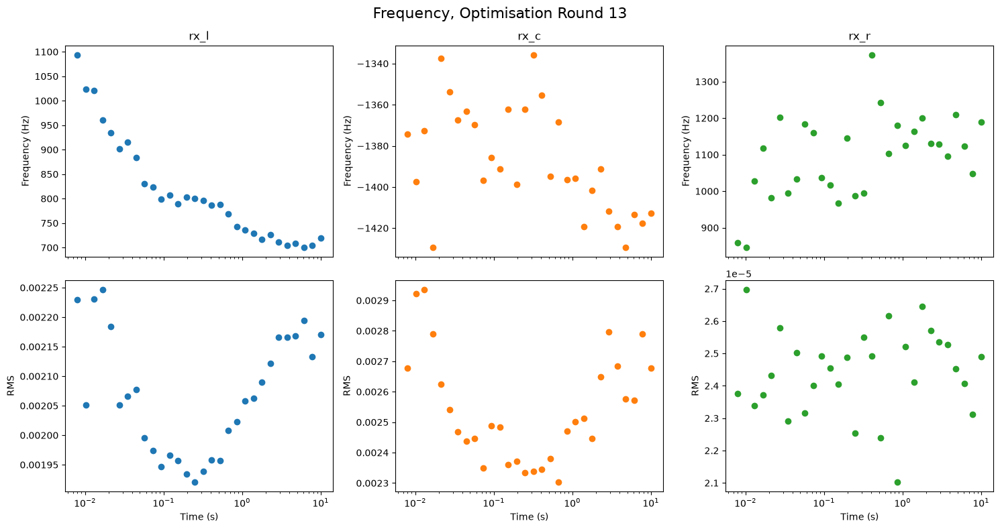

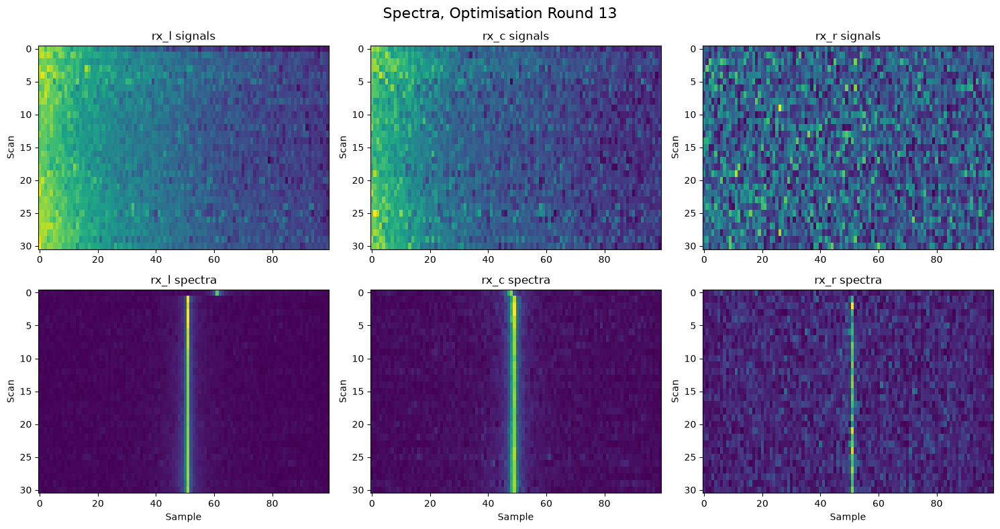

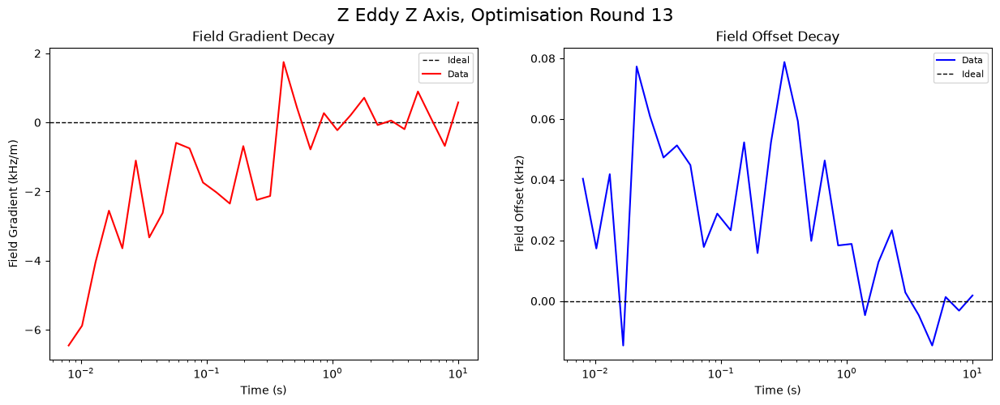

[I 2026-11-24 17:58:57,334] Trial 13 finished with value: 96.51435090694461 and parameters: {'Z_A1': -0.0005569810995597153, 'Z_A2': -0.00040571131909463516, 'Z_A3': 3.636829742126076e-09, 'Z_A4': 1.629254723241168e-10}. Best is trial 0 with value: 88.05822481559886.


rx_c: 9.651e+01
Total cost = 9.651e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.009936214475692555
B nanmax = 0.009936214475692555
B contains nan = False
Trial 14


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.009776517744243656 !!!!!!!!!!!!!!!!


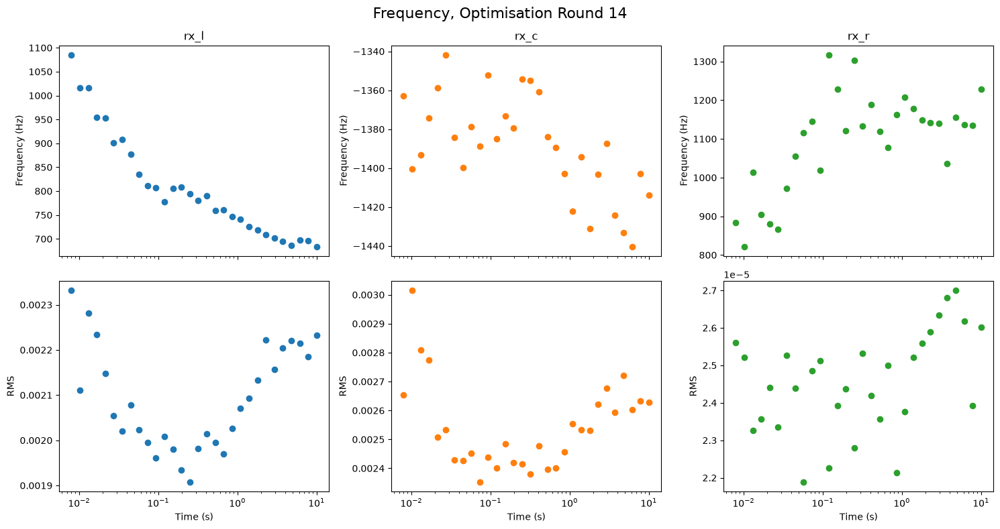

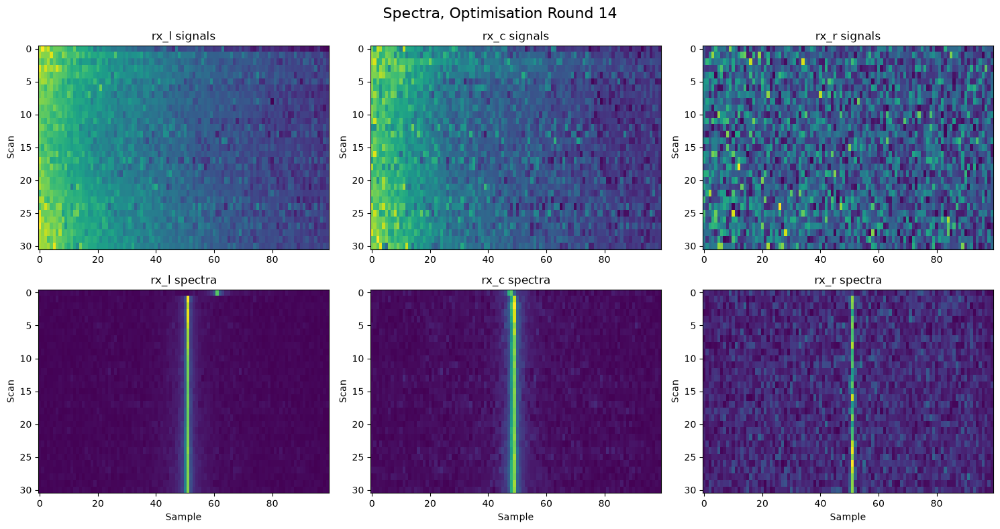

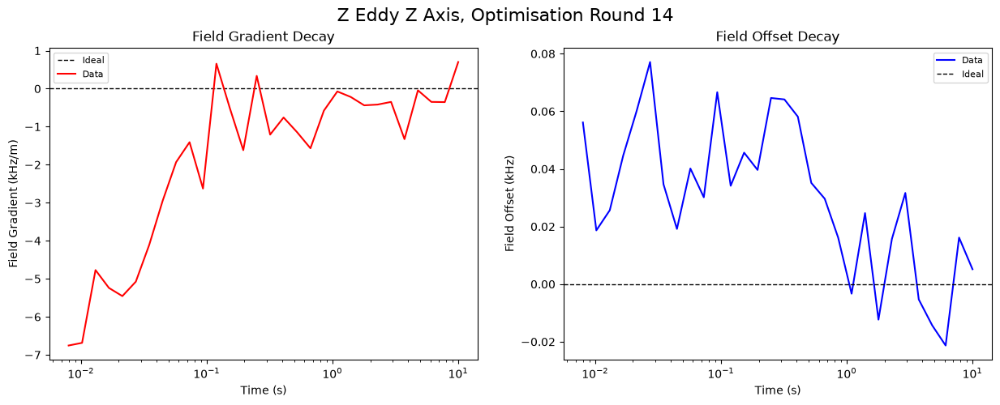

[I 2026-11-24 17:59:45,270] Trial 14 finished with value: 175.2182474031395 and parameters: {'Z_A1': -0.0005833877950000832, 'Z_A2': -0.000374480586290018, 'Z_A3': -2.599325813986034e-09, 'Z_A4': -5.591911785865152e-10}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.752e+02
Total cost = 1.752e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012451151738161923
B nanmax = 0.012451151738161923
B contains nan = False
Trial 15


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01225103916756478 !!!!!!!!!!!!!!!!


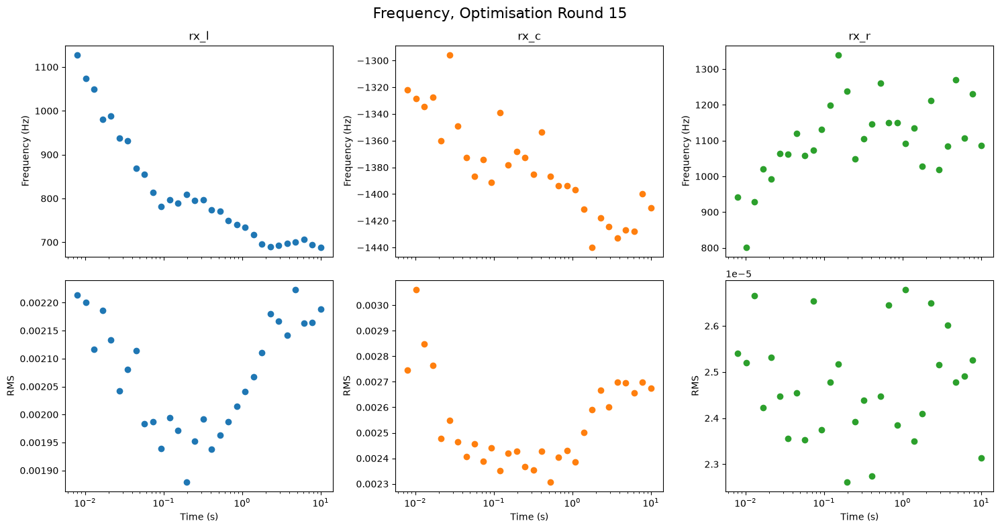

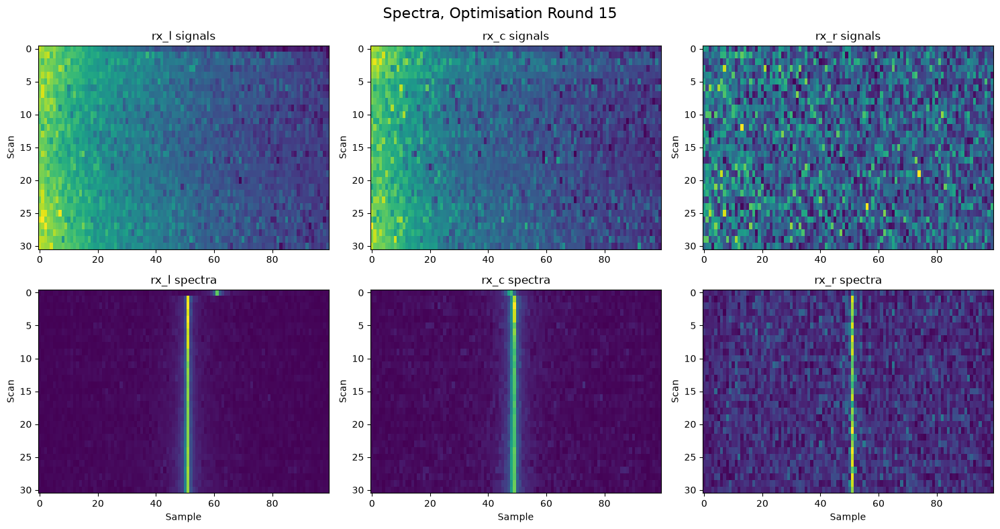

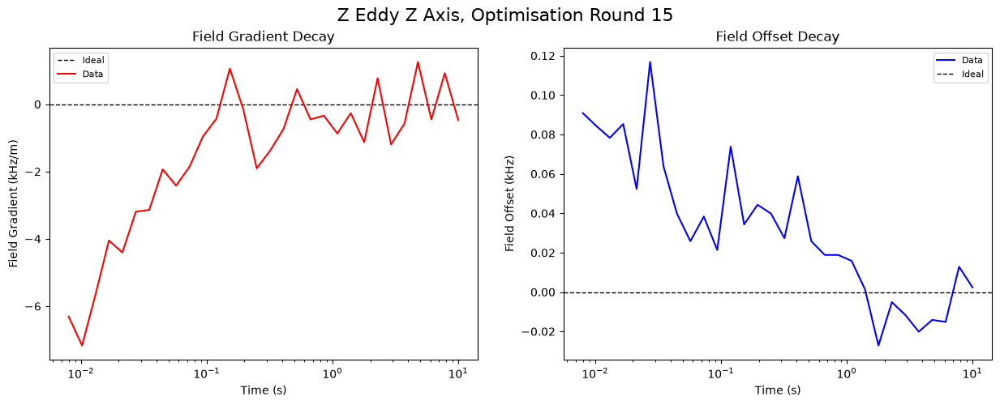

[I 2026-11-24 18:00:33,215] Trial 15 finished with value: 145.54716244757728 and parameters: {'Z_A1': -0.0008459878967478848, 'Z_A2': -0.0003555257496873115, 'Z_A3': 4.087343748790079e-09, 'Z_A4': 5.511417086320679e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.455e+02
Total cost = 1.455e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.011840006145997532
B nanmax = 0.011840006145997532
B contains nan = False
Trial 16


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.011649711269432641 !!!!!!!!!!!!!!!!


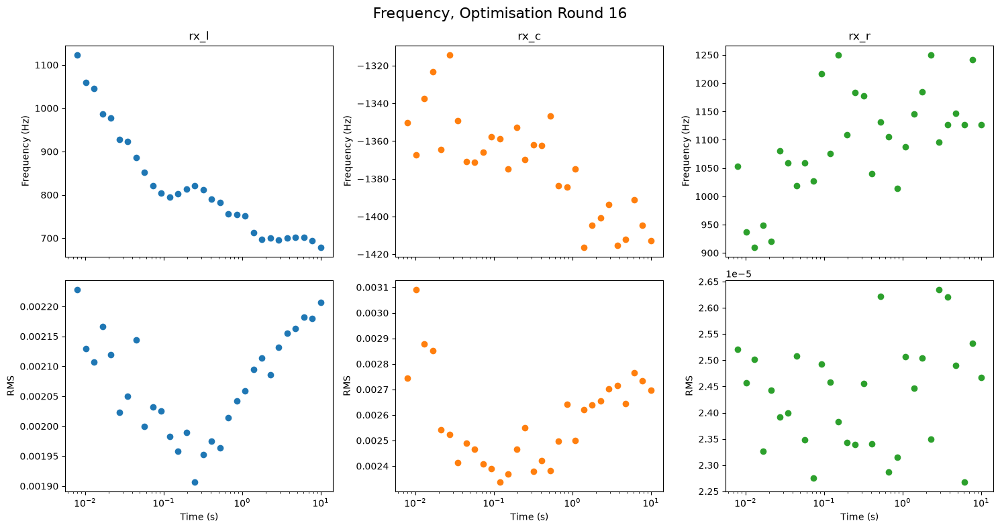

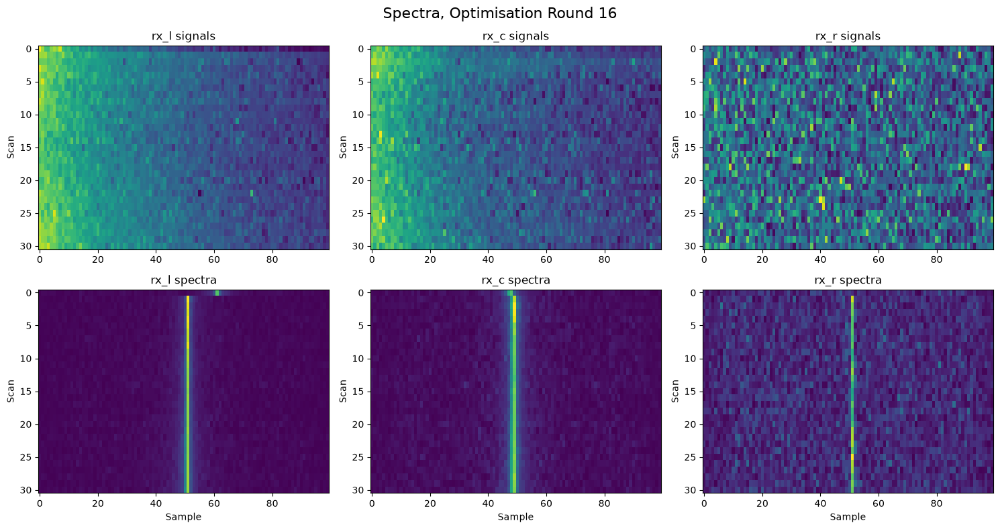

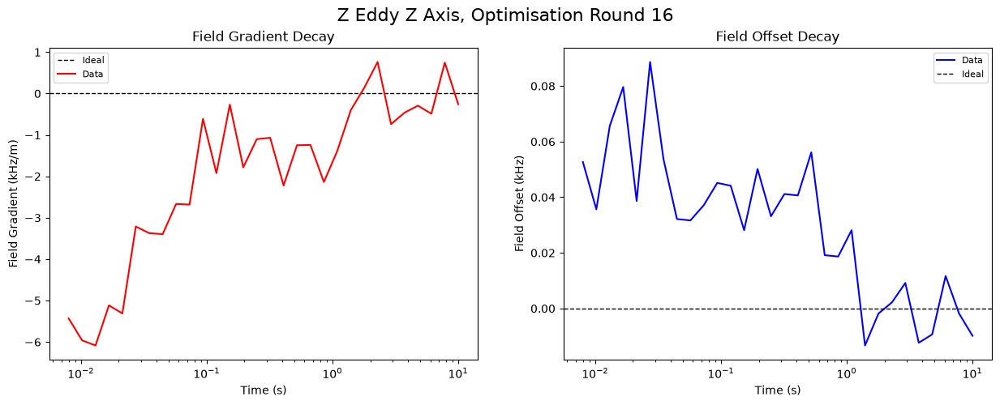

[I 2026-11-24 18:01:21,410] Trial 16 finished with value: 108.70128568894535 and parameters: {'Z_A1': -0.0006941214019919555, 'Z_A2': -0.0004472649013720078, 'Z_A3': 9.45079635485634e-10, 'Z_A4': -2.3059721700536985e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.087e+02
Total cost = 1.087e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.011082330880699098
B nanmax = 0.011082330880699098
B contains nan = False
Trial 17


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01090421956385524 !!!!!!!!!!!!!!!!


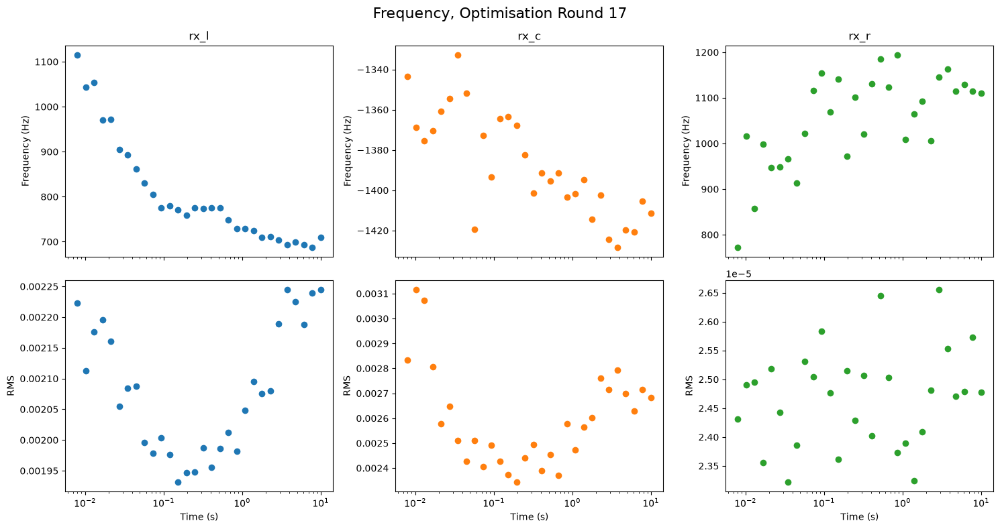

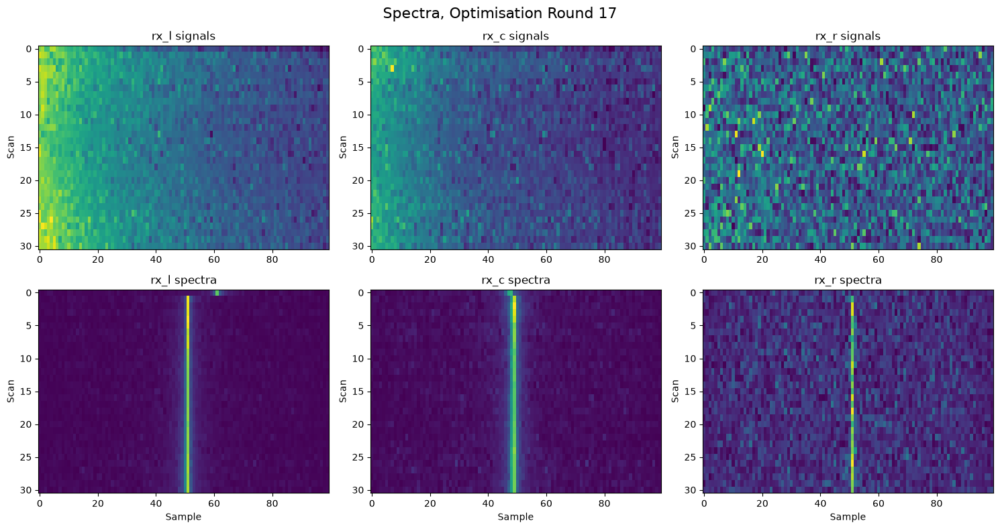

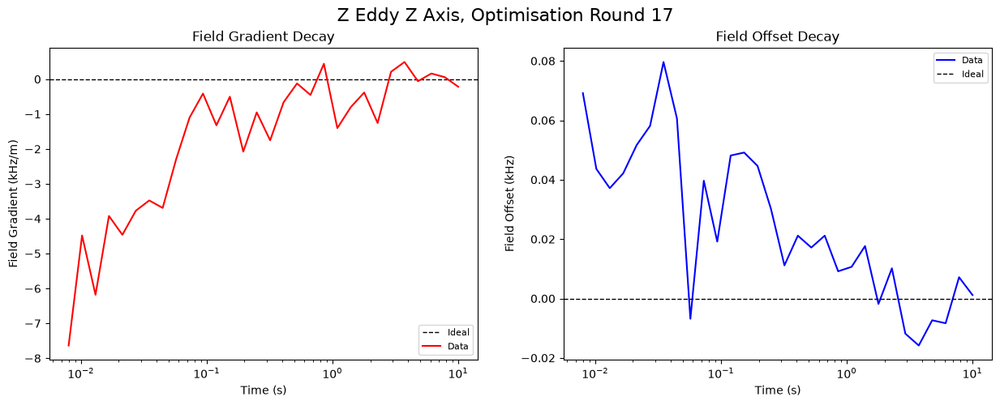

[I 2026-11-24 18:02:09,536] Trial 17 finished with value: 97.29465873421732 and parameters: {'Z_A1': -0.0007974374007905177, 'Z_A2': -0.00027245197123379884, 'Z_A3': 4.5057708374462443e-10, 'Z_A4': -1.832159589910356e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 9.729e+01
Total cost = 9.729e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014446890838504811
B nanmax = 0.014446890838504811
B contains nan = False
Trial 18


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01421469769909064 !!!!!!!!!!!!!!!!


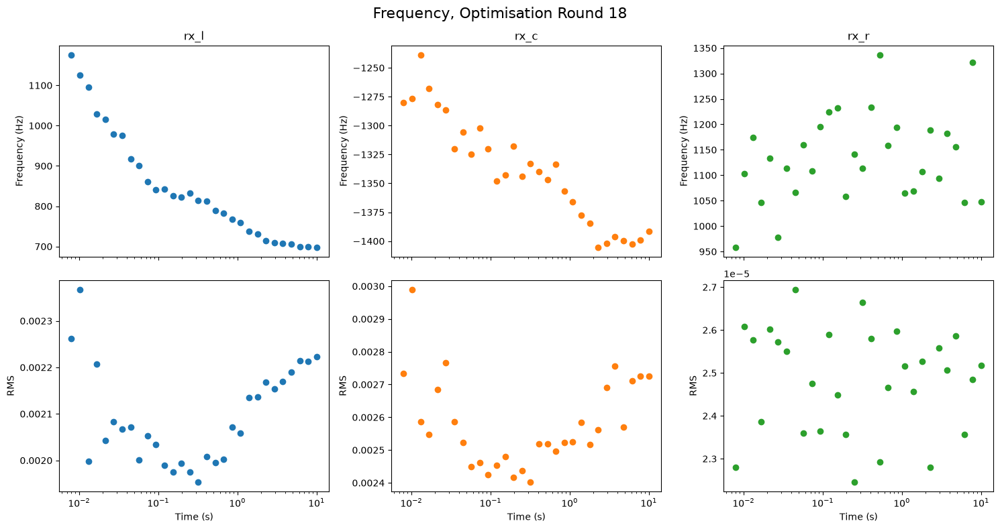

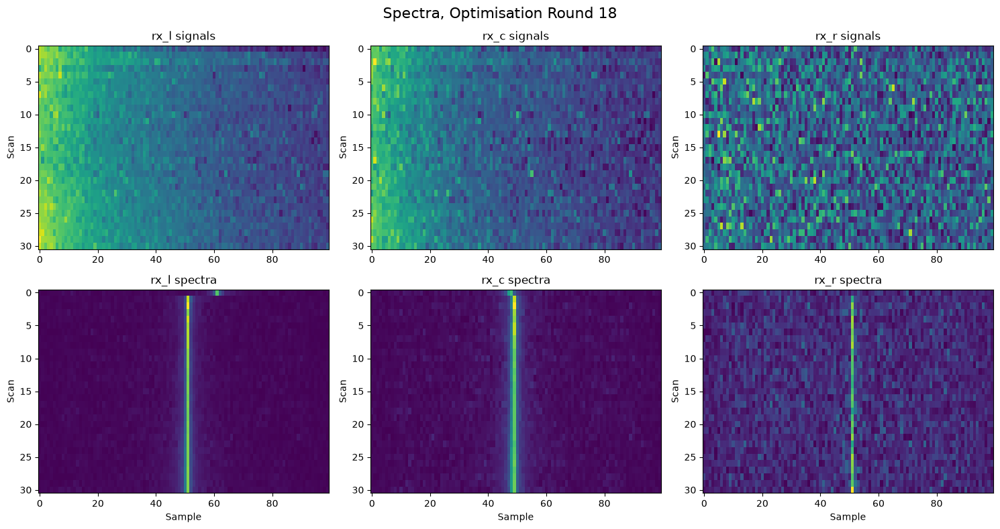

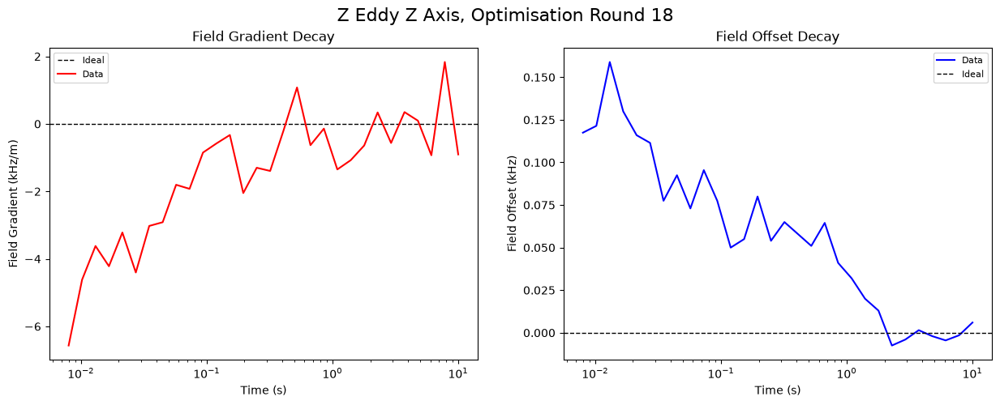

[I 2026-11-24 18:02:57,684] Trial 18 finished with value: 105.65123489236555 and parameters: {'Z_A1': -0.0008492396675304914, 'Z_A2': -0.0005434763789838861, 'Z_A3': 5.060573398695622e-09, 'Z_A4': 3.7540520991553974e-09}. Best is trial 0 with value: 88.05822481559886.


rx_c: 1.057e+02
Total cost = 1.057e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.011105382080462252
B nanmax = 0.011105382080462252
B contains nan = False
Trial 19


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.010926891803841111 !!!!!!!!!!!!!!!!


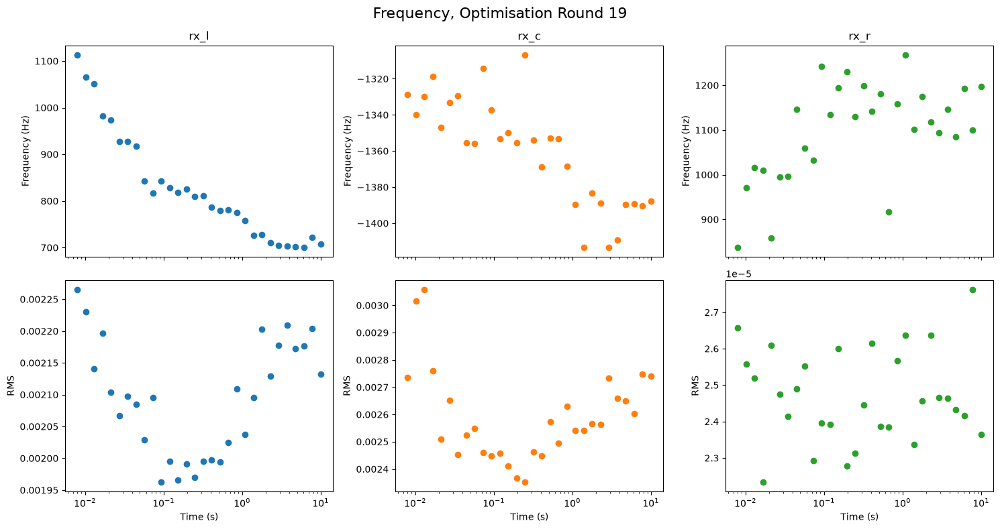

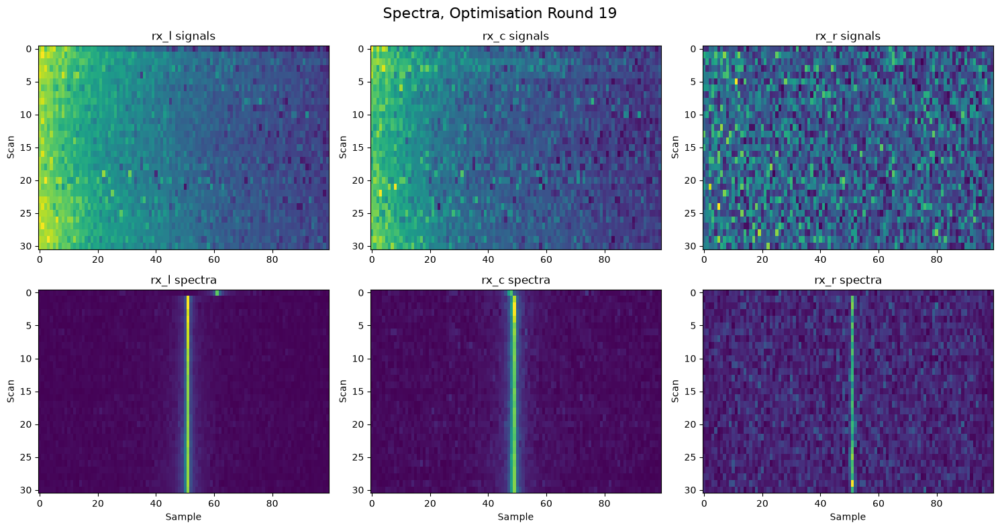

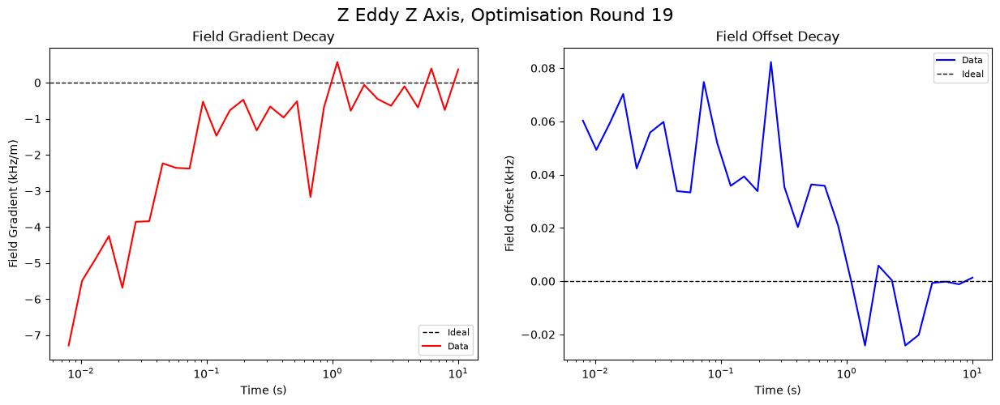

[I 2026-11-24 18:03:45,972] Trial 19 finished with value: 86.8672425027614 and parameters: {'Z_A1': -0.0005920020563602437, 'Z_A2': -0.00047794888877585024, 'Z_A3': 9.84208786007659e-09, 'Z_A4': -7.179438339876863e-10}. Best is trial 19 with value: 86.8672425027614.


rx_c: 8.687e+01
Total cost = 8.687e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012010721337266678
B nanmax = 0.012010721337266678
B contains nan = False
Trial 20


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.011817682422859108 !!!!!!!!!!!!!!!!


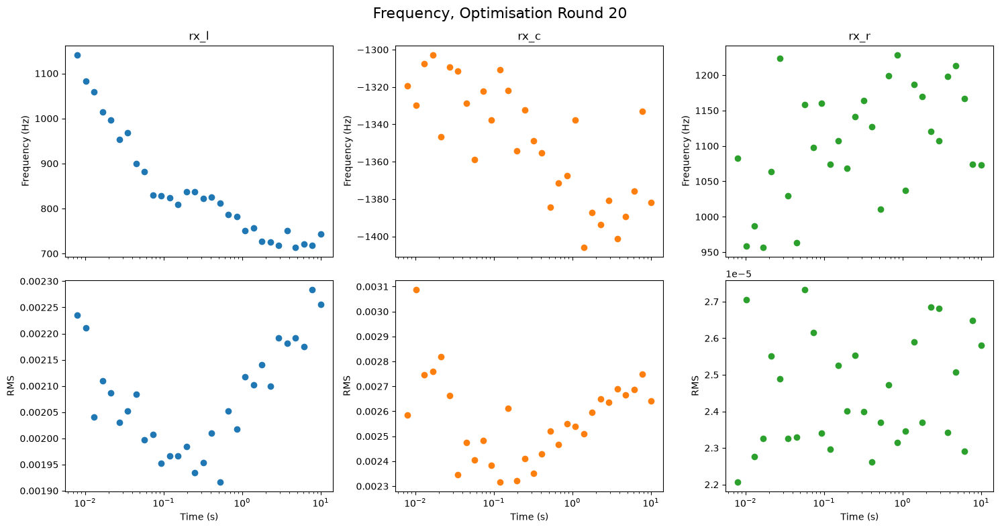

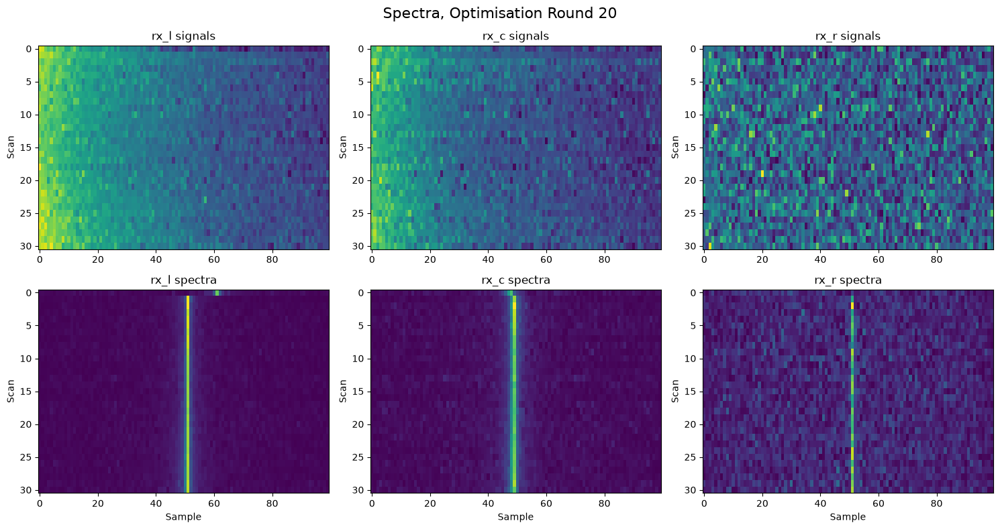

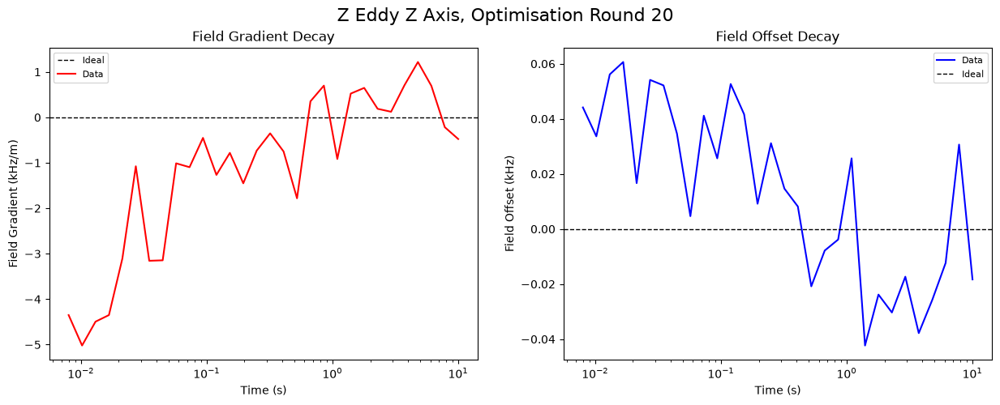

[I 2026-11-24 18:04:34,146] Trial 20 finished with value: 241.69362730086095 and parameters: {'Z_A1': -0.0006975389496623689, 'Z_A2': -0.00046023557674178945, 'Z_A3': 4.131860676475383e-09, 'Z_A4': -6.264196703592325e-09}. Best is trial 19 with value: 86.8672425027614.


rx_c: 2.417e+02
Total cost = 2.417e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013393522308236958
B nanmax = 0.013393522308236958
B contains nan = False
Trial 21


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01317826050505424 !!!!!!!!!!!!!!!!


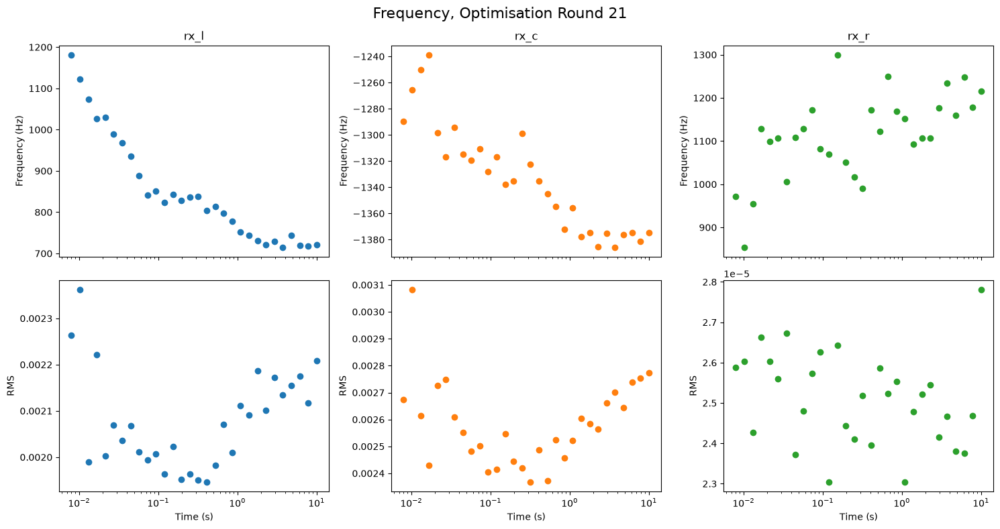

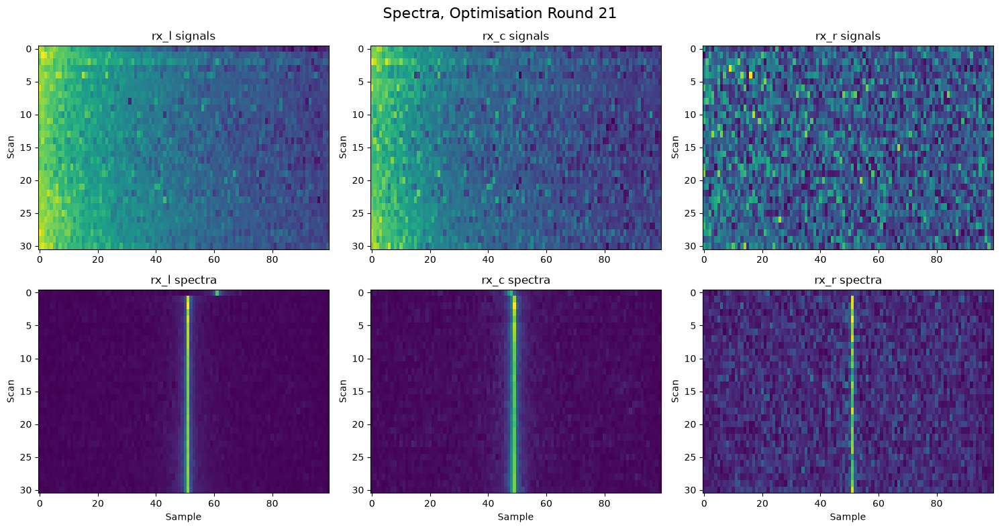

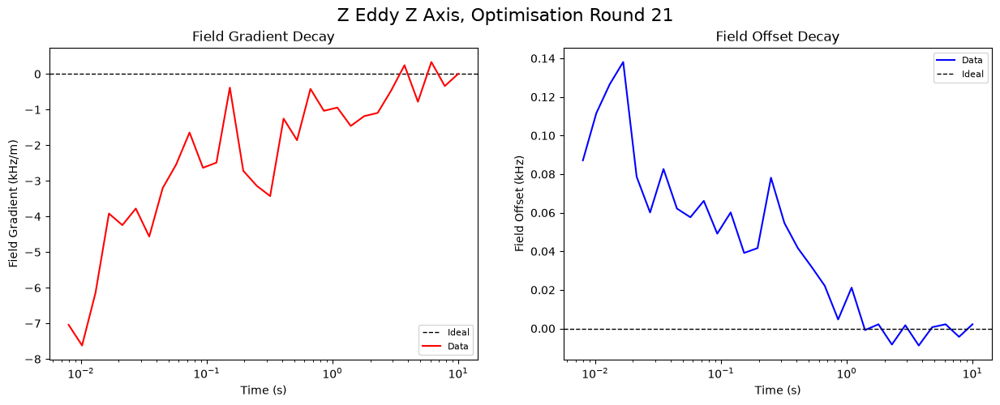

[I 2026-11-24 18:05:22,410] Trial 21 finished with value: 70.32705909852392 and parameters: {'Z_A1': -0.0008214635885633864, 'Z_A2': -0.00047006187927388273, 'Z_A3': -2.2284275948255444e-09, 'Z_A4': 4.397948509718359e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 7.033e+01
Total cost = 7.033e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012087916641582262
B nanmax = 0.012087916641582262
B contains nan = False
Trial 22


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.011893639762035037 !!!!!!!!!!!!!!!!


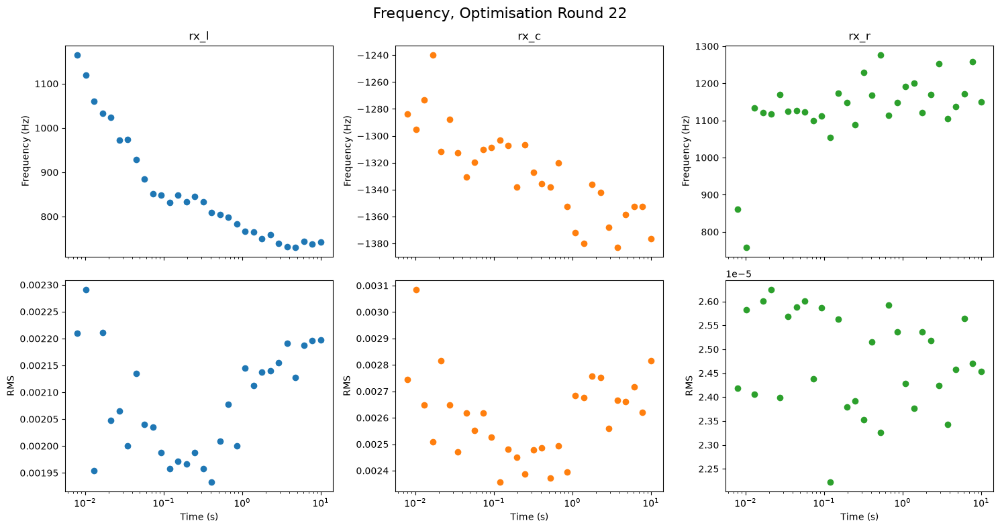

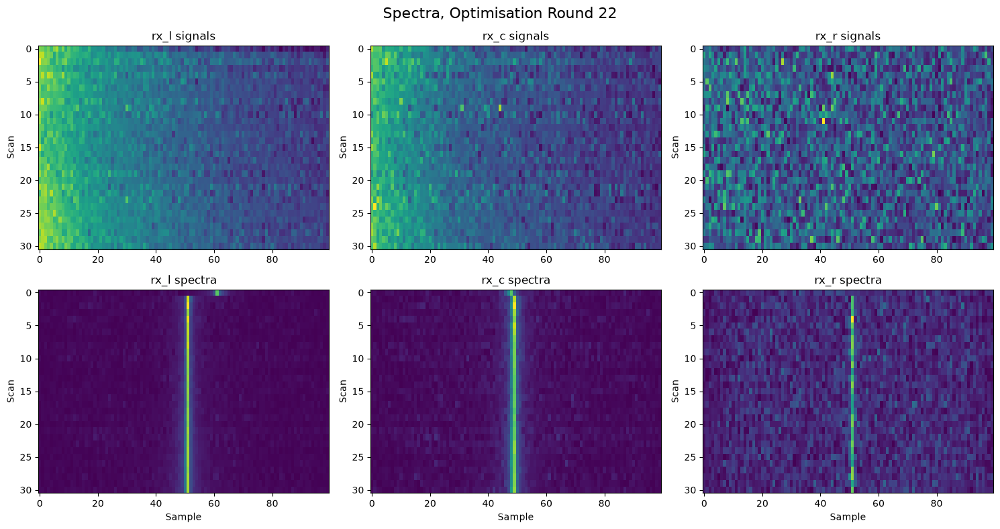

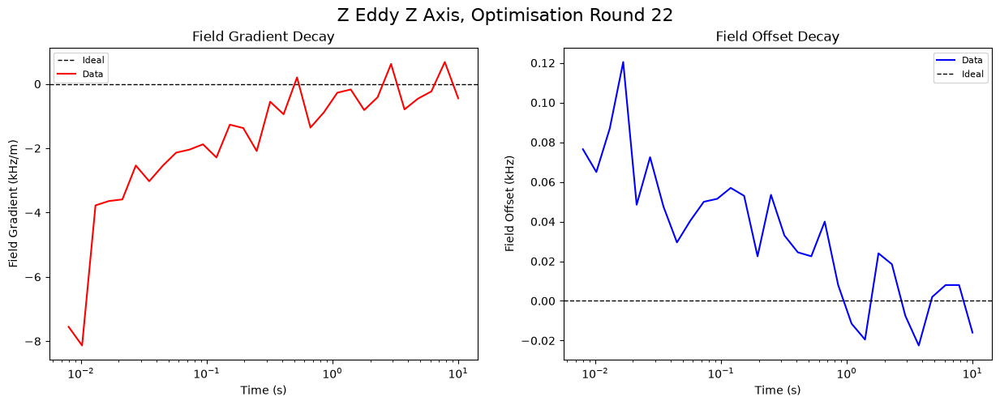

[I 2026-11-24 18:06:10,511] Trial 22 finished with value: 134.5588182719972 and parameters: {'Z_A1': -0.0007687319446151356, 'Z_A2': -0.0003971808373573948, 'Z_A3': -2.682668230910245e-09, 'Z_A4': 4.4167696717854295e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.346e+02
Total cost = 1.346e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.009549843552120608
B nanmax = 0.009549843552120608
B contains nan = False
Trial 23


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.009396352081626896 !!!!!!!!!!!!!!!!


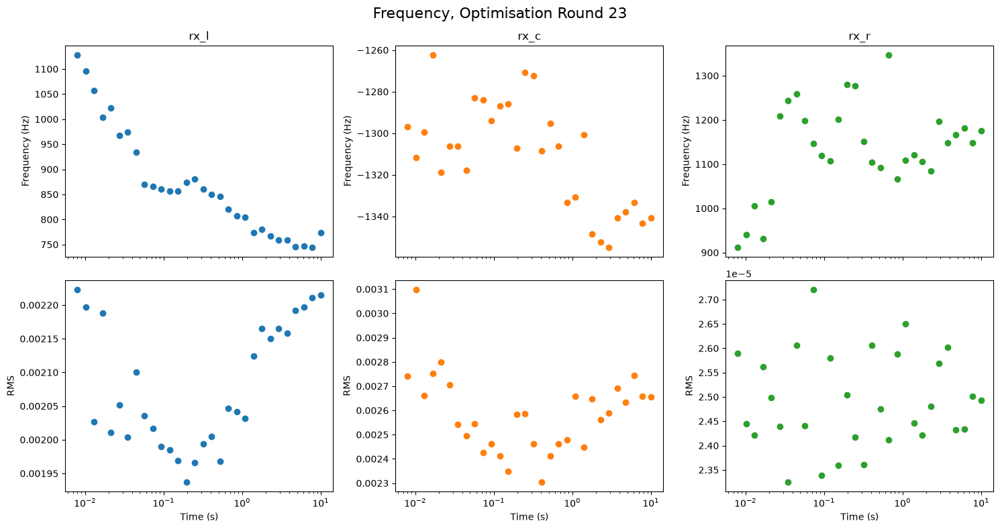

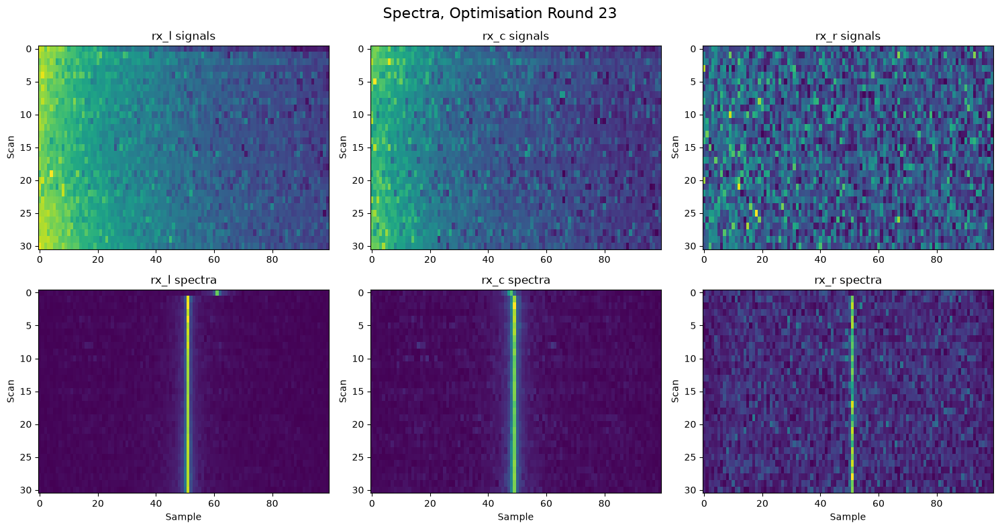

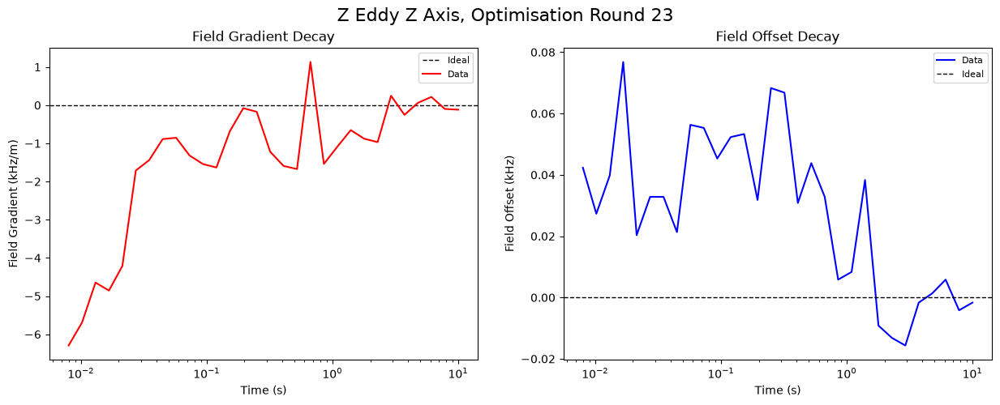

[I 2026-11-24 18:06:58,743] Trial 23 finished with value: 94.84484616670474 and parameters: {'Z_A1': -0.00044930994416819155, 'Z_A2': -0.00047014773601653426, 'Z_A3': 9.819488230883629e-09, 'Z_A4': -3.6587096575474192e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 9.484e+01
Total cost = 9.484e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012183642808682437
B nanmax = 0.012183642808682437
B contains nan = False
Trial 24


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01198782452402796 !!!!!!!!!!!!!!!!


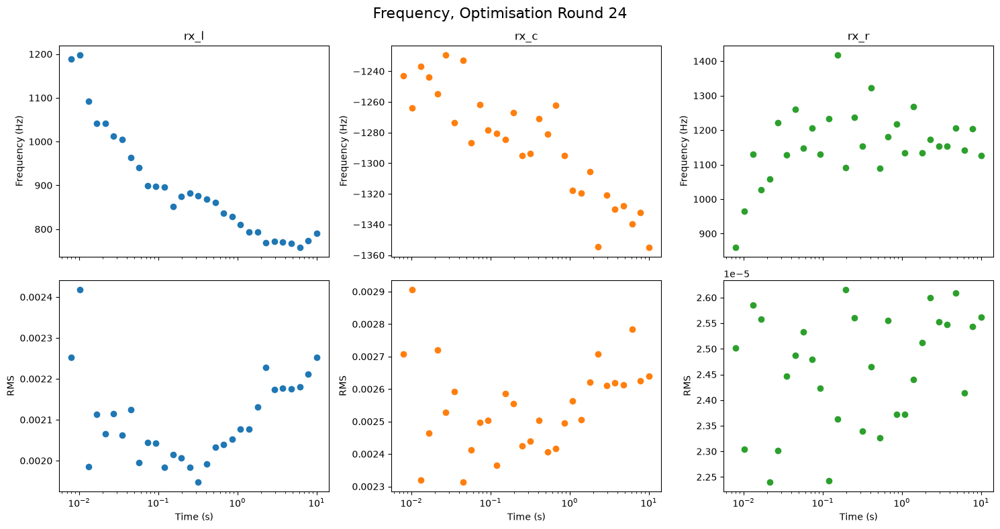

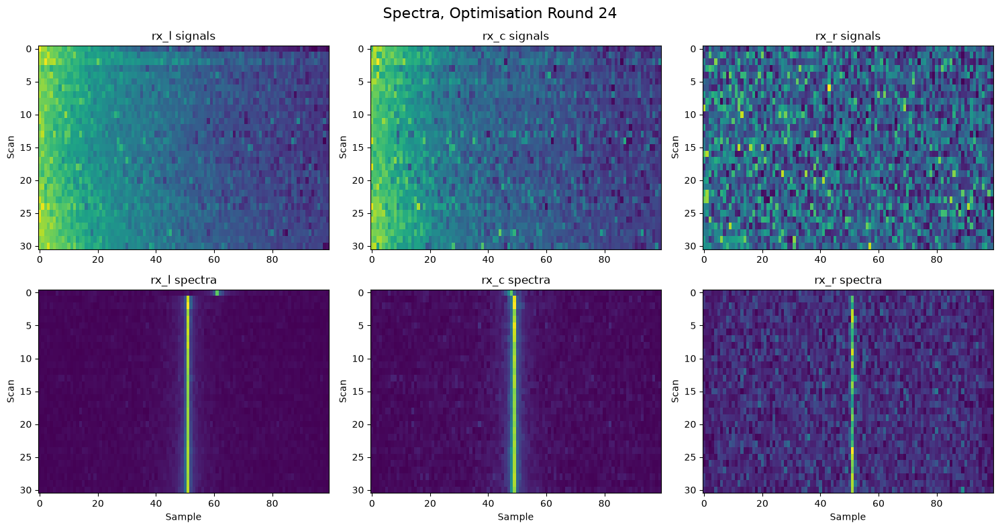

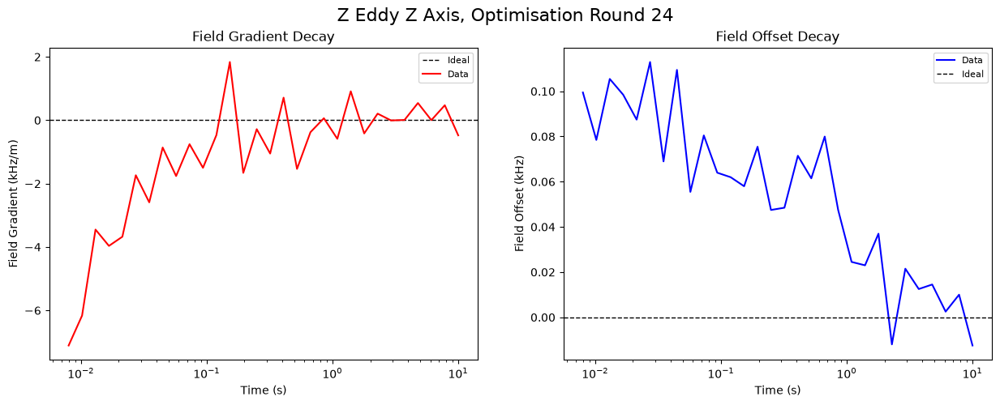

[I 2026-11-24 18:07:47,096] Trial 24 finished with value: 180.10272105937514 and parameters: {'Z_A1': -0.0007041928197812871, 'Z_A2': -0.0004702150797045438, 'Z_A3': 2.4594167440606153e-09, 'Z_A4': 5.43312278051929e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.801e+02
Total cost = 1.801e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013105166906507261
B nanmax = 0.013105166906507261
B contains nan = False
Trial 25


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012894538136844737 !!!!!!!!!!!!!!!!


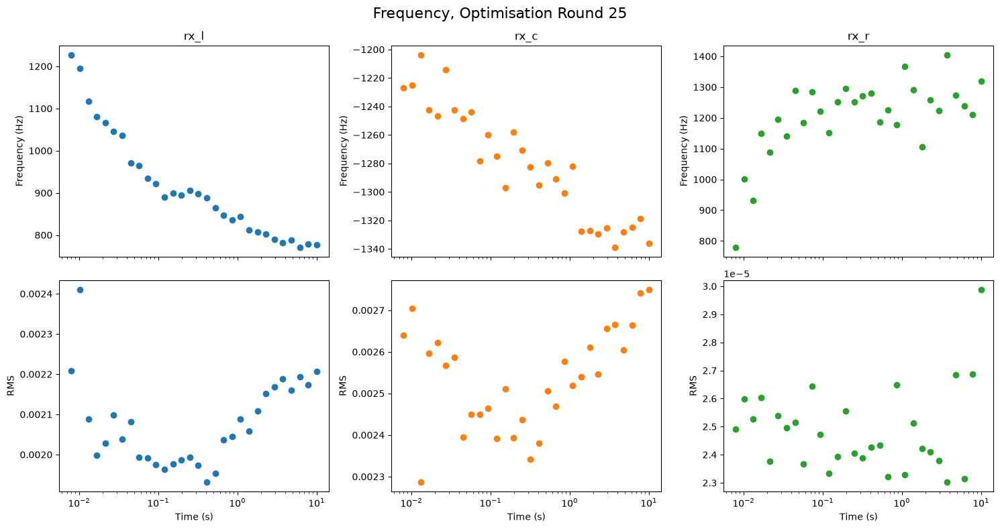

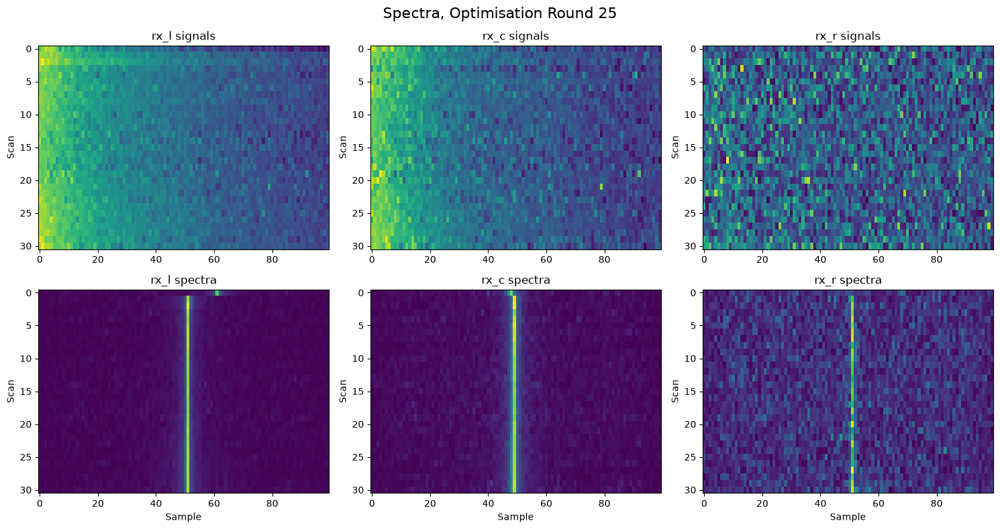

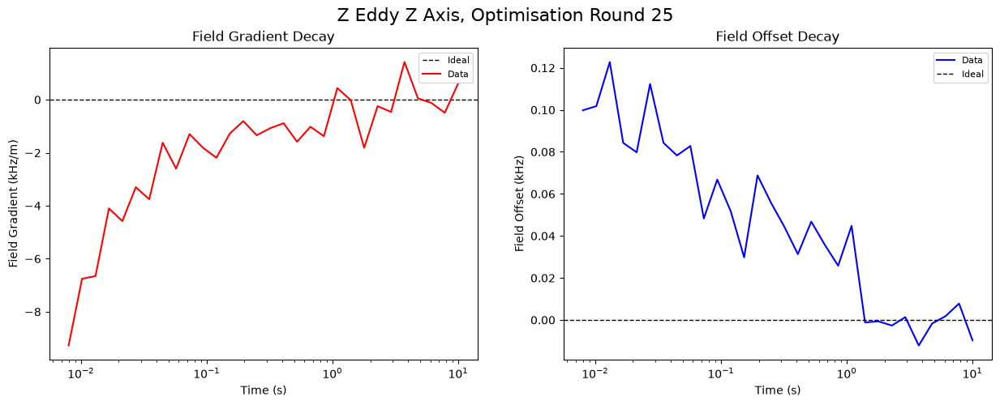

[I 2026-11-24 18:08:35,112] Trial 25 finished with value: 98.36451220756223 and parameters: {'Z_A1': -0.0007686861518858211, 'Z_A2': -0.00049466680925251, 'Z_A3': -2.147645912711681e-09, 'Z_A4': 3.871167461875127e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 9.836e+01
Total cost = 9.836e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012932630174501553
B nanmax = 0.012932630174501553
B contains nan = False
Trial 26


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012724773587680977 !!!!!!!!!!!!!!!!


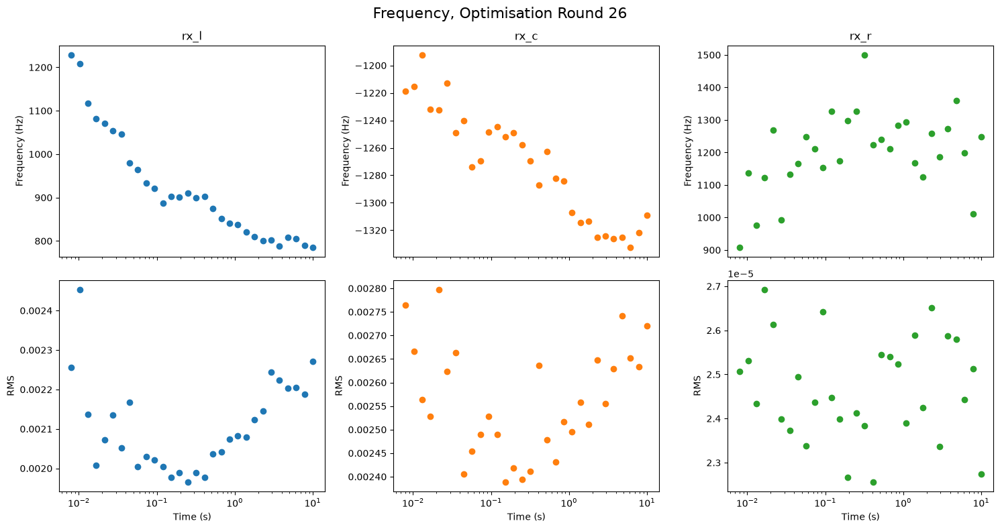

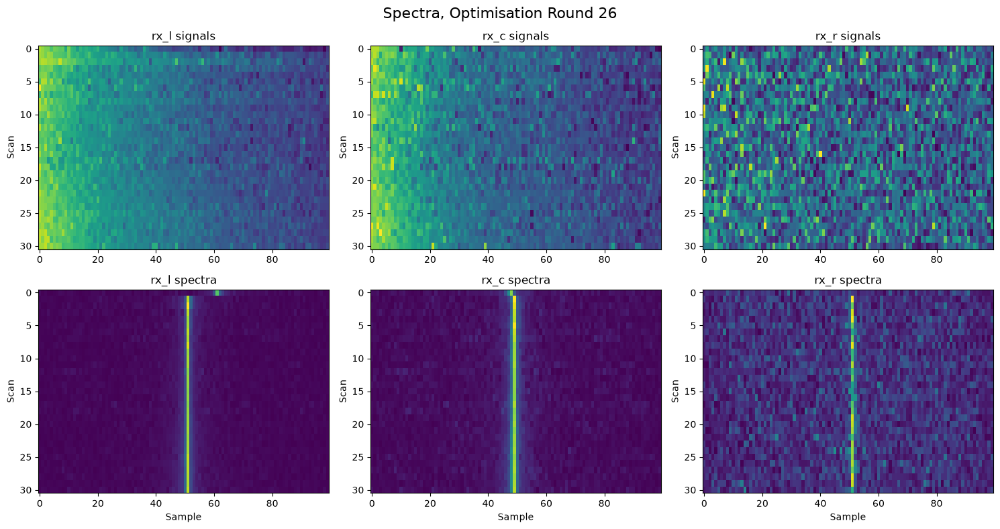

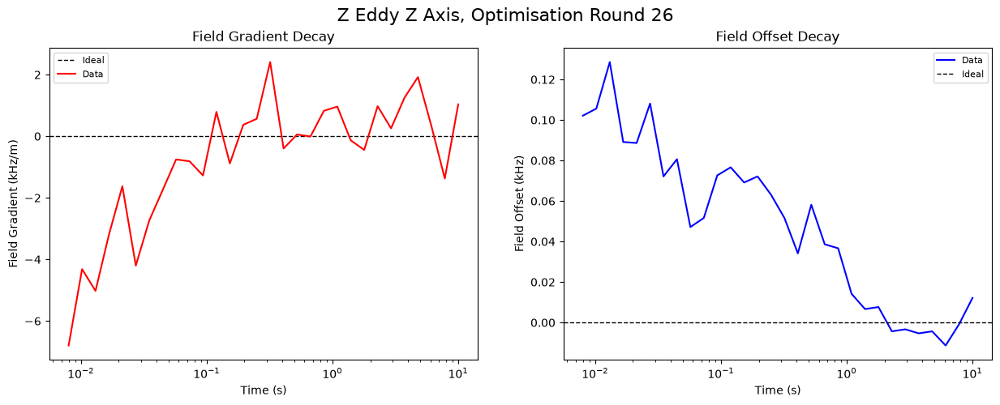

[I 2026-11-24 18:09:23,298] Trial 26 finished with value: 105.47231368915993 and parameters: {'Z_A1': -0.0007375666506060031, 'Z_A2': -0.0005089341653364296, 'Z_A3': 5.950472708562768e-09, 'Z_A4': -1.807159224915247e-10}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.055e+02
Total cost = 1.055e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014620207381941959
B nanmax = 0.014620207381941959
B contains nan = False
Trial 27


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014385232373912942 !!!!!!!!!!!!!!!!


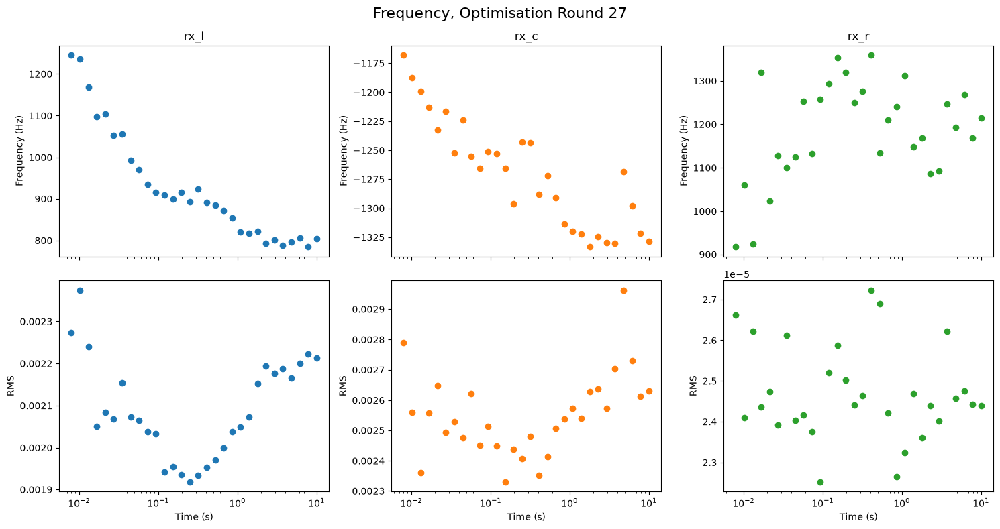

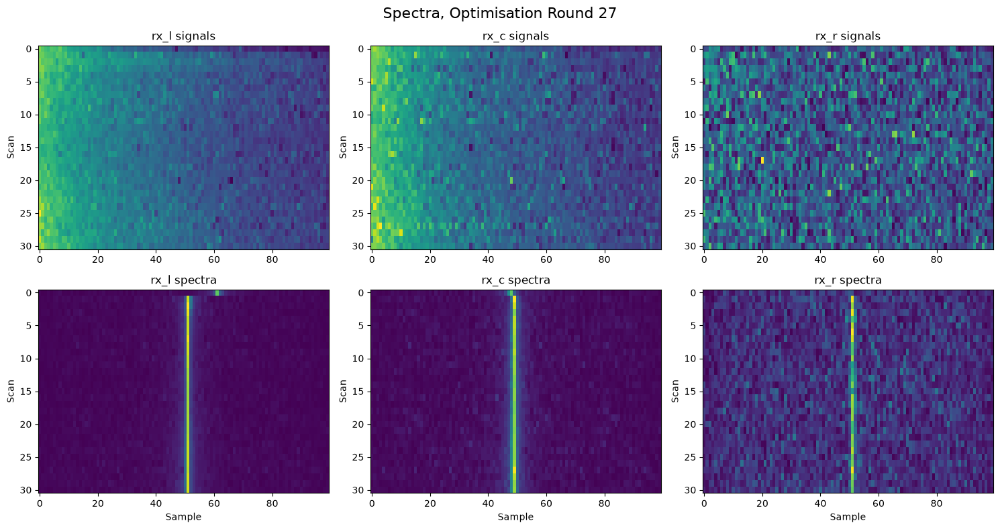

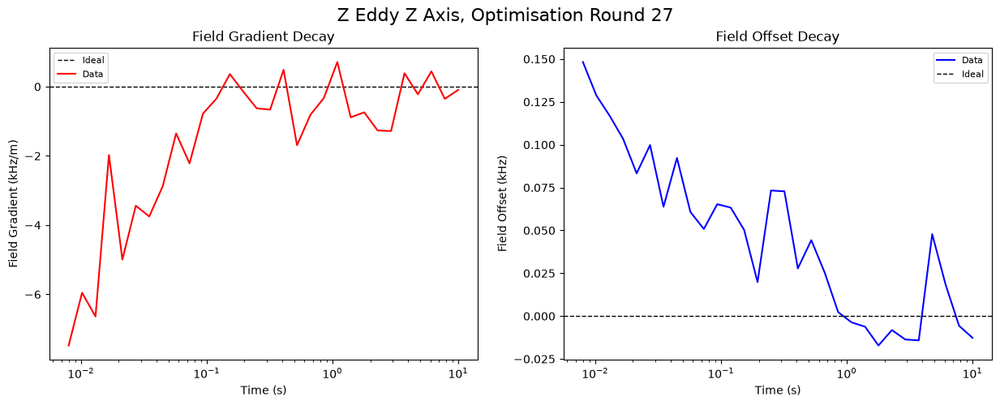

[I 2026-11-24 18:10:11,371] Trial 27 finished with value: 183.57230972630347 and parameters: {'Z_A1': -0.0009498713252025556, 'Z_A2': -0.0004604978511145973, 'Z_A3': -4.534137927589684e-09, 'Z_A4': 5.592684072819147e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.836e+02
Total cost = 1.836e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013180119851225988
B nanmax = 0.013180119851225988
B contains nan = False
Trial 28


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012968284297903187 !!!!!!!!!!!!!!!!


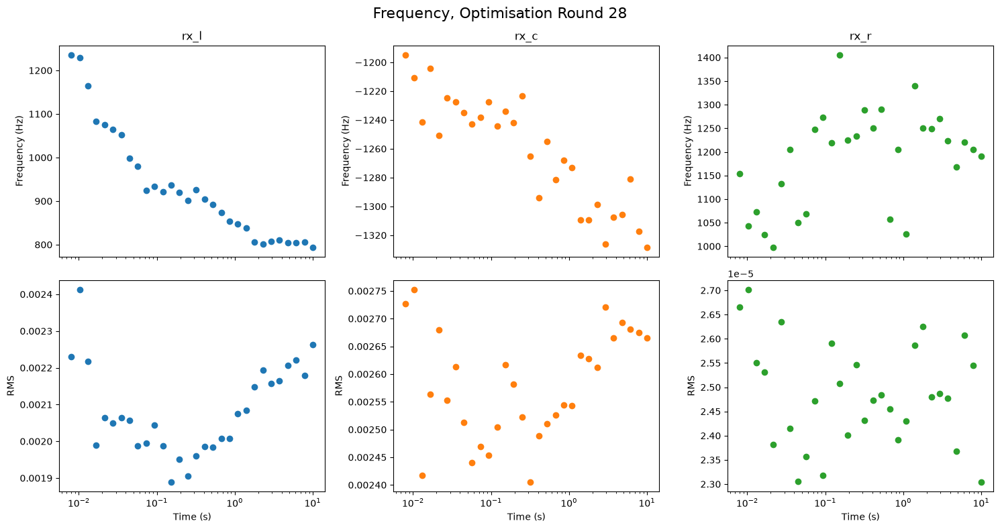

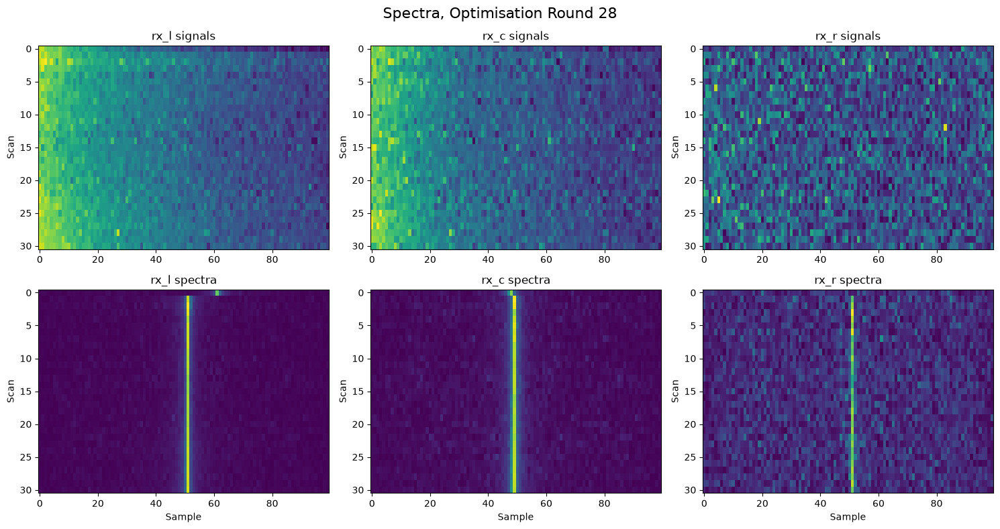

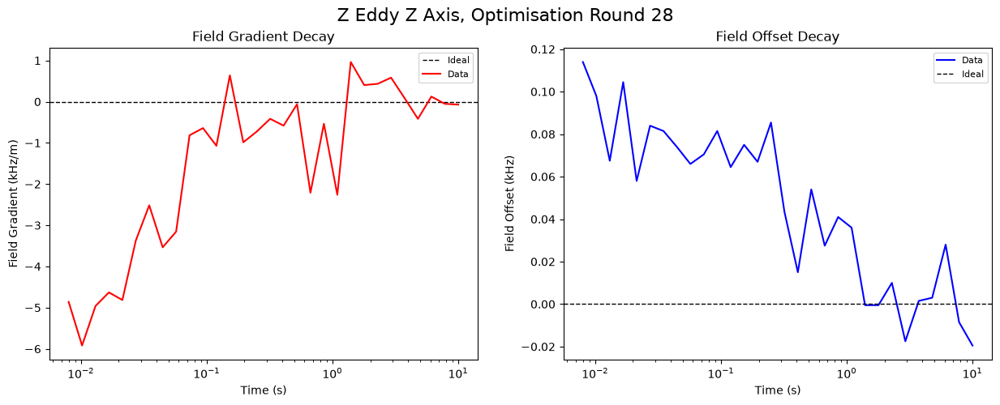

[I 2026-11-24 18:10:59,483] Trial 28 finished with value: 159.893393611772 and parameters: {'Z_A1': -0.0007212303565579548, 'Z_A2': -0.0005488063834824804, 'Z_A3': -3.1538321935190986e-09, 'Z_A4': 9.388734825329167e-10}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.599e+02
Total cost = 1.599e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014354197039274421
B nanmax = 0.014354197039274421
B contains nan = False
Trial 29


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014123497329723546 !!!!!!!!!!!!!!!!


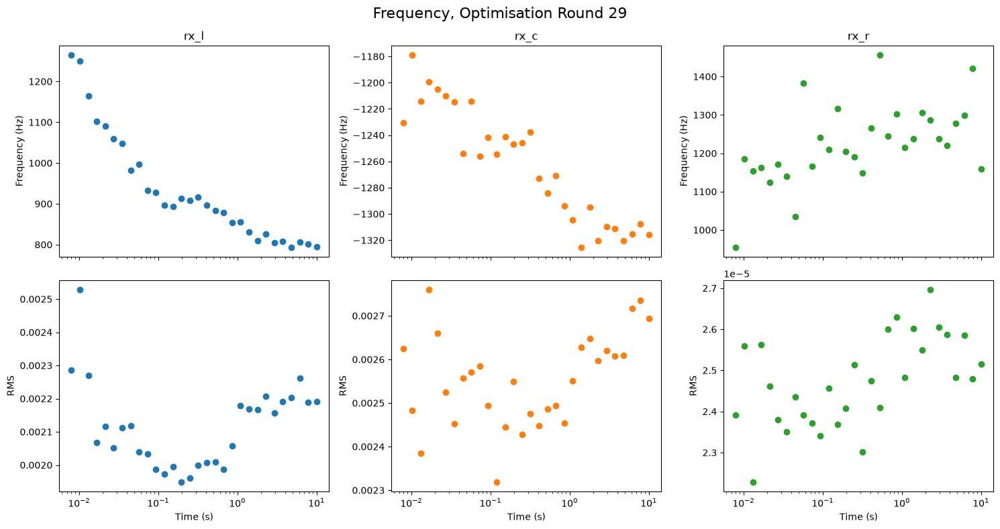

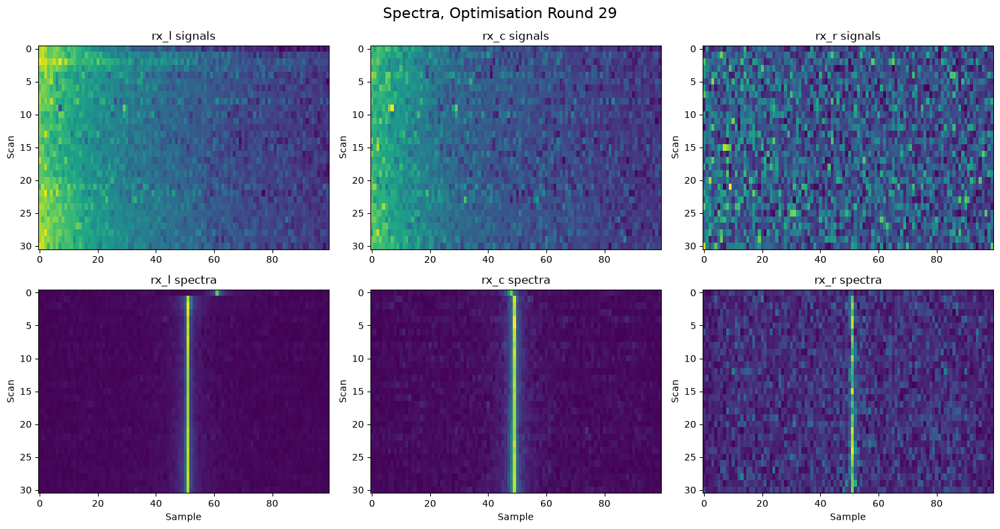

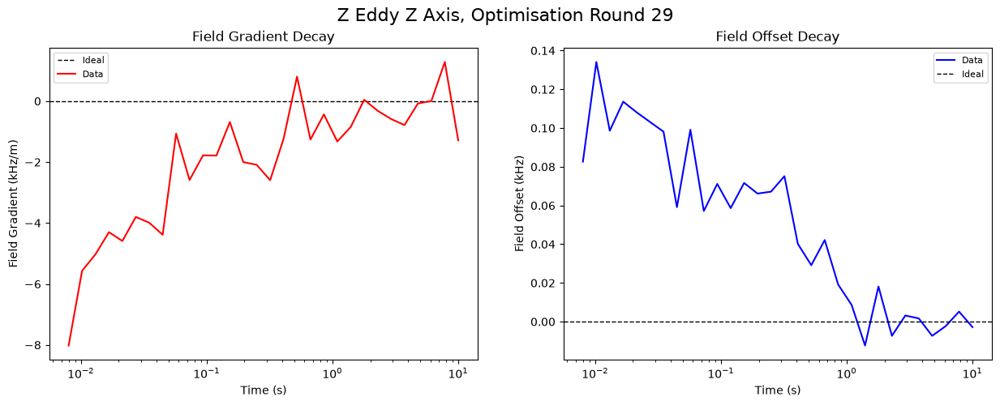

[I 2026-11-24 18:11:47,599] Trial 29 finished with value: 92.93696658065835 and parameters: {'Z_A1': -0.000932535246587636, 'Z_A2': -0.0004521721218540704, 'Z_A3': 3.526842913562064e-09, 'Z_A4': -2.4408029542306858e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 9.294e+01
Total cost = 9.294e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.011634713537325743
B nanmax = 0.011634713537325743
B contains nan = False
Trial 30


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.011447714767347962 !!!!!!!!!!!!!!!!


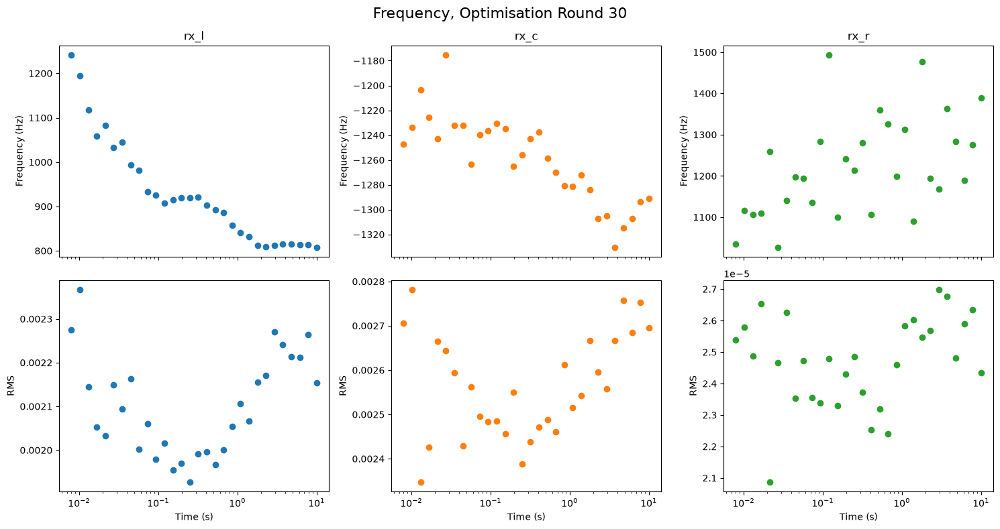

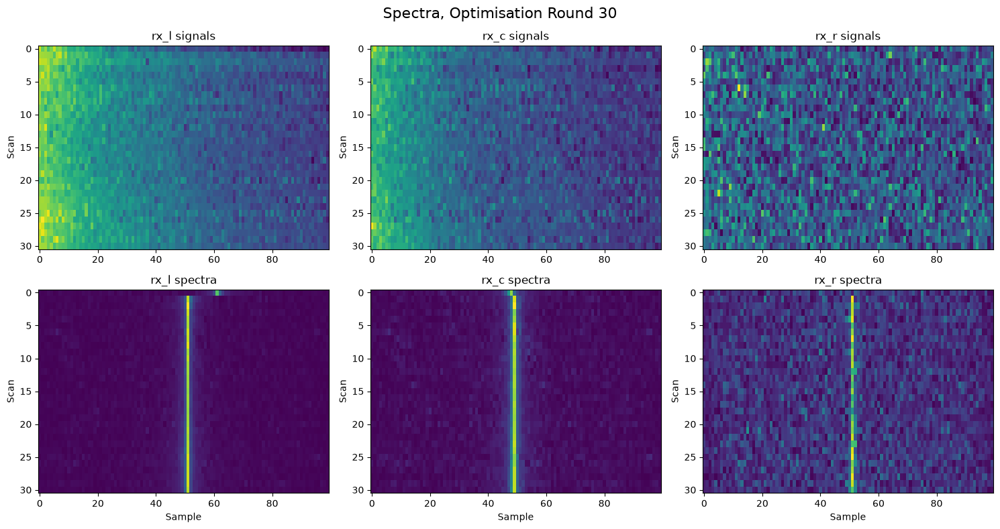

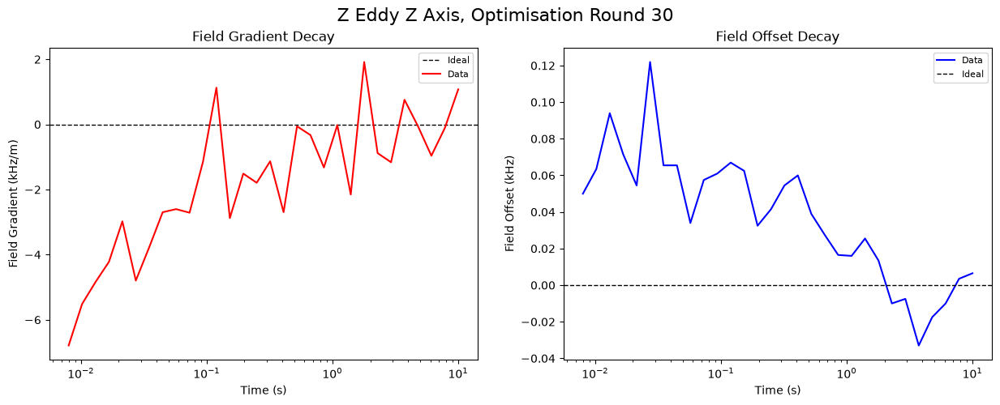

[I 2026-11-24 18:12:35,737] Trial 30 finished with value: 149.03276048743962 and parameters: {'Z_A1': -0.0005992374313548965, 'Z_A2': -0.0005214928636620073, 'Z_A3': -3.0662202460106294e-10, 'Z_A4': 3.3980312084035455e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.490e+02
Total cost = 1.490e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013640294738639638
B nanmax = 0.013640294738639638
B contains nan = False
Trial 31


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013421070702944125 !!!!!!!!!!!!!!!!


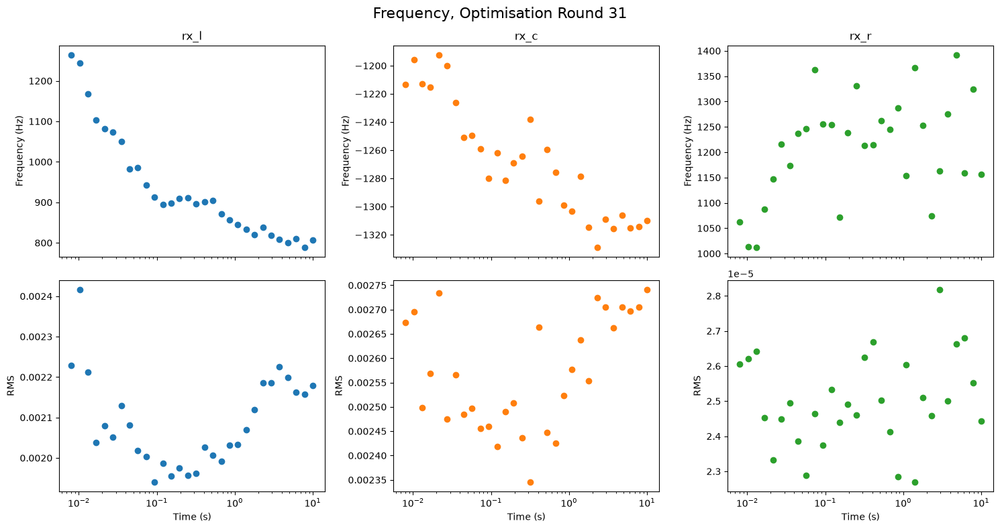

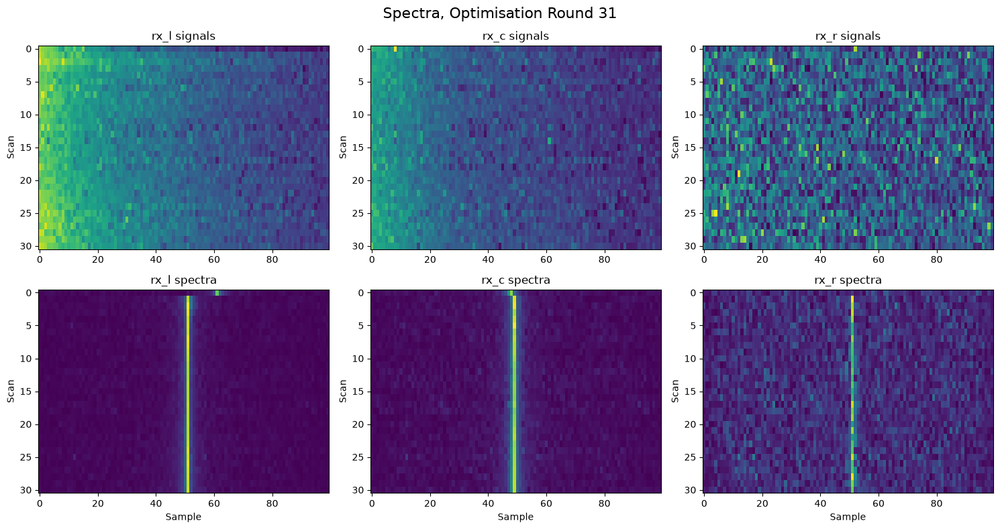

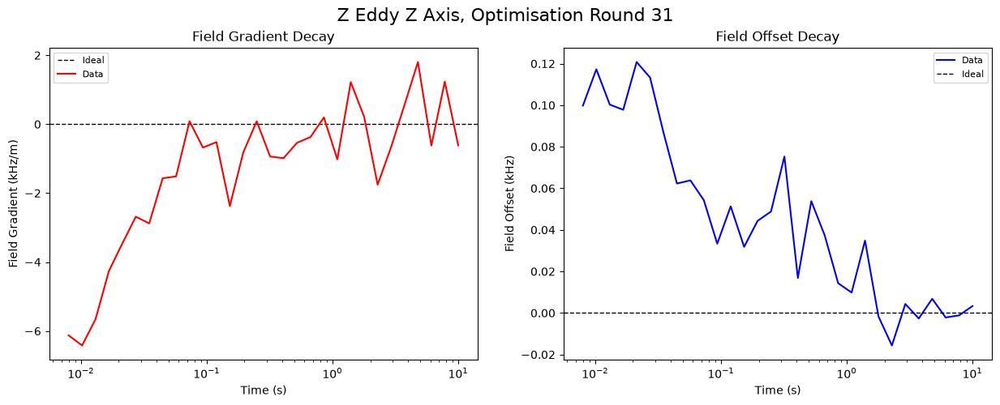

[I 2026-11-24 18:13:23,868] Trial 31 finished with value: 85.82577960949774 and parameters: {'Z_A1': -0.0009320948597695015, 'Z_A2': -0.000384224430787329, 'Z_A3': 7.104024555047967e-10, 'Z_A4': -4.006513936614416e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 8.583e+01
Total cost = 8.583e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012846871838996656
B nanmax = 0.012846871838996656
B contains nan = False
Trial 32


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012640399777858982 !!!!!!!!!!!!!!!!


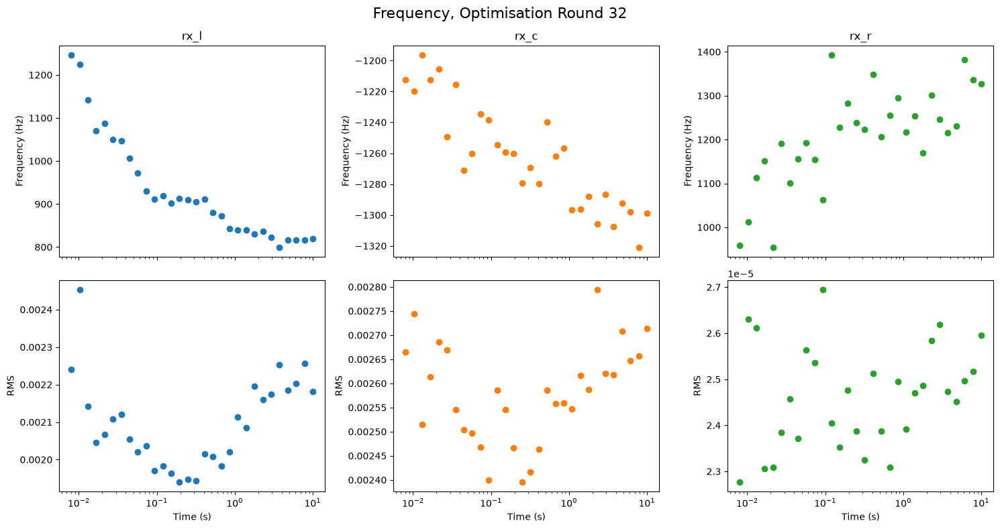

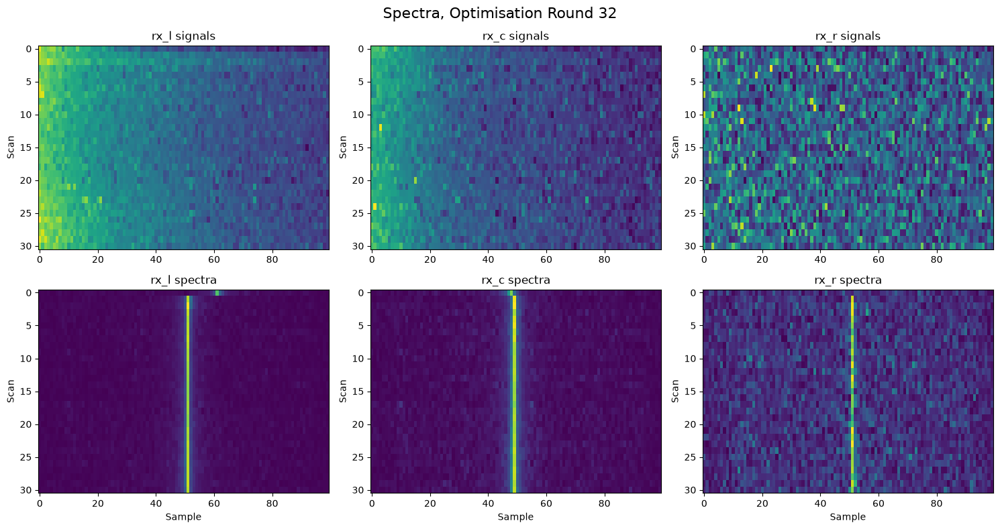

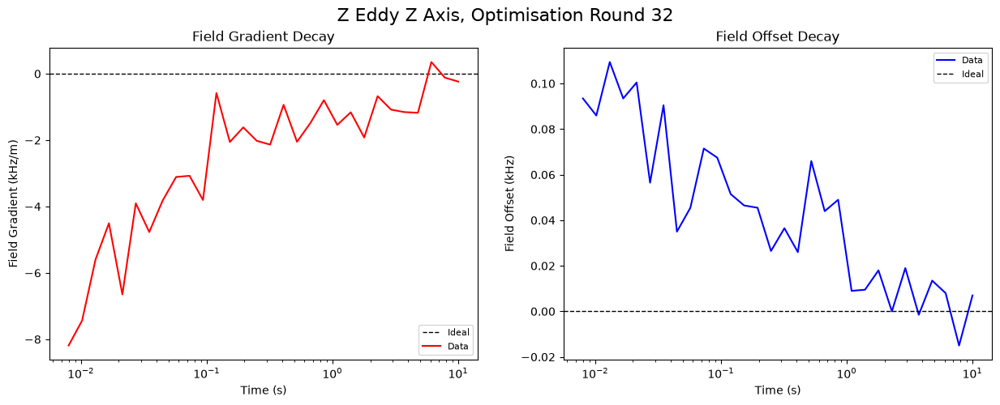

[I 2026-11-24 18:14:12,006] Trial 32 finished with value: 139.477211351018 and parameters: {'Z_A1': -0.0008838174380354925, 'Z_A2': -0.00035599681448136383, 'Z_A3': 2.3055720550492823e-09, 'Z_A4': -5.85688875693782e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.395e+02
Total cost = 1.395e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.011313628230866046
B nanmax = 0.011313628230866046
B contains nan = False
Trial 33


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.011131795239813589 !!!!!!!!!!!!!!!!


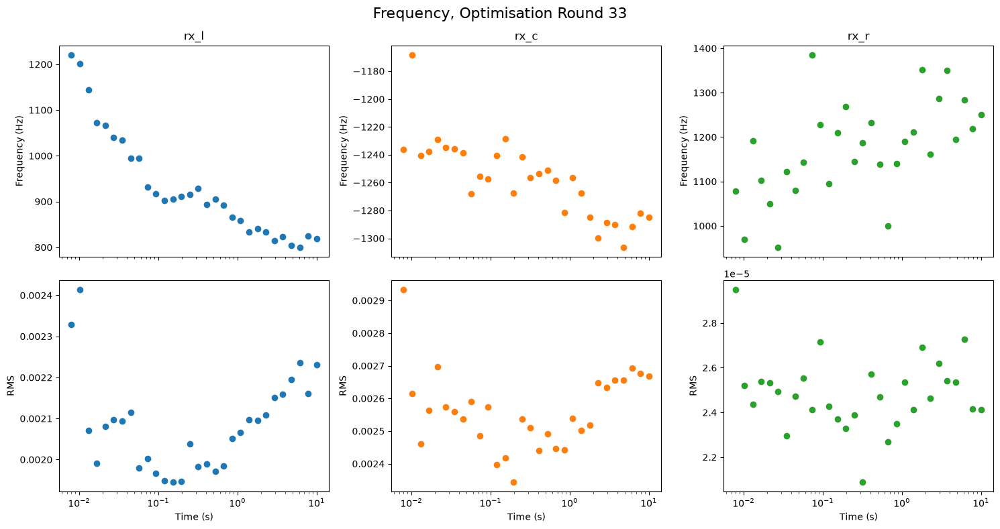

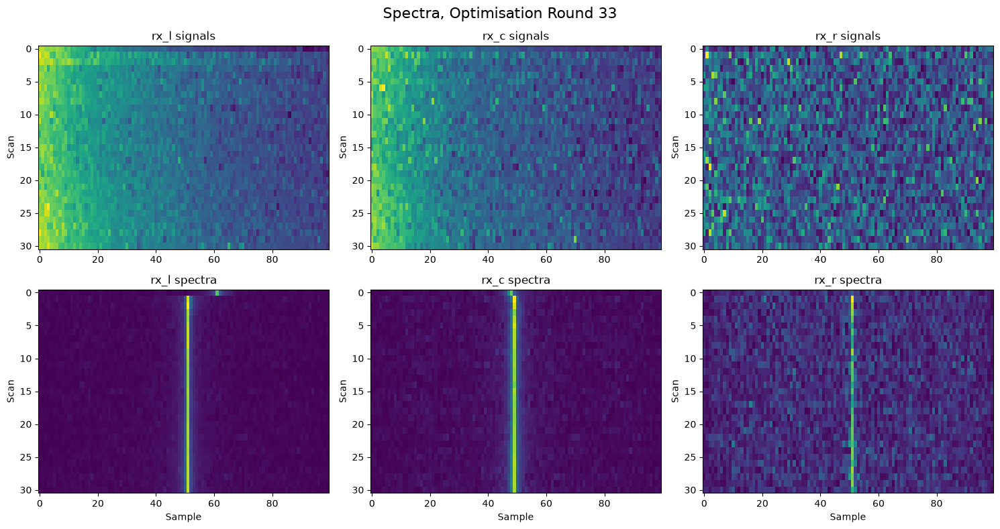

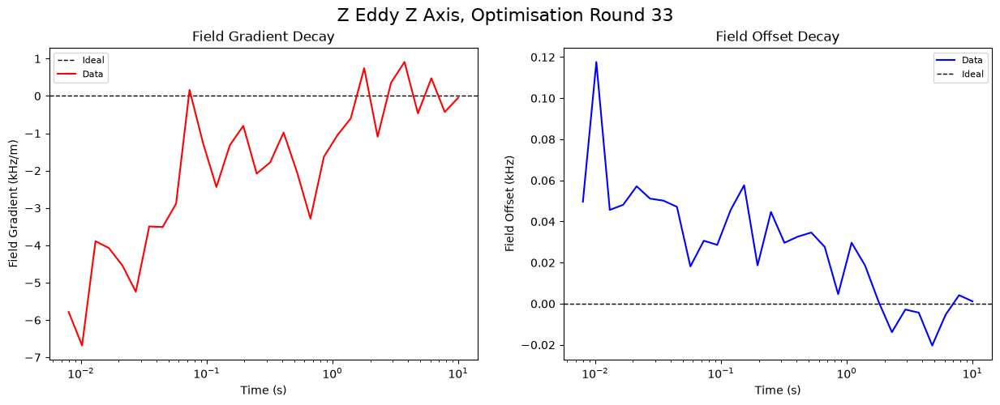

[I 2026-11-24 18:14:59,979] Trial 33 finished with value: 97.36213376426352 and parameters: {'Z_A1': -0.0007080893771730333, 'Z_A2': -0.00038302203117209253, 'Z_A3': 8.044119457455921e-10, 'Z_A4': 4.3643826062552333e-10}. Best is trial 21 with value: 70.32705909852392.


rx_c: 9.736e+01
Total cost = 9.736e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013778317758046185
B nanmax = 0.013778317758046185
B contains nan = False
Trial 34


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013556875096793815 !!!!!!!!!!!!!!!!


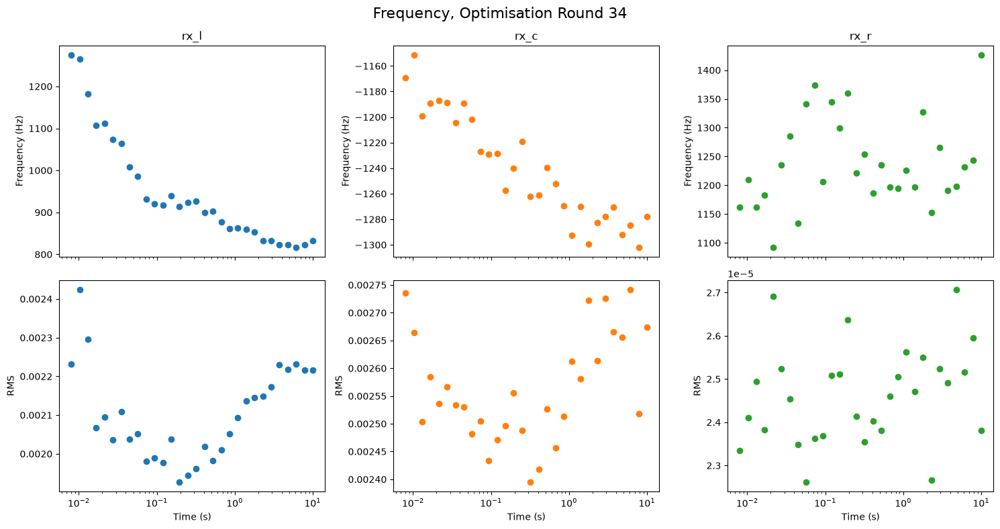

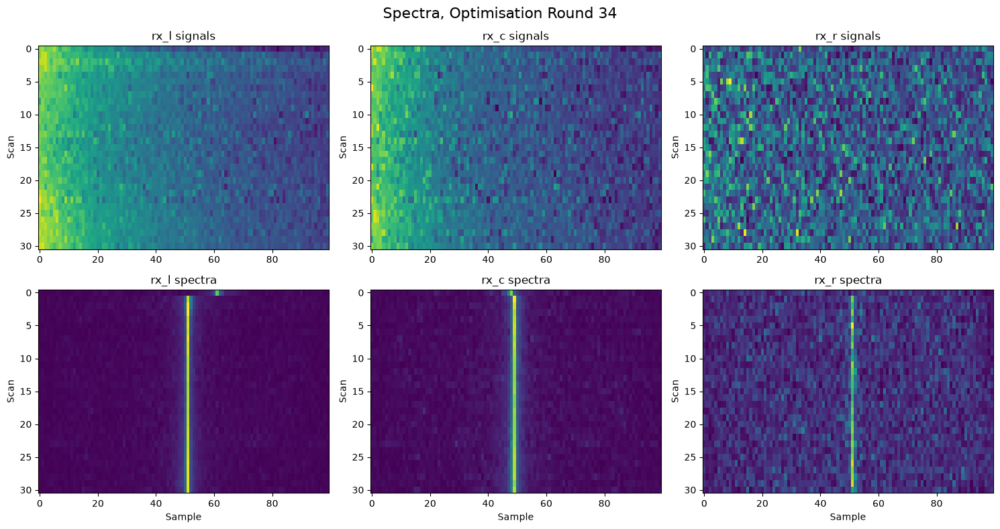

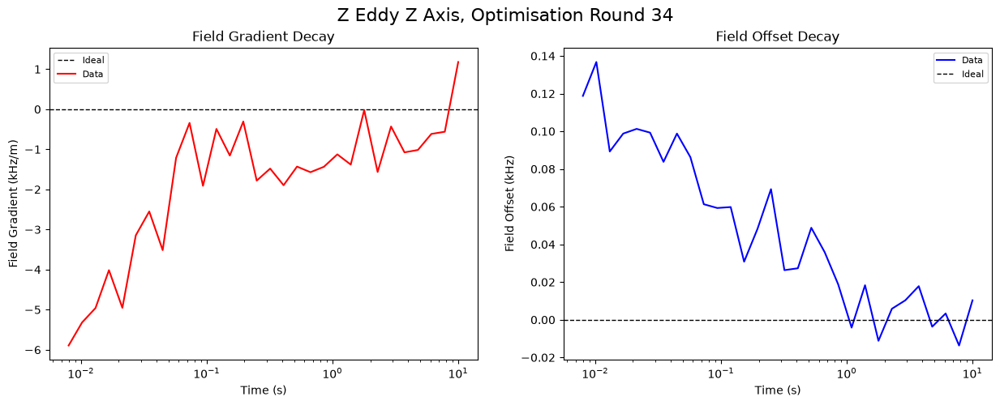

[I 2026-11-24 18:15:48,299] Trial 34 finished with value: 125.71935982559748 and parameters: {'Z_A1': -0.0009330433905370167, 'Z_A2': -0.00039650679883643713, 'Z_A3': -9.055276523947497e-10, 'Z_A4': 4.348877705441978e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.257e+02
Total cost = 1.257e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013773114940991676
B nanmax = 0.013773114940991676
B contains nan = False
Trial 35


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013551757011505721 !!!!!!!!!!!!!!!!


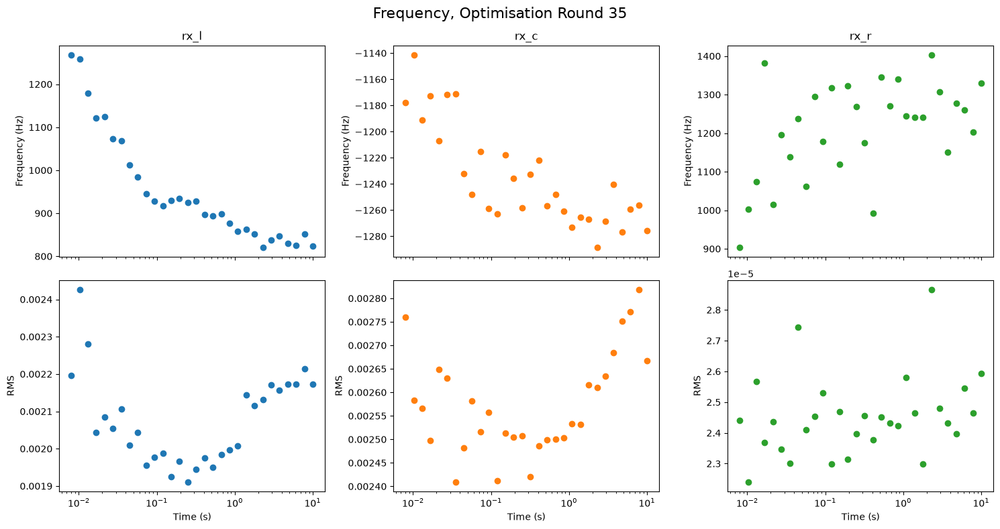

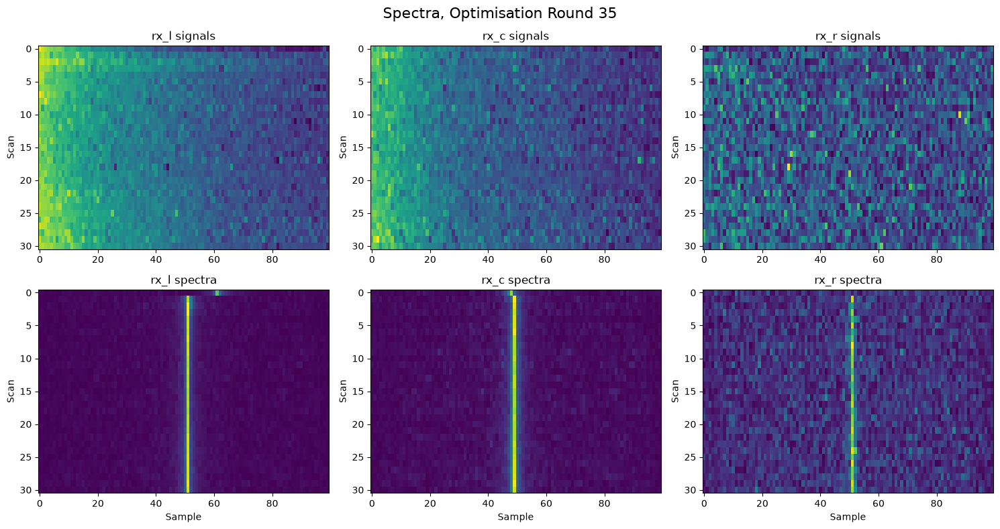

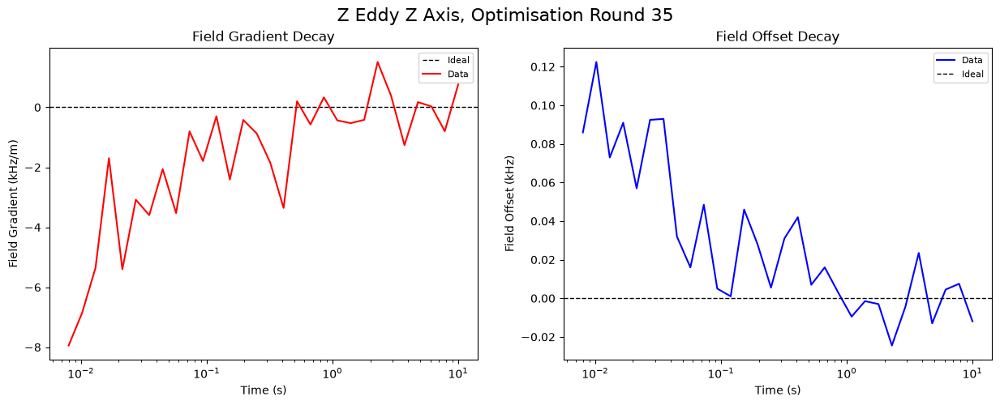

[I 2026-11-24 18:16:36,419] Trial 35 finished with value: 112.07122680463108 and parameters: {'Z_A1': -0.0009598437758845184, 'Z_A2': -0.000369488064556416, 'Z_A3': -3.015289123535391e-09, 'Z_A4': -6.270325337795565e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.121e+02
Total cost = 1.121e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01264161138204156
B nanmax = 0.01264161138204156
B contains nan = False
Trial 36


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01243843519980962 !!!!!!!!!!!!!!!!


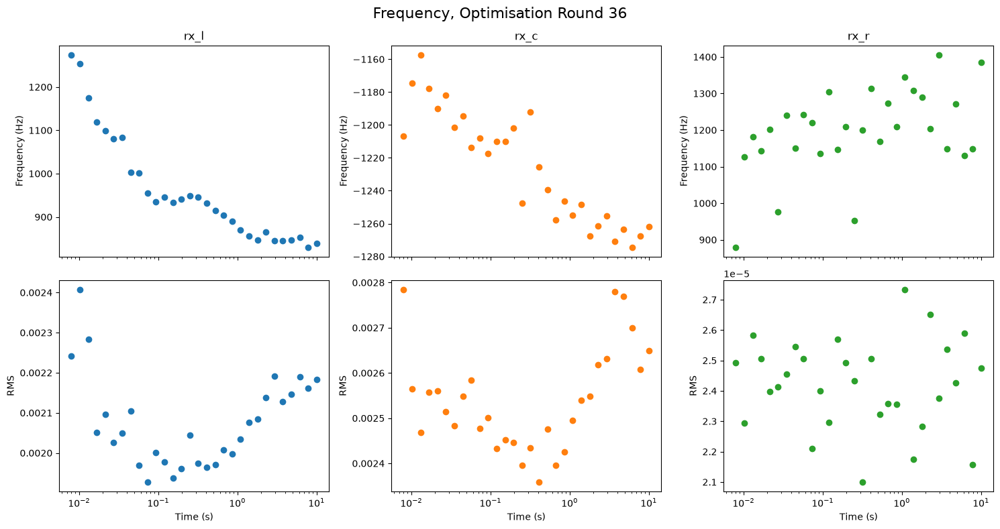

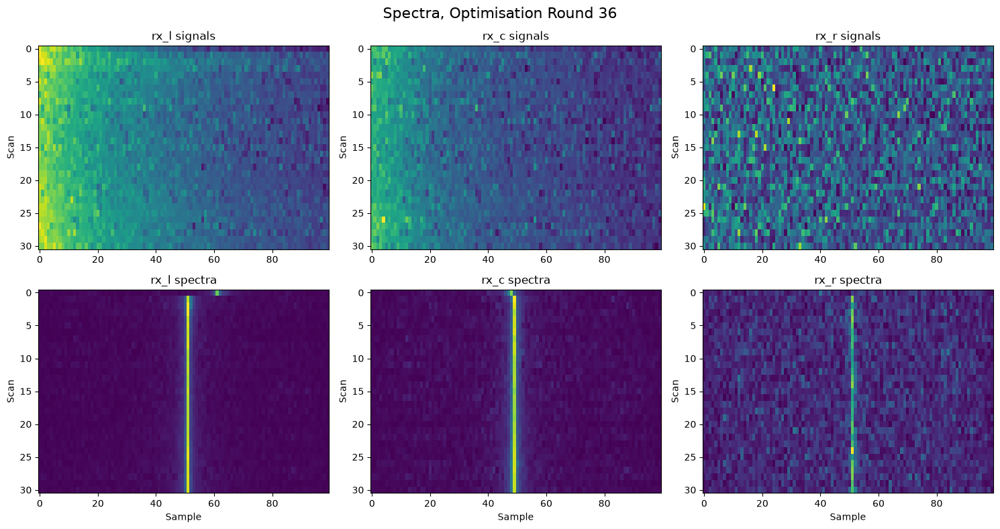

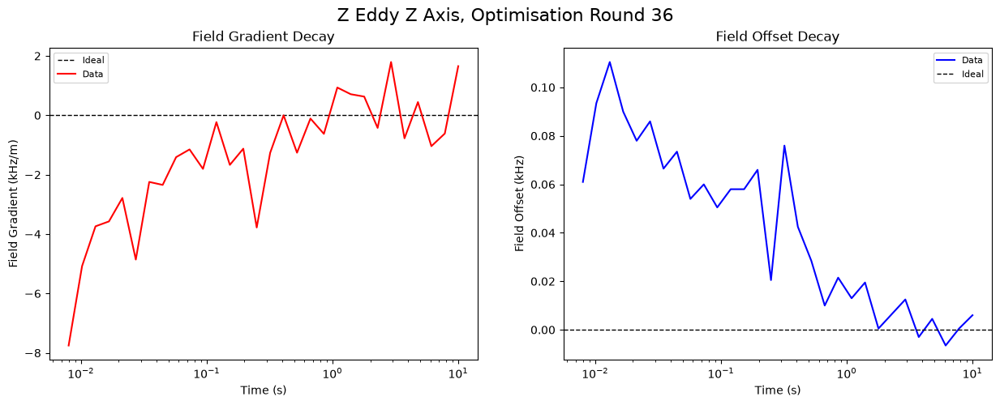

[I 2026-11-24 18:17:24,552] Trial 36 finished with value: 83.92779098285394 and parameters: {'Z_A1': -0.0007959873011209394, 'Z_A2': -0.0004232477237777446, 'Z_A3': -4.684076877822128e-09, 'Z_A4': -4.721996333263738e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 8.393e+01
Total cost = 8.393e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012211337891688009
B nanmax = 0.012211337891688009
B contains nan = False
Trial 37


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012015076256330266 !!!!!!!!!!!!!!!!


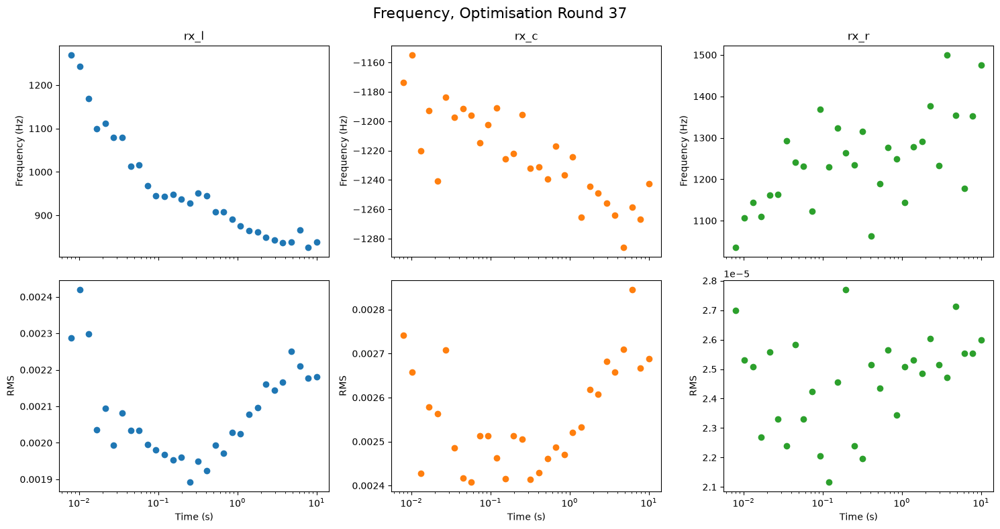

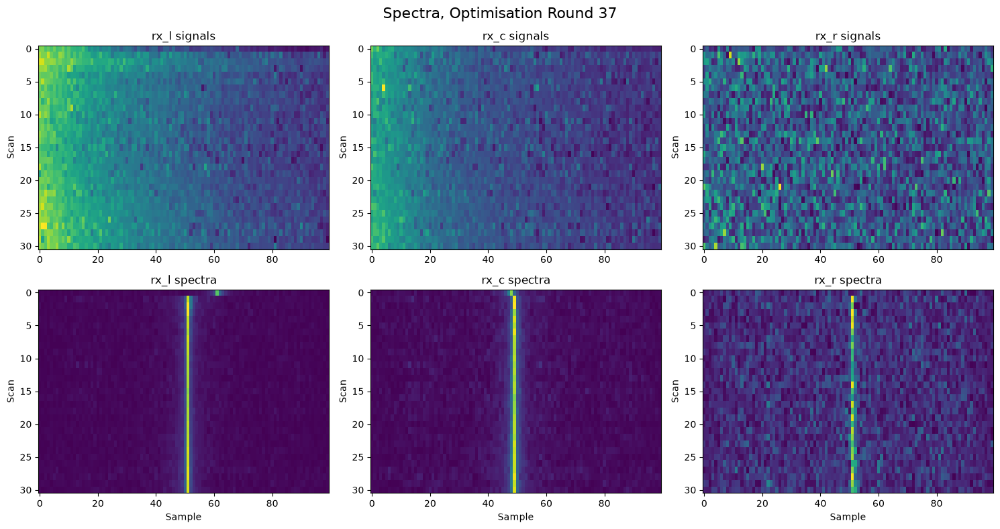

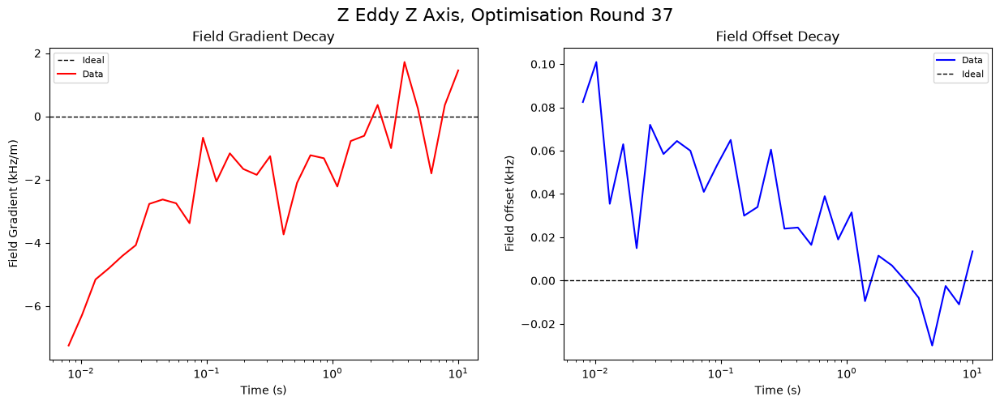

[I 2026-11-24 18:18:12,637] Trial 37 finished with value: 134.71162241308087 and parameters: {'Z_A1': -0.0007489976326643771, 'Z_A2': -0.0004285312679759553, 'Z_A3': -4.994601896675671e-09, 'Z_A4': -4.62232171125876e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.347e+02
Total cost = 1.347e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012673400947779233
B nanmax = 0.012673400947779233
B contains nan = False
Trial 38


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012469711857246029 !!!!!!!!!!!!!!!!


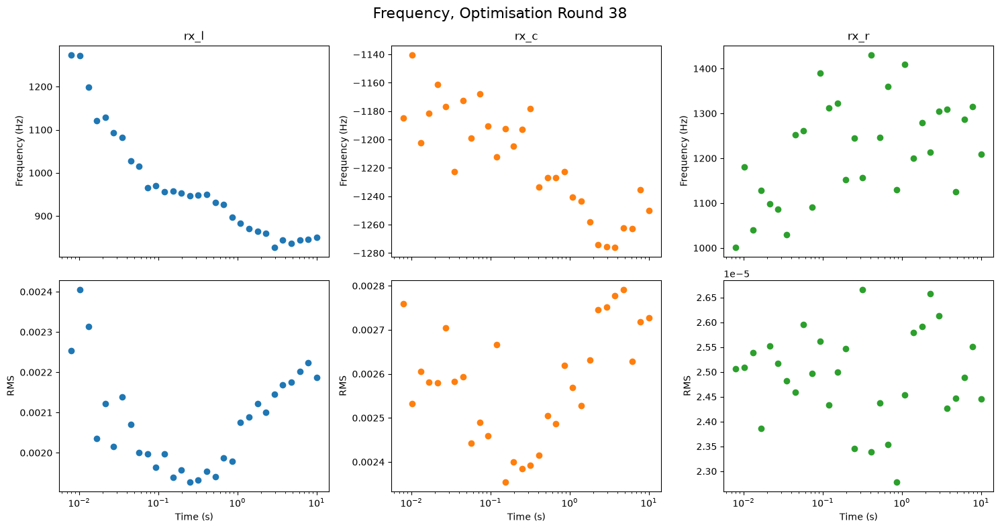

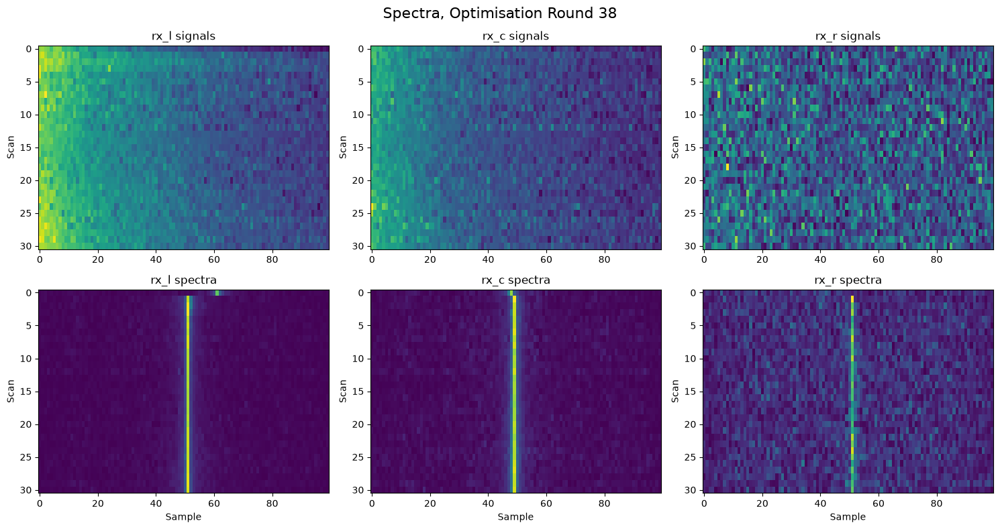

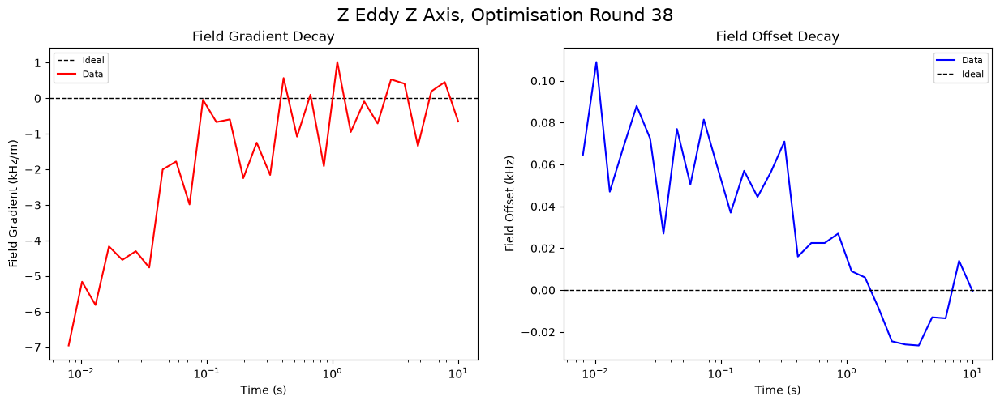

[I 2026-11-24 18:19:00,702] Trial 38 finished with value: 164.32690448836328 and parameters: {'Z_A1': -0.0007495421893950001, 'Z_A2': -0.0004722526283695695, 'Z_A3': 6.387222234118003e-10, 'Z_A4': 5.529545926859479e-10}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.643e+02
Total cost = 1.643e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012332358312441054
B nanmax = 0.012332358312441054
B contains nan = False
Trial 39


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012134151700156 !!!!!!!!!!!!!!!!


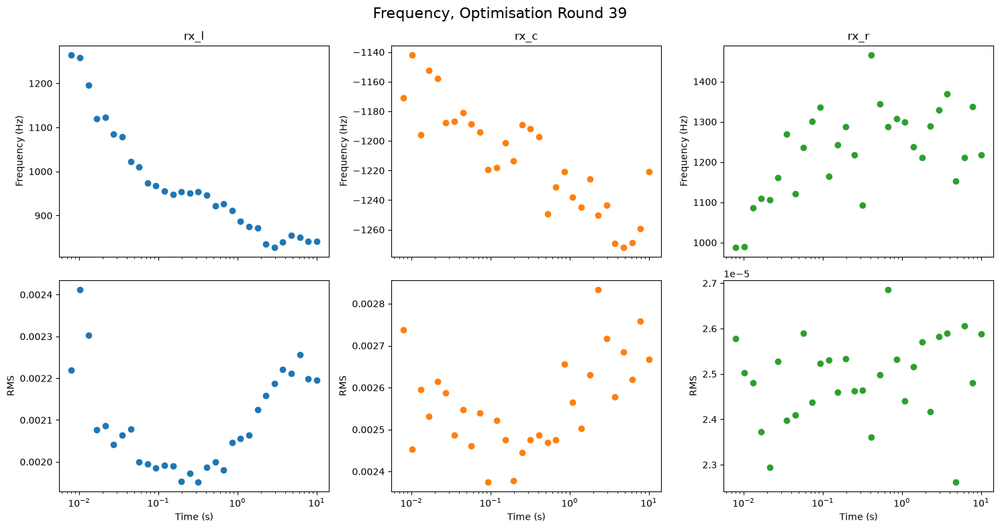

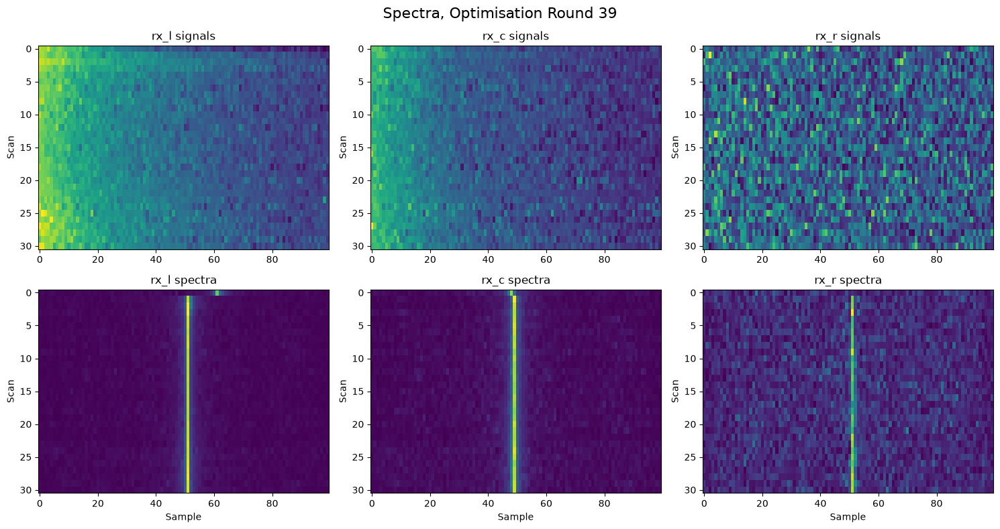

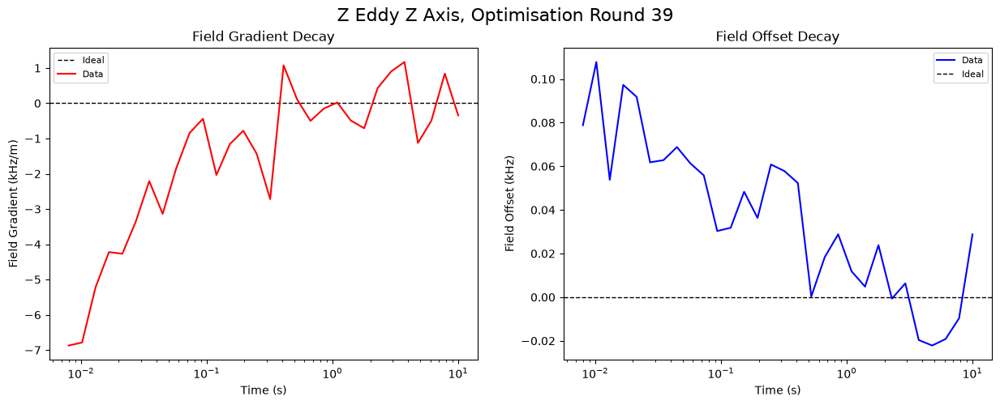

[I 2026-11-24 18:19:48,975] Trial 39 finished with value: 177.48570298807127 and parameters: {'Z_A1': -0.0007582090564720381, 'Z_A2': -0.00043100842688471733, 'Z_A3': -3.847789855045801e-09, 'Z_A4': -5.402624418455695e-10}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.775e+02
Total cost = 1.775e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01383246883242516
B nanmax = 0.01383246883242516
B contains nan = False
Trial 40


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013610153960679173 !!!!!!!!!!!!!!!!


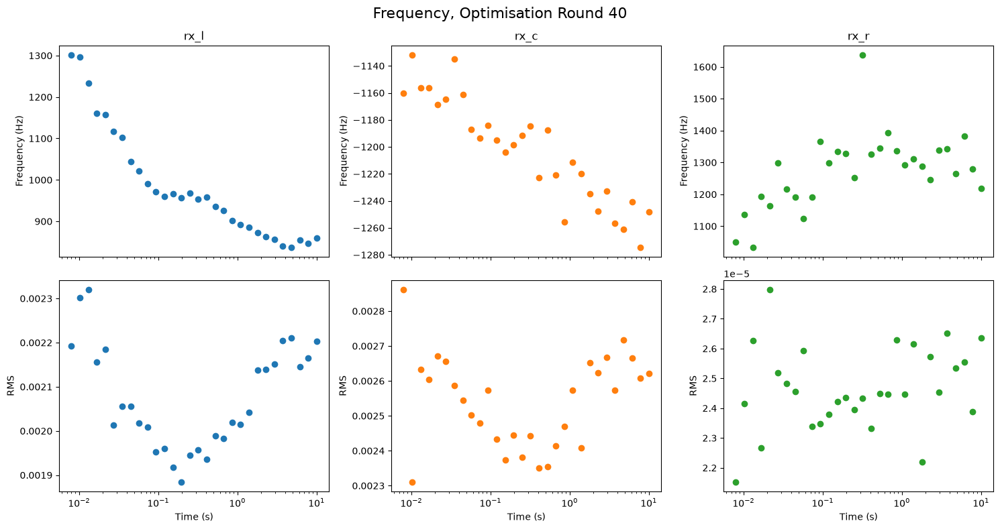

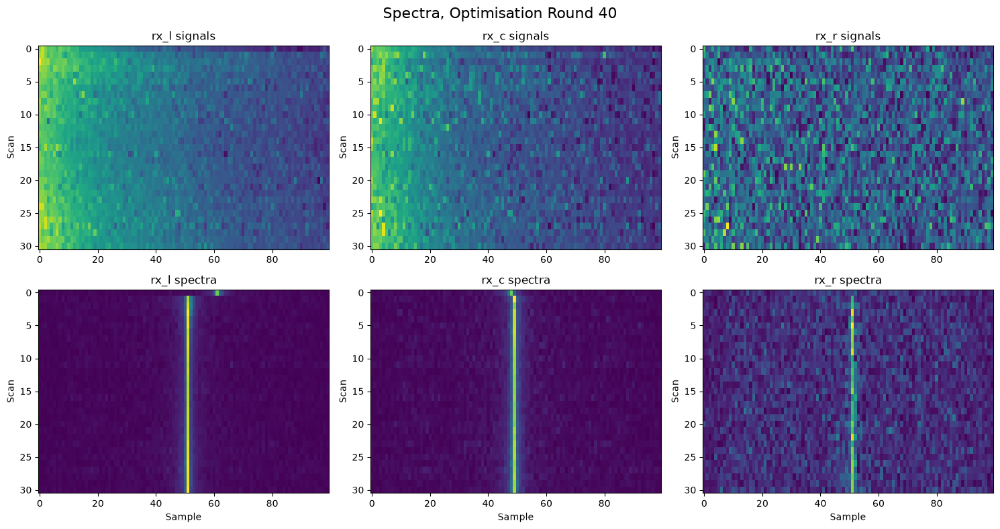

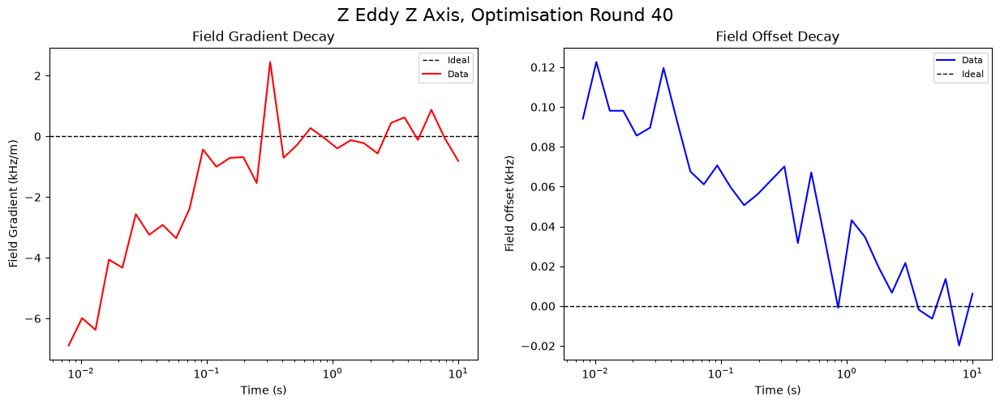

[I 2026-11-24 18:20:37,094] Trial 40 finished with value: 168.80780674542513 and parameters: {'Z_A1': -0.0008902588609922632, 'Z_A2': -0.00044403133886364917, 'Z_A3': -5.96590921896607e-09, 'Z_A4': -2.154957617869262e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.688e+02
Total cost = 1.688e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01298009330657982
B nanmax = 0.01298009330657982
B contains nan = False
Trial 41


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012771478851387531 !!!!!!!!!!!!!!!!


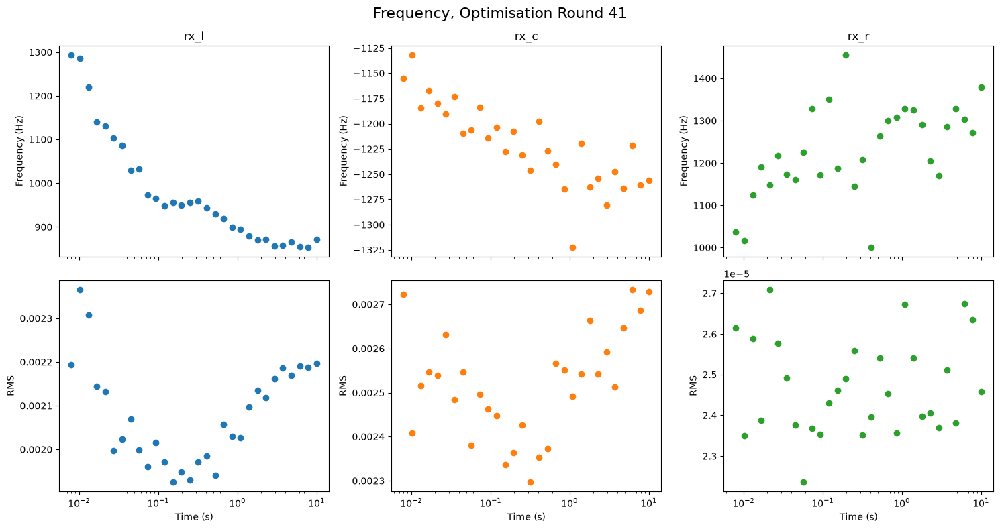

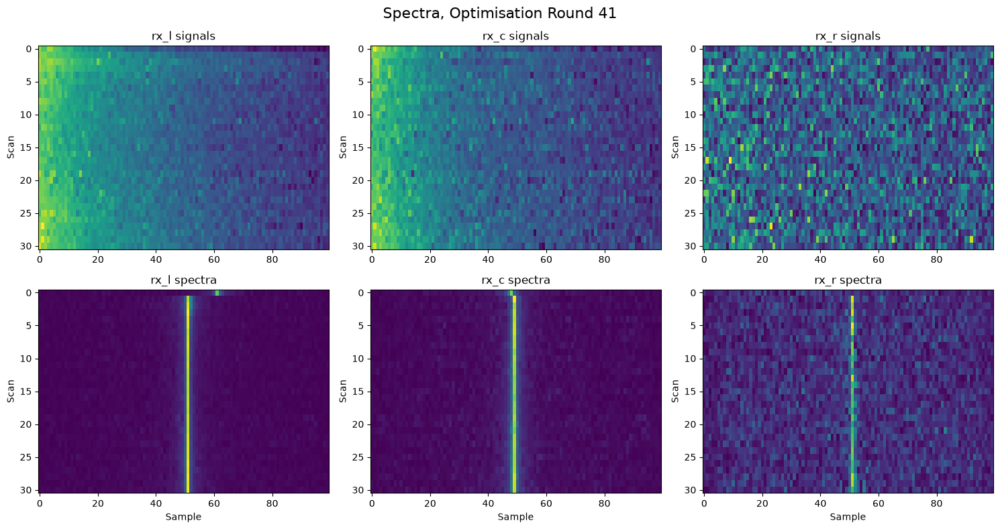

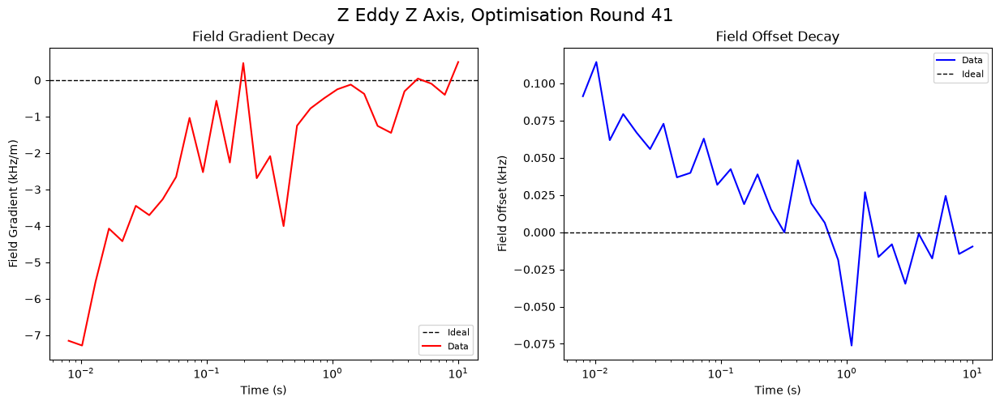

[I 2026-11-24 18:21:25,099] Trial 41 finished with value: 187.60492299881824 and parameters: {'Z_A1': -0.0008615534094136712, 'Z_A2': -0.0003907892764071244, 'Z_A3': 2.4670679308257305e-09, 'Z_A4': -5.939342338123438e-10}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.876e+02
Total cost = 1.876e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014496151020011101
B nanmax = 0.014496151020011101
B contains nan = False
Trial 42


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014263167361987475 !!!!!!!!!!!!!!!!


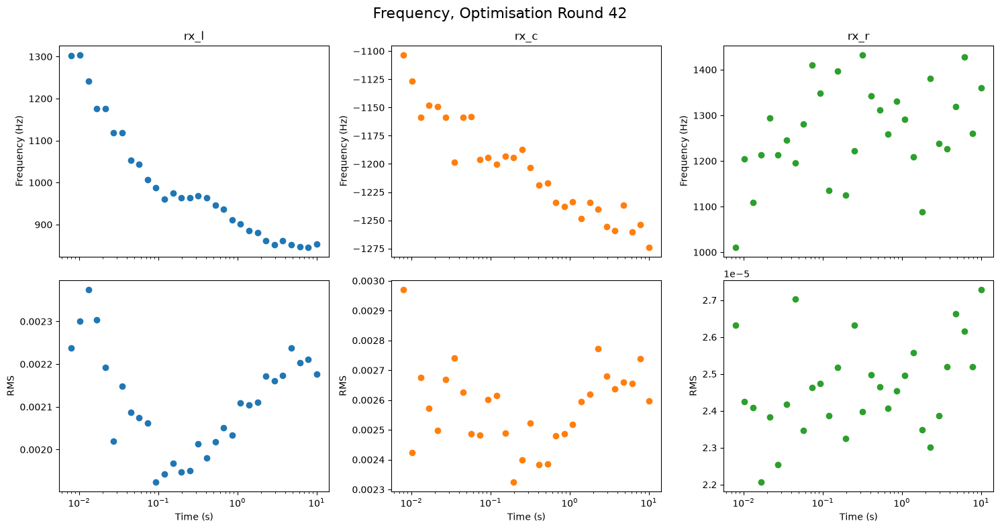

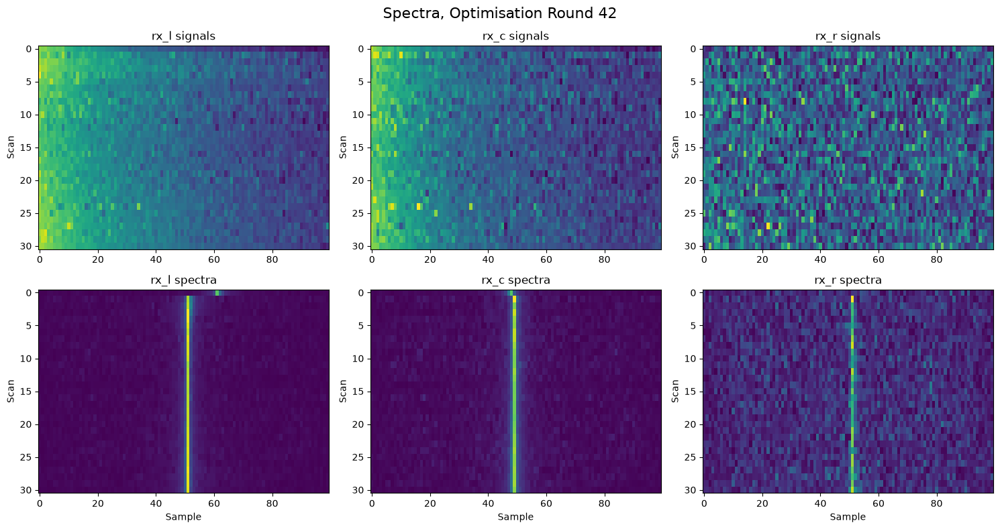

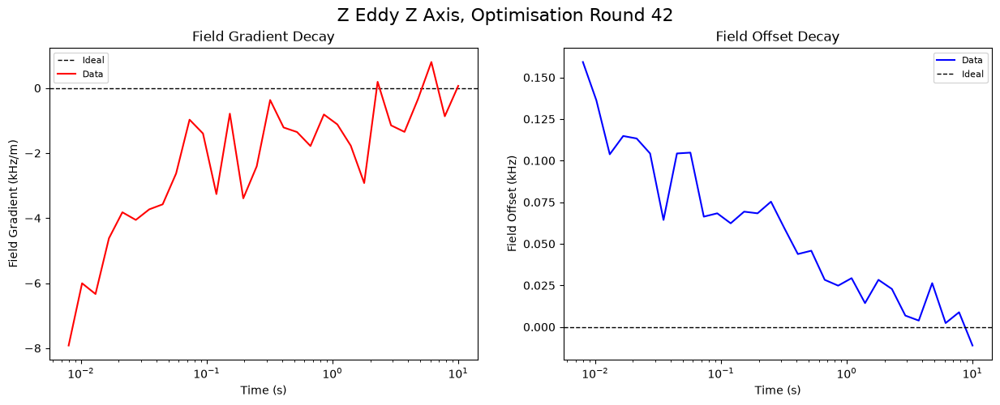

[I 2026-11-24 18:22:13,499] Trial 42 finished with value: 157.33883090826865 and parameters: {'Z_A1': -0.0008814165135100705, 'Z_A2': -0.0005163542764427691, 'Z_A3': -1.8189048083586054e-09, 'Z_A4': 1.838402705003535e-10}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.573e+02
Total cost = 1.573e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012761409245434483
B nanmax = 0.012761409245434483
B contains nan = False
Trial 43


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012556309813782902 !!!!!!!!!!!!!!!!


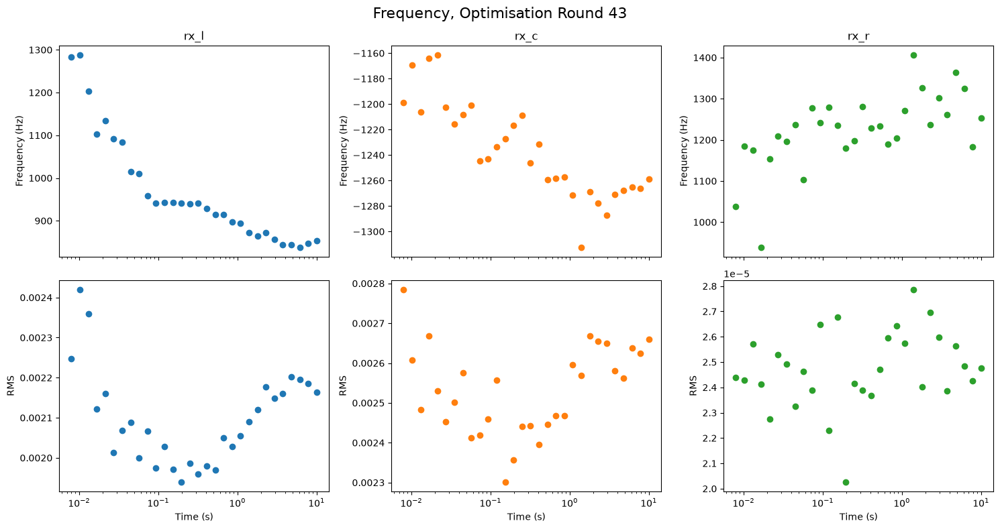

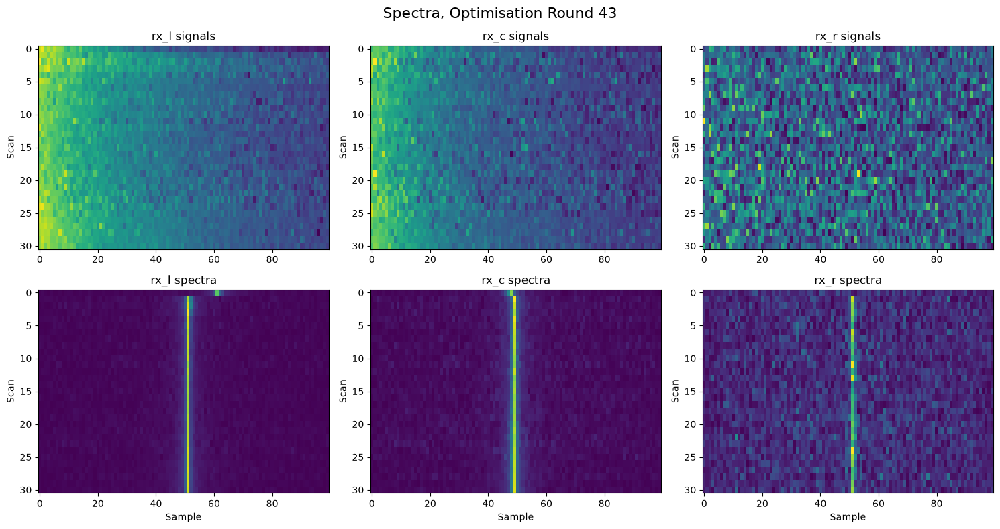

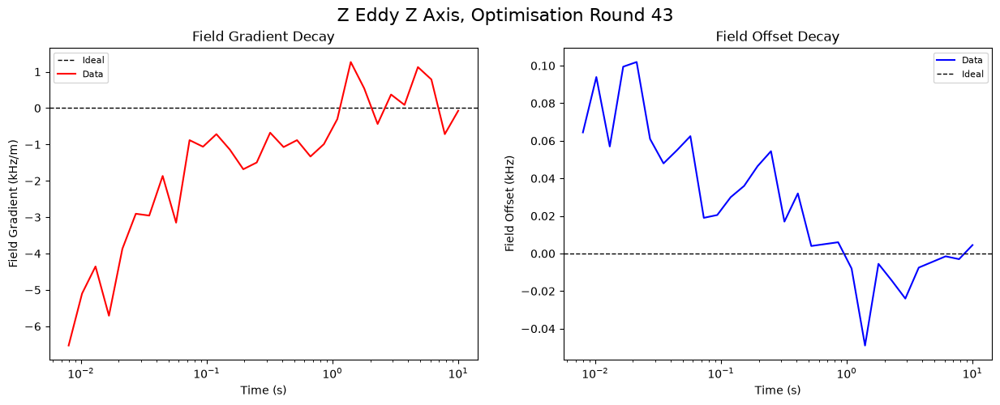

[I 2026-11-24 18:23:01,823] Trial 43 finished with value: 92.31619073402524 and parameters: {'Z_A1': -0.0008558289616564866, 'Z_A2': -0.0003755065420617451, 'Z_A3': -6.815928643999949e-09, 'Z_A4': -5.85495747779272e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 9.232e+01
Total cost = 9.232e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013656860039380407
B nanmax = 0.013656860039380407
B contains nan = False
Trial 44


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013437367667838656 !!!!!!!!!!!!!!!!


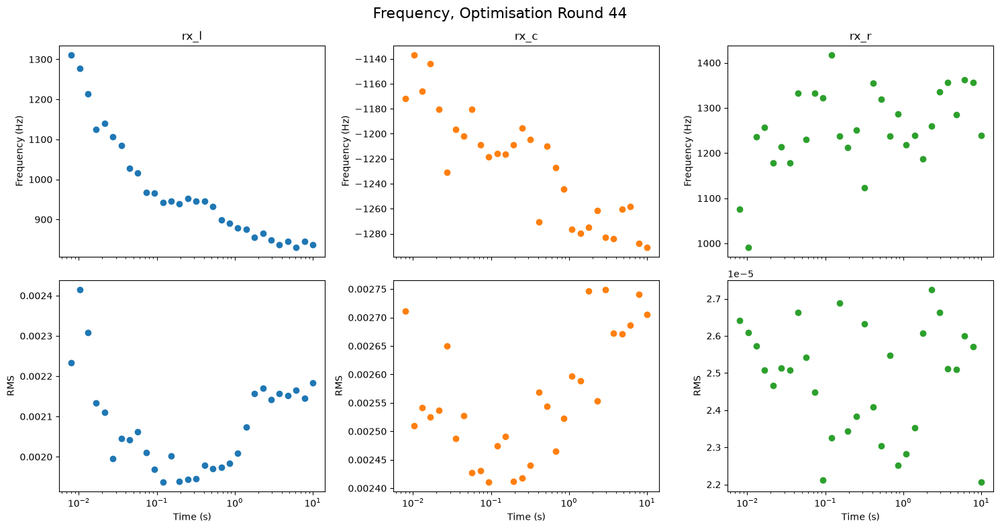

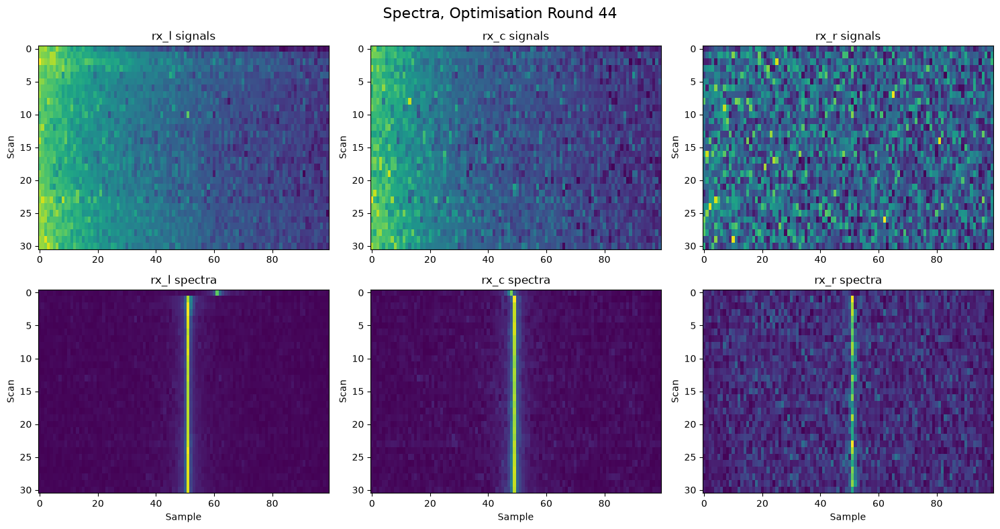

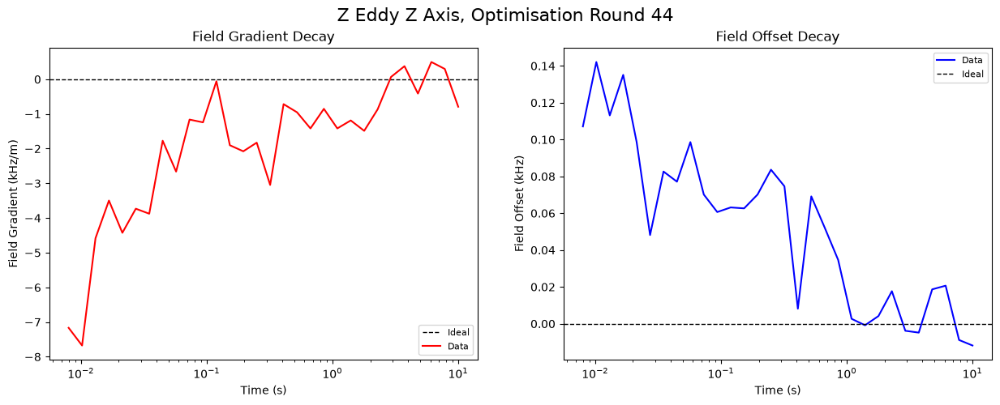

[I 2026-11-24 18:23:50,038] Trial 44 finished with value: 156.2784482649561 and parameters: {'Z_A1': -0.000881954506990914, 'Z_A2': -0.00043542766101060476, 'Z_A3': -1.441718114215702e-09, 'Z_A4': 7.32772009956163e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.563e+02
Total cost = 1.563e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013428518359992035
B nanmax = 0.013428518359992035
B contains nan = False
Trial 45


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013212693631072109 !!!!!!!!!!!!!!!!


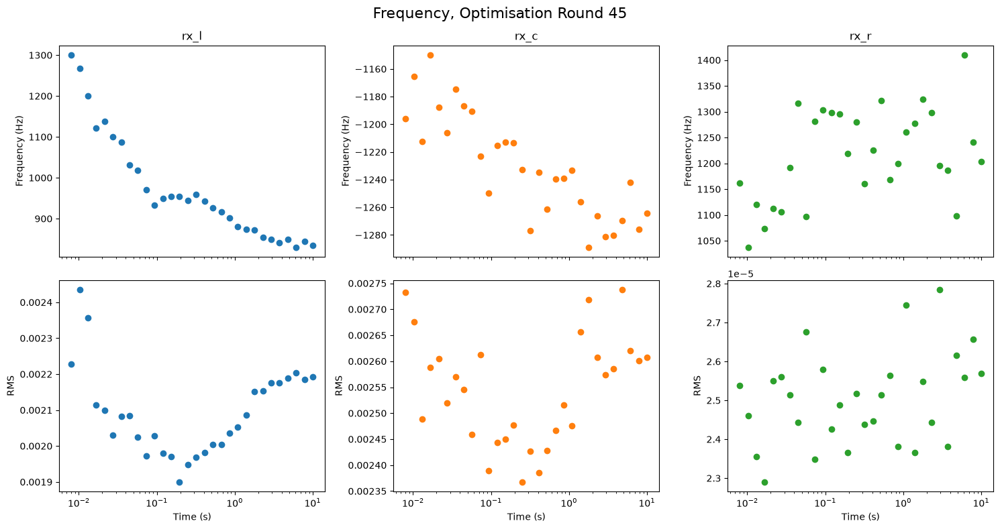

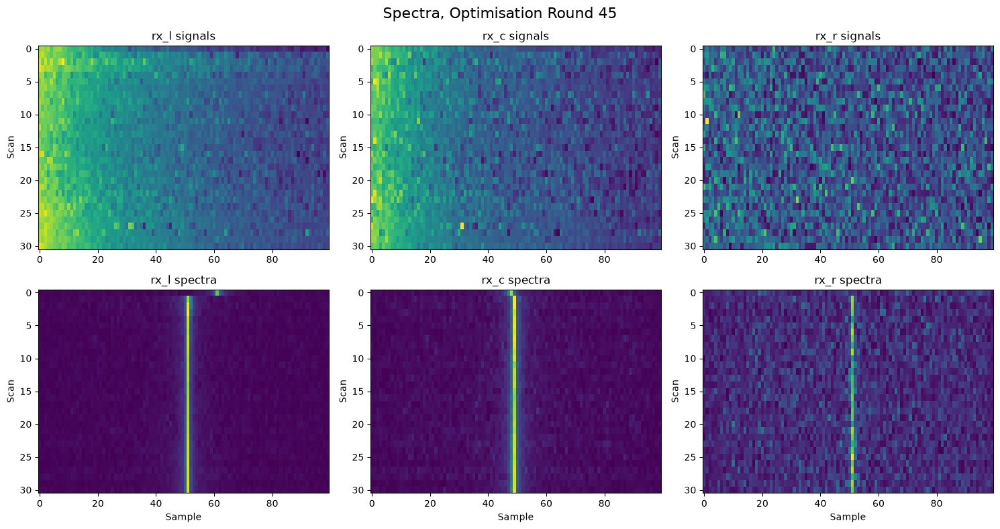

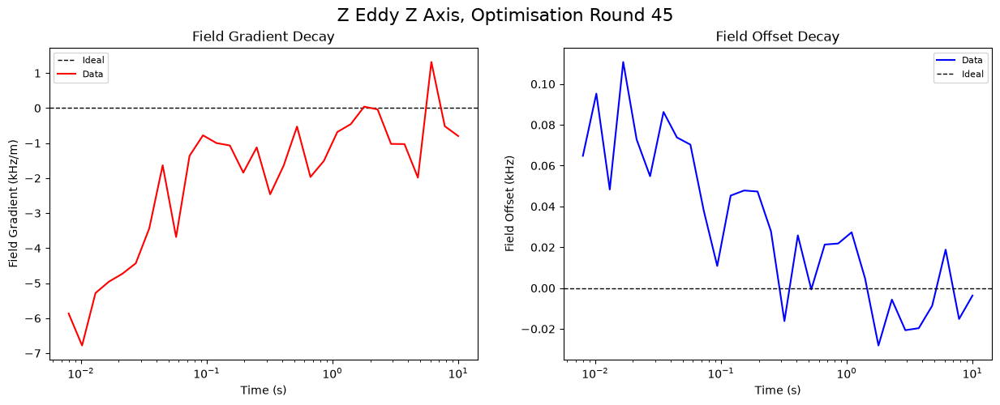

[I 2026-11-24 18:24:38,078] Trial 45 finished with value: 154.96295994974437 and parameters: {'Z_A1': -0.0008122347035450874, 'Z_A2': -0.00048254654936559667, 'Z_A3': 5.227641342481403e-10, 'Z_A4': 8.10688601110064e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.550e+02
Total cost = 1.550e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013143404605364789
B nanmax = 0.013143404605364789
B contains nan = False
Trial 46


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012932164825598409 !!!!!!!!!!!!!!!!


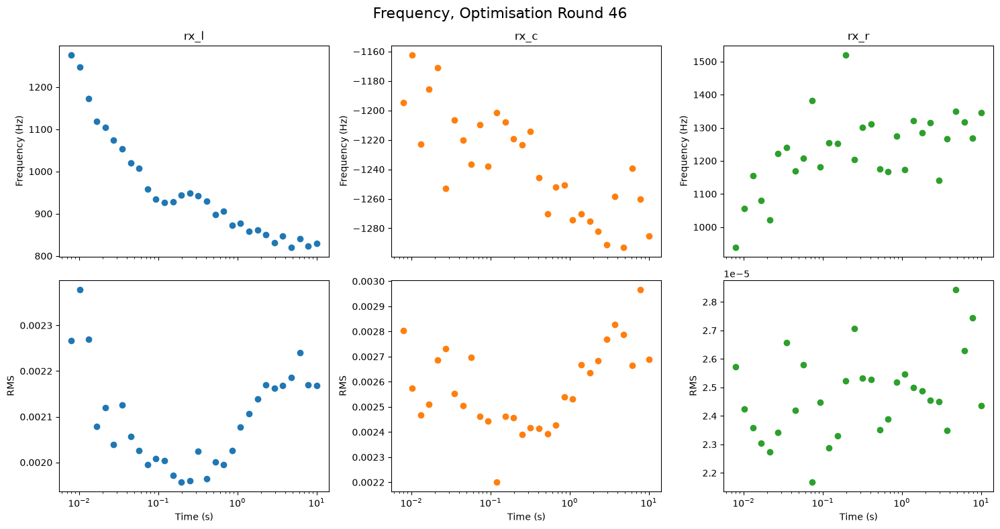

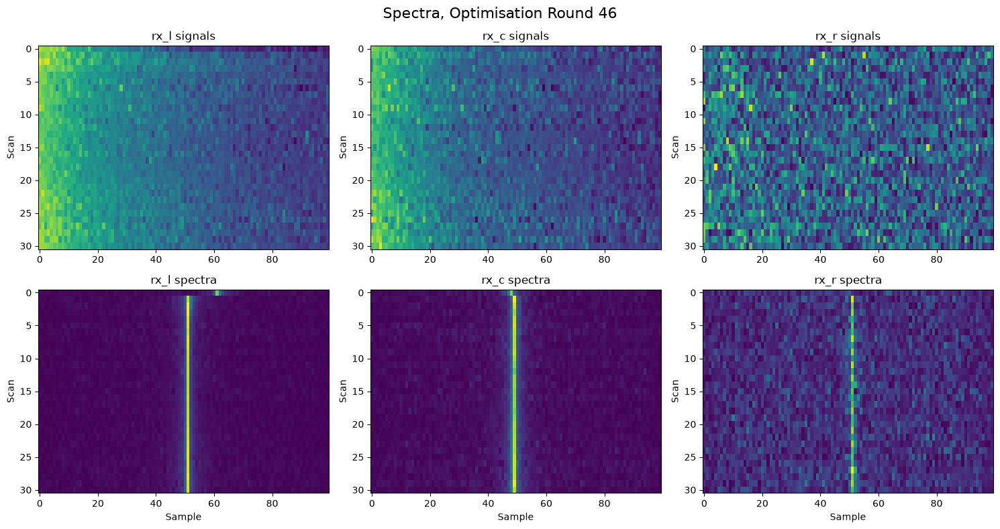

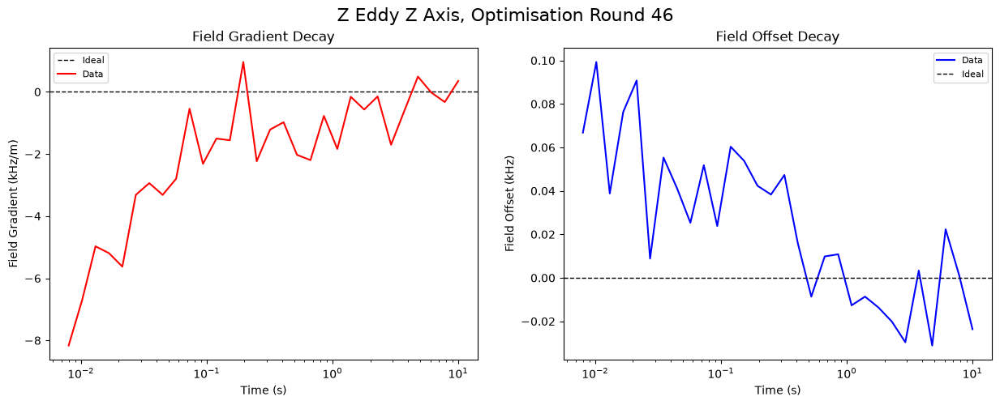

[I 2026-11-24 18:25:26,102] Trial 46 finished with value: 170.67926320793177 and parameters: {'Z_A1': -0.0008576200869608588, 'Z_A2': -0.00041032481122819817, 'Z_A3': -1.9263730680355545e-09, 'Z_A4': 1.0275523945739276e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.707e+02
Total cost = 1.707e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.011925063424011333
B nanmax = 0.011925063424011333
B contains nan = False
Trial 47


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.011733402279184355 !!!!!!!!!!!!!!!!


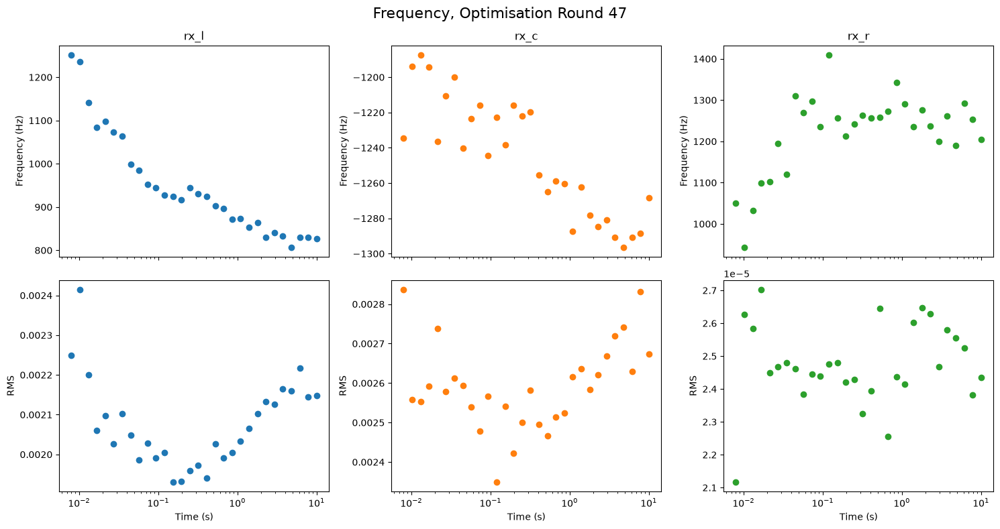

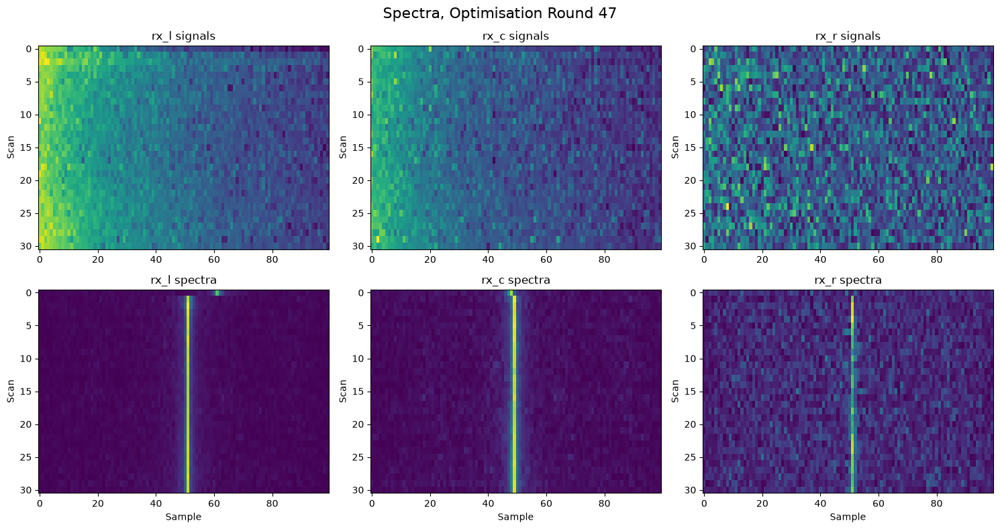

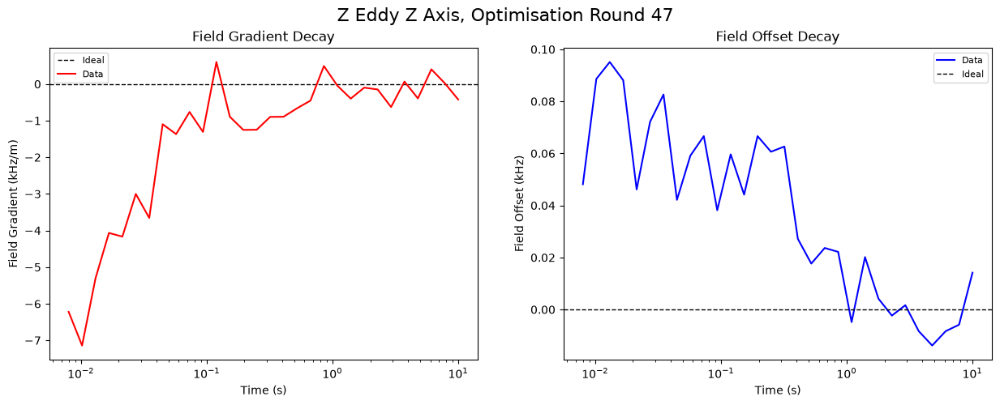

[I 2026-11-24 18:26:14,141] Trial 47 finished with value: 111.19800026630737 and parameters: {'Z_A1': -0.0007183514974034935, 'Z_A2': -0.00043143546137299664, 'Z_A3': -3.8464738931790197e-10, 'Z_A4': -5.366362929593284e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.112e+02
Total cost = 1.112e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012454051235195206
B nanmax = 0.012454051235195206
B contains nan = False
Trial 48


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012253887579294428 !!!!!!!!!!!!!!!!


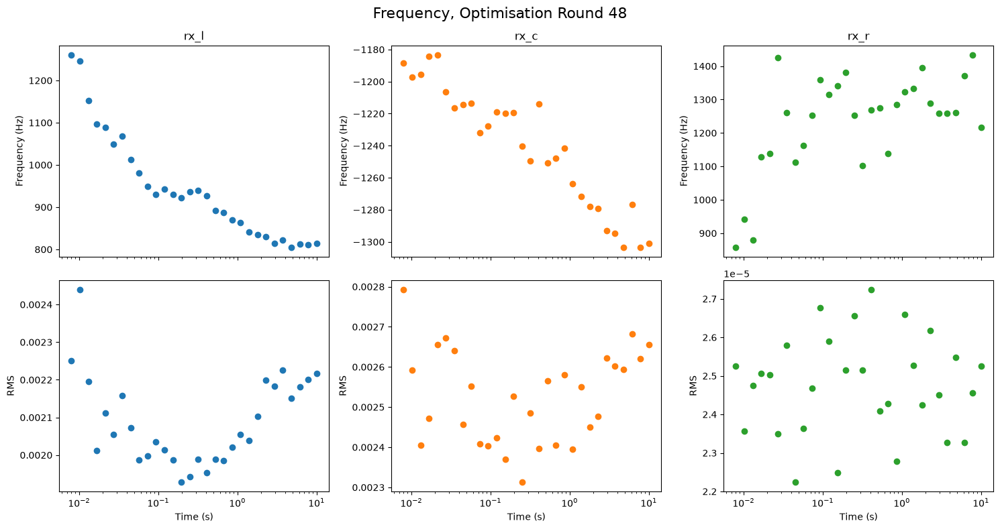

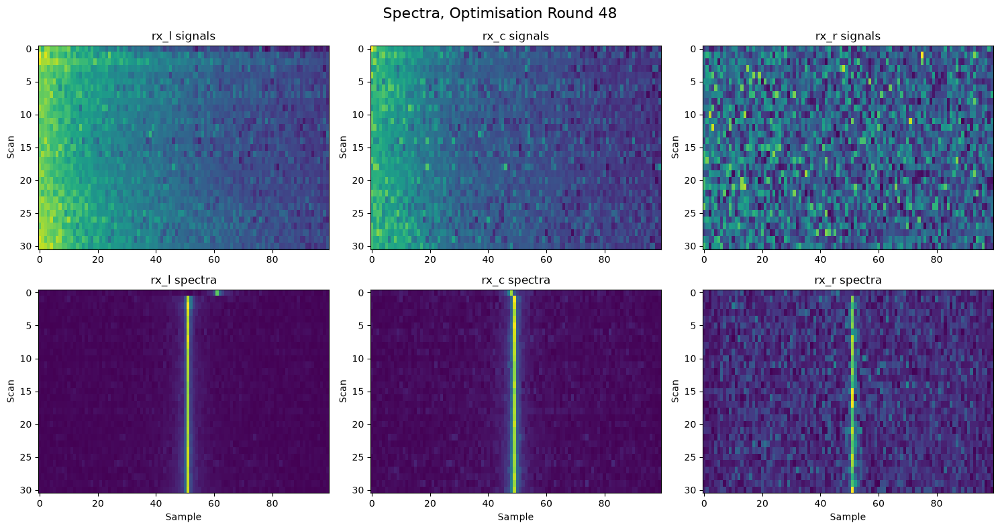

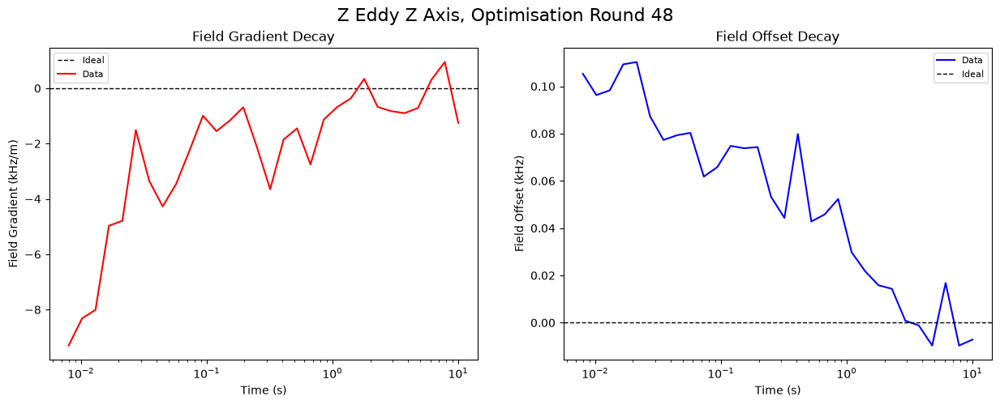

[I 2026-11-24 18:27:02,344] Trial 48 finished with value: 151.6580372775085 and parameters: {'Z_A1': -0.0007367677556088903, 'Z_A2': -0.00046388245767478185, 'Z_A3': -2.322682299295802e-09, 'Z_A4': -1.8199915005248814e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.517e+02
Total cost = 1.517e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01419515377370415
B nanmax = 0.01419515377370415
B contains nan = False
Trial 49


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013967012325783594 !!!!!!!!!!!!!!!!


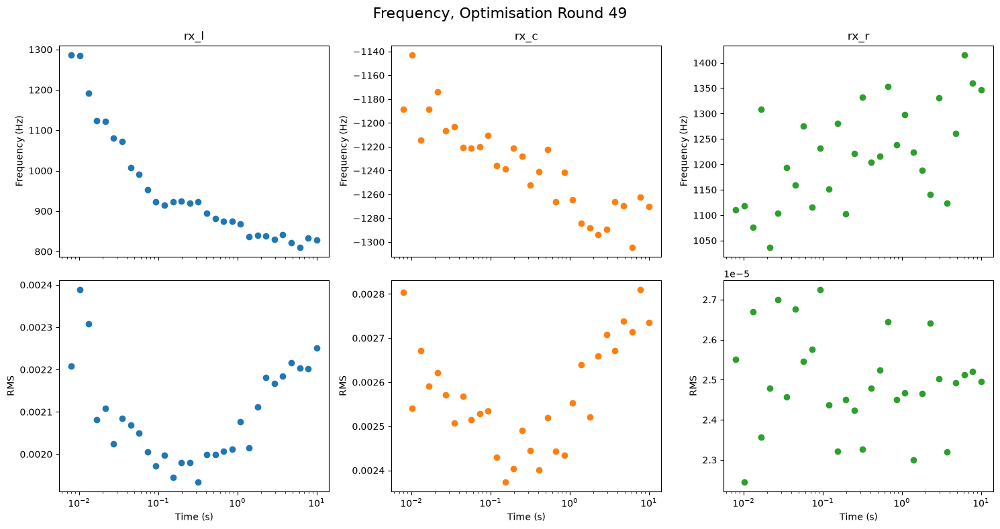

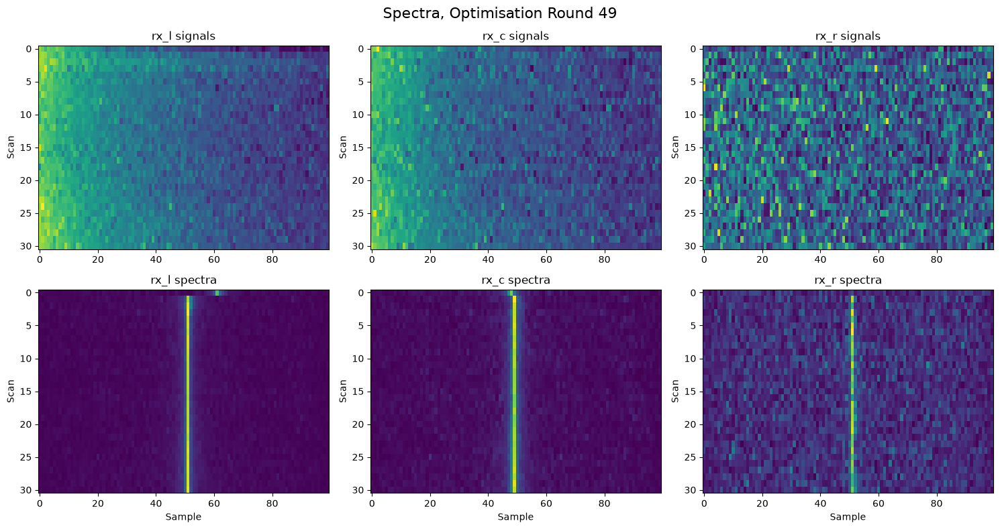

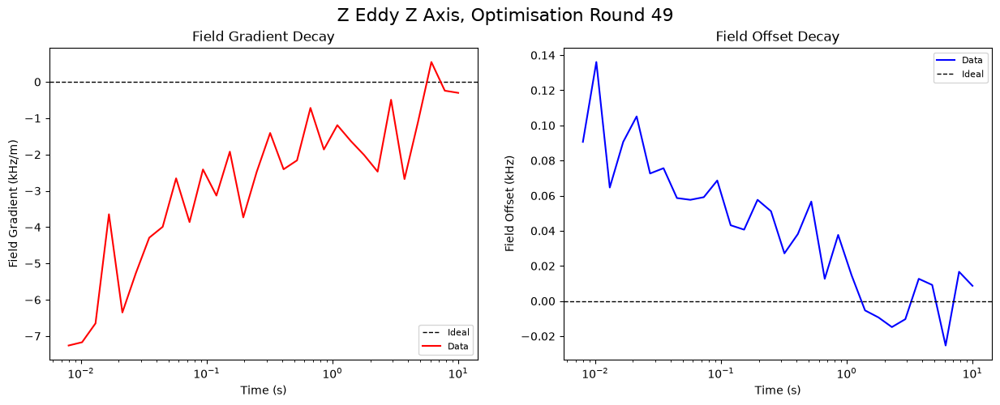

[I 2026-11-24 18:27:50,651] Trial 49 finished with value: 167.97777949150793 and parameters: {'Z_A1': -0.0009741345494748003, 'Z_A2': -0.0003957729817783206, 'Z_A3': -1.5751940618766934e-09, 'Z_A4': -1.0651937083754434e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.680e+02
Total cost = 1.680e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.011578412241153437
B nanmax = 0.011578412241153437
B contains nan = False
Trial 50


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01139232449562202 !!!!!!!!!!!!!!!!


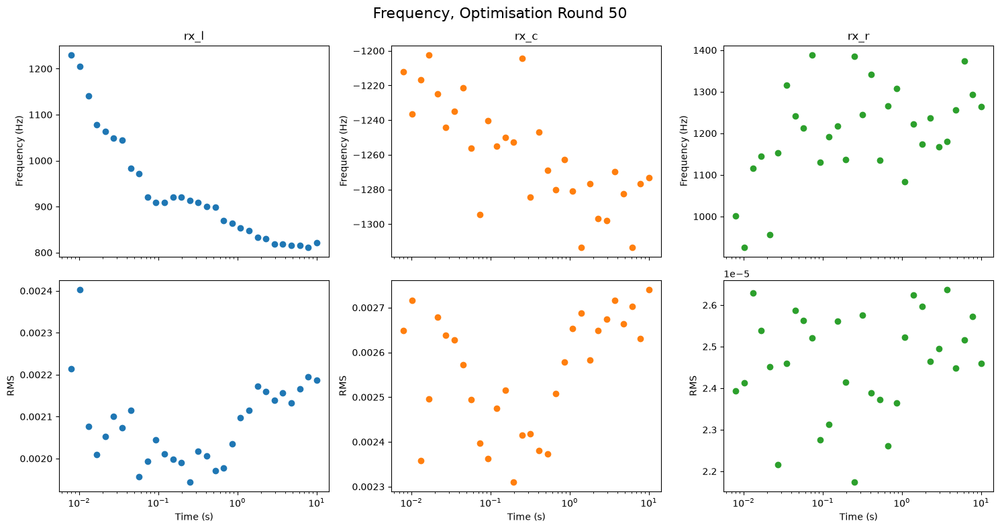

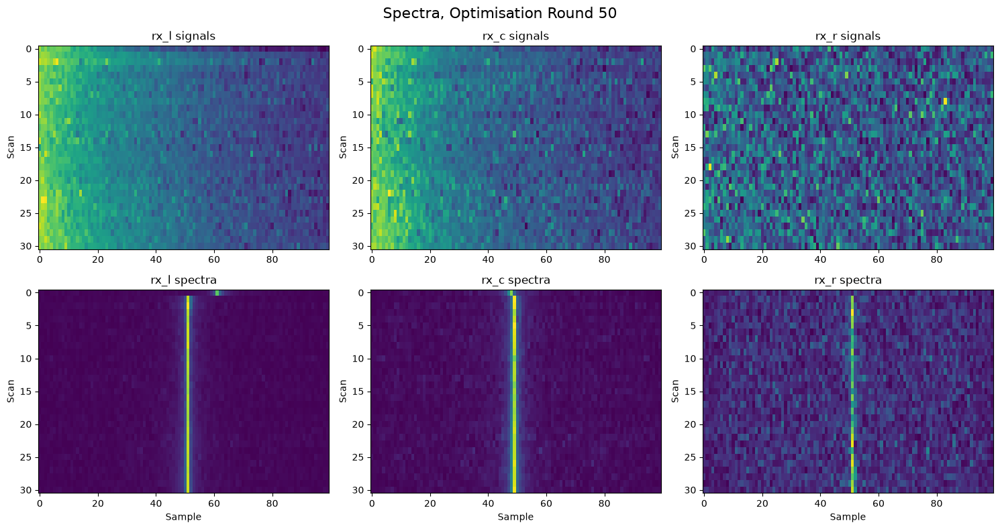

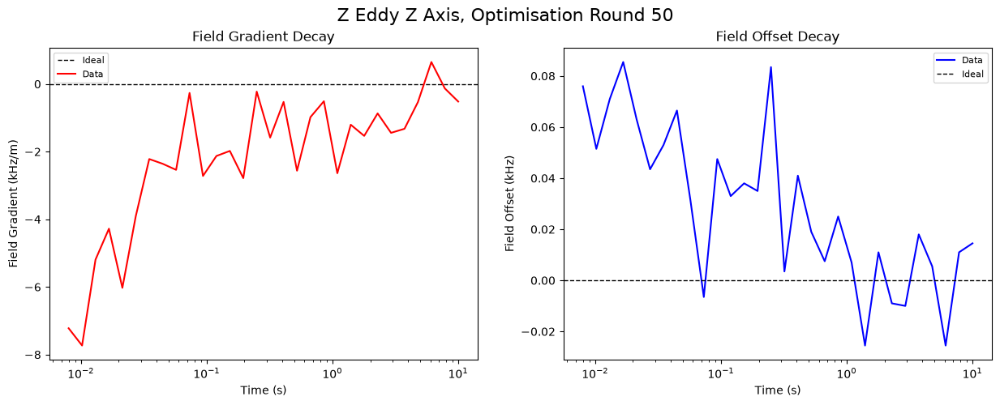

[I 2026-11-24 18:28:38,846] Trial 50 finished with value: 154.18021973467503 and parameters: {'Z_A1': -0.0007457030230546633, 'Z_A2': -0.0003711645921477953, 'Z_A3': -2.965578205997196e-09, 'Z_A4': -3.1197747624603097e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.542e+02
Total cost = 1.542e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012944864929786574
B nanmax = 0.012944864929786574
B contains nan = False
Trial 51


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012736816775350573 !!!!!!!!!!!!!!!!


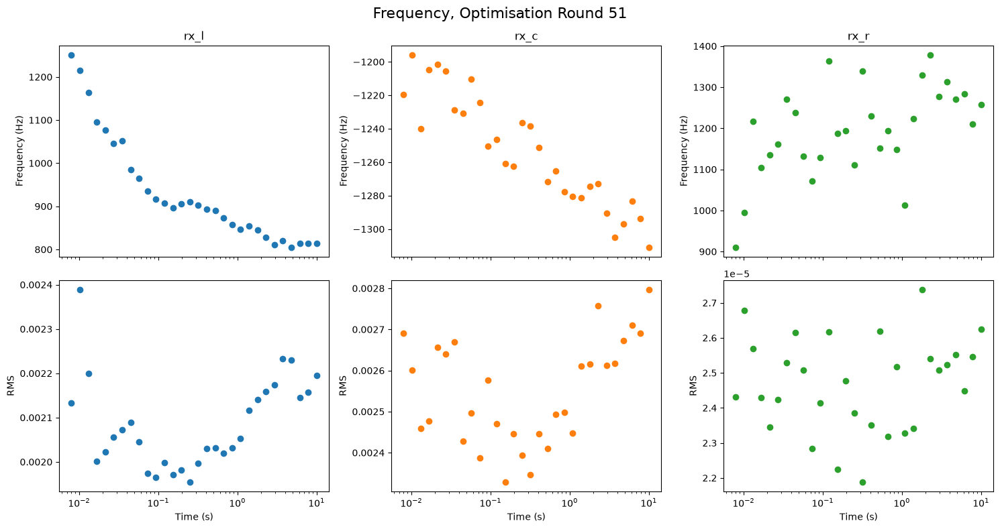

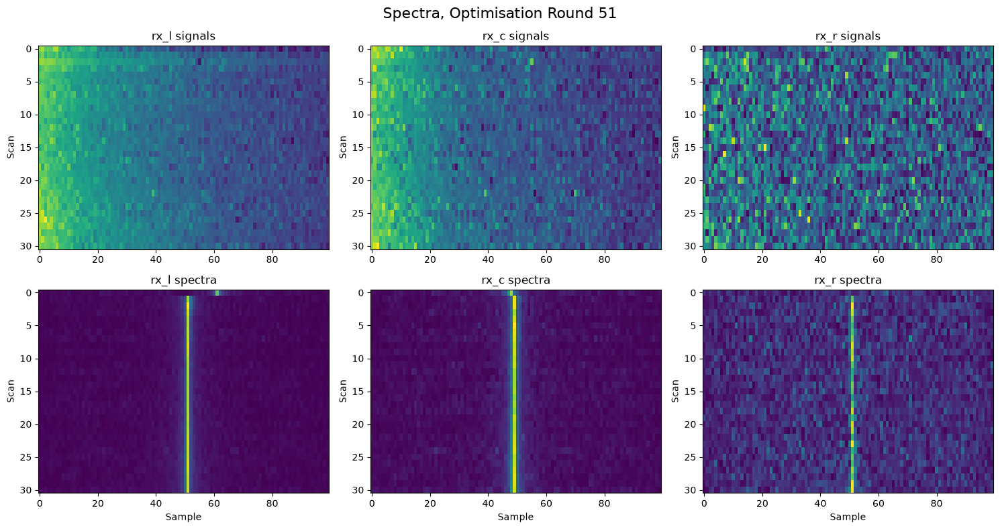

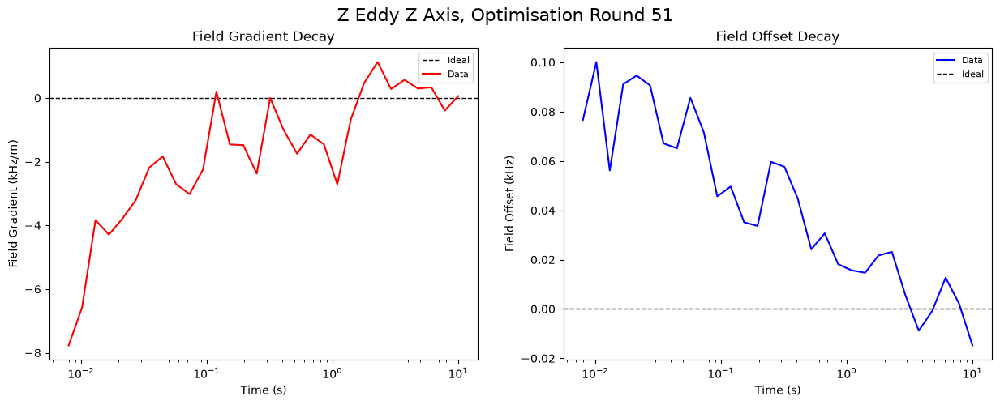

[I 2026-11-24 18:29:27,110] Trial 51 finished with value: 121.27451158006907 and parameters: {'Z_A1': -0.0008620118020601106, 'Z_A2': -0.0003869612074373636, 'Z_A3': -7.963851367158435e-09, 'Z_A4': -6.882704913276199e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.213e+02
Total cost = 1.213e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013157965780517717
B nanmax = 0.013157965780517717
B contains nan = False
Trial 52


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012946491123301674 !!!!!!!!!!!!!!!!


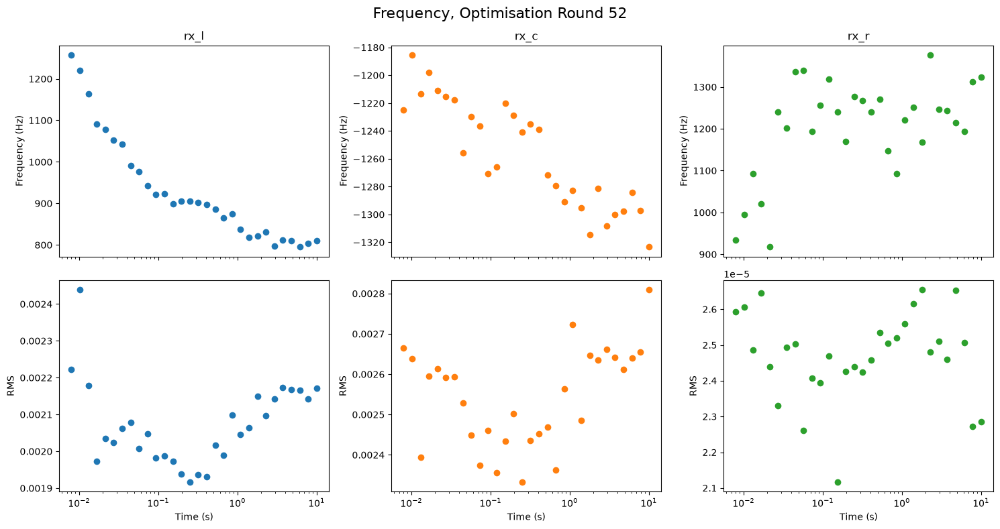

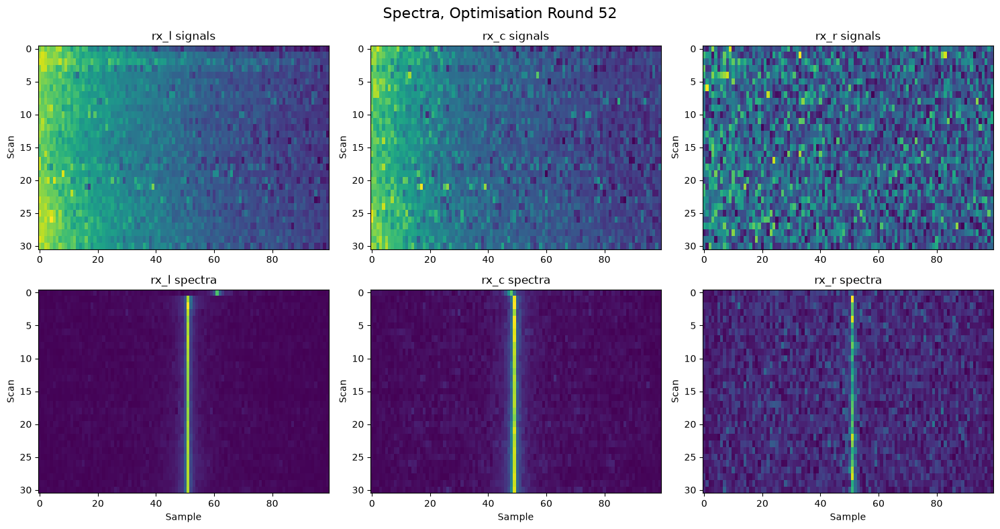

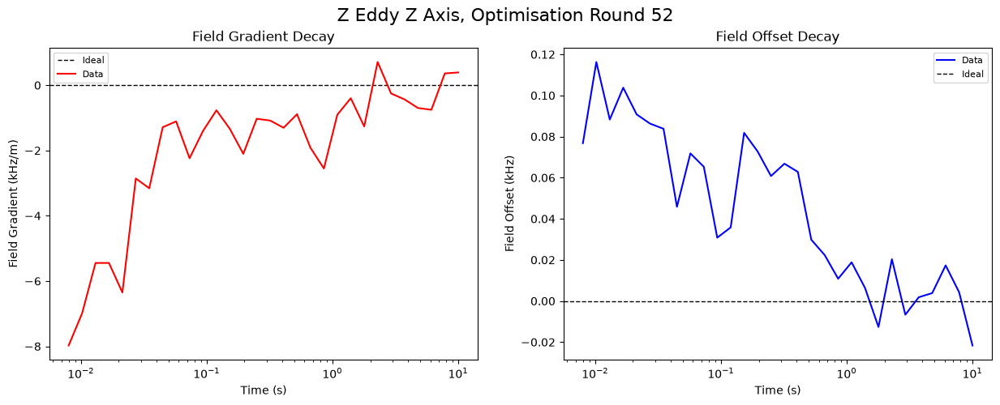

[I 2026-11-24 18:30:15,452] Trial 52 finished with value: 133.2865217661412 and parameters: {'Z_A1': -0.0008378005593694271, 'Z_A2': -0.0004313320473108676, 'Z_A3': -7.960025944309936e-09, 'Z_A4': -6.154705320524183e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.333e+02
Total cost = 1.333e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013477268509214784
B nanmax = 0.013477268509214784
B contains nan = False
Trial 53


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013260666256069451 !!!!!!!!!!!!!!!!


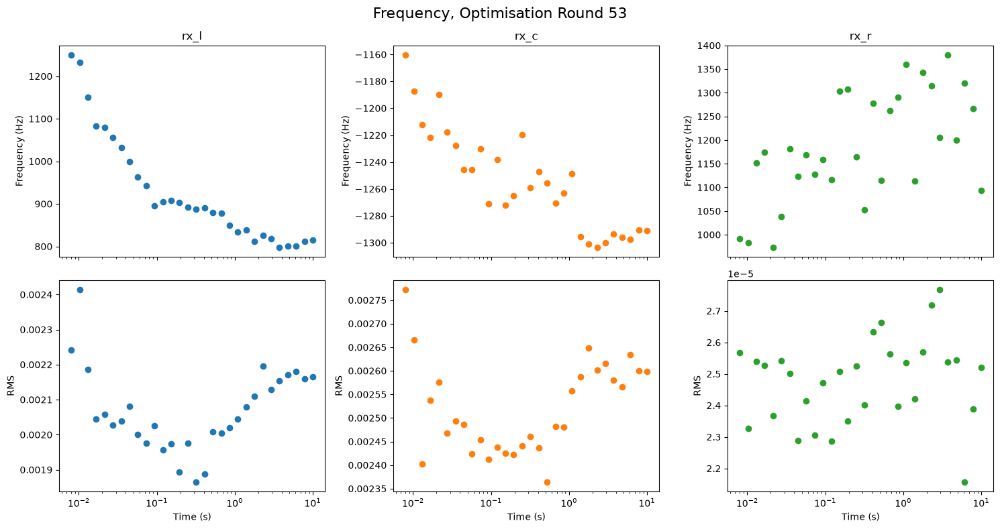

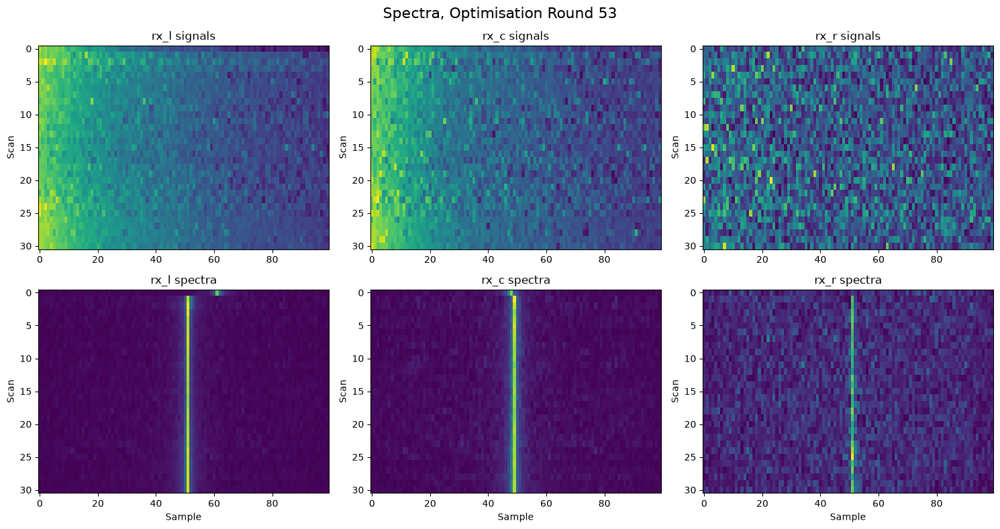

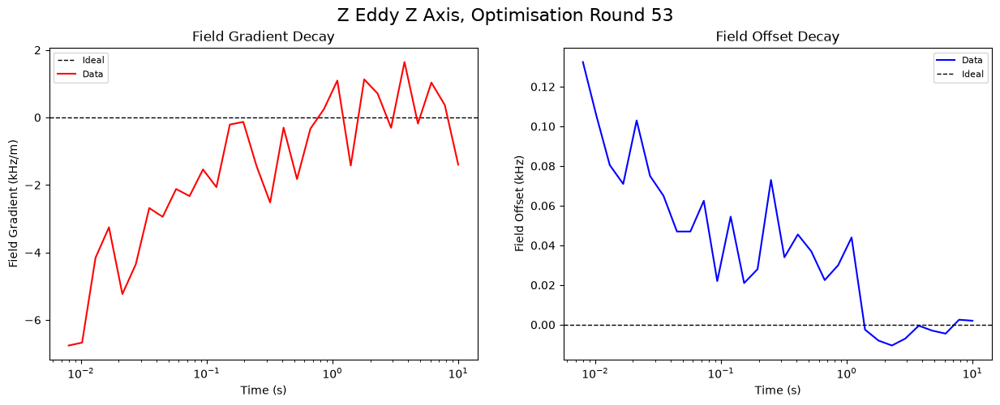

[I 2026-11-24 18:31:03,499] Trial 53 finished with value: 81.265083298434 and parameters: {'Z_A1': -0.000961408097101561, 'Z_A2': -0.00033960146579660574, 'Z_A3': -8.291192697043903e-09, 'Z_A4': -6.179289535380889e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 8.127e+01
Total cost = 8.127e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01372186751021844
B nanmax = 0.01372186751021844
B contains nan = False
Trial 54


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013501330841347695 !!!!!!!!!!!!!!!!


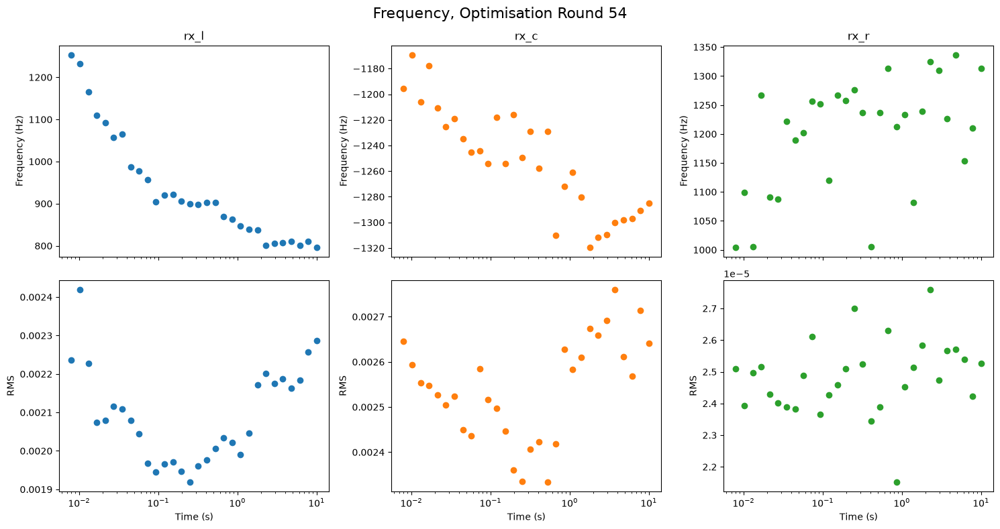

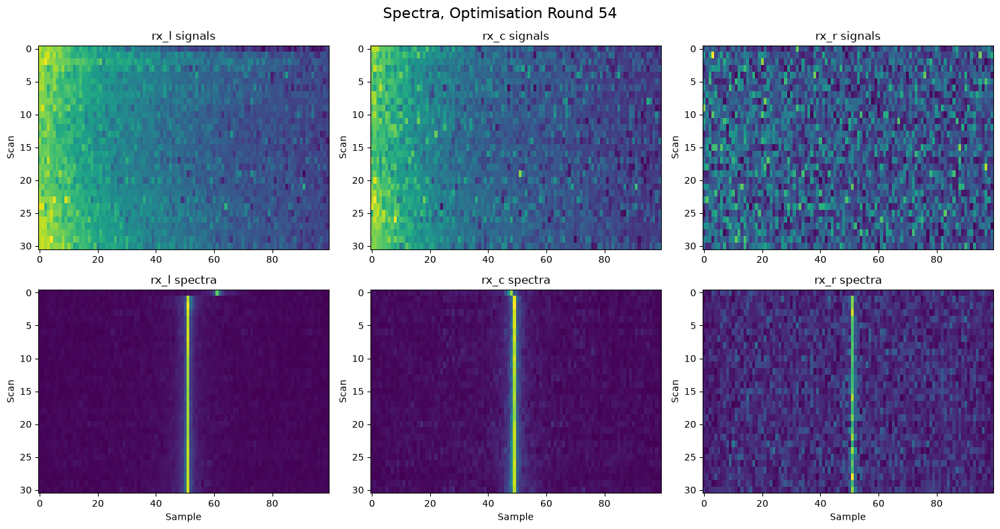

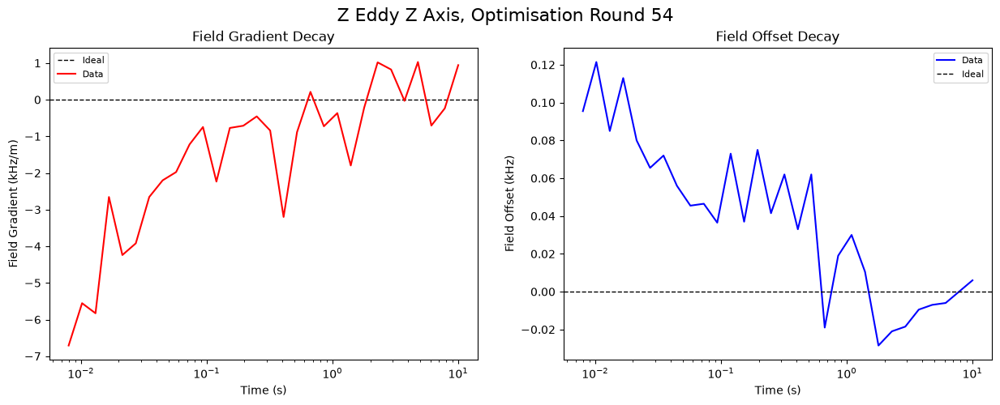

[I 2026-11-24 18:31:51,793] Trial 54 finished with value: 121.49372224631963 and parameters: {'Z_A1': -0.0008983380094935184, 'Z_A2': -0.0004254422932878487, 'Z_A3': -2.6041143155262998e-09, 'Z_A4': -6.137791306082027e-10}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.215e+02
Total cost = 1.215e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012854058758624822
B nanmax = 0.012854058758624822
B contains nan = False
Trial 55


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012647472623146576 !!!!!!!!!!!!!!!!


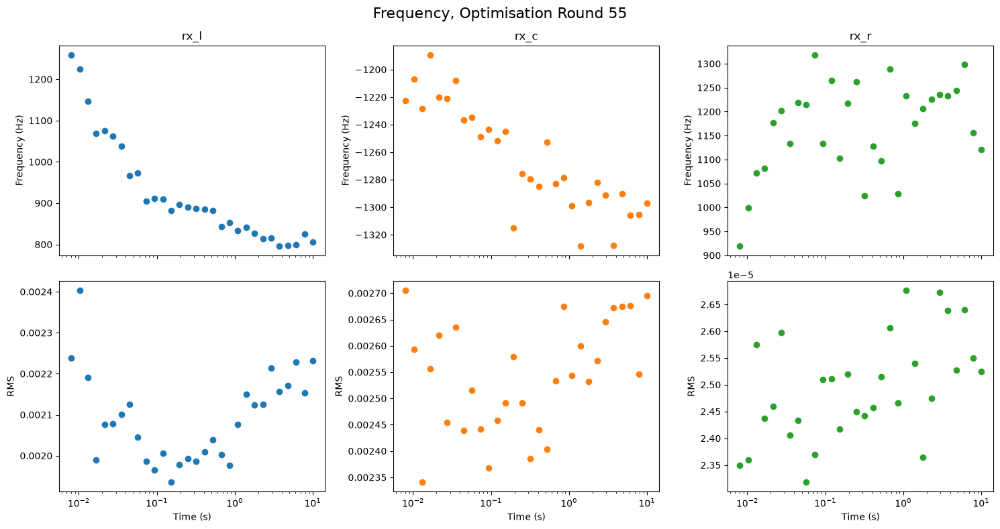

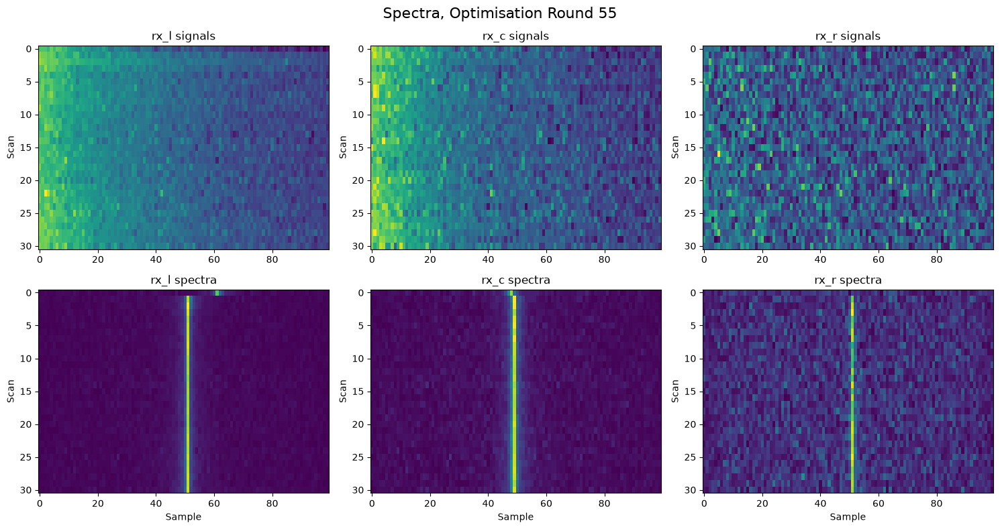

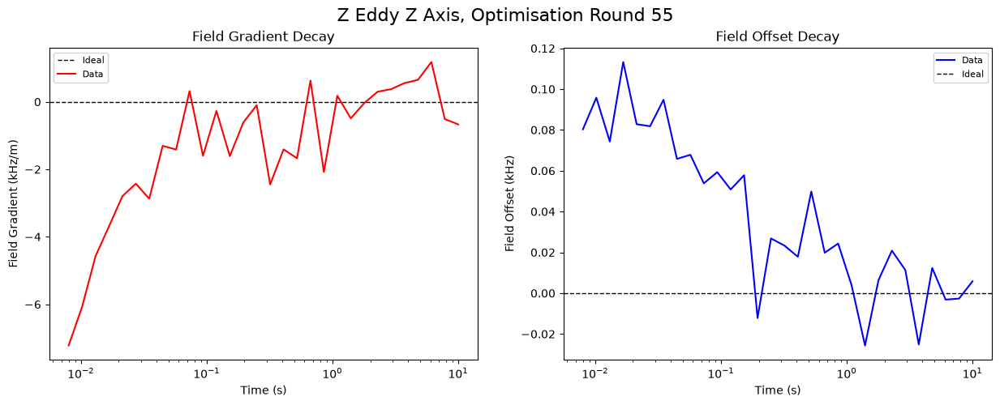

[I 2026-11-24 18:32:39,782] Trial 55 finished with value: 118.63689425283351 and parameters: {'Z_A1': -0.0009192518724290832, 'Z_A2': -0.00032162103440008626, 'Z_A3': -7.566462961740627e-09, 'Z_A4': -6.7792977501658725e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.186e+02
Total cost = 1.186e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013256797922021115
B nanmax = 0.013256797922021115
B contains nan = False
Trial 56


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013043738590693209 !!!!!!!!!!!!!!!!


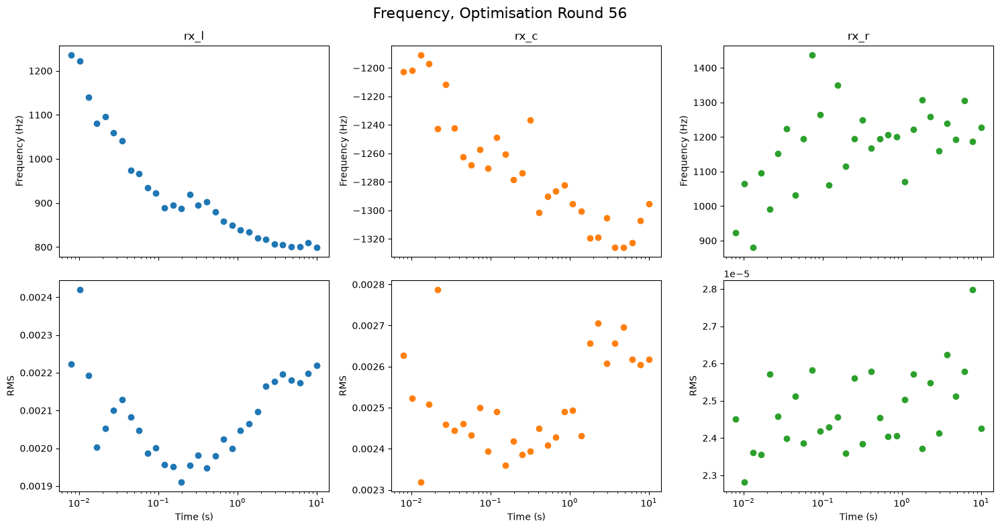

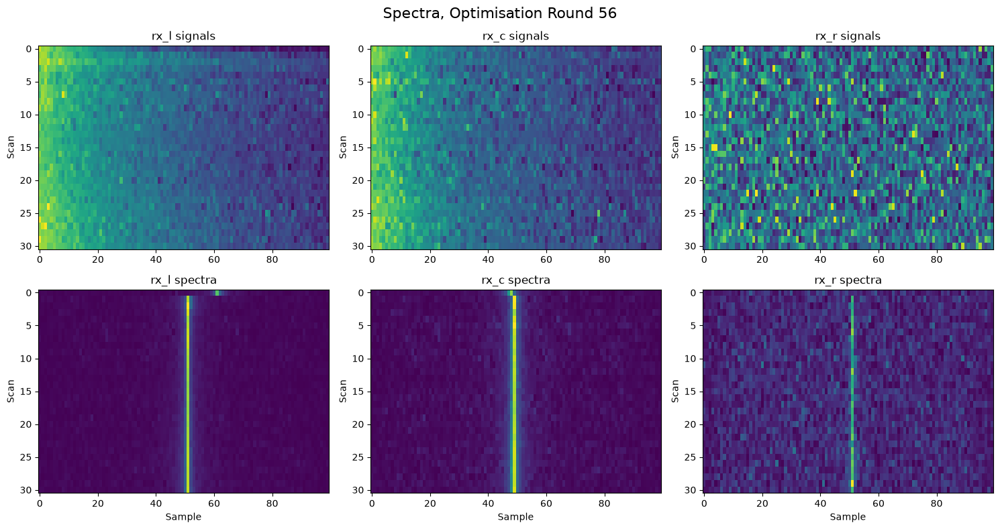

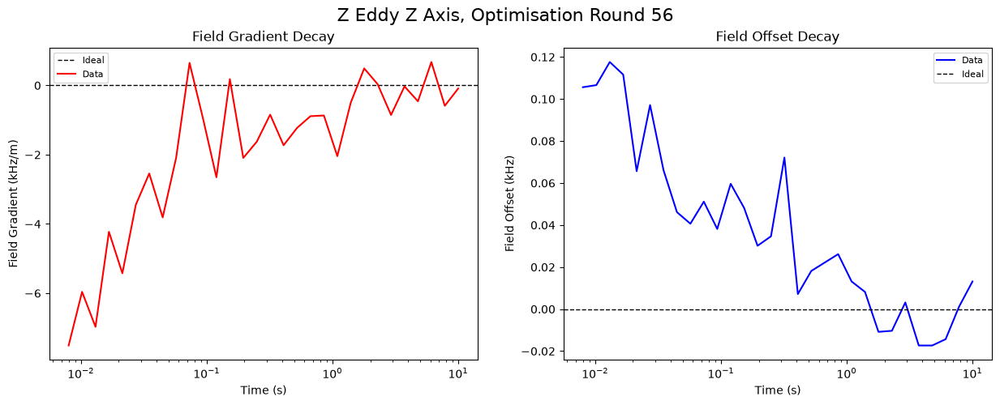

[I 2026-11-24 18:33:27,645] Trial 56 finished with value: 125.42040222497675 and parameters: {'Z_A1': -0.0009356937206031939, 'Z_A2': -0.00034392867002060754, 'Z_A3': -5.3522585039663445e-09, 'Z_A4': -8.1836682592756e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.254e+02
Total cost = 1.254e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014381861150723627
B nanmax = 0.014381861150723627
B contains nan = False
Trial 57


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014150722067624306 !!!!!!!!!!!!!!!!


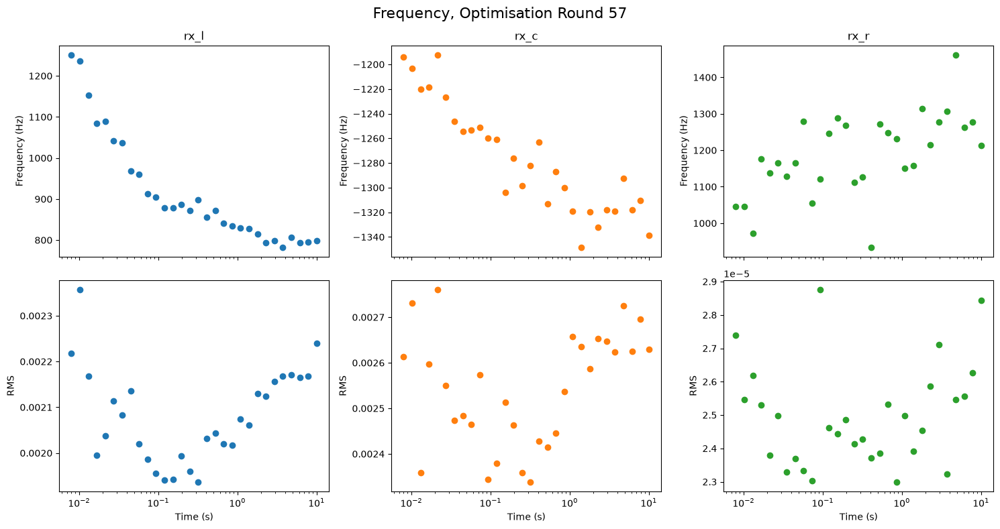

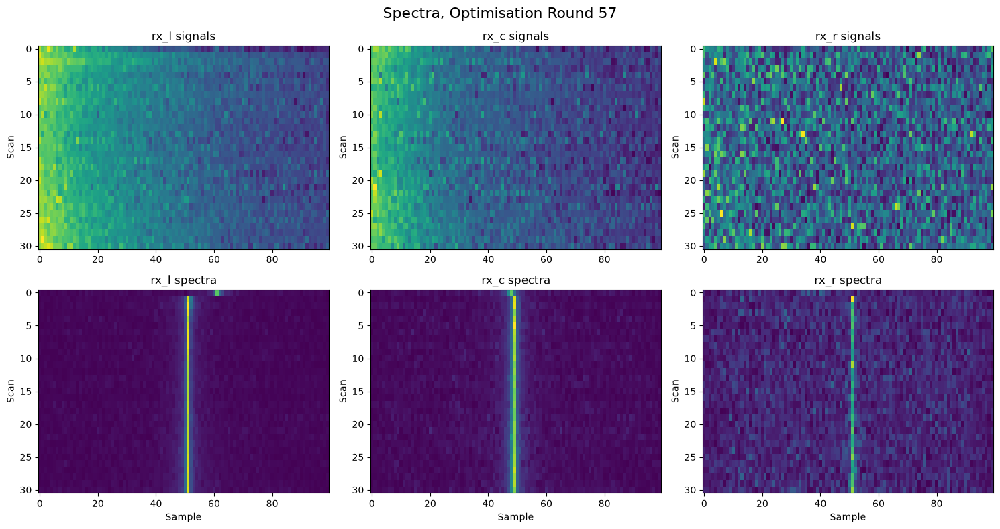

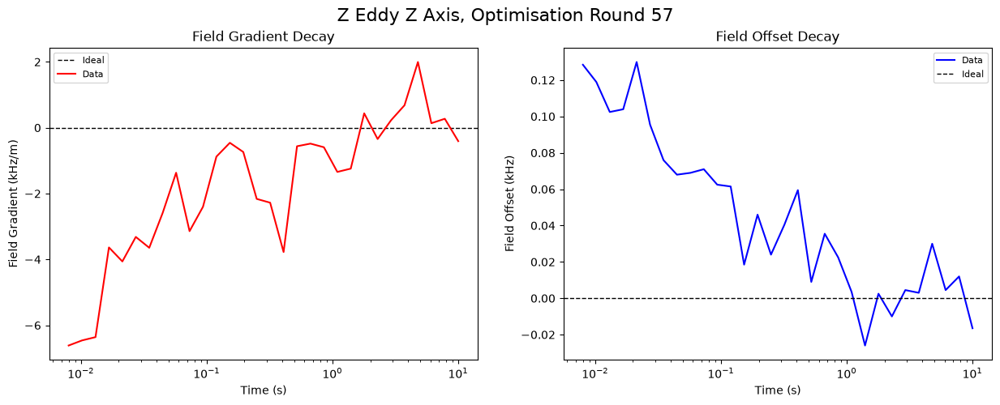

[I 2026-11-24 18:34:15,593] Trial 57 finished with value: 141.5718753249853 and parameters: {'Z_A1': -0.0010622193925257327, 'Z_A2': -0.00032649285990982364, 'Z_A3': -8.914701011730875e-09, 'Z_A4': -6.4591997593144906e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.416e+02
Total cost = 1.416e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014450086991387825
B nanmax = 0.014450086991387825
B contains nan = False
Trial 58


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014217848759568438 !!!!!!!!!!!!!!!!


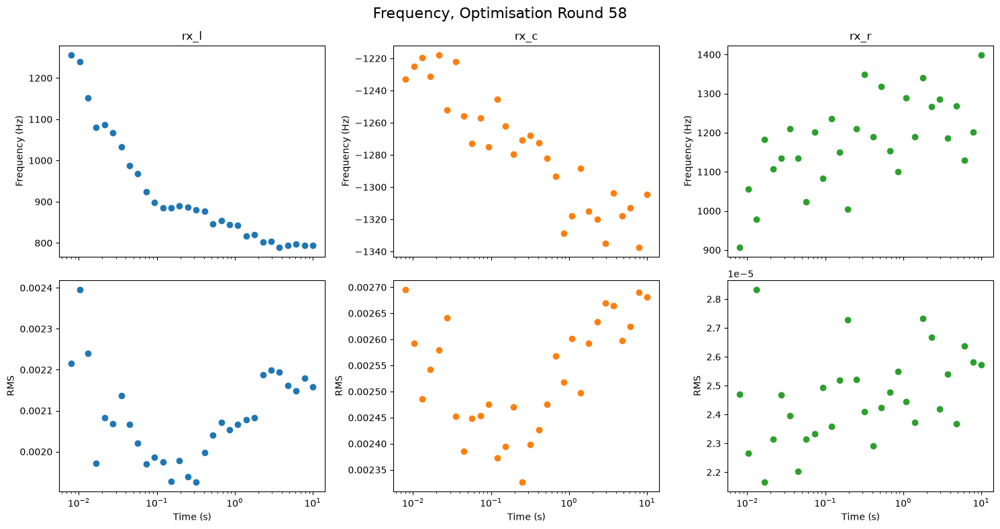

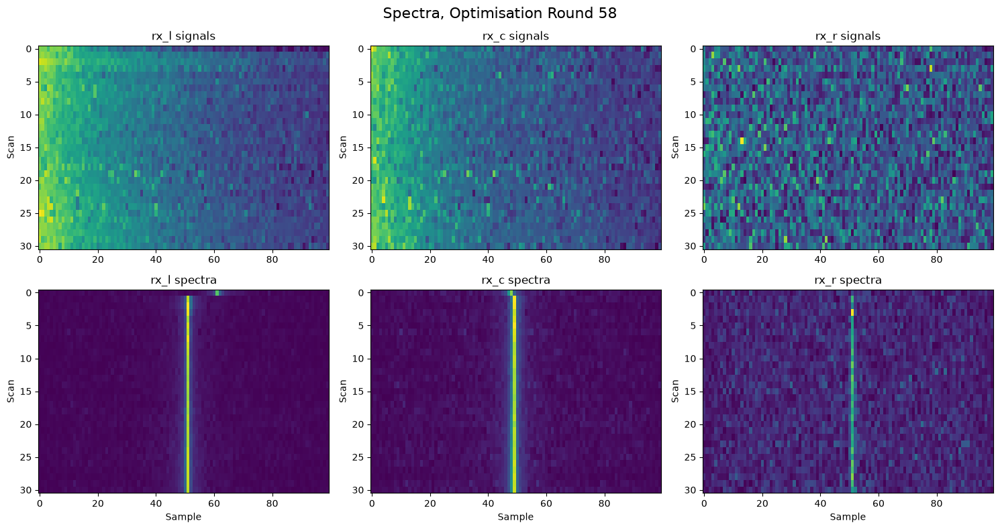

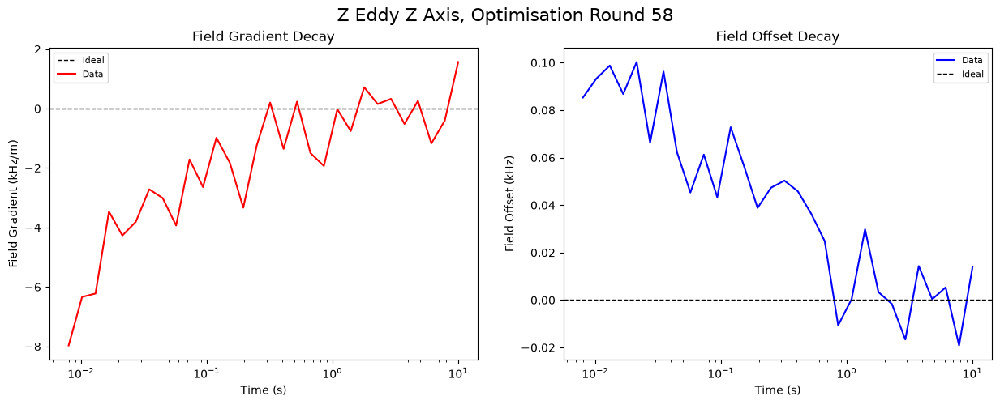

[I 2026-11-24 18:35:03,837] Trial 58 finished with value: 134.22690199446757 and parameters: {'Z_A1': -0.0010025524733605214, 'Z_A2': -0.0003920715940431115, 'Z_A3': -3.8668405357624875e-09, 'Z_A4': -4.901994053272187e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.342e+02
Total cost = 1.342e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01366159263117894
B nanmax = 0.01366159263117894
B contains nan = False
Trial 59


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013442021945091922 !!!!!!!!!!!!!!!!


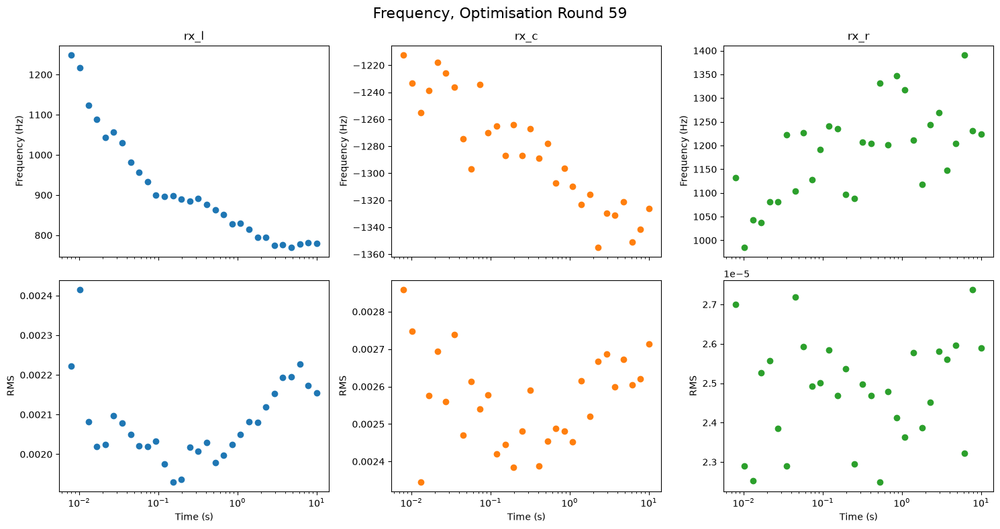

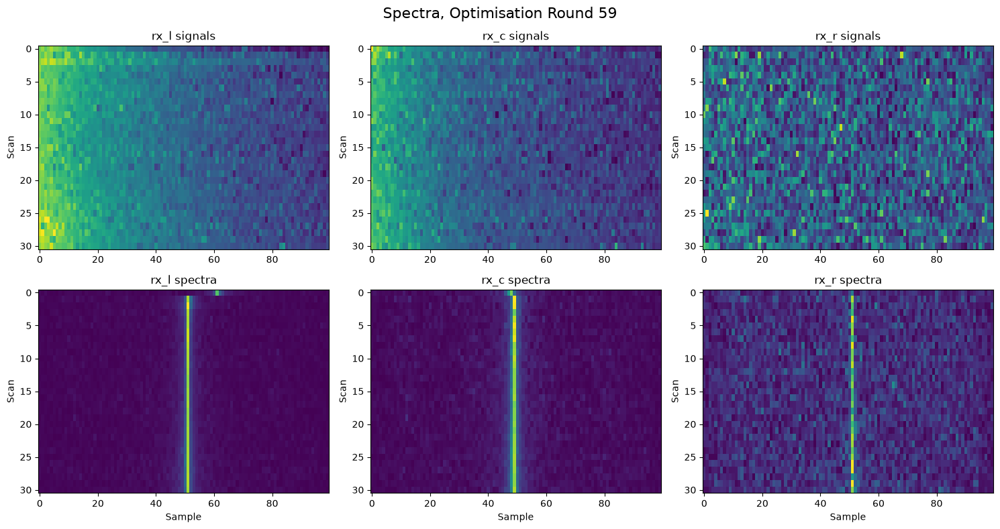

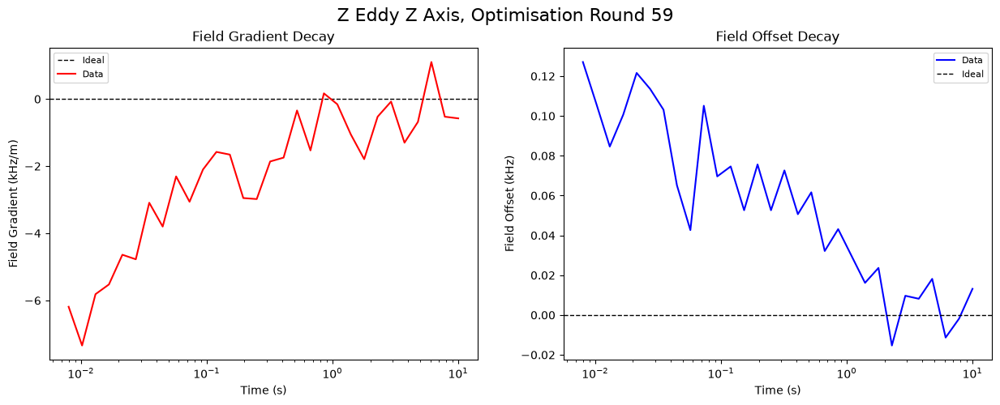

[I 2026-11-24 18:35:52,282] Trial 59 finished with value: 157.02231421634946 and parameters: {'Z_A1': -0.000827307597195646, 'Z_A2': -0.0004899569272464736, 'Z_A3': -5.0460728632290055e-09, 'Z_A4': 2.8460980782627806e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.570e+02
Total cost = 1.570e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01255331391438737
B nanmax = 0.01255331391438737
B contains nan = False
Trial 60


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01235156027493458 !!!!!!!!!!!!!!!!


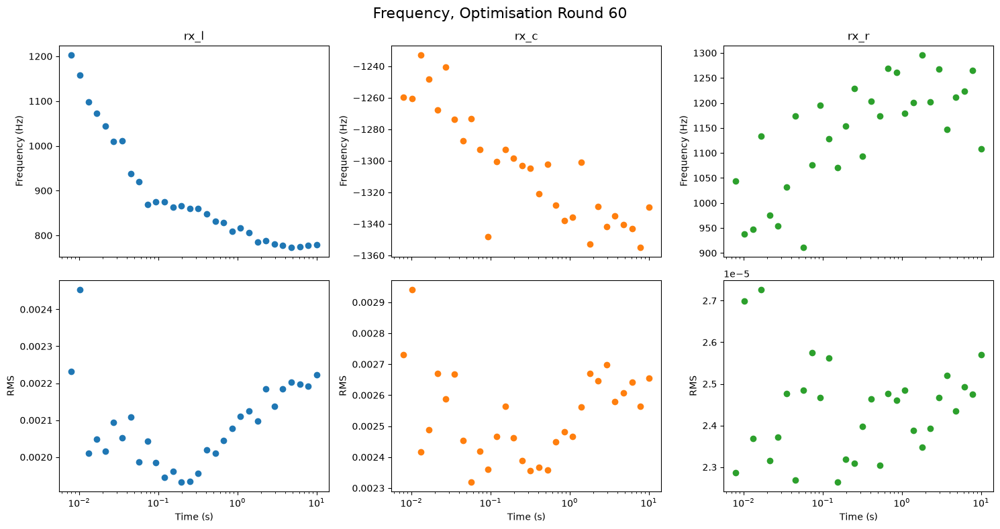

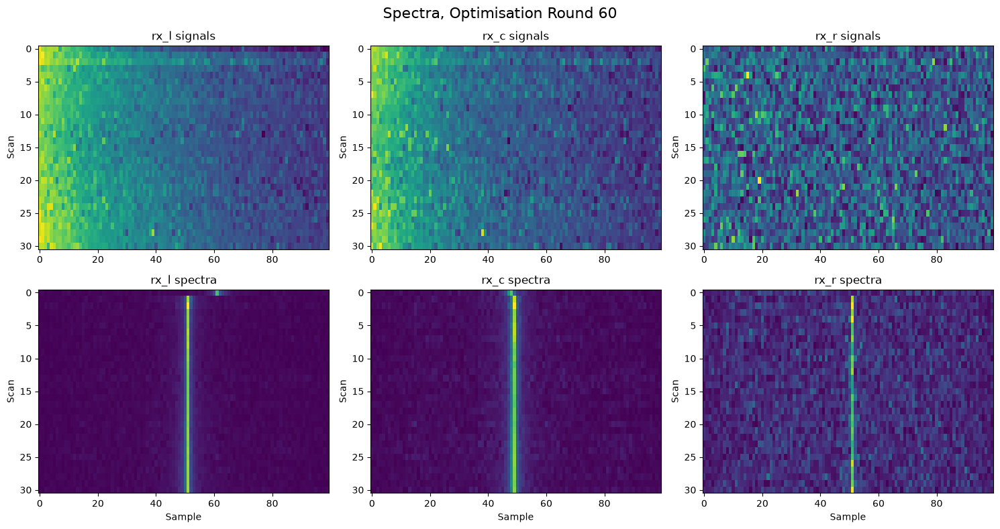

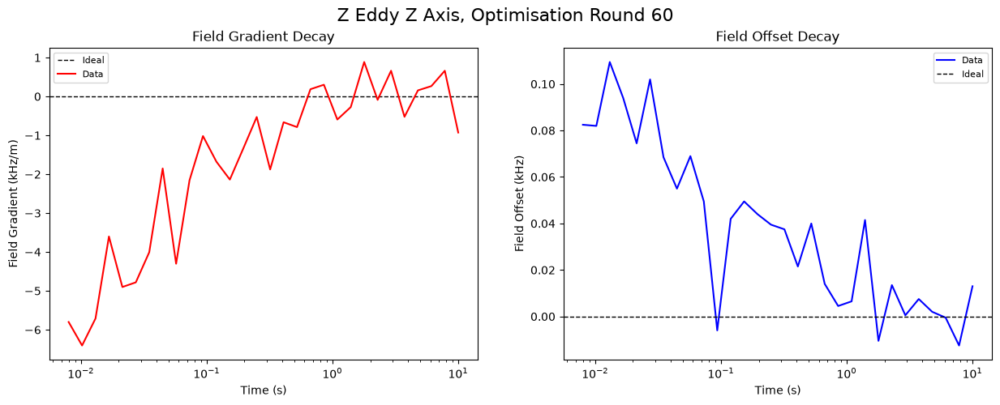

[I 2026-11-24 18:36:40,413] Trial 60 finished with value: 104.0976795806842 and parameters: {'Z_A1': -0.000873968927543058, 'Z_A2': -0.0003376230142692116, 'Z_A3': -6.899853612131633e-09, 'Z_A4': -4.452482825786612e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.041e+02
Total cost = 1.041e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012889757276501494
B nanmax = 0.012889757276501494
B contains nan = False
Trial 61


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012682593184721466 !!!!!!!!!!!!!!!!


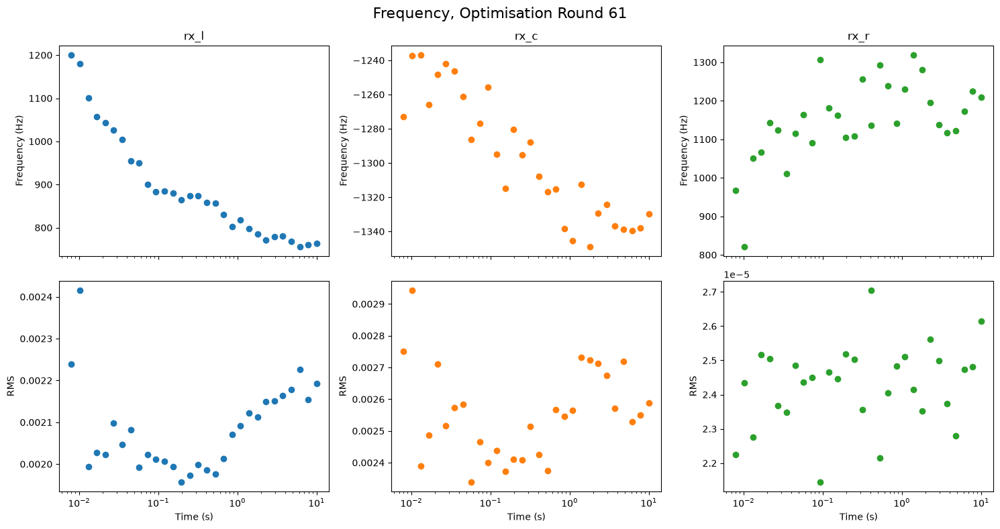

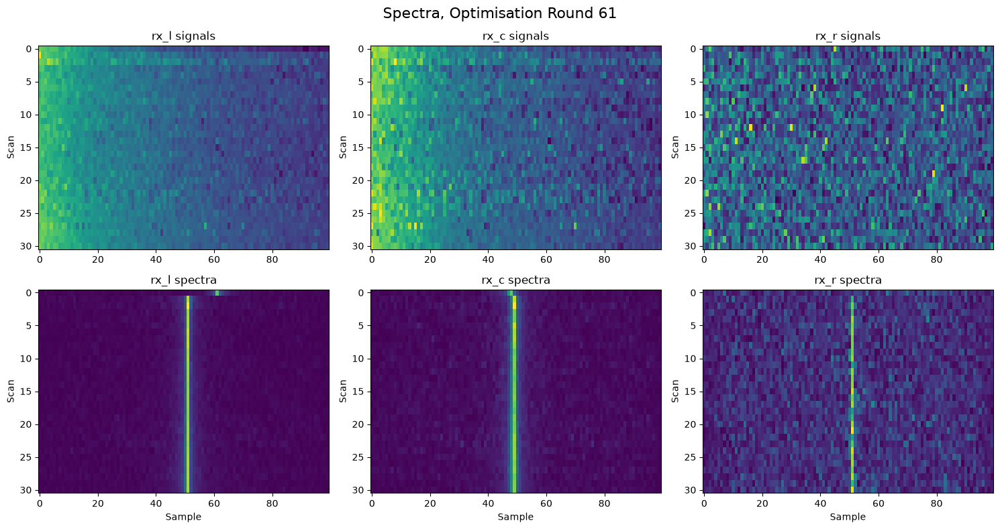

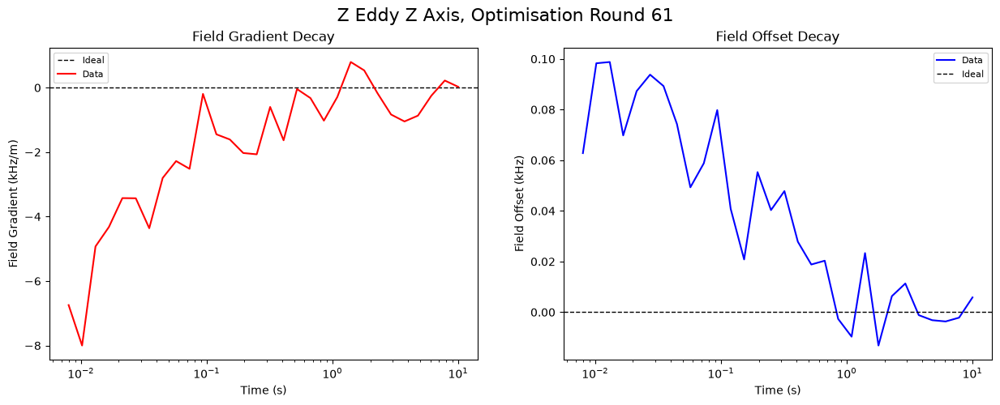

[I 2026-11-24 18:37:28,608] Trial 61 finished with value: 76.82869411248534 and parameters: {'Z_A1': -0.0008188153381623345, 'Z_A2': -0.00042442767170808386, 'Z_A3': -2.406646384415696e-09, 'Z_A4': -3.875993693060692e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 7.683e+01
Total cost = 7.683e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.0139725351246653
B nanmax = 0.0139725351246653
B contains nan = False
Trial 62


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013747970911316484 !!!!!!!!!!!!!!!!


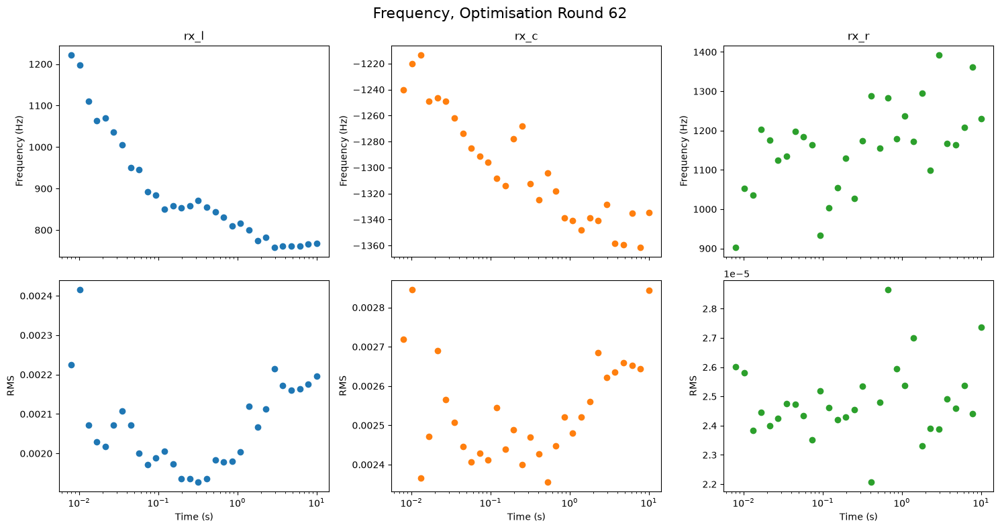

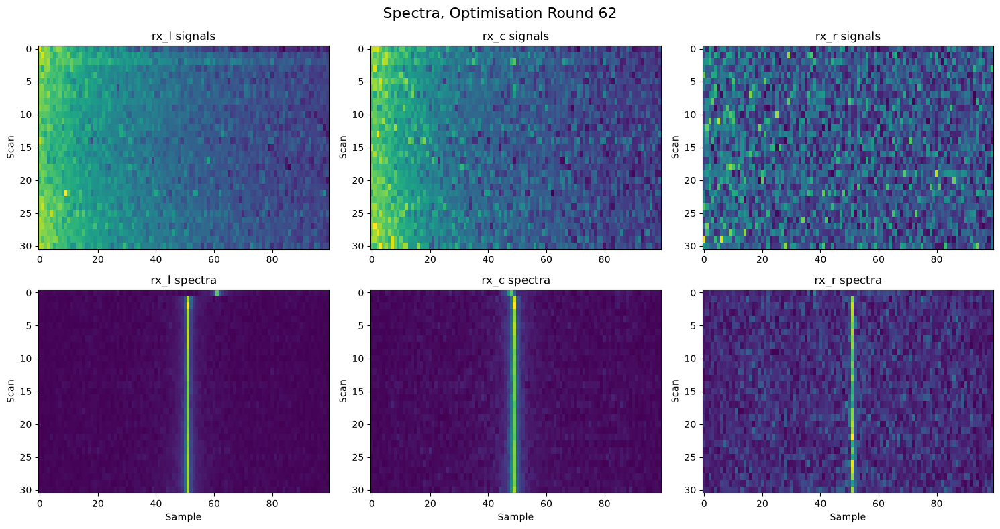

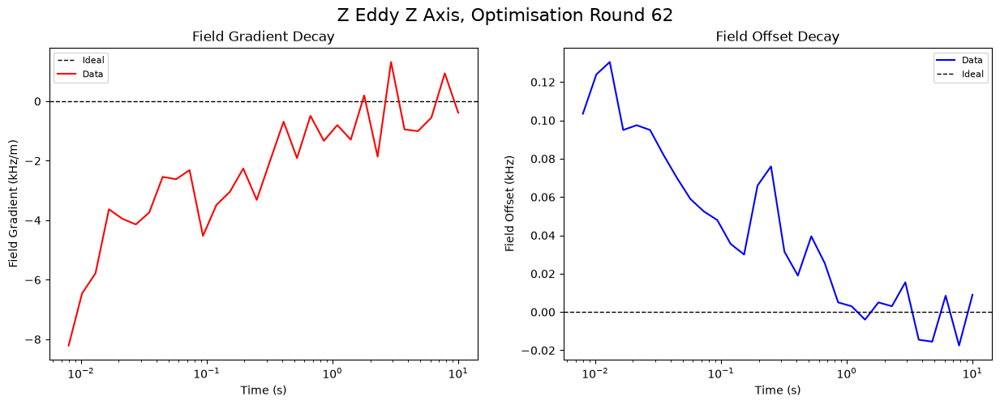

[I 2026-11-24 18:38:16,700] Trial 62 finished with value: 137.70519496876986 and parameters: {'Z_A1': -0.0009431391610811649, 'Z_A2': -0.00040512026084255103, 'Z_A3': 3.048321764836982e-10, 'Z_A4': -3.866390242848431e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.377e+02
Total cost = 1.377e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013981947392536059
B nanmax = 0.013981947392536059
B contains nan = False
Trial 63


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013757229966348521 !!!!!!!!!!!!!!!!


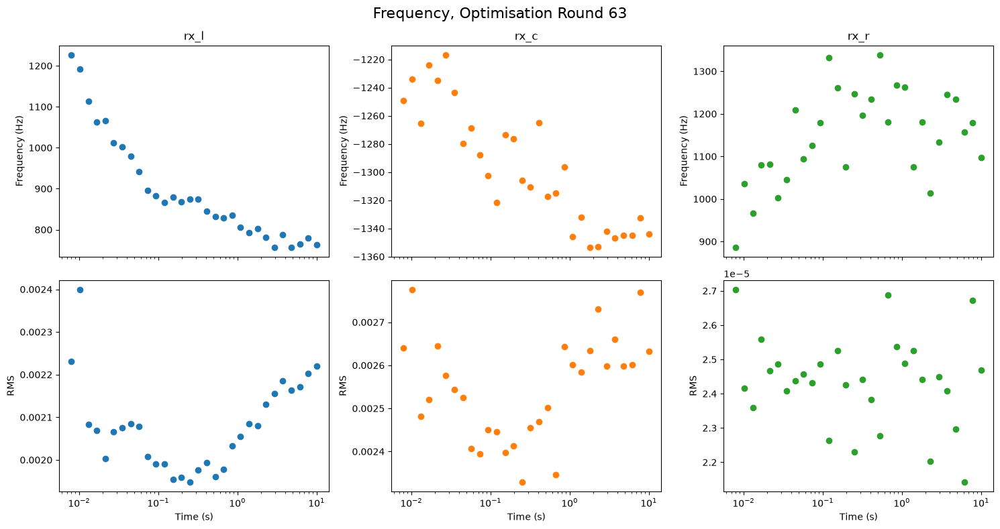

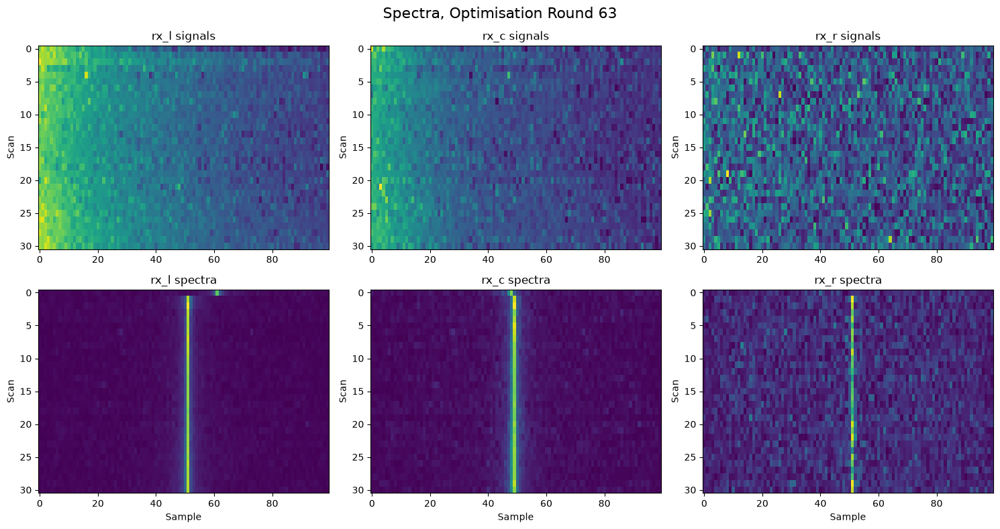

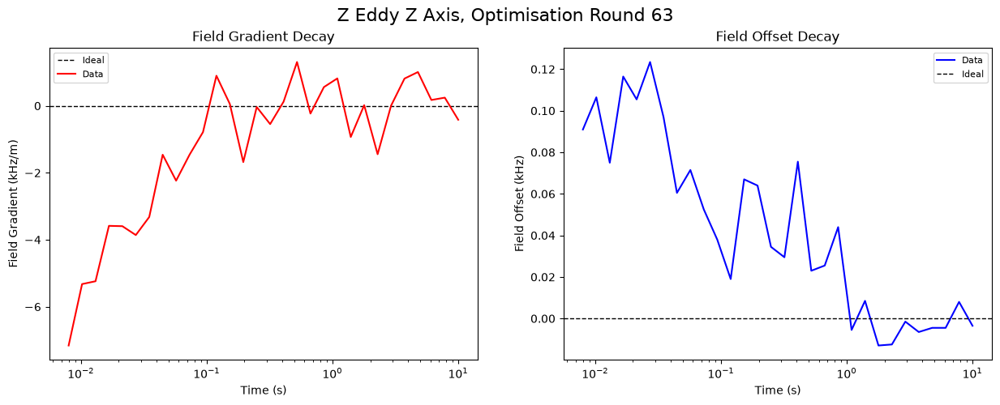

[I 2026-11-24 18:39:04,501] Trial 63 finished with value: 97.74769791981774 and parameters: {'Z_A1': -0.0008964357841993583, 'Z_A2': -0.0004522372491728597, 'Z_A3': -2.103784951030214e-09, 'Z_A4': -3.320775757350739e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 9.775e+01
Total cost = 9.775e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013473721176601613
B nanmax = 0.013473721176601613
B contains nan = False
Trial 64


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0132571718834036 !!!!!!!!!!!!!!!!


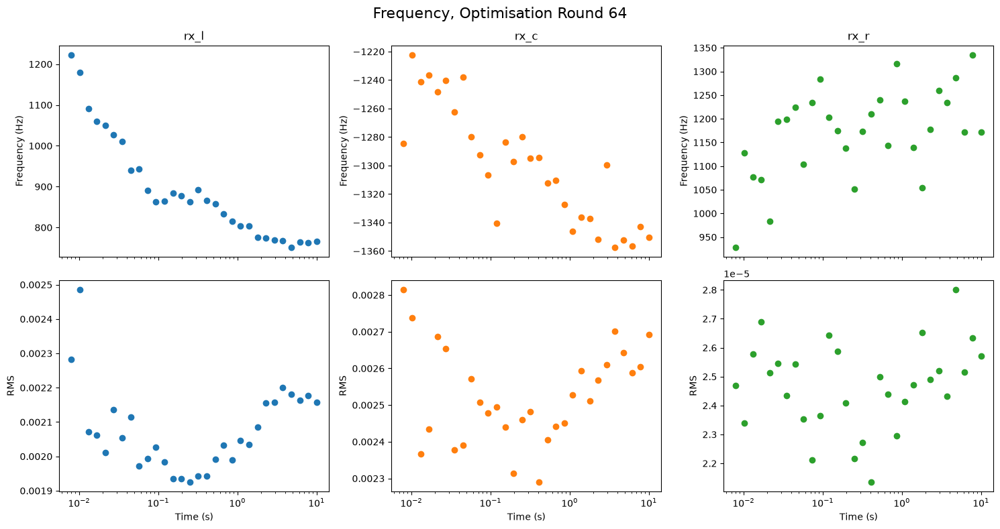

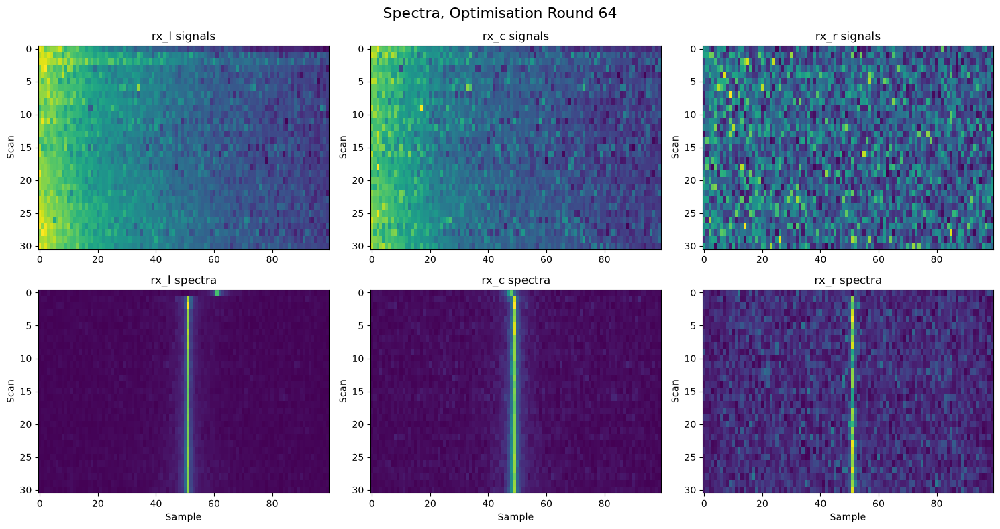

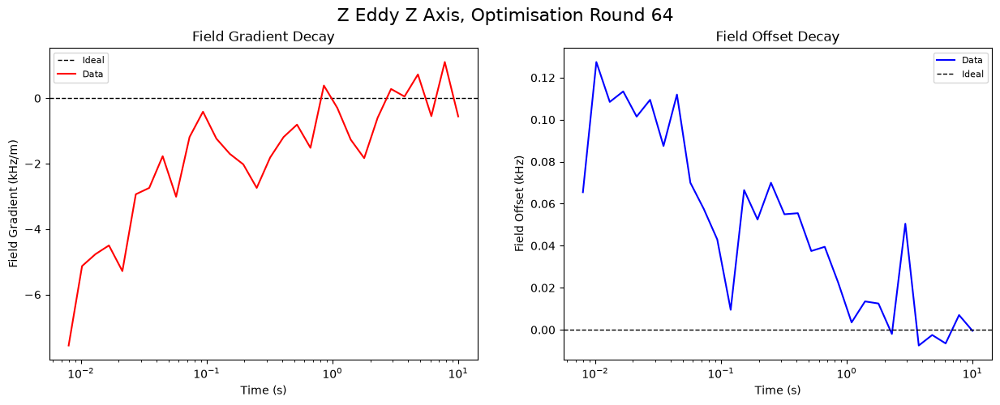

[I 2026-11-24 18:39:52,673] Trial 64 finished with value: 126.3738974109927 and parameters: {'Z_A1': -0.0008623135956379723, 'Z_A2': -0.0004373207996529345, 'Z_A3': -3.8180576329784585e-09, 'Z_A4': -5.6545370897776835e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.264e+02
Total cost = 1.264e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012345420405636217
B nanmax = 0.012345420405636217
B contains nan = False
Trial 65


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01214700542031604 !!!!!!!!!!!!!!!!


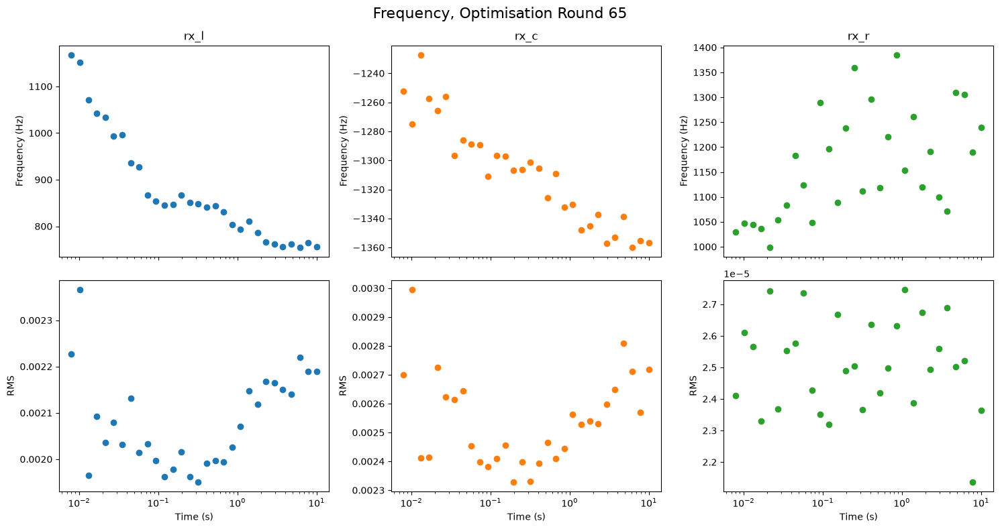

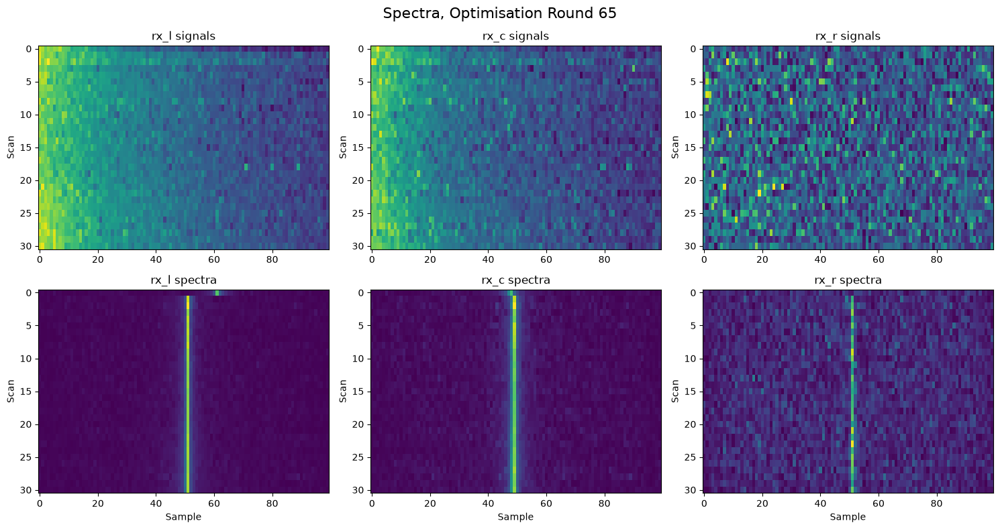

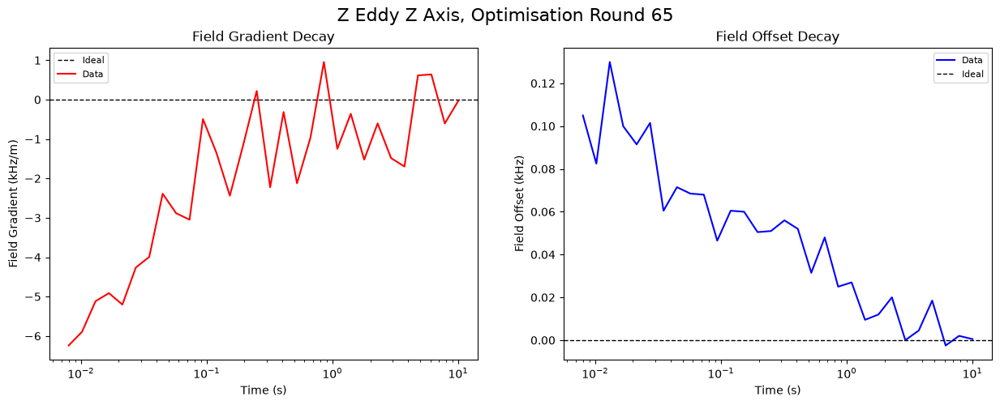

[I 2026-11-24 18:40:40,750] Trial 65 finished with value: 105.41020209400573 and parameters: {'Z_A1': -0.0007971162870605544, 'Z_A2': -0.00039375890841824316, 'Z_A3': -4.154176746579052e-09, 'Z_A4': -6.7860488761749544e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.054e+02
Total cost = 1.054e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012291466880328762
B nanmax = 0.012291466880328762
B contains nan = False
Trial 66


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012093918576892838 !!!!!!!!!!!!!!!!


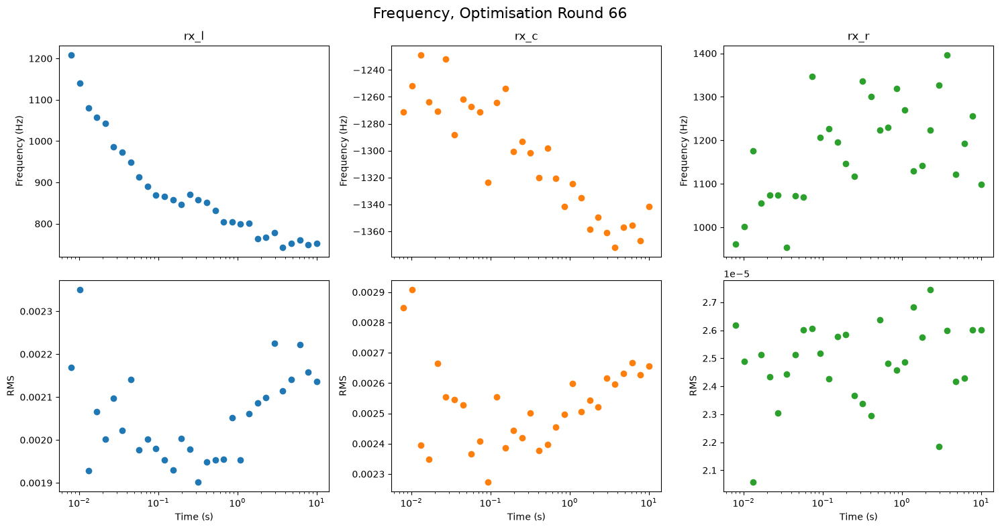

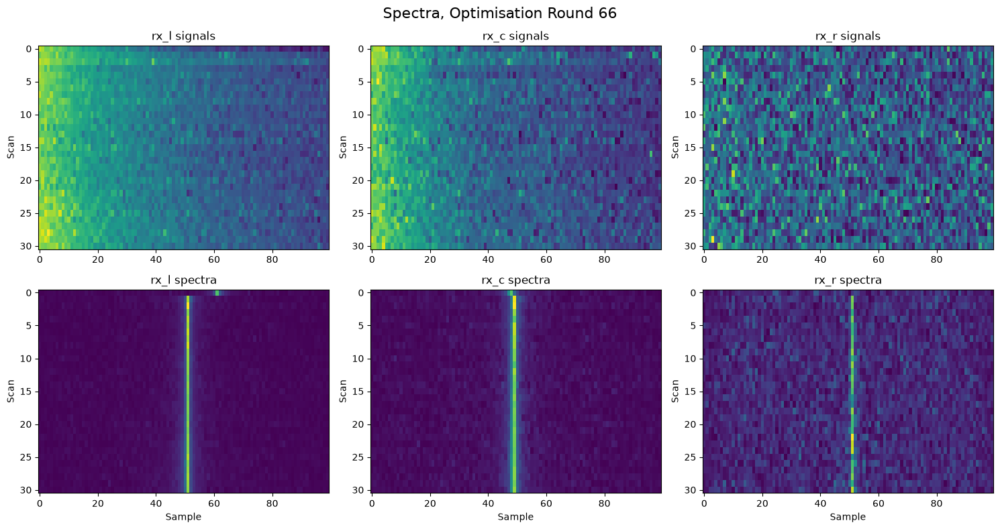

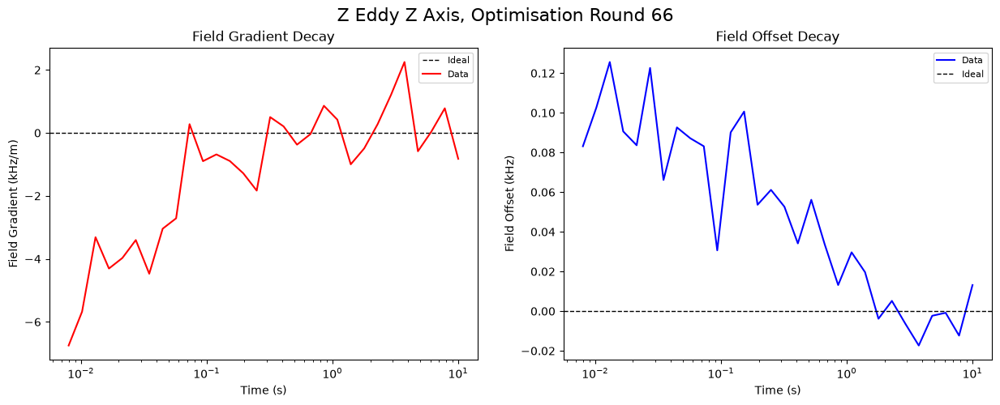

[I 2026-11-24 18:41:28,866] Trial 66 finished with value: 126.24436893066283 and parameters: {'Z_A1': -0.0007824960120992121, 'Z_A2': -0.0004030583099077036, 'Z_A3': -1.0608320771392156e-09, 'Z_A4': -1.7926462608726688e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.262e+02
Total cost = 1.262e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013237566468066814
B nanmax = 0.013237566468066814
B contains nan = False
Trial 67


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013024814298089948 !!!!!!!!!!!!!!!!


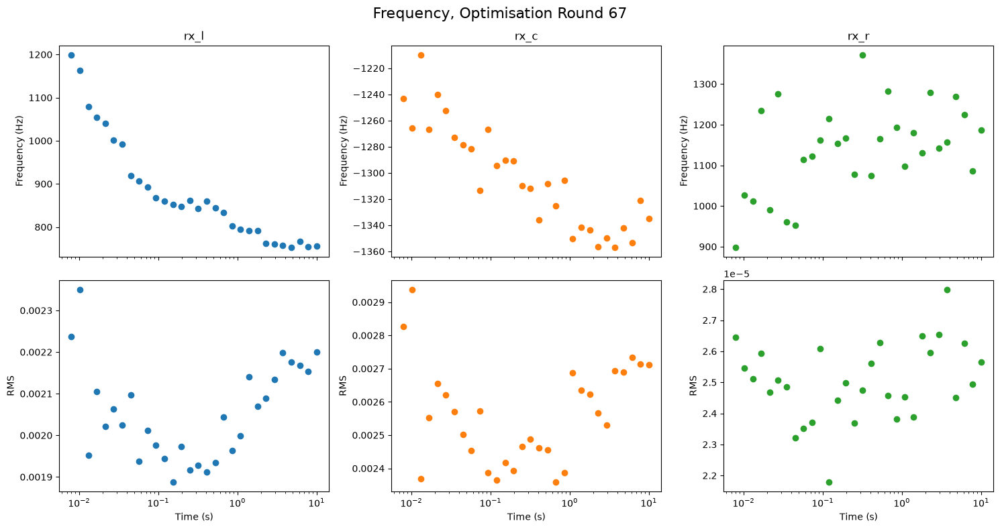

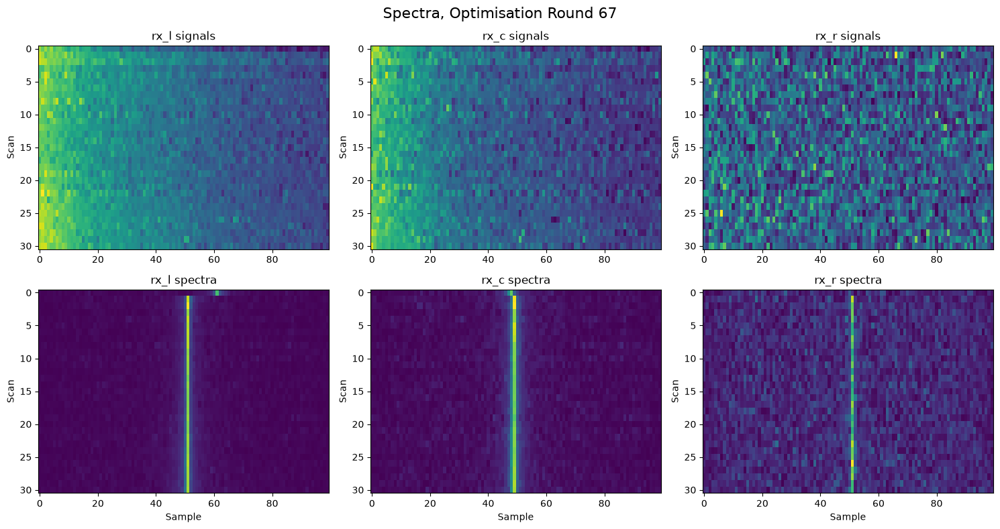

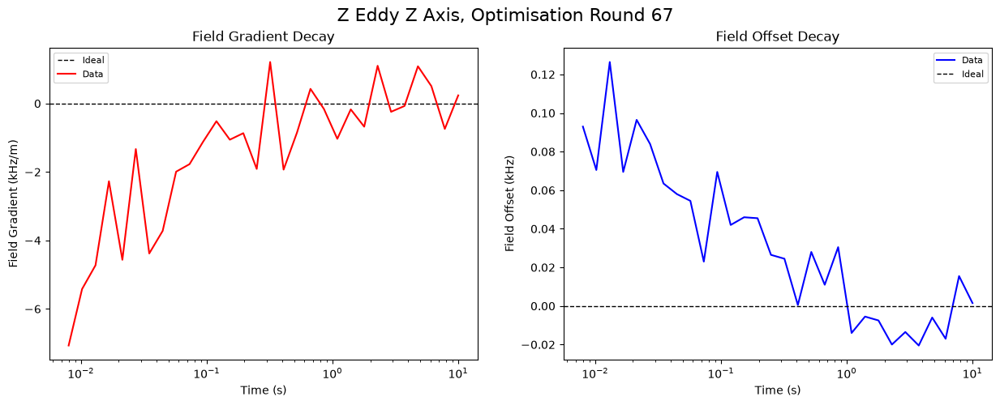

[I 2026-11-24 18:42:17,010] Trial 67 finished with value: 140.73514498096858 and parameters: {'Z_A1': -0.0008874753722689679, 'Z_A2': -0.00038980106787032774, 'Z_A3': -1.3815046172054784e-09, 'Z_A4': -4.855908928502324e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.407e+02
Total cost = 1.407e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014110279270577753
B nanmax = 0.014110279270577753
B contains nan = False
Trial 68


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013883502321229847 !!!!!!!!!!!!!!!!


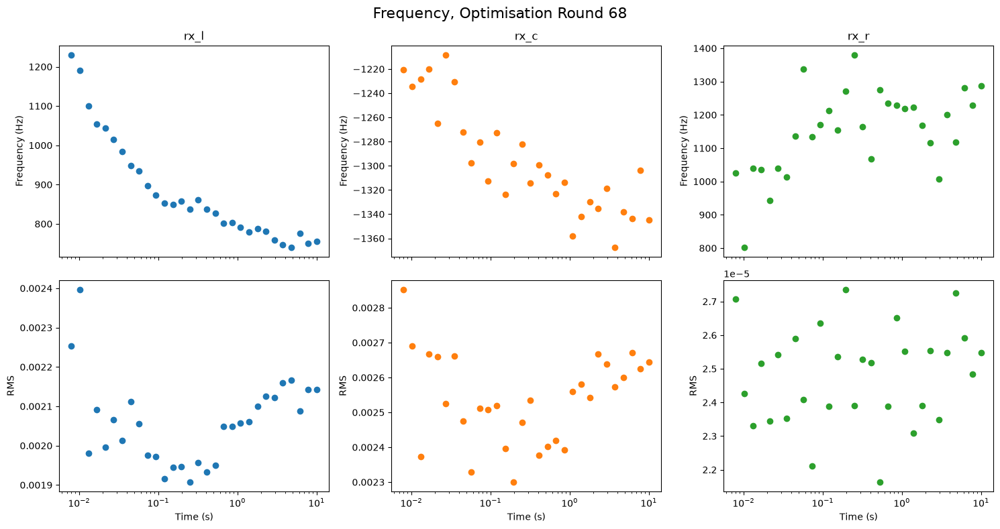

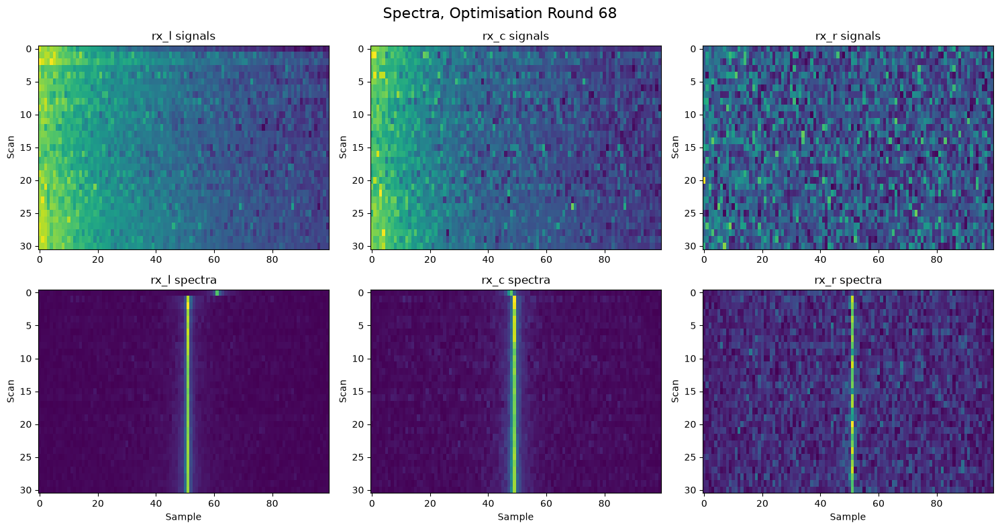

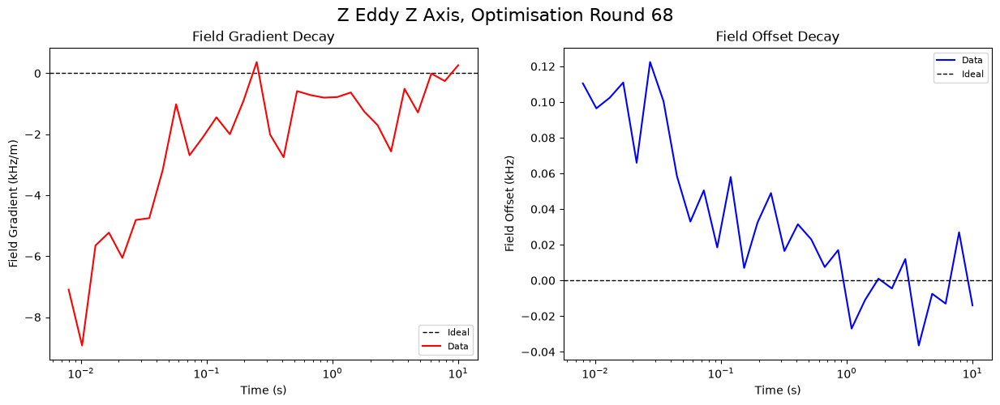

[I 2026-11-24 18:43:05,230] Trial 68 finished with value: 177.6973334690671 and parameters: {'Z_A1': -0.0009784067939064955, 'Z_A2': -0.0003834153922415885, 'Z_A3': -6.4995220827992525e-09, 'Z_A4': -6.977871969046927e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.777e+02
Total cost = 1.777e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012993471841470353
B nanmax = 0.012993471841470353
B contains nan = False
Trial 69


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012784639414867589 !!!!!!!!!!!!!!!!


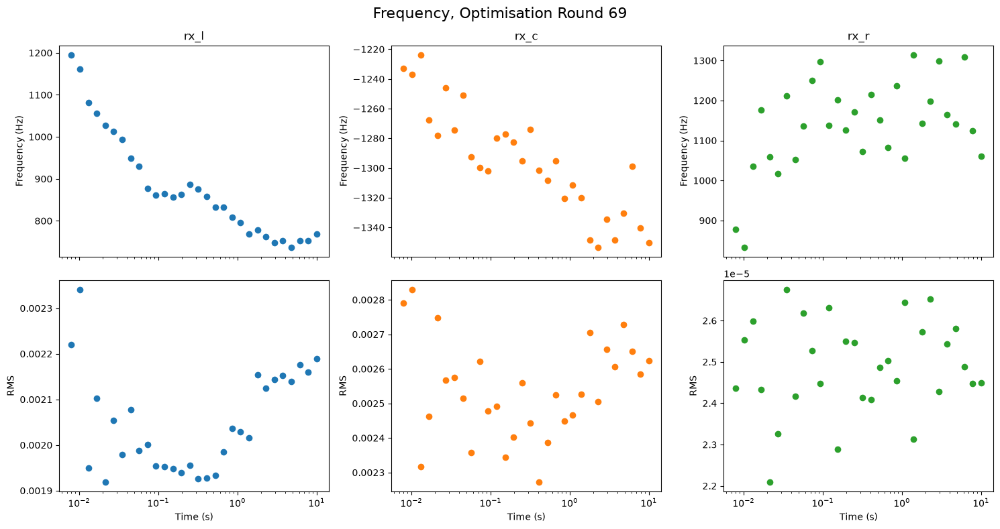

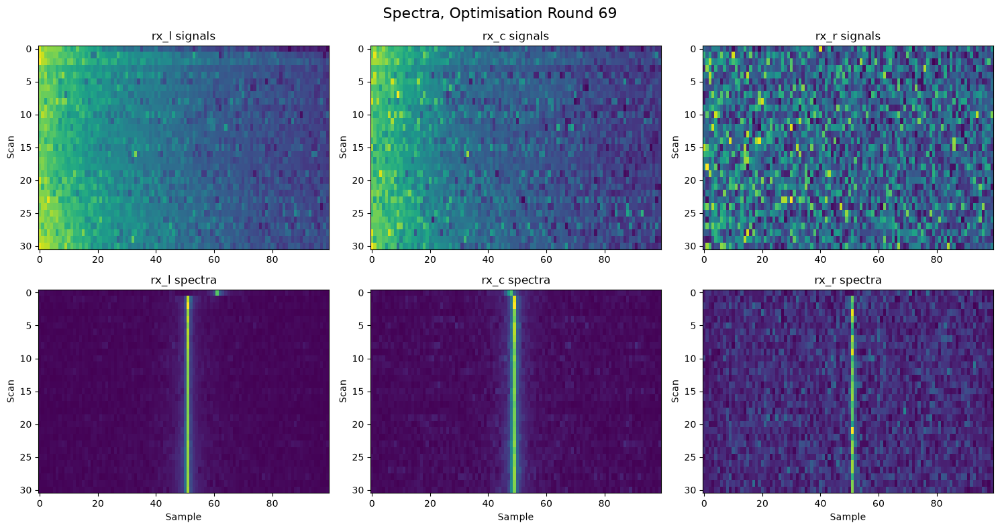

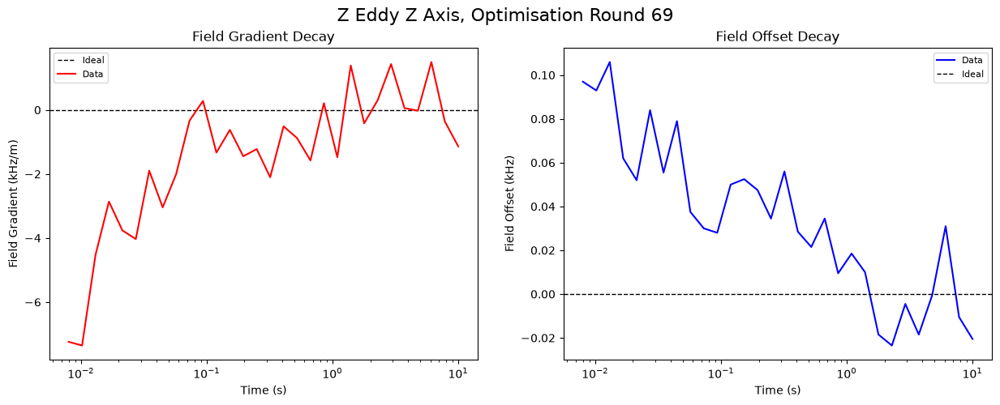

[I 2026-11-24 18:43:53,586] Trial 69 finished with value: 171.55107447731467 and parameters: {'Z_A1': -0.0007903952989093399, 'Z_A2': -0.0004624854084921565, 'Z_A3': -3.090338236273322e-09, 'Z_A4': -3.909691250742239e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.716e+02
Total cost = 1.716e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012881741235393247
B nanmax = 0.012881741235393247
B contains nan = False
Trial 70


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012674707343261465 !!!!!!!!!!!!!!!!


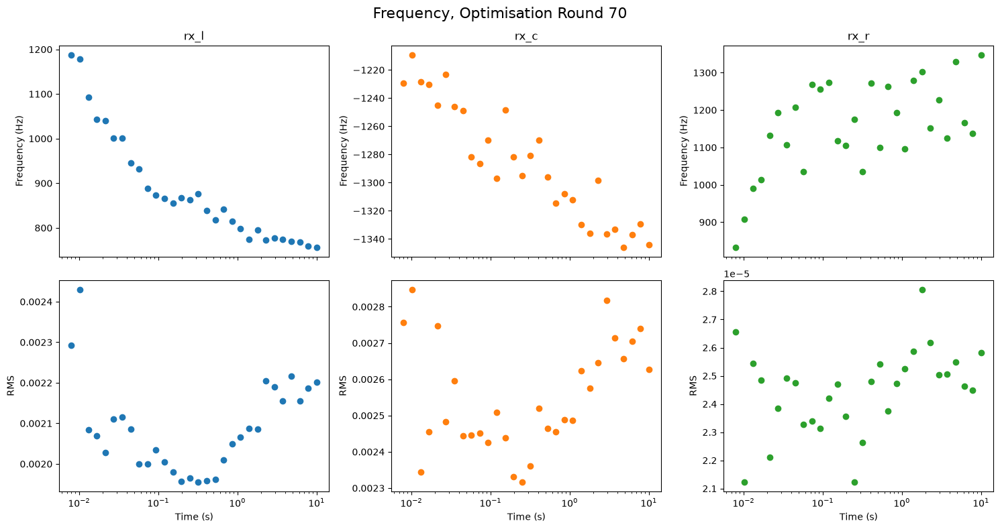

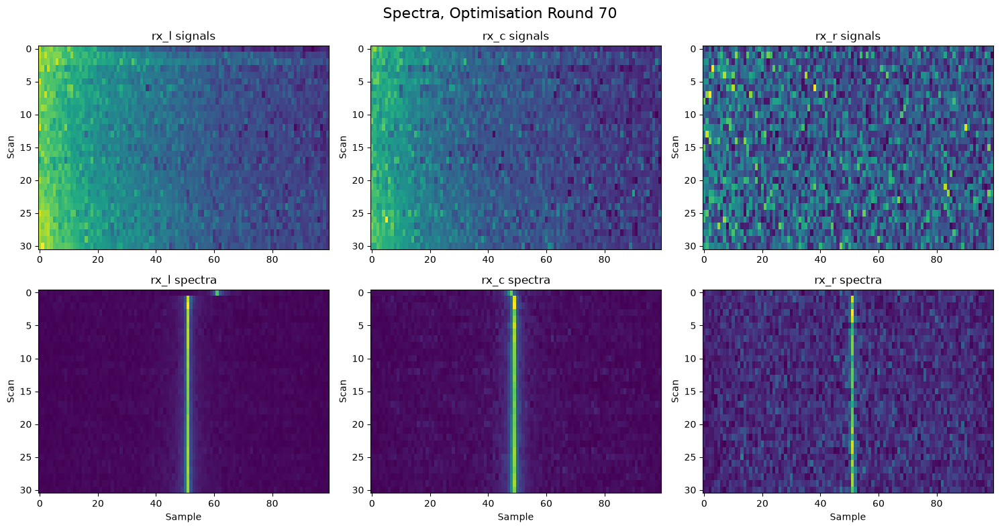

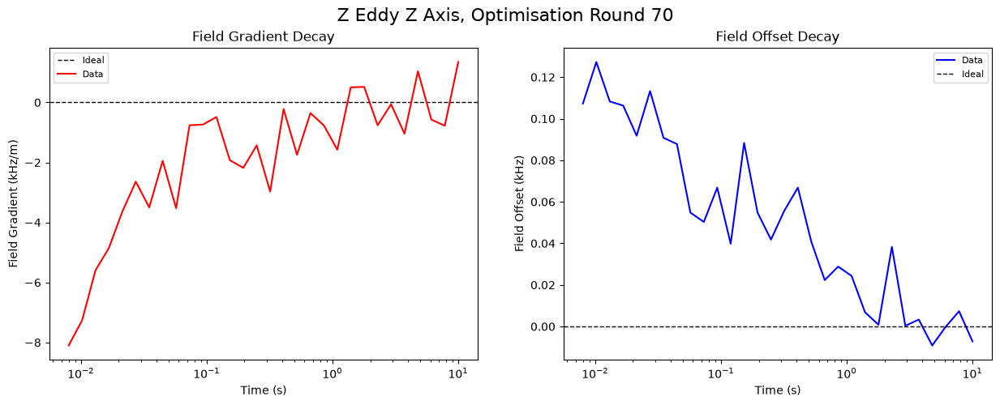

[I 2026-11-24 18:44:41,785] Trial 70 finished with value: 111.28097744134499 and parameters: {'Z_A1': -0.0008516277116239329, 'Z_A2': -0.0003911902908049236, 'Z_A3': -1.6459916906382899e-09, 'Z_A4': -2.432352822175949e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.113e+02
Total cost = 1.113e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014045311720745437
B nanmax = 0.014045311720745437
B contains nan = False
Trial 71


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.0138195789192254 !!!!!!!!!!!!!!!!


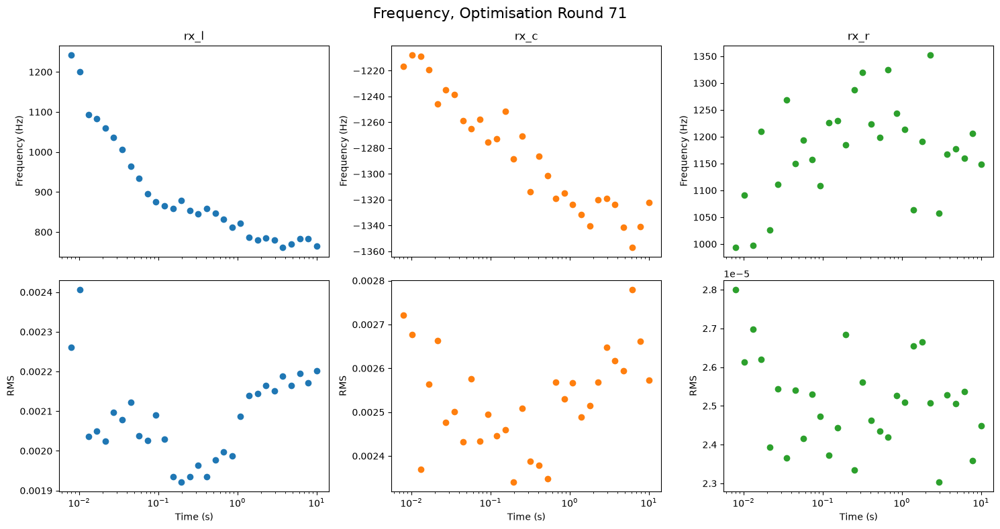

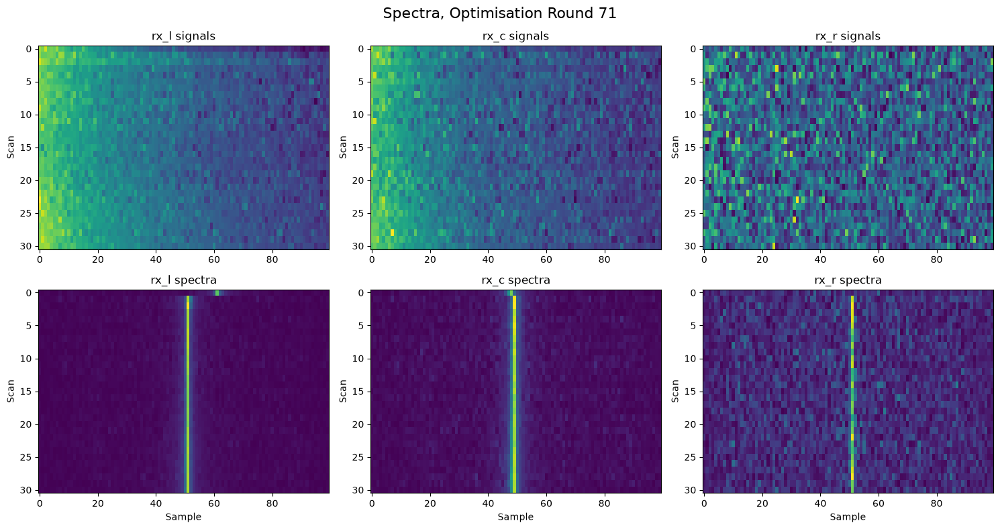

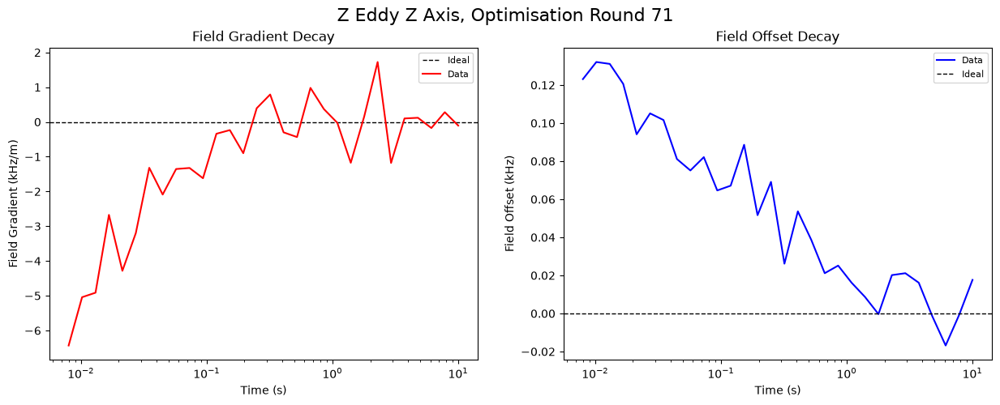

[I 2026-11-24 18:45:29,836] Trial 71 finished with value: 139.40563128275573 and parameters: {'Z_A1': -0.0009740310821737416, 'Z_A2': -0.0003815222548407686, 'Z_A3': -2.345533105725125e-09, 'Z_A4': -3.822920616637602e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.394e+02
Total cost = 1.394e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01308946895408781
B nanmax = 0.01308946895408781
B contains nan = False
Trial 72


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012879096050940224 !!!!!!!!!!!!!!!!


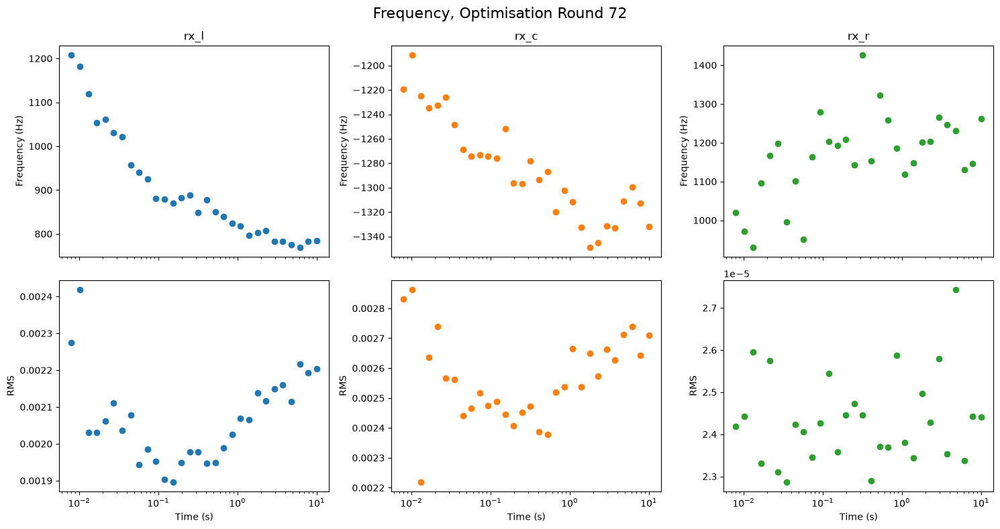

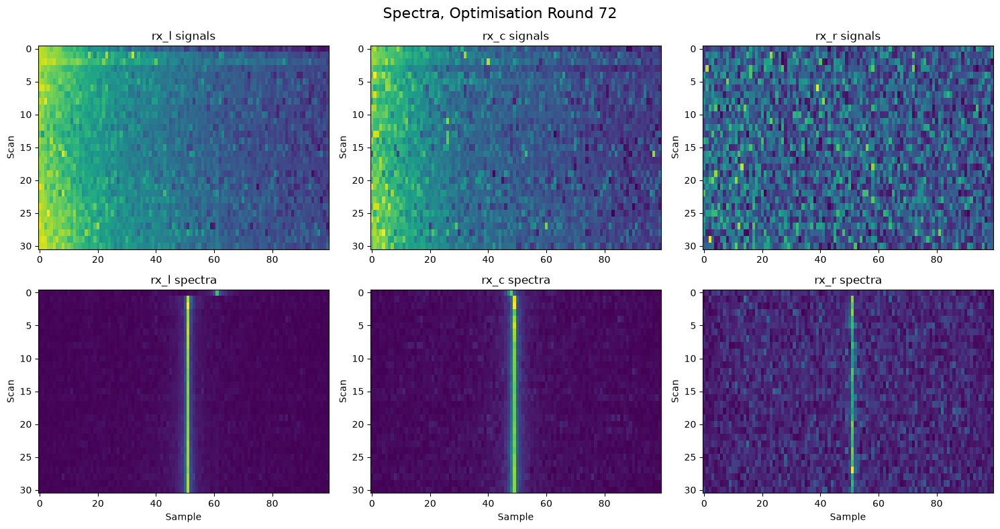

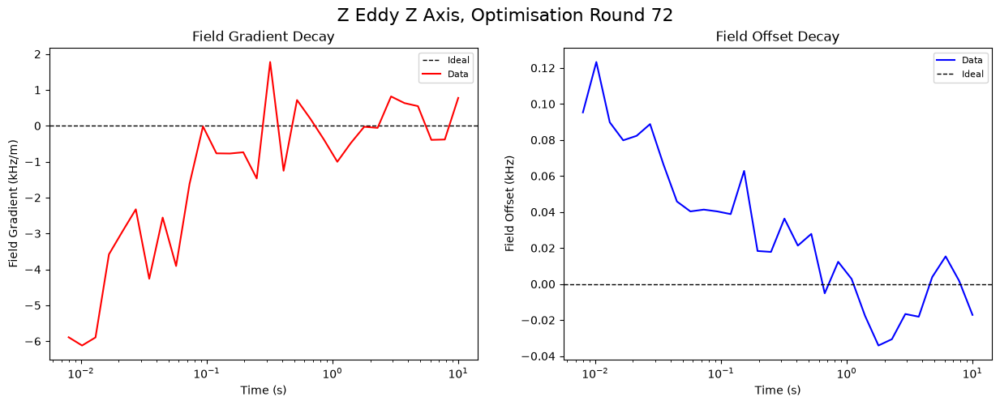

[I 2026-11-24 18:46:17,857] Trial 72 finished with value: 141.646613684939 and parameters: {'Z_A1': -0.0008547597338309494, 'Z_A2': -0.00040798887486746815, 'Z_A3': -2.9250571635764266e-09, 'Z_A4': -3.711190333252311e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.416e+02
Total cost = 1.416e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013198167559437665
B nanmax = 0.013198167559437665
B contains nan = False
Trial 73


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012986048063102199 !!!!!!!!!!!!!!!!


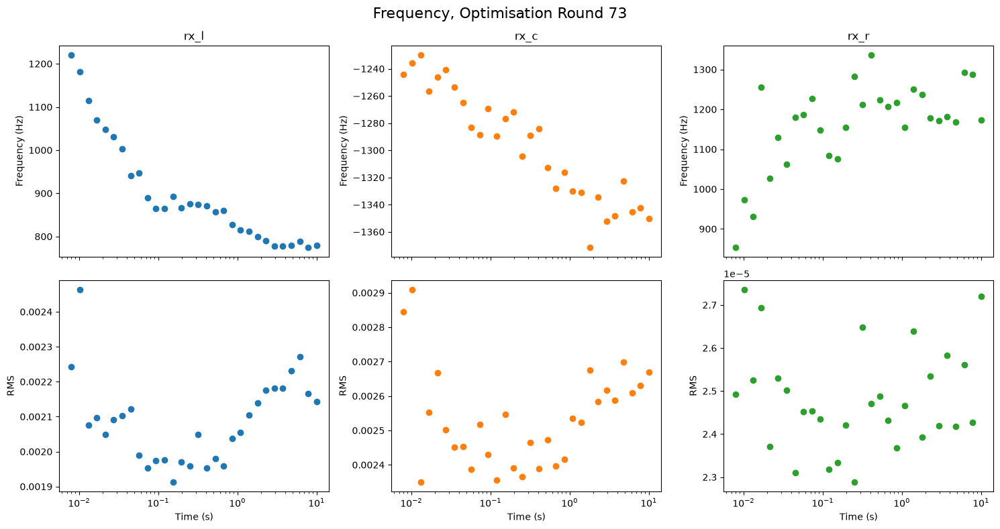

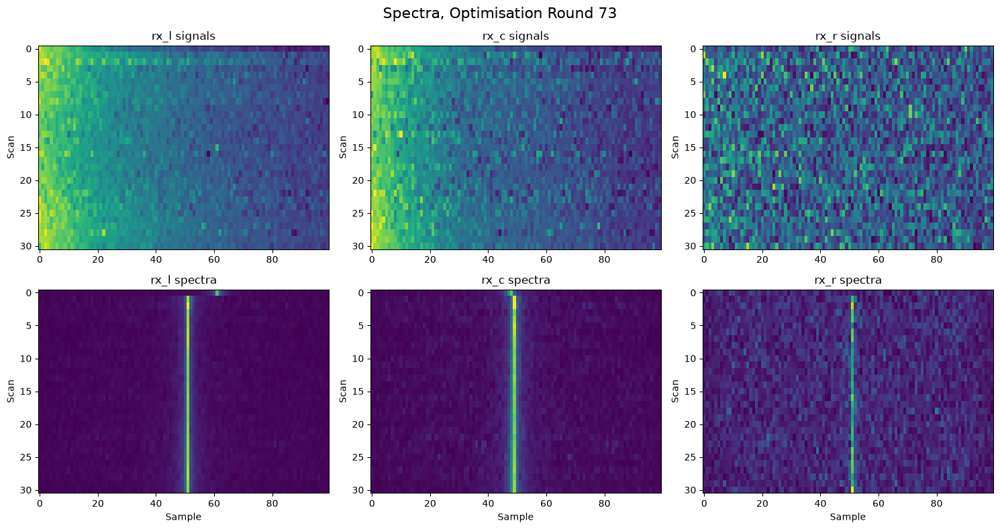

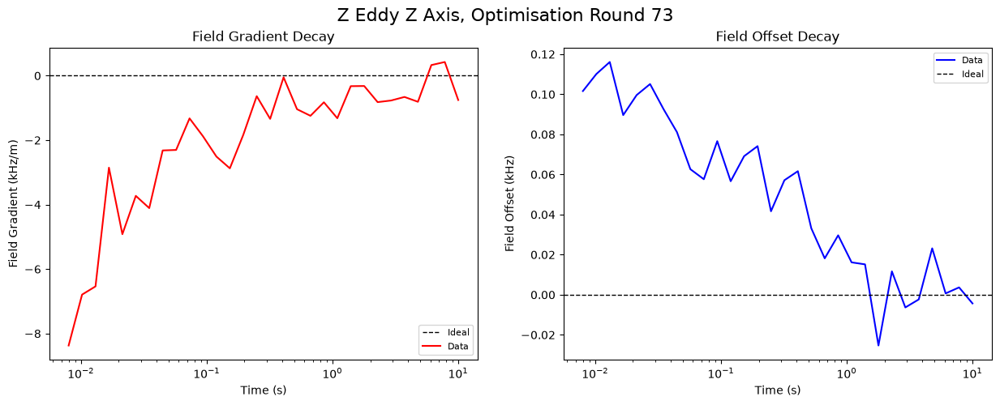

[I 2026-11-24 18:47:05,880] Trial 73 finished with value: 117.37569922617338 and parameters: {'Z_A1': -0.0008716684391902789, 'Z_A2': -0.0004016688906106766, 'Z_A3': -8.040828727481316e-09, 'Z_A4': -4.993987416205476e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.174e+02
Total cost = 1.174e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01279898684746278
B nanmax = 0.01279898684746278
B contains nan = False
Trial 74


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012593283895375942 !!!!!!!!!!!!!!!!


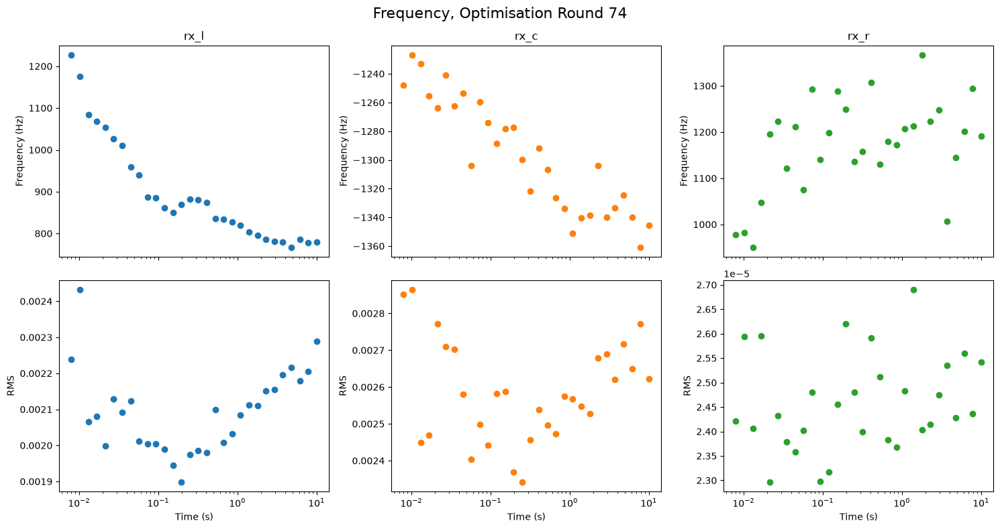

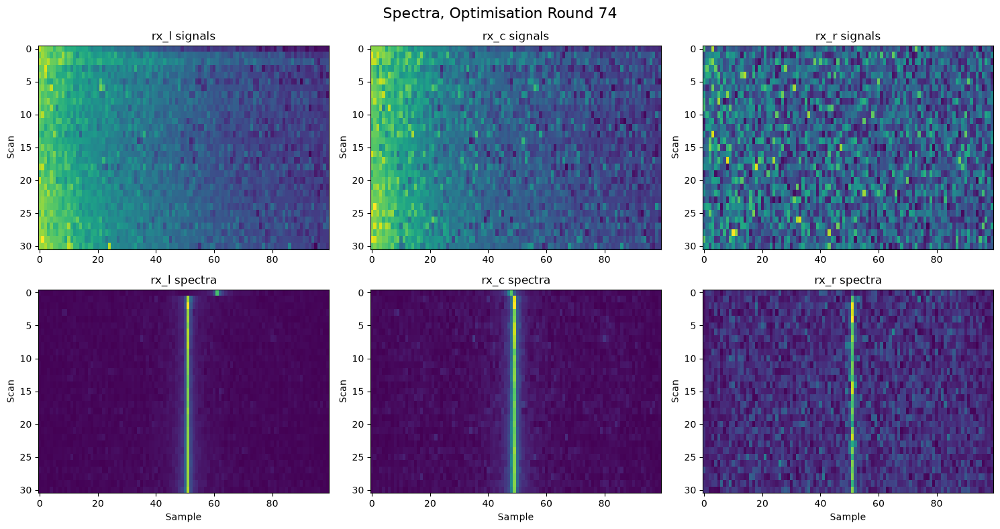

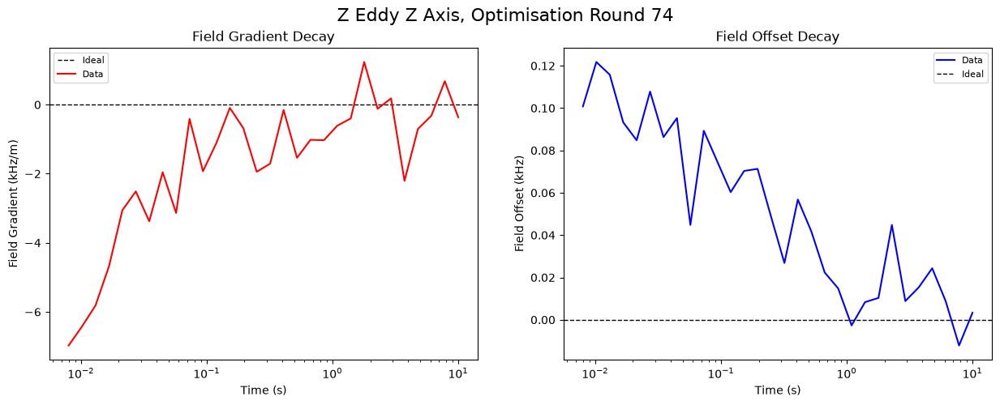

[I 2026-11-24 18:47:54,132] Trial 74 finished with value: 163.1808962915356 and parameters: {'Z_A1': -0.0008686214945616348, 'Z_A2': -0.00036644716413199716, 'Z_A3': -8.511262395004891e-09, 'Z_A4': -4.941478616545387e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.632e+02
Total cost = 1.632e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012627937883218737
B nanmax = 0.012627937883218737
B contains nan = False
Trial 75


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012424981880769773 !!!!!!!!!!!!!!!!


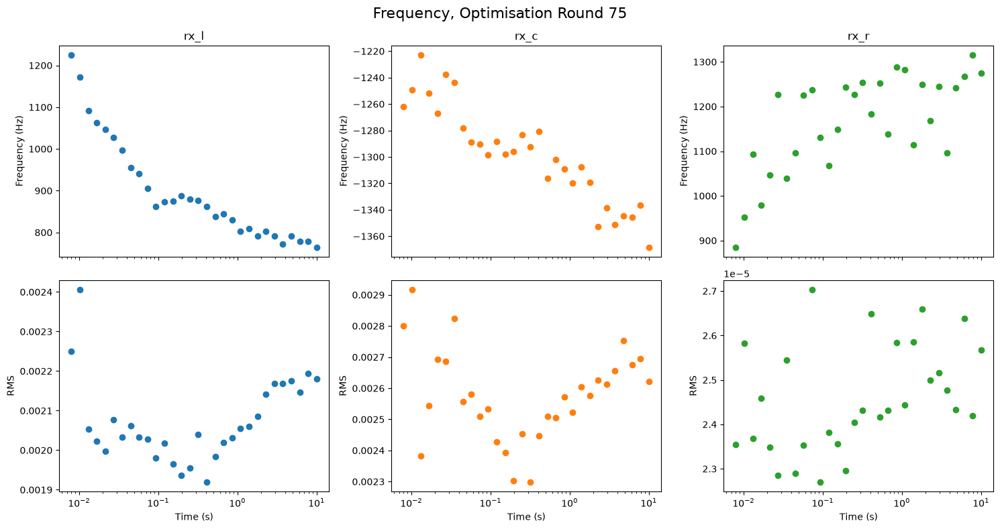

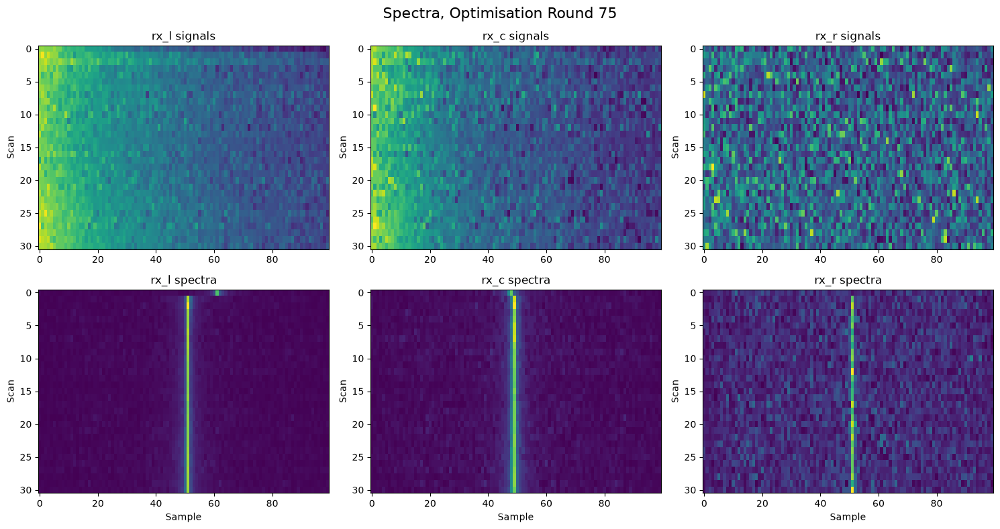

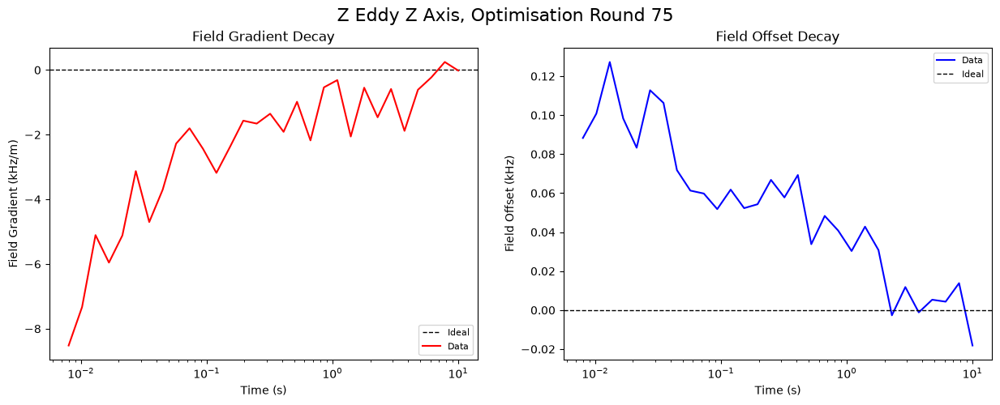

[I 2026-11-24 18:48:42,155] Trial 75 finished with value: 158.14166539844393 and parameters: {'Z_A1': -0.0008053502394482021, 'Z_A2': -0.00041267285177705497, 'Z_A3': -4.382597996883942e-09, 'Z_A4': -4.55256290235225e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.581e+02
Total cost = 1.581e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013738556872368544
B nanmax = 0.013738556872368544
B contains nan = False
Trial 76


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013517755812289428 !!!!!!!!!!!!!!!!


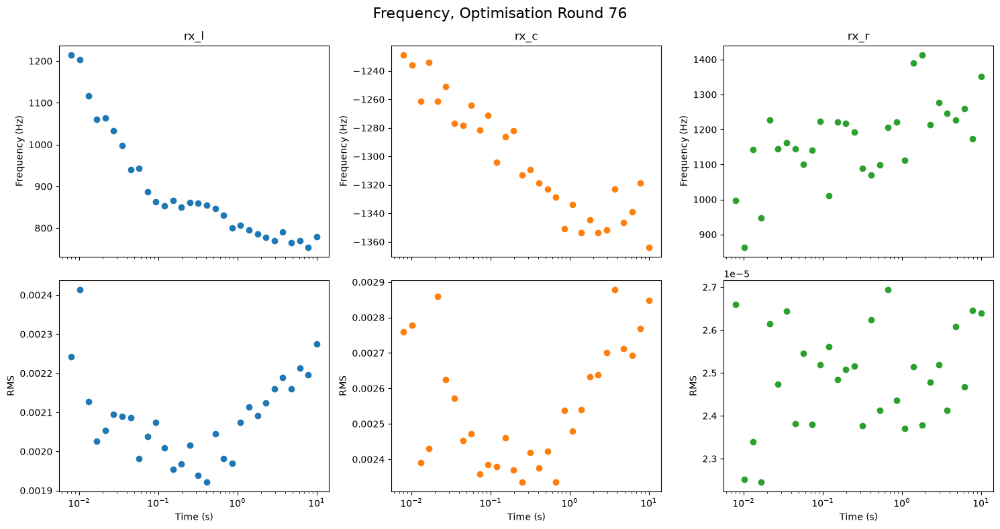

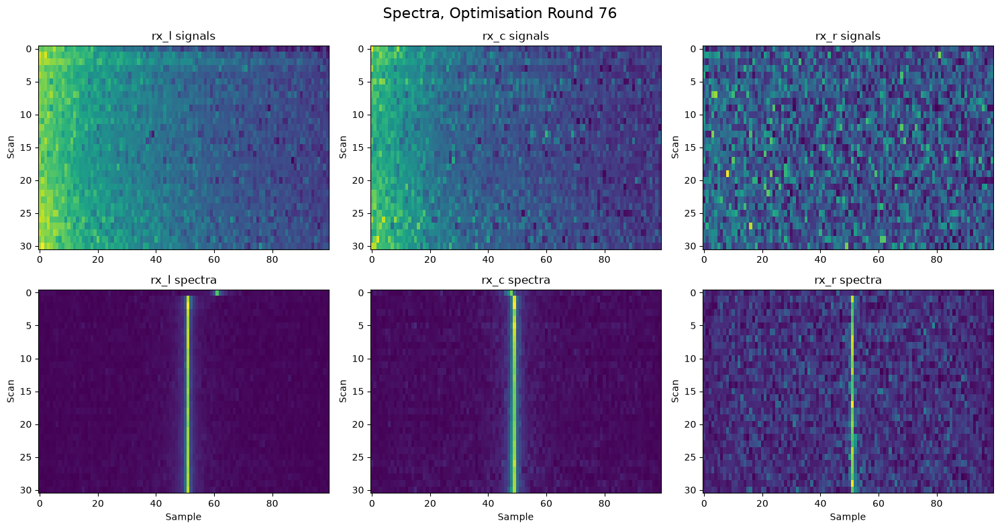

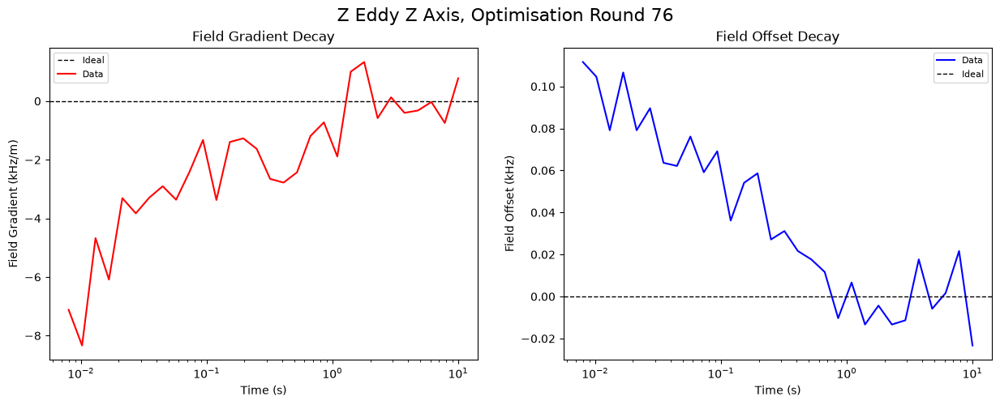

[I 2026-11-24 18:49:30,385] Trial 76 finished with value: 143.39296573637668 and parameters: {'Z_A1': -0.0009930796146451278, 'Z_A2': -0.000333289227592104, 'Z_A3': -7.672943690171333e-09, 'Z_A4': -8.251308122966226e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.434e+02
Total cost = 1.434e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012973107517726762
B nanmax = 0.012973107517726762
B contains nan = False
Trial 77


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01276460511686176 !!!!!!!!!!!!!!!!


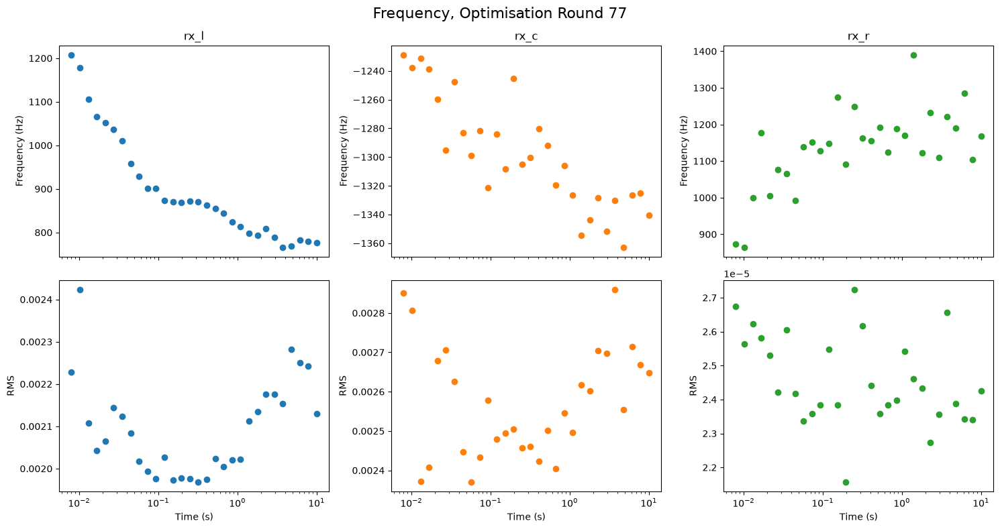

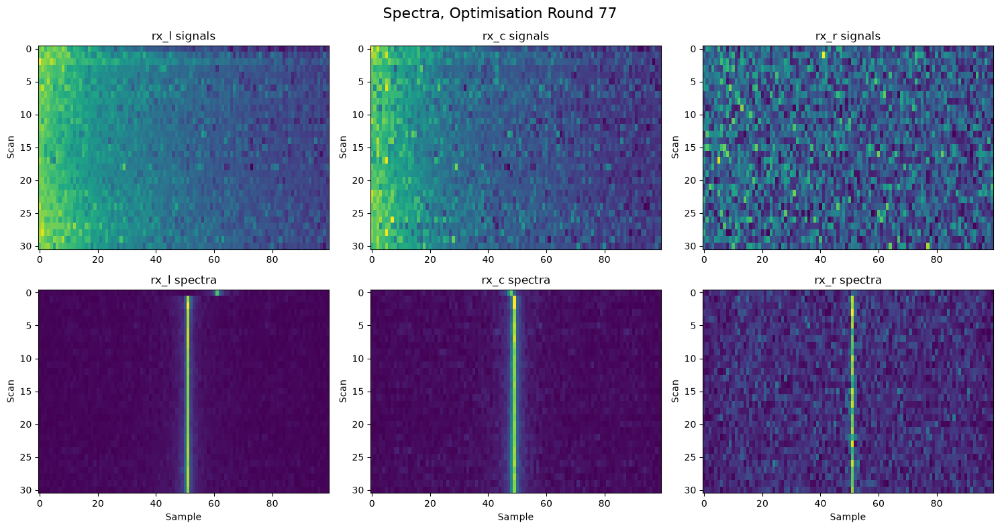

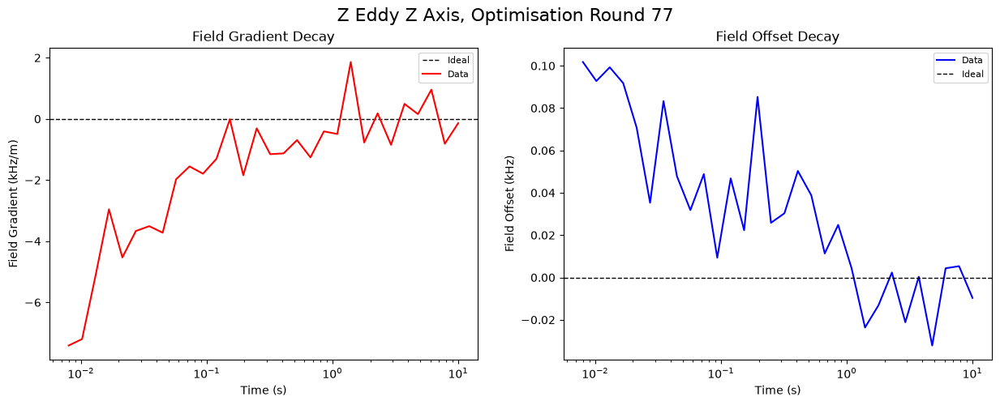

[I 2026-11-24 18:50:18,456] Trial 77 finished with value: 130.07532985292923 and parameters: {'Z_A1': -0.0008557127682336388, 'Z_A2': -0.0003958997357554997, 'Z_A3': -5.7849478867013976e-09, 'Z_A4': -4.68929198427712e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.301e+02
Total cost = 1.301e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013770211742664148
B nanmax = 0.013770211742664148
B contains nan = False
Trial 78


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013548900661800443 !!!!!!!!!!!!!!!!


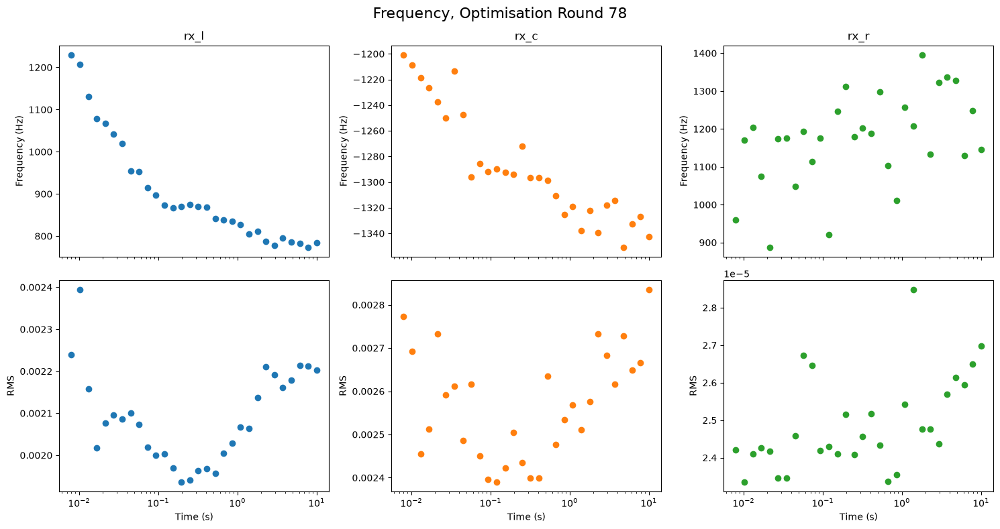

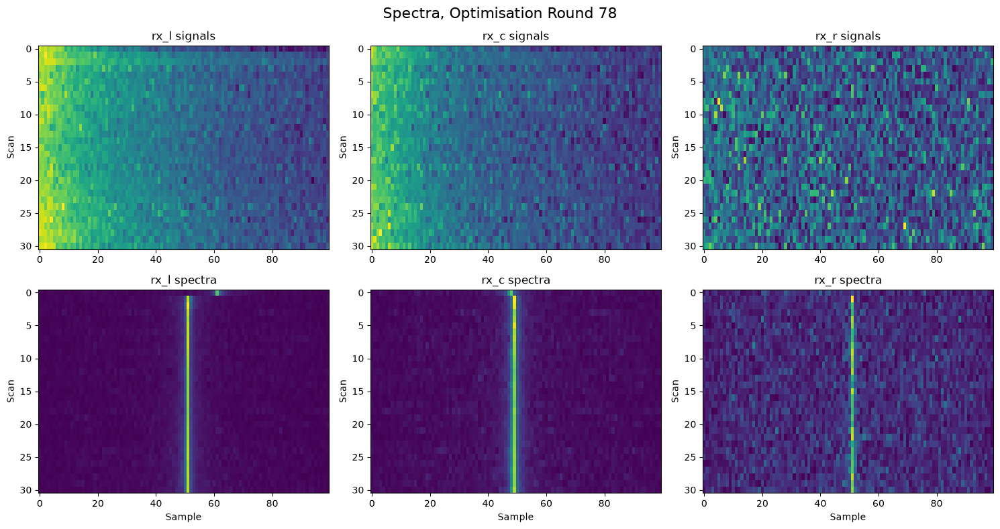

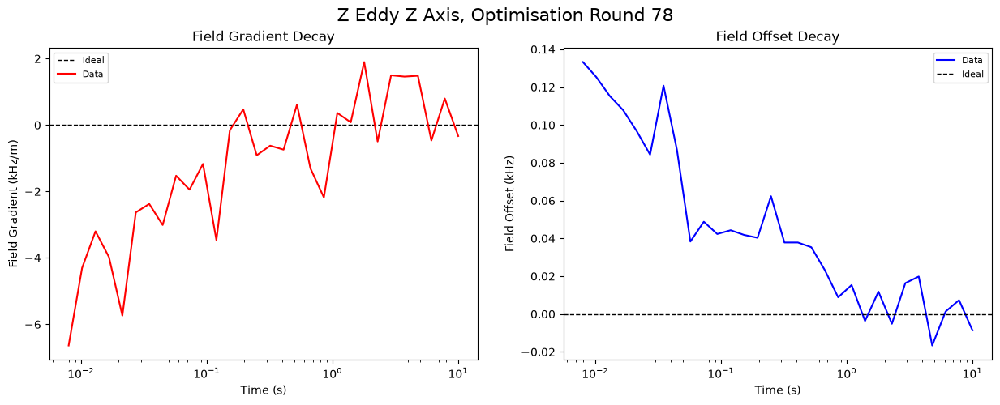

[I 2026-11-24 18:51:06,474] Trial 78 finished with value: 122.1054687426635 and parameters: {'Z_A1': -0.0009642564065859016, 'Z_A2': -0.0003648434462078508, 'Z_A3': -8.746072213718517e-09, 'Z_A4': -8.441772312424869e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.221e+02
Total cost = 1.221e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.011994630465712107
B nanmax = 0.011994630465712107
B contains nan = False
Trial 79


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.011801855764168319 !!!!!!!!!!!!!!!!


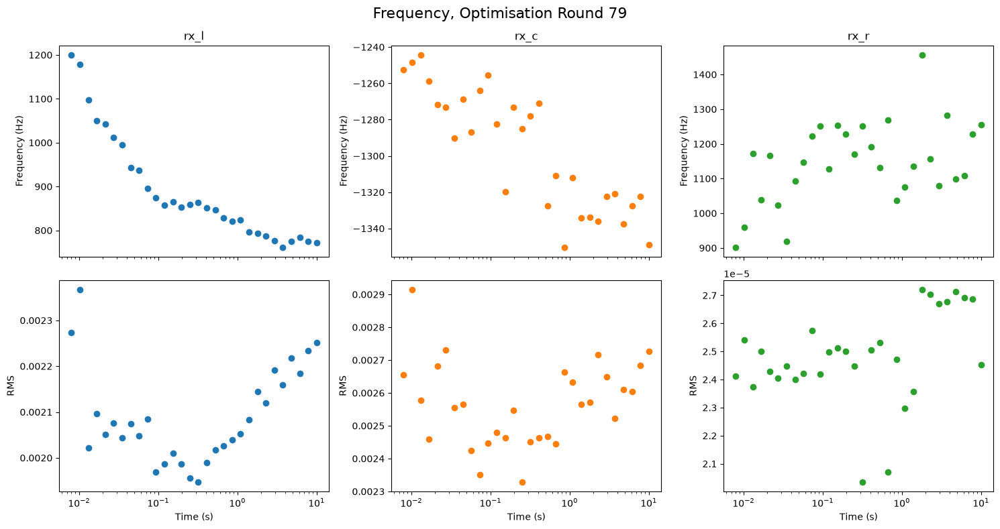

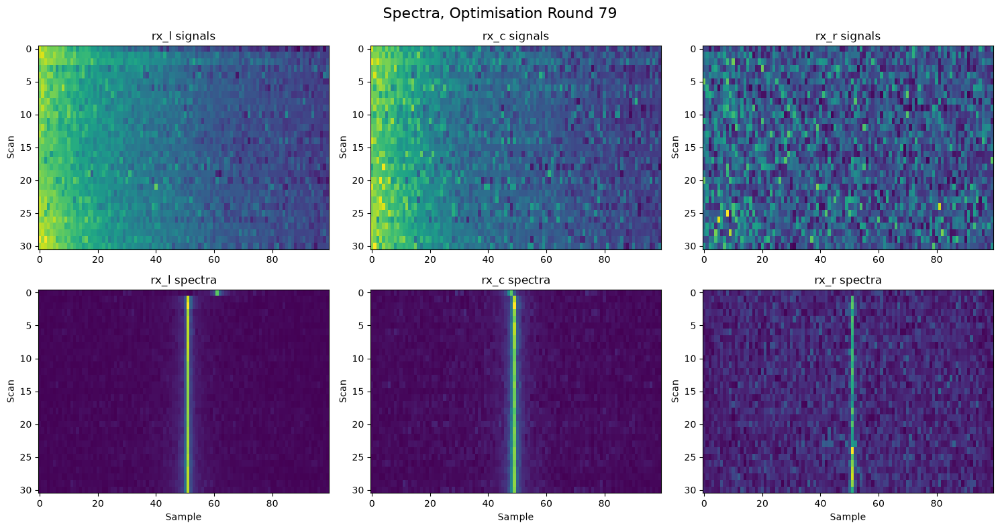

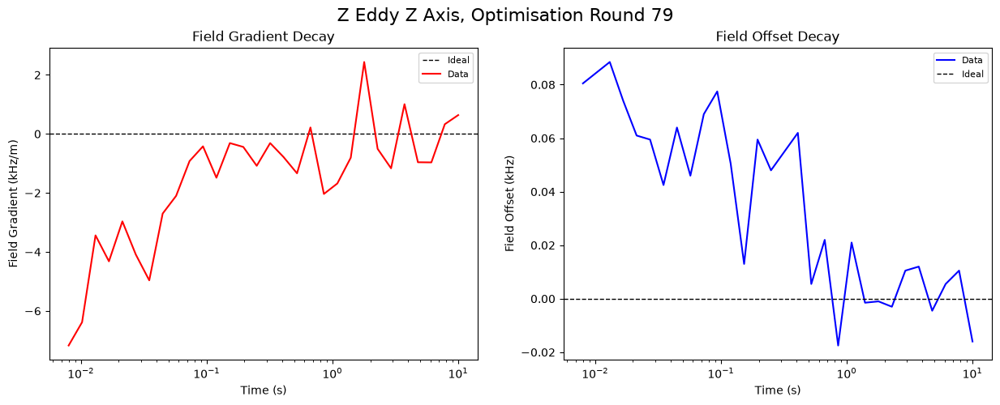

[I 2026-11-24 18:51:54,450] Trial 79 finished with value: 111.6619388657482 and parameters: {'Z_A1': -0.0008331435408011541, 'Z_A2': -0.0003245065137669891, 'Z_A3': -6.20149507365653e-09, 'Z_A4': -6.043150814200631e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.117e+02
Total cost = 1.117e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01384784872836063
B nanmax = 0.01384784872836063
B contains nan = False
Trial 80


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013625290230706478 !!!!!!!!!!!!!!!!


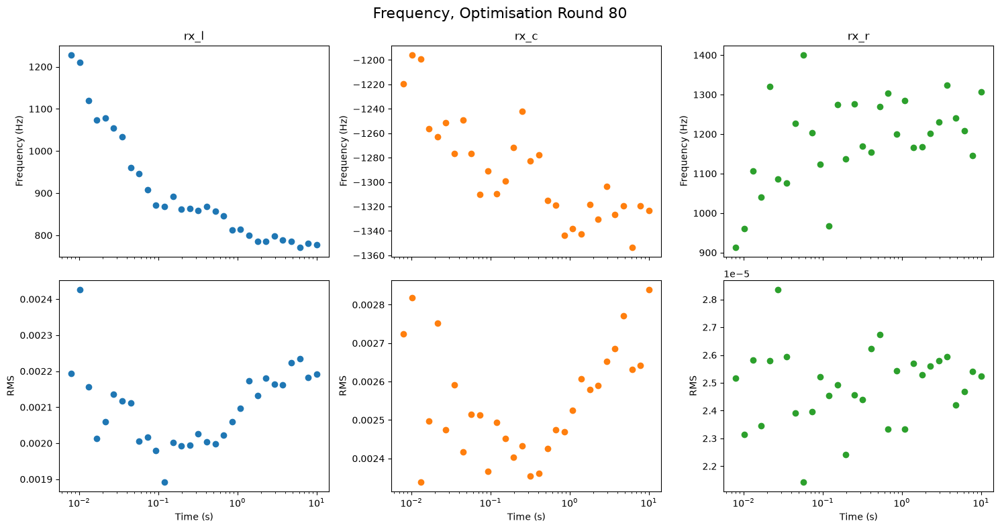

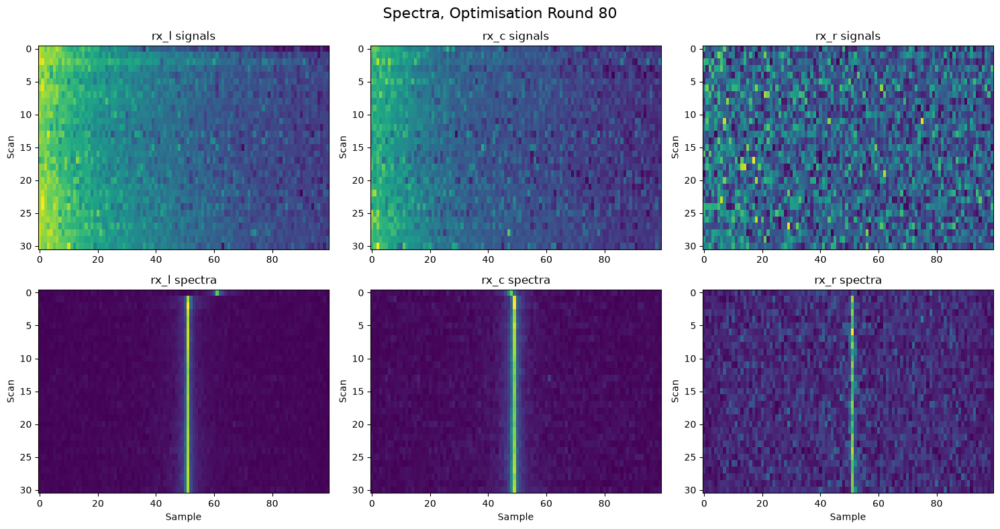

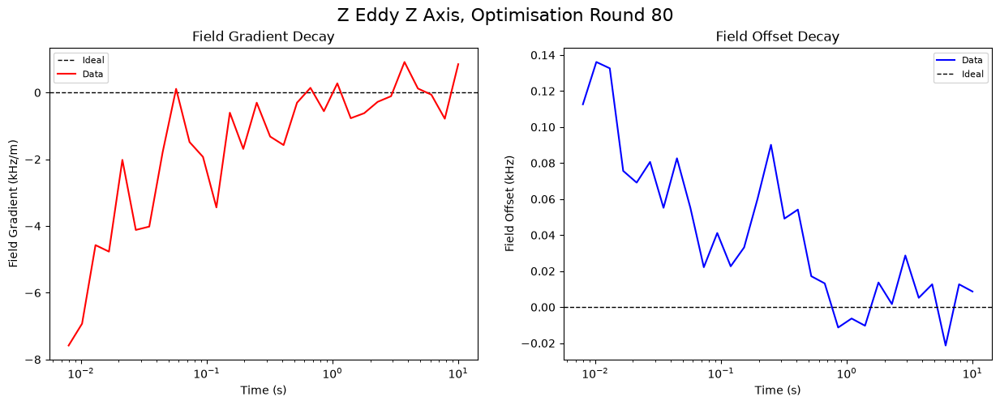

[I 2026-11-24 18:52:42,363] Trial 80 finished with value: 151.73694307862115 and parameters: {'Z_A1': -0.0009780759977084958, 'Z_A2': -0.0003586049607647378, 'Z_A3': -7.644770889496849e-09, 'Z_A4': -5.687714483935422e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.517e+02
Total cost = 1.517e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012416810170108214
B nanmax = 0.012416810170108214
B contains nan = False
Trial 81


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01221724892381018 !!!!!!!!!!!!!!!!


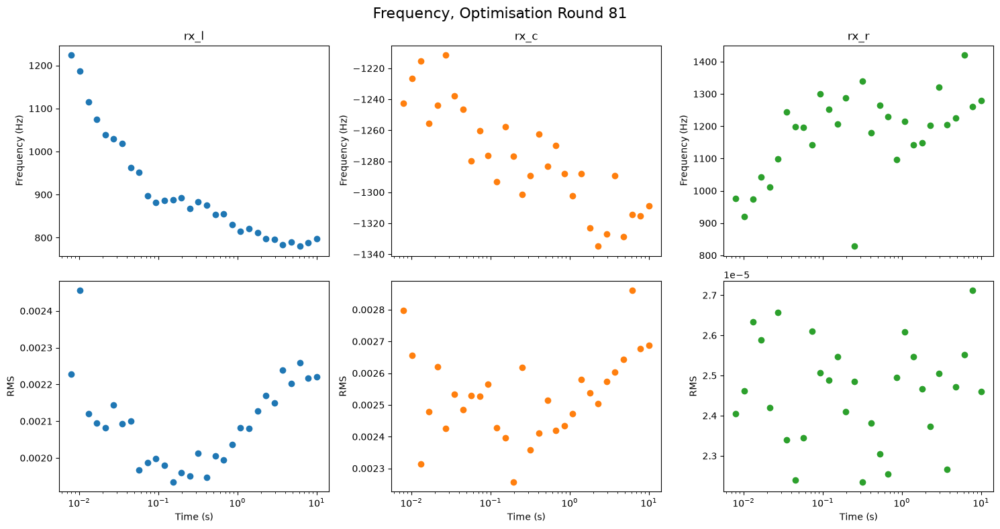

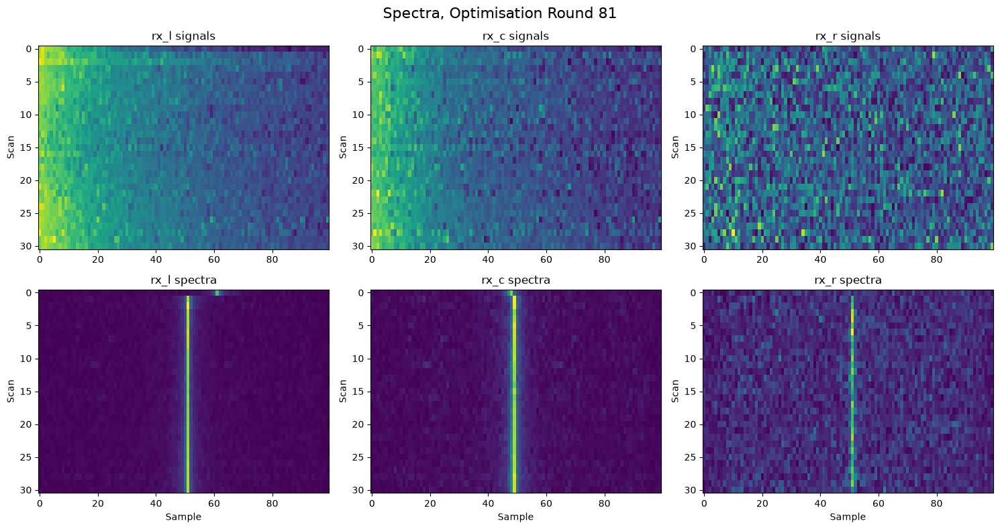

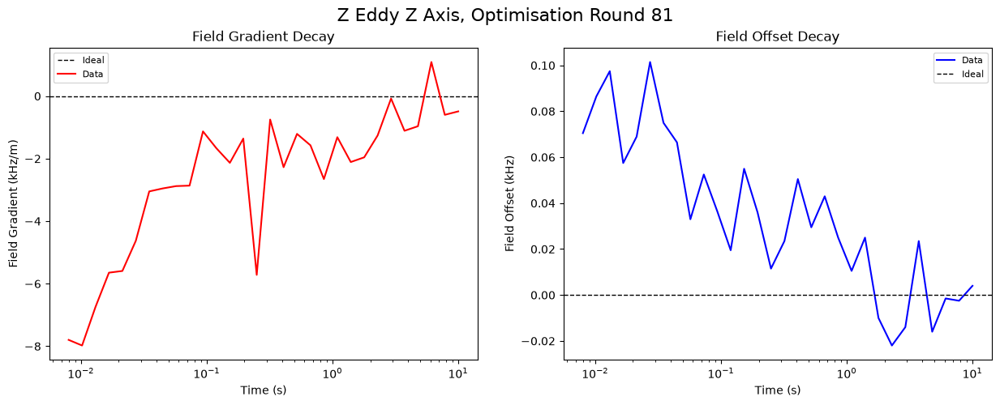

[I 2026-11-24 18:53:30,429] Trial 81 finished with value: 124.89664502090807 and parameters: {'Z_A1': -0.0008288482401341907, 'Z_A2': -0.00036919680516880047, 'Z_A3': -6.4245797835135704e-09, 'Z_A4': -5.350671081849472e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.249e+02
Total cost = 1.249e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012482290887287374
B nanmax = 0.012482290887287374
B contains nan = False
Trial 82


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01228167648651595 !!!!!!!!!!!!!!!!


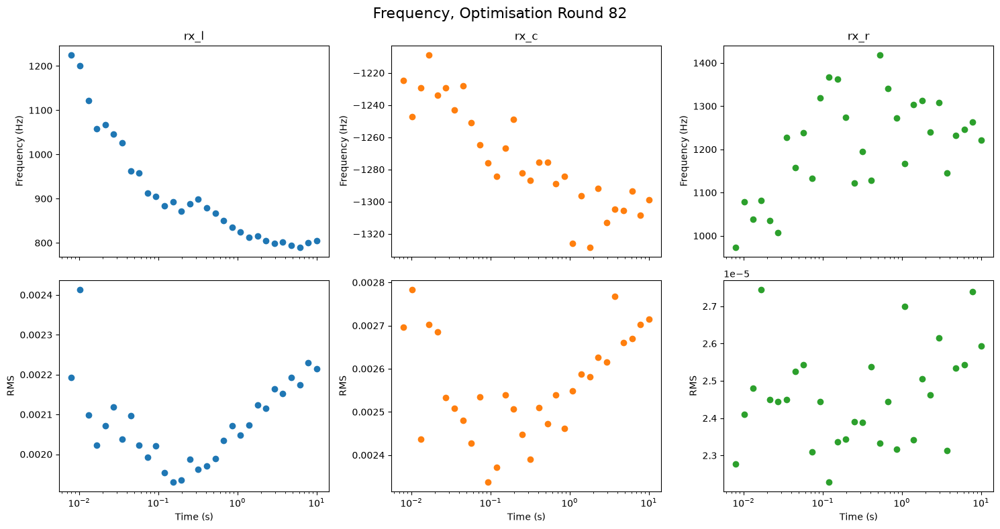

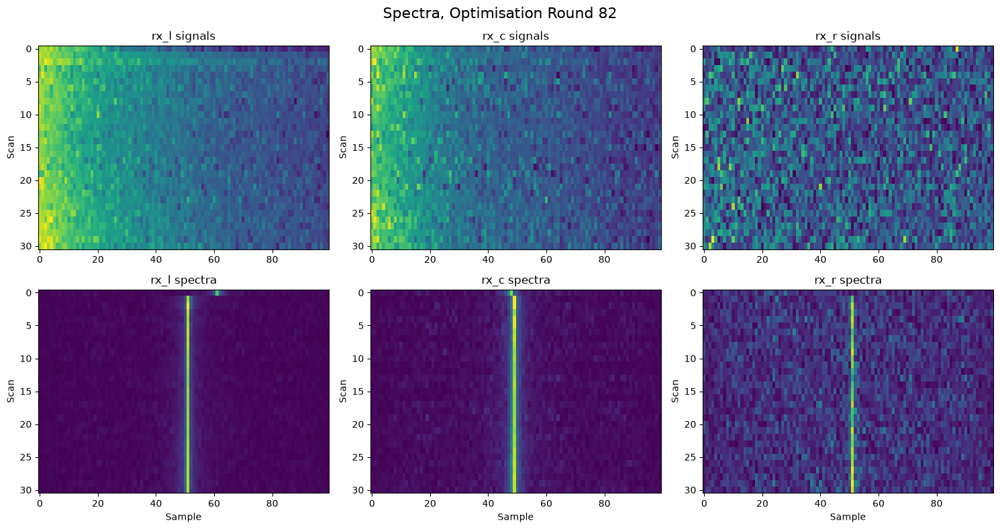

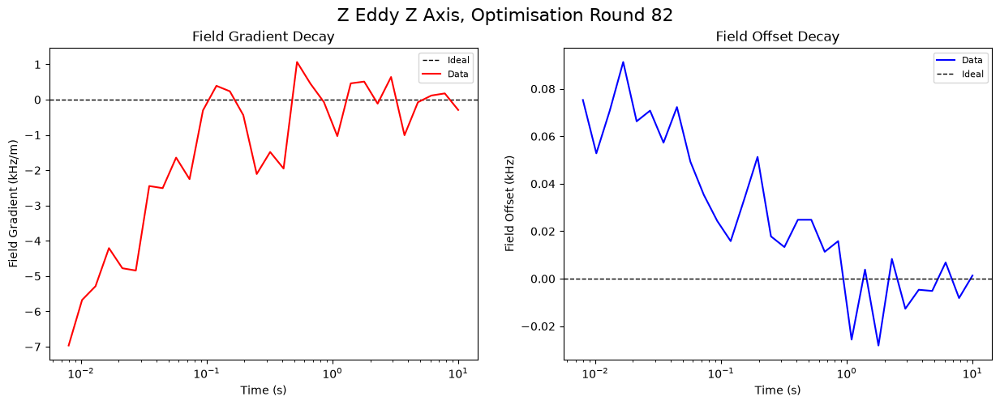

[I 2026-11-24 18:54:18,716] Trial 82 finished with value: 95.13350153483509 and parameters: {'Z_A1': -0.000814739778291632, 'Z_A2': -0.00038943014232511184, 'Z_A3': 2.303050798769422e-10, 'Z_A4': -3.274583130191013e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 9.513e+01
Total cost = 9.513e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013875825871424281
B nanmax = 0.013875825871424281
B contains nan = False
Trial 83


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013652817463767961 !!!!!!!!!!!!!!!!


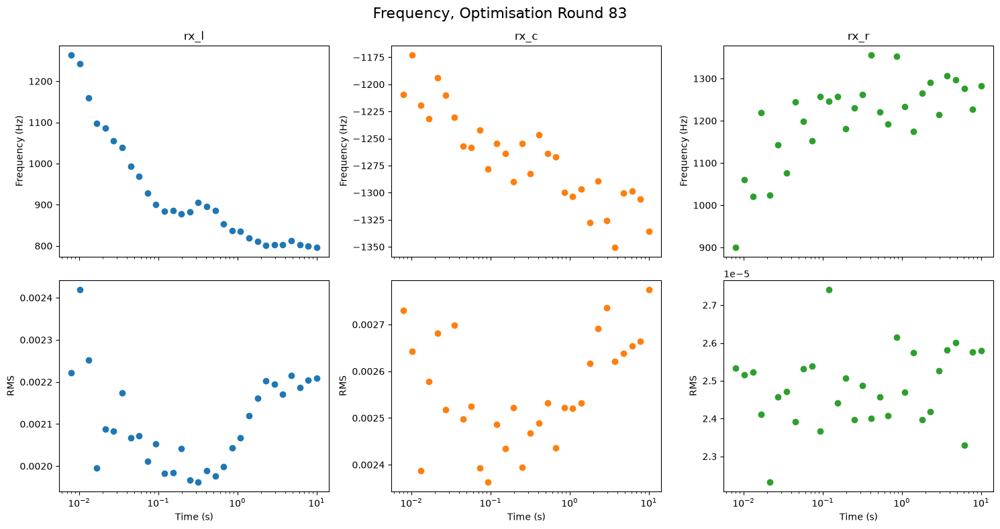

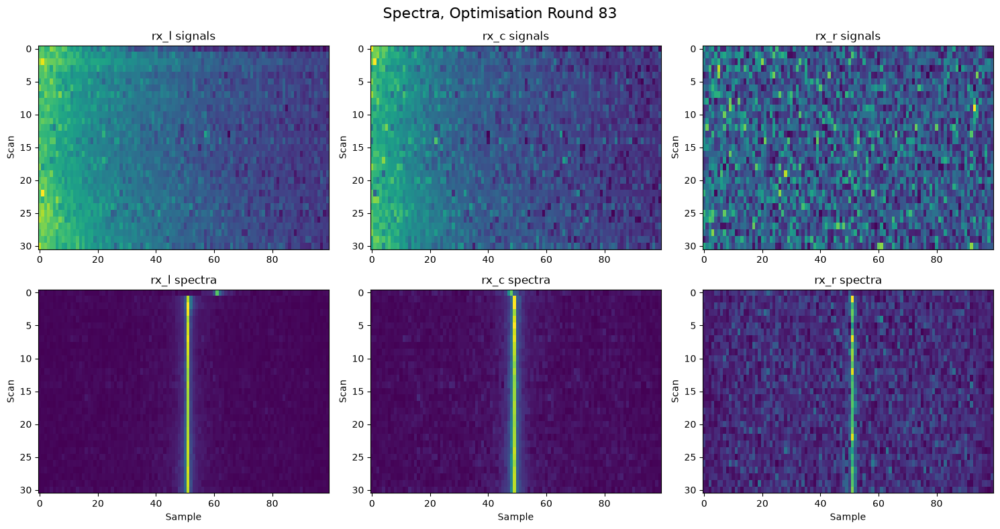

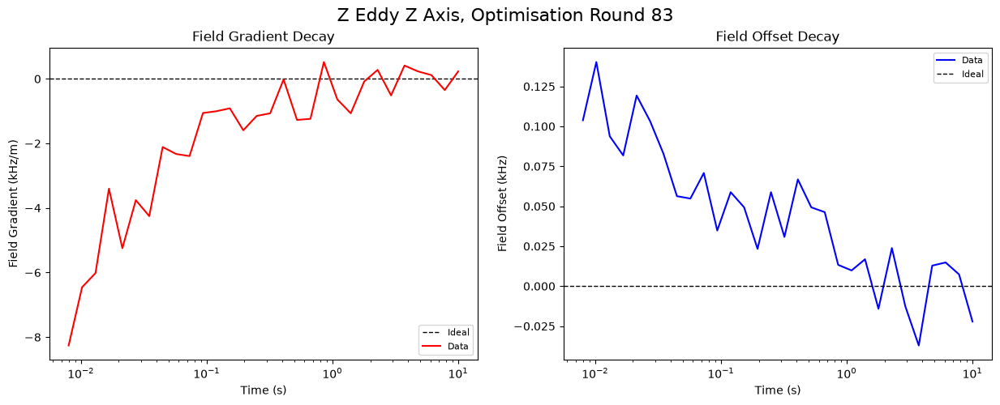

[I 2026-11-24 18:55:06,840] Trial 83 finished with value: 189.41956997821146 and parameters: {'Z_A1': -0.000973472633601325, 'Z_A2': -0.0003658401098163956, 'Z_A3': -9.213369289496588e-09, 'Z_A4': -6.694151807259516e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.894e+02
Total cost = 1.894e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014563329793411092
B nanmax = 0.014563329793411092
B contains nan = False
Trial 84


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014329269652103151 !!!!!!!!!!!!!!!!


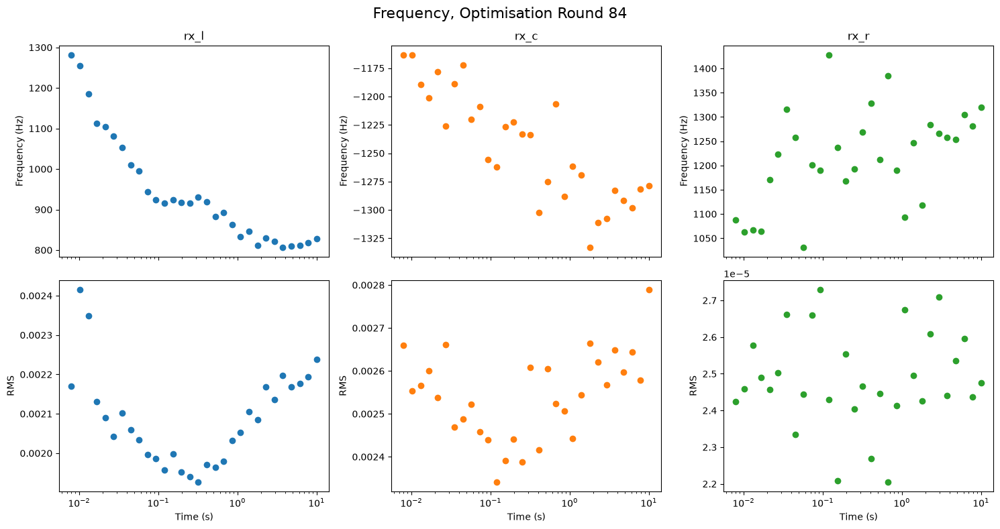

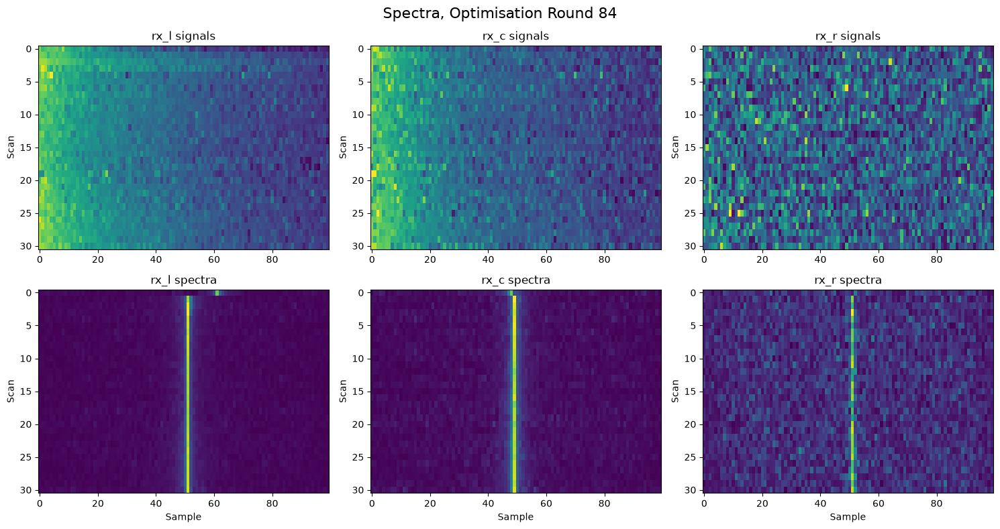

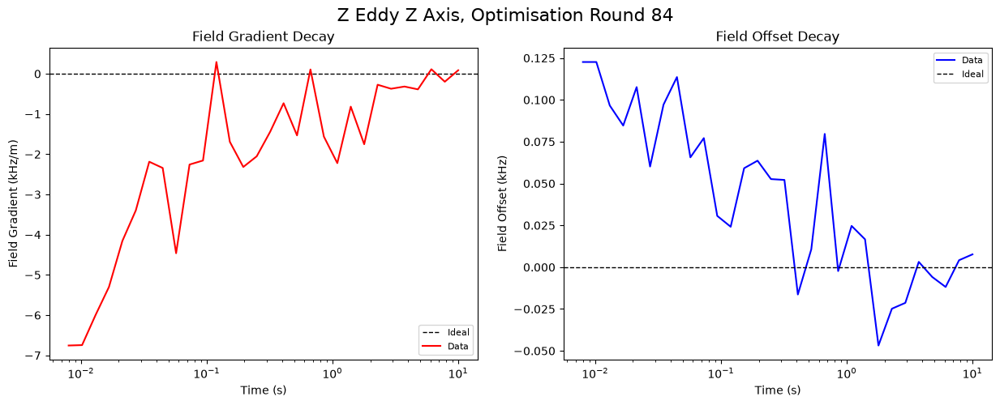

[I 2026-11-24 18:55:55,117] Trial 84 finished with value: 144.6170274452075 and parameters: {'Z_A1': -0.0009640792057970688, 'Z_A2': -0.00044099021290210794, 'Z_A3': -3.157369379314351e-09, 'Z_A4': -1.8306206345989217e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.446e+02
Total cost = 1.446e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013529428984607074
B nanmax = 0.013529428984607074
B contains nan = False
Trial 85


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013311984733782182 !!!!!!!!!!!!!!!!


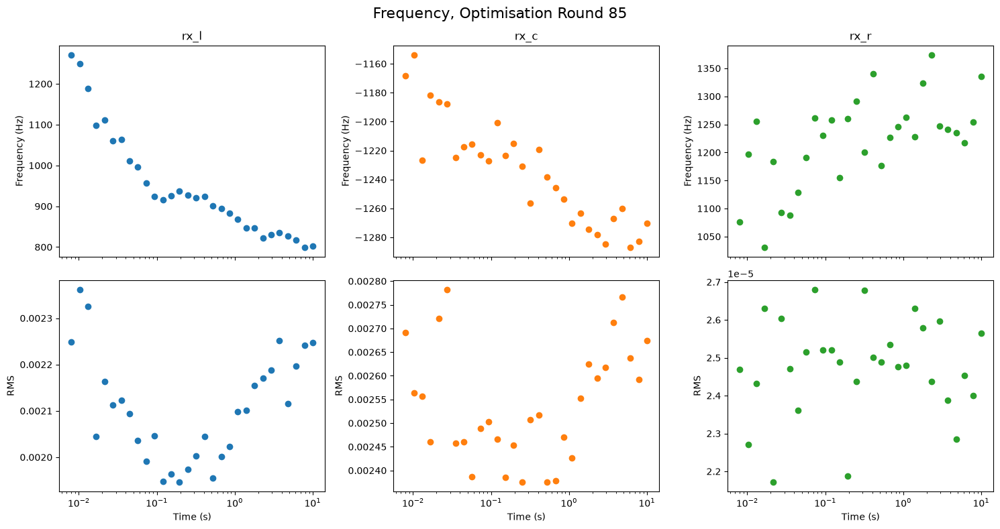

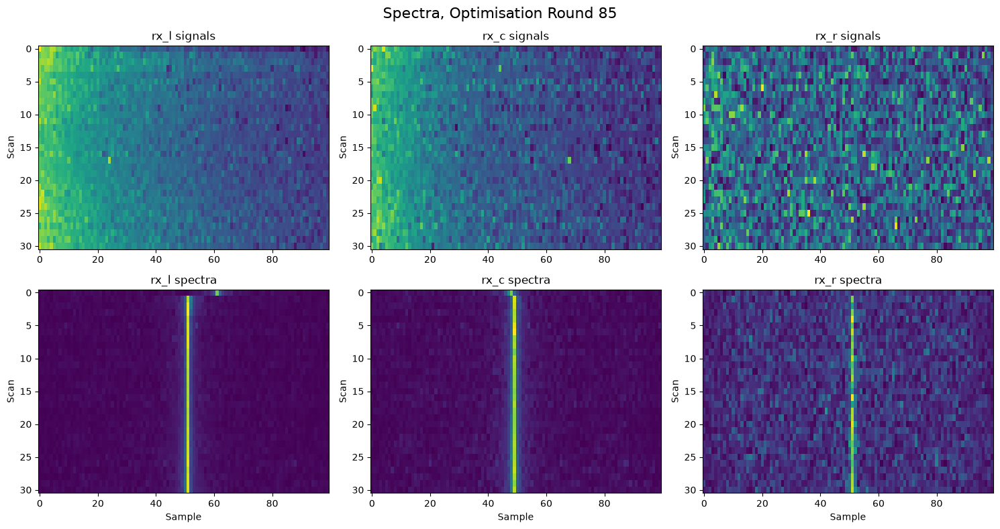

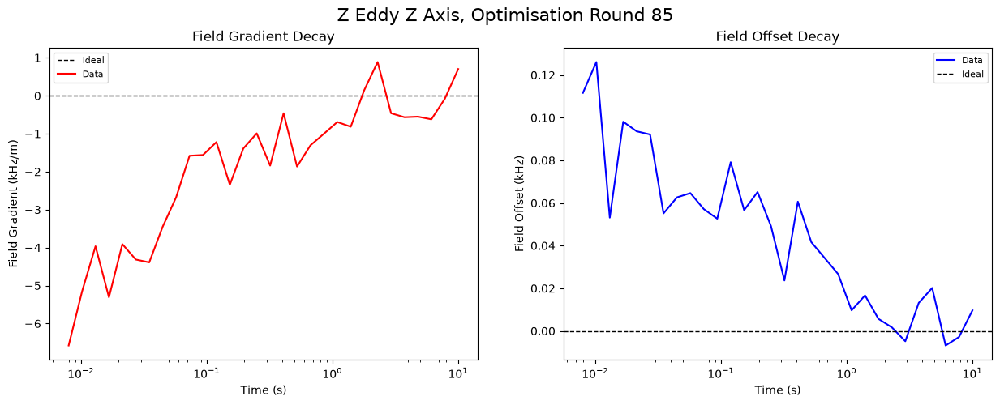

[I 2026-11-24 18:56:42,926] Trial 85 finished with value: 119.9611631434728 and parameters: {'Z_A1': -0.0008750711469698833, 'Z_A2': -0.0004300326991218183, 'Z_A3': -4.348548133859238e-09, 'Z_A4': -4.051468499719779e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.200e+02
Total cost = 1.200e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013174197731116987
B nanmax = 0.013174197731116987
B contains nan = False
Trial 86


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012962465792751381 !!!!!!!!!!!!!!!!


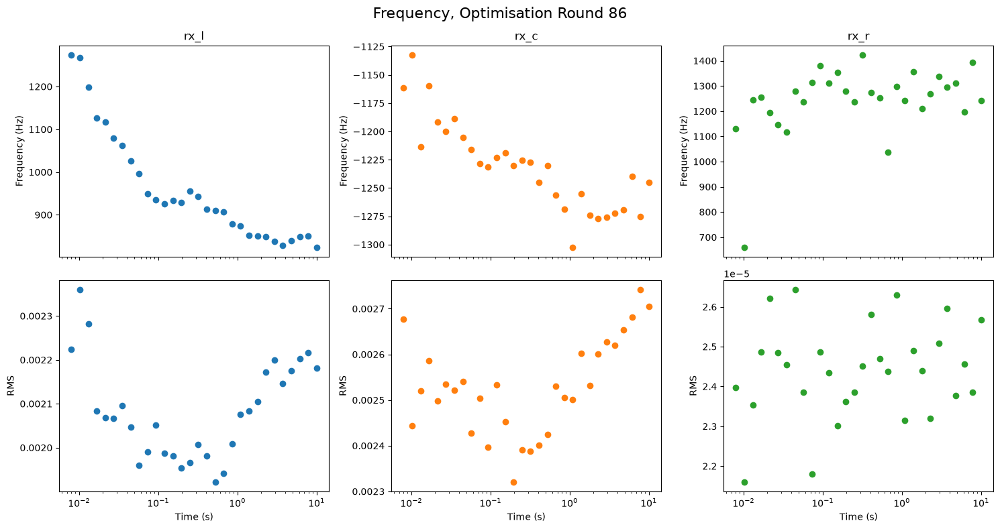

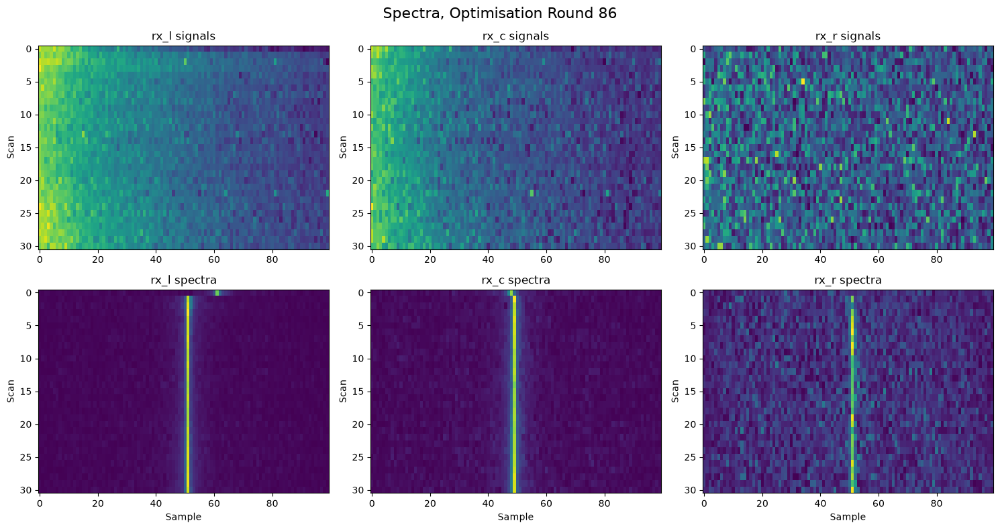

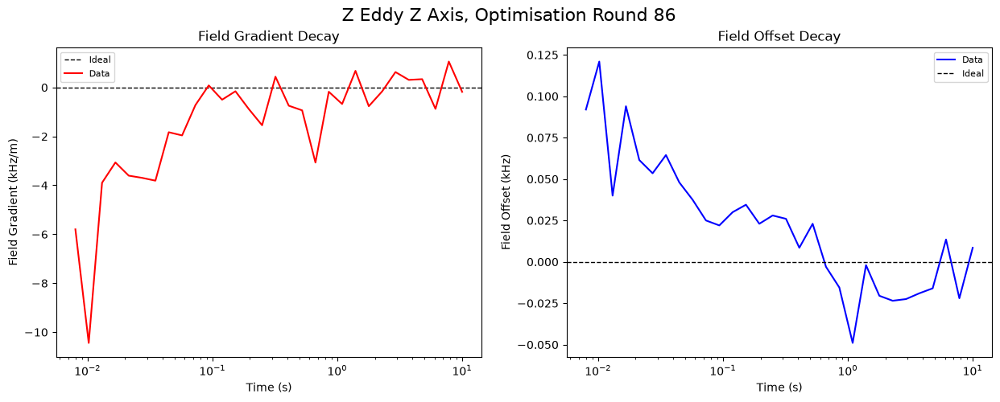

[I 2026-11-24 18:57:30,924] Trial 86 finished with value: 180.847782851045 and parameters: {'Z_A1': -0.0009266226519859132, 'Z_A2': -0.0003449928303038527, 'Z_A3': -7.570784706346227e-09, 'Z_A4': -5.222318772574881e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.808e+02
Total cost = 1.808e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012948746416566367
B nanmax = 0.012948746416566367
B contains nan = False
Trial 87


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012740637708629158 !!!!!!!!!!!!!!!!


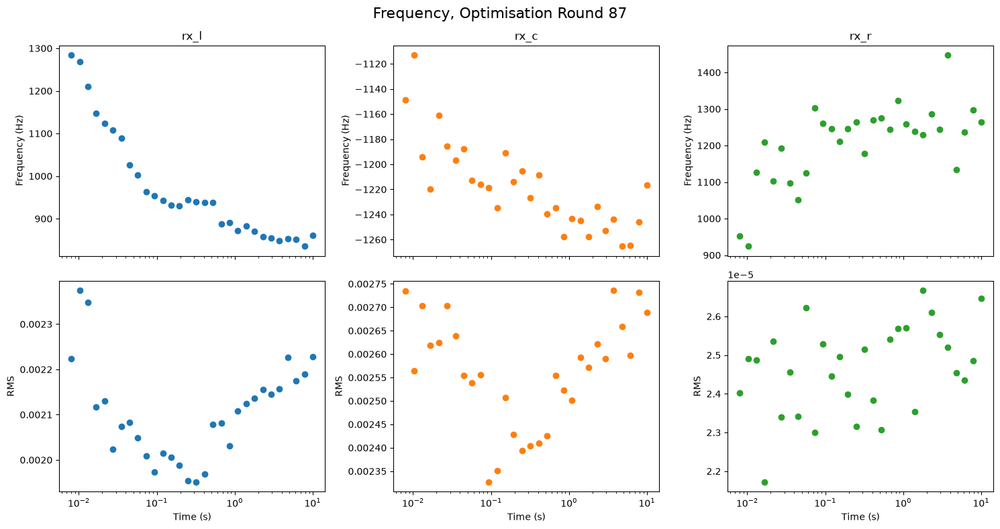

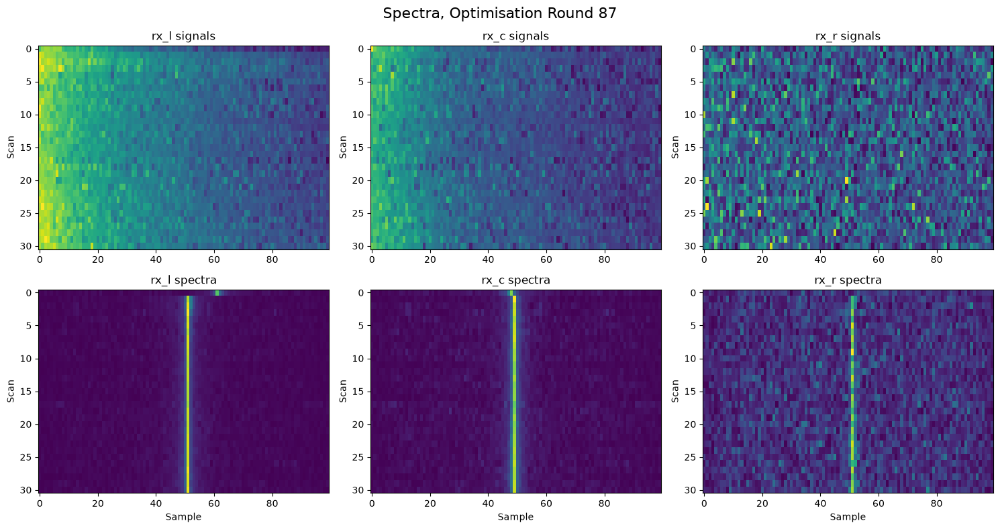

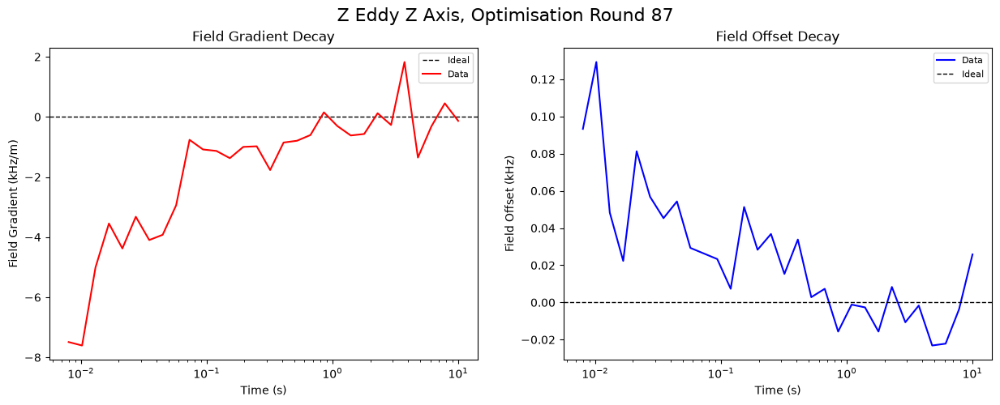

[I 2026-11-24 18:58:18,918] Trial 87 finished with value: 137.967516960259 and parameters: {'Z_A1': -0.0009068955452531005, 'Z_A2': -0.0003429182265644113, 'Z_A3': -8.681459324912572e-09, 'Z_A4': -8.202524562577695e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.380e+02
Total cost = 1.380e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013433707684864765
B nanmax = 0.013433707684864765
B contains nan = False
Trial 88


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013217806142116477 !!!!!!!!!!!!!!!!


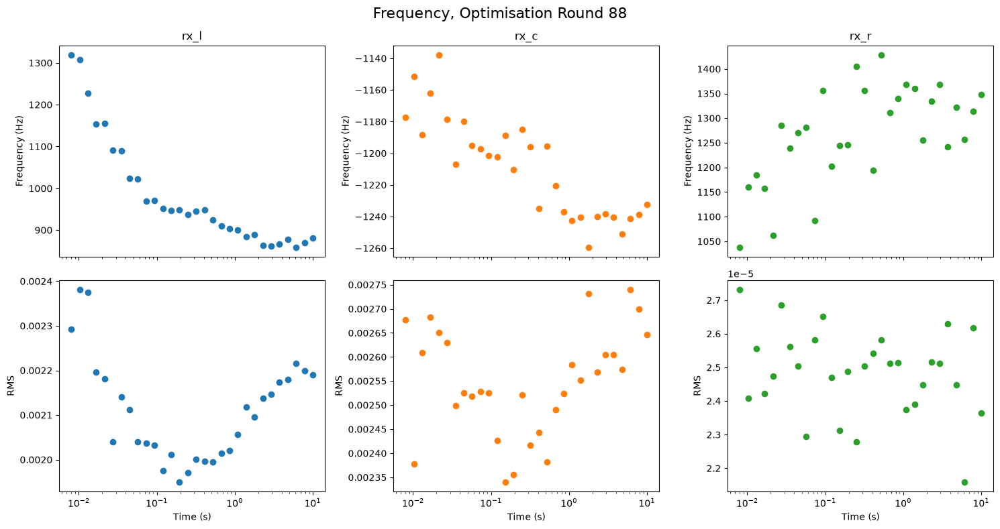

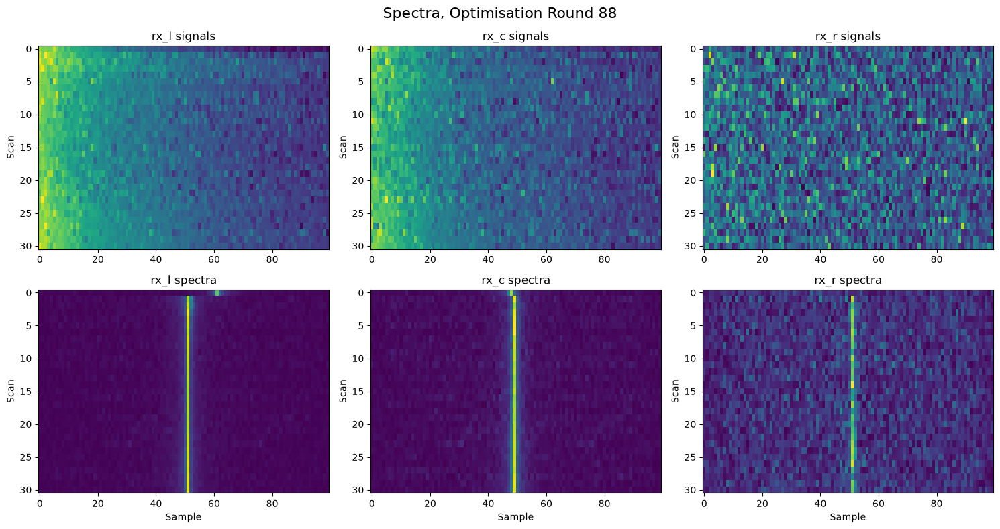

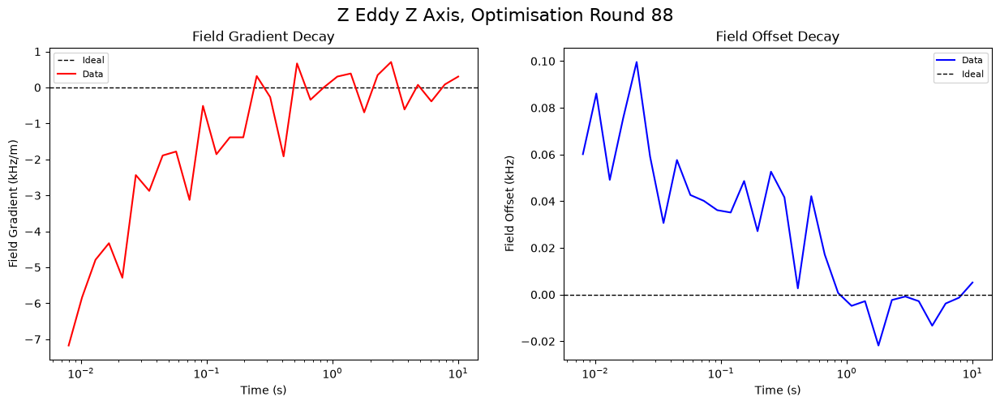

[I 2026-11-24 18:59:07,212] Trial 88 finished with value: 70.71663876227413 and parameters: {'Z_A1': -0.0009733056156436175, 'Z_A2': -0.00032365564014354576, 'Z_A3': -5.887016601305066e-09, 'Z_A4': -6.513464784242805e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 7.072e+01
Total cost = 7.072e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013170844699592708
B nanmax = 0.013170844699592708
B contains nan = False
Trial 89


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012959165364650806 !!!!!!!!!!!!!!!!


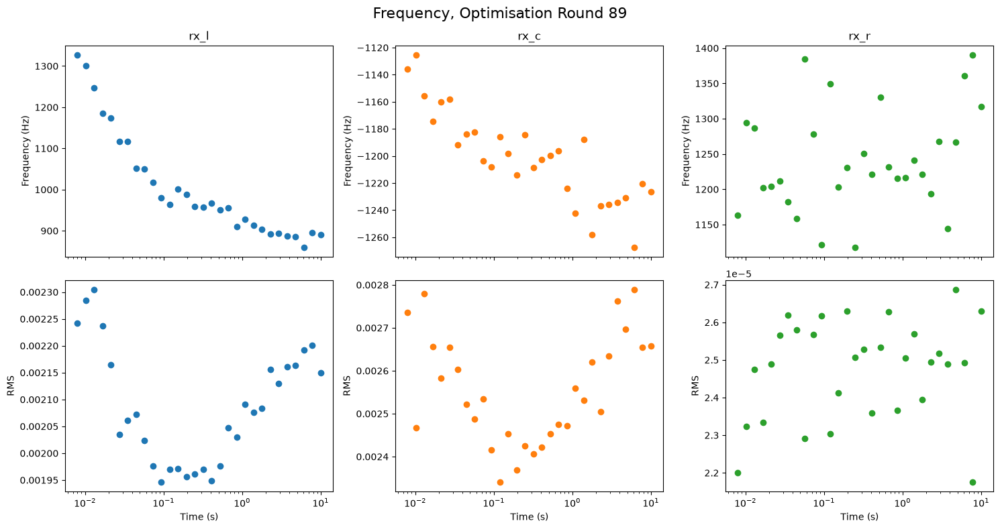

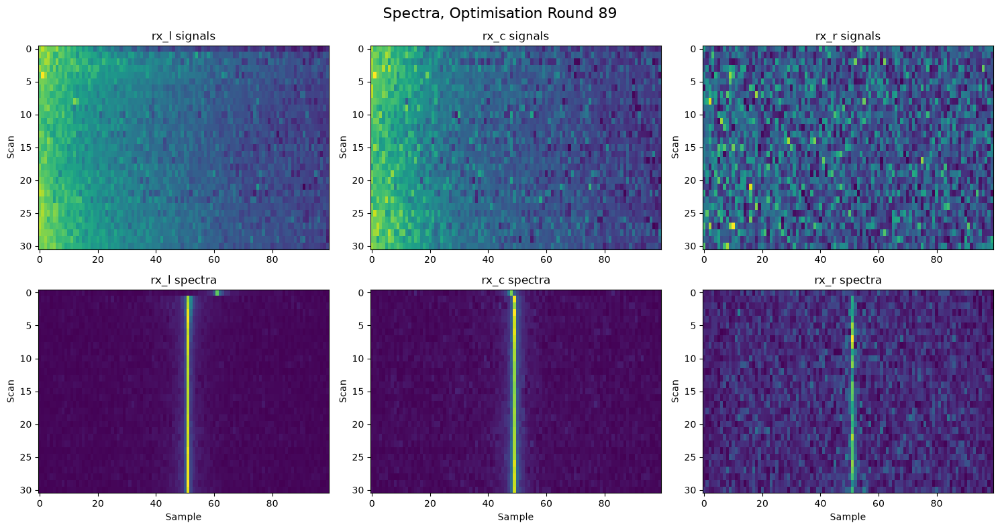

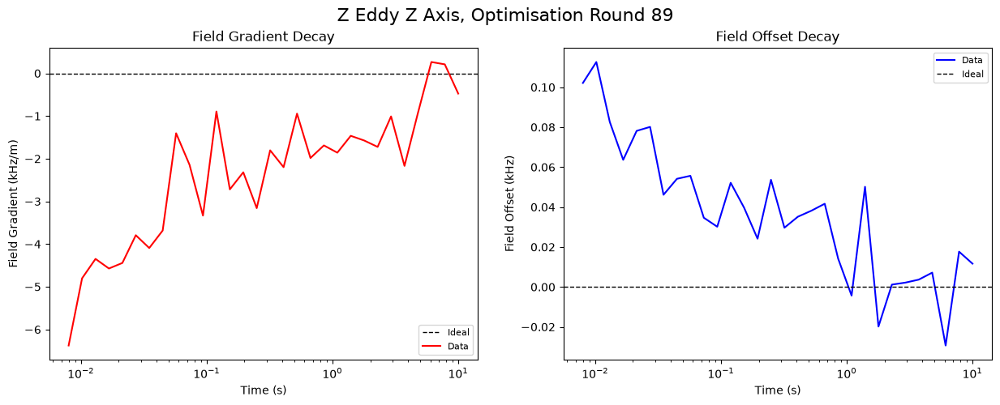

[I 2026-11-24 18:59:55,644] Trial 89 finished with value: 166.47254552190086 and parameters: {'Z_A1': -0.0008950253907057293, 'Z_A2': -0.0003759387709891197, 'Z_A3': -6.044264779167687e-09, 'Z_A4': -4.733603215252235e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.665e+02
Total cost = 1.665e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012835192799018433
B nanmax = 0.012835192799018433
B contains nan = False
Trial 90


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012628908289000805 !!!!!!!!!!!!!!!!


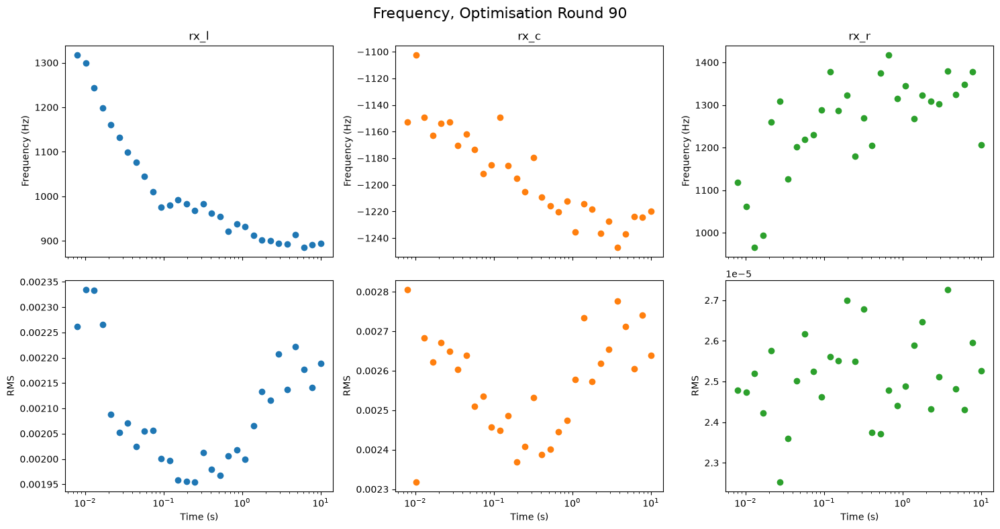

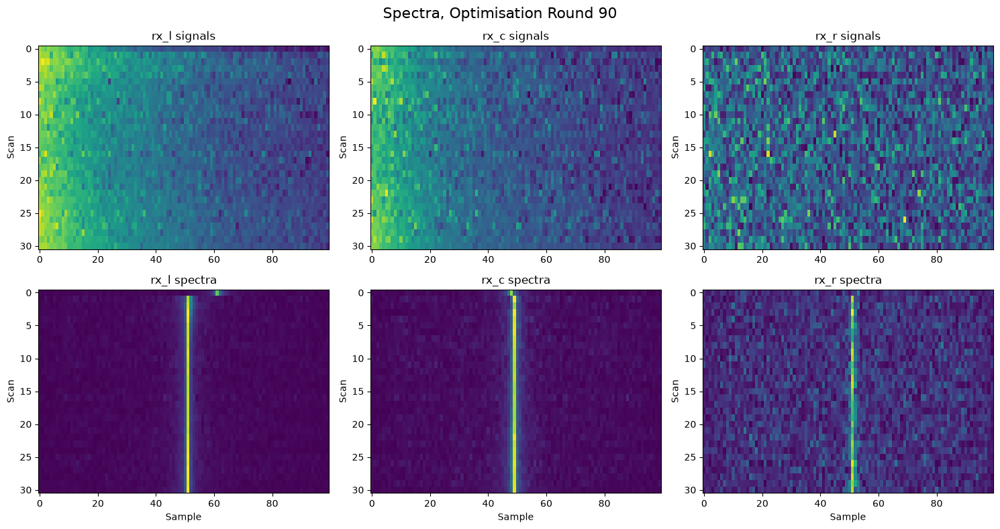

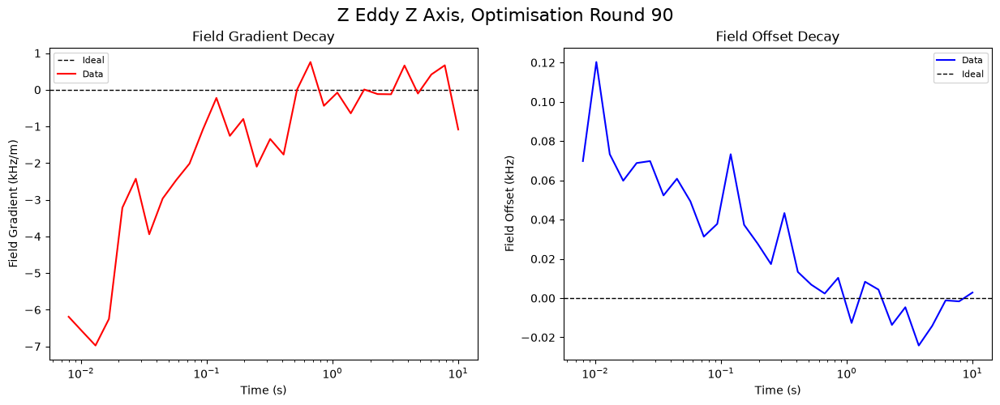

[I 2026-11-24 19:00:43,818] Trial 90 finished with value: 86.02674552717215 and parameters: {'Z_A1': -0.000879310538129115, 'Z_A2': -0.00035933790948744287, 'Z_A3': -9.20430090832306e-09, 'Z_A4': -7.266899710836196e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 8.603e+01
Total cost = 8.603e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012354945364766647
B nanmax = 0.012354945364766647
B contains nan = False
Trial 91


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.01215637935089416 !!!!!!!!!!!!!!!!


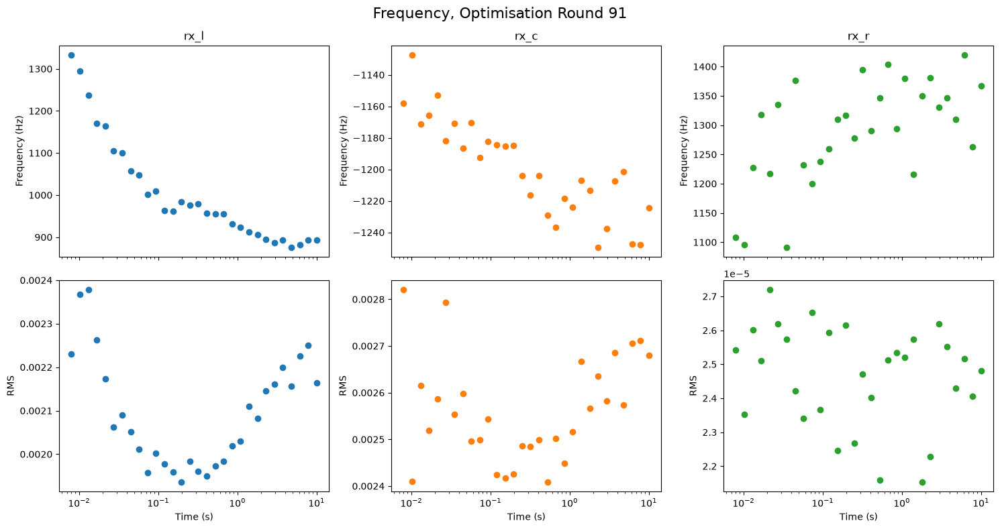

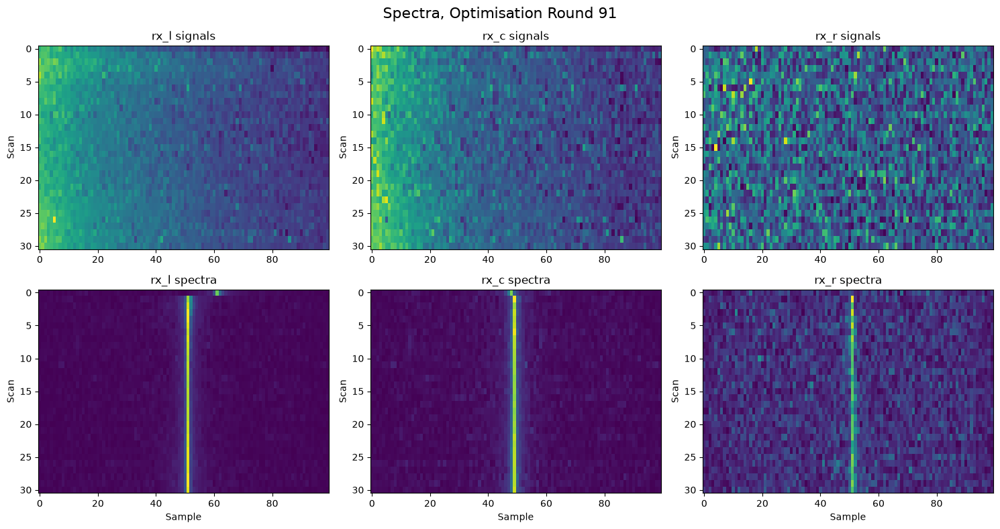

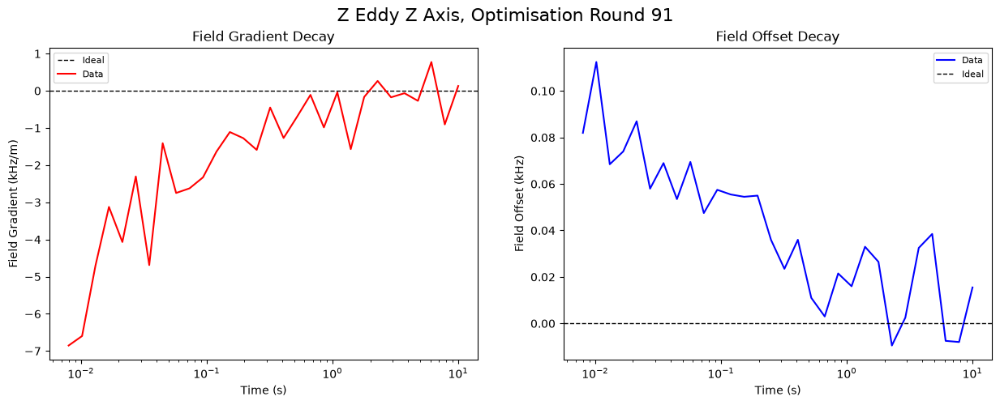

[I 2026-11-24 19:01:31,921] Trial 91 finished with value: 181.23681806519406 and parameters: {'Z_A1': -0.0008478913887478035, 'Z_A2': -0.0003444267026004677, 'Z_A3': -7.184436957178627e-09, 'Z_A4': -6.908187460944666e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.812e+02
Total cost = 1.812e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012767861886247626
B nanmax = 0.012767861886247626
B contains nan = False
Trial 92


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012562657554316677 !!!!!!!!!!!!!!!!


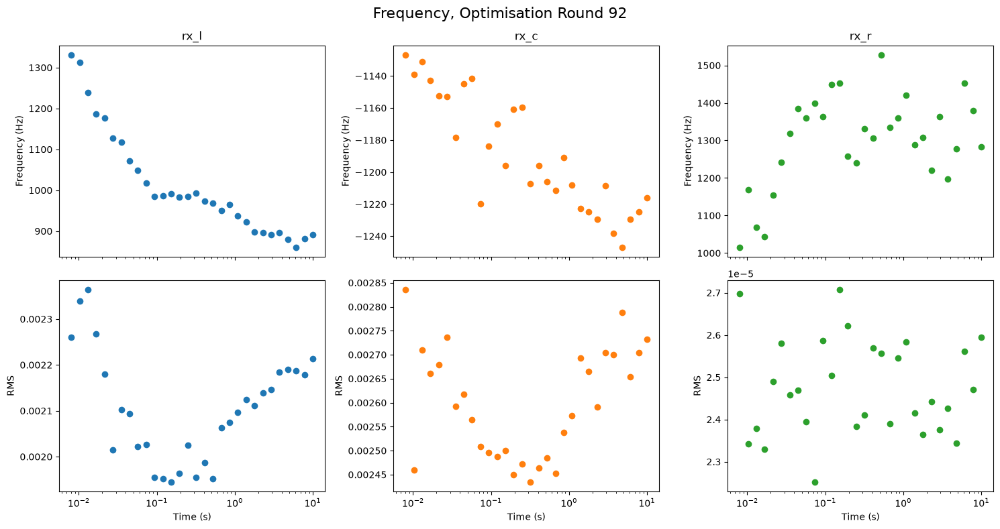

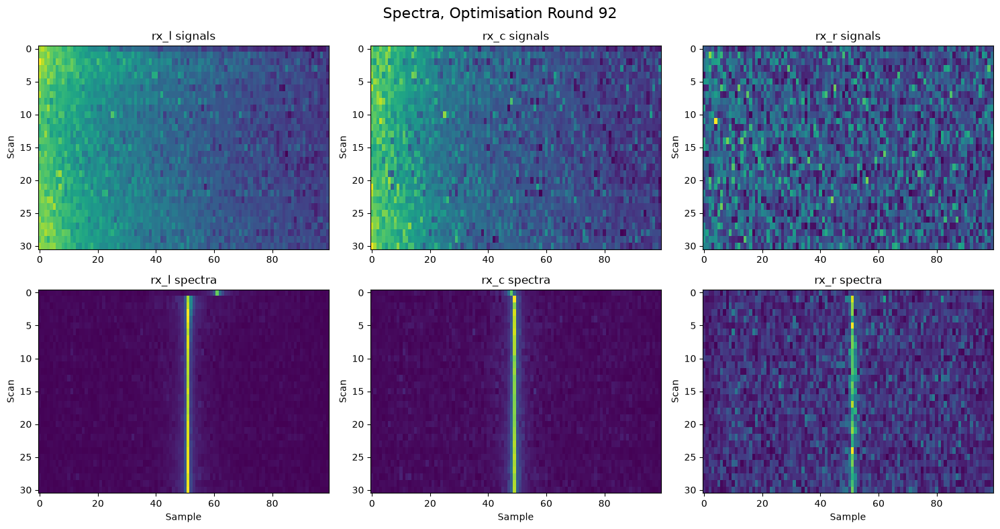

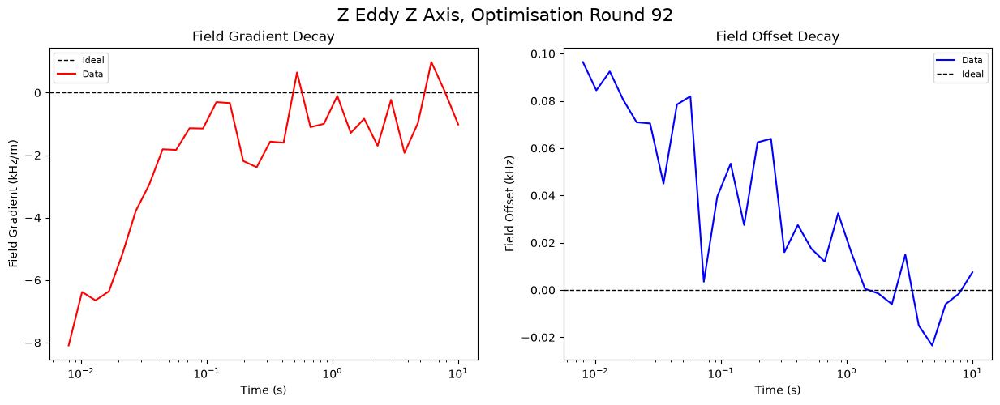

[I 2026-11-24 19:02:19,873] Trial 92 finished with value: 111.45200730822964 and parameters: {'Z_A1': -0.0008271233030617672, 'Z_A2': -0.0004045303610879701, 'Z_A3': -7.318221826205485e-09, 'Z_A4': -6.75077582235154e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.115e+02
Total cost = 1.115e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01311923586779728
B nanmax = 0.01311923586779728
B contains nan = False
Trial 93


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012908388401283116 !!!!!!!!!!!!!!!!


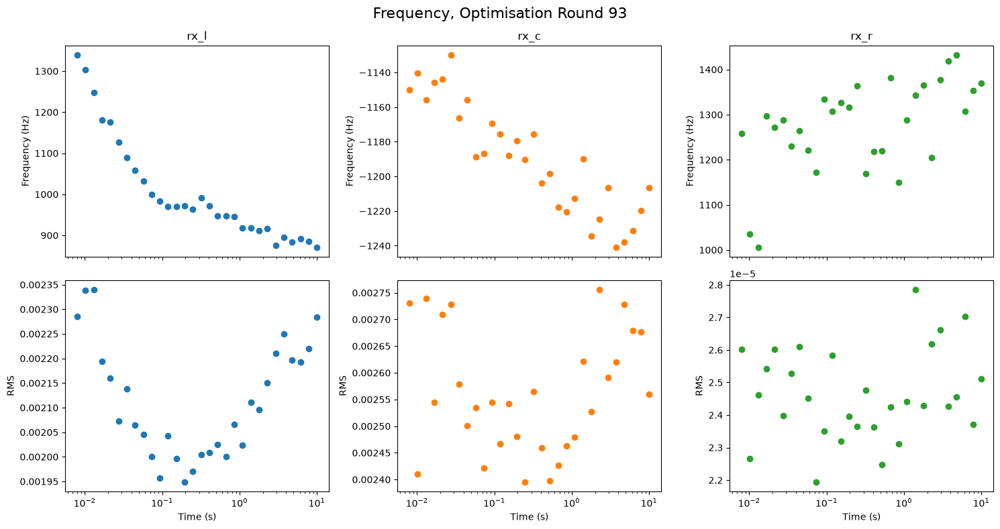

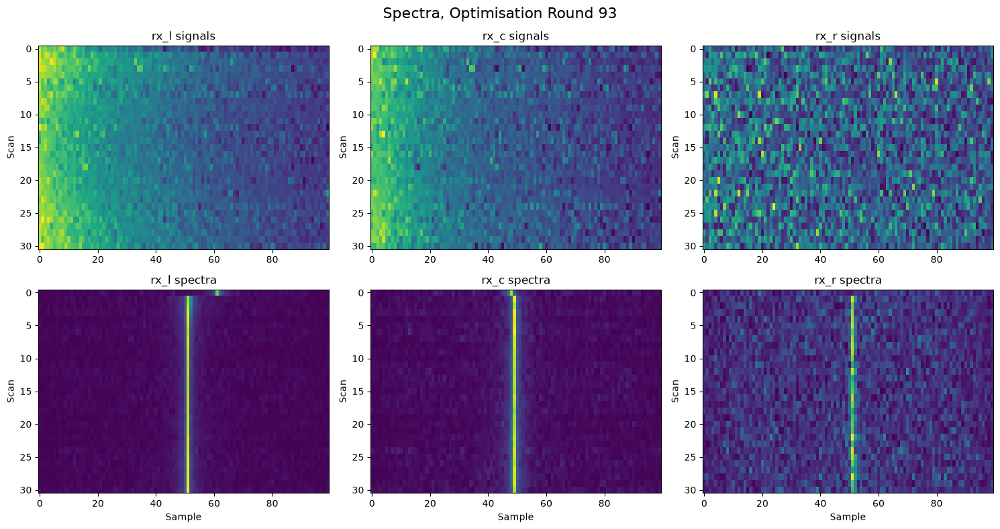

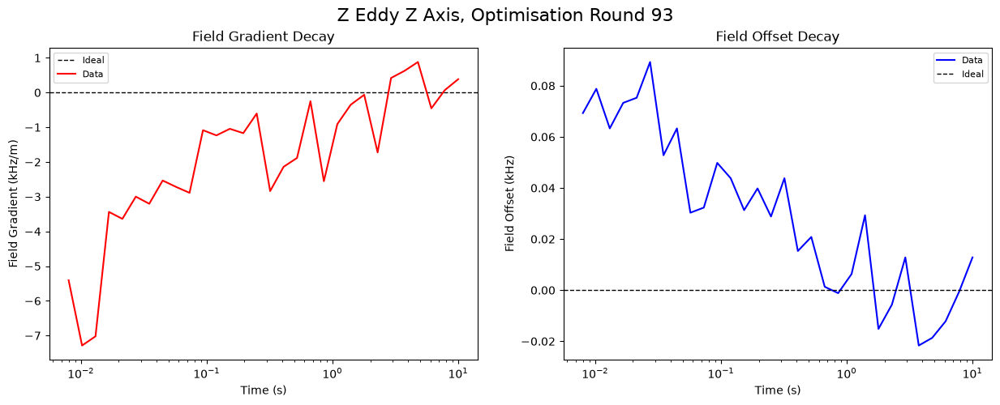

[I 2026-11-24 19:03:07,756] Trial 93 finished with value: 126.75422621161759 and parameters: {'Z_A1': -0.0009505799912414469, 'Z_A2': -0.0003160211032837123, 'Z_A3': -8.92062491263252e-09, 'Z_A4': -5.262305881001383e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.268e+02
Total cost = 1.268e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013595774224095445
B nanmax = 0.013595774224095445
B contains nan = False
Trial 94


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013377265733639352 !!!!!!!!!!!!!!!!


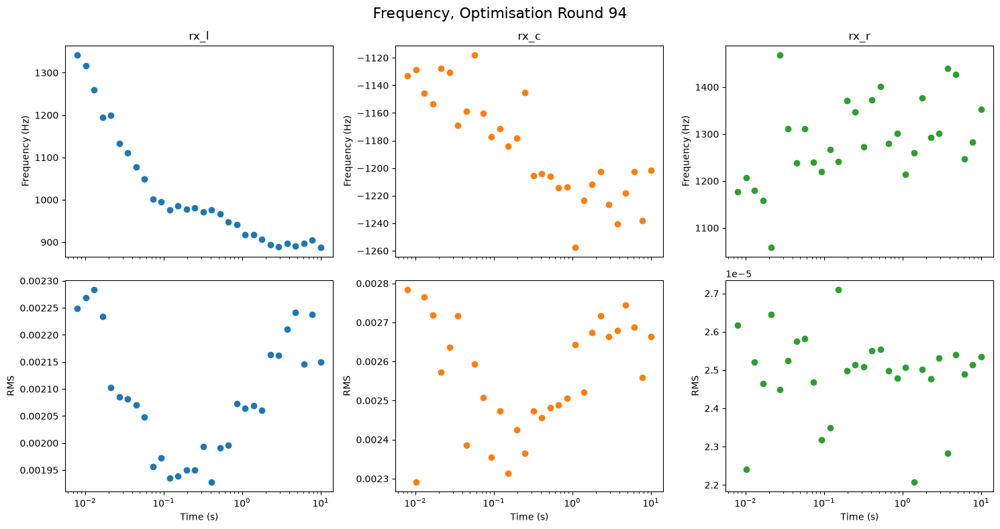

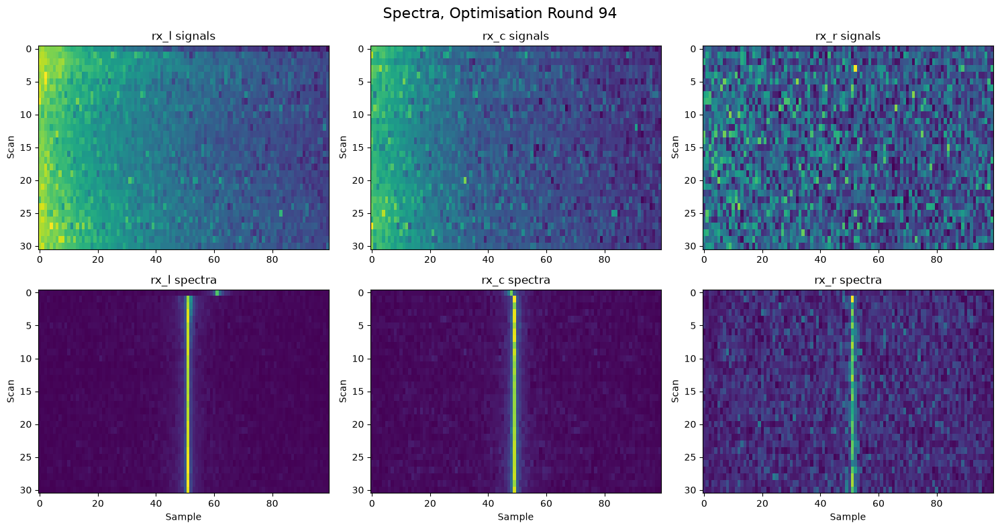

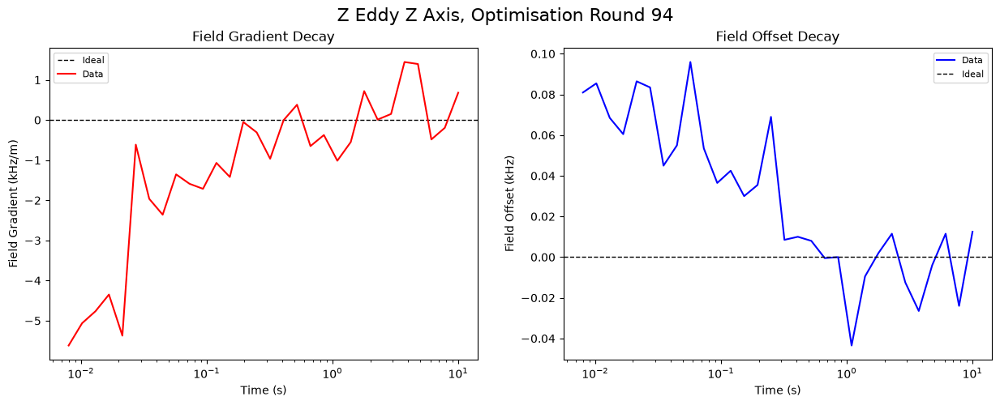

[I 2026-11-24 19:03:55,654] Trial 94 finished with value: 155.83526016578196 and parameters: {'Z_A1': -0.0009295553335296268, 'Z_A2': -0.00038247287944483783, 'Z_A3': -9.496867419402274e-09, 'Z_A4': -8.086186748993026e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.558e+02
Total cost = 1.558e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014311363765225987
B nanmax = 0.014311363765225987
B contains nan = False
Trial 95


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.014081355919245397 !!!!!!!!!!!!!!!!


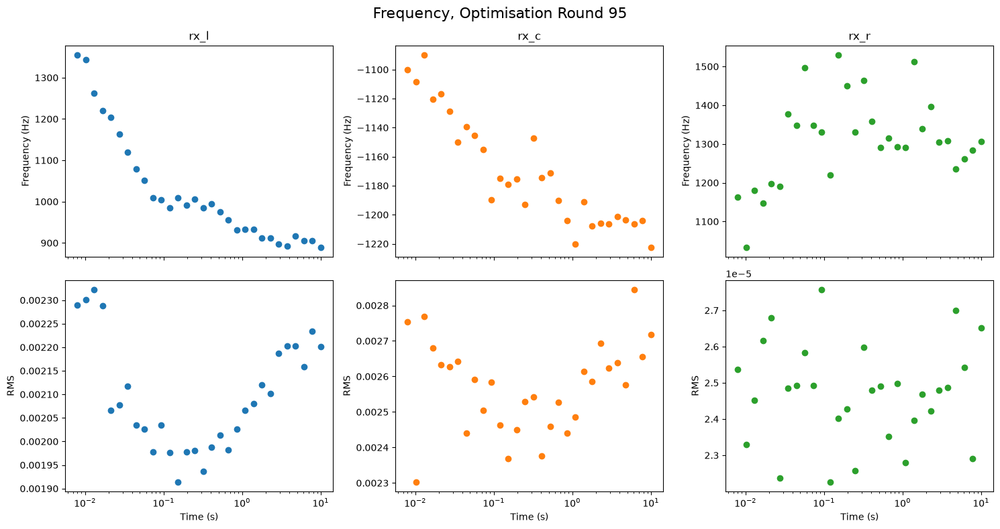

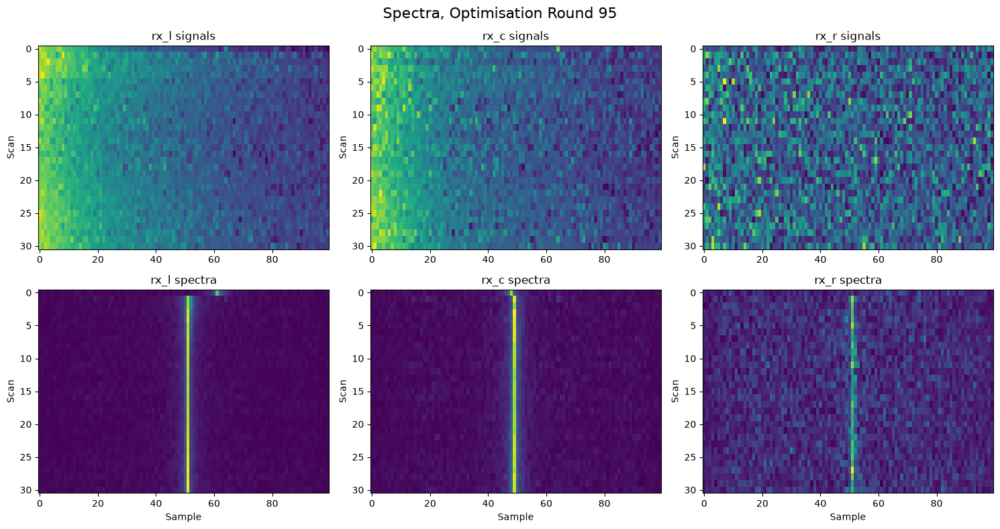

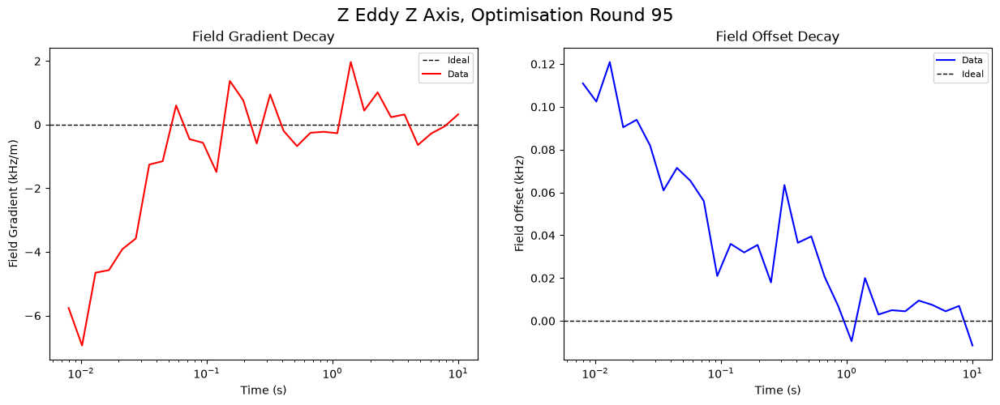

[I 2026-11-24 19:04:43,675] Trial 95 finished with value: 97.49459191777555 and parameters: {'Z_A1': -0.0010139173446796633, 'Z_A2': -0.00036753740712125904, 'Z_A3': -8.684859783555072e-09, 'Z_A4': -5.3792649023255494e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 9.749e+01
Total cost = 9.749e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.013535296032890526
B nanmax = 0.013535296032890526
B contains nan = False
Trial 96


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013317761528552073 !!!!!!!!!!!!!!!!


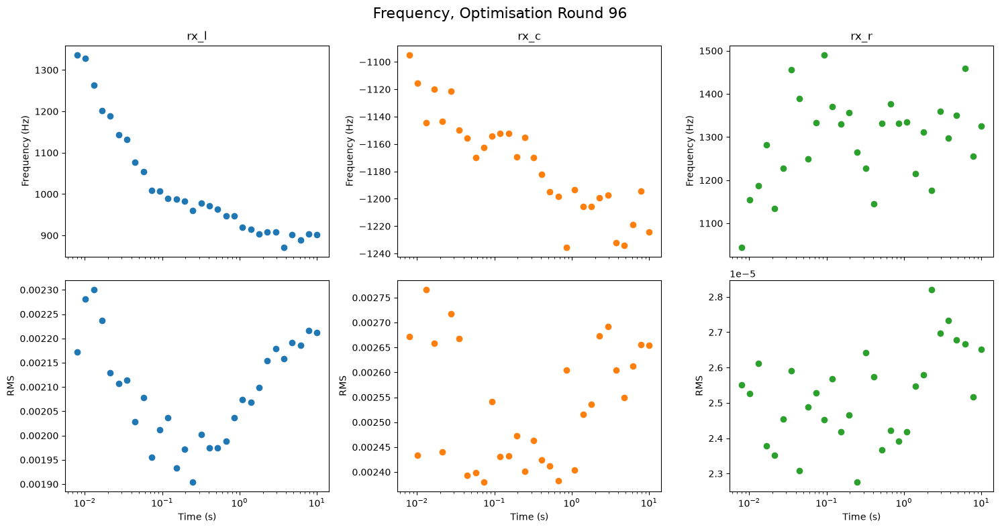

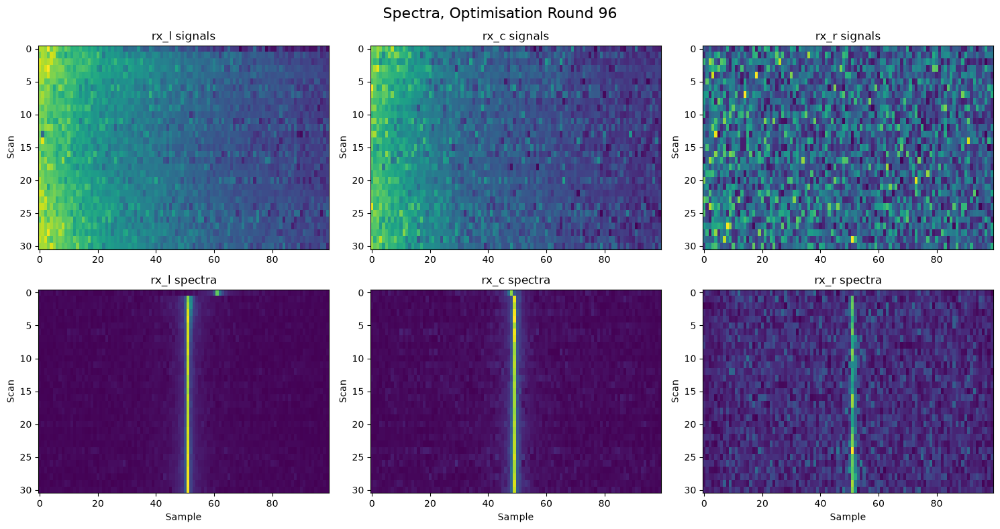

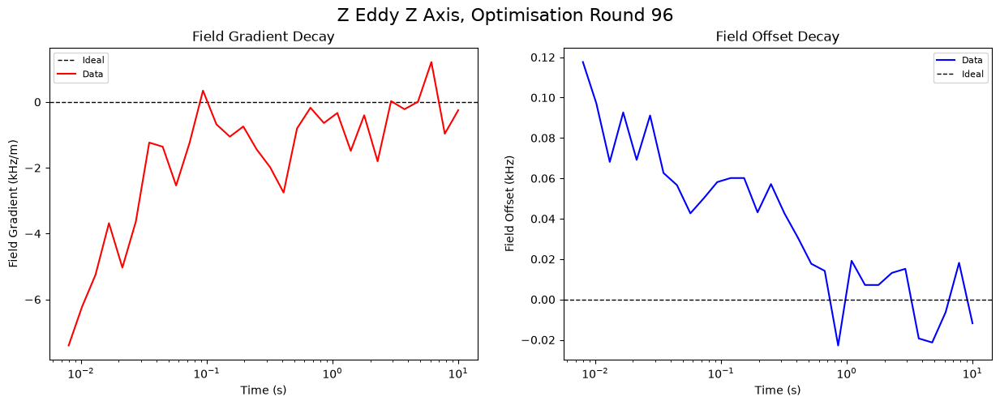

[I 2026-11-24 19:05:31,982] Trial 96 finished with value: 162.13609864899587 and parameters: {'Z_A1': -0.0009740419320475798, 'Z_A2': -0.0003326579906026679, 'Z_A3': -6.704813580772335e-09, 'Z_A4': -7.253406956339672e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.621e+02
Total cost = 1.621e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.012786081912401262
B nanmax = 0.012786081912401262
B contains nan = False
Trial 97


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.012580588304912915 !!!!!!!!!!!!!!!!


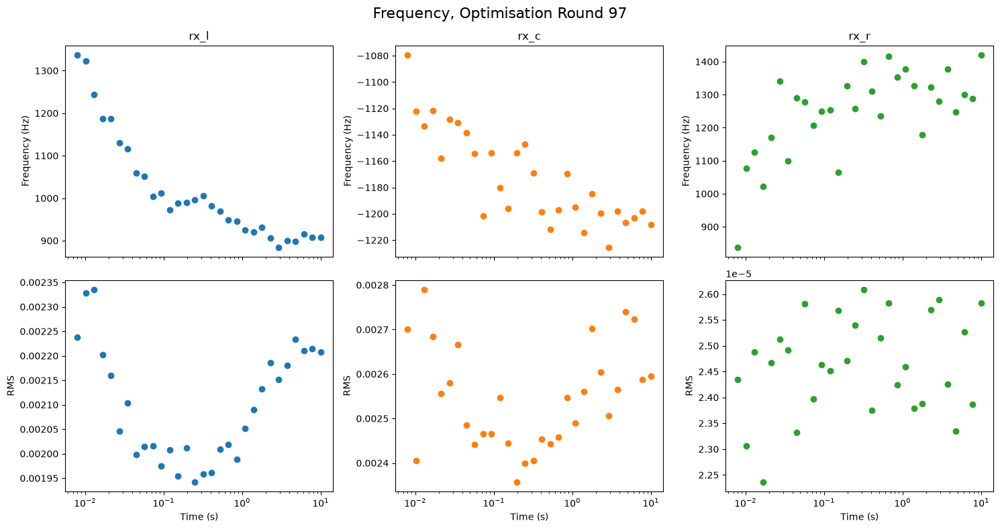

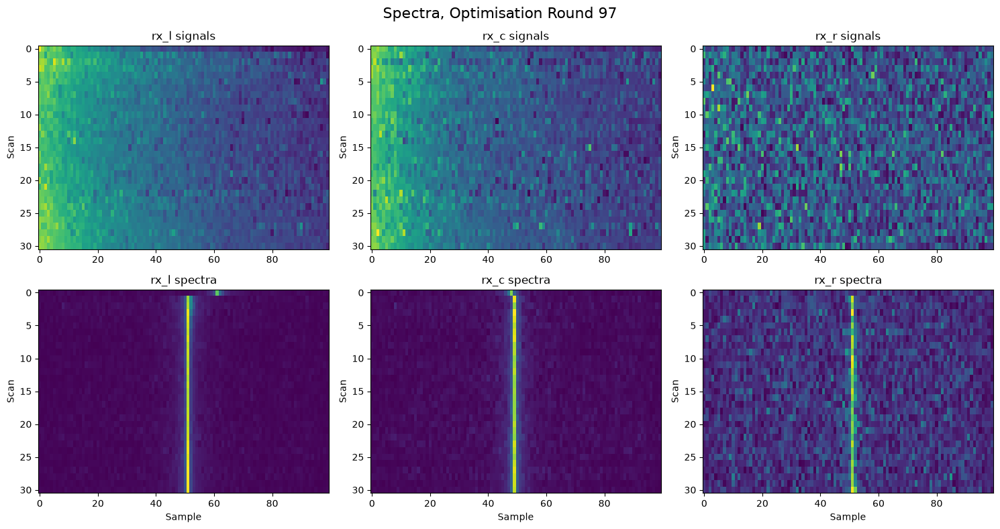

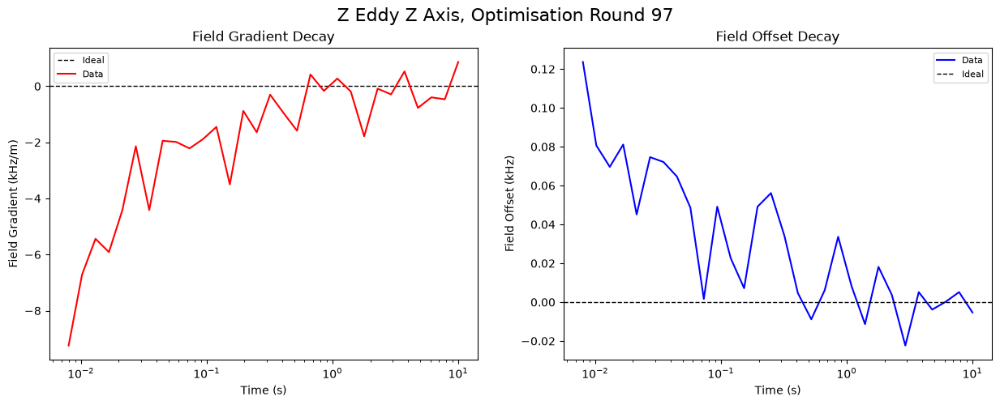

[I 2026-11-24 19:06:20,461] Trial 97 finished with value: 82.14236899797632 and parameters: {'Z_A1': -0.0009150453394609334, 'Z_A2': -0.00031927223053634593, 'Z_A3': -6.570087869307227e-09, 'Z_A4': -7.777533843135752e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 8.214e+01
Total cost = 8.214e+01
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.01219340053892172
B nanmax = 0.01219340053892172
B contains nan = False
Trial 98


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.011997431687997625 !!!!!!!!!!!!!!!!


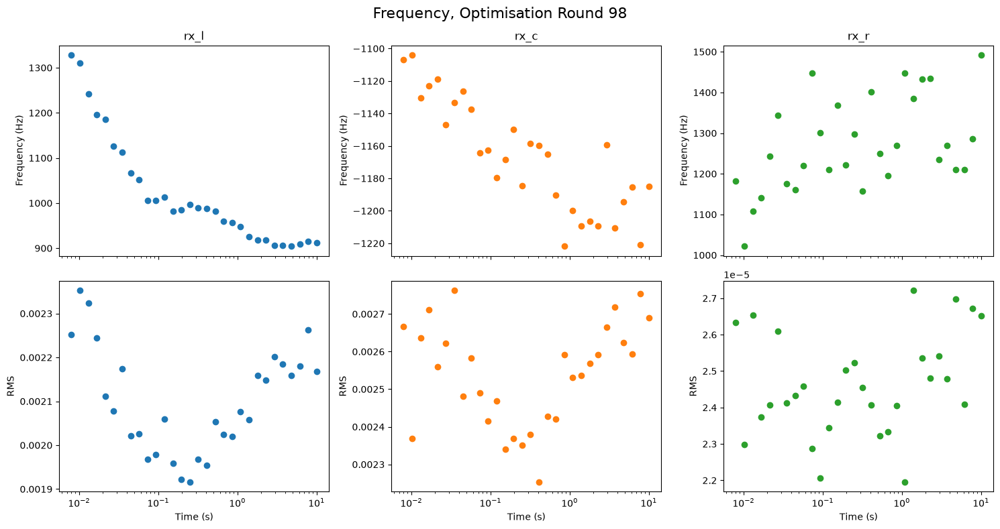

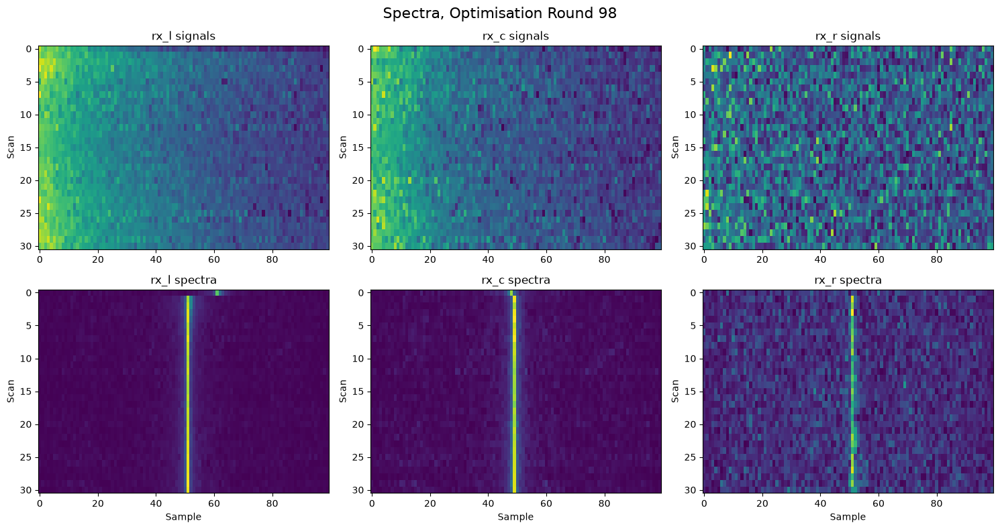

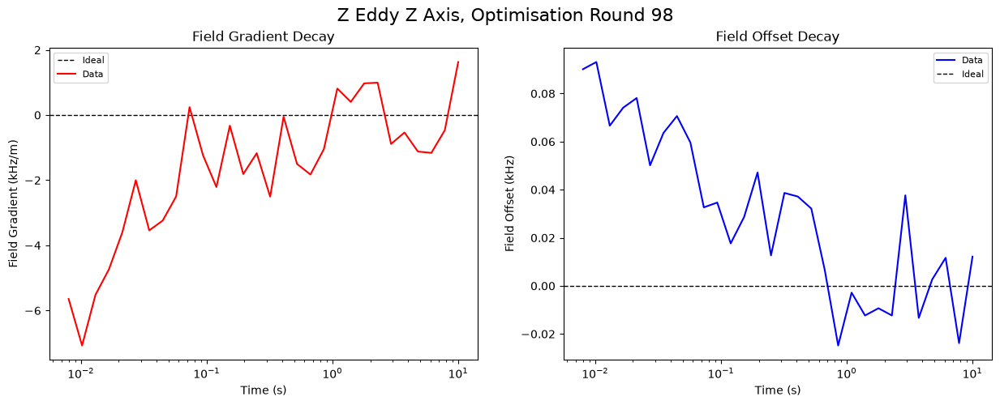

[I 2026-11-24 19:07:08,843] Trial 98 finished with value: 163.61521780930903 and parameters: {'Z_A1': -0.0008575263202803975, 'Z_A2': -0.00031941833855752855, 'Z_A3': -5.657475424573372e-09, 'Z_A4': -8.948674262476897e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 1.636e+02
Total cost = 1.636e+02
E max = 0.12158238164749582
E nanmax = 0.12158238164749582
E contains nan = False
B max = 0.014100250787386685
B nanmax = 0.014100250787386685
B contains nan = False
Trial 99


DEBUG:measure:B0 uses pre-emphasised gradient


C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_Eopt.yaml
C:\Users\halesda\OneDrive - Victoria University of Wellington - STAFF\Desktop\kahu-workspace\EC_optimiser/eddy_B0opt.yaml


DEBUG:measure:Pre-emphasis ON
DEBUG:measure:B0 ON
DEBUG:measure:MAX B0: 0.013873636530458469 !!!!!!!!!!!!!!!!


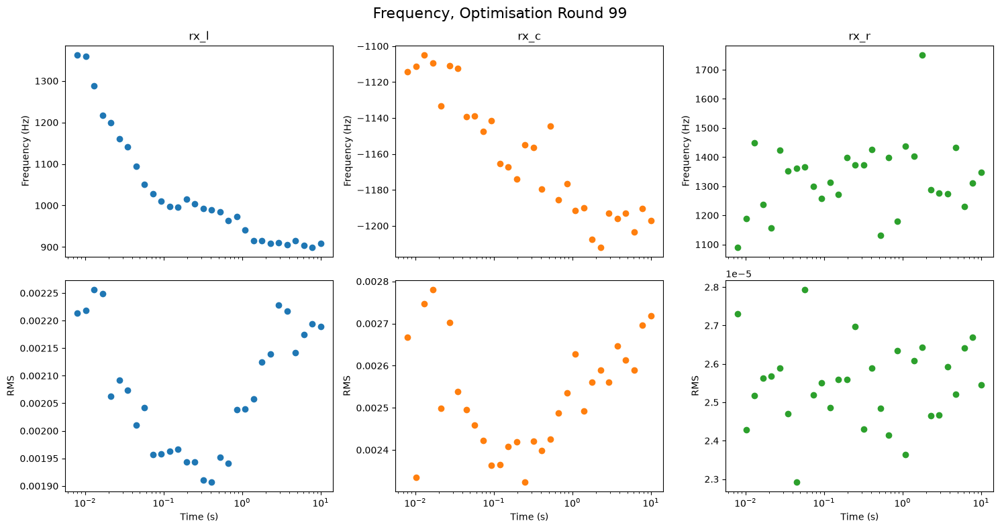

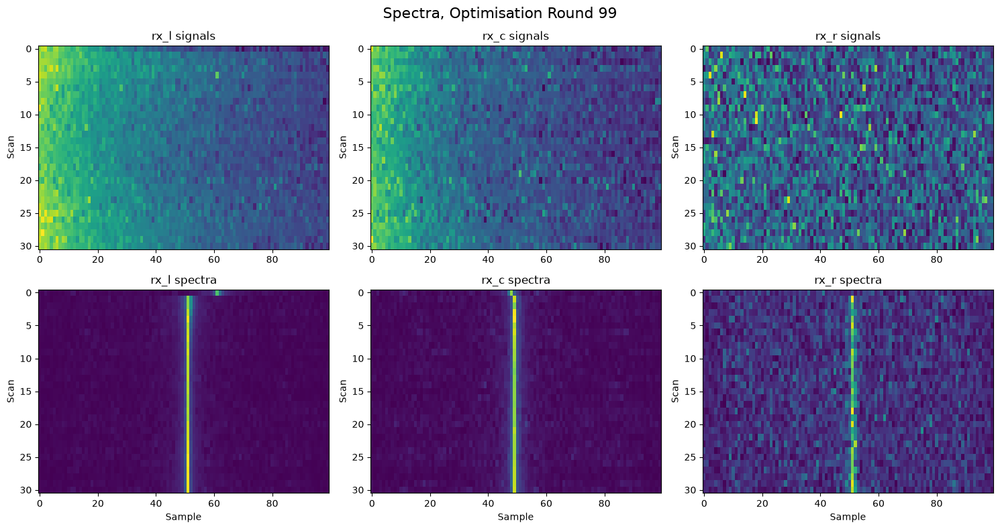

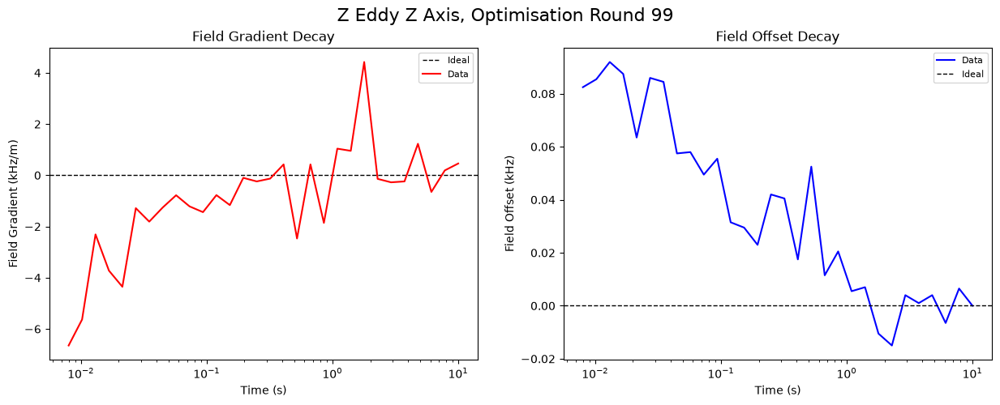

[I 2026-11-24 19:07:56,890] Trial 99 finished with value: 78.29794255317566 and parameters: {'Z_A1': -0.0010147217771175531, 'Z_A2': -0.000346519229730687, 'Z_A3': -5.9691204775860945e-09, 'Z_A4': -6.560097265106346e-09}. Best is trial 21 with value: 70.32705909852392.


rx_c: 7.830e+01
Total cost = 7.830e+01
{'Z_A1': -0.0008214635885633864, 'Z_A2': -0.00047006187927388273, 'Z_A3': -2.2284275948255444e-09, 'Z_A4': 4.397948509718359e-09}
21
70.32705909852392
{'Z_A1': -0.0008214635885633864, 'Z_A2': -0.00047006187927388273, 'Z_A3': -2.2284275948255444e-09, 'Z_A4': 4.397948509718359e-09}


,trial,cost,g_pe_perc,max_b0var,status,Z_A1,Z_A2,Z_A3,Z_A4
0,0,88.058225,121.582382,0.013172,PASS,-0.000866,-0.000404,0.000000e+00,0.000000e+00
1,1,199.742306,121.582382,0.018424,PASS,-0.001275,-0.000503,3.782295e-09,-8.673926e-09
2,2,147.217364,121.582382,0.011911,PASS,-0.000635,-0.000512,4.267052e-09,2.391488e-09
3,3,139.863680,121.582382,0.012349,PASS,-0.000880,-0.000312,6.519412e-09,-4.043709e-09
4,4,181.050385,121.582382,0.015334,PASS,-0.001149,-0.000332,6.868933e-09,1.830192e-09
...,...,...,...,...,...,...,...,...,...
95,95,97.494592,121.582382,0.014312,PASS,-0.001014,-0.000368,-8.684860e-09,-5.379265e-09
96,96,162.136099,121.582382,0.013536,PASS,-0.000974,-0.000333,-6.704814e-09,-7.253407e-09
97,97,82.142369,121.582382,0.012786,PASS,-0.000915,-0.000319,-6.570088e-09,-7.777534e-09
98,98,163.615218,121.582382,0.012194,PASS,-0.000858,-0.000319,-5.657475e-09,-8.948674e-09


In [11]:
# ------------------------------------------------------
# start calling optimisation run and analysis
# ------------------------------------------------------

study = optuna.create_study(direction="minimize")

start_params = {}

for i in range(1, MAX_EXP+1):
    start_params[f"{OPT_AXIS}_A{i}"] = B_START[f"{OPT_AXIS}"][f"A{i}"]

study.enqueue_trial(start_params)

study.optimize(lambda trial: opt.objective(trial, OPT_AXIS, metric, g_hzpm, E_START_opt, B_START, 
                                           start_params, percentage, seq_params, g_ideal), n_trials=num_trials)

best = study.best_params
opt.best = best
print(best)

print(study.best_trial.number)
print(study.best_value)
print(study.best_params)

# ----------------------------------
# create df of optimisation information across trials
# ----------------------------------
rows = []

for t in study.trials:

    row = {
        "trial": t.number,
        "cost": t.value,
        "g_pe_perc": t.user_attrs.get("g_pe_perc", np.nan),
        "max_b0var": t.user_attrs.get("max_b0var", np.nan),
        "status": t.user_attrs.get("status", "")
    }

    row.update(t.params)

    rows.append(row)

df_trials = pd.DataFrame(rows)
display(df_trials)
df_trials.to_csv(Path.cwd() / OPT_AXIS / "offset_info.csv", index=False)

opt.save_to_global(B_START, OPT_AXIS, "eddy_B0.yaml")

#### Plot Optimisation Performance

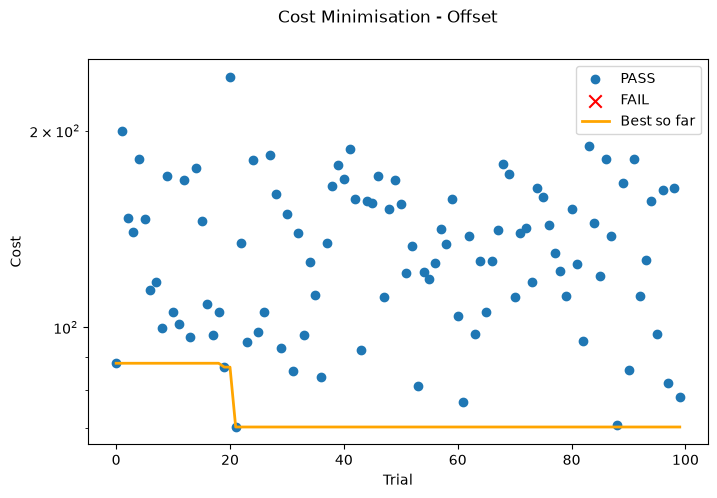

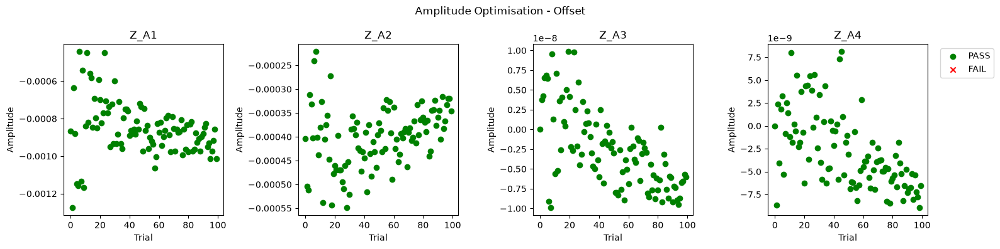

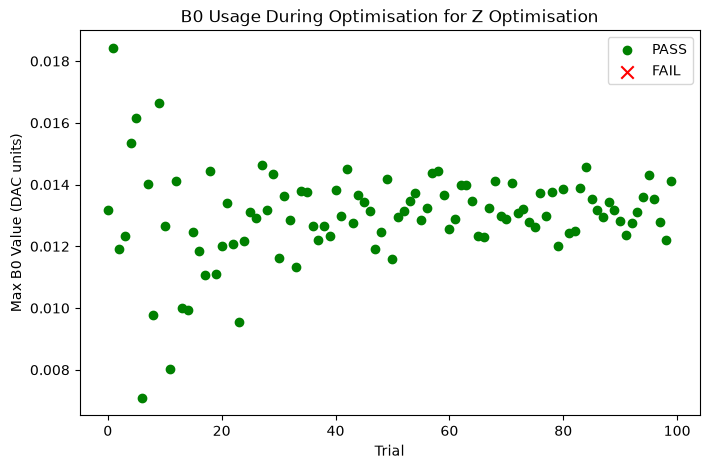

In [12]:
opt.plot_for_optimisation(df_trials, OPT_AXIS, metric)